# Bitcoin Financial Research | Volatility and Risk Modeling

**Portfolio research notebook · Historical study with exploratory external-period diagnostics**

This project began with Bitcoin price regression against U.S. equity-market indicators and expanded into volatility forecasting, tail-risk estimation, calibration, and data-source robustness.

### Main findings (saved Windows execution; not recalculated for this cleanup)

- **Volatility quantiles:** On 2,090 evaluated dates from 2021–2026, the sequentially calibrated HAR-X achieved mean Pinball Loss **3.1988** (90th percentile) and **2.3784** (95th), compared with **3.7665** and **2.9698** for a rolling 180-day baseline.
- **Feature drift:** The log-volume feature shifted approximately **−7.24 training standard deviations**. Refitting reduced-feature models gave competitive results, but exchange-specific volume units and daily candle conventions remain unverified.
- **Risk diagnostics:** A separate four-family VaR–ES sensitivity study evaluated 2,119 dates. These procedures do not exactly reproduce the older 2019–2020 risk-model fits.
- **Formal backtests:** Historical R ESR and MCS outputs were recorded. Independent verification of the original R GARCH fit's convergence and external-data provenance remains incomplete.

**Interpretation:** These are exploratory, retrospectively inspected comparisons, **not** an untouched 2021–2026 prospective holdout, evidence of trading profitability, or proof of a causal market effect. This is research, not financial advice.

The complete model implementation is retained below. For a shorter public overview, see `BTC_Portfolio_Executive_Overview.ipynb` in the companion package.


## Notebook structure and reproducibility

- **Historical foundations:** data validation, Bitcoin–equity regressions, chronological forecasting, volatility and tail-risk models.
- **Advanced diagnostics:** missingness, range-based volatility proxies, model uncertainty, formal ESR/MCS, and cross-source comparisons.
- **External-period sensitivity:** sequential calibration, direct quantile HAR models, volume-feature ablation, and four-family VaR–ES backtests.
- **Evidence audit:** run-scoped outputs and explicit status flags for missing independent verification.

**Required data:** `dataset.csv` and `SPX_500_Data.csv` in the project directory or its `data/` subdirectory. The source code defaults to `I:\Dataset\Bitcoin Price Regression Analysis`; set `BITCOIN_PROJECT_DIR` to override it. Other source files, R and internet access may be needed for optional analyses.

**How to run:** Open with Python 3 in Jupyter or VS Code; select **Restart Kernel → Run All**. New execution files are written under `runs/<run_id>/`. Always distinguish preserved notebook outputs from freshly reproduced results. Official R tests, third-party data and the independent GARCH convergence check require actual local execution and source verification.

**Publication caveats:** The raw data provider and volume units have not been independently reconciled, the R GARCH convergence evidence remains incomplete, and 2021–2026 was repeatedly inspected during model development. The `FULL_RESEARCH_VERIFIED` flag must not be overridden without supporting evidence.


## Part I — Research questions and executive conclusions

| Research question | Current historical finding | Limitations |
|---|---|---|
| Can complex BTC price forecasting beat no-change? | Naive is very competitive; Elastic Net's tiny retrospective RMSE gain is inconclusive. | The BTC equity-session forecast is not a fixed 24h horizon; 2019/2020 repeatedly inspected. |
| Does volatility modeling improve on simpler benchmarks? | Log-HAR/HAR-X show lower average QLIKE on matched dates for some settings. | March 2020 remains difficult; volatility proxies and missing dates matter. |
| Do VaR and ES forecast crash severity? | GARCH-filtered EVT can rank better by average joint loss without demonstrated statistical superiority. | Exception days are few; March 2020 realized tail losses could far exceed ES forecasts. |
| How stable is crypto dependence? | DCC, conditional tail association and regime studies characterize changing comovement. | Not causal effects; CoVaR conditioned on 12–21 stress events is very imprecise. |
| Can forecast-interval calibration adapt? | Prior-only online quantiles and ACI often approach nominal full-period coverage better. | Pinball loss and crash-month coverage can worsen; no clean 2021+ validation. |

The dashboard after **Part II** reconstructs the exact tables and graphics from the latest validated Python execution, rather than storing a second copy of the 148 estimation cells.


**2026 final refinement:** strict 30-calendar-day HAR-X sensitivity, previsible ACI crisis diagnostics, common-date VaR/ES failure attribution, and optional run-verified R connectedness/structural break analysis are added. These are historical sensitivity studies; 2019 development and repeatedly inspected 2020 data are not new independent evidence.


## Part II — Complete Python research (original Sections 0–151)

All 148 original model/audit code cells below are preserved in their original sequence. This is the authoritative research calculation; later tables are presentation-only.

## 0. Running this unified notebook

Run the complete notebook with the **Python** kernel from the project root. Files are read from `data/` (or the project root) and derived files are saved into distinct `runs/<run_id>/outputs/`, `figures/` and `frozen/` directories. The optional R section runs **after** the completed Python scientific checks, never as a prerequisite to Python forecasts. The data root defaults to the user-confirmed `I:\Dataset\Bitcoin Price Regression Analysis` even if VS Code opens from another working directory. Set `BITCOIN_PROJECT_DIR` to override the path if the project is moved. Use `python reproduce.py` for a fresh automated run. Original input files are not altered.

**Historical research only:** the 2019 validation and 2020 retrospective evaluation are not independent future datasets.

**Windows Run All fixes (2026-10-23):** The R runner stages SHA-256-verified, byte-identical copies of the raw CSVs in `PROJECT_DIR/data/` before launching `r_analysis/run_all.R` (it never replaces different existing files). The frozen 2020 historical BTC observations are now filtered to `END` *before* concatenation with the observed external BTC daily data. These code corrections do not assert that the five R models, ESR/MCS or 2021+ evaluation passed; inspect their current-run status files.


In [1]:
import time
RUN_STARTED_NS = time.time_ns()
from pathlib import Path
from datetime import datetime
import os, warnings, json, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_ljungbox
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import mannwhitneyu, pearsonr
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, ElasticNet
from sklearn.svm import SVR
from sklearn.metrics import r2_score
from xgboost import XGBRegressor
from IPython.display import display, Markdown

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.figsize': (11, 4.7), 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 25)
START = pd.Timestamp('2015-10-20')
END = pd.Timestamp('2020-10-20')
TRAIN_END = pd.Timestamp('2018-12-31')
VALID_END = pd.Timestamp('2019-12-31')

# Data provenance: user's confirmed I: project directory, with explicit environment override.
# On this Windows workstation, both CSV files must be in the same directory,
# either directly under PROJECT_ROOT or under PROJECT_ROOT / "data".
# Other machines can override this with BITCOIN_PROJECT_DIR before starting the kernel.
PROJECT_NAME = 'Bitcoin Price Regression Analysis'
DEFAULT_PROJECT_ROOT = Path(r'I:\Dataset\Bitcoin Price Regression Analysis')
ENV_PROJECT_ROOT = os.environ.get('BITCOIN_PROJECT_DIR', '').strip()
CUSTOM_ROOT = ENV_PROJECT_ROOT or str(DEFAULT_PROJECT_ROOT)
ROOT_SELECTION_METHOD = ('ENV_BITCOIN_PROJECT_DIR' if ENV_PROJECT_ROOT
                         else 'USER_CONFIRMED_I_DRIVE')
root = Path(CUSTOM_ROOT).expanduser().resolve()
checked_paths = []
selection = None
for folder in (root, root / 'data', root / PROJECT_NAME,
               root / PROJECT_NAME / 'data'):
    folder = folder.resolve()
    checked_paths.append(str(folder))
    if all((folder / filename).is_file()
           for filename in ('dataset.csv', 'SPX_500_Data.csv')):
        selection = (root, folder)
        break
if selection is None:
    raise FileNotFoundError(
        'Required dataset.csv and SPX_500_Data.csv were not found together.\n'
        f'Configured project root: {root}\n'
        'Place both files in the project root or its data/ subfolder.\n'
        'To use another location, set BITCOIN_PROJECT_DIR before running this cell.\n'
        'Directories checked:\n  ' + '\n  '.join(dict.fromkeys(checked_paths))
    )
_, DATA = selection
PROJECT_DIR = DATA.parent if DATA.name.lower() == 'data' else DATA
# Every execution writes to its own immutable evidence directory. Re-running the notebook
# in the same VS Code project cannot accidentally mix prior execution artifacts.
import datetime as _run_dt
import uuid as _run_uuid
RUN_ID = _run_dt.datetime.now(_run_dt.timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ') + '_' + _run_uuid.uuid4().hex[:8]
RUN_DIR = PROJECT_DIR / 'runs' / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)
FIG = RUN_DIR / 'figures'
OUT = RUN_DIR / 'outputs'
FIG.mkdir(parents=True, exist_ok=False)
OUT.mkdir(parents=True, exist_ok=False)
import hashlib as _source_hashlib
SOURCE_CSV_SHA256={name:_source_hashlib.sha256((DATA/name).read_bytes()).hexdigest()
    for name in ('dataset.csv','SPX_500_Data.csv')}
print('DATA_ROOT_SELECTION:', ROOT_SELECTION_METHOD)
print('SOURCE_CSV_SHA256:', json.dumps(SOURCE_CSV_SHA256, sort_keys=True))
print('Project directory:', PROJECT_DIR)
print('New isolated run:', RUN_ID, '| Run directory:', RUN_DIR)
print('Data location:', DATA, '(directly in root)' if DATA == PROJECT_DIR else '(data/ subfolder)')
print('Raw CSV files found:', (DATA / 'dataset.csv').is_file(), (DATA / 'SPX_500_Data.csv').is_file())
print('Runtime:', 'Python / pandas', pd.__version__)
print('Study period:', START.date(), 'through', END.date())


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=150, bbox_inches='tight')
    plt.show()

def het_arch_compat(residuals, nlags=10):
    """Preserve current tuple API while filtering only statsmodels' migration notice."""
    from statsmodels.stats.diagnostic import het_arch as _native_arch
    import inspect
    kwargs = {'nlags': nlags}
    if 'result_object' in inspect.signature(_native_arch).parameters:
        kwargs['result_object'] = False
    # Older statsmodels calls acorr_lm internally, which issues its migration
    # warning even where het_arch cannot accept the new result_object argument.
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message=r'acorr_lm currently returns a plain tuple', category=FutureWarning)
        return _native_arch(residuals, **kwargs)


DATA_ROOT_SELECTION: USER_CONFIRMED_I_DRIVE
SOURCE_CSV_SHA256: {"SPX_500_Data.csv": "06e5c3768e8c4ff50be8f8641ef9cba03da61a4ffe00a7077666c6af866f685d", "dataset.csv": "9495893c031e1badd6cd680b31658fb4a1c7bd38a9e0617893d76b9c4147ed4f"}
Project directory: I:\Dataset\Bitcoin Price Regression Analysis
New isolated run: 20261026T030925_071513Z_ee4a01ed | Run directory: I:\Dataset\Bitcoin Price Regression Analysis\runs\20261026T030925_071513Z_ee4a01ed
Data location: I:\Dataset\Bitcoin Price Regression Analysis (directly in root)
Raw CSV files found: True True
Runtime: Python / pandas 2.3.3
Study period: 2015-10-20 through 2020-10-20


### Automatic public BTC OHLCV and official R testing setup

This setup attempts to download **genuine Bitstamp BTC/USD daily OHLCV** (public CryptoDataDownload CSV; GitHub CSV snapshot fallback), or public Coinbase BTC-USD UTC daily bars as a last resort. Network, publisher availability, date gaps and provider time-zone conventions are audited: missing days are never fabricated. Downloaded data is saved under `external_market_data/` with SHA-256 and source URLs. The public secondary BTC source is also used to build an **observed** 2020-10-21→latest daily bridge for the frozen 2021+ HAR-X scoring. The exchange/candle definition differs from the original dataset and this is disclosed. The four historical risk-model forecasts are **not** magically reconstructed for 2021+; their separate backtest still requires authentic frozen model outputs.

If an R installation is found, the notebook **attempts official ESR and MCS** automatically. Missing R, dependencies or insufficient tail events are *explicit failures/skips*, never invented passes. `BITCOIN_RUN_R=1` separately enables the five original R econometric scripts; those need the user's actual R source and libraries. Opt-outs: `BITCOIN_AUTO_EXTERNAL_DATA=0`, `BITCOIN_RUN_FORMAL_ES_MCS=0`; custom local files win via `BITCOIN_SECONDARY_BTC_OHLCV_CSV` and `BITCOIN_FUTURE_OHLCV_CSV`.

Public data attribution: CryptoDataDownload Bitstamp (CC BY-NC-SA 4.0; check provider's terms). Coinbase public Exchange candles are a last-resort source. Neither a successful data download nor 2021+ historical scoring certifies statistically significant generalization.

In [2]:

# Default: acquire public, real BTC-USD exchange OHLCV (never synthesize prices).
# Opt out with BITCOIN_AUTO_EXTERNAL_DATA=0. Existing user CSV settings win.
import sys, subprocess, shutil, importlib.util, zlib, base64, hashlib, json, os
from pathlib import Path
_boot_root=Path(PROJECT_DIR)
_auto_source_path=_boot_root/'BTC_2026_AUTO_EXTERNAL.py'
_auto_helper_content=zlib.decompress(base64.b64decode('eNq1WvtT40a2/p2/QpetpKWJkA0J2VyDZsvBnoRaFqaMmWyW61LJUhsrI0uKWgaTKf73/U4/9MCGmZutTU2w1Y/T5/GdV8v7+/vDdZxU4TzlVpZnB+Ixq5a8SiKrWM9TfPw4PbOufr44+2CF0e/rRCRVkmfWIi8trLN+TKooTzKr5IKHZbQEjYrP8/yjt7d3na/LiIvBnmWdlY9FlY/CKhzlD1mahzHtFFW4KuiA3s31yIrDJH207JKHqcU30TLM7jgGq9C1zkYjC7zwLOIOqL1XnP2UVD+v55bIwkIs88rKFw3Rs+sPls03BdYllXXPSwGue6DGQWgFeUkKonUG7ueh4NbYHNnIfUBsTcbXUysKszjlwrJvoI04fBSudXTcP8A3qwjvuHD2LjkOsZLsnmcVZpNVsa44vkBP0NVDWMYHiyRNhbVKhEiyOy3uPCyFt7e/v7+3KPMViFXLNJnT9rysrPd43NPfI3HvWstQ0Dzo5671m8gzHIBDqmTFXWtdppjzSv77mouqfuZlmZeGSrZeFY9WKKysMEMFZMMA/hUxjHZ1MzkbBzeTi2vLt26hIcuymdFrAEsw12LLqirEoNd7eHjwImlbMlSsbetF+aoXxXGv3gZlQpcBZsQ9c9wdVIMwrf4EZUX4JboKIYFBSJt+GT54d0m1XM/XgpdRnlUwnCS/4rAQLznGeiKb91ZhIpETHvWPvn9ZpNnezfV4Egx/Gl9OoTlG+KEdBxPtGgcfwjSJJfB6h17fspeJqPIyiYB34z4nBn3Ar8P29mK+sAKxDO25M8Cial1mBgMeho+Ov8eMt+SbOAEKK9vRWzQGbEBAoSNfV/53x85Aagiz4LALF2/S3rLkYQyf8T+xG6jiYHgH5bCB1UgITQ6jiBc0yiq+qXqEz7Agh1MiSnS+6b1hT4489AHKfn4mHvOCZ/D53xs29adDiIReijwTXPFN/2lLgX8zB2phbB8eBf1+n/536rVaYXqLVk0Bj+MBMGTrca2UZEGxq6YPv03BmVlzenjcpzH9fDs47PdnXiqqMilsxwMkykqQiPacnf7P6Ops+uv7MXMavsswQZABBNZ8TA5pMxMJeVwfmgjJQ0jmZ0oO4NQ36IyByZjbbF0tDn44EMkdc6VzC5+VvEjDiOtNaZJx4RPEBQxSyUfbMWLKRwter77dQpAW/7WHgHtFR606HMwkgXjhF7HUeQCT20nuXUMJ2d35lc3+L2PebwiottziOK6V5g/Biq/y8tF/F6aCO5oGPC1drzLh30KF9oY0qDSJDbzEpxbIZgFzmcUcmXE2CLCtzbO24T4xghIWL5O7JT5ACH+jNBecPXlw6fVc8Mpudr9qnH/oKE2Zz9IbWK1Bts6SDesy01CjSdJRlQcItxweTqfSaG2uKEfMMdbSeyqfrQQj8rTUi8u8yEJoYsXjJMxs5+0hPzy0OJRoMcHqnZTThD6OvpP72PIwSZP+uOsq8qflmm+d78WVV/0RpDmCUPIHty/zjMvBLC9XakjxyFMSm+i/KPZORrCQvj8/uObo/8MBwsC2oS5zeXCPJNaG0mq9pwd4ep76GQKUbW8aDNlMzVrzKgJK1EP9xVKJB6CD0M8w57iSQ4OE5hByXprazSNlAzKFZU6Q1E6osJAeD3hilOoNWgXvLDnt0aIgHKKcIN1SCfWuDKHZT8oaA6l2HWNr+W5fcYbZQJG73cy2UIqx3RjVW4ymduxsNPECCR2Ng3uVBrmtaJqUVQ/HC+2ZGx9kb5WY7isC1fabzWCl4lEDZqO3zp5jsp5ooieZjO2E3cavXVFFEN/sRsxC+UR8I5fZapDiFtYESRbzjU37FMoNXDbSG7x4rfIkj+HfYQaOd6BmZBbpUpFKT12HNpGIctTGOf32+2PKTgSlrECwWyRAEUl6+4V6U7aE7hZISZUDrtLUfjVCnmdivVigvEZm6qFzUEdqDmXd3nD5GUZms1O/rxWh/pIw9sZT/J2audfYgesVOTUn91wFbVIHvwvlgJazxY9HbJy22Ory463CjR1uEuEfOl2WsO7ttjTNPiS/7r7XdYjULlAGUvInrruustGuEekeJVDFoS2ztcSza/Es1t/Asqn7hP9DXx/8l6bDkbvFkuoNBaOBdSs7B8jkkiAuCeVKWVylsplrfdvvE2mrQHtTl1yStCoayLuIgaCk7snG0xQ0ZY3cYtRxOxOGa8ddgGWfoZkadUGtiDtv21JpJ5msM2Jb6xB9G0euhpVrQZW/mF1Gp/kDqo3ZiSVkW4o68JGqLwzVoVNQ6FQHN1bjPtlUfKP5j3lahTa1gD6YfkmsHasBiCbbl6nfFFphkXim4fWMrWUrUpR5vI4q0dPNaE8b7m93UPY6DcukevR/+P67fr+pB+R/7Gsphs++EVRZLWTcY1/9evDV6uCreNrvD+S/fzHnG/Y1uMZC/pmFDfdGc50uw1Tv3x43C1Vo9KkT8GiHsPXWZoku3hIUW+AY/b2tNrlAarUrKtZGNi25waSqnDNkzjJ8bFVWZHeoFy4Wa9rOSRcCHtoWmpWNluGwIUCSeSLlvLC9o2OTFTq5mM5w64pWVYcmpOgIoePF88j7mVTVzbIbWUQ6qrBDDfgnqiiTzoI6BdWpa3eSxnEoresIZLQdqO6TDbqqfFIRq0D1jgrGBn5/4xEiQFK61hu0lXXHG0jQoT/uHxz20SczFb/oSJ+Ydzt4RjJCH5Hx6iEvP6pKVo+Z1l4PwosjYhJRRSx1x6FceX9/f6JkozsW0QPaqrXwrKtMhoo7CsKlsAgoZYaOfJEQuB6WPLPQ/K7Rz8icht1CYCJa8uij8OjiRoEMLNBtTVtkpVH44R2qBlrRY4Z8sArLj1yGxpCdqCXe6iM22aS4DGFV1etIJVWQf2xVEbWauqHWDMua1TyYhpI02g0Qqo/oUGg/eEBWlj8gHUsQOM7BywGNjCrN2aHWNbVaGYVQm6+k7TGU3kGtDw0jHBvI6C1vVVQvy+M7Xta7EAkDulYJxv+cjieXw4tgNJwOg/eTqw/jy+Hl2dijcMM0mOmCy//ElLHZgF1eTYPhh+H5xfDHizHcUB0rJy7H0lnbXAPdaE6NfEYVXWgyrMVkWIIIKrRAhssATnv0Hb5QFAixHcG8SDnqPWmWQF5BKurGVC9QD6uKrwokscHtzGXmGqxFDxpjg92mS0S+IPev7OdUtbYjXlbJQl/YkBLG01+uJn8PRle/XF5cDUcBqev8cjR+P8afy+nFr8FwOh1fT8cj9qTDCUHrBHlzkfufnk4oe6YgLA2tptQI3OKeZxTg/RqMAKpc6EmUC5RYdCdBeO24cZOKq/Jx0BFk4zeBqn0pIcm66qZHtaV10e50CORpDFfMkgV0185TCnSKIN1uIbNHeZxkd766fEE6VIWKXFbzL53q01PnCKWaGmntEz0g2jYzLjsbnv08HgXmBvbynHR+/u4c2n5mwK4ZkX5fpitnd2+XWoKW14ID6jLeqDGJ0rAO8TIvKktJhcwfKWs4rxCNjT83Zn+Fwy4MXeWkBmfOM23WPRRV6M6pcZ8d8emvCk+d3DHYYrkN2I1uH0+2MEtGNJMbf0c4NcHmtvHYmakrGuMrE0PEh7DMgCaMyKOUH5wQwOnSSQOf7VJwo2IZWNQdAAWSliAtBZmw8tTgHqUmLyp634EPepcTUtqLuqr5cmlGEEf20YoNUGof1gSJugU2FyWvWYeq8TSc89QFfKkqb7+WAJFu8ld+11pyOziadeXZCh2tu+ROIetsrwKfMsT4O+6Ot1brgtaud2ljoIdwTrspEuXP4bEufyRWd5q7w0LLsm+3iB0dHvTpH4LTYCep15v4VnXWemsFJd3zMrxrX1Y2hq0Z29ZDN+wpY3YiFnUNTUbrBhut3actsnNEoI+d0S+C85dCWrP5DM+A03F/9tTpWmoYfwHONm5dP0u1bDX0bSS4dSX3OZ3WvVBg3l0G9LKSddX8H7SZzH3zpsP5039P8y8L85oxtuJJKwq2i9+Gp43fWnIiNRonUWU/D/nkAp+eXJUjF4g38zD6GIQL1KumMMFwkq5L/uyKbxsYukx4QLvOVTkhS414vSqErZTj0o0hQtGRy+GSJQ9CESWJ7mDcrerj+SuuV0pcRT+grkcpUXHjwPd4BQHYQK14qvtDdJG3tsqyb1+JWI71taWXnfo1aLtXsH67kVRD1NA2NZq8KFViurI0VhWrX19BaFkFvY5Flf3YaR/q0SBfptE9FcNN41BPasWrsmVHHaPuf9YVmVJJr4U3lX9HJr4p0N/x+Nm9l1m78+bHVdRb0Vvfe5lLL/2jAN8Q9+JkseAl/eDBVjcN8j7gXF4rt4h1mJc27uiH+utgXiYwOH0/LNK16CqJp8ldMk+5P8/z1KaLN0UL6eV/+9Kjtlh/NfGYi0Fg0beZaSSoqh2fXV2OhhO0EJej4N3V5JfhZMTMbZ+W3/H9vkzm3XZlJxlNIvhp+P5avakxsuh3ZM3Sq0t0LueX1zfv3p2fnaOoDt7dTG8mY6ZvSNVvN+jnGfWvM+TvMqwpooiIcnq9Wf+wxYp5lMRc6OOSNKke6Sch1lx+eCYOGG4GWoEa9i1TfTH4lYN660I6EsWsXeNNDFCfLstMGU73U0hu8l2ByxZJ2akcN60SZasNZc/KzM2O4pJO0uVC6ygNJJrUWjVQJK9Qa4zd2xTyueDlvWxCHp+Rqpkyaznd6Mm+IVjxapmjj2EARDAENKiFend+cUGomU7Oz6bB+8n51eTbflNXsy3GEBHQapOgdb8vi9GYilC9+nZweDybNUT0HZvg8edbJtaErCYi12NtCRucqEWtgR1o79yZMcIqNGEy6YFAVKEOS999n8hXpiiik7tsRZUf+Tm58TdWo1D5ChI4j8qkoJcorkymSJD5gn5ptcoR4ehqDMVhmvwht3jmtx7/pYS3lewM0L9Qqf+5ZhWFL0+p/wa/jca6'))
if not _auto_source_path.exists():
    _auto_source_path.write_bytes(_auto_helper_content)
elif hashlib.sha256(_auto_source_path.read_bytes()).hexdigest()!=hashlib.sha256(_auto_helper_content).hexdigest():
    # Preserve user-edited copies: write versioned companion instead of overwriting arbitrary source.
    _auto_source_path=_boot_root/'BTC_2026_AUTO_EXTERNAL_RELEASE.py'
    _auto_source_path.write_bytes(_auto_helper_content)
_r_src_content=zlib.decompress(base64.b64decode('eNq1WG1v2zgS/p5fwXSbSroqipO9LnBOtICbuLvGKnEgO+0tcoEgS3Ssi0yqpOTYfbnffjMkJcuxE/QWOH+wbGpmOC/PDGf40/5RJcXRJGNHlC1IKBORFeXeT+Q3yqqMUULlJE4eSFwtszyLxYr0RyGJWUouz0fdLnwVgic0rQQl9iyTJRdZEucuuRqOyZSLx1ikZBHnWRqXGWeOB6IHbMEfaLfejLwfn0cnnZNfog/D8LIXRLBDBIK9EPeKBlfXN2MvkQvcsfVveDOGn9HFIASRfSG4kCQGLR5FVpaUkYIKMucpzY9WNBanRFZJQqUkmSSMLuBlLGU1pymZCj4n5YySOQX2RFClKeFTMs1yKr29WNxLcnZIEj6fg+U9+GuXIgZ/sPshy1f+OLzpO3vZ1M4puy9nNjI4+/7PgUPAIYVt9ZcFTUqadtGi2hb15FVZVGWUZgIIuFhZzh6VIsoYrOKejIs5eO8LvY6N4Nvb47s7d17J8hMXD2bveSJf5jnZ5uHPU/+8TZ3z+xzxABzTiiXoItvzPIckcWlPUUZpj1bSK7M5tR3XOvjz8GB+eJCSg9+7B5fdg5HluEUsS4pcbsLzPC4k9S0C69a/mOWis31ZplQI2wHtCtxC2gAg5h87e4xCqDAItqUhabkWOBG+0+yeyhIcN8+khJAoo4D6dn8RF0W+svGPK+jnCpx8Fc+pLOKEumAQItU+dlx4Q8s6jnetQBqJDnnzhqBx9xSQtbCt94Px+XBwFfVuxkOA5GjcC4IojK5753/0fuujUseW4/v4Tb7uEVJJKvJsgpq1xYRRMHg/im5G/RDUJwQ23mdfklksbMPhOG1edJFXYJjwy6PLAuBoW/9BF4aw6aRMVB4BuZIHqPIUnmktD9yQVEJmC6qMdeWMP34CD4OR0v/QC0Z95POAEtEg7aRhXK85DtIYPNjWgMkyzjEXyHnYu+paJszGd61Qu6gniBFQRiy3thBklWJ1HpfJzM60LLAxeYghqo0QQQsufWtWloXsHh0lOa9STxxC7fk35I3Hxb3lgjC/1lZFVMfThQ0IoVgg/Aa51FkbgFoTs7NO/SnkNhQ0MCXhLM1w7RJKB2gEjGD99/8j1OqSEZLaCcS86pIXXItpBIZaHjHxIFCqKniuwDQSdsmWaxP7lU6kV+4rSCT41on0ynEAPHIWb6Q6As4hmqLb1U9bpazCEZ9gHHykcuP8nvsWCDh594vlQkAyVV5qeIn4ESUDLFOsgHZT7txkRpMHj6HbNLErS4HI7MkPMVbHBqLo5ggYTUGAs4UCurDOw0MVfXjmXEp4fIwxNSApVYXeBx/YDftBxg6I2tAGtZzG+XjG6XK65XtJyzSbThsZbot9E+vK1NeoG6oZS+8CE7FeU9rEbHXVWy+Rb9/gaF1dVEUOeIHzAl/drg3Uljl3jZ4N5VHG1CGrTmeklmAuVGU7wfCDhC1nOARl3yZ3d0Y7BochnN12vVwraO9n0ptmLAPlgQzqvMiWtWJbYu/QidoMZVd/dObjEyi21jvb/kacJlzgYUhKyEJSwb6ScEG0BthKVMq4YANEzfn3P4CoRsMTADkICh3UYI0IyBByPvpY40H5+EjT76mwqA6hAYdhd5/KbncJmg36hL8H7V2o6hUkPEFdSN8pr0wjQ9DbBBNKe2ALW8FTZAXP4cq8aO+bbmGpxlHtKFPjgltXq+6mghfam3duUykWDtJuYKaG1gL82SqGa+9ecWbii5qgmc3GWUpZqRgkF6UNePhcKaF4TIKHqFB4UhqheEVlXLuBL9Oz4nmqQMYkdKsg2/hWhUw1ESxixqkZK+k9bLDr6FdNKjyvILb/6GBkQ+TKQajtnJLL9R+VhyuBidg2AbVGUKCWSKHV2EFUm6Y6CdUDYfLV7L4Pot+QhtD31cNtB6fmS2+5gP7KTnX0n9KAu5ngj3bqnCkvwI7h7a1Ba+i8hb7z7BA4Y28qwFu22n4lNBrMtsw3IlwW0WVCdRfnX/Ui48xIn8ekUJkclY88khDjNIrlal6UHGKN1JDZeQSpG5cVnPujPwbX1/2LaHSJjdaod3kd9C03zeJ7xiVy6NpsMTKhOX+0XK2/c8rosvze7lYgbHCs10q7FoNSbTTGTgTOMXRU05DoE7LbxUMKf5V47An/MH2NIHU/4y8obS7FH/2RsW33J86LWex3vM47F8YPCX7xT9z3UAXdreaEKl0eUJX9jM0geUppg26upUhVc1cs8DXEjD84a4Vb2Qb0r1/w8o5ta787BLKHkvpvowt8QyNsAFEsoMM9xoV1rsMaLhSLX/2O/nHmH6tGtI5US2fL0tvA3502OlvNF7w1qqmMFrSsBIOxwBSso6seKQ6VxacE+kWZTXJKJEw3+aGM5wX8Mb6Jc90PTWCGK1cWaPgU6CpdfhTqOuobgIfR0tYg+VUhBIafFwCvPQIR3fC7kWuSQNNY58NLGHshF4Lhp+h6+KkPY8dwNBq8h4wwvvnQGwT9i438WP+s5wyMQDsrSD8Mhxu50eb5/kwRCzZK2EQ3G+8C97gTuCedwBStpamnpncIboOmdO04SpxTvEWAeHv4zl46Z4dWyiuIpdUqUsu6SH0ll03sLp8vUpOcJw/+pI7a0vnx4mIZ8KjaAh0Ay+bV3FoXFzj1PQntoI3DV/C2dXCshPO3404neDvZGJnw6kQ52lJaWe4ECpGpQ8uddWjrssUOAFr+0tVFxTvuQCWBnTrKqkyrPZ7HS8tFo6HeTLisW/C/Vm925XCdwjszVQcLcfZ1T+OYzjenWA79mqrcHdvi02mWwKSANz+Rdk5Ue0e5pDUmfq3LrIwXNLwYKVWNINzFtTyRSsuwwSeJCygV1NO3LTZOvUpFfemwyVkuyxYnWKCuGfSoMKfljKey25U5L9V8p8Q46tKJqk4Uot9C3waD9ihKc5yNk2JDgUhnBAqDmQ4gYZpZfQ2D5N+3A/iVP5ydHarwnq4DBUs7BtjvKAVx+zRvnql525nzYl0K+x8H/U8RhCUa9/85/utFCZu1VlGaPClISN+U7G/f9htT1k0lTkNHKCaJoaEk8QImihjriLpkU+ZyL8F2VUwylrqhcwqDxPb6pbO3DjDOfJsQXmMXm8LmpjSCM2AOz61ImvljLRI2fVYkpgNd0qTCIEba589JBLTFT4JYrACALBIVi7LU39XIXv85/n14FYU3V9EA4mOpiwQ0RM1TkZ7jfXisJ3XHVXexWwTNFFaLgKEjwssUmvo4+IGA1wY1fg0Ix0VRTwhB0A5CLTPhc9gBCPGI3ZD40tGI3LjRBvfGNs8CGFnDqG7ZQs/88vRc6eoWsXm/MZmYy5aP+l1zc+nU2vwQU1Mw7imjAse36GZ87m/fuZZffAveqKs1+K0KxgbMAB7P4gwRggQKO8/gq0nND3AGyhlV1w3QbAPb63ZozM2sWm873bXMzZp8wrgO/1PW9Rs1Du7gwOF2B3mz3Fbs7HiDer3skM9VBgcDnCe+xbhVNwcngbP3X8RkUlQ='))
_r_default=_boot_root/'BTC_2026_FORMAL_ESR_MCS.R'
if not _r_default.exists():
    _r_default.write_bytes(_r_src_content)
# Use the shipped, versioned formal script if a pre-existing user copy differs; keep the old one intact.
_r_actual=_r_default
if _r_default.read_bytes()!=_r_src_content:
    _r_actual=_boot_root/'BTC_2026_FORMAL_ESR_MCS_RELEASE_AUTO.R'
    _r_actual.write_bytes(_r_src_content)
os.environ['BITCOIN_FORMAL_R_SCRIPT']=str(_r_actual)
_external_auto={'run_id':RUN_ID,'R_source_path':str(_r_default),'R_source_sha256':hashlib.sha256(_r_default.read_bytes()).hexdigest(),
 'R_template_sha256':hashlib.sha256(_r_src_content).hexdigest(), 'R_template_matches':_r_default.read_bytes()==_r_src_content}
_r_bin=os.environ.get('BITCOIN_RSCRIPT','').strip()
if not _r_bin:
    _r_bin=shutil.which('Rscript') or ''
if not _r_bin and os.name=='nt':
    _r_dirs=[Path(os.environ.get('ProgramFiles',r'C:\Program Files'))/'R',
             Path(os.environ.get('ProgramFiles(x86)',r'C:\Program Files (x86)'))/'R']
    _candidates=[]
    for _folder in _r_dirs:
        if _folder.exists():
            for _version in _folder.glob('R-*'):
                _candidates.extend([_version/'bin'/'Rscript.exe',_version/'bin'/'x64'/'Rscript.exe'])
    _candidates=[p for p in _candidates if p.is_file()]
    if _candidates:_r_bin=str(sorted(_candidates)[-1])
if _r_bin and Path(_r_bin).exists() and Path(_r_bin).parent!=Path('.'):
    os.environ['PATH']=str(Path(_r_bin).parent)+os.pathsep+os.environ.get('PATH','')
    os.environ['BITCOIN_RSCRIPT']=str(_r_bin)
_external_auto['Rscript_path']=_r_bin or None
_external_auto['Rscript_detected']=bool(_r_bin)
if _r_bin:
    os.environ.setdefault('BITCOIN_RUN_FORMAL_ES_MCS','1')
    _external_auto['formal_R_opt_in']=os.environ['BITCOIN_RUN_FORMAL_ES_MCS']
else:
    _external_auto['formal_R_opt_in']='UNAVAILABLE_RSCRIPT_NOT_INSTALLED_OR_NOT_FOUND'
# Explicit full-analysis intent: attempt five econometric R models when R is available,
# but preserve the project run_all.R + input SHA guards. Disable with BITCOIN_RUN_R=0.
os.environ.setdefault('BITCOIN_RUN_R','1' if _r_bin else '0')
_external_auto['five_R_econometric_models_opt_in']=os.environ.get('BITCOIN_RUN_R','0')
if os.environ.get('BITCOIN_AUTO_EXTERNAL_DATA','1').strip().lower() not in ('0','false','no','off'):
    try:
        _auto_spec=importlib.util.spec_from_file_location('btc_2026_external_auto',str(_auto_source_path))
        _auto_mod=importlib.util.module_from_spec(_auto_spec)
        _auto_spec.loader.exec_module(_auto_mod)
        _auto_result=_auto_mod.prepare(PROJECT_DIR,historical_end=str(END.date()),
                      max_date=os.environ.get('BITCOIN_AUTO_EXTERNAL_LAST_DAY') or None,
                      allow_network=os.environ.get('BITCOIN_AUTO_EXTERNAL_NETWORK','1') not in ('0','false','off'),
                      force_refresh=os.environ.get('BITCOIN_AUTO_EXTERNAL_REFRESH','0')=='1')
        _external_auto['data_status']=_auto_result['status']
        _external_auto['data_manifest_path']=_auto_result['report_path']
        if _auto_result.get('secondary_path') and not os.environ.get('BITCOIN_SECONDARY_BTC_OHLCV_CSV'):
            os.environ['BITCOIN_SECONDARY_BTC_OHLCV_CSV']=_auto_result['secondary_path']
        if _auto_result.get('future_path') and not os.environ.get('BITCOIN_FUTURE_OHLCV_CSV'):
            os.environ['BITCOIN_FUTURE_OHLCV_CSV']=_auto_result['future_path']
    except Exception as _auto_exc:
        _external_auto.update({'data_status':'FAILED_WITH_ERROR','data_error':str(_auto_exc)})
else:
    _external_auto['data_status']='OPTED_OUT'
_external_auto['secondary_input']=os.environ.get('BITCOIN_SECONDARY_BTC_OHLCV_CSV')
_external_auto['future_input']=os.environ.get('BITCOIN_FUTURE_OHLCV_CSV')
(OUT/'BTC_2026_AUTO_EXTERNAL_BOOTSTRAP_STATUS.json').write_text(json.dumps(_external_auto,indent=2),encoding='utf-8')
print('AUTO EXTERNAL:',_external_auto['data_status'],'| Rscript:',_external_auto['Rscript_path'])
print('Secondary vendor:',_external_auto['secondary_input'] or 'UNAVAILABLE')
print('2021+ dataset:',_external_auto['future_input'] or 'UNAVAILABLE')


AUTO EXTERNAL: DOWNLOADED_SECONDARY_FORWARD_GAPS | Rscript: C:\Program Files\R\R-4.6.1\bin\x64\Rscript.exe
Secondary vendor: I:\Dataset\Bitcoin Price Regression Analysis\external_market_data\btc_secondary_ohlcv_utc.csv
2021+ dataset: I:\Dataset\Bitcoin Price Regression Analysis\external_market_data\btc_2020_bridge_2021plus_utc.csv


### Official ESR implementation and reproducibility

The R integration accepts both documented and package-returned ESR p-value field spellings. Auxiliary ESR version 2 is the prespecified primary test; other versions are diagnostic only. The companion official MCS procedure extracts the superior model set from the returned SSM object.


In [3]:
# The published esback documentation and its package return-key may differ;
# this companion reads BOTH spellings, saving which was returned.
# The R code is also shipped separately for direct inspection.
from pathlib import Path
import os, hashlib
_REPAIRED_FORMAL_R_SOURCE = r'''#!/usr/bin/env Rscript
# Pre-registered primary: Auxiliary ESR (version=2, alpha=.05, B=0).
# Version 1 and 3 are diagnostic ONLY, never substitutes for primary p-value.
# MCS: Tmax, alpha=.10, B=1000, block 5/10/20, input FZ0 losses.
# Outputs are dated/linked by parent Python run ID and input checksums.
args <- commandArgs(trailingOnly=TRUE)
if(length(args)!=3L) stop('Expected ESR.csv MCS.csv output_directory')
esr_in <- normalizePath(args[[1]],mustWork=TRUE)
mcs_in <- normalizePath(args[[2]],mustWork=TRUE)
out <- normalizePath(args[[3]],mustWork=TRUE)
logline <- function(...) cat(format(Sys.time(),'%Y-%m-%d %H:%M:%S'),paste(...,collapse=' '),'\n',file=stderr())
options(warn=1)
required <- c('esback','MCS','digest')
missing <- required[!vapply(required,requireNamespace,logical(1),quietly=TRUE)]
if(length(missing) && identical(Sys.getenv('BITCOIN_AUTO_INSTALL_R_PACKAGES','1'),'1')) {
  userlib <- Sys.getenv('R_LIBS_USER')
  if(!nzchar(userlib)) userlib <- file.path(path.expand('~'),'R','btc2026_lib')
  dir.create(userlib,recursive=TRUE,showWarnings=FALSE)
  .libPaths(c(userlib,.libPaths()))
  tryCatch(install.packages(missing,repos='https://cloud.r-project.org',lib=userlib,quiet=TRUE),
    error=function(e) logline('CRAN installation error:',conditionMessage(e)))
}
missing <- required[!vapply(required,requireNamespace,logical(1),quietly=TRUE)]
if(length(missing)) stop('Missing R packages: ',paste(missing,collapse=','))
sha <- function(path) digest::digest(file=TRUE,object=path,algo='sha256',serialize=FALSE)
raw <- read.csv(esr_in,check.names=FALSE,stringsAsFactors=FALSE)
required_esr <- c('date','year','model','loss','VaR','ES')
if(!all(required_esr %in% names(raw))) stop('ESR columns missing')
raw$date <- as.Date(raw$date)
if(anyNA(raw$date) || anyDuplicated(raw[c('date','model')])) stop('ESR dates invalid or duplicated')
for(col in c('loss','VaR','ES')) raw[[col]] <- as.numeric(raw[[col]])
if(any(!is.finite(as.matrix(raw[c('loss','VaR','ES')]))) || any(raw$ES<=raw$VaR) || any(raw$ES<=0)) stop('ESR input invalid')
L <- read.csv(mcs_in,check.names=FALSE,stringsAsFactors=FALSE)
if(!all(c('date','year') %in% names(L))) stop('MCS date/year missing')
models <- setdiff(names(L),c('date','year'))
if(length(models)!=4L) stop('Expected four historical risk models in MCS')
L$date <- as.Date(L$date)
if(anyNA(L$date) || anyDuplicated(L$date)) stop('MCS dates invalid or duplicated')
for(model in models) L[[model]] <- as.numeric(L[[model]])
if(!all(is.finite(as.matrix(L[models])))) stop('MCS losses not finite')
if(!identical(sort(unique(as.character(raw$model))),sort(models))) stop('ESR/MCS model mismatch')
min_n <- as.integer(Sys.getenv('BITCOIN_ESR_MIN_N','90'))
if(!is.finite(min_n) || min_n<30) stop('Invalid minimum sample size')

# esback docs use pvalue_two_sided_asymptotic, while released source returns
# pvalue_twosided_asymptotic. Support both, store the ACTUAL name read.
extract_p <- function(obj) {
  if(inherits(obj,'error')) return(list(value=NA_real_,key=NA_character_,available='ERROR'))
  keys <- names(obj)
  for(key in c('pvalue_twosided_asymptotic','pvalue_two_sided_asymptotic')) {
    if(key %in% keys) {
      p <- suppressWarnings(as.numeric(obj[[key]]))
      if(length(p)==1L && is.finite(p) && p>=0 && p<=1)
        return(list(value=p,key=key,available=paste(keys,collapse='|')))
    }
  }
  list(value=NA_real_,key=NA_character_,available=paste(keys,collapse='|'))
}

ESR <- list(); ESR_diag <- list()
for(yr in sort(unique(raw$year))) for(model in sort(unique(as.character(raw$model)))) {
  d <- raw[raw$year==yr & raw$model==model,,drop=FALSE]
  d <- d[order(d$date),,drop=FALSE]
  if(nrow(d)<min_n) {
    ESR[[length(ESR)+1L]] <- data.frame(year=yr,model=model,n=nrow(d),n_exceptions=NA_integer_,
      pvalue_two_sided_asymptotic=NA_real_,returned_pvalue_key='',
      status='SKIPPED_SMALL_SAMPLE',diagnostic='Below predeclared min sample',available_output_fields='')
    next
  }
  exc <- sum(d$loss>d$VaR)
  logline('ESR primary:',yr,model,'n',nrow(d),'exceptions',exc)
  warnings_seen <- character()
  obj <- tryCatch(withCallingHandlers(
     esback::esr_backtest(r=-d$loss,q=-d$VaR,e=-d$ES,alpha=.05,version=2,B=0),
     warning=function(w){warnings_seen <<- c(warnings_seen,conditionMessage(w));invokeRestart('muffleWarning')}),
     error=function(e)e)
  result <- extract_p(obj)
  valid <- is.finite(result$value)
  problem <- if(valid) '' else if(inherits(obj,'error')) conditionMessage(obj) else
    paste('No valid p-value from output; available keys:',result$available)
  ESR[[length(ESR)+1L]] <- data.frame(year=yr,model=model,n=nrow(d),n_exceptions=exc,
    pvalue_two_sided_asymptotic=if(valid)result$value else NA_real_,
    returned_pvalue_key=if(valid)result$key else '',
    status=if(valid)'COMPUTED_VALID_PVALUE' else 'FAILED',
    diagnostic=paste(c(problem,unique(warnings_seen)),collapse=' | '),
    available_output_fields=result$available)
  if(!valid) {
    logline('ESR PRIMARY FAILED:',yr,model,problem)
    # Fixed-scope diagnostics, never promoted to the version-2 result.
    for(v in c(1L,3L)) {
      other <- tryCatch(suppressWarnings(esback::esr_backtest(
        r=-d$loss,q=-d$VaR,e=-d$ES,alpha=.05,version=v,B=0)),error=function(e)e)
      aux <- extract_p(other)
      ESR_diag[[length(ESR_diag)+1L]] <- data.frame(year=yr,model=model,diagnostic_version=v,
        pvalue_diagnostic_only=aux$value,available_fields=aux$available,
        error=if(inherits(other,'error'))conditionMessage(other) else '')
    }
  }
}

MCS <- list(); MCS_models <- list()
for(yr in sort(unique(L$year))) for(block in c(5L,10L,20L)) {
  x <- as.matrix(L[L$year==yr,models,drop=FALSE]);storage.mode(x) <- 'double'
  if(nrow(x)<min_n) {
    MCS[[length(MCS)+1L]] <- data.frame(year=yr,block=block,n=nrow(x),
      status='SKIPPED_SMALL_SAMPLE',n_superior=NA_integer_,diagnostic='Below predeclared min sample')
    next
  }
  set.seed(2026L+as.integer(yr)*100L+block)
  logline('MCS:',yr,'block',block,'n',nrow(x))
  obj <- tryCatch(MCS::MCSprocedure(Loss=x,alpha=.10,B=1000,statistic='Tmax',k=block,verbose=FALSE),
    error=function(e)e)
  ok <- !inherits(obj,'error'); diagnostic <- if(ok) '' else conditionMessage(obj)
  n_superior <- NA_integer_
  if(ok) {
    stem <- file.path(out,paste0('official_MCS_',yr,'_block',block))
    tryCatch({
      saveRDS(obj,paste0(stem,'.rds'))
      capture.output(show(obj),file=paste0(stem,'.txt'))
      # MCS >= 0.2.0 returns class SSM: @show table and @Info list.
      # Do not invent @MCS (not a documented slot). Keep a legacy fallback
      # only if the installed version really exposes that slot.
      objslots <- methods::slotNames(obj)
      if(all(c('show','Info') %in% objslots)) {
        modeltable <- methods::slot(obj,'show')
        info <- methods::slot(obj,'Info')
        if(!('MCS p-Value' %in% colnames(modeltable)))
          stop('SSM @show missing MCS p-Value; columns: ',paste(colnames(modeltable),collapse='|'))
        if(!('included' %in% names(info))) stop('SSM @Info missing included superior models')
        p <- as.numeric(modeltable[, 'MCS p-Value'])
        names(p) <- rownames(modeltable)
        members <- as.character(info$included)
      } else if('MCS' %in% objslots) {
        modeltable <- as.data.frame(methods::slot(obj,'MCS'))
        if(!('MCS_M' %in% names(modeltable))) stop('Legacy MCS slot lacks MCS_M')
        p <- as.numeric(modeltable[['MCS_M']])
        names(p) <- rownames(modeltable)
        members <- names(p)[p >= .10]
      } else {
        stop('Unknown MCS object slots: ',paste(objslots,collapse='|'))
      }
      if(length(p)!=length(models) || anyDuplicated(names(p)) ||
         !setequal(names(p),models) || any(!is.finite(p)) ||
         any(p<0 | p>1) || !all(members %in% models))
         stop('SSM model list / p-values do not reconcile with input four models')
      outmodels <- data.frame(year=yr,block=block,model=models,
           mcs_tmax_pvalue=unname(p[models]),stringsAsFactors=FALSE)
      outmodels$in_superior_set <- outmodels$model %in% members
      # Reconcile reported SSM @Info inclusion and table thresholds.
      if(!identical(outmodels$in_superior_set,as.logical(outmodels$mcs_tmax_pvalue >= .10)))
         stop('SSM @Info included set disagrees with p-value threshold')
      n_superior <- sum(outmodels$in_superior_set)
      if(!n_superior) stop('Empty superior model set')
      write.csv(outmodels,paste0(stem,'_models.csv'),row.names=FALSE)
      MCS_models[[length(MCS_models)+1L]] <- outmodels
    },error=function(e){ok <<- FALSE;diagnostic <<- conditionMessage(e)})
  }
  MCS[[length(MCS)+1L]] <- data.frame(year=yr,block=block,n=nrow(x),
      status=if(ok)'COMPUTED_WITH_SUPERIOR_SET' else 'FAILED',
      n_superior=if(ok)n_superior else NA_integer_,diagnostic=diagnostic)
  if(!ok) logline('MCS FAILED:',yr,block,diagnostic)
}
write.csv(do.call(rbind,ESR),file.path(out,'official_ESR_auxiliary_summary.csv'),row.names=FALSE)
write.csv(do.call(rbind,MCS),file.path(out,'official_MCS_execution_status.csv'),row.names=FALSE)
if(length(ESR_diag)) write.csv(do.call(rbind,ESR_diag),file.path(out,'official_ESR_diagnostic_versions.csv'),row.names=FALSE)
if(length(MCS_models)) write.csv(do.call(rbind,MCS_models),file.path(out,'official_MCS_superior_set.csv'),row.names=FALSE)
esr <- do.call(rbind,ESR);mcs <- do.call(rbind,MCS)
meta <- data.frame(python_run_id=Sys.getenv('BITCOIN_PYTHON_RUN_ID',''),
    ESR_input_sha256=sha(esr_in),MCS_input_sha256=sha(mcs_in),
    ESR_any_failed=any(esr$status=='FAILED'),MCS_any_failed=any(mcs$status=='FAILED'),
    ESR_computed=sum(esr$status=='COMPUTED_VALID_PVALUE'),
    MCS_computed=sum(mcs$status=='COMPUTED_WITH_SUPERIOR_SET'),
    R_version=R.version.string,esback_version=as.character(packageVersion('esback')),
    MCS_version=as.character(packageVersion('MCS')),
    generated_UTC=format(Sys.time(),tz='UTC',usetz=TRUE))
write.csv(meta,file.path(out,'official_run_metadata.csv'),row.names=FALSE)
logline('Finished ESR',meta$ESR_computed,'MCS',meta$MCS_computed,
        'failures ESR',meta$ESR_any_failed,'MCS',meta$MCS_any_failed)
if(meta$ESR_any_failed || meta$MCS_any_failed || meta$ESR_computed<1L || meta$MCS_computed<1L)
  quit(save='no',status=2L)
'''
_REPAIRED_FORMAL_R_PATH = Path(PROJECT_DIR) / 'BTC_2026_FORMAL_ESR_MCS_CORRECTED.R'
_REPAIRED_FORMAL_R_PATH.write_text(_REPAIRED_FORMAL_R_SOURCE, encoding='utf-8', newline='\n')
os.environ['BITCOIN_FORMAL_R_SCRIPT'] = str(_REPAIRED_FORMAL_R_PATH)
print('OFFICIAL_R_REPAIRED_SOURCE:', str(_REPAIRED_FORMAL_R_PATH))
print('OFFICIAL_R_REPAIRED_SHA256:', hashlib.sha256(_REPAIRED_FORMAL_R_PATH.read_bytes()).hexdigest())


OFFICIAL_R_REPAIRED_SOURCE: I:\Dataset\Bitcoin Price Regression Analysis\BTC_2026_FORMAL_ESR_MCS_CORRECTED.R
OFFICIAL_R_REPAIRED_SHA256: eec5a160522a4b7d0b9b0a9e5ac345548f6e9ceb91ffe1b03208aab8d34d0015


## 1. Source data & reproducible preprocessing

Only **two real Kaggle CSVs** are used: `dataset.csv` (cryptocurrency OHLCV; 56 named coins in the full upload) and `SPX_500_Data.csv` (S&P 500 historical closes). Every run reconstructs the two curated CSVs **from the raw uploads**; missing observations are not fabricated. We do **not** substitute the submitted Global Financial Markets dashboard `.ipynb` for its absent underlying CSV.

Crypto closes in this source are timestamped around **23:59:59 UTC**; S&P 500 `Close` is at a different market closing time. Consequently a same-calendar-date cross-asset correlation is **descriptive**, not a synchronized information set.

In [4]:
crypto_source = pd.read_csv(DATA / 'dataset.csv',
    usecols=['date','timestamp','crypto_name','open','high','low','close','volume','marketCap'],
    parse_dates=['date'])
sp_source = pd.read_csv(DATA / 'SPX_500_Data.csv', usecols=['Date','Close'], parse_dates=['Date'])
coin_names = {'Bitcoin':'BTC','Ethereum':'ETH','Litecoin':'LTC','XRP':'XRP'}
rows = crypto_source.loc[
    crypto_source['crypto_name'].isin(coin_names) & crypto_source['date'].between(START, END)
].copy()
rows['asset'] = rows['crypto_name'].map(coin_names)
if rows.duplicated(['date','asset']).any():
    raise ValueError('Unexpected duplicated date / asset in raw cryptocurrency CSV')
for col in ['close','open','high','low','volume','marketCap']:
    rows[col] = pd.to_numeric(rows[col], errors='coerce')
    if col in ['close','open','high','low']:
        rows.loc[rows[col]<=0,col] = np.nan
pivot = rows.pivot(index='date', columns='asset', values='close').reindex(columns=['BTC','ETH','LTC','XRP'])
btc_ohlcv = rows.loc[rows.asset.eq('BTC'), ['date','open','high','low','volume','marketCap']].set_index('date')
btc_ohlcv.columns = ['BTC_Open','BTC_High','BTC_Low','BTC_Volume','BTC_MarketCap']
crypto = pivot.join(btc_ohlcv).sort_index().reset_index()
crypto = crypto.rename(columns={'date':'date'})
sp = sp_source.loc[sp_source.Date.between(START,END)].rename(columns={'Date':'date','Close':'SP500'})
sp['SP500'] = pd.to_numeric(sp.SP500, errors='coerce')
sp = sp.sort_values('date').drop_duplicates('date')
market = sp.merge(crypto, on='date', how='left', validate='one_to_one').sort_values('date').reset_index(drop=True)
assert crypto['date'].is_unique and market['date'].is_unique
assert len(crypto) >= 1800 and len(market) >= 1200, 'Unexpectedly few rows; audit source inputs.'
assert (crypto.date.min()==START) and (crypto.date.max()==END)
# Derived outputs are never written beside original, immutable raw sources.
crypto.to_csv(OUT/'crypto_daily_2015_2020.csv', index=False)
market.to_csv(OUT/'market_prices_2015_2020.csv', index=False)
missing_crypto_days = pd.date_range(START,END).difference(crypto.date)
missing_BTC_session_dates = market.loc[market.BTC.isna(),'date']
manifest = {
 'sources': {'crypto':'Kaggle Cryptocurrency Prices Data / uploaded dataset.csv',
             'sp500':'Kaggle S&P 500 Daily Data / uploaded SPX_500_Data.csv'},
 'period': [str(START.date()),str(END.date())],
 'crypto_rows':len(crypto),'market_rows':len(market),
 'absent_crypto_calendar_days':[d.strftime('%Y-%m-%d') for d in missing_crypto_days],
 'market_sessions_missing_BTC':[d.strftime('%Y-%m-%d') for d in missing_BTC_session_dates],
 'unavailable_original_predictors':['DowJones','NASDAQ100','VIX','Gold','Oil','TY1','TY5','TY10','TY20','TY30'],
 'interpretation':'Same-date crypto UTC close vs US equity close are not simultaneous.'}
(OUT/'data_audit.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('Raw crypto entries:',len(crypto_source), '| source SP500 rows:',len(sp_source))
print('Curated crypto calendar rows:',len(crypto),'| curated S&P trading-session rows:',len(market))
print('Missing calendar dates:',len(missing_crypto_days),'| market dates missing BTC:',len(missing_BTC_session_dates))
display(pd.DataFrame({'missing_n':market.isna().sum(),'missing_pct':100*market.isna().mean()}).round(3))

Raw crypto entries: 72946 | source SP500 rows: 19685
Curated crypto calendar rows: 1822 | curated S&P trading-session rows: 1260
Missing calendar dates: 6 | market dates missing BTC: 4


,missing_n,missing_pct
date,0,0.000
SP500,0,0.000
BTC,4,0.317
ETH,4,0.317
LTC,4,0.317
XRP,4,0.317
BTC_Open,4,0.317
BTC_High,4,0.317
BTC_Low,4,0.317
BTC_Volume,4,0.317


## 2. Bitcoin & altcoin prices: performance and risk

BTC/ETH/LTC/XRP have substantially different nominal prices. The normalized price index uses a common base of 100 and a **logarithmic chart axis**. Maximum drawdown is based on observed prices and includes each coin's previous peak. Volatility measures use **only consecutive calendar-day returns**; missing days are not interpreted as zero-return days. Scaling volatility by √365 is descriptive, not a guarantee of independent returns.

,start_USD,end_USD,cumulative_price_change_pct,max_drawdown_pct,annualized_realized_vol_pct,observed_days
BTC,269.463013,11916.335141,4322.25,-83.40,75.84,1822
ETH,0.434829,369.136915,84792.43,-93.96,114.76,1822
LTC,3.092600,47.051030,1421.41,-93.45,105.19,1822
XRP,0.004731,0.243573,5048.37,-95.87,126.91,1822


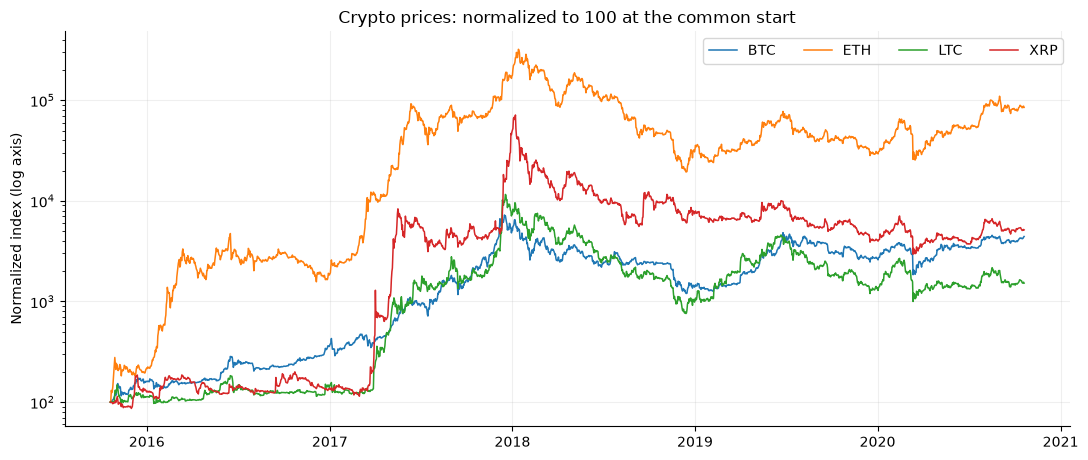

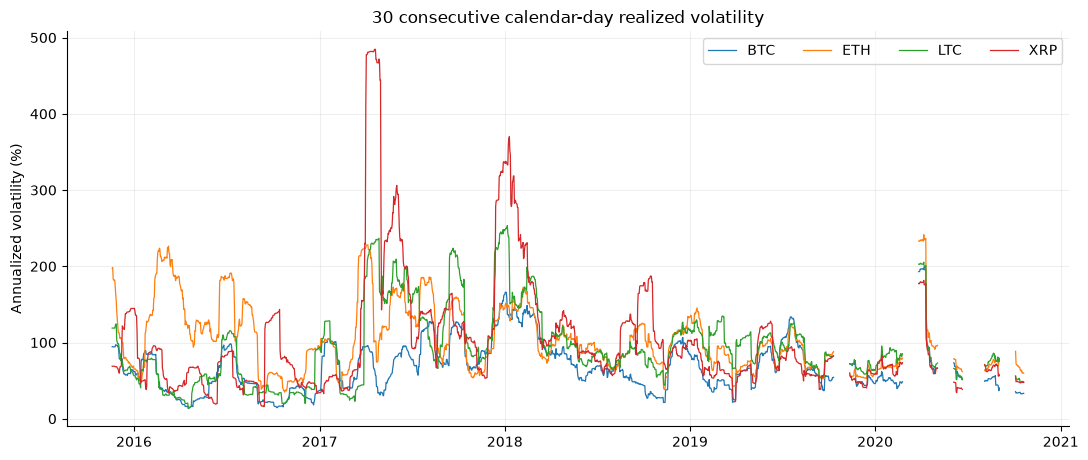

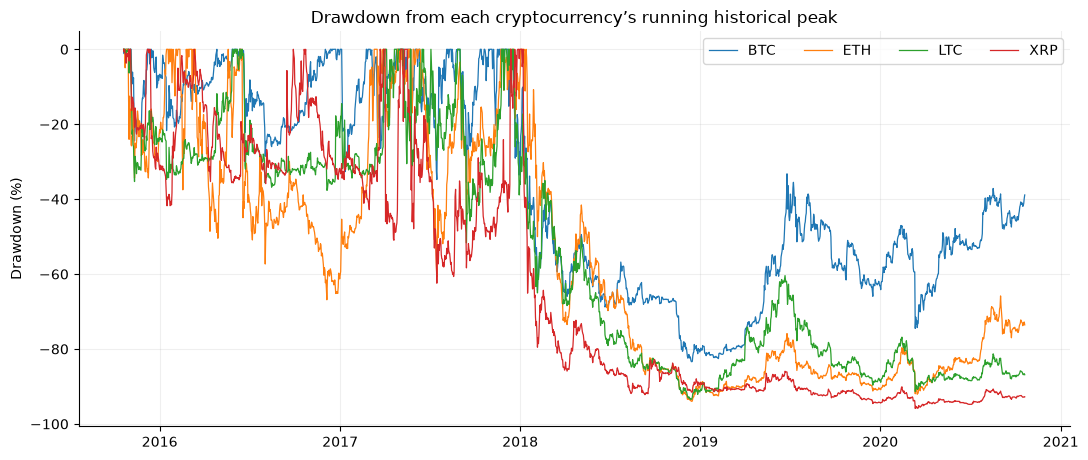

In [5]:
coins = ['BTC','ETH','LTC','XRP']
prices = crypto.set_index('date')[coins]
day_gaps = prices.index.to_series().diff().dt.days
log_returns_daily = np.log(prices/prices.shift(1)).where(day_gaps.eq(1), np.nan)
indexed = 100 * prices.div(prices.iloc[0])
rolling_vol30 = log_returns_daily.rolling(30,min_periods=30).std() * np.sqrt(365)*100
rolling_dd = prices.div(prices.cummax()).sub(1)
risk = pd.DataFrame({
 'start_USD':prices.iloc[0], 'end_USD':prices.iloc[-1],
 'cumulative_price_change_pct':(prices.iloc[-1]/prices.iloc[0]-1)*100,
 'max_drawdown_pct':rolling_dd.min()*100,
 'annualized_realized_vol_pct':log_returns_daily.std()*np.sqrt(365)*100,
 'observed_days':prices.count()})
display(risk.round({"start_USD":6,"end_USD":6,"cumulative_price_change_pct":2,"max_drawdown_pct":2,"annualized_realized_vol_pct":2}))
risk.to_csv(OUT/'crypto_risk_summary.csv')
plt.figure()
for asset in coins:plt.plot(indexed.index,indexed[asset],label=asset,lw=1.1)
plt.yscale('log');plt.title('Crypto prices: normalized to 100 at the common start');plt.ylabel('Normalized index (log axis)')
plt.legend(ncol=4);plt.grid(alpha=.2);savefig('01_crypto_normalized.png')
plt.figure()
for asset in coins:plt.plot(rolling_vol30.index, rolling_vol30[asset], label=asset, lw=.9)
plt.title('30 consecutive calendar-day realized volatility');plt.ylabel('Annualized volatility (%)')
plt.legend(ncol=4);plt.grid(alpha=.2);savefig('02_crypto_rolling_volatility.png')
plt.figure()
for asset in coins:plt.plot(rolling_dd.index,rolling_dd[asset]*100,label=asset,lw=.9)
plt.title('Drawdown from each cryptocurrency’s running historical peak');plt.ylabel('Drawdown (%)')
plt.legend(ncol=4);plt.grid(alpha=.2);savefig('03_crypto_drawdowns.png')

## 3. Trading volume, weekend effects, and crypto diversification

We explore **contemporaneous** BTC dollar-volume / absolute-return association and weekend vs weekday absolute returns in UTC. A Mann–Whitney test is shown descriptively; its independence assumptions are dubious for autocorrelated financial time series, so interpret p-values cautiously. Crypto return correlations also shift across market conditions; no causal or trading conclusion follows.

Same-day volume vs absolute return Pearson r: 0.1648
Weekend/weekday Mann–Whitney p-value (descriptive; serial dependence caveat): 5.673e-05


,n,mean_abs_return,median_abs_return,mean_log_return
weekend,,,,
False,1297,0.02696,0.01590,0.00245
True,518,0.02114,0.01212,0.00142


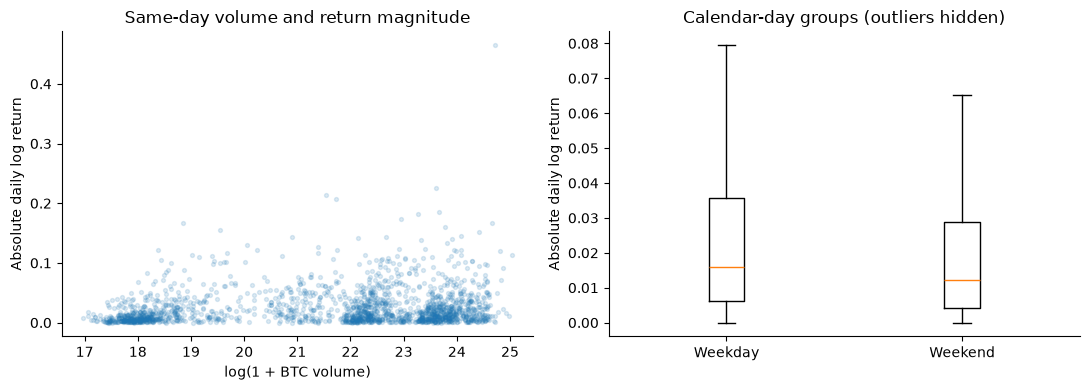

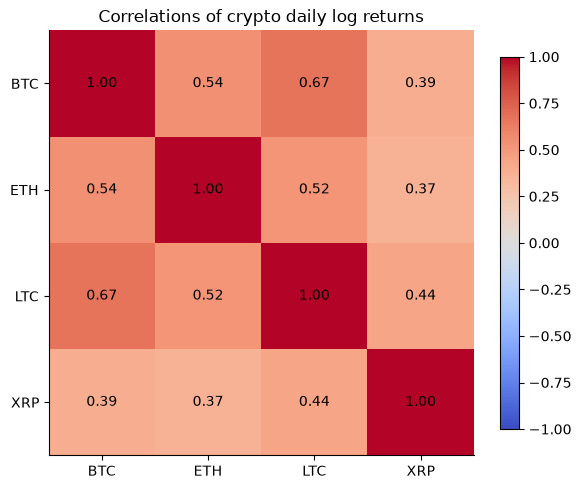

In [6]:
b = crypto[['date','BTC','BTC_Volume','BTC_High','BTC_Low']].copy()
b['calendar_gap'] = b.date.diff().dt.days
b['logret'] = np.log(b.BTC/b.BTC.shift(1)).where(b.calendar_gap.eq(1))
b['abs_return'] = b.logret.abs()
b['log_volume'] = np.log1p(b.BTC_Volume.clip(lower=0))
b['weekend'] = b.date.dt.dayofweek.ge(5)
weekend_table = b.groupby('weekend').agg(n=('abs_return','count'),mean_abs_return=('abs_return','mean'),
 median_abs_return=('abs_return','median'),mean_log_return=('logret','mean'))
valid_vol = b[['abs_return','log_volume']].dropna()
volume_r = valid_vol.abs_return.corr(valid_vol.log_volume)
weekend_p = mannwhitneyu(b.loc[b.weekend,'abs_return'].dropna(),
 b.loc[~b.weekend,'abs_return'].dropna(),alternative='two-sided').pvalue
print('Same-day volume vs absolute return Pearson r:',round(volume_r,4))
print('Weekend/weekday Mann–Whitney p-value (descriptive; serial dependence caveat):',f'{weekend_p:.4g}')
display(weekend_table.round(5))
weekend_table.to_csv(OUT/'weekend_effect.csv')
fig, ax=plt.subplots(1,2,figsize=(11,4))
ax[0].scatter(b.log_volume,b.abs_return,s=8,alpha=.15)
ax[0].set(xlabel='log(1 + BTC volume)',ylabel='Absolute daily log return',title='Same-day volume and return magnitude')
ax[1].boxplot([b.loc[~b.weekend,'abs_return'].dropna(),b.loc[b.weekend,'abs_return'].dropna()],
 showfliers=False)
ax[1].set_xticks([1,2], labels=['Weekday','Weekend'])
ax[1].set(ylabel='Absolute daily log return',title='Calendar-day groups (outliers hidden)')
savefig('04_btc_volume_weekend.png')
crypto_corr = log_returns_daily.corr(min_periods=300)
fig, ax=plt.subplots(figsize=(6,5))
im=ax.imshow(crypto_corr,vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(4),coins);ax.set_yticks(range(4),coins)
for i in range(4):
 for j in range(4):ax.text(j,i,f'{crypto_corr.iloc[i,j]:.2f}',ha='center',va='center')
plt.colorbar(im,ax=ax,shrink=.85);ax.set_title('Correlations of crypto daily log returns')
savefig('05_crypto_return_correlation.png')

## 4. BTC & S&P 500: price correlation versus returns

The level correlation can be high because both prices trend. S&P 500 sessions are observed in US market hours; Bitcoin's same-date daily close is later in UTC. **Same-date return correlation is descriptive only.** The BTC return below is measured between successive available **S&P trading-session dates**: weekend gaps may span three or more calendar days (not always 24 hours). The rolling correlation uses 90 US-market sessions and a minimum 70 complete pairs.

Same-date price-level correlation: 0.835
Same-date S&P-session log-return correlation: 0.160
Market-session date intervals (calendar days):


,sessions
market_session_gap_days,
1.0,985
2.0,13
3.0,228
4.0,33


,regime,sessions,paired_returns,return_correlation
0,2015–16,303,302,-0.0576
1,2017,251,251,0.0671
2,2018,251,251,0.0768
3,2019,252,252,-0.1094
4,2020,203,195,0.4820


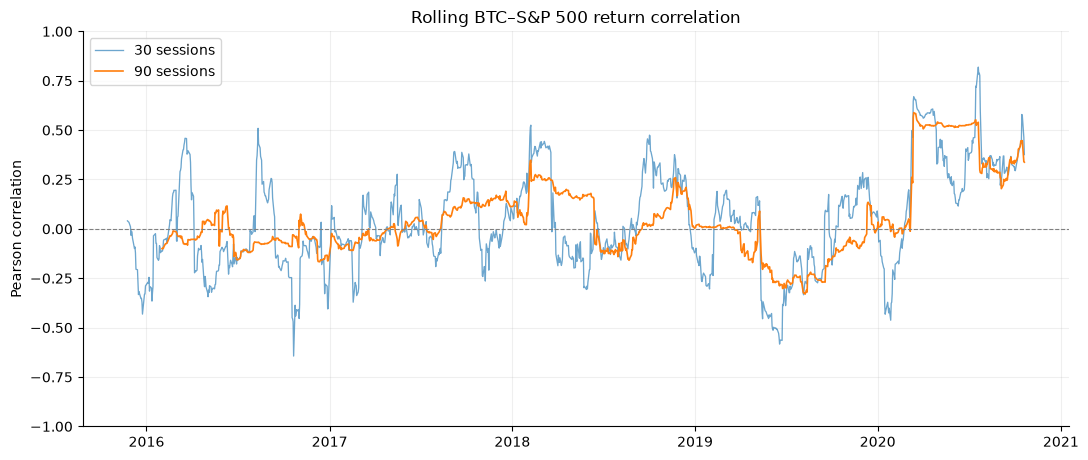

In [7]:
aligned = market[['date','SP500','BTC']].copy()
for sym in ['SP500','BTC']:
    aligned[sym+'_return'] = np.log(aligned[sym]/aligned[sym].shift(1))
aligned['market_session_gap_days'] = aligned.date.diff().dt.days
level_r = aligned[['SP500','BTC']].corr().loc['SP500','BTC']
returns_r = aligned[['SP500_return','BTC_return']].corr().iloc[0,1]
print(f'Same-date price-level correlation: {level_r:.3f}')
print(f'Same-date S&P-session log-return correlation: {returns_r:.3f}')
print('Market-session date intervals (calendar days):')
display(aligned.market_session_gap_days.value_counts().sort_index().rename('sessions').to_frame())
aligned['corr_30'] = aligned.SP500_return.rolling(30,min_periods=25).corr(aligned.BTC_return)
aligned['corr_90'] = aligned.SP500_return.rolling(90,min_periods=70).corr(aligned.BTC_return)
aligned['regime']=pd.cut(aligned.date, bins=pd.to_datetime([
 '2015-10-19','2016-12-31','2017-12-31','2018-12-31','2019-12-31','2020-10-21']),
 labels=['2015–16','2017','2018','2019','2020'])
regimes=[]
for period,group in aligned.groupby('regime',observed=True):
 clean=group[['SP500_return','BTC_return']].dropna()
 regimes.append({'regime':str(period),'sessions':len(group),'paired_returns':len(clean),
                  'return_correlation':clean.corr().iloc[0,1] if len(clean)>5 else np.nan})
regime_table=pd.DataFrame(regimes)
display(regime_table.round(4))
regime_table.to_csv(OUT/'market_regime_correlations.csv',index=False)
plt.figure()
plt.plot(aligned.date,aligned.corr_30,label='30 sessions',alpha=.65,lw=.95)
plt.plot(aligned.date,aligned.corr_90,label='90 sessions',lw=1.2)
plt.axhline(0,ls='--',lw=.8,color='gray');plt.ylim(-1,1);plt.grid(alpha=.2)
plt.title('Rolling BTC–S&P 500 return correlation');plt.ylabel('Pearson correlation');plt.legend()
savefig('06_btc_sp500_rolling_correlation.png')

## 5. Reduced explanatory regression and classical diagnostics

**Historical distinction:** The 2020 coursework fitted a BTC-price regression using both **S&P 500 and Dow Jones**. This package does not contain Dow Jones; using `BTC ~ SP500` below is a **reduced illustrative specification**, not a reproduction of the original two-predictor model. It explains **same-date variation in sample only**; it does **not** form the next-session forecasting result.

We examine residual patterns, normal Q–Q, heteroskedasticity (Breusch–Pagan) and autocorrelation (Ljung–Box). Historical nonstationary prices make naive coefficient p-values questionable. Residual behavior provides a reason to avoid reporting high in-sample R² as a predictive success.

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1.691e+04    420.649    -40.205      0.000   -1.77e+04   -1.61e+04
SP500          8.5111      0.159     53.669      0.000       8.200       8.822
Reduced model in-sample R²: 0.6967 (NOT out-of-sample price forecasting)
Breusch–Pagan p: 0.003364 | Ljung–Box lag-10 p: 0


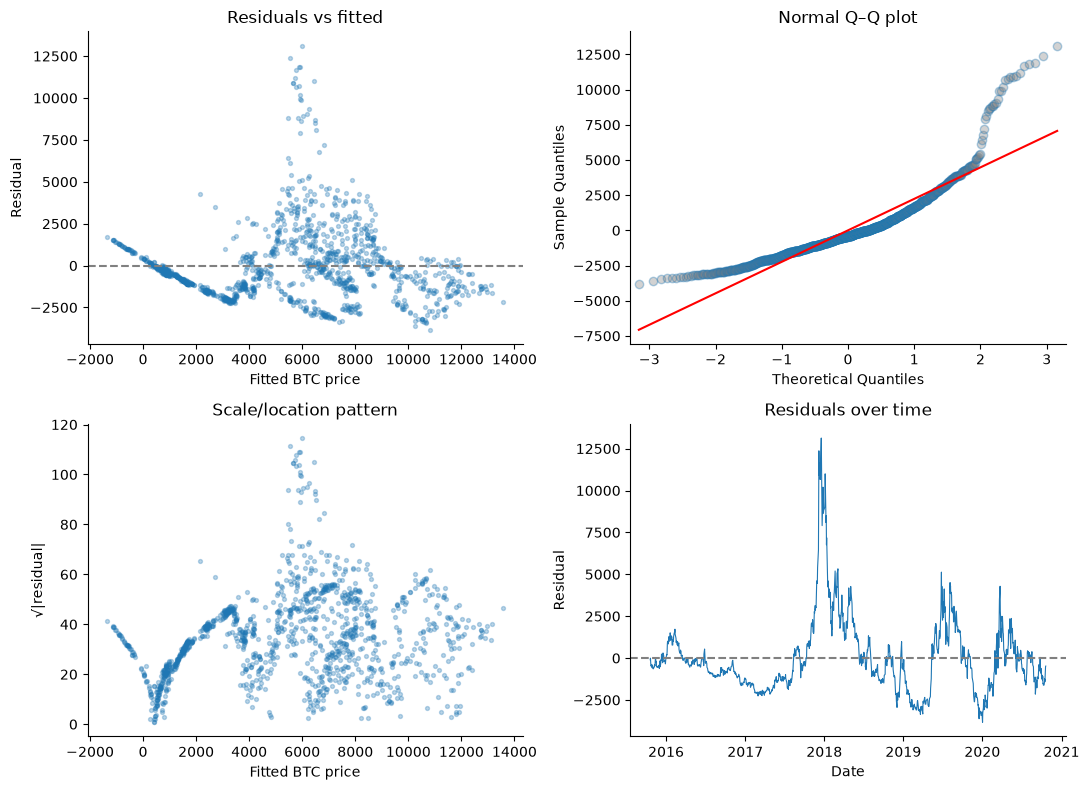

In [8]:
explain = market[['date','BTC','SP500']].dropna().copy()
ols_explain = sm.OLS(explain.BTC, sm.add_constant(explain.SP500)).fit()
print(ols_explain.summary().tables[1])
print('Reduced model in-sample R²:', round(ols_explain.rsquared,4),
      '(NOT out-of-sample price forecasting)')
bp = het_breuschpagan(ols_explain.resid,ols_explain.model.exog)
lj = acorr_ljungbox(ols_explain.resid,lags=[10],return_df=True)
print('Breusch–Pagan p:',f'{bp[1]:.4g}','| Ljung–Box lag-10 p:',f'{lj.lb_pvalue.iloc[0]:.4g}')
from scipy import stats
fig,ax=plt.subplots(2,2,figsize=(11,8))
ax[0,0].scatter(ols_explain.fittedvalues,ols_explain.resid,s=8,alpha=.3)
ax[0,0].axhline(0,ls='--',color='gray');ax[0,0].set(xlabel='Fitted BTC price',ylabel='Residual',title='Residuals vs fitted')
sm.qqplot(ols_explain.resid,line='s',ax=ax[0,1],markerfacecolor='gray',alpha=.35)
ax[0,1].set_title('Normal Q–Q plot')
ax[1,0].scatter(ols_explain.fittedvalues,np.sqrt(np.abs(ols_explain.resid)),s=8,alpha=.3)
ax[1,0].set(xlabel='Fitted BTC price',ylabel='√|residual|',title='Scale/location pattern')
ax[1,1].plot(explain.date,ols_explain.resid,lw=.8)
ax[1,1].axhline(0,ls='--',color='gray');ax[1,1].set(xlabel='Date',ylabel='Residual',title='Residuals over time')
savefig('07_explanatory_OLS_diagnostics.png')

## 6. ADF / KPSS and stationarity caveats

ADF's null is **unit root**; KPSS's null is **stationarity**. Tests are applied to log BTC **price levels** and separately to returns from consecutive observed crypto calendar days. We drop unavailable dates but **do not invent** intervening prices; gaps make the return-series assumption approximate. Tests depend on chosen lag/trend assumptions and should not be interpreted as trading signals.
**KPSS note:** lookup-table p-values are bounded by implementation tables; any warnings or capped estimates should not be read as exact tail probabilities.


In [9]:
btc_log_price = np.log(prices.BTC.dropna())
btc_consecutive_returns = log_returns_daily.BTC.dropna()
def stationarity_row(name, s):
    x=np.asarray(s,dtype=float);x=x[np.isfinite(x)]
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message=r'adfuller currently returns a plain tuple', category=FutureWarning)
        adf=adfuller(x,autolag='AIC',regression='c')
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', category=UserWarning)
        import inspect
        _kp_kwargs={'regression':'c','nlags':'auto'}
        if 'result_object' in inspect.signature(kpss).parameters:
            _kp_kwargs['result_object']=False
        with warnings.catch_warnings():
            warnings.filterwarnings('ignore', message=r'kpss currently returns a plain tuple', category=FutureWarning)
            kp=kpss(x,**_kp_kwargs)
    return {'series':name,'n':len(x),'ADF_stat':adf[0],'ADF_p':adf[1],
            'KPSS_stat':kp[0],'KPSS_p':kp[1]}
stationarity_table=pd.DataFrame([
 stationarity_row('log BTC price',btc_log_price),
 stationarity_row('BTC consecutive-day log returns',btc_consecutive_returns)])
display(stationarity_table.round(5))
stationarity_table.to_csv(OUT/'stationarity_tests.csv',index=False)

,series,n,ADF_stat,ADF_p,KPSS_stat,KPSS_p
0,log BTC price,1822,-1.79914,0.38089,5.20621,0.01
1,BTC consecutive-day log returns,1815,-43.63745,0.00000,0.21856,0.10


## 7. Predict **next US market-session** Bitcoin close without future information

The observation for S&P market-session date *t* includes the BTC crypto UTC closing price on date *t*. It becomes observable after the same-date S&P closing bell. We predict its value using **only data available by the previous S&P session**. Features have explicit `lag1`/`lag2` suffixes. The baseline forecasts no change from the **previous observed BTC crypto close**.

**Target:** `log(BTC_t / BTC_(t−1 session))`.  **Reconstruction:** `BTC_hat_t = previous_BTC × exp(predicted_return_t)`.

This is a *next-S&P-market-session* forecast rather than a fixed 24-hour horizon. Gaps vary around weekends, holidays and unavailable Bitcoin rows. Models share identical held-out rows to ensure a fair comparison. Train: through 2018; validation: 2019; final test: 2020-01-01 through 2020-10-20.

In [10]:
f = market[['date','BTC','SP500','BTC_Volume','BTC_High','BTC_Low']].copy()
f['previous_BTC'] = f.BTC.shift(1)
f['target_return'] = np.log(f.BTC/f.previous_BTC)
f['BTC_return_lag1'] = f.target_return.shift(1)
f['BTC_return_lag2'] = f.target_return.shift(2)
f['BTC_momentum5_lag1'] = np.log(f.BTC/f.BTC.shift(5)).shift(1)
f['BTC_vol20_lag1'] = f.target_return.rolling(20,min_periods=15).std().shift(1)
f['SP500_return_lag1'] = np.log(f.SP500/f.SP500.shift(1)).shift(1)
f['BTC_logvolume_lag1'] = np.log1p(f.BTC_Volume.clip(lower=0)).shift(1)
f['BTC_range_lag1'] = ((f.BTC_High-f.BTC_Low)/f.BTC).shift(1)
f['horizon_days']=f.date.diff().dt.days
features=['BTC_return_lag1','BTC_return_lag2','BTC_momentum5_lag1','BTC_vol20_lag1',
          'SP500_return_lag1','BTC_logvolume_lag1','BTC_range_lag1']
f[features]=f[features].replace([np.inf,-np.inf],np.nan)
forecast=f.dropna(subset=['BTC','previous_BTC','target_return']+features).copy().reset_index(drop=True)
train=forecast[forecast.date.le(TRAIN_END)].copy()
valid=forecast[forecast.date.gt(TRAIN_END)&forecast.date.le(VALID_END)].copy()
test=forecast[forecast.date.gt(VALID_END)&forecast.date.le(END)].copy()
assert len(train)>600 and len(valid)>200 and len(test)>150
assert train.date.max()<valid.date.min()<test.date.min()
assert np.isfinite(forecast[features+['target_return','previous_BTC']].to_numpy()).all()
print('Rows: train',len(train),'| validation',len(valid),'| 2020 retrospective sample',len(test))
print('Features (all lagged):', ', '.join(features))
print('Horizon distribution in usable forecast rows:')
display(forecast.horizon_days.value_counts().sort_index().rename('observations').to_frame())
# VIF for historical feature collinearity (not a feature-selection signal from the held-out test).
train_design = sm.add_constant(train[features])
vif_table = pd.DataFrame({'feature':features,'VIF_train':[
    variance_inflation_factor(train_design.to_numpy(),i+1) for i in range(len(features))]})
display(vif_table.round(2))
vif_table.to_csv(OUT/'training_feature_VIF.csv',index=False)

Rows: train 789 | validation 252 | 2020 retrospective sample 183
Features (all lagged): BTC_return_lag1, BTC_return_lag2, BTC_momentum5_lag1, BTC_vol20_lag1, SP500_return_lag1, BTC_logvolume_lag1, BTC_range_lag1
Horizon distribution in usable forecast rows:


,observations
horizon_days,
1.0,957
2.0,13
3.0,222
4.0,32


,feature,VIF_train
0,BTC_return_lag1,1.45
1,BTC_return_lag2,1.38
2,BTC_momentum5_lag1,1.79
3,BTC_vol20_lag1,1.58
4,SP500_return_lag1,1.01
5,BTC_logvolume_lag1,1.45
6,BTC_range_lag1,1.67


## 8. Candidate model families and fair validation

Seven candidate model families: naive unchanged price, ordinary least squares, Ridge, Elastic Net, Linear SVR, RBF SVR, XGBoost. **Hyperparameters are selected using 2019 validation price RMSE only**. Standardization is fitted within each training pipeline (never with validation/test means). The no-change baseline predicts a **zero return**, so its direction accuracy is undefined (NA), not 0%.

A low test RMSE matters only relative to the baseline. An impressive price R² alone can simply reflect that Bitcoin price is persistent. This section records validation candidates without peeking at the 2020 test.

In [11]:
Xtr,ytr=train[features],train.target_return
Xv,yv=valid[features],valid.target_return
Xt=test[features]
models={
  'Naive no-change':[None],
  'OLS returns':[LinearRegression()],
  'Ridge':[make_pipeline(StandardScaler(),Ridge(alpha=a)) for a in [0.01,0.1,1,10,100]],
  'Elastic Net':[make_pipeline(StandardScaler(),ElasticNet(alpha=a,l1_ratio=0.5,max_iter=10000,random_state=SEED))
                 for a in [0.0001,0.0005,0.001,0.005,0.01]],
  'Linear SVR':[make_pipeline(StandardScaler(),SVR(kernel='linear',C=c,epsilon=e))
                for c in [0.1,1,10] for e in [0.01,0.03]],
  'Radial SVR':[make_pipeline(StandardScaler(),SVR(kernel='rbf',C=c,epsilon=e,gamma='scale'))
                for c in [0.1,1,10] for e in [0.01,0.03]],
  'XGBoost':[XGBRegressor(n_estimators=n,max_depth=d,learning_rate=lr,
                         subsample=0.85,colsample_bytree=0.9,reg_lambda=10,
                         objective='reg:squarederror',n_jobs=2,random_state=SEED)
             for n in [120,240] for d,lr in [(2,0.03),(3,0.06)]]
}

def evaluate(d,predicted_return,name,split):
    r=np.asarray(predicted_return,dtype=float)
    if len(r)!=len(d):raise ValueError('Prediction length mismatch')
    actual=d.BTC.to_numpy()
    predicted_price=d.previous_BTC.to_numpy()*np.exp(r)
    if not np.isfinite(predicted_price).all():raise ValueError('Non-finite predicted prices')
    err=actual-predicted_price
    actual_returns=d.target_return.to_numpy()
    return dict(model=name,split=split,n=len(d),
        RMSE_USD=np.sqrt(np.mean(err**2)),MAE_USD=np.mean(np.abs(err)),
        R2_price=r2_score(actual,predicted_price),
        return_RMSE=np.sqrt(np.mean((actual_returns-r)**2)),
        sMAPE_pct=100*np.mean(2*np.abs(err)/np.maximum(np.abs(actual)+np.abs(predicted_price),1e-12)),
        direction_accuracy=(np.nan if np.all(r==0) else np.mean(np.sign(r)==np.sign(actual_returns))))

chosen={};validation_records=[];chosen_settings=[]
for label,candidates in models.items():
    best=None
    for i,est in enumerate(candidates):
        if est is None:r=np.zeros(len(valid))
        else:
            fit=clone(est).fit(Xtr,ytr)
            r=fit.predict(Xv)
        score=evaluate(valid,r,label,'2019 validation')
        if best is None or score['RMSE_USD'] < best[0]['RMSE_USD']:
            best=(score,i)
    if best is None:raise RuntimeError('No valid candidate for '+label)
    validation_records.append(best[0]);chosen[label]=best[1]
    chosen_settings.append({'model':label,'candidate_index':best[1],
        'candidate_repr':repr(candidates[best[1]]) if candidates[best[1]] is not None else 'zero return'})
validation_table=pd.DataFrame(validation_records).sort_values('RMSE_USD').reset_index(drop=True)
selected_model=validation_table.model.iloc[0]
print('Chosen model, based ONLY on 2019 validation:',selected_model)
display(validation_table.round(4))
validation_table.to_csv(OUT/'validation_2019_metrics.csv',index=False)
pd.DataFrame(chosen_settings).to_csv(OUT/'selected_hyperparameters.csv',index=False)

Chosen model, based ONLY on 2019 validation: Naive no-change


,model,split,n,RMSE_USD,MAE_USD,R2_price,return_RMSE,sMAPE_pct,direction_accuracy
0,Naive no-change,2019 validation,252,394.7558,230.2137,0.9777,0.0431,2.7585,NaN
1,Elastic Net,2019 validation,252,395.5082,232.1123,0.9776,0.0430,2.7733,0.5079
2,Linear SVR,2019 validation,252,396.2761,231.4460,0.9775,0.0432,2.7718,0.4960
3,Ridge,2019 validation,252,398.1543,230.9543,0.9773,0.0434,2.7834,0.5159
4,OLS returns,2019 validation,252,399.6371,232.1663,0.9771,0.0437,2.8076,0.5159
5,XGBoost,2019 validation,252,407.2012,248.4614,0.9762,0.0452,3.0464,0.4881
6,Radial SVR,2019 validation,252,424.7803,252.5706,0.9741,0.0461,3.0822,0.5159


## 9. Final chronological 2020 historical evaluation — no retuning

For each model family, freeze the candidate index chosen on 2019, refit it on all 2015–2019 training+validation observations, and then evaluate **once** on the historical 2020 historical evaluation. We present all scores for transparency, but **do not choose the preferred model by which one happened to rank first on 2020**. The main preselected model is the 2019 winner. Any 2020 ranking is retrospective.

2020 holdout: rows ordered by 2019 validation performance, not by test fit


,model,split,n,RMSE_USD,MAE_USD,R2_price,return_RMSE,sMAPE_pct,direction_accuracy,RMSE_gain_over_naive_pct
0,Naive no-change,2020 holdout,183,381.5608,228.7474,0.9479,0.0504,2.6424,NaN,0.0000
1,Elastic Net,2020 holdout,183,380.9144,228.4398,0.9481,0.0503,2.6364,0.5519,0.1694
2,Linear SVR,2020 holdout,183,381.8037,231.1305,0.9478,0.0504,2.6709,0.4918,-0.0637
3,Ridge,2020 holdout,183,383.0841,233.2402,0.9475,0.0507,2.7000,0.4481,-0.3992
4,OLS returns,2020 holdout,183,383.5956,234.2335,0.9473,0.0508,2.7129,0.4426,-0.5333
5,XGBoost,2020 holdout,183,385.8343,240.1180,0.9467,0.0504,2.7591,0.4208,-1.1200
6,Radial SVR,2020 holdout,183,409.0391,277.2200,0.9401,0.0519,3.1195,0.4481,-7.2016


2019-selected model Naive no-change: 2020 RMSE gain vs baseline = 0.000%


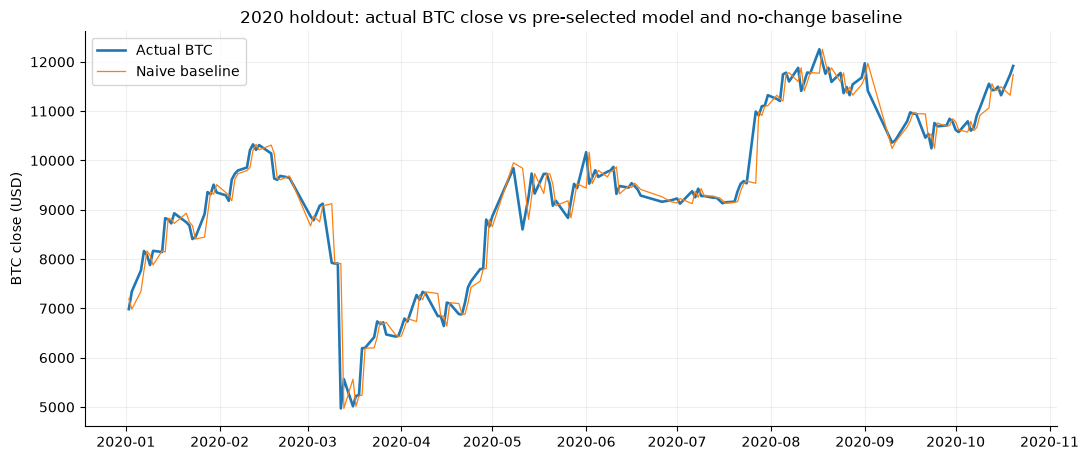

In [12]:
train_valid=pd.concat([train,valid],ignore_index=True)
Xtv=train_valid[features];ytv=train_valid.target_return
predicted_returns={};predicted_prices={};holdout_records={}
for label in validation_table.model:
    est=models[label][chosen[label]]
    r=np.zeros(len(test)) if est is None else clone(est).fit(Xtv,ytv).predict(Xt)
    predicted_returns[label]=r
    predicted_prices[label]=test.previous_BTC.to_numpy()*np.exp(r)
    holdout_records[label]=evaluate(test,r,label,'2020 holdout')
holdout=pd.DataFrame([holdout_records[label] for label in validation_table.model])
baseline_rmse=holdout.loc[holdout.model.eq('Naive no-change'),'RMSE_USD'].iloc[0]
holdout['RMSE_gain_over_naive_pct']=100*(baseline_rmse-holdout.RMSE_USD)/baseline_rmse
print('2020 holdout: rows ordered by 2019 validation performance, not by test fit')
display(holdout.round(4))
print(f'2019-selected model {selected_model}: 2020 RMSE gain vs baseline = '
      f"{holdout.loc[holdout.model.eq(selected_model),'RMSE_gain_over_naive_pct'].iloc[0]:.3f}%")
holdout.to_csv(OUT/'holdout_2020_metrics.csv',index=False)
preds=pd.DataFrame({'date':test.date.to_numpy(),'actual_BTC':test.BTC.to_numpy(),
                    'previous_BTC':test.previous_BTC.to_numpy()})
for label,vals in predicted_prices.items():preds[label]=vals
preds.to_csv(OUT/'holdout_2020_predictions.csv',index=False)
plt.figure()
plt.plot(preds.date,preds.actual_BTC,label='Actual BTC',lw=1.9)
plt.plot(preds.date,preds['Naive no-change'],label='Naive baseline',lw=.9)
if selected_model!='Naive no-change':plt.plot(preds.date,preds[selected_model],label='Validation-selected: '+selected_model,lw=.85)
plt.title('2020 holdout: actual BTC close vs pre-selected model and no-change baseline')
plt.ylabel('BTC close (USD)');plt.legend();plt.grid(alpha=.2)
savefig('08_2020_holdout_predictions.png')

## 10. Robustness: errors by 2020 quarter + expanding-window historical checks

Quarterly errors are **diagnostic only** and never trigger test-set retuning. Separately, for each year (2018, 2019 and 2020) we train a **new untuned OLS model** on all preceding usable dates and compare against no-change. This demonstrates model sensitivity to historical periods without claiming a nested cross-validation of all tuned models.
**Small-sample caution:** the 2020-Q4 group ends Oct 20 (not a complete quarter); any tiny horizon or quarterly bins are unstable.


In [13]:
quarter=preds.copy();quarter['quarter']=quarter.date.dt.to_period('Q').astype(str)
quarter_records=[]
for q,g in quarter.groupby('quarter'):
    quarter_records.append({'quarter':q,'n':len(g),
      'naive_RMSE':np.sqrt(np.mean((g.actual_BTC-g['Naive no-change'])**2)),
      'preselected_RMSE':np.sqrt(np.mean((g.actual_BTC-g[selected_model])**2))})
quarter_table=pd.DataFrame(quarter_records)
display(quarter_table.round(2))
quarter_table.to_csv(OUT/'holdout_quarter_diagnostics.csv',index=False)
expanding=[]
for year in [2018,2019,2020]:
    earlier=forecast.loc[forecast.date < pd.Timestamp(f'{year}-01-01')]
    future=forecast.loc[(forecast.date >= pd.Timestamp(f'{year}-01-01')) &
                        (forecast.date < pd.Timestamp(f'{year+1}-01-01'))]
    if len(earlier)<300 or len(future)<100:continue
    simple_model=LinearRegression().fit(earlier[features],earlier.target_return)
    expanding.append(evaluate(future,np.zeros(len(future)),'Naive no-change',str(year)))
    expanding.append(evaluate(future,simple_model.predict(future[features]),'OLS untuned',str(year)))
expanding_table=pd.DataFrame(expanding)
display(expanding_table[['split','model','n','RMSE_USD','MAE_USD','R2_price']].round(3))
expanding_table.to_csv(OUT/'expanding_year_robustness.csv',index=False)

,quarter,n,naive_RMSE,preselected_RMSE
0,2020Q1,57,504.17,504.17
1,2020Q2,53,349.94,349.94
2,2020Q3,59,290.11,290.11
3,2020Q4,14,223.30,223.30


,split,model,n,RMSE_USD,MAE_USD,R2_price
0,2018,Naive no-change,251,439.474,272.973,0.965
1,2018,OLS untuned,251,486.345,307.613,0.958
2,2019,Naive no-change,252,394.756,230.214,0.978
3,2019,OLS untuned,252,399.637,232.166,0.977
4,2020,Naive no-change,183,381.561,228.747,0.948
5,2020,OLS untuned,183,383.596,234.234,0.947


## 11. Feature ablation: do S&P 500 inputs add predictive value?

Three nested sets: **A** (BTC lagged returns only), **B** (BTC return/momentum/volatility/volume/range), **C** (B plus lagged S&P 500 return). We fit the **same standardized Ridge** algorithm for each and tune its alpha only on **2019 validation**. The best set is fixed before a **single 2020 audit**. Other 2020 rows are printed only as frozen candidate diagnostics—not as candidates from which to pick a winner.  

The original 7-model competition remains intact above. This is a *separate, explanatory experiment*; it does not rewrite the original winner after seeing its test score. Source prices remain dated at different UTC/US closing times; the S&P predictor is lagged. Variance inflation and importance are diagnostic, not evidence of causation.

2019-preselected ablation: A: BTC returns only | Ridge alpha: 100.0


,model,n_features,alpha,RMSE_USD,MAE_USD,return_RMSE
0,A: BTC returns only,2,100.0,396.17136,232.22533,0.04300
1,B: BTC features,6,100.0,398.03681,230.91595,0.04342
2,C: BTC + lagged S&P,7,100.0,398.15429,230.95428,0.04342


Frozen holdout results (do not reselect using this table):


,model,selected_on_2019,RMSE_USD,MAE_USD,return_RMSE
0,A: BTC returns only,True,381.66337,229.59429,0.05042
1,B: BTC features,False,382.65327,232.03769,0.05059
2,C: BTC + lagged S&P,False,383.08407,233.24022,0.05068


,feature,mean_RMSE_increase_USD,sd_RMSE_increase_USD
1,BTC_return_lag2,-0.0788,0.2128
0,BTC_return_lag1,-0.5058,0.4502


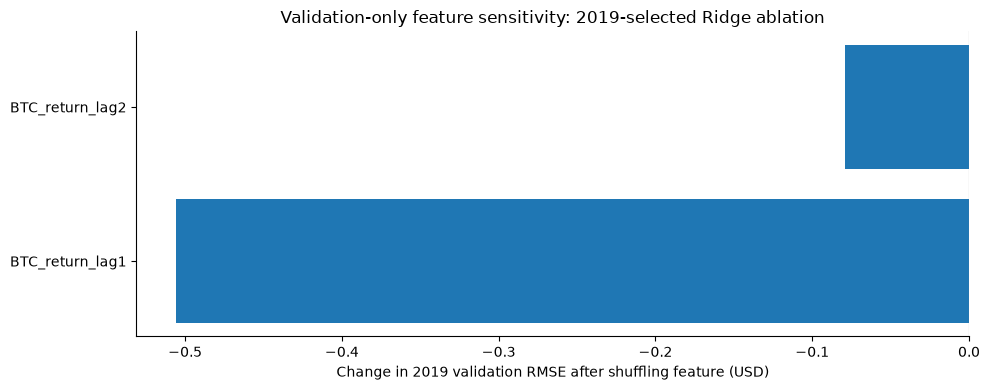

In [14]:
# Re-use the existing chronological forecast/train/valid/test data; all features precede the target.
ABLATION_SETS = {
    'A: BTC returns only': ['BTC_return_lag1','BTC_return_lag2'],
    'B: BTC features': [x for x in features if x != 'SP500_return_lag1'],
    'C: BTC + lagged S&P': list(features),
}
ABLATION_ALPHAS = [0.01, 0.1, 1.0, 10.0, 100.0]
ablation_records=[]
for group, cols in ABLATION_SETS.items():
    for alpha in ABLATION_ALPHAS:
        est=make_pipeline(StandardScaler(), Ridge(alpha=alpha))
        fitted=clone(est).fit(train[cols],train.target_return)
        score=evaluate(valid,fitted.predict(valid[cols]),group,'2019 validation')
        ablation_records.append({**score,'alpha':alpha,'n_features':len(cols)})
ablation_val=pd.DataFrame(ablation_records).sort_values(['RMSE_USD','model','alpha'])
selected_ablation=ablation_val.iloc[0]
selected_ablation_name=str(selected_ablation['model']);selected_ablation_alpha=float(selected_ablation['alpha'])
print('2019-preselected ablation:',selected_ablation_name,'| Ridge alpha:',selected_ablation_alpha)
display(ablation_val.groupby('model',as_index=False).first()[['model','n_features','alpha','RMSE_USD','MAE_USD','return_RMSE']].round(5))
ablation_val.to_csv(OUT/'ablation_validation_full.csv',index=False)

ablation_frozen={};ablation_holdout=[]
for group in ABLATION_SETS:
    best_row=ablation_val.loc[ablation_val.model.eq(group)].iloc[0]
    cols=ABLATION_SETS[group]
    estimator=make_pipeline(StandardScaler(),Ridge(alpha=float(best_row.alpha)))
    estimator.fit(train_valid[cols],train_valid.target_return)
    r=estimator.predict(test[cols]);ablation_frozen[group]=r
    ablation_holdout.append(evaluate(test,r,group,'2020 frozen diagnostic'))
ablation_test=pd.DataFrame(ablation_holdout)
ablation_test['selected_on_2019']=ablation_test.model.eq(selected_ablation_name)
print('Frozen holdout results (do not reselect using this table):')
display(ablation_test[['model','selected_on_2019','RMSE_USD','MAE_USD','return_RMSE']].round(5))
ablation_test.to_csv(OUT/'ablation_2020_frozen_diagnostics.csv',index=False)

# Validation-only permutation sensitivity on the preselected model (not a causal importance).
chosen_cols=ABLATION_SETS[selected_ablation_name]
ablation_model=make_pipeline(StandardScaler(), Ridge(alpha=selected_ablation_alpha)).fit(train[chosen_cols],train.target_return)
base_val_rmse=evaluate(valid,ablation_model.predict(valid[chosen_cols]),'frozen','2019')['RMSE_USD']
rng_importance=np.random.default_rng(SEED)
importance=[]
for col in chosen_cols:
    deltas=[]
    for _ in range(30):
        shuffled=valid[chosen_cols].copy()
        shuffled[col]=rng_importance.permutation(shuffled[col].to_numpy())
        rmse=evaluate(valid,ablation_model.predict(shuffled),'frozen','2019')['RMSE_USD']
        deltas.append(rmse-base_val_rmse)
    importance.append({'feature':col,'mean_RMSE_increase_USD':np.mean(deltas),'sd_RMSE_increase_USD':np.std(deltas)})
importance_table=pd.DataFrame(importance).sort_values('mean_RMSE_increase_USD',ascending=False)
display(importance_table.round(4))
importance_table.to_csv(OUT/'validation_only_ablation_permutation.csv',index=False)
plt.figure(figsize=(10,4))
plt.barh(importance_table.feature[::-1],importance_table.mean_RMSE_increase_USD[::-1])
plt.axvline(0,color='gray',lw=.8);plt.xlabel('Change in 2019 validation RMSE after shuffling feature (USD)')
plt.title('Validation-only feature sensitivity: 2019-selected Ridge ablation')
savefig('09_ablation_feature_sensitivity.png')

## 12. SARIMAX: statistical one-step return forecasting benchmark

Fit a simple **SARIMAX(1,0,0)** model for Bitcoin returns with **lagged S&P 500 return** as the external regressor. Return units are percentage points for numerical conditioning. Parameters are estimated on **2015–2018**, and 2019 predictions are **one observed equity-session ahead, updated with past *realized* returns** (filtering only, no future information). Refit parameters on 2015–2019 and use the same rolling one-step protocol for 2020. The lagged S&P input is available at forecast time under the study's end-of-UTC-day convention.

A market-session index has irregular calendar gaps (weekends, holidays and missing source observations); model steps refer to **observed market sessions**, not equally spaced 24-hour intervals. SARIMAX results are compared against the 2019-selected original champion and the no-change baseline using 2019 **before** opening the 2020 historical evaluation. **No 2020 retuning.**

2019 original champion: Naive no-change
2019 SARIMAX validation RMSE: 396.042
Extended 2019 selection (fixed before 2020): Naive no-change


,model,split,n,RMSE_USD,MAE_USD,R2_price,return_RMSE,sMAPE_pct,direction_accuracy
0,SARIMAX AR1 + S&P lag,2019 validation,252,396.04153,232.33051,0.97751,0.04300,2.77505,0.50794
1,SARIMAX AR1 + S&P lag,2020 holdout,183,381.80767,230.26357,0.94782,0.05045,2.66059,0.54645


SARIMAX train fit: {'intercept': np.float64(0.30053), 'x1': np.float64(0.045462), 'ar.L1': np.float64(0.011155), 'sigma2': np.float64(22.158302)}
SARIMAX train+validation fit: {'intercept': np.float64(0.290596), 'x1': np.float64(0.022055), 'ar.L1': np.float64(0.008408), 'sigma2': np.float64(21.269644)}
One-step forecast uses past true returns (conditional online evaluation), not an un-updated 2020 multi-step forecast.


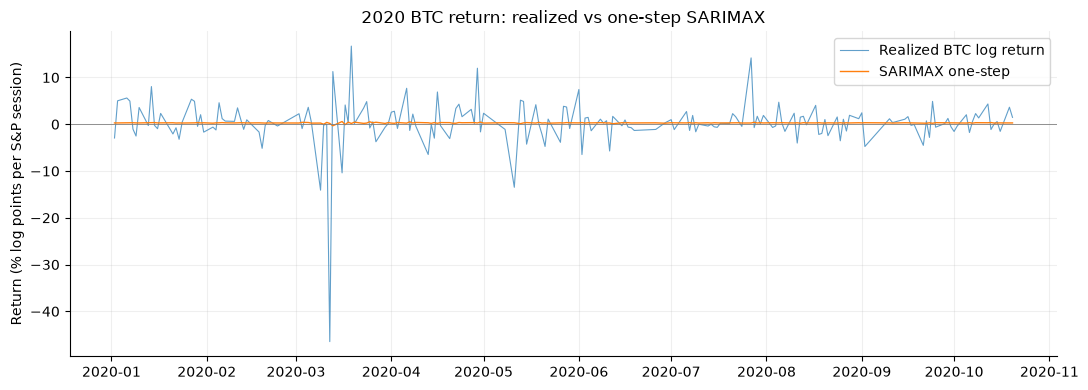

In [15]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

def sarimax_filter_predictions(fit_frame, prediction_frame):
    """Gaussian AR(1)+lagged S&P; filtered one-step predictions use previous realized returns only."""
    fit_y=fit_frame.target_return.to_numpy()*100
    fit_x=fit_frame[['SP500_return_lag1']].to_numpy()*100
    smodel=SARIMAX(fit_y,exog=fit_x,order=(1,0,0),trend='c',
                   enforce_stationarity=True,enforce_invertibility=True)
    with warnings.catch_warnings(record=True) as fitwarn:
        warnings.simplefilter('always')
        result=smodel.fit(disp=False,maxiter=250)
    if not result.mle_retvals.get('converged',True):
        print('Warning: SARIMAX optimizer did not report convergence; inspect diagnostics.')
    all_data=pd.concat([fit_frame,prediction_frame],ignore_index=True)
    all_y=all_data.target_return.to_numpy()*100
    all_x=all_data[['SP500_return_lag1']].to_numpy()*100
    # Filtering yields one-step fitted forecast conditional on y_0,...,y_(t-1).
    full=SARIMAX(all_y,exog=all_x,order=(1,0,0),trend='c',
                 enforce_stationarity=True,enforce_invertibility=True)
    filt=full.filter(result.params)
    pred=np.asarray(filt.get_prediction(start=len(fit_frame),end=len(all_data)-1).predicted_mean)/100
    assert len(pred)==len(prediction_frame) and np.isfinite(pred).all()
    return pred,result

sarimax_valid_r,sarimax_train_fit=sarimax_filter_predictions(train,valid)
sarimax_validation=evaluate(valid,sarimax_valid_r,'SARIMAX AR1 + S&P lag','2019 validation')
preselected_orig_valid=validation_table.loc[validation_table.model.eq(selected_model)].iloc[0]
extended_selected= ('SARIMAX AR1 + S&P lag' if sarimax_validation['RMSE_USD'] < preselected_orig_valid.RMSE_USD
                   else selected_model)
print('2019 original champion:',selected_model)
print('2019 SARIMAX validation RMSE:',round(sarimax_validation['RMSE_USD'],3))
print('Extended 2019 selection (fixed before 2020):',extended_selected)

sarimax_test_r,sarimax_refit=sarimax_filter_predictions(train_valid,test)
sarimax_holdout=evaluate(test,sarimax_test_r,'SARIMAX AR1 + S&P lag','2020 holdout')
sarimax_table=pd.DataFrame([sarimax_validation,sarimax_holdout])
display(sarimax_table.round(5))
sarimax_table.to_csv(OUT/'sarimax_validation_and_test.csv',index=False)
pd.DataFrame({'date':test.date,'actual_BTC':test.BTC,
              'predicted_BTC':test.previous_BTC.to_numpy()*np.exp(sarimax_test_r),
              'predicted_return':sarimax_test_r}).to_csv(OUT/'sarimax_2020_predictions.csv',index=False)
print('SARIMAX train fit:',dict(zip(sarimax_train_fit.param_names,np.round(sarimax_train_fit.params,6))))
print('SARIMAX train+validation fit:',dict(zip(sarimax_refit.param_names,np.round(sarimax_refit.params,6))))
print('One-step forecast uses past true returns (conditional online evaluation), not an un-updated 2020 multi-step forecast.')
plt.figure(figsize=(11,4))
plt.plot(test.date,test.target_return*100,label='Realized BTC log return',lw=.8,alpha=.7)
plt.plot(test.date,sarimax_test_r*100,label='SARIMAX one-step',lw=1)
plt.axhline(0,lw=.6,color='gray');plt.title('2020 BTC return: realized vs one-step SARIMAX')
plt.ylabel('Return (% log points per S&P session)');plt.legend();plt.grid(alpha=.2)
savefig('10_sarimax_one_step_returns.png')

## 13. GARCH(1,1): a separate *volatility*, not price, forecasting task

Use **consecutive-calendar-day** BTC log returns and estimate a **Gaussian quasi-maximum-likelihood GARCH(1,1)** with SciPy. Parameter constraints ensure positive variance and \(α + β < 1\). The mean is fixed to the in-sample sample mean. Compare one-step-ahead conditional variance against a **lagged 30-observation realized-variance** baseline; proxy realized variance is **squared next-day return**, which is noisy. Score with mean squared variance error and QLIKE (lower is better).

Training ends 2018; validation is 2019. Refit on 2015–2019 *without* looking at test values to estimate parameters, then calculate 2020 conditional one-step variances using only previously observed return shocks. The GARCH recursion follows observed valid return pairs; rare missing calendar dates are **not interpolated** and the state does not represent hidden missing days. Results are descriptive, not trading forecasts or proof of superior volatility prediction.

,split,model,n,MSE_variance,QLIKE
0,2019 validation,"GARCH(1,1)",363,994.67683,3.58147
1,2019 validation,Rolling 30 variance,363,1015.01069,3.94515
2,2020 test,"GARCH(1,1)",284,17638.54367,3.68536
3,2020 test,Rolling 30 variance,284,17366.62691,4.20206


GARCH parameter fits/convergence: True True
Train 2015-18 ARCH LM lag 10 p-value: 2.2094975109046429e-16


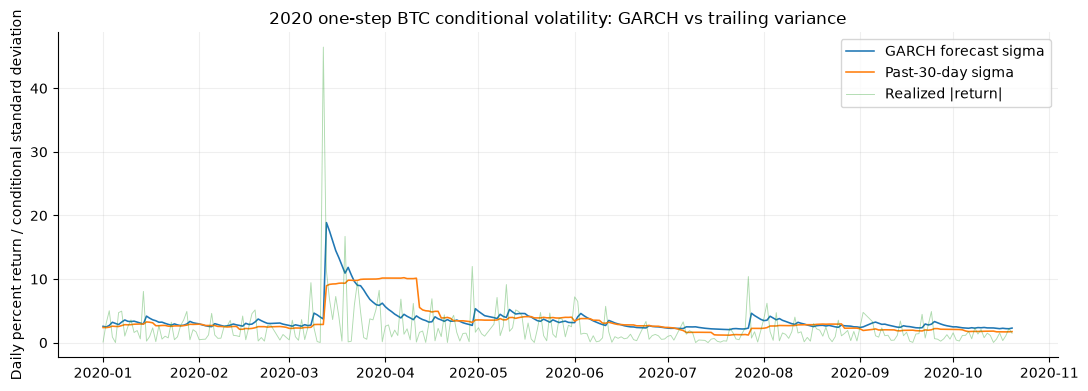

In [16]:
from scipy.optimize import minimize
from statsmodels.stats.diagnostic import het_arch

def garch_transform(theta):
    # omega>0, 0<alpha<0.5, 0<beta<1-alpha; sum is strictly <1
    z=lambda x: 1/(1+np.exp(-np.clip(x,-30,30)))
    omega=float(np.exp(theta[0]));alpha=0.5*float(z(theta[1]))
    beta=(1-alpha)*0.999*float(z(theta[2]))
    return omega,alpha,beta

def garch_variance_path(error2,omega,alpha,beta,initial_variance):
    path=np.empty(len(error2));v=max(float(initial_variance),1e-7)
    for i in range(len(error2)):
        if i: v=omega+alpha*error2[i-1]+beta*v
        path[i]=max(v,1e-9)
    return path

def fit_garch_qmle(training_pct):
    series=np.asarray(training_pct,dtype=float);mu=float(np.mean(series))
    e2=(series-mu)**2;uncond=max(float(np.var(series)),1e-6)
    def objective(theta):
        omega,alpha,beta=garch_transform(theta)
        vs=garch_variance_path(e2,omega,alpha,beta,uncond)
        return 0.5*np.mean(np.log(vs)+e2/vs)
    result=minimize(objective,np.array([np.log(uncond*0.05),-2.5,2.0]),
                    method='L-BFGS-B',bounds=[(-12,8),(-10,8),(-10,10)],
                    options={'maxiter':400,'ftol':1e-10})
    # Reject optimizer nonconvergence, but first try other valid starts. A successful
    # original optimization remains unchanged for backward numerical comparability.
    if not np.isfinite(result.fun) or not bool(result.success):
        alternatives=[]
        for _start in ([np.log(uncond*0.1),-1.,1.],
                       [np.log(uncond*0.02),-4.,3.],
                       [np.log(uncond*0.2),0.,0.]):
            _retry=minimize(objective,np.asarray(_start,dtype=float),
                method='L-BFGS-B',bounds=[(-12,8),(-10,8),(-10,10)],
                options={'maxiter':800,'ftol':1e-11})
            if _retry.success and np.isfinite(_retry.fun):
                alternatives.append(_retry)
        if alternatives:
            result=min(alternatives,key=lambda _res:float(_res.fun))
        else:
            raise RuntimeError('GARCH QMLE nonconvergence after multistart retries: '+str(result.message))
    om,al,be=garch_transform(result.x)
    return {'mu':mu,'omega':om,'alpha':al,'beta':be,'success':bool(result.success),
            'objective':float(result.fun),'initial_variance':uncond}

vol_s=(log_returns_daily['BTC'].dropna()*100).sort_index()
rv=vol_s.pow(2)
rollvar=rv.shift(1).rolling(30,min_periods=20).mean()

def garch_one_step(train_end_date,pred_start,pred_end):
    sample=vol_s.loc[vol_s.index <= train_end_date]
    params=fit_garch_qmle(sample.to_numpy())
    err2=(vol_s.to_numpy()-params['mu'])**2
    conditional=garch_variance_path(err2,params['omega'],params['alpha'],params['beta'],params['initial_variance'])
    frame=pd.DataFrame({'date':vol_s.index,'return_pct':vol_s.to_numpy(),
                        'garch_variance':conditional,'rolling30_variance':rollvar.to_numpy()})
    frame=frame.loc[frame.date.between(pred_start,pred_end)].dropna().copy()
    return frame,params

garch_2019,par_2018=garch_one_step('2018-12-31','2019-01-01','2019-12-31')
garch_2020,par_2019=garch_one_step('2019-12-31','2020-01-01','2020-10-20')

def volatility_metrics(frame,label):
    true=frame.return_pct.to_numpy()**2
    res=[]
    for model,col in [('GARCH(1,1)','garch_variance'),('Rolling 30 variance','rolling30_variance')]:
        h=np.maximum(frame[col].to_numpy(),1e-8)
        mse=np.mean((true-h)**2)
        qlike=np.mean(np.log(h)+true/h) # score difference is meaningful; absolute value is not a probability
        res.append({'split':label,'model':model,'n':len(frame),'MSE_variance':mse,'QLIKE':qlike})
    return res
vol_score=pd.DataFrame(volatility_metrics(garch_2019,'2019 validation')+
                       volatility_metrics(garch_2020,'2020 test'))
display(vol_score.round(5));vol_score.to_csv(OUT/'garch_volatility_scores.csv',index=False)
pd.DataFrame([{'fit_through':'2018-12-31',**par_2018},
              {'fit_through':'2019-12-31',**par_2019}]).to_csv(OUT/'garch_parameters.csv',index=False)
garch_2020.to_csv(OUT/'garch_2020_one_step.csv',index=False)
print('GARCH parameter fits/convergence:',par_2018['success'],par_2019['success'])
print('Train 2015-18 ARCH LM lag 10 p-value:',het_arch_compat(vol_s.loc[:'2018-12-31'],nlags=10)[1])
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(garch_2020.date,np.sqrt(garch_2020.garch_variance),label='GARCH forecast sigma',lw=1.15)
ax.plot(garch_2020.date,np.sqrt(garch_2020.rolling30_variance),label='Past-30-day sigma',lw=1.15)
ax.plot(garch_2020.date,garch_2020.return_pct.abs(),label='Realized |return|',alpha=.38,lw=.65)
ax.set(ylabel='Daily percent return / conditional standard deviation',title='2020 one-step BTC conditional volatility: GARCH vs trailing variance')
ax.legend();ax.grid(alpha=.2);savefig('11_garch_volatility_2020.png')

## 14. Does a small test-set RMSE difference matter? Paired moving-block bootstrap

Hold all 2020 forecasts fixed. Compare **per-date squared-error losses** against the unchanged-price baseline with circular moving blocks of **5, 10 and 20 equity sessions**. Report the **mean loss advantage** (baseline minus candidate, in squared USD), the 95% resampling interval, and a **HAC / Newey–West paired loss-mean t statistic** with exploratory unadjusted p-value. Neither a CI excluding 0 nor an unadjusted HAC p-value constitutes a corrected multiple-model significance test, especially with just 183 2020 observations. These are **post-hoc uncertainty diagnostics**, not used to choose a model. When the originally preselected winner *is* the baseline, their difference is identically zero.

Also break the 2020 errors into different **calendar-day horizons** (1, 2, 3, 4+ days). Short or partially observed bins should not be overinterpreted. Forecasting per observed market session is not equivalent to uniform daily BTC returns.

,model,block_sessions,n,baseline_minus_model_MSE_USD2,bootstrap_ci_low,bootstrap_ci_high,HAC_t_descriptive,HAC_p_unadjusted
0,Naive no-change,5,183,0.000,0.000,0.000,NaN,NaN
1,Naive no-change,10,183,0.000,0.000,0.000,NaN,NaN
2,Naive no-change,20,183,0.000,0.000,0.000,NaN,NaN
3,Elastic Net,5,183,492.870,-2260.107,2928.256,0.373,0.709
4,Elastic Net,10,183,492.870,-2248.182,2876.105,0.382,0.703
5,Elastic Net,20,183,492.870,-2273.867,3007.102,0.389,0.697
6,SARIMAX AR1 + S&P lag,5,183,-188.484,-2857.569,2118.973,-0.147,0.883
7,SARIMAX AR1 + S&P lag,10,183,-188.484,-2910.618,2196.379,-0.146,0.884
8,SARIMAX AR1 + S&P lag,20,183,-188.484,-3017.482,2445.223,-0.146,0.884
9,Ablation validation winner,5,183,-78.311,-3211.539,2489.787,-0.054,0.957


,n,selected_RMSE,naive_RMSE,sarimax_RMSE
horizon_label,,,,
1 day(s),144,354.45,354.45,355.48
2 day(s),1,208.13,208.13,228.71
3 day(s),33,493.96,493.96,489.91
4+ days,5,301.89,301.89,318.73


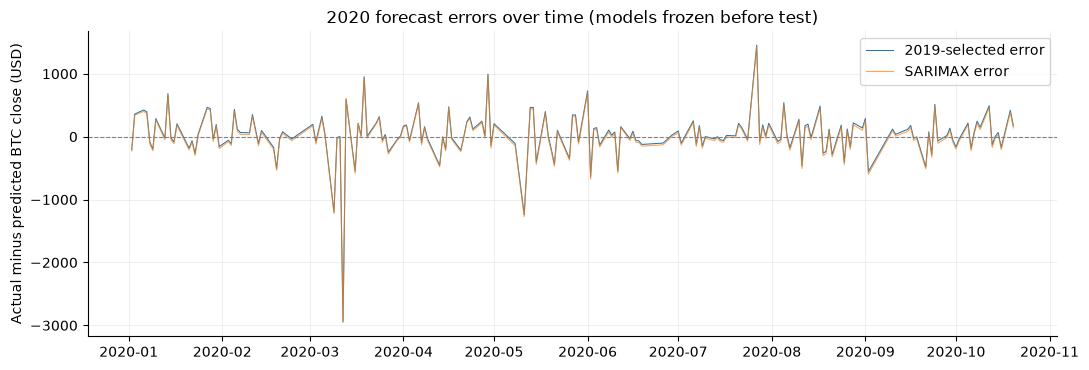

In [17]:
def circular_block_sample(n,block,rng):
    starts=rng.integers(0,n,size=int(np.ceil(n/block)))
    return np.concatenate([np.arange(s,s+block)%n for s in starts])[:n]

def moving_block_ci(loss_delta,block=10,reps=1500,seed=42):
    values=np.asarray(loss_delta,dtype=float)
    r=np.random.default_rng(seed)
    sampled=np.array([np.mean(values[circular_block_sample(len(values),block,r)]) for _ in range(reps)])
    lo,hi=np.quantile(sampled,[.025,.975])
    return float(lo),float(hi)

naive_sq=(test.BTC.to_numpy()-predicted_prices['Naive no-change'])**2
candidate_sq={label:(test.BTC.to_numpy()-values)**2 for label,values in predicted_prices.items()}
candidate_sq['SARIMAX AR1 + S&P lag']=(test.BTC.to_numpy()-test.previous_BTC.to_numpy()*np.exp(sarimax_test_r))**2
candidate_sq['Ablation validation winner']=(test.BTC.to_numpy()-test.previous_BTC.to_numpy()*
                                           np.exp(ablation_frozen[selected_ablation_name]))**2
loss_results=[]
for name in [selected_model,'Elastic Net','SARIMAX AR1 + S&P lag','Ablation validation winner']:
    if name not in candidate_sq: continue
    delta=naive_sq-candidate_sq[name]
    for block in (5,10,20):
        lo,hi=moving_block_ci(delta,block=block,seed=SEED+block)
        # DM-like paired loss-mean statistic with HAC/Newey-West long-run variance.
        # Descriptive asymptotic approximation; intervals and p-values are unadjusted for multiple tests.
        z=delta-delta.mean();nn=len(z)
        long_var=float(np.dot(z,z)/nn)
        for lag in range(1,min(block,nn-1)+1):
            autocov=float(np.dot(z[lag:],z[:-lag])/nn)
            long_var+=2*(1-lag/(block+1))*autocov
        hac_se=np.sqrt(max(long_var,0)/nn)
        hac_t=float(np.mean(delta)/hac_se) if hac_se>0 else np.nan
        from scipy.stats import norm
        hac_p=float(2*norm.sf(abs(hac_t))) if np.isfinite(hac_t) else np.nan
        loss_results.append({'model':name,'block_sessions':block,'n':nn,
                             'baseline_minus_model_MSE_USD2':np.mean(delta),
                             'bootstrap_ci_low':lo,'bootstrap_ci_high':hi,
                             'HAC_t_descriptive':hac_t,'HAC_p_unadjusted':hac_p})
loss_table=pd.DataFrame(loss_results).drop_duplicates(['model','block_sessions'])
display(loss_table.round(3))
loss_table.to_csv(OUT/'holdout_loss_block_bootstrap.csv',index=False)

horizon=test[['date','horizon_days','BTC','previous_BTC']].copy()
horizon['horizon_label']=np.where(horizon.horizon_days>=4,'4+ days',horizon.horizon_days.astype(int).astype(str)+' day(s)')
horizon['selected_error']=test.BTC.to_numpy()-predicted_prices[selected_model]
horizon['naive_error']=test.BTC.to_numpy()-predicted_prices['Naive no-change']
horizon['sarimax_error']=test.BTC.to_numpy()-test.previous_BTC.to_numpy()*np.exp(sarimax_test_r)
horizon_summary=horizon.groupby('horizon_label',sort=True).agg(
    n=('date','count'), selected_RMSE=('selected_error',lambda x:np.sqrt(np.mean(x**2))),
    naive_RMSE=('naive_error',lambda x:np.sqrt(np.mean(x**2))),
    sarimax_RMSE=('sarimax_error',lambda x:np.sqrt(np.mean(x**2))))
display(horizon_summary.round(2))
horizon_summary.to_csv(OUT/'holdout_by_calendar_horizon.csv')
plt.figure(figsize=(11,3.8))
plt.plot(test.date,horizon['selected_error'].to_numpy(),label='2019-selected error',lw=.75)
plt.plot(test.date,horizon['sarimax_error'].to_numpy(),label='SARIMAX error',alpha=.7,lw=.8)
plt.axhline(0,color='gray',ls='--',lw=.8);plt.ylabel('Actual minus predicted BTC close (USD)')
plt.title('2020 forecast errors over time (models frozen before test)');plt.legend();plt.grid(alpha=.2)
savefig('12_holdout_forecast_errors.png')

## 15. Market regime correlation stability and weekend effects: dependence-aware checks

Revisit BTC–S&P 500 same-date returns separately in **2017, 2018, 2019 and the partial 2020 window**. The paired moving-block bootstrap preserves short-run serial dependence within each regime. The reported **2020 − 2019 difference** is descriptive and **cannot establish a COVID causal effect**. These data close at different times and 2020 ends Oct 20.  

For the weekend/weekday difference in absolute BTC returns, report a **7-day circular block bootstrap** CI that resamples both weekend labels and realized returns together. A simple Mann–Whitney p-value above ignored dependence; these bootstrap CIs are sensitivity checks, not definitive causality or trading evidence.

,year,paired_observations,corr,ci_low,ci_high
0,2017,251,0.0671,-0.0397,0.1645
1,2018,251,0.0768,-0.1194,0.2743
2,2019,252,-0.1094,-0.2803,0.0620
3,2020,195,0.4820,0.1804,0.6062


2020 minus 2019 correlation: 0.591 95% block CI: [0.235 0.804]
Weekend minus weekday mean |BTC daily log return|: -0.00582 | 95% 7-day block CI [-0.00823 -0.00334]


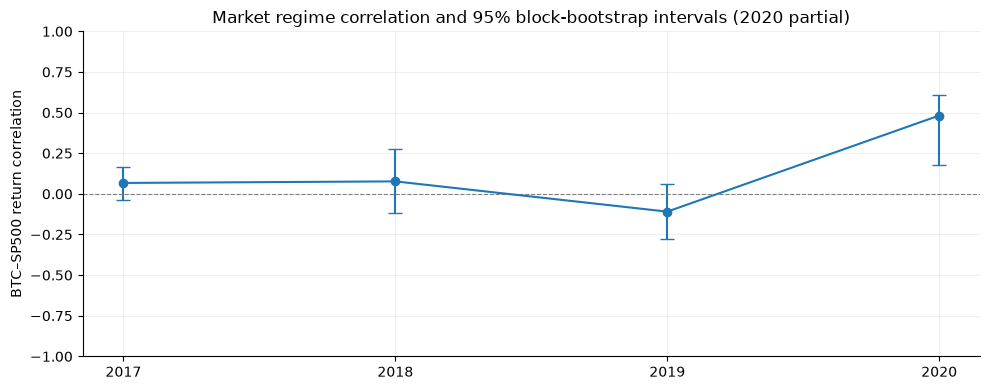

In [18]:
def block_pair_bootstrap_correlation(frame,block=10,reps=1600,seed=123):
    arr=frame[['SP500_return','BTC_return']].dropna().to_numpy()
    n=len(arr);r=np.random.default_rng(seed)
    if n<40:return np.nan,np.nan,np.nan
    draws=np.empty(reps)
    for i in range(reps):
        z=arr[circular_block_sample(n,block,r)]
        draws[i]=np.corrcoef(z[:,0],z[:,1])[0,1]
    return float(np.corrcoef(arr[:,0],arr[:,1])[0,1]),*map(float,np.quantile(draws,[.025,.975]))

regime_ci=[]
for yr in [2017,2018,2019,2020]:
    dat=aligned.loc[aligned.date.dt.year.eq(yr), ['SP500_return','BTC_return']].dropna()
    corr,lo,hi=block_pair_bootstrap_correlation(dat,block=10,seed=SEED+yr)
    regime_ci.append({'year':yr,'paired_observations':len(dat),'corr':corr,'ci_low':lo,'ci_high':hi})
regime_ci_table=pd.DataFrame(regime_ci)
display(regime_ci_table.round(4))
regime_ci_table.to_csv(OUT/'market_regime_block_CI.csv',index=False)

r19=aligned.loc[aligned.date.dt.year.eq(2019),['SP500_return','BTC_return']].dropna().to_numpy()
r20=aligned.loc[aligned.date.dt.year.eq(2020),['SP500_return','BTC_return']].dropna().to_numpy()
rng_regime=np.random.default_rng(SEED)
diff_boot=[]
for _ in range(1500):
    s19=r19[circular_block_sample(len(r19),10,rng_regime)]
    s20=r20[circular_block_sample(len(r20),10,rng_regime)]
    diff_boot.append(np.corrcoef(s20.T)[0,1]-np.corrcoef(s19.T)[0,1])
regime_diff=float(np.corrcoef(r20.T)[0,1]-np.corrcoef(r19.T)[0,1])
ci_diff=np.quantile(diff_boot,[.025,.975])
print('2020 minus 2019 correlation:',round(regime_diff,3),'95% block CI:',np.round(ci_diff,3))
pd.DataFrame([{'difference_2020_minus_2019':regime_diff,'ci_low':ci_diff[0],
               'ci_high':ci_diff[1],'block_sessions':10,'bootstrap_reps':1500}]).to_csv(
                OUT/'market_regime_2020_vs_2019_CI.csv',index=False)

week=b[['date','weekend','abs_return']].dropna().copy()
week_arr=week[['weekend','abs_return']].to_numpy()
week_diff=week.loc[week.weekend,'abs_return'].mean()-week.loc[~week.weekend,'abs_return'].mean()
week_boot=[];rng_week=np.random.default_rng(SEED)
for _ in range(1600):
    z=week_arr[circular_block_sample(len(week_arr),7,rng_week)]
    w=z[:,0].astype(bool)
    week_boot.append(z[w,1].mean()-z[~w,1].mean())
week_ci=np.quantile(week_boot,[.025,.975])
print('Weekend minus weekday mean |BTC daily log return|:',round(week_diff,5),
      '| 95% 7-day block CI',np.round(week_ci,5))
pd.DataFrame([{'weekend_minus_weekday_mean_abs_log_return':week_diff,
               'ci_low':week_ci[0],'ci_high':week_ci[1],
               'block_days':7,'bootstrap_reps':1600}]).to_csv(OUT/'weekend_effect_block_CI.csv',index=False)
plt.figure(figsize=(10,4))
plt.errorbar(regime_ci_table.year,regime_ci_table['corr'],
  yerr=[regime_ci_table['corr']-regime_ci_table['ci_low'],regime_ci_table['ci_high']-regime_ci_table['corr']],
  fmt='o-',capsize=5)
plt.axhline(0,color='gray',lw=.8,ls='--');plt.ylim(-1,1)
plt.xticks([2017,2018,2019,2020]);plt.grid(alpha=.2);plt.ylabel('BTC–SP500 return correlation')
plt.title('Market regime correlation and 95% block-bootstrap intervals (2020 partial)')
savefig('13_market_regime_correlation_CIs.png')

## 16. Phase 1 — Missing-data impact and fair prediction coverage

**Research question:** How much of the 2020 U.S. equity-market calendar can our forecasting pipeline genuinely cover? The full seven-feature model uses a **common complete-case sample**. Missing Bitcoin observations can propagate through multi-day momentum and volatility features, causing otherwise observable target days to be excluded. We report *why* each day is missing, without imputing target prices or cherry-picking a favorable sample. A reduced BTC-only model can use additional dates but its scores are **not directly comparable across unequal samples**; the common-date comparison is the fair primary result.

**Historical evaluation status:** The 2020 data have already been inspected during notebook development; these extended checks are exploratory sensitivity analyses, **not a new untouched holdout**. Future externally sourced data would be required for fully fresh validation.

2020 equity sessions: 203 | complete-case rows: 183 | excluded: 20


,excluded_reason,number_of_sessions
0,BTC target missing,4
1,included,183
2,lagged predictor(s) unavailable,12
3,previous BTC missing,4


2019-selected reduced-feature ridge alpha: 100


,sample,n,Naive_RMSE_USD,BTC_only_RMSE_USD
0,Common seven-feature complete-case,183,381.561,NaN
1,Reduced BTC-only eligible dates,187,378.330,378.713
2,Extra reduced-only 2020 dates,4,NaN,NaN


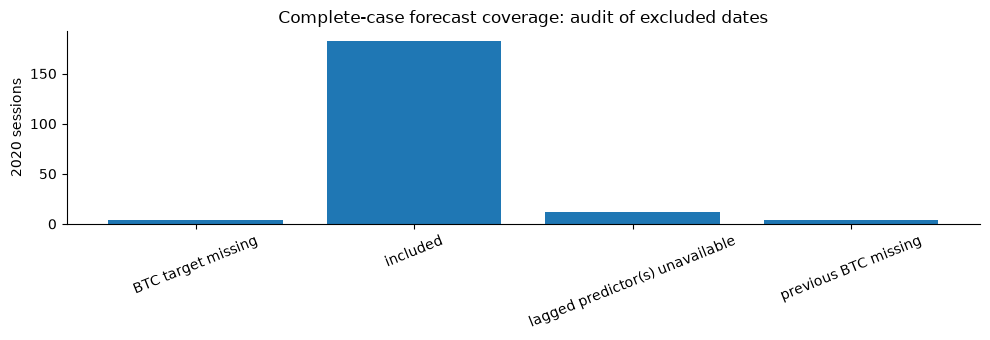

In [19]:
# Keep all sessions for audit; create one explicit exclusion reason per date.
required_target = ['BTC','previous_BTC','target_return']
full_required = required_target + features
coverage = f[['date','BTC','previous_BTC','target_return','horizon_days']+features].copy()
coverage['target_observable'] = coverage[required_target].notna().all(axis=1)
coverage['all_features_observable'] = coverage[features].notna().all(axis=1)
coverage['included_full'] = coverage[full_required].notna().all(axis=1)
coverage['excluded_reason'] = np.select(
    [coverage['BTC'].isna(),coverage['previous_BTC'].isna(),
     coverage['target_return'].isna(),~coverage['all_features_observable']],
    ['BTC target missing','previous BTC missing','return invalid',
     'lagged predictor(s) unavailable'],default='included')
coverage['missing_predictors'] = coverage[features].isna().apply(
    lambda row: ', '.join(row.index[row].tolist()),axis=1)
coverage_2020 = coverage.loc[coverage.date.gt(VALID_END)&coverage.date.le(END)].copy()
coverage_summary = (coverage_2020.groupby('excluded_reason').size()
                    .rename('number_of_sessions').reset_index())
print('2020 equity sessions:',len(coverage_2020),
      '| complete-case rows:',int(coverage_2020.included_full.sum()),
      '| excluded:',int((~coverage_2020.included_full).sum()))
display(coverage_summary)
coverage_2020.to_csv(OUT/'phase1_2020_session_exclusion_audit.csv',index=False)
coverage_summary.to_csv(OUT/'phase1_exclusion_reason_summary.csv',index=False)

# Independent reduced-feature AR proxy. Gap handling follows the original equity-session target;
# a gap-containing return and its shifted successors can be unavailable.
btc_cols = ['BTC_return_lag1','BTC_return_lag2']
reduced = f.dropna(subset=required_target+btc_cols).copy()
reduced_train = reduced.loc[reduced.date.le(TRAIN_END)]
reduced_valid = reduced.loc[reduced.date.gt(TRAIN_END)&reduced.date.le(VALID_END)]
reduced_test  = reduced.loc[reduced.date.gt(VALID_END)&reduced.date.le(END)]
reduced_alpha_candidates = [0.01,0.1,1,10,100]
red_candidates = []
for a in reduced_alpha_candidates:
    fit_red = make_pipeline(StandardScaler(),Ridge(alpha=a)).fit(
        reduced_train[btc_cols],reduced_train.target_return)
    red_candidates.append((evaluate(reduced_valid,fit_red.predict(reduced_valid[btc_cols]),
                                    'BTC-only Ridge','2019 validation')['RMSE_USD'],a))
red_alpha = min(red_candidates)[1]
red_model = make_pipeline(StandardScaler(),Ridge(alpha=red_alpha)).fit(
    pd.concat([reduced_train,reduced_valid])[btc_cols],
    pd.concat([reduced_train,reduced_valid]).target_return)
red_test_pred = red_model.predict(reduced_test[btc_cols])
red_score = evaluate(reduced_test,red_test_pred,'BTC-only Ridge (additional days)','2020 diagnostic')
red_naive = evaluate(reduced_test,np.zeros(len(reduced_test)),
                     'No-change (same additional days)','2020 diagnostic')
red_dates = set(reduced_test.date); full_dates = set(test.date)
coverage_compare = pd.DataFrame([
    {'sample':'Common seven-feature complete-case','n':len(test),
     'Naive_RMSE_USD':baseline_rmse,'BTC_only_RMSE_USD':np.nan},
    {'sample':'Reduced BTC-only eligible dates','n':len(reduced_test),
     'Naive_RMSE_USD':red_naive['RMSE_USD'],'BTC_only_RMSE_USD':red_score['RMSE_USD']},
    {'sample':'Extra reduced-only 2020 dates','n':len(red_dates-full_dates),
     'Naive_RMSE_USD':np.nan,'BTC_only_RMSE_USD':np.nan}])
print('2019-selected reduced-feature ridge alpha:',red_alpha)
display(coverage_compare.round(3))
coverage_compare.to_csv(OUT/'phase1_prediction_coverage_sensitivity.csv',index=False)
pd.DataFrame({'extra_available_date':sorted(red_dates-full_dates)}).to_csv(
    OUT/'phase1_reduced_only_available_dates.csv',index=False)

fig,ax=plt.subplots(figsize=(10,3.5))
ax.bar(coverage_summary.excluded_reason,coverage_summary.number_of_sessions)
ax.set(ylabel='2020 sessions',title='Complete-case forecast coverage: audit of excluded dates')
ax.tick_params(axis='x',rotation=22)
savefig('14_missingness_2020_audit.png')

## 17. Phase 1 — Fixed 24-hour BTC forecasting versus equity-session forecasting

The main experiment predicts **next observed S&P session** BTC close, where the calendar horizon varies (weekends / holidays). This additional **separate experiment** predicts the next consecutive **24-hour UTC crypto close** using only lagged BTC calendar-day returns. A historical-mean baseline and a simple autoregressive Ridge benchmark are selected using 2019 only and refit on training+validation for 2020. **Do not compare their RMSE directly to the equity-session models:** the targets, dates and horizons differ.

In [20]:
all_days = crypto[['date','BTC']].copy().sort_values('date')
all_days['gap'] = all_days.date.diff().dt.days
all_days['daily_return'] = np.log(all_days.BTC/all_days.BTC.shift(1)).where(all_days.gap.eq(1))
all_days['daily_lag1'] = all_days.daily_return.shift(1)
all_days['daily_lag2'] = all_days.daily_return.shift(2)
all_days['prev_close'] = all_days.BTC.shift(1)
cal = all_days.dropna(subset=['BTC','prev_close','daily_return','daily_lag1','daily_lag2']).copy()
cal_tr=cal.loc[cal.date.le(TRAIN_END)]
cal_va=cal.loc[cal.date.gt(TRAIN_END)&cal.date.le(VALID_END)]
cal_te=cal.loc[cal.date.gt(VALID_END)&cal.date.le(END)]
cal_cols=['daily_lag1','daily_lag2']
def score_calendar(df,r,label,split):
    p=df.prev_close.to_numpy()*np.exp(np.asarray(r,dtype=float))
    return {'model':label,'split':split,'n':len(df),
            'RMSE_USD':np.sqrt(np.mean((df.BTC.to_numpy()-p)**2)),
            'MAE_USD':np.mean(np.abs(df.BTC.to_numpy()-p)),
            'return_RMSE':np.sqrt(np.mean((df.daily_return.to_numpy()-np.asarray(r))**2))}
mean_train=cal_tr.daily_return.mean()
daily_candidates={
 'Naive 24h':np.zeros(len(cal_va)),
 'Historical mean 24h':np.repeat(mean_train,len(cal_va)),
 'BTC AR(2) Ridge 24h':make_pipeline(StandardScaler(),Ridge(alpha=10)).fit(
     cal_tr[cal_cols],cal_tr.daily_return).predict(cal_va[cal_cols])}
cal_valid=pd.DataFrame([score_calendar(cal_va,r,name,'2019 validation')
                        for name,r in daily_candidates.items()]).sort_values('RMSE_USD')
chosen_daily=cal_valid.model.iloc[0]
cal_tv=pd.concat([cal_tr,cal_va])
cal_models={
 'Naive 24h':np.zeros(len(cal_te)),
 'Historical mean 24h':np.repeat(cal_tv.daily_return.mean(),len(cal_te)),
 'BTC AR(2) Ridge 24h':make_pipeline(StandardScaler(),Ridge(alpha=10)).fit(
     cal_tv[cal_cols],cal_tv.daily_return).predict(cal_te[cal_cols])}
cal_test=pd.DataFrame([score_calendar(cal_te,r,name,'2020 retrospective')
                       for name,r in cal_models.items()])
cal_test['preselected_2019']=cal_test.model.eq(chosen_daily)
print('Calendar-daily valid/test samples:',len(cal_va),len(cal_te),'| 2019-selected:',chosen_daily)
display(cal_valid.round(5));display(cal_test.round(5))
cal_valid.to_csv(OUT/'phase1_fixed24h_validation.csv',index=False)
cal_test.to_csv(OUT/'phase1_fixed24h_test.csv',index=False)

Calendar-daily valid/test samples: 361 274 | 2019-selected: Naive 24h


,model,split,n,RMSE_USD,MAE_USD,return_RMSE
0,Naive 24h,2019 validation,361,317.75209,189.84543,0.03550
1,Historical mean 24h,2019 validation,361,318.20744,190.31242,0.03546
2,BTC AR(2) Ridge 24h,2019 validation,361,318.70201,190.45135,0.03549


,model,split,n,RMSE_USD,MAE_USD,return_RMSE,preselected_2019
0,Naive 24h,2020 retrospective,274,312.02935,190.67391,0.04162,True
1,Historical mean 24h,2020 retrospective,274,311.63477,189.78269,0.04156,False
2,BTC AR(2) Ridge 24h,2020 retrospective,274,311.68438,189.93331,0.04157,False


## 18. Phase 2 — New price-forecast benchmarks: historical drift and BTC-only AR(1)

Expand the existing comparison by adding a **training-period historical mean** return, a **calendar-day-normalized historical drift** (per forecast horizon), and a pure **BTC-only AR(1)** model. AR(1) uses the **same market-session target and same complete-case dates** as SARIMAX(1,0,0) with lagged S&P, making the value of an exogenous S&P series easier to assess. One-step filtering conditions on previously realized returns; this is an *online rolling one-step score*, not a static 2020 multi-step forecast. New choices are ranked by 2019 validation, with 2020 results reported as retrospective diagnostics.

In [21]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

def ar1_btc_only(fit_frame,pred_frame):
    yt=fit_frame.target_return.to_numpy()*100
    model=SARIMAX(yt,order=(1,0,0),trend='c',enforce_stationarity=True)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        fitted=model.fit(disp=False,maxiter=200)
    whole=np.r_[yt,pred_frame.target_return.to_numpy()*100]
    fil=SARIMAX(whole,order=(1,0,0),trend='c',enforce_stationarity=True).filter(fitted.params)
    pred=np.asarray(fil.get_prediction(start=len(yt),end=len(whole)-1).predicted_mean)/100
    return pred,fitted

ar_valid,ar_fit_train=ar1_btc_only(train,valid)
ar_test,ar_fit_tv=ar1_btc_only(train_valid,test)
mean_r_train=train.target_return.mean()
mean_r_tv=train_valid.target_return.mean()
per_day_tr=(train.target_return/train.horizon_days).mean()
per_day_tv=(train_valid.target_return/train_valid.horizon_days).mean()
new_valid_preds={
 'Historical mean return':np.full(len(valid),mean_r_train),
 'Calendar-normalized drift':per_day_tr*valid.horizon_days.to_numpy(),
 'BTC-only AR(1)':ar_valid,
 'SARIMAX AR1 + S&P lag':sarimax_valid_r,
 'Naive no-change':np.zeros(len(valid))}
new_test_preds={
 'Historical mean return':np.full(len(test),mean_r_tv),
 'Calendar-normalized drift':per_day_tv*test.horizon_days.to_numpy(),
 'BTC-only AR(1)':ar_test,
 'SARIMAX AR1 + S&P lag':sarimax_test_r,
 'Naive no-change':np.zeros(len(test))}
new_validation=pd.DataFrame([evaluate(valid,r,name,'2019 validation')
                             for name,r in new_valid_preds.items()]).sort_values('RMSE_USD')
selected_new=new_validation.iloc[0].model
new_test=pd.DataFrame([evaluate(test,r,name,'2020 retrospective')
                      for name,r in new_test_preds.items()])
new_test['selected_2019']=new_test.model.eq(selected_new)
print('2019 winner among additional statistical baselines:',selected_new)
display(new_validation[['model','n','RMSE_USD','return_RMSE']].round(5))
display(new_test[['model','n','RMSE_USD','return_RMSE','selected_2019']].round(5))
new_validation.to_csv(OUT/'phase2_new_statistical_benchmarks_validation.csv',index=False)
new_test.to_csv(OUT/'phase2_new_statistical_benchmarks_2020.csv',index=False)
# AR(1) innovations; exploratory Ljung–Box on first 2019 training fit only.
train_ar_residual=np.asarray(ar_fit_train.resid,dtype=float)
fit_diag=pd.DataFrame([{'model':'BTC-only AR(1)','n':len(train_ar_residual),
                       'LB_return_lag10_p':acorr_ljungbox(train_ar_residual,lags=[10],return_df=True)['lb_pvalue'].iloc[0],
                       'LB_squared_lag10_p':acorr_ljungbox(train_ar_residual**2,lags=[10],return_df=True)['lb_pvalue'].iloc[0]},
                      {'model':'SARIMAX AR1 + S&P lag','n':len(sarimax_train_fit.resid),
                       'LB_return_lag10_p':acorr_ljungbox(sarimax_train_fit.resid,lags=[10],return_df=True)['lb_pvalue'].iloc[0],
                       'LB_squared_lag10_p':acorr_ljungbox(np.asarray(sarimax_train_fit.resid)**2,lags=[10],return_df=True)['lb_pvalue'].iloc[0]}])
display(fit_diag.round(5));fit_diag.to_csv(OUT/'phase2_AR_SARIMAX_residual_diagnostics.csv',index=False)

2019 winner among additional statistical baselines: Calendar-normalized drift


,model,n,RMSE_USD,return_RMSE
1,Calendar-normalized drift,252,394.37382,0.04286
4,Naive no-change,252,394.75576,0.04307
0,Historical mean return,252,395.50821,0.04299
2,BTC-only AR(1),252,395.89216,0.04300
3,SARIMAX AR1 + S&P lag,252,396.04153,0.04300


,model,n,RMSE_USD,return_RMSE,selected_2019
0,Historical mean return,183,380.91436,0.05028,False
1,Calendar-normalized drift,183,380.63407,0.05032,True
2,BTC-only AR(1),183,381.45845,0.05037,False
3,SARIMAX AR1 + S&P lag,183,381.80767,0.05045,False
4,Naive no-change,183,381.56076,0.05038,False


,model,n,LB_return_lag10_p,LB_squared_lag10_p
0,BTC-only AR(1),789,0.64751,0.0
1,SARIMAX AR1 + S&P lag,789,0.64915,0.0


## 19. Phase 2 — EWMA and heavy-tailed Student-t GARCH (volatility, not price)

This is a **separate variance prediction task** on consecutive observed daily Bitcoin log returns (expressed as percent points). Compare past-30 variance, Gaussian GARCH(1,1), **EWMA with 2019-selected decay**, and **variance-normalized Student-t GARCH(1,1)**. Fit parameters on 2015–18 for validation, then on 2015–19 for the 2020 retrospective assessment. Score with **QLIKE** and MSE versus squared returns as a noisy volatility proxy. Distributional comparison uses Student-t standardized innovations, not fabricated observed latent variance. One-step filtering updates from yesterday's *observed* return, not tomorrow's.

GARCH variance forecasts apply over consecutive **available** return observations; after source gaps the first available observation is treated as the next conditional update. This approximation is disclosed and should not be interpreted as a constant-gap trading model.

EWMA 2019 chosen lambda: 0.985
Student-t GARCH convergence: True True


,split,model,n,QLIKE,variance_MSE
0,2019 validation,Trailing-30,363,3.9451,1015.0107
1,2019 validation,Gaussian GARCH,363,3.5815,994.6768
2,2019 validation,Student-t GARCH,363,3.8240,991.1368
3,2019 validation,EWMA,363,3.5339,1000.6378
4,2020 retrospective,Trailing-30,284,4.2021,17366.6269
5,2020 retrospective,Gaussian GARCH,284,3.6854,17638.5437
6,2020 retrospective,Student-t GARCH,284,3.8327,17508.5968
7,2020 retrospective,EWMA,284,4.1550,16940.4888


,model,n,LB_std_resid_lag10_p,LB_std_sq_lag10_p,ARCH_LM_lag10_p
0,Gaussian GARCH,1168,0.00169,0.23543,0.24150
1,Student-t GARCH,1168,0.00040,0.20778,0.21139


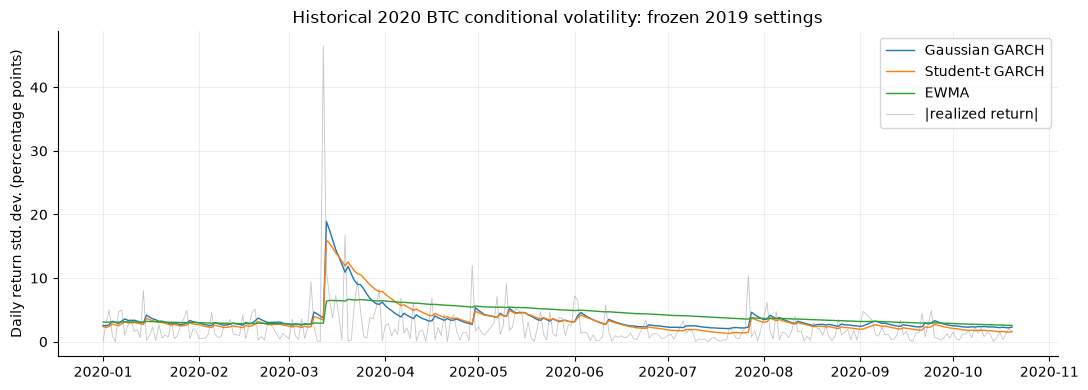

In [22]:
from scipy.special import gammaln
from scipy.optimize import minimize
from statsmodels.stats.diagnostic import het_arch

def ewma_path(returns_pct,decay,init_variance):
    data=np.asarray(returns_pct,dtype=float)
    result=np.empty(len(data));var=max(float(init_variance),1e-8)
    for i,ret in enumerate(data):
        if i:var=decay*var+(1-decay)*data[i-1]**2
        result[i]=max(var,1e-8)
    return result

def fit_student_t_garch(returns_pct):
    x=np.asarray(returns_pct,dtype=float)
    mu=float(x.mean());e2=(x-mu)**2
    uncond=max(float(np.var(x)),1e-6)
    # Standardized Student-t density: conditional variance h, degrees of freedom nu>2.
    def ll(theta):
        om,a,bb=garch_transform(theta[:3]);nu=2+np.exp(theta[3])
        h=garch_variance_path(e2,om,a,bb,uncond)
        c=(gammaln((nu+1)/2)-gammaln(nu/2)
           -0.5*np.log((nu-2)*np.pi))
        return -float(np.mean(c-.5*np.log(h)-.5*(nu+1)*np.log1p(e2/((nu-2)*h))))
    starts=[np.array([np.log(uncond*0.05),-2.5,2.,np.log(6.)]),
            np.array([np.log(uncond*0.1),-1.5,3.,np.log(10.)])]
    fits=[minimize(ll,st,method='L-BFGS-B',
                   bounds=[(-12,8),(-10,8),(-10,10),(np.log(.5),np.log(75))],
                   options={'maxiter':175,'ftol':1e-8}) for st in starts]
    fits=[res for res in fits if np.isfinite(res.fun)]
    if not fits:raise RuntimeError('Student-t GARCH optimization failed')
    best=min(fits,key=lambda res:res.fun)
    om,a,bb=garch_transform(best.x[:3]);nu=2+float(np.exp(best.x[3]))
    return dict(mu=mu,omega=om,alpha=a,beta=bb,nu=nu,
                objective=float(best.fun),success=bool(best.success),initial_variance=uncond)

def t_volatility_frame(params,start_date,end_date):
    err=(vol_s.to_numpy()-params['mu'])**2
    cond=garch_variance_path(err,params['omega'],params['alpha'],params['beta'],params['initial_variance'])
    frame=pd.DataFrame({'date':vol_s.index,'realized_return_pct':vol_s.to_numpy(),
                        'student_t_garch_variance':cond})
    return frame.loc[frame.date.between(start_date,end_date)].copy()

def ewma_volatility_frame(lam,initvar,start_date,end_date):
    path=ewma_path(vol_s.to_numpy(),lam,initvar)
    return pd.DataFrame({'date':vol_s.index,'ewma_variance':path}).loc[
        lambda df:df.date.between(start_date,end_date)]

def qlike_score(variance,return_pct):
    h=np.maximum(np.asarray(variance,dtype=float),1e-9)
    return np.mean(np.log(h)+(np.asarray(return_pct)**2)/h)

student_2018=fit_student_t_garch(vol_s.loc[:'2018-12-31'].to_numpy())
student_2019=fit_student_t_garch(vol_s.loc[:'2019-12-31'].to_numpy())
student_2019_frame=t_volatility_frame(student_2018,'2019-01-01','2019-12-31')
student_2020_frame=t_volatility_frame(student_2019,'2020-01-01','2020-10-20')
# Decay selected using 2019 only (the same training initialization across candidates).
lambda_grid=[.90,.94,.97,.985]
initial_2018=float(np.var(vol_s.loc[:'2018-12-31']))
volscore_2019=[]
for lam in lambda_grid:
    fr=ewma_volatility_frame(lam,initial_2018,'2019-01-01','2019-12-31')
    volscore_2019.append({'decay':lam,'n':len(fr),'QLIKE':qlike_score(fr.ewma_variance,fr.date.map(vol_s.to_dict()))})
ewma_val_grid=pd.DataFrame(volscore_2019).sort_values('QLIKE')
selected_lambda=float(ewma_val_grid.iloc[0].decay)
vol2019=ewma_volatility_frame(selected_lambda,initial_2018,'2019-01-01','2019-12-31')
vol2020=ewma_volatility_frame(selected_lambda,float(np.var(vol_s.loc[:'2019-12-31'])),
                             '2020-01-01','2020-10-20')
vol2019=vol2019.merge(student_2019_frame[['date','student_t_garch_variance']],on='date')
vol2020=vol2020.merge(student_2020_frame[['date','student_t_garch_variance']],on='date')
for frame in (vol2019,vol2020):
    frame['return_pct']=frame.date.map(vol_s.to_dict())
    frame['realized_variance_proxy']=frame.return_pct**2

def compare_variance(frame,split):
    ga=(garch_2019 if split.startswith('2019') else garch_2020)[['date','garch_variance','rolling30_variance']]
    common=frame.merge(ga,on='date',validate='one_to_one').dropna()
    records=[]
    for model,col in [('Trailing-30','rolling30_variance'),('Gaussian GARCH','garch_variance'),
                      ('Student-t GARCH','student_t_garch_variance'),('EWMA','ewma_variance')]:
        yy=common.realized_variance_proxy.to_numpy();h=common[col].to_numpy()
        records.append({'split':split,'model':model,'n':len(common),'QLIKE':qlike_score(h,np.sqrt(yy)),
                        'variance_MSE':np.mean((yy-h)**2)})
    return records,common
rec19,vol2019_common=compare_variance(vol2019,'2019 validation')
rec20,vol2020_common=compare_variance(vol2020,'2020 retrospective')
var_scores=pd.DataFrame(rec19+rec20)
print('EWMA 2019 chosen lambda:',selected_lambda)
print('Student-t GARCH convergence:',student_2018['success'],student_2019['success'])
display(var_scores.round(4))
var_scores.to_csv(OUT/'phase2_volatility_model_comparison.csv',index=False)
ewma_val_grid.to_csv(OUT/'phase2_ewma_2019_decay_selection.csv',index=False)
pd.DataFrame([{'fit_through':'2018','model':'Student-t GARCH',**student_2018},
              {'fit_through':'2019','model':'Student-t GARCH',**student_2019}]).to_csv(
                OUT/'phase2_student_t_garch_parameters.csv',index=False)
vol2020_common.to_csv(OUT/'phase2_2020_four_volatility_predictions.csv',index=False)

# Pre-2020 residual diagnostics: no model choice based on 2020.
sqt=[]
train_vol=vol_s.loc[:'2018-12-31'].to_numpy()
for name,par in [('Gaussian GARCH',par_2018),('Student-t GARCH',student_2018)]:
    h=garch_variance_path((train_vol-par['mu'])**2,par['omega'],par['alpha'],par['beta'],par['initial_variance'])
    standardized=(train_vol-par['mu'])/np.sqrt(h)
    sqt.append({'model':name,'n':len(standardized),'LB_std_resid_lag10_p':
                acorr_ljungbox(standardized,lags=[10],return_df=True).lb_pvalue.iloc[0],
                'LB_std_sq_lag10_p':acorr_ljungbox(standardized**2,lags=[10],return_df=True).lb_pvalue.iloc[0],
                'ARCH_LM_lag10_p':het_arch_compat(standardized,nlags=10)[1]})
residual_vol_diagnostics=pd.DataFrame(sqt)
display(residual_vol_diagnostics.round(5))
residual_vol_diagnostics.to_csv(OUT/'phase2_GARCH_residual_diagnostics_train.csv',index=False)

fig,ax=plt.subplots(figsize=(11,4))
for name,col in [('Gaussian GARCH','garch_variance'),('Student-t GARCH','student_t_garch_variance'),
                 ('EWMA','ewma_variance')]:
    ax.plot(vol2020_common.date,np.sqrt(vol2020_common[col]),label=name,lw=1)
ax.plot(vol2020_common.date,vol2020_common.return_pct.abs(),color='grey',lw=.6,alpha=.45,label='|realized return|')
ax.set(ylabel='Daily return std. dev. (percentage points)',
       title='Historical 2020 BTC conditional volatility: frozen 2019 settings')
ax.legend();ax.grid(alpha=.2);savefig('15_volatility_three_models_2020.png')

## 20. Phase 3 — Time-aware feature importance and incremental S&P information

A random permutation of individual dates destroys temporal structure. We therefore add a **permutation of contiguous feature blocks** (preserving within-block autocorrelation) and **drop-column retraining**, both only on training/2019 validation. For the S&P contribution, compare the same Ridge family and rows with **B (BTC technical predictors)** versus **C (BTC plus S&P)**. Negative importance means a particular method does not show a stable positive contribution; it is not a claim of negative causality.

In [23]:
def permute_contiguous_blocks(values,block,rng):
    v=np.asarray(values)
    chunks=[v[i:i+block] for i in range(0,len(v),block)]
    perm=rng.permutation(len(chunks))
    return np.concatenate([chunks[i] for i in perm])[:len(v)]

block_import=[];block_rng=np.random.default_rng(SEED)
for col in chosen_cols:
    increase=[]
    for _ in range(120):
        scrambled=valid[chosen_cols].copy()
        scrambled[col]=permute_contiguous_blocks(scrambled[col].to_numpy(),10,block_rng)
        metric=evaluate(valid,ablation_model.predict(scrambled),'blocked','validation')['RMSE_USD']
        increase.append(metric-base_val_rmse)
    block_import.append({'feature':col,'block_len':10,'mean_RMSE_increase_USD':np.mean(increase),
                         'q025':np.quantile(increase,.025),'q975':np.quantile(increase,.975)})
blocked_imp=pd.DataFrame(block_import)
# Fixed hyperparameters on the validation study. Drop-column: refit on same train rows.
drop_import=[]
for col in chosen_cols:
    retained=[x for x in chosen_cols if x!=col]
    retrain=make_pipeline(StandardScaler(),Ridge(alpha=selected_ablation_alpha)).fit(
        train[retained],train.target_return)
    drop_metric=evaluate(valid,retrain.predict(valid[retained]),'drop','validation')['RMSE_USD']
    drop_import.append({'feature':col,'RMSE_change_when_dropped_USD':drop_metric-base_val_rmse})
drop_imp=pd.DataFrame(drop_import)
feature_import_robust=blocked_imp.merge(drop_imp,on='feature')
display(feature_import_robust.round(4))
feature_import_robust.to_csv(OUT/'phase3_block_permutation_vs_drop_column.csv',index=False)

bc=ablation_val.loc[ablation_val.model.isin(['B: BTC features','C: BTC + lagged S&P'])].groupby('model',as_index=False).first()
inc_B=float(bc.loc[bc.model.eq('B: BTC features'),'RMSE_USD'].iloc[0])
inc_C=float(bc.loc[bc.model.eq('C: BTC + lagged S&P'),'RMSE_USD'].iloc[0])
inc=pd.DataFrame([{'split':'2019 validation, identical sample','BTC_feature_set_B_RMSE':inc_B,
                    'BTC_plus_S&P_C_RMSE':inc_C,'S&P_incremental_gain_USD':inc_B-inc_C,
                    'note':'Positive means S&P inclusion reduced RMSE; parameters separately tuned on validation'}])
display(inc.round(4));inc.to_csv(OUT/'phase3_SP500_incremental_value_validation.csv',index=False)

,feature,block_len,mean_RMSE_increase_USD,q025,q975,RMSE_change_when_dropped_USD
0,BTC_return_lag1,10,-0.3894,-1.1853,0.6086,-0.5323
1,BTC_return_lag2,10,-0.1787,-0.6081,0.1938,-0.1428


,split,BTC_feature_set_B_RMSE,BTC_plus_S&P_C_RMSE,S&P_incremental_gain_USD,note
0,"2019 validation, identical sample",398.0368,398.1543,-0.1175,Positive means S&P inclusion reduced RMSE; par...


## 21. Phase 3 — Crash-exclusion, robust correlation and weekend stability

Recalculate the already-reported 2019/2020 contemporaneous **association** after excluding March 2020, and after excluding 2020 extreme Bitcoin market-session moves (largest 5% of absolute BTC return). This is a robustness exercise, **not** evidence about the cause of the 2020 relationship. Exclusions are defined for transparency and do not refit forecast models. Then compare yearly weekend/weekday absolute crypto-day returns and a pooled 1%-trimmed sensitivity. All comparisons remain descriptive and dataset-dependent.

,sample,n,return_corr,CI_low,CI_high
0,2019 full,252,-0.1094,-0.2730,0.0683
1,2020 through Oct 20,195,0.4820,0.1860,0.6025
2,2020 excluding March,173,0.2735,0.1267,0.4200
3,2020 excluding top 5% abs BTC returns,185,0.2217,0.1101,0.3504
4,2020 excluding March AND top 5%,168,0.2265,0.0808,0.3866


,year,weekend_n,weekday_n,weekend_minus_weekday_abs_ret
0,2015,20,52,-0.00178
1,2016,105,261,-0.00030
2,2017,105,260,-0.00812
3,2018,104,261,-0.01026
4,2019,102,261,-0.00426
5,2020,82,202,-0.00724
6,All years trimmed at 99th percentile,518,1278,-0.00353


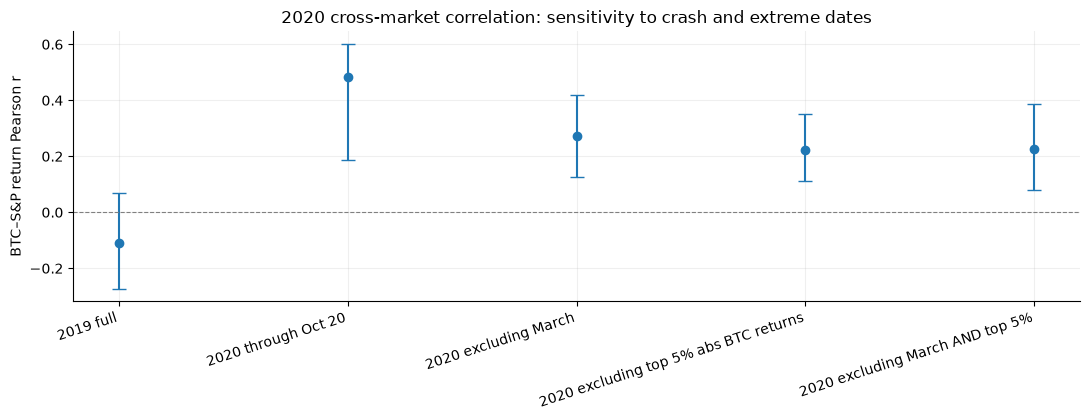

In [24]:
relevant=aligned.loc[aligned.date.dt.year.ge(2019),['date','SP500_return','BTC_return']].dropna().copy()
r19df=relevant.loc[relevant.date.dt.year.eq(2019)]
r20df=relevant.loc[relevant.date.dt.year.eq(2020)]
threshold_2020=float(r20df.BTC_return.abs().quantile(.95))
regime_versions={
 '2019 full':r19df,
 '2020 through Oct 20':r20df,
 '2020 excluding March':r20df.loc[r20df.date.dt.month.ne(3)],
 '2020 excluding top 5% abs BTC returns':r20df.loc[r20df.BTC_return.abs().le(threshold_2020)],
 '2020 excluding March AND top 5%':r20df.loc[(r20df.date.dt.month.ne(3)) &
                                                  (r20df.BTC_return.abs().le(threshold_2020))]}
regime_sensitivity=[]
for i,(name,sub) in enumerate(regime_versions.items()):
    correlation,lo,hi=block_pair_bootstrap_correlation(sub,block=10,reps=1200,seed=SEED+i)
    regime_sensitivity.append({'sample':name,'n':len(sub),'return_corr':correlation,
                               'CI_low':lo,'CI_high':hi})
regime_sensitivity_table=pd.DataFrame(regime_sensitivity)
display(regime_sensitivity_table.round(4))
regime_sensitivity_table.to_csv(OUT/'phase3_crash_exclusion_correlation.csv',index=False)

per_year=[]
week_sensitivity=b[['date','weekend','abs_return']].dropna().copy()
for yr,sub in week_sensitivity.groupby(week_sensitivity.date.dt.year):
    weekend=sub.loc[sub.weekend,'abs_return'];weekday=sub.loc[~sub.weekend,'abs_return']
    if len(weekend)<15 or len(weekday)<15:continue
    per_year.append({'year':yr,'weekend_n':len(weekend),'weekday_n':len(weekday),
                     'weekend_minus_weekday_abs_ret':weekend.mean()-weekday.mean()})
trim=week_sensitivity.loc[week_sensitivity.abs_return.le(week_sensitivity.abs_return.quantile(.99))]
per_year.append({'year':'All years trimmed at 99th percentile',
                 'weekend_n':sum(trim.weekend),'weekday_n':sum(~trim.weekend),
                 'weekend_minus_weekday_abs_ret':trim.loc[trim.weekend,'abs_return'].mean()-
                                                 trim.loc[~trim.weekend,'abs_return'].mean()})
week_year_table=pd.DataFrame(per_year)
display(week_year_table.round(5));week_year_table.to_csv(OUT/'phase3_weekend_effect_by_year.csv',index=False)

fig,ax=plt.subplots(figsize=(11,4.3))
r=regime_sensitivity_table
ax.errorbar(np.arange(len(r)),r.return_corr,
            yerr=np.vstack([r.return_corr-r.CI_low,r.CI_high-r.return_corr]),fmt='o',capsize=5)
ax.axhline(0,color='grey',lw=.8,ls='--');ax.set_xticks(np.arange(len(r)),r['sample'],rotation=18,ha='right')
ax.set(ylabel='BTC–S&P return Pearson r',title='2020 cross-market correlation: sensitivity to crash and extreme dates')
ax.grid(alpha=.2);savefig('16_2020_correlation_crash_exclusion.png')

# Comprehensive research expansion — existing studies — statistical diagnostics, tail risk, cross-asset dependence and robust model checks

The next chapters extend the four-phase edition while preserving every original code analysis. **Added statistical hypotheses are exploratory.** Even though the 2019 period is used to set hyperparameters, it has also been reused many times during iterative research; 2020 has been previously inspected. This is a reproducible historical comparison, **not a fresh confirmatory out-of-sample study**. Further model families must not be interpreted as evidence that more models automatically create information.

## 23. Source integrity, cleaning assumptions and package fingerprints

**Research question.** Are the OHLCV observations internally plausible, and can another analyst identify the exact inputs? Every statistic in this section comes from the two uploaded Kaggle files. Suspect records are counted, not silently repaired; data anomalies do not prove that a provider made an error. SHA-256 fingerprints help detect changed local copies. The market and crypto closes are not simultaneous; no trades are simulated.

In [25]:
import hashlib, platform, importlib.metadata
source_checks=[]
for file in ['dataset.csv','SPX_500_Data.csv']:
    p=DATA/file
    source_checks.append({'file':file,'bytes':p.stat().st_size,
                          'sha256':hashlib.sha256(p.read_bytes()).hexdigest()})
checks=pd.DataFrame(source_checks)
raw_btc=rows.loc[rows.asset.eq('BTC')].copy()
quality=pd.DataFrame([{'asset':'BTC','rows':len(raw_btc),
 'nonpositive_close':int((raw_btc['close']<=0).sum()),
 'negative_volume':int((raw_btc['volume']<0).sum()),
 'low_above_high':int((raw_btc['low']>raw_btc['high']).sum()),
 'close_outside_daily_range':int(((raw_btc['close']<raw_btc['low'])|(raw_btc['close']>raw_btc['high'])).sum()),
 'open_outside_daily_range':int(((raw_btc['open']<raw_btc['low'])|(raw_btc['open']>raw_btc['high'])).sum())}])
pkgs=['pandas','numpy','scipy','statsmodels','scikit-learn','xgboost','matplotlib','nbformat']
software=pd.DataFrame({'package':pkgs,'version':[importlib.metadata.version(x) for x in pkgs]})
checks.to_csv(OUT/'extra_source_SHA256.csv',index=False)
quality.to_csv(OUT/'extra_OHLC_integrity.csv',index=False)
software.to_csv(OUT/'extra_package_versions.csv',index=False)
display(checks,quality,software)

,file,bytes,sha256
0,dataset.csv,9590008,9495893c031e1badd6cd680b31658fb4a1c7bd38a9e061...
1,SPX_500_Data.csv,1328464,06e5c3768e8c4ff50be8f8641ef9cba03da61a4ffe00a7...


,asset,rows,nonpositive_close,negative_volume,low_above_high,close_outside_daily_range,open_outside_daily_range
0,BTC,1822,0,0,0,0,0


,package,version
0,pandas,2.3.3
1,numpy,2.5.4
2,scipy,1.18.1
3,statsmodels,0.15.0
4,scikit-learn,1.9.1
5,xgboost,3.4.1
6,matplotlib,3.11.2
7,nbformat,5.11.1


## 24. Return distributions, non-normality and historical tail risk

Measure **skewness, excess kurtosis, Jarque–Bera, 1%/5% loss quantiles and conditional expected shortfall** for consecutive daily crypto returns. Empirical risk estimates are historical; they are not calibrated real-time forecasts. Avoid assuming Gaussian tails or a normal standard error under volatility clustering. Quantile estimates in tiny samples are inherently unstable.

,asset,n,mean_daily_pct,std_daily_pct,skew,excess_kurtosis,JB_p,historical_VaR_95_loss_pct,historical_CVaR_95_loss_pct,historical_VaR_99_loss_pct,historical_CVaR_99_loss_pct
0,BTC,1815,0.21580,3.96963,-0.91030,14.01705,0.0,6.20108,9.65591,11.12686,15.74253
1,ETH,1815,0.38453,6.00693,-0.17229,7.68302,0.0,8.23630,13.59419,16.27432,22.64799
2,LTC,1815,0.16876,5.50595,0.81285,13.30139,0.0,7.96740,11.81767,13.86398,19.32738
3,XRP,1815,0.22846,6.64260,2.97373,46.29097,0.0,7.34881,12.65747,14.22498,22.77225


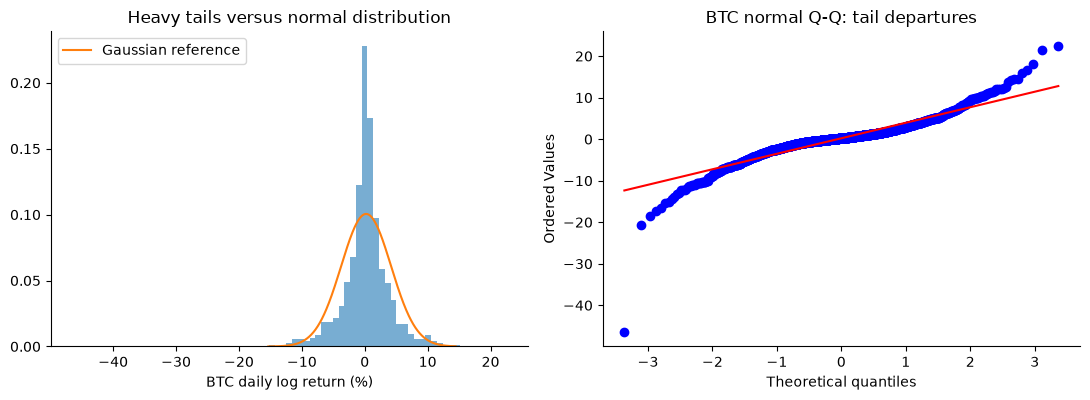

In [26]:
from scipy import stats
risk_rows=[]
for asset in coins:
    ret=log_returns_daily[asset].dropna()
    q01,q05=ret.quantile([.01,.05])
    risk_rows.append({'asset':asset,'n':len(ret),'mean_daily_pct':100*ret.mean(),
      'std_daily_pct':100*ret.std(),'skew':ret.skew(),'excess_kurtosis':ret.kurt(),
      'JB_p':stats.jarque_bera(ret).pvalue,
      'historical_VaR_95_loss_pct':-100*q05,'historical_CVaR_95_loss_pct':-100*ret[ret<=q05].mean(),
      'historical_VaR_99_loss_pct':-100*q01,'historical_CVaR_99_loss_pct':-100*ret[ret<=q01].mean()})
tail_table=pd.DataFrame(risk_rows);display(tail_table.round(5))
tail_table.to_csv(OUT/'extra_crypto_tail_risk.csv',index=False)
btc_ret=log_returns_daily.BTC.dropna()
fig,axs=plt.subplots(1,2,figsize=(11,4.1))
axs[0].hist(100*btc_ret,bins=75,density=True,alpha=.6)
mu,sigma=stats.norm.fit(100*btc_ret)
x=np.linspace(np.quantile(100*btc_ret,.003),np.quantile(100*btc_ret,.997),350)
axs[0].plot(x,stats.norm.pdf(x,mu,sigma),label='Gaussian reference')
axs[0].set(xlabel='BTC daily log return (%)',title='Heavy tails versus normal distribution');axs[0].legend()
stats.probplot(100*btc_ret,dist='norm',plot=axs[1]);axs[1].set_title('BTC normal Q-Q: tail departures')
savefig('17_btc_tail_distribution.png')

## 25. Volatility clustering, dependence and nonlinear serial structure

Check **Ljung–Box on returns and squared returns**, **ARCH-LM**, and ACF of absolute returns for each crypto asset. These are diagnostics, not evidence that any single model will forecast volatility better. Gaps in original crypto calendar remain excluded rather than treating missing multi-day returns as one-day returns.

,asset,n,LB_ret_10_p,LB_squared_10_p,ARCH_LM_10_p,abs_ret_autocorr_1
0,BTC,1815,0.088713,0.0,0.0,0.228244
1,ETH,1815,0.309895,0.0,0.0,0.247909
2,LTC,1815,0.012522,0.0,0.0,0.232462
3,XRP,1815,0.000000,0.0,0.0,0.387478


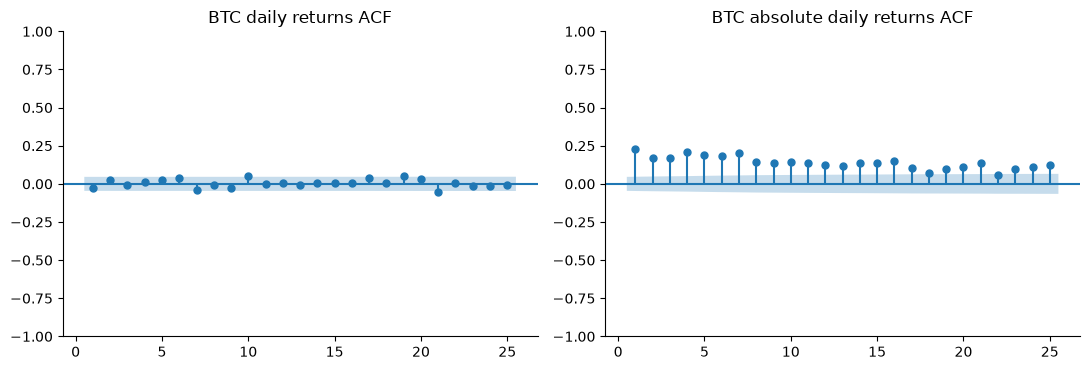

In [27]:
from statsmodels.stats.diagnostic import het_arch
from statsmodels.graphics.tsaplots import plot_acf
serial=[]
for asset in coins:
    x=(log_returns_daily[asset].dropna()*100).to_numpy()
    serial.append({'asset':asset,'n':len(x),
        'LB_ret_10_p':acorr_ljungbox(x,lags=[10],return_df=True).lb_pvalue.iloc[0],
        'LB_squared_10_p':acorr_ljungbox(x**2,lags=[10],return_df=True).lb_pvalue.iloc[0],
        'ARCH_LM_10_p':het_arch_compat(x,nlags=10)[1],
        'abs_ret_autocorr_1':pd.Series(np.abs(x)).autocorr(1)})
serial_table=pd.DataFrame(serial);display(serial_table.round(6))
serial_table.to_csv(OUT/'extra_serial_and_ARCH_diagnostics.csv',index=False)
fig,axs=plt.subplots(1,2,figsize=(11,3.8))
plot_acf(btc_ret,ax=axs[0],lags=25,zero=False,title='BTC daily returns ACF')
plot_acf(btc_ret.abs(),ax=axs[1],lags=25,zero=False,title='BTC absolute daily returns ACF')
savefig('18_return_absreturn_ACF.png')

## 26. Drawdown episodes, duration and underwater time

Max drawdown alone misses how **long losses persisted**. Count observed calendar days underwater, longest observed underwater episode and completed peak-to-recovery episodes. Omitted days can affect dates; price returns ignore dividends, staking, fees, and other investable return differences.

In [28]:
underwater_rows=[]
for asset in coins:
    s=prices[asset].dropna()
    dd=s/s.cummax()-1
    underwater=dd.lt(0)
    runs=underwater.ne(underwater.shift()).cumsum()
    depths=dd[dd.lt(0)]
    lengths=[len(grp) for _,grp in underwater.groupby(runs) if grp.iloc[0]]
    underwater_rows.append({'asset':asset,'observed_n':len(s),
      'underwater_fraction':float(underwater.mean()),'worst_drawdown_pct':float(100*dd.min()),
      'longest_underwater_observed_days':max(lengths) if lengths else 0,
      'underwater_episode_count':int(len(lengths)),'recovered_episode_count':int(((~underwater)&underwater.shift(1,fill_value=False)).sum())})
underwater_table=pd.DataFrame(underwater_rows)
display(underwater_table.round(4))
underwater_table.to_csv(OUT/'extra_underwater_risk.csv',index=False)

,asset,observed_n,underwater_fraction,worst_drawdown_pct,longest_underwater_observed_days,underwater_episode_count,recovered_episode_count
0,BTC,1822,0.9314,-83.3990,1033,45,44
1,ETH,1822,0.9517,-93.9625,1005,35,34
2,LTC,1822,0.9698,-93.4519,1031,28,27
3,XRP,1822,0.9769,-95.8661,1011,18,17


## 27. Crypto diversification, PCA and correlation concentration

Use **training-period-only PCA** and measure diversification with the **mean of six pairwise return correlations**, updated over trailing 90 **consecutive crypto calendar** observations. This is a descriptive diagnostic, not a claim that equal-weight portfolios hedge Bitcoin tail losses. PCA loadings are fitted before 2019 to avoid retrospectively estimating components from the evaluation period.

,principal_component,explained_variance_share
0,PC1,0.5542
1,PC2,0.1895
2,PC3,0.1593
3,PC4,0.0969


principal_component,PC1,PC2,PC3,PC4
BTC,0.546,-0.297,-0.372,-0.690
ETH,0.474,-0.266,0.839,0.038
LTC,0.556,-0.150,-0.394,0.717
XRP,0.410,0.905,0.059,-0.097


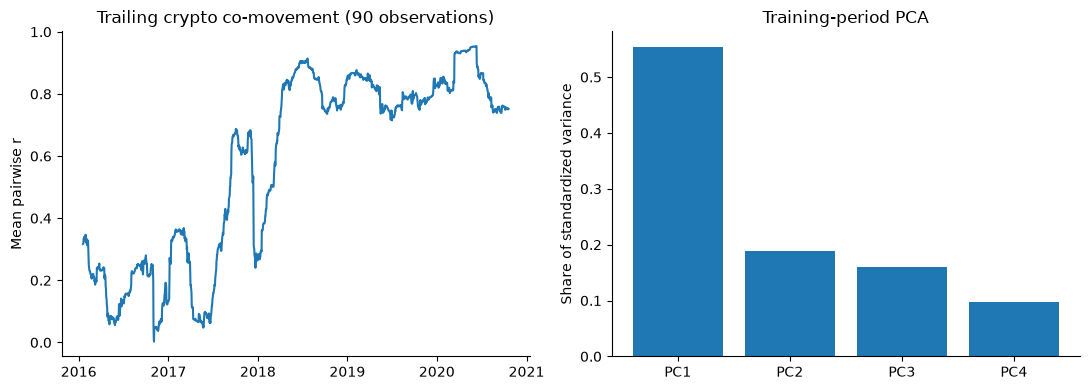

In [29]:
from sklearn.decomposition import PCA
pair_names=[('BTC','ETH'),('BTC','LTC'),('BTC','XRP'),('ETH','LTC'),('ETH','XRP'),('LTC','XRP')]
mean_pair_corr=[]
for end_idx in range(90,len(log_returns_daily)):
    period=log_returns_daily.iloc[end_idx-90:end_idx].dropna()
    if len(period)<75:continue
    matrix=period.corr()
    mean_pair_corr.append({'date':log_returns_daily.index[end_idx],
        'mean_pairwise_r':np.mean([matrix.loc[a,b] for a,b in pair_names]),
        'BTC_ETH':matrix.loc['BTC','ETH']})
rolling_diversification=pd.DataFrame(mean_pair_corr)
pca_train=log_returns_daily.loc[log_returns_daily.index.year<=2018].dropna()
pca_scaler=StandardScaler().fit(pca_train)
pca=PCA(n_components=4).fit(pca_scaler.transform(pca_train))
pca_table=pd.DataFrame({'principal_component':[f'PC{i+1}' for i in range(4)],
         'explained_variance_share':pca.explained_variance_ratio_})
pca_loadings=pd.DataFrame(pca.components_.T,index=coins,columns=pca_table.principal_component)
display(pca_table.round(4),pca_loadings.round(3))
pca_table.to_csv(OUT/'extra_PCA_training_variance.csv',index=False)
pca_loadings.to_csv(OUT/'extra_PCA_training_loadings.csv')
rolling_diversification.to_csv(OUT/'extra_rolling_crypto_diversification.csv',index=False)
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].plot(rolling_diversification.date,rolling_diversification.mean_pairwise_r)
axs[0].set(ylabel='Mean pairwise r',title='Trailing crypto co-movement (90 observations)')
axs[1].bar(pca_table.principal_component,pca_table.explained_variance_share)
axs[1].set(ylabel='Share of standardized variance',title='Training-period PCA')
savefig('19_crypto_correlation_PCA.png')

## 28. Predefined daily calendar effects with multiplicity control

Evaluate the seven **day-of-week** BTC absolute-return distributions using Kruskal–Wallis, and compare individual weekdays to the remainder with **Holm-adjusted** exploratory p-values. Calendar patterns are descriptive, dependent through time, and not an investment strategy. Weekend findings were already evaluated with block bootstrap above; these tests provide a complementary, less dependence-robust view.

In [30]:
from statsmodels.stats.multitest import multipletests
weekdays=b[['date','abs_return']].dropna().copy()
weekdays['weekday']=weekdays.date.dt.day_name()
weekday_order=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
samples=[weekdays.loc[weekdays.weekday.eq(d),'abs_return'].to_numpy() for d in weekday_order]
kw=stats.kruskal(*samples)
cal_effect=[]
for wd in weekday_order:
    in_group=weekdays.loc[weekdays.weekday.eq(wd),'abs_return']
    other=weekdays.loc[~weekdays.weekday.eq(wd),'abs_return']
    cal_effect.append({'weekday':wd,'n':len(in_group),'mean_abs_return':in_group.mean(),
        'difference_from_others':in_group.mean()-other.mean(),
        'MW_raw_p':stats.mannwhitneyu(in_group,other,alternative='two-sided').pvalue})
cal_effect=pd.DataFrame(cal_effect)
cal_effect['Holm_adjusted_p']=multipletests(cal_effect.MW_raw_p,method='holm')[1]
print('Kruskal–Wallis global raw p:',kw.pvalue,'(serial dependence caveat)')
display(cal_effect.round(6))
cal_effect.to_csv(OUT/'extra_weekday_effect_holm.csv',index=False)

Kruskal–Wallis global raw p: 0.0017340709245151093 (serial dependence caveat)


,weekday,n,mean_abs_return,difference_from_others,MW_raw_p,Holm_adjusted_p
0,Monday,259,0.027279,0.002310,0.027710,0.138551
1,Tuesday,258,0.026400,0.001284,0.270443,0.811330
2,Wednesday,260,0.025423,0.000145,0.688621,1.000000
3,Thursday,260,0.031009,0.006665,0.035850,0.143400
4,Friday,260,0.024677,-0.000725,0.544570,1.000000
5,Saturday,259,0.021374,-0.004578,0.004040,0.028279
6,Sunday,259,0.020911,-0.005118,0.020172,0.121030


## 29. BTC–S&P 500 lead/lag association and exploratory Granger tests

Estimate session-lag cross-correlations and **training-only** Granger non-causality tests (lags 1–5), correcting ten directional tests with Holm. These lag tests do **not** imply economic causality: S&P closes earlier than end-of-day UTC crypto closes, observation gaps occur, and omitted common drivers may explain apparent predictability. Test returns, never trending price levels.

**Timing audit:** Cross-correlations shift across the original US equity trading-session calendar before removing missing-value pairs; Granger uses observed pairs and is exploratory, not causal evidence.


Equity-calendar lead/lag correlations


,SP500_session_lag,n,BTC_SP500_return_r
0,-5,1246,0.0376
1,-4,1247,0.0300
2,-3,1248,0.0049
3,-2,1249,0.1339
4,-1,1250,-0.0833
5,0,1251,0.1597
6,1,1250,-0.0360
7,2,1249,0.0225
8,3,1248,-0.0029
9,4,1247,-0.0010


Exploratory training-only nested Granger-style F tests


,dependent,additional_lagged_variable,lag,n,F_statistic,raw_F_test_p,Holm_adjusted_p,significant_5pct
0,BTC_return,SP500_return,1,803,0.21038,0.64660,1.0000,False
1,BTC_return,SP500_return,2,802,0.55242,0.57578,1.0000,False
2,BTC_return,SP500_return,3,801,0.52379,0.66603,1.0000,False
3,BTC_return,SP500_return,4,800,0.43416,0.78400,1.0000,False
4,BTC_return,SP500_return,5,799,0.52733,0.75570,1.0000,False
5,SP500_return,BTC_return,1,803,2.80570,0.09432,0.9432,False
6,SP500_return,BTC_return,2,802,1.48529,0.22706,1.0000,False
7,SP500_return,BTC_return,3,801,1.67300,0.17133,1.0000,False
8,SP500_return,BTC_return,4,800,1.29862,0.26893,1.0000,False
9,SP500_return,BTC_return,5,799,1.05868,0.38201,1.0000,False


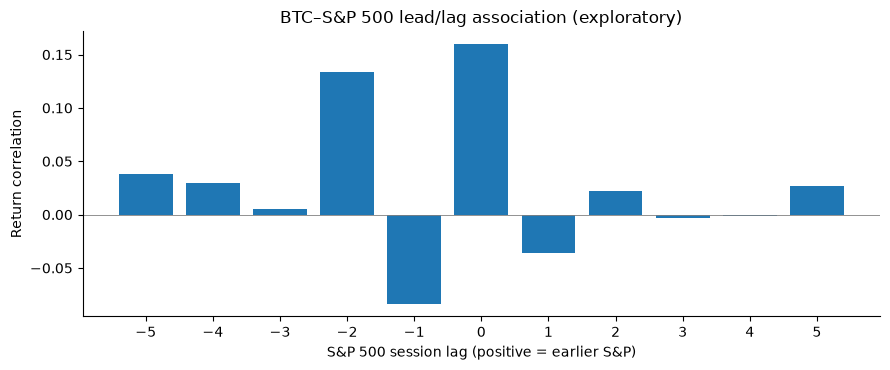

In [31]:
import warnings
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

# Shift first along ALL US market sessions; pairwise omission comes afterward.
ll=aligned[['date','BTC_return','SP500_return']].sort_values('date').reset_index(drop=True).copy()
lagrows=[]
for lag in range(-5,6):
    shifted=ll.SP500_return.shift(lag)
    pair_mask=ll.BTC_return.notna() & shifted.notna()
    lagrows.append({'SP500_session_lag':lag,'n':int(pair_mask.sum()),
       'BTC_SP500_return_r':ll.loc[pair_mask,'BTC_return'].corr(shifted.loc[pair_mask])})
lag_table=pd.DataFrame(lagrows)
lag_table.to_csv(OUT/'extra_cross_market_lead_lag.csv',index=False)

# Nested Granger-type regressions use complete lag windows on full market-session index.
# Crucially, missing BTC rows are NEVER compressed into artificial adjacent sessions.
training_pairs=ll.loc[ll.date.le(TRAIN_END)].copy().reset_index(drop=True)
granger=[]
for dependent,predictor in [('BTC_return','SP500_return'),('SP500_return','BTC_return')]:
    for k in range(1,6):
        regressors=training_pairs[['date',dependent]].rename(columns={dependent:'y'}).copy()
        own=[f'own_lag{j}' for j in range(1,k+1)]
        other=[f'other_lag{j}' for j in range(1,k+1)]
        for j in range(1,k+1):
            regressors[own[j-1]]=training_pairs[dependent].shift(j)
            regressors[other[j-1]]=training_pairs[predictor].shift(j)
        regressors=regressors.dropna(subset=['y']+own+other)
        restricted=sm.OLS(regressors.y,sm.add_constant(regressors[own])).fit()
        unrestricted=sm.OLS(regressors.y,sm.add_constant(regressors[own+other])).fit()
        F,pval,dfdiff=unrestricted.compare_f_test(restricted)
        granger.append({'dependent':dependent,'additional_lagged_variable':predictor,
          'lag':k,'n':len(regressors),'F_statistic':float(F),'raw_F_test_p':float(pval)})
granger_table=pd.DataFrame(granger)
granger_table['Holm_adjusted_p']=multipletests(granger_table.raw_F_test_p,method='holm')[1]
granger_table['significant_5pct']=granger_table.Holm_adjusted_p.lt(.05)
granger_table.to_csv(OUT/'extra_training_Granger_Holm.csv',index=False)
print('Equity-calendar lead/lag correlations');display(lag_table.round(4))
print('Exploratory training-only nested Granger-style F tests');display(granger_table.round(5))
fig,ax=plt.subplots(figsize=(9,3.8))
ax.bar(lag_table.SP500_session_lag,lag_table.BTC_SP500_return_r)
ax.axhline(0,color='grey',lw=.6)
ax.set(xlabel='S&P 500 session lag (positive = earlier S&P)',ylabel='Return correlation',
 title='BTC–S&P 500 lead/lag association (exploratory)')
ax.set_xticks(range(-5,6));savefig('20_cross_market_lead_lag.png')


## 30. Structural stability: return mean, scale and market beta

Estimate **HAC-robust historical BTC return beta to S&P** in 2016–18, 2019 and partial 2020. Test mean parameter stability via CUSUM on the **training portion** and descriptive Brown–Forsythe variance differences by pre-specified calendar periods. These tests do not timestamp or establish causes of breaks; unequal sample lengths affect power.

Train-period CUSUM p: 0.002524 | 2018/2019/2020 Brown–Forsythe p (descriptive): 0.027011


,period,n,BTC_SP500_return_beta,beta_HAC_CI_low,beta_HAC_CI_high,mean_BTC_return,BTC_return_std
0,2016–18,754,0.27691,-0.30966,0.86349,0.00287,0.04740
1,2019,252,-0.59887,-1.58713,0.38939,0.00259,0.04307
2,2020 partial,195,0.98662,0.33945,1.63380,0.00321,0.04935


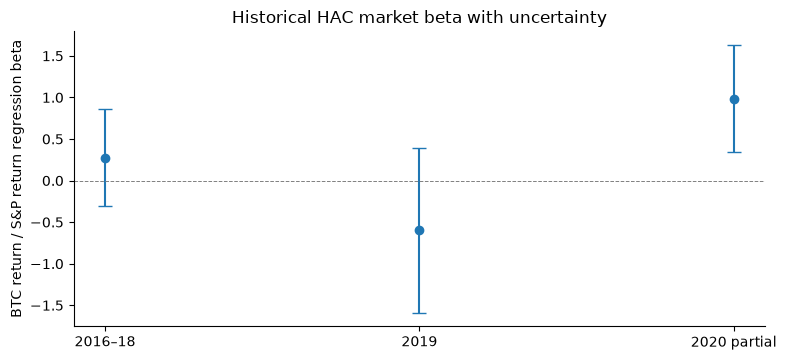

In [32]:
from statsmodels.stats.diagnostic import breaks_cusumolsresid
break_table=[]
ll_clean=ll.dropna(subset=['BTC_return','SP500_return']).copy()
for name,mask in [('2016–18',ll_clean.date.between('2016-01-01','2018-12-31')),
                  ('2019',ll_clean.date.dt.year.eq(2019)),
                  ('2020 partial',ll_clean.date.dt.year.eq(2020))]:
    sub=ll_clean.loc[mask]
    res=sm.OLS(sub.BTC_return,sm.add_constant(sub.SP500_return)).fit(cov_type='HAC',cov_kwds={'maxlags':5})
    break_table.append({'period':name,'n':len(sub),'BTC_SP500_return_beta':res.params.iloc[1],
       'beta_HAC_CI_low':res.conf_int().iloc[1,0],'beta_HAC_CI_high':res.conf_int().iloc[1,1],
       'mean_BTC_return':sub.BTC_return.mean(),'BTC_return_std':sub.BTC_return.std()})
break_table=pd.DataFrame(break_table)
pre2019=ll_clean.loc[ll_clean.date.le(TRAIN_END)]
fit_stab=sm.OLS(pre2019.BTC_return,sm.add_constant(pre2019.SP500_return)).fit()
cusum_stat,cusum_p,_=breaks_cusumolsresid(fit_stab.resid,ddof=2)
scale_groups=[ll_clean.loc[ll_clean.date.dt.year.eq(y),'BTC_return'] for y in [2018,2019,2020]]
scale_p=stats.levene(*scale_groups,center='median').pvalue
print('Train-period CUSUM p:',round(float(cusum_p),6),'| 2018/2019/2020 Brown–Forsythe p (descriptive):',round(float(scale_p),6))
display(break_table.round(5));break_table.to_csv(OUT/'extra_HAC_market_betas.csv',index=False)
pd.DataFrame([{'CUSUM_train_p':cusum_p,'Brown_Forsythe_2018_to_2020_raw_p':scale_p}]).to_csv(OUT/'extra_structural_stability_tests.csv',index=False)
fig,ax=plt.subplots(figsize=(8,3.7))
ax.errorbar(break_table.period,break_table.BTC_SP500_return_beta,
    yerr=[break_table.BTC_SP500_return_beta-break_table.beta_HAC_CI_low,
          break_table.beta_HAC_CI_high-break_table.BTC_SP500_return_beta],fmt='o',capsize=5)
ax.axhline(0,color='gray',ls='--',lw=.7)
ax.set(ylabel='BTC return / S&P return regression beta',title='Historical HAC market beta with uncertainty')
savefig('21_market_beta_stability.png')

## 31. Cross-market downside co-exceedance and stress regimes

Calibrate **5th-percentile return thresholds on 2015–18 only**; count BTC downside events, S&P downside events, and their co-occurrence in 2019 / 2020. Compare with independence expected co-occurrence using Fisher's exact contingency test. The question is **co-movement in tails**, not predictability or tradability; thresholds remain frozen and same-day close timing limits interpretation.

In [33]:
from scipy.stats import fisher_exact
stress_train=ll.loc[ll.date.le(TRAIN_END)]
btc_cut=stress_train.BTC_return.quantile(.05)
sp_cut=stress_train.SP500_return.quantile(.05)
stress=[]
for label,dates in [('2019',ll.date.dt.year.eq(2019)),('2020 partial',ll.date.dt.year.eq(2020))]:
    ss=ll.loc[dates].copy()
    a=ss.BTC_return.le(btc_cut); d=ss.SP500_return.le(sp_cut)
    both=int((a&d).sum())
    tab=np.array([[both,int((~a&d).sum())],[int((a&~d).sum()),int((~a&~d).sum())]])
    odd,p= fisher_exact(tab)
    stress.append({'period':label,'n':len(ss),'BTC_down_events':int(a.sum()),
       'SP500_down_events':int(d.sum()),'coexceedance_count':both,
       'expected_under_sample_independence':a.mean()*d.mean()*len(ss),
       'Fisher_raw_p':p,'odds_ratio':odd})
stress_table=pd.DataFrame(stress);display(stress_table.round(5))
stress_table.to_csv(OUT/'extra_cross_market_tail_coexceedance.csv',index=False)

,period,n,BTC_down_events,SP500_down_events,coexceedance_count,expected_under_sample_independence,Fisher_raw_p,odds_ratio
0,2019,252,8,9,1,0.28571,0.25557,4.21429
1,2020 partial,203,4,33,3,0.65025,0.01410,16.90000


## 32. Additional interpretable and nonlinear return models

Four additional supervised families: **Bayesian Ridge, Huber robust regression, Random Forest, Histogram Gradient Boosting**, plus **Extra Trees** and **K-nearest neighbors**. Use the exact same seven *lagged* features, sample, 2015–18 fit, and 2019 RMSE selection. Fixed small, predeclared grids control complexity; 2020 is **retrospective diagnosis**, not a basis for choosing a new winner. Nonlinear importance is not causal.

In [34]:
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import BayesianRidge, HuberRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)
from sklearn.neighbors import KNeighborsRegressor

import numpy as np
import pandas as pd

valid_eval = forecast.loc[Xv.index].copy()
test_eval = forecast.loc[Xt.index].copy()

assert len(valid_eval) == len(Xv)
assert len(test_eval) == len(Xt)

assert np.allclose(
    valid_eval[features].to_numpy(),
    Xv.to_numpy(),
    equal_nan=True
), "Validation feature alignment failed."

assert np.allclose(
    test_eval[features].to_numpy(),
    Xt.to_numpy(),
    equal_nan=True
), "Test feature alignment failed."

extra_families = {
    'Bayesian Ridge': [
        make_pipeline(StandardScaler(), BayesianRidge())
    ],
    'Huber robust': [
        make_pipeline(
            StandardScaler(),
            HuberRegressor(epsilon=e, alpha=.001, max_iter=600)
        )
        for e in [1.35, 1.8]
    ],
    'Random Forest': [
        RandomForestRegressor(
            n_estimators=160, max_depth=d,
            min_samples_leaf=8, max_features=.85,
            n_jobs=2, random_state=SEED
        )
        for d in [3, 6]
    ],
    'Extra Trees': [
        ExtraTreesRegressor(
            n_estimators=140, max_depth=d,
            min_samples_leaf=8, n_jobs=2,
            random_state=SEED
        )
        for d in [3, 6]
    ],
    'HistGradientBoost': [
        HistGradientBoostingRegressor(
            max_iter=120, max_leaf_nodes=l,
            learning_rate=.035, l2_regularization=2,
            min_samples_leaf=25, random_state=SEED
        )
        for l in [7, 15]
    ],
    'KNN scaled': [
        make_pipeline(
            StandardScaler(),
            KNeighborsRegressor(
                n_neighbors=k, weights='distance'
            )
        )
        for k in [15, 45]
    ]
}

extra_selection = {}
ex_val = []
ex_test = []
ex_predictions = {}

for fam, estimators in extra_families.items():
    candidates = []

    for idx, est in enumerate(estimators):
        fit = clone(est).fit(Xtr, ytr)

        sc = evaluate(
            valid_eval,
            fit.predict(Xv),
            fam,
            '2019 validation'
        )

        candidates.append((sc['RMSE_USD'], idx, sc))

    _, best_ix, best_score = min(
        candidates,
        key=lambda t: (t[0], t[1])
    )

    extra_selection[fam] = best_ix
    ex_val.append({
        **best_score,
        'candidate_index': best_ix
    })

    final_est = clone(estimators[best_ix]).fit(Xtv, ytv)
    rr = final_est.predict(Xt)

    ex_predictions[fam] = rr

    ex_test.append({
        **evaluate(
            test_eval, rr, fam, '2020 retrospective'
        ),
        'chosen_candidate_2019': best_ix
    })

extra_validation = pd.DataFrame(ex_val).sort_values('RMSE_USD')
extra_test = pd.DataFrame(ex_test)

display(
    extra_validation[
        ['model', 'RMSE_USD', 'return_RMSE', 'candidate_index']
    ].round(5)
)

display(
    extra_test[
        ['model', 'RMSE_USD', 'return_RMSE']
    ].round(5)
)

extra_validation.to_csv(
    OUT / 'extra_model_families_validation.csv',
    index=False
)

extra_test.to_csv(
    OUT / 'extra_model_families_2020_retrospective.csv',
    index=False
)

all_2019_candidates = pd.concat(
    [
        validation_table[['model', 'RMSE_USD']],
        new_validation[['model', 'RMSE_USD']],
        extra_validation[['model', 'RMSE_USD']]
    ],
    ignore_index=True
)

all_2019_candidates = (
    all_2019_candidates
    .drop_duplicates('model')
    .sort_values('RMSE_USD')
    .reset_index(drop=True)
)

print('All candidates sorted ONLY by 2019 validation RMSE:')

display(all_2019_candidates.head(10).round(3))

all_2019_candidates.to_csv(
    OUT / 'extra_all_model_families_2019_ranking.csv',
    index=False
)


,model,RMSE_USD,return_RMSE,candidate_index
3,Extra Trees,394.86791,0.04315,0
0,Bayesian Ridge,395.87576,0.04304,0
1,Huber robust,396.54122,0.04319,0
5,KNN scaled,404.55567,0.04397,1
2,Random Forest,410.05692,0.04561,0
4,HistGradientBoost,449.70718,0.05117,0


,model,RMSE_USD,return_RMSE
0,Bayesian Ridge,381.52061,0.05041
1,Huber robust,381.19132,0.05028
2,Random Forest,383.76622,0.05047
3,Extra Trees,381.92824,0.05030
4,HistGradientBoost,392.31211,0.05083
5,KNN scaled,392.90169,0.05105


All candidates sorted ONLY by 2019 validation RMSE:


,model,RMSE_USD
0,Calendar-normalized drift,394.374
1,Naive no-change,394.756
2,Extra Trees,394.868
3,Elastic Net,395.508
4,Historical mean return,395.508
5,Bayesian Ridge,395.876
6,BTC-only AR(1),395.892
7,SARIMAX AR1 + S&P lag,396.042
8,Linear SVR,396.276
9,Huber robust,396.541


## 33. Forecast bias, conditional errors and return-sign skill

Assess **conditional error concentration** for the 2019-selected model and a few frozen 2019-selected candidate families. Models are not re-ranked using 2020 diagnostics. Return direction accuracy should not be interpreted for the zero-return naive forecast. Report median bias, volatility-regime RMSE, high absolute-return tail RMSE, and one-sided large-error frequency.

In [35]:
model_diagnostics=[]
threshold_tail=float(train.target_return.abs().quantile(.95))
for name,rr in [('Naive no-change',np.zeros(len(test))),
                ('2019-selected main model',predicted_returns[selected_model]),
                ('Ridge',predicted_returns['Ridge']),
                ('2019-selected Random Forest',ex_predictions['Random Forest']),
                ('SARIMAX',sarimax_test_r)]:
    pr=test.previous_BTC.to_numpy()*np.exp(rr)
    err=test.BTC.to_numpy()-pr
    for subset_name,mask in [('All',np.ones(len(test),dtype=bool)),
       ('Large absolute BTC return (train 95% cut)',test.target_return.abs().to_numpy()>=threshold_tail),
       ('At least 3 calendar days',test.horizon_days.to_numpy()>=3)]:
        ee=err[mask]
        if not len(ee):continue
        model_diagnostics.append({'model':name,'stratum':subset_name,'n':len(ee),
           'RMSE_USD':np.sqrt(np.mean(ee**2)),'median_signed_error_USD':np.median(ee),
           'mean_signed_error_USD':np.mean(ee),
           'direction_hit_rate':np.nan if np.all(np.asarray(rr)[mask]==0) else
                   np.mean(np.sign(np.asarray(rr)[mask])==np.sign(test.target_return.to_numpy()[mask]))})
error_study=pd.DataFrame(model_diagnostics)
display(error_study.round(4));error_study.to_csv(OUT/'extra_conditional_forecast_bias.csv',index=False)

,model,stratum,n,RMSE_USD,median_signed_error_USD,mean_signed_error_USD,direction_hit_rate
0,Naive no-change,All,183,381.5608,12.8391,29.5705,NaN
1,Naive no-change,Large absolute BTC return (train 95% cut),8,1426.8627,21.8460,-242.0008,NaN
2,Naive no-change,At least 3 calendar days,38,473.1654,44.3023,58.2320,NaN
3,2019-selected main model,All,183,381.5608,12.8391,29.5705,NaN
4,2019-selected main model,Large absolute BTC return (train 95% cut),8,1426.8627,21.8460,-242.0008,NaN
5,2019-selected main model,At least 3 calendar days,38,473.1654,44.3023,58.2320,NaN
6,Ridge,All,183,383.0841,15.2775,27.7239,0.4481
7,Ridge,Large absolute BTC return (train 95% cut),8,1423.3876,-17.7052,-238.7027,0.7500
8,Ridge,At least 3 calendar days,38,475.2715,52.9636,57.8341,0.3947
9,2019-selected Random Forest,All,183,383.7662,30.9822,32.3279,0.4536


## 34. Rolling-origin vs expanding-origin refits: operational stability

Compare a **fixed Ridge alpha=100** with two rolling training histories (252 and 504 previous eligible sessions) and an expanding history. Fit repeatedly at quarterly rebalance boundaries but only from preceding dates. Compare on **2019 validation** first; freeze the selected history length and summarize 2020 retrospectively. This is a one-step historical simulation that uses realized returns as they arrive; it is **not** a transaction-cost trading backtest.

In [36]:
from functools import lru_cache
origin_data=forecast.sort_values('date').reset_index(drop=True)
def origin_scores(period_start,period_end,lookback,refit_every=63):
    cut=origin_data.loc[origin_data.date.between(pd.Timestamp(period_start),pd.Timestamp(period_end))]
    pr=np.empty(len(cut));active=None;last_fit=-refit_every
    for i,(k,record) in enumerate(cut.iterrows()):
        if active is None or i-last_fit>=refit_every:
            available=origin_data.loc[origin_data.date.lt(record.date)]
            if lookback is not None:available=available.tail(lookback)
            active=make_pipeline(StandardScaler(),Ridge(alpha=100)).fit(available[features],available.target_return)
            last_fit=i
        pr[i]=active.predict(pd.DataFrame([record[features].to_dict()]))[0]
    return evaluate(cut,pr,'Ridge origin '+str(lookback),'historical simulation')
origin_choice=[]
for w in [252,504,None]:
    score=origin_scores('2019-01-01','2019-12-31',w)
    origin_choice.append({'lookback': 'expanding' if w is None else str(w),'2019_RMSE':score['RMSE_USD']})
origin_validation=pd.DataFrame(origin_choice).sort_values('2019_RMSE')
preselected_history=str(origin_validation.iloc[0].lookback)
w_selected=None if preselected_history=='expanding' else int(preselected_history)
origin_2020=origin_scores('2020-01-01','2020-10-20',w_selected)
origin_report=pd.DataFrame([{'selected_on':'2019 historical origin study','history':preselected_history,
                         '2020_retrospective_RMSE_USD':origin_2020['RMSE_USD'],
                         '2020_naive_same_sample_RMSE_USD':baseline_rmse,
                         'retraining_sessions':63}])
display(origin_validation.round(4),origin_report.round(4))
origin_validation.to_csv(OUT/'extra_rolling_origin_2019_selection.csv',index=False)
origin_report.to_csv(OUT/'extra_rolling_origin_2020_report.csv',index=False)

,lookback,2019_RMSE
2,expanding,399.1598
1,504,399.9433
0,252,402.0065


,selected_on,history,2020_retrospective_RMSE_USD,2020_naive_same_sample_RMSE_USD,retraining_sessions
0,2019 historical origin study,expanding,381.4077,381.5608,63


## 35. Fixed 1-, 3- and 7-calendar-day BTC return horizons

The earlier 24-hour experiment only forecasts the **next calendar day**. Here we compare 1-, 3- and 7-day forward BTC closing returns, using current-date BTC lag features and historical Ridge versus a no-change baseline. **Targets are indexed by the forecast origin** and only training examples whose target observation date is inside training are used (same for validation). Thus future labels cannot cross the training/validation split. Longer horizon forecasts overlap, so test errors are correlated. The 2020 comparisons are retrospective; horizons are separate tasks, not directly comparable RMSE rankings.

In [37]:
full_crypto=crypto.set_index('date').sort_index()
horizon_list=[];horizon_predictions=[]
for h in [1,3,7]:
    xx=pd.DataFrame({'date':full_crypto.index,'BTC':full_crypto.BTC})
    xx['past1']=np.log(full_crypto.BTC/full_crypto.BTC.shift(1)).where((pd.Series(full_crypto.index,index=full_crypto.index)-pd.Series(full_crypto.index,index=full_crypto.index).shift(1)).dt.days.eq(1))
    xx['past3']=np.log(full_crypto.BTC/full_crypto.BTC.shift(3)).where((pd.Series(full_crypto.index,index=full_crypto.index)-pd.Series(full_crypto.index,index=full_crypto.index).shift(3)).dt.days.eq(3))
    xx['past7']=np.log(full_crypto.BTC/full_crypto.BTC.shift(7)).where((pd.Series(full_crypto.index,index=full_crypto.index)-pd.Series(full_crypto.index,index=full_crypto.index).shift(7)).dt.days.eq(7))
    xx['future_close']=full_crypto.BTC.shift(-h)
    xx['target_date']=pd.Series(full_crypto.index,index=full_crypto.index).shift(-h).to_numpy()
    xx['target_return']=np.log(xx.future_close/xx.BTC)
    xx=xx.dropna().copy()
    xx=xx.loc[(xx.target_date-xx.date).dt.days.eq(h)].copy()  # exactly h actual calendar days to target
    cols=['past1','past3','past7']
    t0=xx.loc[xx.target_date.le(TRAIN_END)]
    v0=xx.loc[xx.date.gt(TRAIN_END)&xx.target_date.le(VALID_END)]
    t1=xx.loc[xx.date.gt(TRAIN_END)&xx.target_date.le(VALID_END)]
    tv=xx.loc[xx.target_date.le(VALID_END)]
    te=xx.loc[xx.date.gt(VALID_END)&xx.target_date.le(END)]
    for alpha in [1,100]:
        reg=make_pipeline(StandardScaler(),Ridge(alpha=alpha)).fit(t0[cols],t0.target_return)
        valp=reg.predict(v0[cols]);valprice=v0.BTC.to_numpy()*np.exp(valp)
        horizon_list.append({'horizon_calendar_days':h,'model':'Ridge','alpha':alpha,
            'split':'2019_validation','n':len(v0),'RMSE_USD':np.sqrt(np.mean((v0.future_close-valprice)**2))})
    nv=np.sqrt(np.mean((v0.future_close-v0.BTC)**2))
    horizon_list.append({'horizon_calendar_days':h,'model':'Naive','alpha':np.nan,
        'split':'2019_validation','n':len(v0),'RMSE_USD':nv})
    candidates=[row for row in horizon_list if row['horizon_calendar_days']==h and row['model']=='Ridge']
    alpha_selected=min(candidates,key=lambda z:z['RMSE_USD'])['alpha']
    reg=make_pipeline(StandardScaler(),Ridge(alpha=alpha_selected)).fit(tv[cols],tv.target_return)
    rp=reg.predict(te[cols]);prediction=te.BTC.to_numpy()*np.exp(rp)
    for model,pp in [('Ridge selected 2019',prediction),('Naive',te.BTC.to_numpy())]:
        horizon_list.append({'horizon_calendar_days':h,'model':model,'alpha':alpha_selected if model.startswith('Ridge') else np.nan,
           'split':'2020_retrospective','n':len(te),'RMSE_USD':np.sqrt(np.mean((te.future_close-pp)**2))})
    horizon_predictions.append(pd.DataFrame({'origin_date':te.date,'horizon':h,
       'actual_future_close':te.future_close,'naive_forecast':te.BTC,'ridge_forecast':prediction}))
horizon_summary=pd.DataFrame(horizon_list)
display(horizon_summary.round(3));horizon_summary.to_csv(OUT/'extra_fixed_1_3_7_day_forecasts.csv',index=False)
pd.concat(horizon_predictions).to_csv(OUT/'extra_multi_horizon_predictions_2020.csv',index=False)

,horizon_calendar_days,model,alpha,split,n,RMSE_USD
0,1,Ridge,1.0,2019_validation,355,320.657
1,1,Ridge,100.0,2019_validation,355,320.647
2,1,Naive,NaN,2019_validation,355,319.942
3,1,Ridge selected 2019,100.0,2020_retrospective,248,320.289
4,1,Naive,NaN,2020_retrospective,248,320.912
5,3,Ridge,1.0,2019_validation,351,528.337
6,3,Ridge,100.0,2019_validation,351,528.091
7,3,Naive,NaN,2019_validation,351,525.118
8,3,Ridge selected 2019,100.0,2020_retrospective,236,514.289
9,3,Naive,NaN,2020_retrospective,236,517.979


## 36. VaR calibration and expected shortfall: historical versus EWMA-normal

One-step **5% lower-tail BTC return VaR** predictions are compared using an empirical trailing 365-day quantile versus trailing 365-day Gaussian, and **2019-selected EWMA-normal**. All estimates use returns observed **before** the target day's close; next-day exceptions and binomial (Kupiec) unconditional coverage are reported for 2019 and retrospectively for 2020. A one-day return squared is a noisy volatility proxy; the VaR violation rate alone does not prove a good tail model. Expected shortfall is reported only for conditional historical observations, not as a formally backtested ES model.

,split,VaR_method,n,exceptions,empirical_exception_rate,nominal_exception_rate,Kupiec_raw_p,mean_predicted_VaR_pct
0,2019 validation,Historical 365d,363,14,0.03857,0.05,0.29857,-6.20324
1,2019 validation,Gaussian 365d,363,14,0.03857,0.05,0.29857,-5.96098
2,2019 validation,EWMA-normal,363,12,0.03306,0.05,0.11540,-6.04338
3,2020 retrospective,Historical 365d,284,13,0.04577,0.05,0.74046,-5.10188
4,2020 retrospective,Gaussian 365d,284,4,0.01408,0.05,0.00110,-6.62555
5,2020 retrospective,EWMA-normal,284,5,0.01761,0.05,0.00403,-6.63006


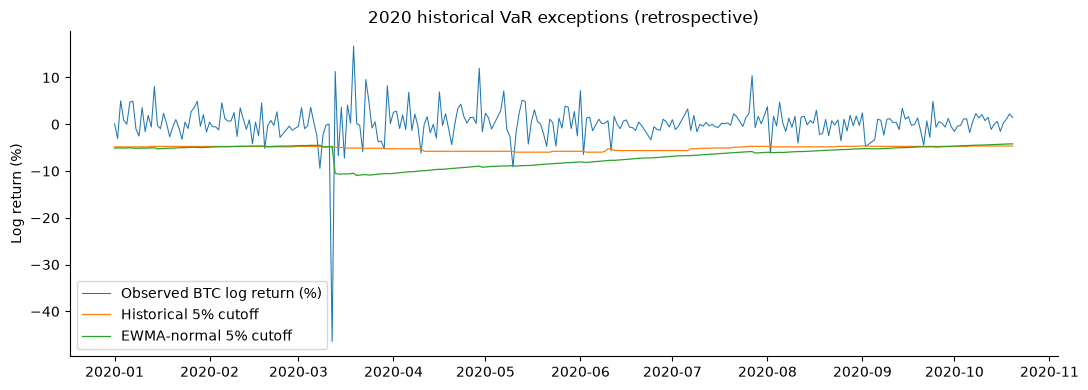

In [38]:
from scipy.stats import chi2
return_s=log_returns_daily.BTC.dropna().sort_index()
var_rows=[]
for i in range(366,len(return_s)):
    dt=return_s.index[i];x=return_s.iloc[i-365:i].to_numpy()
    realized=return_s.iloc[i]
    hist=float(np.quantile(x,.05))
    normal=float(np.mean(x)+stats.norm.ppf(.05)*np.std(x,ddof=1))
    var_rows.append({'date':dt,'observed_log_return':realized,'trailing_historical_VaR':hist,
        'trailing_normal_VaR':normal})
var_series=pd.DataFrame(var_rows)
# EWMA variance is computed before today's observation and lambda was frozen on 2019 validation.
var_ewma_full=ewma_path(vol_s.to_numpy(),selected_lambda,float(np.var(vol_s.loc[:'2018-12-31'])))
ewma_dates=pd.Series(var_ewma_full,index=vol_s.index)/10000.
var_series['EWMA_normal_VaR']=stats.norm.ppf(.05)*np.sqrt(var_series.date.map(ewma_dates).to_numpy())
def kupiec_test(violations,n,p=.05):
    if n==0:return np.nan
    phat=np.clip(violations/n,1e-9,1-1e-9)
    ll0=(n-violations)*np.log(1-p)+violations*np.log(p)
    ll1=(n-violations)*np.log(1-phat)+violations*np.log(phat)
    return float(chi2.sf(max(0,2*(ll1-ll0)),1))
var_eval=[]
for split,dates in [('2019 validation',var_series.date.dt.year.eq(2019)),
                    ('2020 retrospective',var_series.date.dt.year.eq(2020))]:
    dd=var_series.loc[dates]
    for nm,col in [('Historical 365d','trailing_historical_VaR'),
        ('Gaussian 365d','trailing_normal_VaR'),('EWMA-normal','EWMA_normal_VaR')]:
        valid_var=dd[[col,'observed_log_return']].dropna()
        exception=(valid_var.observed_log_return<valid_var[col]);k=int(exception.sum());n=len(valid_var)
        var_eval.append({'split':split,'VaR_method':nm,'n':n,'exceptions':k,
          'empirical_exception_rate':k/n,'nominal_exception_rate':.05,
          'Kupiec_raw_p':kupiec_test(k,n),'mean_predicted_VaR_pct':100*valid_var[col].mean()})
var_eval=pd.DataFrame(var_eval);display(var_eval.round(5))
var_eval.to_csv(OUT/'extra_VaR_5pct_coverage.csv',index=False)
var_series.to_csv(OUT/'extra_VaR_daily_predictions.csv',index=False)
plot_v=var_series.loc[var_series.date.dt.year.eq(2020)]
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(plot_v.date,100*plot_v.observed_log_return,lw=.75,label='Observed BTC log return (%)')
ax.plot(plot_v.date,100*plot_v.trailing_historical_VaR,label='Historical 5% cutoff',lw=.9)
ax.plot(plot_v.date,100*plot_v.EWMA_normal_VaR,label='EWMA-normal 5% cutoff',lw=.9)
ax.legend();ax.set(ylabel='Log return (%)',title='2020 historical VaR exceptions (retrospective)')
savefig('22_VaR_2020_exceptions.png')

## 37. Crypto portfolio risk comparison (not an investment backtest)

Compare **equal-weight**, **training-inverse-volatility-weight** and **BTC-only** daily-rebalanced *hypothetical* return series for the four coins using common consecutive calendar dates. Weights are estimated with **2015–18 only** and then frozen in 2019–2020. Rebalancing assumes frictionless close-to-close returns, unlimited trading, and no crypto fees, slippage, liquidity, taxes or staking. As a result, these are descriptive exposure comparisons, **not attainable net investment returns**.

In [39]:
co_returns=log_returns_daily[coins].dropna().copy()
prew=co_returns.loc[(co_returns.index <= TRAIN_END)]
w_inv=(1/prew.std());w_inv=w_inv/w_inv.sum()
weights={'BTC only':np.array([1.,0.,0.,0.]),
         'Equal 25%':np.repeat(.25,4),'Inverse train vol':w_inv.to_numpy()}
portfolio_rows=[];portfolio_frames=[]
for period,mask in [('2019',co_returns.index.year==2019),('2020 partial',co_returns.index.year==2020)]:
    rr=np.expm1(co_returns.loc[mask].to_numpy())
    for nm,ww in weights.items():
        p_return=rr@ww
        wealth=np.cumprod(1+p_return)
        portfolio_rows.append({'period':period,'portfolio':nm,'n_days':len(p_return),
            'cumulative_gross_return_pct':100*(wealth[-1]-1),
            'annualized_std_pct':100*np.std(p_return,ddof=1)*np.sqrt(365),
            'max_drawdown_pct':100*np.min(wealth/np.maximum.accumulate(np.r_[1,wealth])[1:]-1),
            'weight_BTC':ww[0],'weight_ETH':ww[1],'weight_LTC':ww[2],'weight_XRP':ww[3]})
        portfolio_frames.append(pd.DataFrame({'date':co_returns.loc[mask].index,'portfolio':nm,
                                             'period':period,'gross_wealth_index':wealth}))
portfolio_table=pd.DataFrame(portfolio_rows)
display(portfolio_table.round(3))
portfolio_table.to_csv(OUT/'extra_crypto_portfolio_gross_exposures.csv',index=False)
pd.concat(portfolio_frames).to_csv(OUT/'extra_crypto_portfolio_gross_paths.csv',index=False)

,period,portfolio,n_days,cumulative_gross_return_pct,annualized_std_pct,max_drawdown_pct,weight_BTC,weight_ETH,weight_LTC,weight_XRP
0,2019,BTC only,363,92.221,68.245,-48.978,1.000,0.000,0.000,0.000
1,2019,Equal 25%,363,13.689,70.629,-61.624,0.250,0.250,0.250,0.250
2,2019,Inverse train vol,363,26.501,70.061,-60.336,0.353,0.217,0.245,0.185
3,2020 partial,BTC only,284,88.172,73.140,-47.334,1.000,0.000,0.000,0.000
4,2020 partial,Equal 25%,284,110.193,79.789,-51.333,0.250,0.250,0.250,0.250
5,2020 partial,Inverse train vol,284,108.103,78.701,-50.863,0.353,0.217,0.245,0.185


## 38. Covariate shift: training-to-validation feature distribution shift

Compare **feature medians, means, standardized mean differences and two-sample KS statistics** for 2015–18 versus 2019, then report analogous 2020 distribution changes retrospectively. Holm adjustment is applied *within the pre-2019 vs 2019 seven-feature family*. Large KS statistics indicate covariate shift, not necessarily forecast failure; serial dependence means classical KS p-values are optimistic.

In [40]:
from scipy.stats import ks_2samp
from statsmodels.stats.multitest import multipletests

import numpy as np
import pandas as pd

shift_rows = []

feature_sets = {
    '2019 validation': Xv,
    '2020 retrospective': Xt
}

train_features = Xtr[features].copy()

for interval, comparison_data in feature_sets.items():
    for name in features:
        a = pd.to_numeric(
            train_features[name], errors='coerce'
        ).to_numpy(dtype=float)

        b = pd.to_numeric(
            comparison_data[name], errors='coerce'
        ).to_numpy(dtype=float)

        a = a[np.isfinite(a)]
        b = b[np.isfinite(b)]

        if len(a) < 2 or len(b) < 2:
            raise ValueError(
                f"Insufficient data for {name}: {interval}"
            )

        ks = ks_2samp(a, b)

        train_mean = np.mean(a)
        comparison_mean = np.mean(b)
        train_std = np.std(a, ddof=1)

        smd = (
            (comparison_mean - train_mean) / train_std
            if train_std > 0 else np.nan
        )

        shift_rows.append({
            'split': interval,
            'feature': name,
            'train_n': len(a),
            'comparison_n': len(b),
            'train_mean': train_mean,
            'comparison_mean': comparison_mean,
            'train_median': np.median(a),
            'comparison_median': np.median(b),
            'SMD_train_std': smd,
            'KS_stat': ks.statistic,
            'KS_raw_p': ks.pvalue
        })

shift_table = pd.DataFrame(shift_rows)

shift_table['Holm_train_vs_2019'] = np.nan

mask = shift_table['split'].eq('2019 validation')

shift_table.loc[
    mask, 'Holm_train_vs_2019'
] = multipletests(
    shift_table.loc[mask, 'KS_raw_p'].to_numpy(),
    method='holm'
)[1]

shift_table['significant_2019_5pct'] = (
    shift_table['Holm_train_vs_2019'] < 0.05
)

display(shift_table.round(5))

shift_table.to_csv(
    OUT / 'extra_feature_drift.csv',
    index=False
)

print("Feature distribution drift analysis completed.")


,split,feature,train_n,comparison_n,train_mean,comparison_mean,train_median,comparison_median,SMD_train_std,KS_stat,KS_raw_p,Holm_train_vs_2019,significant_2019_5pct
0,2019 validation,BTC_return_lag1,789,252,0.00296,0.00246,0.00316,0.00099,-0.01054,0.07808,0.18284,0.36568,False
1,2019 validation,BTC_return_lag2,789,252,0.00289,0.00274,0.00316,0.00103,-0.00313,0.07411,0.23089,0.36568,False
2,2019 validation,BTC_momentum5_lag1,789,252,0.01454,0.01254,0.00962,0.00030,-0.01814,0.08505,0.11775,0.35326,False
3,2019 validation,BTC_vol20_lag1,789,252,0.04197,0.04099,0.04115,0.03998,-0.04807,0.16742,0.00004,0.00022,True
4,2019 validation,SP500_return_lag1,789,252,0.00023,0.00103,0.00037,0.00103,0.09657,0.10114,0.03695,0.14782,False
5,2019 validation,BTC_logvolume_lag1,789,252,20.37153,23.44969,20.72538,23.55302,1.56013,0.78937,0.00000,0.00000,True
6,2019 validation,BTC_range_lag1,789,252,0.04901,0.04166,0.03627,0.03212,-0.16280,0.13089,0.00256,0.01278,True
7,2020 retrospective,BTC_return_lag1,789,183,0.00296,0.00448,0.00316,0.00158,0.03227,0.08226,0.25103,NaN,False
8,2020 retrospective,BTC_return_lag2,789,183,0.00289,0.00317,0.00316,0.00140,0.00606,0.06616,0.50930,NaN,False
9,2020 retrospective,BTC_momentum5_lag1,789,183,0.01454,0.01411,0.00962,0.02186,-0.00389,0.09722,0.11181,NaN,False


Feature distribution drift analysis completed.


## 39. Multiple comparisons and uncertainty on retrospective model candidates

Apply HAC-robust mean **squared-error loss difference** tests against the no-change benchmark across *frozen* new 2020 candidate forecasts, with **Holm multiple-testing adjustment**. These are **exploratory, post-2020-inspection tests**, not confirmatory evidence or validation-driven rankings. Sample selection and nonnormal errors can invalidate classical approximations. Small p-values in a retrospective reused period must not be described as independent discovery.

In [41]:
comparison_series={'Elastic Net':predicted_returns['Elastic Net'],
  'XGBoost':predicted_returns['XGBoost'],'Linear SVR':predicted_returns['Linear SVR'],
  'SARIMAX':sarimax_test_r,'Bayesian Ridge':ex_predictions['Bayesian Ridge'],
  'Huber robust':ex_predictions['Huber robust'],'Random Forest':ex_predictions['Random Forest'],
  'Extra Trees':ex_predictions['Extra Trees'],
  'HistGradientBoost':ex_predictions['HistGradientBoost'],
  'KNN scaled':ex_predictions['KNN scaled']}
actual_prices=test.BTC.to_numpy();naive_squared=(actual_prices-test.previous_BTC.to_numpy())**2
adjust_rows=[]
for name,r in comparison_series.items():
    px=test.previous_BTC.to_numpy()*np.exp(r)
    lossdiff=naive_squared-(actual_prices-px)**2
    hac=sm.OLS(lossdiff,np.ones((len(lossdiff),1))).fit(cov_type='HAC',cov_kwds={'maxlags':5})
    adjust_rows.append({'model':name,'mean_baseline_minus_model_squared_error':lossdiff.mean(),
             'two_sided_HAC_raw_p':hac.pvalues[0],
             'mean_loss_diff_HAC_CI_low':hac.conf_int()[0,0],
             'mean_loss_diff_HAC_CI_high':hac.conf_int()[0,1]})
adj_table=pd.DataFrame(adjust_rows)
adj_table['Holm_adjusted_exploratory_p']=multipletests(adj_table.two_sided_HAC_raw_p,method='holm')[1]
display(adj_table.round(4))
adj_table.to_csv(OUT/'extra_HAC_multiple_comparisons.csv',index=False)

,model,mean_baseline_minus_model_squared_error,two_sided_HAC_raw_p,mean_loss_diff_HAC_CI_low,mean_loss_diff_HAC_CI_high,Holm_adjusted_exploratory_p
0,Elastic Net,492.8699,0.7093,-2098.5026,3084.2424,1.0000
1,XGBoost,-3279.5210,0.2589,-8973.0351,2413.9930,1.0000
2,Linear SVR,-185.4528,0.8980,-3021.9573,2651.0516,1.0000
3,SARIMAX,-188.4842,0.8831,-2701.5607,2324.5924,1.0000
4,Bayesian Ridge,30.6408,0.9673,-1435.4841,1496.7658,1.0000
5,Huber robust,281.7917,0.8376,-2413.1816,2976.7650,1.0000
6,Random Forest,-1687.8969,0.5691,-7497.9828,4122.1890,1.0000
7,Extra Trees,-280.5668,0.8003,-2454.3024,1893.1689,1.0000
8,HistGradientBoost,-8320.1751,0.0441,-16420.1767,-220.1735,0.3968
9,KNN scaled,-8783.1187,0.0034,-14652.3711,-2913.8664,0.0336


## 40. Quantile regression: downside/upside return interval coverage

Use linear **quantile regressions** to forecast 5th, 50th and 95th percentiles of next equity-session BTC log returns using lagged features. Select a small fixed penalty grid **on 2019 only** by quantile pinball loss, then refit through 2019 and diagnose **90% interval coverage in previously inspected 2020**. We report crossings if quantile order fails; this is a conditional **return** interval, not an unconditional price confidence interval. The 2020 sample and estimated timestamp availability limit financial interpretation.

,quantile,chosen_alpha_2019,validation_pinball_loss
0,0.05,0.001,0.00511
1,0.50,0.001,0.01386
2,0.95,0.010,0.00563


,n,2020_90pct_interval_coverage,nominal_coverage,quantile_crossing_count,median_return_pinball_2020
0,183,0.96175,0.9,0,0.01338


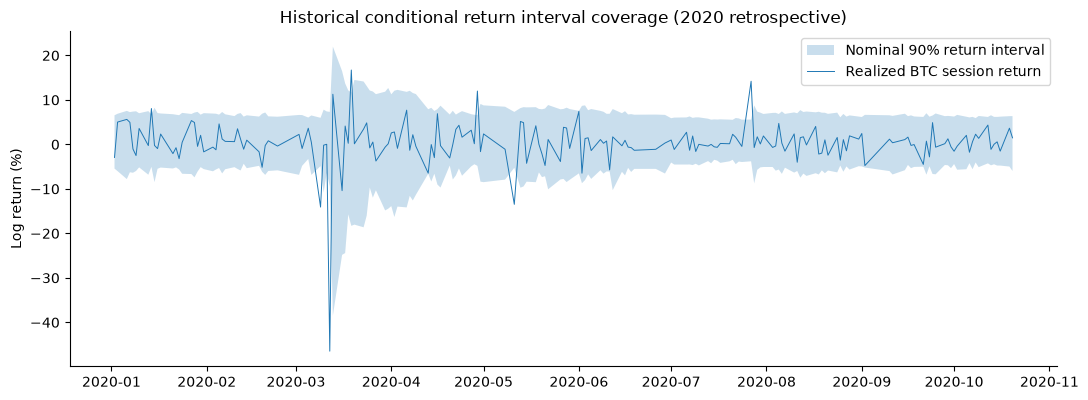

In [42]:
from sklearn.linear_model import QuantileRegressor
from sklearn.metrics import mean_pinball_loss
quant_levels=[.05,.5,.95]
quant_val=[];quant_test_predictions={}
for q in quant_levels:
    candidates=[]
    for alpha in [.001,.01]:
        model=make_pipeline(StandardScaler(),QuantileRegressor(quantile=q,alpha=alpha,solver='highs'))
        model.fit(Xtr,ytr)
        pred=model.predict(Xv)
        loss=mean_pinball_loss(yv,pred,alpha=q)
        candidates.append((loss,alpha))
    bestloss,chosenalpha=min(candidates)
    chosen_model=make_pipeline(StandardScaler(),QuantileRegressor(quantile=q,alpha=chosenalpha,solver='highs'))
    chosen_model.fit(Xtv,ytv)
    quant_test_predictions[q]=chosen_model.predict(Xt)
    quant_val.append({'quantile':q,'chosen_alpha_2019':chosenalpha,'validation_pinball_loss':bestloss})
qpreds=pd.DataFrame({'date':test.date.to_numpy(),'realized_log_return':test.target_return.to_numpy(),
                     'low_q05':quant_test_predictions[.05],
                     'middle_q50':quant_test_predictions[.5],
                     'high_q95':quant_test_predictions[.95]})
crossing=(qpreds.low_q05>qpreds.high_q95).sum()
qpreds['inside_90pct_interval']=qpreds.realized_log_return.between(qpreds.low_q05,qpreds.high_q95)
qmetrics=pd.DataFrame([{'n':len(qpreds),'2020_90pct_interval_coverage':qpreds.inside_90pct_interval.mean(),
   'nominal_coverage':.90,'quantile_crossing_count':int(crossing),
   'median_return_pinball_2020':mean_pinball_loss(qpreds.realized_log_return,qpreds.middle_q50,alpha=.5)}])
display(pd.DataFrame(quant_val).round(5),qmetrics.round(5))
pd.DataFrame(quant_val).to_csv(OUT/'extra_quantile_2019_tuning.csv',index=False)
qmetrics.to_csv(OUT/'extra_quantile_2020_interval_coverage.csv',index=False)
qpreds.to_csv(OUT/'extra_quantile_2020_prediction_intervals.csv',index=False)
fig,ax=plt.subplots(figsize=(11,4.1))
ax.fill_between(qpreds.date,np.asarray(qpreds.low_q05)*100,np.asarray(qpreds.high_q95)*100,
                alpha=.24,label='Nominal 90% return interval')
ax.plot(qpreds.date,np.asarray(qpreds.realized_log_return)*100,lw=.7,label='Realized BTC session return')
ax.legend();ax.set(ylabel='Log return (%)',title='Historical conditional return interval coverage (2020 retrospective)')
savefig('23_quantile_prediction_intervals.png')

## 41. Research integrity checklist and expanded evidence ledger

The studies added here are **distinct research questions**, not repeated model-counting exercises. Preserve all 2019-selected settings and refrain from selecting a "winner" based on repeated 2020 exploration. Machine-readable outputs make decisions auditable. Publish the sources and code; verify licensing before committing raw Kaggle CSV to a public repository.

In [43]:
from pathlib import Path
import pandas as pd

evidence_files = {
    'Raw data provenance': 'extra_source_SHA256.csv',
    'Tail distribution and expected shortfall': 'extra_crypto_tail_risk.csv',
    'ARCH / serial correlation': 'extra_serial_and_ARCH_diagnostics.csv',
    'Drawdown duration': 'extra_underwater_risk.csv',
    'Crypto PCA / rolling co-movement': 'extra_PCA_training_variance.csv',
    'Weekday effects / Holm': 'extra_weekday_effect_holm.csv',
    'Market lead-lag / Granger Holm': 'extra_training_Granger_Holm.csv',
    'Structural breaks / HAC betas': 'extra_HAC_market_betas.csv',
    'Downside co-exceedance': 'extra_cross_market_tail_coexceedance.csv',
    'Additional supervised model families': 'extra_model_families_validation.csv',
    'Conditional errors': 'extra_conditional_forecast_bias.csv',
    'Rolling-origin refits': 'extra_rolling_origin_2019_selection.csv',
    'Fixed 1/3/7-day horizons': 'extra_fixed_1_3_7_day_forecasts.csv',
    'Historical VaR calibration': 'extra_VaR_5pct_coverage.csv',
    'Crypto portfolios (gross)': 'extra_crypto_portfolio_gross_exposures.csv',
    'Feature distribution drift': 'extra_feature_drift.csv',
    'HAC multiple comparisons': 'extra_HAC_multiple_comparisons.csv',
    'Quantile regression interval': 'extra_quantile_2020_interval_coverage.csv'
}

OUT = Path(OUT)
evidence_rows = []

for research_area, filename in evidence_files.items():
    filepath = OUT / filename

    if not filepath.is_file():
        status = 'Missing'
        rows = 0
    else:
        try:
            df_check = pd.read_csv(filepath)
            rows = len(df_check)
            status = ('Fresh & readable' if rows > 0 and filepath.stat().st_mtime_ns >= RUN_STARTED_NS else
                      'Stale from earlier run' if rows > 0 else 'Empty')
        except Exception:
            status = 'Invalid'
            rows = 0

    evidence_rows.append({
        'research_area': research_area,
        'output': filename,
        'status': status,
        'rows': rows
    })

additional_evidence = pd.DataFrame(evidence_rows)

additional_evidence.to_csv(
    OUT / 'extra_RESEARCH_EVIDENCE_INDEX.csv',
    index=False
)

print('Research Evidence Verification')
print('Output directory:', OUT.resolve())

display(additional_evidence)

verified_count = (additional_evidence['status'] == 'Fresh & readable').sum()
total_count = len(additional_evidence)

missing_evidence = additional_evidence[
    additional_evidence['status'] != 'Fresh & readable'
]

EVIDENCE_COMPLETE = missing_evidence.empty

print(f'\nVerified evidence: {verified_count}/{total_count}')
print(f"Total saved figures: {len(list(FIG.glob('*.png')))}")
print(f"Total output files: {len(list(OUT.glob('*')))}")

if EVIDENCE_COMPLETE:
    print('\nAll research evidence files verified successfully.')
else:
    print('\nMissing or incomplete evidence files:')
    display(missing_evidence)

    print(
        '\nRe-run the corresponding analysis sections '
        'before treating the research as complete.'
    )


Research Evidence Verification
Output directory: I:\Dataset\Bitcoin Price Regression Analysis\runs\20261026T030925_071513Z_ee4a01ed\outputs


,research_area,output,status,rows
0,Raw data provenance,extra_source_SHA256.csv,Fresh & readable,2
1,Tail distribution and expected shortfall,extra_crypto_tail_risk.csv,Fresh & readable,4
2,ARCH / serial correlation,extra_serial_and_ARCH_diagnostics.csv,Fresh & readable,4
3,Drawdown duration,extra_underwater_risk.csv,Fresh & readable,4
4,Crypto PCA / rolling co-movement,extra_PCA_training_variance.csv,Fresh & readable,4
5,Weekday effects / Holm,extra_weekday_effect_holm.csv,Fresh & readable,7
6,Market lead-lag / Granger Holm,extra_training_Granger_Holm.csv,Fresh & readable,10
7,Structural breaks / HAC betas,extra_HAC_market_betas.csv,Fresh & readable,3
8,Downside co-exceedance,extra_cross_market_tail_coexceedance.csv,Fresh & readable,2
9,Additional supervised model families,extra_model_families_validation.csv,Fresh & readable,6



Verified evidence: 18/18
Total saved figures: 23
Total output files: 79

All research evidence files verified successfully.


## 42. Phase 4 — Evidence-led synthesis and publication checklist

Interpret model accuracy in two separate tasks (**price / next equity session** versus **conditional volatility / next observed crypto return**); do not rank them together. The original 2020 historical evaluation has been repeatedly examined during iterative development, so new analyses are **retrospective robustness checks**, not prospective forecasting claims. Avoid reporting significance based on cherry-picked winners; confidence intervals are exploratory and unadjusted for multiple comparisons. The 2020 series ends October 20, so year-to-year samples do not all span the same length.

**What would truly advance this research further?** New **2021+** raw BTC, S&P and relevant market feature data with traceable timestamps, an explicit locked modeling protocol, repeated expanding-origin out-of-time scoring, point-in-time feature availability, and (only if discussing actionable trading) slippage and transaction costs. Do not interpolate unavailable original Dow Jones / VIX / gold / oil / Treasury source fields.

In [44]:
# Save a compact, machine-readable analysis manifest; all values derived from executing data.
phase_manifest={
 'project':'Bitcoin Price Analysis — Four-Phase Extended Edition',
 'period_start':str(START.date()),'period_end':str(END.date()),
 'forecast_target':'next observed US equity-session Bitcoin close; variable calendar horizon',
 'calendar_day_target':'next consecutive UTC crypto close; separate experiment',
 'research_status':'2019 validation model tuning; 2020 historical data previously inspected',
 'main_2019_selected_model':selected_model,
 'main_2019_validation_RMSE_USD':float(chosen_val.RMSE_USD) if 'chosen_val' in globals() else
     float(validation_table.set_index('model').loc[selected_model,'RMSE_USD']),
 'additional_statistical_models_2019_winner':str(selected_new),
 'calendar_day_2019_winner':str(chosen_daily),
 'EWMA_validation_selected_lambda':selected_lambda,
 'volatility_models':['Rolling 30 variance','Gaussian GARCH','Student-t GARCH','EWMA'],
 'missing_equity_sessions_2020':int((~coverage_2020.included_full).sum()),
 'complete_case_2020':len(test),'btc_only_eligible_2020':len(reduced_test),
 '2020_reuse_warning':'2020 is a previously inspected retrospective period, not fresh external holdout',
 'raw_data_sources':['dataset.csv','SPX_500_Data.csv'],
 'future_data_required':'External 2021+ dataset for truly independent evaluation'}
(OUT/'phase4_research_manifest.json').write_text(json.dumps(phase_manifest,indent=2),encoding='utf-8')
summary_rows=[
 ('Historical total equity sessions in 2020',len(coverage_2020)),
 ('Full predictor eligible sessions',len(test)),
 ('BTC-only reduced predictor eligible sessions',len(reduced_test)),
 ('2019 selected principal model',selected_model),
 ('2019 selected additional statistical benchmark',selected_new),
 ('2019 selected fixed-24-hour baseline',chosen_daily),
 ('2019 selected EWMA decay',selected_lambda),
 ('2019 best BTC-only versus S&P ablation',selected_ablation_name),
 ('Student-t GARCH nu fit through 2019',round(student_2019['nu'],3)),
 ('2020 excluding March cross-market correlation',round(float(regime_sensitivity_table.loc[
        regime_sensitivity_table['sample'].eq('2020 excluding March'),'return_corr'].iloc[0]),4))]
phase4_summary=pd.DataFrame(summary_rows,columns=['evidence','result'])
display(phase4_summary);phase4_summary.to_csv(OUT/'phase4_evidence_summary.csv',index=False)
print('Generated plots:',len(list(FIG.glob('*.png'))),'| files in outputs:',len(list(OUT.iterdir())))
print('IMPORTANT: Additional 2020 comparisons are retrospective explorations, not fresh external tests.')

,evidence,result
0,Historical total equity sessions in 2020,203
1,Full predictor eligible sessions,183
2,BTC-only reduced predictor eligible sessions,187
3,2019 selected principal model,Naive no-change
4,2019 selected additional statistical benchmark,Calendar-normalized drift
5,2019 selected fixed-24-hour baseline,Naive 24h
6,2019 selected EWMA decay,0.985
7,2019 best BTC-only versus S&P ablation,A: BTC returns only
8,Student-t GARCH nu fit through 2019,3.284
9,2020 excluding March cross-market correlation,0.2735


Generated plots: 23 | files in outputs: 81
IMPORTANT: Additional 2020 comparisons are retrospective explorations, not fresh external tests.


## 43. Conclusions, guardrails & additional data needs

**Separate questions.** Classical OLS of contemporaneous *price levels* is **descriptive** and vulnerable to nonstationarity, heteroskedasticity and autocorrelation. Historical *one-step predictive* experiments use lagged features and chronological splits. SARIMAX is a fixed-form additional return benchmark; GARCH is a **different target: conditional variance**. Feature sensitivity/market regimes provide non-causal exploration. 2020 candidate tables and bootstrap confidence intervals are **diagnostics only**; the winner must be fixed from 2019 validation.

**What this dataset cannot answer:** The original Dow Jones / NASDAQ / VIX / Gold / Oil / Treasury yield associations cannot be recovered with these two Kaggle CSVs. To extend the historical period to 2021–2026, acquire **new source files** with consistent definitions and validate them prospectively—these observations are **not included or simulated**.

**Further research, not required for this version:** More years and a genuinely later external holdout; precise BTC UTC vs US equity timestamp alignment; alternative forecast horizons explicitly defined on a 24/7 calendar; transaction costs and executable prices for any investment feasibility study; sensitivity to extreme moves and alternative volatility specifications. Keep a compact, defensible number of models instead of deep networks trained on only a few years of data.

## 44. Reproducible final summary and audit checklist

The following summary is **computed by the notebook** after the final holdout and all advanced studies. Pay attention to both **2019 model selection** and the **size and uncertainty** of 2020 differences, not to test-set rankings or price-level R² alone. All explanatory tests are source-dependent and historical.

In [45]:
# Computed run summary; no fabricated hard-coded model results.
chosen_val=validation_table.set_index('model').loc[selected_model]
chosen_test=holdout.set_index('model').loc[selected_model]
summary_text=(
 f'**Executed-data summary (2015–2020):** {len(crypto):,} cryptocurrency calendar rows and '
 f'{len(market):,} S&P sessions. Same-date BTC–S&P price correlation **{level_r:.3f}** '
 f'versus market-session return correlation **{returns_r:.3f}**. '
 f'2019 validation selected **{selected_model}** (RMSE **${chosen_val.RMSE_USD:,.2f}**). '
 f'On the 2020 retrospective sample, that preselected model had RMSE **${chosen_test.RMSE_USD:,.2f}** '
 f'versus the no-change baseline **${baseline_rmse:,.2f}** '
 f'({chosen_test.RMSE_gain_over_naive_pct:+.3f}% improvement; positive means lower error). '
 'Treat these as historical, dataset-dependent results, not forward-looking performance guarantees.'
)
display(Markdown(summary_text))
(OUT/'final_executed_summary.md').write_text(summary_text+'\n',encoding='utf-8')
print('Figures saved:',len(list(FIG.glob('*.png'))),'| output files:',len(list(OUT.glob('*'))))

# Additional results calculated on the same sources, separate from original baseline selection.
extra_summary=(
 f'\n\n**Advanced additions:** SARIMAX 2019 validation RMSE **${sarimax_validation["RMSE_USD"]:,.2f}**, '
 f'2020 RMSE **${sarimax_holdout["RMSE_USD"]:,.2f}**; extended 2019 pre-selection: **{extended_selected}**. '
 f'Ridge ablation chosen from 2019 validation: **{selected_ablation_name}** '
 f'(alpha {selected_ablation_alpha:g}). GARCH models **volatility**, not price. '
 f'2019–2020 return-correlation difference: **{regime_diff:+.3f}** '
 f'(95% 10-session block CI [{ci_diff[0]:+.3f}, {ci_diff[1]:+.3f}]). '
 'Loss-differential block bootstrap, horizon-specific error, and weekday/weekend sensitivity results are archived in outputs/. '
 'No 2021–2026 data or unavailable source variables were fabricated.'
)
display(Markdown(extra_summary))
(OUT/'final_executed_summary.md').write_text(summary_text+'\n\n'+extra_summary+'\n',encoding='utf-8')
print('TOTAL figures:',len(list(FIG.glob('*.png'))),'| output files:',len(list(OUT.glob('*'))))


**Executed-data summary (2015–2020):** 1,822 cryptocurrency calendar rows and 1,260 S&P sessions. Same-date BTC–S&P price correlation **0.835** versus market-session return correlation **0.160**. 2019 validation selected **Naive no-change** (RMSE **$394.76**). On the 2020 retrospective sample, that preselected model had RMSE **$381.56** versus the no-change baseline **$381.56** (+0.000% improvement; positive means lower error). Treat these as historical, dataset-dependent results, not forward-looking performance guarantees.

Figures saved: 23 | output files: 82




**Advanced additions:** SARIMAX 2019 validation RMSE **$396.04**, 2020 RMSE **$381.81**; extended 2019 pre-selection: **Naive no-change**. Ridge ablation chosen from 2019 validation: **A: BTC returns only** (alpha 100). GARCH models **volatility**, not price. 2019–2020 return-correlation difference: **+0.591** (95% 10-session block CI [+0.235, +0.804]). Loss-differential block bootstrap, horizon-specific error, and weekday/weekend sensitivity results are archived in outputs/. No 2021–2026 data or unavailable source variables were fabricated.

TOTAL figures: 23 | output files: 82


## 45. Archive, project history & references

**Original research preserved:** `archive/Baruch_2020_original_R.ipynb` (2020 R coursework). An earlier R improved notebook may also be placed in `archive/` as historical context. Regression coefficients and graphs from the R notebook were trained on a **different, more complete variable set** and must not be compared numerically with this reduced-data Python reanalysis.

**Data sources from the user's two uploaded ZIP archives:**

- [Kaggle — S&P 500 Daily Data (1927–2021)](https://www.kaggle.com/datasets/myungchankim/sp-500-daily-data-19281230-to-20210919/data) → `SPX_500_Data.csv`.
- [Kaggle — Cryptocurrency Historical Prices](https://www.kaggle.com/datasets/maharshipandya/-cryptocurrency-historical-prices-dataset) → `dataset.csv`.
- [statsmodels documentation](https://www.statsmodels.org/) · [scikit-learn documentation](https://scikit-learn.org/stable/) · [XGBoost documentation](https://xgboost.readthedocs.io/).

The uploaded `global-financial-markets.ipynb` is a historical-market **analysis notebook**, not a dataset containing its underlying 34-asset market CSV. Its named series are not imported here. Before publicly publishing original Kaggle CSVs, verify their licenses and redistribution permissions; GitHub can host this notebook and README while leaving raw CSVs local.

## 46. Comprehensive research findings — reproducible executive view

This final comparison combines the **original Baruch explanatory question**, the **four-phase leakage-aware historical evaluation**, and **18 additional exploratory studies**. Values below are computed from CSVs generated in this same run. Outcomes are descriptive and **none of the repeatedly examined 2020 data is a fresh blind confirmation**. Model selection and nominal significance are distinct questions; the absence of external 2021+ raw sources remains a hard limitation.

In [46]:
# Executed executive report built only from verified result files.
from IPython.display import display, Markdown
new_val=pd.read_csv(OUT/'extra_model_families_validation.csv')
new_test=pd.read_csv(OUT/'extra_model_families_2020_retrospective.csv')
qint=pd.read_csv(OUT/'extra_quantile_2020_interval_coverage.csv').iloc[0]
varcov=pd.read_csv(OUT/'extra_VaR_5pct_coverage.csv')
tail=pd.read_csv(OUT/'extra_crypto_tail_risk.csv')
base_2019=float(validation_table.loc[validation_table.model.eq('Naive no-change'),'RMSE_USD'].iloc[0])
extra_name=str(new_val.sort_values('RMSE_USD').iloc[0]['model'])
extra_rmse=float(new_val.sort_values('RMSE_USD').iloc[0]['RMSE_USD'])
btc_tail=float(tail.loc[tail.asset.eq('BTC'),'historical_CVaR_95_loss_pct'].iloc[0])
info=f"""### Verified historical findings

- **Crypto observations:** {len(crypto):,} crypto dates, {len(market):,} S&P sessions; all sources auditable.
- **2020 coverage:** {len(test)}/{len(coverage_2020)} S&P sessions on seven-feature model; missingness matters.
- **Core selection:** 2019 no-change RMSE **${base_2019:,.2f}**. Among the six *additional* supervised families, best 2019 family **{extra_name}** with RMSE **${extra_rmse:,.2f}**; this is not evidence to reselect based on 2020.
- **BTC historical one-day 95% expected shortfall:** **{btc_tail:.2f}%** loss conditional on crossing the 5th-percentile threshold (source and sample dependent).
- **Quantile regression:** nominal 90% interval captured **{100*qint['2020_90pct_interval_coverage']:.1f}%** of 2020 retrospective session returns; interval calibration requires fresh external testing.
- **Distributional regime caveat:** BTC/S&P relationships and volatility vary by period. Cross-correlations and Granger hypotheses are not causality.
- **Research honesty:** never-fresh 2020 comparison, omitted Dow/VIX/gold/oil/Treasuries, incompatible closure clocks, partial crypto calendar, no costs and no prospective deployment.
"""
display(Markdown(info))
(OUT/'COMPREHENSIVE_EXECUTIVE_SUMMARY.md').write_text(info,encoding='utf-8')
print('Executed code cells:',sum(c.cell_type=='code' and c.execution_count is not None for c in __import__('nbformat').read(PROJECT_DIR/'Bitcoin_Comprehensive_Research_FINAL.ipynb',as_version=4).cells) if False else 'see notebook audit')
print('Figures',len(list(FIG.glob('*.png'))),'| output files',len(list(OUT.iterdir())))

### Verified historical findings

- **Crypto observations:** 1,822 crypto dates, 1,260 S&P sessions; all sources auditable.
- **2020 coverage:** 183/203 S&P sessions on seven-feature model; missingness matters.
- **Core selection:** 2019 no-change RMSE **$394.76**. Among the six *additional* supervised families, best 2019 family **Extra Trees** with RMSE **$394.87**; this is not evidence to reselect based on 2020.
- **BTC historical one-day 95% expected shortfall:** **9.66%** loss conditional on crossing the 5th-percentile threshold (source and sample dependent).
- **Quantile regression:** nominal 90% interval captured **96.2%** of 2020 retrospective session returns; interval calibration requires fresh external testing.
- **Distributional regime caveat:** BTC/S&P relationships and volatility vary by period. Cross-correlations and Granger hypotheses are not causality.
- **Research honesty:** never-fresh 2020 comparison, omitted Dow/VIX/gold/oil/Treasuries, incompatible closure clocks, partial crypto calendar, no costs and no prospective deployment.


Executed code cells: see notebook audit
Figures 23 | output files 83


## 47. Nested walk-forward training and model selection

Nested, nonoverlapping *pre-2020* outer windows (2017–2019). Hyperparameters are selected on the latest portion of each past-only training history. No 2020 scores are used for selection; nested results estimate historical selection stability, not future guaranteed accuracy.

In [47]:

from sklearn.metrics import mean_squared_error
candidate_models = {
    'Naive': None,
    'Historical mean': 'mean',
    'Ridge 1': make_pipeline(StandardScaler(),Ridge(alpha=1)),
    'Ridge 100': make_pipeline(StandardScaler(),Ridge(alpha=100)),
    'Huber': make_pipeline(StandardScaler(),HuberRegressor(alpha=.001,max_iter=600))
}
nested_rows=[]
for year in [2017,2018,2019]:
    hist=forecast.loc[forecast.date.dt.year.lt(year)].copy()
    future=forecast.loc[forecast.date.dt.year.eq(year)].copy()
    if len(hist)<290 or len(future)<100:continue
    n_inner=int(len(hist)*.8)
    a,hv=hist.iloc[:n_inner],hist.iloc[n_inner:]
    scores=[]
    for label,est in candidate_models.items():
        if est is None: p=np.zeros(len(hv))
        elif est=='mean':p=np.full(len(hv),a.target_return.mean())
        else:p=clone(est).fit(a[features],a.target_return).predict(hv[features])
        scores.append((evaluate(hv,p,label,'inner')['RMSE_USD'],label))
    best_label=min(scores)[1];best=candidate_models[best_label]
    if best is None:r=np.zeros(len(future))
    elif best=='mean':r=np.full(len(future),hist.target_return.mean())
    else:r=clone(best).fit(hist[features],hist.target_return).predict(future[features])
    s=evaluate(future,r,best_label,'outer')
    base=evaluate(future,np.zeros(len(future)),'Naive','outer')
    nested_rows.append({'year':year,'inner_train_n':len(a),'inner_validation_n':len(hv),
        'outer_n':len(future),'selected_model':best_label,'outer_RMSE_USD':s['RMSE_USD'],
        'baseline_RMSE_USD':base['RMSE_USD'],
        'RMSE_improvement_pct':100*(base['RMSE_USD']-s['RMSE_USD'])/base['RMSE_USD']})
nested_summary=pd.DataFrame(nested_rows)
assert len(nested_summary)>=2
nested_summary.to_csv(OUT/'extended_nested_walkforward_pre2020.csv',index=False)
display(nested_summary.round(4))


,year,inner_train_n,inner_validation_n,outer_n,selected_model,outer_RMSE_USD,baseline_RMSE_USD,RMSE_improvement_pct
0,2018,430,108,251,Ridge 100,477.8666,439.4739,-8.736
1,2019,631,158,252,Naive,394.7558,394.7558,0.000


## 48. Covariate-shift robust volume features

Compare BTC-only, raw log volume, and *past-only* 30-session standardized relative volume. Per-feature-set scores need common-date evaluation for strong comparisons; we report each dataset size rather than hiding coverage changes.

In [48]:

vol_f=f.copy().set_index('date')
vol_f['logvol']=np.log1p(vol_f.BTC_Volume.clip(lower=0))
vol_f['mean_past']=vol_f.logvol.shift(1).rolling(30,min_periods=20).mean()
vol_f['sd_past']=vol_f.logvol.shift(1).rolling(30,min_periods=20).std().replace(0,np.nan)
vol_f['volume_z30_lag1']=((vol_f.logvol.shift(1)-vol_f.mean_past)/vol_f.sd_past).clip(-8,8)
vol_f=vol_f.reset_index()
volume_sets={
 'BTC-only':[x for x in features if x not in ('SP500_return_lag1','BTC_logvolume_lag1')],
 'Raw volume':features,
 'Rolling standardized volume':[('volume_z30_lag1' if x=='BTC_logvolume_lag1' else x) for x in features]
}
volume_results=[]
for label,cols in volume_sets.items():
    subset=vol_f.dropna(subset=cols+['target_return','previous_BTC','BTC'])
    a=subset[subset.date.le(TRAIN_END)]
    v=subset[subset.date.gt(TRAIN_END)&subset.date.le(VALID_END)]
    av=subset[subset.date.le(VALID_END)]
    t=subset[subset.date.gt(VALID_END)&subset.date.le(END)]
    for alpha in [1,100]:
        mod=make_pipeline(StandardScaler(),Ridge(alpha=alpha))
        vr=mod.fit(a[cols],a.target_return).predict(v[cols])
        tr=clone(mod).fit(av[cols],av.target_return).predict(t[cols])
        volume_results.append({'features':label,'alpha':alpha,'n_valid':len(v),'n_test':len(t),
            'validation_RMSE':evaluate(v,vr,label,'2019')['RMSE_USD'],
            'test_RMSE_retrospective':evaluate(t,tr,label,'2020')['RMSE_USD']})
volume_comparison=pd.DataFrame(volume_results)
display(volume_comparison.round(4))
volume_comparison.to_csv(OUT/'extended_volume_shift_robustness.csv',index=False)


,features,alpha,n_valid,n_test,validation_RMSE,test_RMSE_retrospective
0,BTC-only,1,252,183,398.9502,383.1746
1,BTC-only,100,252,183,398.1820,382.8251
2,Raw volume,1,252,183,399.6161,383.5893
3,Raw volume,100,252,183,398.1543,383.0841
4,Rolling standardized volume,1,252,183,400.0818,384.1486
5,Rolling standardized volume,100,252,183,399.2399,383.8562


## 49. Conditional VaR coverage

Christoffersen-style conditional coverage and exception clustering extend Kupiec frequency analysis. Asymptotic p-values become unreliable with very few exceptions; findings remain descriptive.

In [49]:

from scipy.stats import chi2
def christoffersen(ex):
    x=np.asarray(ex,dtype=int);n=len(x);k=int(x.sum())
    n00=int(((x[:-1]==0)&(x[1:]==0)).sum());n01=int(((x[:-1]==0)&(x[1:]==1)).sum())
    n10=int(((x[:-1]==1)&(x[1:]==0)).sum());n11=int(((x[:-1]==1)&(x[1:]==1)).sum())
    clip=lambda p:np.clip(p,1e-10,1-1e-10)
    p=clip((n01+n11)/max(n-1,1));p0=clip(n01/max(n00+n01,1));p1=clip(n11/max(n10+n11,1))
    null=(n00+n10)*np.log(1-p)+(n01+n11)*np.log(p)
    alt=n00*np.log(1-p0)+n01*np.log(p0)+n10*np.log(1-p1)+n11*np.log(p1)
    LR_ind=max(0,2*(alt-null))
    pe=clip(k/n);nullu=(n-k)*np.log(.95)+k*np.log(.05)
    altu=(n-k)*np.log(1-pe)+k*np.log(pe)
    LR_uc=max(0,2*(altu-nullu))
    return {'exceptions':k,'LR_ind_p':chi2.sf(LR_ind,1),'LR_conditional_p':chi2.sf(LR_ind+LR_uc,2),
            'n00':n00,'n01':n01,'n10':n10,'n11':n11}
cond_rows=[]
for year in [2019,2020]:
    for model,col in [('Historical','trailing_historical_VaR'),('Gaussian','trailing_normal_VaR'),('EWMA','EWMA_normal_VaR')]:
        d=var_series.loc[var_series.date.dt.year.eq(year),['observed_log_return',col]].dropna()
        cond_rows.append({'year':year,'method':model,'n':len(d),
                          **christoffersen((d.observed_log_return<d[col]).to_numpy())})
conditional_var=pd.DataFrame(cond_rows)
conditional_var.to_csv(OUT/'extended_conditional_VaR_coverage.csv',index=False)
display(conditional_var.round(4))


,year,method,n,exceptions,LR_ind_p,LR_conditional_p,n00,n01,n10,n11
0,2019,Historical,363,14,0.5586,0.4910,335,13,13,1
1,2019,Gaussian,363,14,0.5586,0.4910,335,13,13,1
2,2019,EWMA,363,12,0.4015,0.2037,339,11,11,1
3,2020,Historical,284,13,0.2631,0.5061,257,13,13,0
4,2020,Gaussian,284,4,0.7349,0.0046,275,4,4,0
5,2020,EWMA,284,5,0.6715,0.0146,273,5,5,0


## 50. Split-conformal return interval calibration

Quantile estimators fit only through 2018; **2019** determines a nonconformity threshold; **2020** measures retrospective interval coverage. Exchangeability-based conformal guarantees generally do not hold under time-series regime changes.

,2019_calibration_n,calibration_margin,2020_retro_n,nominal_coverage,observed_coverage,mean_width_pct
0,252,0.0,183,0.9,0.95628,17.40408


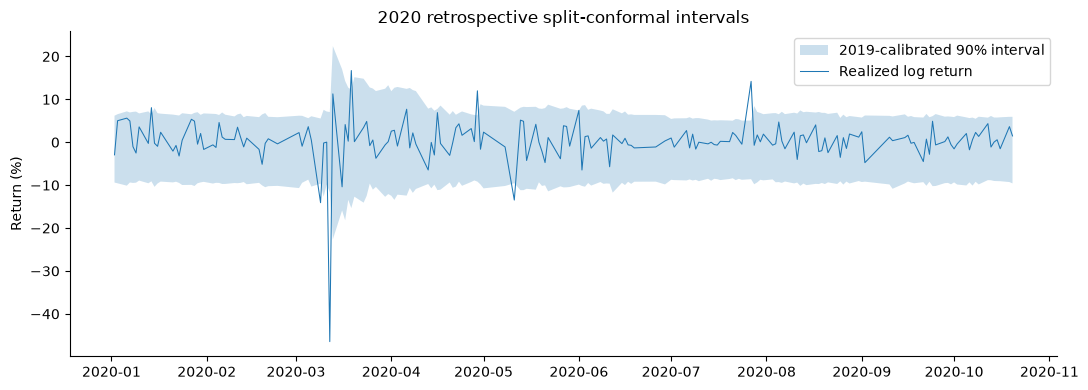

In [50]:

from sklearn.linear_model import QuantileRegressor
conformal_fit={}
for q in [.05,.95]:
    conformal_fit[q]=make_pipeline(StandardScaler(),QuantileRegressor(quantile=q,alpha=.01,solver='highs')).fit(Xtr,ytr)
lo=conformal_fit[.05].predict(Xv);hi=conformal_fit[.95].predict(Xv)
scores=np.maximum.reduce([lo-yv.to_numpy(),yv.to_numpy()-hi,np.zeros(len(yv))])
level=min(1.0,np.ceil((len(scores)+1)*.90)/len(scores))
qhat=float(np.quantile(scores,level,method='higher'))
conf=pd.DataFrame({'date':test.date.to_numpy(),'realized':test.target_return.to_numpy(),
                   'q05':conformal_fit[.05].predict(Xt),'q95':conformal_fit[.95].predict(Xt)})
conf['low']=np.minimum(conf.q05,conf.q95)-qhat
conf['high']=np.maximum(conf.q05,conf.q95)+qhat
conf['inside']=conf.realized.between(conf.low,conf.high)
conf_report=pd.DataFrame([{'2019_calibration_n':len(yv),'calibration_margin':qhat,
    '2020_retro_n':len(conf),'nominal_coverage':.90,'observed_coverage':conf.inside.mean(),
    'mean_width_pct':100*(conf.high-conf.low).mean()}])
conf.to_csv(OUT/'extended_conformal_predictions.csv',index=False)
conf_report.to_csv(OUT/'extended_conformal_coverage.csv',index=False)
display(conf_report.round(5))
fig,ax=plt.subplots(figsize=(11,4))
ax.fill_between(conf.date,conf.low*100,conf.high*100,alpha=.23,label='2019-calibrated 90% interval')
ax.plot(conf.date,conf.realized*100,lw=.75,label='Realized log return')
ax.set(ylabel='Return (%)',title='2020 retrospective split-conformal intervals');ax.legend()
savefig('24_extended_conformal.png')


## 51. Time-varying market beta

Rolling 90-session descriptive BTC/S&P OLS beta and correlation. These are historical *associations*, not causal coefficients or synchronized trading signals.

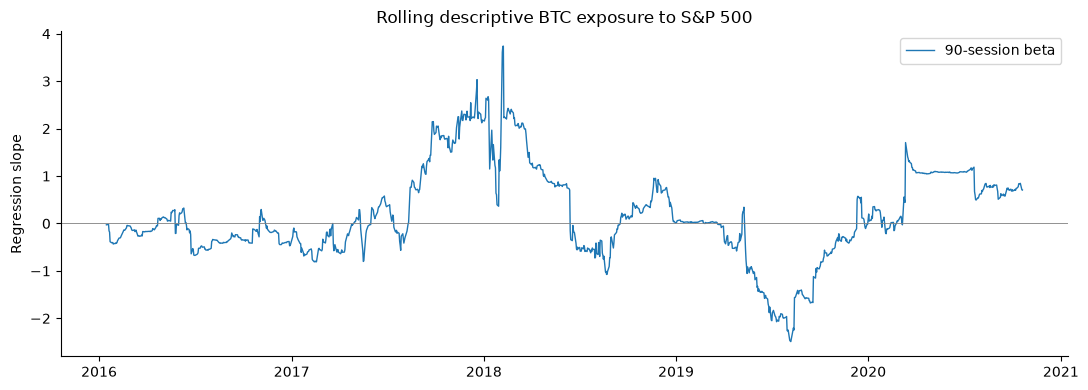

In [51]:

roll=aligned[['date','BTC_return','SP500_return']].sort_values('date').set_index('date')
x=roll.SP500_return;y=roll.BTC_return
roll_beta=y.rolling(90,min_periods=60).cov(x)/x.rolling(90,min_periods=60).var()
roll_corr=y.rolling(90,min_periods=60).corr(x)
roll_table=pd.DataFrame({'date':roll_beta.index,'market_beta':roll_beta.values,'return_corr':roll_corr.values})
roll_table.to_csv(OUT/'extended_rolling_market_beta.csv',index=False)
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(roll_table.date,roll_table.market_beta,lw=1,label='90-session beta')
ax.axhline(0,color='grey',lw=.6)
ax.set(title='Rolling descriptive BTC exposure to S&P 500',ylabel='Regression slope')
ax.legend();savefig('25_extended_rolling_market_beta.png')


## 52. Empirical downside tail dependence and copula sensitivity

Train-only Bitcoin–Ethereum lower-tail dependence versus 2019–2020 descriptive observations. Compare simulated Gaussian and Student-t copulas fitted to pre-2019 ranks; inference is **assumption sensitive**, and simulation results are not additional observed data.

The tail ratio in the retrospective period has a small number of BTC low-tail events. Binomial and block-bootstrap confidence intervals are added below; avoid interpreting point estimates as certainty.


In [52]:

from scipy.stats import norm, t as student_t, multivariate_t, rankdata
from scipy.optimize import minimize_scalar
pairs=log_returns_daily[['BTC','ETH']].dropna()
a=pairs.loc[pairs.index.year<=2018]
z=pairs.loc[pairs.index.year>=2019]
cut=a.quantile(.05)
tail_rows=[]
for name,subset in [('Training',a),('Retrospective 2019–20',z)]:
    bt=subset.BTC.le(cut.BTC);et=subset.ETH.le(cut.ETH)
    tail_rows.append({'period':name,'n':len(subset),'BTC_lower5_count':int(bt.sum()),
     'joint_lower5_count':int((bt&et).sum()),'conditional_ETH_lower5_given_BTC':float(et[bt].mean()) if bt.any() else np.nan})
tail_emp=pd.DataFrame(tail_rows)
U=np.column_stack([rankdata(a[k])/(len(a)+1) for k in ['BTC','ETH']])
rho=float(np.clip(np.corrcoef(norm.ppf(U).T)[0,1],-.95,.95))
def copula_ll(nu):
    q=student_t.ppf(U,nu)
    joint=multivariate_t.logpdf(q,shape=[[1,rho],[rho,1]],df=nu)
    return float(np.sum(joint-student_t.logpdf(q[:,0],nu)-student_t.logpdf(q[:,1],nu)))
nu=float(minimize_scalar(lambda v:-copula_ll(v),bounds=(2.1,40),method='bounded').x)
rng=np.random.default_rng(SEED+9)
normal_pairs=rng.multivariate_normal([0,0],[[1,rho],[rho,1]],size=65000)
t_pairs=normal_pairs/np.sqrt(rng.chisquare(nu,size=len(normal_pairs))[:,None]/nu)
rows=[]
for label,v in [('Gaussian',norm.cdf(normal_pairs)),('Student-t',student_t.cdf(t_pairs,df=nu))]:
    rows.append({'copula':label,'rho_train':rho,'df_t_if_applicable':nu if label=='Student-t' else np.nan,
    'estimated_P_ETH_lower5_given_BTC_lower5':float(np.mean((v[:,0]<.05)&(v[:,1]<.05))/np.mean(v[:,0]<.05))})
copula_tbl=pd.DataFrame(rows)
display(tail_emp.round(4),copula_tbl.round(4))
tail_emp.to_csv(OUT/'extended_tail_dependence.csv',index=False)
copula_tbl.to_csv(OUT/'extended_copula_sensitivity.csv',index=False)


,period,n,BTC_lower5_count,joint_lower5_count,conditional_ETH_lower5_given_BTC
0,Training,1168,59,24,0.4068
1,Retrospective 2019–20,647,16,12,0.7500


,copula,rho_train,df_t_if_applicable,estimated_P_ETH_lower5_given_BTC_lower5
0,Gaussian,0.4299,NaN,0.2128
1,Student-t,0.4299,2.8796,0.3365


## 53. Train-period variance change-point sensitivity

Binary segmentation of **training-only** squared BTC returns estimates descriptive variance-change candidates. Penalized Gaussian likelihood is used as an exploratory signal; detected boundaries are not externally validated event causes.

,date,cost_gain,penalty,segment_before
0,2017-01-03,122.963587,14.126096,1168
1,2016-08-06,79.405412,14.126096,440
2,2018-04-28,55.570830,14.126096,728


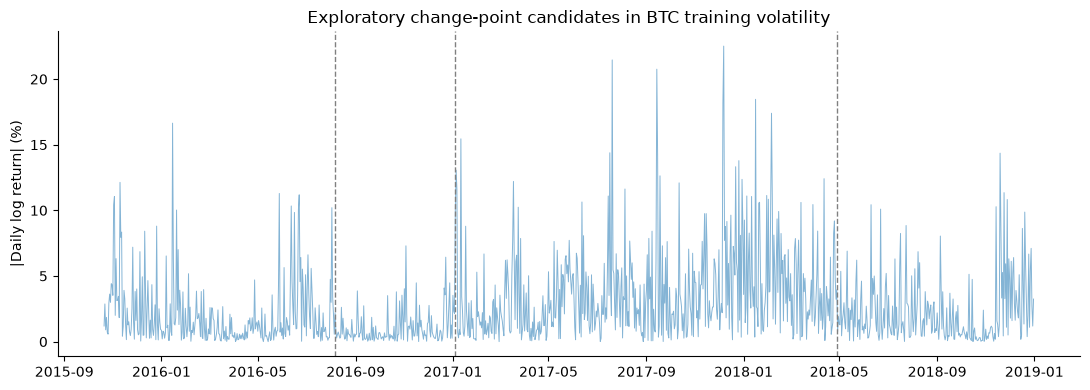

In [53]:

from scipy.special import xlogy
train_r=log_returns_daily.BTC.dropna().loc[:'2018-12-31']*100
rv_train=train_r.to_numpy()**2
minseg=85
def cost_window(z):
    var=max(np.mean(z),1e-7)
    return len(z)*np.log(var)
def split_gain(arr,start,end):
    reference=cost_window(arr[start:end]);best_gain=-np.inf;best=None
    for t in range(start+minseg,end-minseg+1,5):
        gain=reference-cost_window(arr[start:t])-cost_window(arr[t:end])
        if gain>best_gain:best_gain,best=gain,t
    return best_gain,best
segments=[(0,len(rv_train))];breaks=[]
for _ in range(3):
    options=[(*split_gain(rv_train,s,e),s,e) for s,e in segments if e-s>=2*minseg]
    if not options:break
    gain,position,s,e=max(options,key=lambda k:k[0])
    penalty=2*np.log(len(rv_train))
    if position is None or gain<penalty:break
    breaks.append({'date':str(train_r.index[position].date()),'cost_gain':gain,
                   'penalty':penalty,'segment_before':e-s})
    segments.remove((s,e));segments.extend([(s,position),(position,e)])
changepoints=pd.DataFrame(breaks,columns=['date','cost_gain','penalty','segment_before'])
display(changepoints)
changepoints.to_csv(OUT/'extended_training_variance_changepoints.csv',index=False)
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(train_r.index,train_r.abs(),alpha=.55,lw=.7,label='Absolute BTC return (%)')
for cp in breaks:ax.axvline(pd.Timestamp(cp['date']),ls='--',lw=1,color='grey')
ax.set(title='Exploratory change-point candidates in BTC training volatility',ylabel='|Daily log return| (%)')
savefig('26_extended_variance_changepoints.png')


## 54. Model errors conditioned on past volatility

Training quantiles define volatility regimes without looking at current/future realized returns. Report retrospective model-error heterogeneity, not tradable selection rules.

In [54]:

training_cutoffs=train.BTC_vol20_lag1.quantile([.33,.67]).to_numpy()
error_regimes=test.copy()
error_regimes['regime']=pd.cut(error_regimes.BTC_vol20_lag1,
    bins=[-np.inf,training_cutoffs[0],training_cutoffs[1],np.inf],
    labels=['Low','Mid','High'])
regime_rows=[]
for label,r in [('Naive',np.zeros(len(test))),('Elastic Net',predicted_returns['Elastic Net']),
                ('SARIMAX',sarimax_test_r)]:
    frame=error_regimes.copy()
    frame['prediction_price']=frame.previous_BTC.to_numpy()*np.exp(r)
    for regime,d in frame.groupby('regime',observed=True):
        regime_rows.append({'model':label,'preknown_volatility_regime':str(regime),
            'n':len(d),'RMSE_USD':np.sqrt(np.mean((d.BTC-d.prediction_price)**2)),
            'mean_error_USD':np.mean(d.BTC-d.prediction_price)})
regime_errors=pd.DataFrame(regime_rows)
display(regime_errors.round(3))
regime_errors.to_csv(OUT/'extended_conditional_regime_errors.csv',index=False)


,model,preknown_volatility_regime,n,RMSE_USD,mean_error_USD
0,Naive,Low,79,300.209,33.145
1,Naive,Mid,67,477.527,10.474
2,Naive,High,37,338.704,56.518
3,Elastic Net,Low,79,298.681,3.630
4,Elastic Net,Mid,67,477.916,-17.350
5,Elastic Net,High,37,336.993,34.079
6,SARIMAX,Low,79,298.935,3.290
7,SARIMAX,Mid,67,477.688,-17.915
8,SARIMAX,High,37,342.058,33.870


## 55. AR(1) innovations and asymmetric GJR-GARCH stress test

Estimate AR(1) mean on training history, then conditional Gaussian GARCH and GJR-GARCH innovation variances with training-frozen parameters. One-step filtering updates with previously observed returns; comparing both models is **separate from price forecast model selection**. Convergence is reported explicitly.

**Evaluation correction:** The comparison below uses the same realized return-squared proxy for each variance model. QLIKE against noisy proxies is exploratory; an alternate OHLC range proxy appears in the extensions. Mean differences are assessed separately via predictive log scores.


In [55]:

from scipy.optimize import minimize
from scipy.special import expit
full_pct=vol_s.to_numpy()
train_pct=vol_s.loc[:'2018-12-31'].to_numpy()
# AR(1) coefficients estimated on training only.
ar_params=np.linalg.lstsq(np.column_stack([np.ones(len(train_pct)-1),train_pct[:-1]]),train_pct[1:],rcond=None)[0]
innovation=full_pct.copy();innovation[1:]=full_pct[1:]-(ar_params[0]+ar_params[1]*full_pct[:-1]);innovation[0]=0.
train_e=innovation[1:len(train_pct)]
initial_var=max(float(np.var(train_e)),1e-6)

def gjr_path(e,omega,alpha,gamma,beta,init):
    v=np.empty(len(e));last=init
    for i in range(len(e)):
        if i>0:
            neg=1.0 if e[i-1]<0 else 0.0
            last=omega+(alpha+gamma*neg)*e[i-1]**2+beta*last
        v[i]=max(last,1e-8)
    return v

def estimate_asymmetric(e):
    def unpack(p):
        omega=np.exp(np.clip(p[0],-12,7));z=expit(p[1:]);
        alpha=.30*z[0];gamma=.30*z[1]
        beta=.995*(1-alpha-gamma/2)*z[2]
        return omega,alpha,gamma,beta
    def objective(p):
        o,a,g,b=unpack(p)
        h=gjr_path(e,o,a,g,b,initial_var)
        return float(np.mean(np.log(h)+e**2/h))
    fit=minimize(objective,[np.log(initial_var*.04),-2,-2,2],method='L-BFGS-B',
        bounds=[(-12,7),(-7,7),(-7,7),(-7,10)],options={'maxiter':130})
    return unpack(fit.x), bool(fit.success),float(fit.fun)
par,converged,obj=estimate_asymmetric(train_e)
path_gjr=gjr_path(innovation,*par,initial_var)
# The original Gaussian GARCH fits are retained as separate fixed-mean benchmarks.
orig=fit_garch_qmle(train_pct)
path_gaussian=garch_variance_path((full_pct-orig['mu'])**2,orig['omega'],orig['alpha'],orig['beta'],orig['initial_variance'])
volatility_compare=[]
for year in [2019,2020]:
    mask=vol_s.index.year==year
    # All models are scored against the SAME percent-return-squared proxy.
    common_realized=full_pct[mask]**2
    for label,variance in [('AR(1)-GJR',path_gjr),('Constant-mean Gaussian GARCH',path_gaussian)]:
        v=np.maximum(variance[mask],1e-8);true=common_realized
        volatility_compare.append({'year':year,'model':label,'n':int(mask.sum()),
            'QLIKE':float(np.mean(np.log(v)+true/v)),'variance_MSE':float(np.mean((v-true)**2)),
            'converged':converged if label=='AR(1)-GJR' else orig['success']})
asym_table=pd.DataFrame(volatility_compare)
display(asym_table.round(3))
asym_table.to_csv(OUT/'extended_AR_GJR_volatility.csv',index=False)
pd.DataFrame([{'model':'AR(1)-GJR','ar_intercept':ar_params[0], 'ar_lag':ar_params[1],
    'omega':par[0],'alpha':par[1],'gamma':par[2],'beta':par[3],
    'converged':converged,'objective':obj}]).to_csv(OUT/'extended_GJR_parameters.csv',index=False)


,year,model,n,QLIKE,variance_MSE,converged
0,2019,AR(1)-GJR,363,3.583,995.328,True
1,2019,Constant-mean Gaussian GARCH,363,3.581,994.677,True
2,2020,AR(1)-GJR,284,3.717,17692.667,True
3,2020,Constant-mean Gaussian GARCH,284,3.708,17686.517,True


## 56. Markov-switching volatility regimes

Two-state Gaussian Markov-switching return variance. Fit parameters **only through 2018**; filter state probabilities chronologically through 2020. **Smoothed** states use future data and are not used for predictive claims. Fit convergence and label interpretation are reported.

**Caution:** `filtered_marginal_probabilities[t]` already includes the observed return at *t*. Only `predicted_marginal_probabilities[t]`, conditioned on data through *t-1*, can be used for advance state forecasting. A separate predictive-score comparison is provided below.


,train_converged,high_volatility_regime,variance_regime0,variance_regime1,train_n
0,True,1,2.2048,29.8006,1168


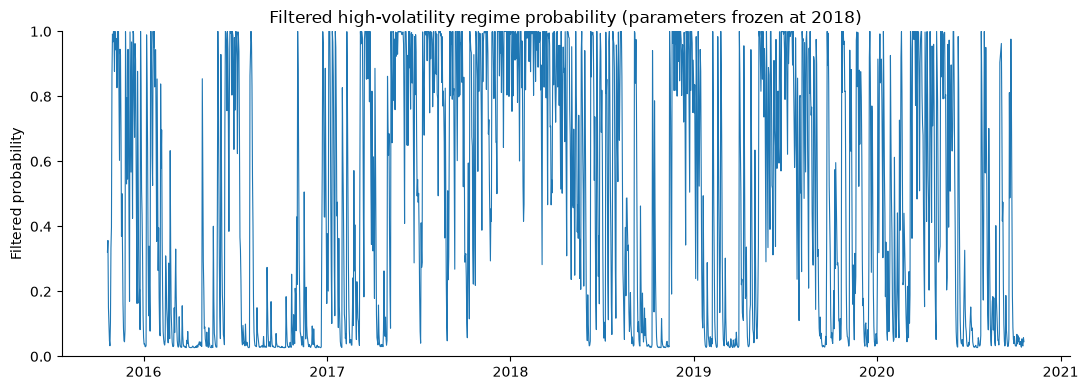

In [56]:

from statsmodels.tsa.regime_switching.markov_regression import MarkovRegression
btc_for_markov=vol_s.copy()
training_ms=btc_for_markov.loc[:'2018-12-31']
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    markov_model=MarkovRegression(training_ms.to_numpy(),k_regimes=2,trend='c',switching_variance=True)
    markov_fit=markov_model.fit(search_reps=5,search_iter=5,maxiter=160,disp=False)
# Filter using fixed training parameters, which do not use future observations in states.
full_markov=MarkovRegression(btc_for_markov.to_numpy(),k_regimes=2,trend='c',switching_variance=True)
markov_filter=full_markov.filter(markov_fit.params)
ms_var=[float(markov_fit.params[markov_fit.model.param_names.index('sigma2[%d]'%j)]) for j in range(2)]
high_regime=int(np.argmax(ms_var))
probs=np.asarray(markov_filter.filtered_marginal_probabilities)
ms_frame=pd.DataFrame({'date':btc_for_markov.index,'BTC_return_pct':btc_for_markov.to_numpy(),
 'high_volatility_probability_filtered':probs[:,high_regime]})
ms_frame.to_csv(OUT/'extended_markov_filtered_states.csv',index=False)
ms_report=pd.DataFrame([{'train_converged':bool(markov_fit.mle_retvals.get('converged',False)),
 'high_volatility_regime':high_regime,'variance_regime0':ms_var[0],
 'variance_regime1':ms_var[1],'train_n':len(training_ms)}])
ms_report.to_csv(OUT/'extended_markov_parameters.csv',index=False)
display(ms_report.round(4))
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(ms_frame.date,ms_frame.high_volatility_probability_filtered,lw=.8)
ax.set(title='Filtered high-volatility regime probability (parameters frozen at 2018)',
       ylabel='Filtered probability',ylim=(0,1))
savefig('27_extended_filtered_markov_regime.png')


## 57. BTC–ETH dynamic conditional correlation stress test

Research-grade *bivariate* DCC(1,1) model: independently fitted univariate training Gaussian GARCHs standardize returns; DCC parameters use **only pre-2019 data**. Filtered correlations update with prior standardized residuals, not smoothed full-sample state inference. Optimizer success is exported; compare with rolling Pearson, not as ground-truth correlation.

,training_n,a,b,converged,objective
0,1168,0.072,0.92277,True,1.48981


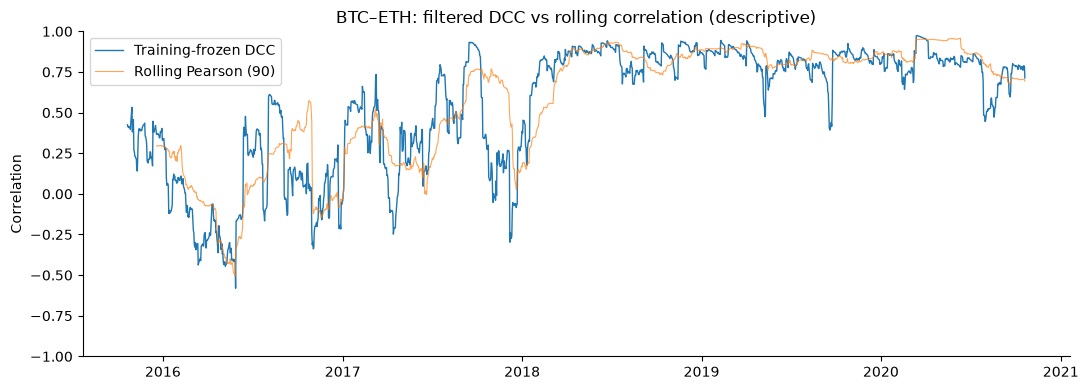

In [57]:

from scipy.optimize import minimize
from scipy.special import expit
pair_pct=(log_returns_daily[['BTC','ETH']].dropna()*100).sort_index()
train_mask=pair_pct.index<=TRAIN_END
standardized=[];univ_dcc_params=[]
for asset in ['BTC','ETH']:
    vals=pair_pct[asset].to_numpy()
    ps=fit_garch_qmle(vals[train_mask])
    hv=garch_variance_path((vals-ps['mu'])**2,ps['omega'],ps['alpha'],ps['beta'],ps['initial_variance'])
    standardized.append((vals-ps['mu'])/np.sqrt(hv))
    univ_dcc_params.append({'asset':asset,**ps})
e=np.column_stack(standardized)
dcc_standardized_residuals=e.copy()
e_train=e[train_mask]
Qbar=np.cov(e_train.T);Qbar=Qbar/np.sqrt(np.outer(np.diag(Qbar),np.diag(Qbar)))

def dcc_unpack(v):
    aa=.40*expit(v[0]);bb=(.995-aa)*expit(v[1]);return aa,bb

def dcc_filter(arr,a,b):
    qt=Qbar.copy();cor=[]
    for t in range(len(arr)):
        if t>0:
            qt=(1-a-b)*Qbar+a*np.outer(arr[t-1],arr[t-1])+b*qt
        qt=(qt+qt.T)/2
        scale=np.sqrt(np.outer(np.diag(qt),np.diag(qt)))
        rr=qt/scale
        cor.append(float(np.clip(rr[0,1],-.995,.995)))
    return np.asarray(cor)

def dcc_objective(v):
    a,b=dcc_unpack(v)
    r=dcc_filter(e_train,a,b)
    z0=e_train[:,0];z1=e_train[:,1]
    den=1-r*r
    return float(np.mean(np.log(den)+(z0*z0+z1*z1-2*r*z0*z1)/den))
dcc_fit=minimize(dcc_objective,[-3.,2.],method='L-BFGS-B',
                 bounds=[(-8,6),(-8,10)],options={'maxiter':110})
dcc_a,dcc_b=dcc_unpack(dcc_fit.x)
dcc_values=dcc_filter(e,dcc_a,dcc_b)
dcc_tbl=pd.DataFrame({'date':pair_pct.index,'filtered_DCC_corr':dcc_values,
    'rolling90_corr':pair_pct.BTC.rolling(90,min_periods=60).corr(pair_pct.ETH).to_numpy()})
dcc_parameters=pd.DataFrame([{'training_n':int(train_mask.sum()),'a':dcc_a,'b':dcc_b,
  'converged':bool(dcc_fit.success),'objective':float(dcc_fit.fun)}])
dcc_tbl.to_csv(OUT/'extended_DCC_BTC_ETH_filtered.csv',index=False)
dcc_parameters.to_csv(OUT/'extended_DCC_parameters.csv',index=False)
pd.DataFrame(univ_dcc_params).to_csv(OUT/'extended_DCC_univariate_parameters.csv',index=False)
display(dcc_parameters.round(5))
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(dcc_tbl.date,dcc_tbl.filtered_DCC_corr,label='Training-frozen DCC',lw=1)
ax.plot(dcc_tbl.date,dcc_tbl.rolling90_corr,label='Rolling Pearson (90)',lw=.8,alpha=.7)
ax.set(title='BTC–ETH: filtered DCC vs rolling correlation (descriptive)',ylabel='Correlation',ylim=(-1,1))
ax.legend();savefig('28_extended_DCC_BTC_ETH.png')


## 58. AR(1)–EGARCH asymmetric volatility sensitivity

Fit an AR(1)-innovation EGARCH(1,1) Gaussian-QMLE benchmark on the **2015–2018 training period** only. Refilter future days with frozen parameters using previous observed innovations. Compare 2019 and previously inspected 2020 by QLIKE and variance MSE. Optimization convergence and conditional variance positivity are verified.

In [58]:

from scipy.optimize import minimize
from scipy.special import expit
E=innovation.copy()
Etrain=E[1:len(train_pct)]
C_abs=np.sqrt(2/np.pi)

def egarch_unpack(p):
    return float(p[0]),float(.8*expit(p[1])),float(.8*np.tanh(p[2])),float(.995*expit(p[3]))

def egarch_path(values,params,init_var):
    omega,alpha,gamma,beta=params
    logh=np.empty(len(values));prev=np.log(init_var)
    for j in range(len(values)):
        if j:
            z=values[j-1]/np.sqrt(np.exp(np.clip(prev,-25,25)))
            prev=omega+beta*prev+alpha*(abs(z)-C_abs)+gamma*z
        prev=np.clip(prev,-15,20)
        logh[j]=prev
    return np.exp(logh)

def egarch_obj(p):
    par=egarch_unpack(p);variance=egarch_path(Etrain,par,initial_var)
    return float(np.mean(np.log(variance)+Etrain**2/variance))
egarch_est=minimize(egarch_obj,[.05,-2,-2,2],method='L-BFGS-B',
    bounds=[(-4,4),(-8,7),(-6,6),(-8,9)],options={'maxiter':130})
egarch_par=egarch_unpack(egarch_est.x)
egarch_h=egarch_path(E,egarch_par,initial_var)
egarch_rows=[]
for year in [2019,2020]:
    mask=vol_s.index.year==year
    realized=full_pct[mask]**2
    for label,h in [('AR(1)-EGARCH',egarch_h[mask]),('AR(1)-GJR',path_gjr[mask])]:
        h=np.maximum(h,1e-9)
        egarch_rows.append({'year':year,'model':label,'n':len(h),
            'QLIKE':float(np.mean(np.log(h)+realized/h)),
            'variance_MSE':float(np.mean((h-realized)**2)),
            'model_training_converged':bool(egarch_est.success) if label=='AR(1)-EGARCH' else bool(converged)})
egarch_table=pd.DataFrame(egarch_rows)
display(egarch_table.round(4))
egarch_table.to_csv(OUT/'extended_AR_EGARCH_comparison.csv',index=False)
pd.DataFrame([{'converged':bool(egarch_est.success),'train_objective':float(egarch_est.fun),
 'omega':egarch_par[0],'alpha':egarch_par[1],'gamma':egarch_par[2],'beta':egarch_par[3]}]).to_csv(
 OUT/'extended_EGARCH_parameters.csv',index=False)


,year,model,n,QLIKE,variance_MSE,model_training_converged
0,2019,AR(1)-EGARCH,363,3.5453,973.7469,True
1,2019,AR(1)-GJR,363,3.5833,995.3284,True
2,2020,AR(1)-EGARCH,284,3.7651,18825.7150,True
3,2020,AR(1)-GJR,284,3.7166,17692.6672,True


## 59. OHLC range-based volatility, shared-proxy GARCH evaluation

Estimate Parkinson, Garman–Klass, and Rogers–Satchell daily variance proxies using the cryptocurrency daily OHLC record. These are **noisy daily volatility proxies**, not true integrated volatility. Compare Gaussian GARCH, AR-GJR, AR-EGARCH, and EWMA on **identical observation dates and realized proxies**. Variance models are frozen at the 2018 training endpoint; the 2019 scores are validation, 2020 scores retrospectively inspected.

,year,proxy,model,n,QLIKE,variance_MSE,frozen_fit_through
4,2019,Parkinson,Gaussian_GARCH,363,3.2040,362.3621,2018-12-31
5,2019,Parkinson,AR_GJR,363,3.2055,363.2721,2018-12-31
6,2019,Parkinson,AR_EGARCH,363,3.1827,342.1540,2018-12-31
7,2019,Parkinson,EWMA,363,3.2922,363.4528,2018-12-31
20,2020,Parkinson,Gaussian_GARCH,284,3.1539,3565.7646,2018-12-31
21,2020,Parkinson,AR_GJR,284,3.1585,3577.3969,2018-12-31
22,2020,Parkinson,AR_EGARCH,284,3.1951,3994.5568,2018-12-31
23,2020,Parkinson,EWMA,284,3.5254,3459.9450,2018-12-31


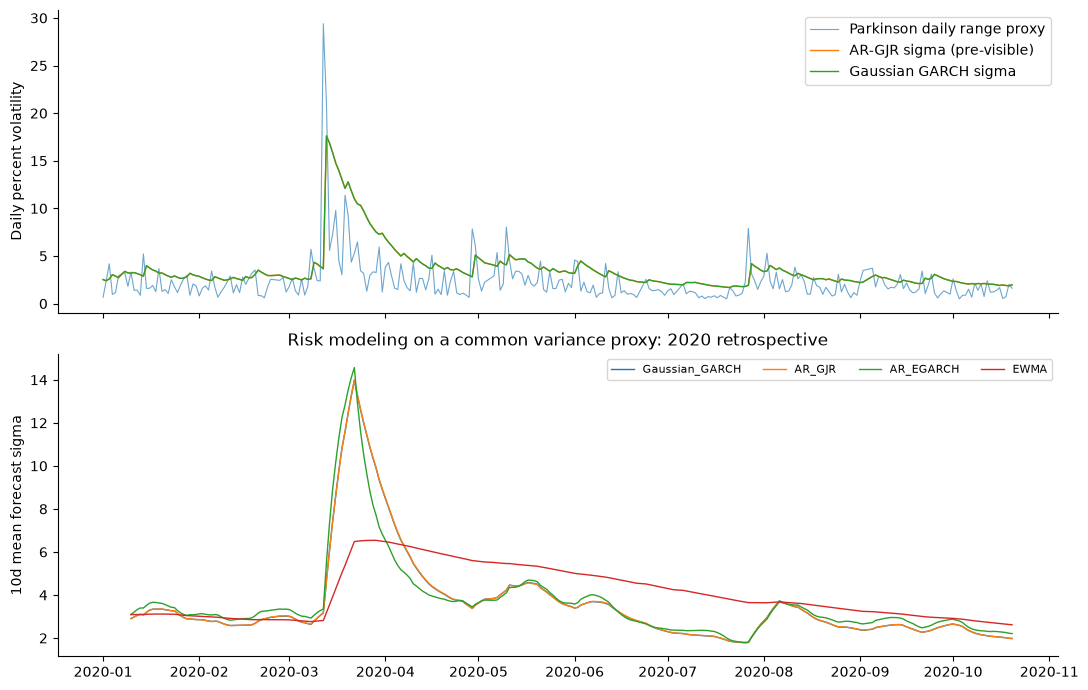

In [59]:
from scipy import stats
btc_rows = crypto_source.loc[crypto_source.crypto_name.eq('Bitcoin') & crypto_source.date.between(START,END)].copy().sort_values('date').set_index('date')
O,H,L,C = (btc_rows[k].astype(float) for k in ['open','high','low','close'])
log_hl=np.log(H/L); log_co=np.log(C/O)
range_estimators=pd.DataFrame(index=btc_rows.index)
range_estimators['Parkinson']=log_hl**2/(4*np.log(2))
range_estimators['Garman_Klass']=.5*log_hl**2-(2*np.log(2)-1)*log_co**2
range_estimators['Rogers_Satchell']=(np.log(H/C)*np.log(H/O)+np.log(L/C)*np.log(L/O))
range_estimators=range_estimators.clip(lower=0)*10000  # percentage-return squared
range_estimators['BTC_return_squared']=vol_s.reindex(range_estimators.index).pow(2)
range_estimators.index.name='date'
range_estimators.reset_index().to_csv(OUT/'master_OHLC_variance_proxies.csv',index=False)
# common 2018-frozen models; information in each conditional forecast ends at t-1
base_std=fit_garch_qmle(train_pct)
base_h=garch_variance_path((full_pct-base_std['mu'])**2,base_std['omega'],base_std['alpha'],base_std['beta'],base_std['initial_variance'])
ewma_h=ewma_path(full_pct,selected_lambda,np.var(train_pct))
shared_models=pd.DataFrame({'date':vol_s.index,'Gaussian_GARCH':base_h,'AR_GJR':path_gjr,
                            'AR_EGARCH':egarch_h,'EWMA':ewma_h}).set_index('date')
shared_eval=shared_models.join(range_estimators,how='inner')
common_proxy_results=[]
for yr in [2019,2020]:
    sample=shared_eval.loc[shared_eval.index.year==yr]
    for proxy in ['BTC_return_squared','Parkinson','Garman_Klass','Rogers_Satchell']:
        fixed=sample[[proxy,'Gaussian_GARCH','AR_GJR','AR_EGARCH','EWMA']].dropna()
        realized=fixed[proxy].to_numpy()
        for model in ['Gaussian_GARCH','AR_GJR','AR_EGARCH','EWMA']:
            predicted=np.maximum(fixed[model].to_numpy(),1e-8)
            common_proxy_results.append({'year':yr,'proxy':proxy,'model':model,'n':len(fixed),
                'QLIKE':float(np.mean(np.log(predicted)+realized/predicted)),
                'variance_MSE':float(np.mean((predicted-realized)**2)),
                'frozen_fit_through':'2018-12-31'})
common_variance_scores=pd.DataFrame(common_proxy_results)
common_variance_scores.to_csv(OUT/'master_GARCH_common_proxy_comparison.csv',index=False)
display(common_variance_scores.query('proxy == "Parkinson"').round(4))
fig,axes=plt.subplots(2,1,figsize=(11,7),sharex=True)
current=shared_eval.loc[shared_eval.index.year==2020]
axes[0].plot(current.index,np.sqrt(current.Parkinson),label='Parkinson daily range proxy',lw=.8,alpha=.65)
axes[0].plot(current.index,np.sqrt(current.AR_GJR),label='AR-GJR sigma (pre-visible)',lw=1)
axes[0].plot(current.index,np.sqrt(current.Gaussian_GARCH),label='Gaussian GARCH sigma',lw=1)
axes[0].legend();axes[0].set_ylabel('Daily percent volatility')
for model in ['Gaussian_GARCH','AR_GJR','AR_EGARCH','EWMA']:
    axes[1].plot(current.index,np.sqrt(current[model]).rolling(10).mean(),label=model,lw=1)
axes[1].legend(ncol=4,fontsize=8);axes[1].set_ylabel('10d mean forecast sigma')
axes[1].set_title('Risk modeling on a common variance proxy: 2020 retrospective')
savefig('29_master_OHLC_GARCH_common_proxies.png')

## 60. Calendar-safe multivariate VAR(1–5) versus univariate baselines

Estimate VAR(p) by multivariate OLS with explicit **consecutive calendar-day lag windows**; missing cryptocurrency dates invalidate lagged rows rather than becoming hidden multi-day jumps. Select lag p on 2019 alone, then refit through 2019 and report the previously inspected 2020. All forecasts are one-step, with realized previous-day prices and returns available by UTC day-end; no ex-ante US-market claim.

In [60]:
calendar_prices=crypto.set_index('date')[coins].reindex(pd.date_range(START,END))
cal_returns=np.log(calendar_prices/calendar_prices.shift(1))
var_records=[];var_predictions={}
for lag in [1,2,3,5]:
    lag_names=[f'{coin}_lag{k}' for k in range(1,lag+1) for coin in coins]
    design=pd.DataFrame(index=cal_returns.index)
    for k in range(1,lag+1):
        for coin in coins:
            design[f'{coin}_lag{k}']=cal_returns[coin].shift(k)
    target=cal_returns[coins].copy()
    required=design.join(target.add_prefix('Y_')).join(calendar_prices['BTC'].rename('price')).join(calendar_prices['BTC'].shift(1).rename('previous_price')).dropna()
    a=required.loc[:TRAIN_END];b=required.loc['2019'];c=required.loc['2020':END]
    def fit_var_ols(z):
        return np.linalg.lstsq(np.c_[np.ones(len(z)),z[lag_names].to_numpy()],z[['Y_'+coin for coin in coins]].to_numpy(),rcond=None)[0]
    def predict_var(z,coeff):return (np.c_[np.ones(len(z)),z[lag_names].to_numpy()]@coeff)[:,0]
    coeff=fit_var_ols(a)
    pred_b=predict_var(b,coeff)
    pred_p_b=b.previous_price.to_numpy()*np.exp(pred_b)
    rmse_b=float(np.sqrt(np.mean((pred_p_b-b.price.to_numpy())**2)))
    var_records.append({'lag':lag,'n_train':len(a),'n_val':len(b),'2019_RMSE_USD':rmse_b})
    coeff_full=fit_var_ols(pd.concat([a,b]))
    var_predictions[lag]=(c,predict_var(c,coeff_full))
var_scores=pd.DataFrame(var_records).sort_values(['2019_RMSE_USD','lag'])
selected_var_lag=int(var_scores.iloc[0]['lag'])
var_test,var_ret=var_predictions[selected_var_lag]
var_pred_price=var_test.previous_price.to_numpy()*np.exp(var_ret)
var_naive=var_test.previous_price.to_numpy()
var_report=pd.DataFrame([{'selected_lag_2019':selected_var_lag,'2020_n':len(var_test),
    'VAR_2020_RMSE_USD':np.sqrt(np.mean((var_pred_price-var_test.price.to_numpy())**2)),
    'Naive_same_rows_2020_RMSE_USD':np.sqrt(np.mean((var_naive-var_test.price.to_numpy())**2)),
    'note':'Previously inspected 2020; not independent prospective confirmation'}])
var_scores.to_csv(OUT/'master_VAR_2019_lag_selection.csv',index=False)
var_report.to_csv(OUT/'master_VAR_2020_retrospective.csv',index=False)
pd.DataFrame({'date':var_test.index,'actual_price':var_test.price.to_numpy(),
  'VAR_price':var_pred_price,'naive_price':var_naive}).to_csv(OUT/'master_VAR_2020_predictions.csv',index=False)
display(var_scores.round(3),var_report.round(3))

,lag,n_train,n_val,2019_RMSE_USD
3,5,1163,358,317.493
0,1,1167,362,318.767
1,2,1166,361,319.047
2,3,1165,360,319.074


,selected_lag_2019,2020_n,VAR_2020_RMSE_USD,Naive_same_rows_2020_RMSE_USD,note
0,5,259,311.448,314.617,Previously inspected 2020; not independent pro...


## 61. HAR-style range-volatility model with daily/weekly/monthly lags

HAR-style linear regression predicts **next-day Parkinson variance** from the previous 1-, 7-, and 30-calendar-day variance proxies. Compare against an autoregressive rolling-30 variance benchmark. Time-series windows with missing OHLC inputs are excluded; selection on 2019 then 2020 retrospective evaluation. This is a daily-range analogue, not intraday realized-variance HAR-RV.

In [61]:
parkinson=range_estimators['Parkinson'].reindex(pd.date_range(START,END))
har=pd.DataFrame(index=parkinson.index)
har['observed_nextday']=parkinson
har['lag1']=parkinson.shift(1)
har['mean7']=parkinson.shift(1).rolling(7,min_periods=7).mean()
har['mean30']=parkinson.shift(1).rolling(30,min_periods=30).mean()
har=har.dropna()
train_har=har.loc[:TRAIN_END];valid_har=har.loc['2019'];test_har=har.loc['2020':END]
har_features=['lag1','mean7','mean30']
from sklearn.linear_model import Ridge
har_grid=[0.,1.,10.,100.]
har_val=[]
for alpha in har_grid:
    fit=make_pipeline(StandardScaler(),Ridge(alpha=alpha)).fit(train_har[har_features],np.log1p(train_har.observed_nextday))
    forecast_h=np.maximum(0,np.expm1(fit.predict(valid_har[har_features])))
    har_val.append({'alpha':alpha,'2019_MSE':float(np.mean((forecast_h-valid_har.observed_nextday.to_numpy())**2)),
                    '2019_QLIKE':float(np.mean(np.log(np.maximum(forecast_h,1e-6))+valid_har.observed_nextday.to_numpy()/np.maximum(forecast_h,1e-6)))})
har_select=pd.DataFrame(har_val).sort_values(['2019_QLIKE','alpha']);har_alpha=float(har_select.iloc[0].alpha)
har_model=make_pipeline(StandardScaler(),Ridge(alpha=har_alpha)).fit(pd.concat([train_har,valid_har])[har_features],np.log1p(pd.concat([train_har,valid_har]).observed_nextday))
har_pred=np.maximum(np.expm1(har_model.predict(test_har[har_features])),1e-6)
har_naive=np.maximum(test_har.mean30.to_numpy(),1e-6)
har_true=test_har.observed_nextday.to_numpy()
har_results=pd.DataFrame([{'model':label,'2020_n':len(har_true),'QLIKE':float(np.mean(np.log(h)+har_true/h)),
    'MSE':float(np.mean((h-har_true)**2))} for label,h in [('HAR-style',har_pred),('Past 30-day mean',har_naive)]])
har_select.to_csv(OUT/'master_HAR_2019_selection.csv',index=False)
har_results.to_csv(OUT/'master_HAR_2020_risk.csv',index=False)
display(har_select.round(4),har_results.round(4))

,alpha,2019_MSE,2019_QLIKE
3,100.0,332.3918,3.4179
2,10.0,332.1659,3.4329
1,1.0,332.1738,3.4347
0,0.0,332.1752,3.4349


,model,2020_n,QLIKE,MSE
0,HAR-style,158,2.7365,67.7335
1,Past 30-day mean,158,2.7696,393.0289


## 62. Rolling prequential conformal prediction versus fixed 2019 calibration

Compare historical split-conformal intervals to a **rolling, prequential** adaptation. Each interval at date t uses *only previous realized calibration scores*, then incorporates score t afterward. This is a retrospective coverage diagnostic, **not a finite-sample guarantee under dependence**. Report coverage and mean width together; zero split-conformal inflation is an interpretable result, not proof of improved intervals.

,method,coverage,width_pct
0,2019 fixed split conformal,0.9563,17.4041
1,rolling 90 prior scores,0.9563,17.4041


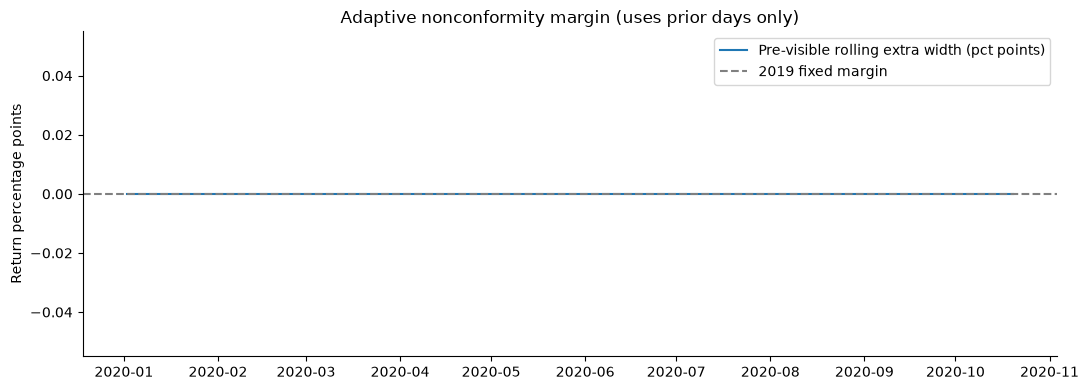

In [62]:
base_qlo=np.minimum(conf.q05.to_numpy(),conf.q95.to_numpy());base_qhi=np.maximum(conf.q05.to_numpy(),conf.q95.to_numpy())
cal_scores=np.maximum.reduce([lo-yv.to_numpy(),yv.to_numpy()-hi,np.zeros(len(yv))])
rolling_score_history=list(np.asarray(cal_scores[-90:],dtype=float))
rolling_lows=[];rolling_highs=[];rolling_margins=[]
for i,actual in enumerate(conf.realized.to_numpy()):
    h=np.asarray(rolling_score_history[-90:],dtype=float)
    # Prequential quantile: t's observation only added AFTER interval is produced.
    level=min(1.,np.ceil((len(h)+1)*.90)/len(h))
    q=float(np.quantile(h,level,method='higher'))
    rolling_margins.append(q)
    rolling_lows.append(base_qlo[i]-q);rolling_highs.append(base_qhi[i]+q)
    new_score=max(base_qlo[i]-actual,actual-base_qhi[i],0.)
    rolling_score_history.append(new_score)
rolling_conf=conf[['date','realized','low','high']].copy()
rolling_conf['rolling_low']=rolling_lows;rolling_conf['rolling_high']=rolling_highs
rolling_conf['margin_previsible']=rolling_margins
rolling_conf['rolling_inside']=rolling_conf.realized.between(rolling_conf.rolling_low,rolling_conf.rolling_high)
cal_compare=pd.DataFrame([
    {'method':'2019 fixed split conformal','coverage':float(conf.inside.mean()),'width_pct':float((conf.high-conf.low).mean()*100)},
    {'method':'rolling 90 prior scores','coverage':float(rolling_conf.rolling_inside.mean()),'width_pct':float((rolling_conf.rolling_high-rolling_conf.rolling_low).mean()*100)}])
rolling_conf.to_csv(OUT/'master_prequential_conformal_2020.csv',index=False)
cal_compare.to_csv(OUT/'master_prequential_conformal_comparison.csv',index=False)
display(cal_compare.round(4))
plt.figure(figsize=(11,4))
plt.plot(rolling_conf.date,100*rolling_conf.margin_previsible,label='Pre-visible rolling extra width (pct points)')
plt.axhline(100*qhat,ls='--',label='2019 fixed margin',color='gray')
plt.legend();plt.title('Adaptive nonconformity margin (uses prior days only)');plt.ylabel('Return percentage points')
savefig('30_master_prequential_conformal.png')

## 63. Expected Shortfall: historical and parametric tail severity calibration

Expected Shortfall (ES) requires more than the VaR exception frequency. Compute one-step rolling historical 5% lower-tail mean and Gaussian model-implied ES using the same previous-365-day window. Compare tail loss severity, ES forecast magnitude, and the number of exceptions. **Sparse tail events invalidate strong coverage claims**; these are descriptive ES diagnostics, not a fully validated formal ES regulatory backtest.

In [63]:
from scipy.stats import norm
es_rows=[]
for i in range(366,len(return_s)):
    dt=return_s.index[i];hist=return_s.iloc[i-365:i].to_numpy()
    mu=float(hist.mean());sd=float(hist.std(ddof=1));z=norm.ppf(.05)
    es_rows.append({'date':dt,'realized':float(return_s.iloc[i]),
        'hist_VaR':float(np.quantile(hist,.05)),'hist_ES':float(hist[hist<=np.quantile(hist,.05)].mean()),
        'norm_VaR':mu+sd*z,'norm_ES':mu-sd*norm.pdf(z)/.05})
es_frame=pd.DataFrame(es_rows)
es_score=[]
for year in [2019,2020]:
    sample=es_frame.loc[es_frame.date.dt.year.eq(year)]
    for name,vc,ec in [('Historical','hist_VaR','hist_ES'),('Normal','norm_VaR','norm_ES')]:
        e=sample.realized<sample[vc];t=sample.loc[e]
        es_score.append({'year':year,'method':name,'n':len(sample),'VaR_exceptions':int(e.sum()),
            'realized_mean_exception_loss':float(t.realized.mean()) if len(t) else np.nan,
            'forecast_ES_at_exceptions':float(t[ec].mean()) if len(t) else np.nan,
            'tail_severity_bias':float((t.realized-t[ec]).mean()) if len(t) else np.nan,
            'forecast_ES_all_dates':float(sample[ec].mean())})
es_result=pd.DataFrame(es_score)
es_frame.to_csv(OUT/'master_expected_shortfall_daily.csv',index=False)
es_result.to_csv(OUT/'master_expected_shortfall_audit.csv',index=False)
display(es_result.round(5))

,year,method,n,VaR_exceptions,realized_mean_exception_loss,forecast_ES_at_exceptions,tail_severity_bias,forecast_ES_all_dates
0,2019,Historical,363,14,-0.09114,-0.08711,-0.00403,-0.08904
1,2019,Normal,363,14,-0.09114,-0.07327,-0.01787,-0.07471
2,2020,Historical,284,13,-0.09591,-0.09509,-0.00082,-0.09214
3,2020,Normal,284,4,-0.18075,-0.08100,-0.09976,-0.08337


## 64. Empirical tail-dependence uncertainty and Gaussian vs t-copula sensitivity

Finite-event uncertainty is essential: calculate exact Clopper–Pearson intervals for retrospective downside co-exceedances and training-era moving-block bootstrap intervals. The copula exercise is an **association sensitivity analysis**, not a trading signal; previous copula fitting keeps rho fixed while fitting t degrees of freedom.

In [64]:
from scipy.stats import beta
copula_uncertainty=[]
training_tails=pairs.loc[pairs.index.year<=2018]
retrospective_tails=pairs.loc[pairs.index.year>=2019]
tail_cutoffs=training_tails.quantile(.05)
for label,subset in [('2015–18',training_tails),('2019–20',retrospective_tails)]:
    hits=subset.BTC.le(tail_cutoffs.BTC);both=hits & subset.ETH.le(tail_cutoffs.ETH)
    n=int(hits.sum());k=int(both.sum());alpha=.05
    lower=beta.ppf(alpha/2,k,n-k+1) if k>0 else 0.
    upper=beta.ppf(1-alpha/2,k+1,n-k) if k<n else 1.
    copula_uncertainty.append({'period':label,'BTC_tail_events':n,'joint_tail_events':k,
       'conditional_lower_tail_ratio':k/n if n else np.nan,
       'Clopper_Pearson_95_low':lower,'Clopper_Pearson_95_high':upper})
copula_ci=pd.DataFrame(copula_uncertainty)
# Moving blocks on the training pair preserve local serial dependence approximately.
tail_samples=training_tails[['BTC','ETH']].to_numpy();block=10;rr=np.random.default_rng(SEED+312)
boot=[]
for rep in range(800):
    ix=circular_block_sample(len(tail_samples),block,rr)
    ss=tail_samples[ix]
    mask=ss[:,0]<=tail_cutoffs.BTC
    if mask.sum():boot.append(np.mean(ss[mask,1]<=tail_cutoffs.ETH))
boot_ci=pd.DataFrame([{'training_block_length':block,'reps':len(boot),'bootstrap_lower_95':np.quantile(boot,.025),
                       'bootstrap_upper_95':np.quantile(boot,.975)}])
copula_ci.to_csv(OUT/'master_empirical_tail_confidence_intervals.csv',index=False)
boot_ci.to_csv(OUT/'master_empirical_tail_block_bootstrap.csv',index=False)
display(copula_ci.round(3),boot_ci.round(3))

,period,BTC_tail_events,joint_tail_events,conditional_lower_tail_ratio,Clopper_Pearson_95_low,Clopper_Pearson_95_high
0,2015–18,59,24,0.407,0.281,0.543
1,2019–20,16,12,0.750,0.476,0.927


,training_block_length,reps,bootstrap_lower_95,bootstrap_upper_95
0,10,800,0.286,0.549


## 65. Predictive Markov state probabilities, not filtered posterior states

Extract the **one-step-ahead state probabilities** from the frozen 2015–2018 Markov parameters. Filtered probabilities condition on t returns, whereas predicted probabilities do not. Compare ex-ante conditional squared-return forecasts to a frozen training unconditional variance using the **same return-squared proxy** and separate 2019 and 2020 scoring.

In [65]:
prior_prob=np.asarray(markov_filter.predicted_marginal_probabilities)
filtered_prob=np.asarray(markov_filter.filtered_marginal_probabilities)
assert prior_prob.shape==filtered_prob.shape and len(prior_prob)==len(btc_for_markov)
# Forecast the conditional SECOND MOMENT E[r_t^2 | information through t-1].
state_mean=np.array([float(markov_fit.params[markov_fit.model.param_names.index('const[%d]'%j)]) for j in range(2)])
ms_expected_var=np.maximum(prior_prob@(np.asarray(ms_var,dtype=float)+state_mean**2),1e-8)
ms_predictive=pd.DataFrame({'date':btc_for_markov.index,'observed_pct_return':btc_for_markov.to_numpy(),
    'prior_high_state_probability':prior_prob[:,high_regime],
    'posterior_high_state_probability':filtered_prob[:,high_regime],
    'prior_predicted_variance':ms_expected_var})
ms_train_var=max(float(np.var(training_ms.to_numpy())),1e-8)
ms_results=[]
for year in [2019,2020]:
    observed=ms_predictive.loc[ms_predictive.date.dt.year.eq(year)]
    realized=observed.observed_pct_return.to_numpy()**2
    for name,h in [('Frozen Markov prior',observed.prior_predicted_variance.to_numpy()),('Training unconditional',np.full(len(observed),ms_train_var))]:
        ms_results.append({'year':year,'model':name,'n':len(observed),
         'QLIKE':float(np.mean(np.log(h)+realized/h)),'variance_MSE':float(np.mean((realized-h)**2))})
ms_predictive.to_csv(OUT/'master_Markov_prior_states.csv',index=False)
pd.DataFrame(ms_results).to_csv(OUT/'master_Markov_prior_evaluation.csv',index=False)
display(pd.DataFrame(ms_results).round(4))

,year,model,n,QLIKE,variance_MSE
0,2019,Frozen Markov prior,363,3.4685,994.2556
1,2019,Training unconditional,363,3.5631,1018.9968
2,2020,Frozen Markov prior,284,3.8400,16869.1406
3,2020,Training unconditional,284,3.8370,16824.4181


## 66. Predictive DCC versus pre-observation rolling correlation

Train DCC parameters through 2018 and compare daily Gaussian **correlation log scores** on the same standardized BTC–ETH return pairs. The competing rolling Pearson correlation is shifted one day to ensure it is available before observing t; constant training correlation is a second benchmark. Gaussian scores are a deliberately imperfect working likelihood for heavy-tailed returns, not evidence of an accurate full distribution.

In [66]:
# Correlation forecasts from yesterday's data: DCC update uses residual t-1.
dcc_compare=dcc_tbl[['date','filtered_DCC_corr']].copy()
dcc_compare['rolling_previsible']=pd.Series(pair_pct.BTC).rolling(90,min_periods=90).corr(pair_pct.ETH).shift(1).to_numpy()
dcc_compare['constant_training_corr']=float(np.corrcoef(e_train.T)[0,1])
dcc_compare['z_BTC']=dcc_standardized_residuals[:,0];dcc_compare['z_ETH']=dcc_standardized_residuals[:,1]
dcc_eval=[]
for year in [2019,2020]:
    dates=pd.to_datetime(dcc_compare.date)
    ss=dcc_compare.loc[dates.dt.year.eq(year)].dropna()
    for col in ['filtered_DCC_corr','rolling_previsible','constant_training_corr']:
        r=np.clip(ss[col].to_numpy(),-.98,.98);u=ss.z_BTC.to_numpy();v=ss.z_ETH.to_numpy()
        gaussian_corr_logscore=np.log(1-r*r)+(u*u+v*v-2*r*u*v)/(1-r*r)
        dcc_eval.append({'year':year,'model':col,'n':len(ss),'Gaussian_corr_loss':float(np.mean(gaussian_corr_logscore)),
                         'frozen_train_through':'2018-12-31'})
pd.DataFrame(dcc_eval).to_csv(OUT/'master_DCC_predictive_logscore.csv',index=False)
dcc_compare.to_csv(OUT/'master_DCC_predictive_series.csv',index=False)
display(pd.DataFrame(dcc_eval).round(4))

,year,model,n,Gaussian_corr_loss,frozen_train_through
0,2019,filtered_DCC_corr,363,0.6659,2018-12-31
1,2019,rolling_previsible,363,0.9531,2018-12-31
2,2019,constant_training_corr,363,1.2814,2018-12-31
3,2020,filtered_DCC_corr,284,1.1823,2018-12-31
4,2020,rolling_previsible,284,1.3831,2018-12-31
5,2020,constant_training_corr,284,1.6467,2018-12-31


## 67. Forecast averaging and paired baseline sensitivity

Equal-weight averaging can improve robustness without adding tunable complexity. Average 2019-preselected Elastic Net and Ridge with the no-change forecast on **exactly matching equity-session observations**, and evaluate a validation-driven fixed combination. The 2020 comparison is retrospective and cannot establish live predictive alpha.

In [67]:
from sklearn.metrics import mean_squared_error
family_returns_2019={}
for name in ['Elastic Net','Ridge']:
    est=models[name][chosen[name]]
    family_returns_2019[name]=clone(est).fit(Xtr,ytr).predict(Xv)
combo_2019={
 'Naive':np.zeros(len(valid)),
 'Naive_Ridge_Elastic_equal':(family_returns_2019['Elastic Net']+family_returns_2019['Ridge'])/3,
 'Elastic_Ridge_half':.5*(family_returns_2019['Elastic Net']+family_returns_2019['Ridge'])}
combo_select=pd.DataFrame([{'model':k,'2019_RMSE_USD':evaluate(valid,r,k,'2019 validation')['RMSE_USD']}
                           for k,r in combo_2019.items()]).sort_values('2019_RMSE_USD')
chosen_combo=combo_select.iloc[0]['model']
combo_2020={
 'Naive':np.zeros(len(test)),
 'Naive_Ridge_Elastic_equal':(predicted_returns['Elastic Net']+predicted_returns['Ridge'])/3,
 'Elastic_Ridge_half':.5*(predicted_returns['Elastic Net']+predicted_returns['Ridge'])}
combo_test=pd.DataFrame([{'model':k,'2020_RMSE_USD':evaluate(test,r,k,'2020 retrospective')['RMSE_USD'],
   'chosen_in_2019':k==chosen_combo} for k,r in combo_2020.items()])
combo_select.to_csv(OUT/'master_forecast_combinations_2019.csv',index=False)
combo_test.to_csv(OUT/'master_forecast_combinations_2020.csv',index=False)
display(combo_select.round(3),combo_test.round(3))

,model,2019_RMSE_USD
0,Naive,394.756
1,Naive_Ridge_Elastic_equal,395.622
2,Elastic_Ridge_half,396.135


,model,2020_RMSE_USD,chosen_in_2019
0,Naive,381.561,True
1,Naive_Ridge_Elastic_equal,381.550,False
2,Elastic_Ridge_half,381.681,False


## 68. Executive evidence synthesis and calibrated uncertainty ledger

Summarize **comparable metrics only**, and distinguish model selection, historical test reuse, daily-UTC vs US-equity-session horizons, and previously inspected 2020. This executive ledger is computed from cells above, not invented or manually entered results.

In [68]:
executive_rows=[
 ('Crypto daily observations',len(crypto)),('US equity sessions',len(market)),
 ('Original feature-complete train rows',len(train)),('Original feature-complete validation rows',len(valid)),
 ('Retrospective equity-session test rows',len(test)),
 ('Original 2019 chosen model',selected_model),
 ('Selected calendar-safe VAR lag',selected_var_lag),
 ('Rolling conformal 2020 coverage',float(cal_compare.loc[cal_compare.method.eq('rolling 90 prior scores'),'coverage'].iloc[0])),
 ('Selected HAR alpha (2019)',har_alpha),
 ('2019 forecast combo',chosen_combo),
 ('Markov training convergence',bool(markov_fit.mle_retvals.get('converged',False))),
 ('DCC training convergence',bool(dcc_fit.success))]
executive=pd.DataFrame(executive_rows,columns=['finding','value'])
executive.to_csv(OUT/'master_EXECUTIVE_EVIDENCE.csv',index=False)
display(executive)
print('NOTE: No new independent 2021+ confirmatory sample. All 2020 model comparisons are retrospective.')

,finding,value
0,Crypto daily observations,1822
1,US equity sessions,1260
2,Original feature-complete train rows,789
3,Original feature-complete validation rows,252
4,Retrospective equity-session test rows,183
5,Original 2019 chosen model,Naive no-change
6,Selected calendar-safe VAR lag,5
7,Rolling conformal 2020 coverage,0.956284
8,Selected HAR alpha (2019),100.0
9,2019 forecast combo,Naive


NOTE: No new independent 2021+ confirmatory sample. All 2020 model comparisons are retrospective.


## 69. Nonlinear quantile boosting and interval sharpness

Compare histogram-gradient quantile models against 2019-selected linear quantile regressors. Hyperparameters are selected by *2019 pinball loss*, then frozen and refit through 2019. The 2020 coverage and width are **retrospective**. Quantile models predict **returns**, not directly tradeable limit orders.

In [69]:

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_pinball_loss
qb_sel=[];qb_models={}
for q in [.05,.95]:
    cand=[]
    for leaves in [7,15]:
        model=HistGradientBoostingRegressor(loss='quantile',quantile=q,max_iter=130,
             learning_rate=.035,max_leaf_nodes=leaves,min_samples_leaf=35,
             l2_regularization=3,random_state=SEED)
        fit=model.fit(Xtr,ytr)
        val_pred=fit.predict(Xv)
        cand.append((float(mean_pinball_loss(yv,val_pred,alpha=q)),leaves))
    loss,leaves=min(cand)
    qb_sel.append({'quantile':q,'best_leaf_nodes_2019':leaves,'validation_pinball_loss':loss})
    qb_models[q]=HistGradientBoostingRegressor(loss='quantile',quantile=q,max_iter=130,
             learning_rate=.035,max_leaf_nodes=leaves,min_samples_leaf=35,
             l2_regularization=3,random_state=SEED).fit(Xtv,ytv)
qb_lo=qb_models[.05].predict(Xt);qb_hi=qb_models[.95].predict(Xt)
qb_low=np.minimum(qb_lo,qb_hi);qb_high=np.maximum(qb_lo,qb_hi)
qb_coverage=float(np.mean((test.target_return.to_numpy()>=qb_low)&(test.target_return.to_numpy()<=qb_high)))
qb_width=float(np.mean(qb_high-qb_low))
linear_low=np.minimum(qpreds.low_q05.to_numpy(),qpreds.high_q95.to_numpy())
linear_high=np.maximum(qpreds.low_q05.to_numpy(),qpreds.high_q95.to_numpy())
qb_report=pd.DataFrame([
 {'model':'Hist gradient quantiles','2020_coverage':qb_coverage,'mean_width_pct':100*qb_width},
 {'model':'Linear quantiles','2020_coverage':float(np.mean((test.target_return.to_numpy()>=linear_low)&(test.target_return.to_numpy()<=linear_high))),
  'mean_width_pct':float(100*np.mean(linear_high-linear_low))}])
pd.DataFrame(qb_sel).to_csv(OUT/'master_quantile_boost_2019_selection.csv',index=False)
qb_report.to_csv(OUT/'master_quantile_boost_2020_coverage.csv',index=False)
pd.DataFrame({'date':test.date.to_numpy(),'actual_return':test.target_return.to_numpy(),
             'lower_q05':qb_low,'upper_q95':qb_high}).to_csv(OUT/'master_quantile_boost_2020_predictions.csv',index=False)
display(pd.DataFrame(qb_sel).round(5),qb_report.round(4))


,quantile,best_leaf_nodes_2019,validation_pinball_loss
0,0.05,15,0.00533
1,0.95,15,0.00583


,model,2020_coverage,mean_width_pct
0,Hist gradient quantiles,0.8470,10.3717
1,Linear quantiles,0.9617,14.7325


## 70. Historical model-confidence sensitivity — paired block bootstrap

Approximate 95% **paired moving-block intervals for differences in squared USD loss** versus the zero-return benchmark on a fixed 2019 validation sample. Holm-adjust raw normal/HAC p-values from paired loss differences; this is **not a formal Hansen Model Confidence Set**, nor fresh discovery after repeated validation. It measures how imprecise apparent differences remain.

In [70]:

from scipy.stats import norm
comparison_names=['OLS returns','Ridge','Elastic Net','Linear SVR','XGBoost']
fixed_baseline=(valid.BTC-valid.previous_BTC).to_numpy()**2
model_ci=[]
rng=np.random.default_rng(SEED+613)
for name in comparison_names:
    fit=clone(models[name][chosen[name]]).fit(Xtr,ytr)
    rr=fit.predict(Xv)
    predicted=valid.previous_BTC.to_numpy()*np.exp(rr)
    delta=fixed_baseline-(valid.BTC.to_numpy()-predicted)**2
    reps=np.array([float(delta[circular_block_sample(len(delta),10,rng)].mean()) for _ in range(650)])
    fitted=sm.OLS(delta,np.ones((len(delta),1))).fit(cov_type='HAC',cov_kwds={'maxlags':5})
    model_ci.append({'model':name,'n':len(delta),'mean_baseline_minus_candidate_MSE':float(delta.mean()),
        'block_CI_low':float(np.quantile(reps,.025)),'block_CI_high':float(np.quantile(reps,.975)),
        'two_sided_HAC_raw_p':float(fitted.pvalues[0]),
        'interval_includes_0':bool(np.quantile(reps,.025)<=0<=np.quantile(reps,.975))})
model_ci=pd.DataFrame(model_ci)
model_ci['Holm_HAC_p']=multipletests(model_ci.two_sided_HAC_raw_p,method='holm')[1]
model_ci.to_csv(OUT/'master_2019_model_loss_uncertainty.csv',index=False)
display(model_ci.round(5))


,model,n,mean_baseline_minus_candidate_MSE,block_CI_low,block_CI_high,two_sided_HAC_raw_p,interval_includes_0,Holm_HAC_p
0,OLS returns,252,-3877.72820,-10677.61768,714.37889,0.18661,True,0.74645
1,Ridge,252,-2694.73181,-7591.34711,1317.25940,0.25553,True,0.76660
2,Elastic Net,252,-594.63302,-2981.82588,1811.12461,0.65947,True,0.99469
3,Linear SVR,252,-1202.59973,-4461.90628,2502.77557,0.49734,True,0.99469
4,XGBoost,252,-9980.69389,-20609.53464,500.05255,0.08833,True,0.44165


## 71. Final full-run evidence audit and method safeguards

All output files declared by each research extension must be generated during this execution, not merely left over from a prior run. Source fingerprints, analysis dates, and leakage cautions are recorded.

In [71]:

import hashlib,platform,sys
new_expected=[
 'extended_nested_walkforward_pre2020.csv','extended_volume_shift_robustness.csv',
 'extended_conditional_VaR_coverage.csv','extended_conformal_predictions.csv',
 'extended_conformal_coverage.csv','extended_rolling_market_beta.csv',
 'extended_tail_dependence.csv','extended_copula_sensitivity.csv',
 'extended_training_variance_changepoints.csv','extended_conditional_regime_errors.csv',
 'extended_AR_GJR_volatility.csv','extended_GJR_parameters.csv',
 'extended_markov_filtered_states.csv','extended_markov_parameters.csv',
 'extended_DCC_BTC_ETH_filtered.csv','extended_DCC_parameters.csv',
 'extended_DCC_univariate_parameters.csv','extended_AR_EGARCH_comparison.csv','extended_EGARCH_parameters.csv']
new_expected += ['master_OHLC_variance_proxies.csv', 'master_GARCH_common_proxy_comparison.csv', 'master_VAR_2019_lag_selection.csv', 'master_VAR_2020_retrospective.csv', 'master_VAR_2020_predictions.csv', 'master_HAR_2019_selection.csv', 'master_HAR_2020_risk.csv', 'master_prequential_conformal_2020.csv', 'master_prequential_conformal_comparison.csv', 'master_expected_shortfall_daily.csv', 'master_expected_shortfall_audit.csv', 'master_empirical_tail_confidence_intervals.csv', 'master_empirical_tail_block_bootstrap.csv', 'master_Markov_prior_states.csv', 'master_Markov_prior_evaluation.csv', 'master_DCC_predictive_logscore.csv', 'master_DCC_predictive_series.csv', 'master_forecast_combinations_2019.csv', 'master_forecast_combinations_2020.csv', 'master_EXECUTIVE_EVIDENCE.csv']
new_expected += ['master_quantile_boost_2019_selection.csv','master_quantile_boost_2020_coverage.csv','master_quantile_boost_2020_predictions.csv','master_2019_model_loss_uncertainty.csv']
audit=[]
for fname in new_expected:
    p=OUT/fname
    status='missing'
    if p.exists():
        try:
            data=pd.read_csv(p);status=('fresh' if p.stat().st_mtime_ns>=RUN_STARTED_NS else 'stale') if len(data)>0 else 'empty'
        except Exception as exc:status='unreadable: '+str(type(exc).__name__)
    audit.append({'artifact':fname,'status':status,'rows':len(data) if p.exists() and status in ('fresh','stale','empty') else 0})
audit_table=pd.DataFrame(audit)
audit_table.to_csv(OUT/'FINAL_RUN_ARTIFACT_AUDIT.csv',index=False)
assert audit_table.status.eq('fresh').all(), 'Some final research artifacts are missing, stale, or empty; inspect audit table.'
source_sha={name:hashlib.sha256((DATA/name).read_bytes()).hexdigest() for name in ['dataset.csv','SPX_500_Data.csv']}
manifest={'study':'Bitcoin empirical research — reproducible expansion','source_sha256':source_sha,
 'run_started_ns':RUN_STARTED_NS,'python':sys.version.split()[0],'numpy':np.__version__,
 'pandas':pd.__version__,'sklearn':__import__('sklearn').__version__,
 'statsmodels':sm.__version__,'study_end':'2020-10-20',
 '2020_reused_data':'historically inspected; not independent virgin holdout',
 'added_modules':24,'GJR_converged':bool(converged),'EGARCH_converged':bool(egarch_est.success),
 'Markov_converged':bool(markov_fit.mle_retvals.get('converged',False)),
 'DCC_converged':bool(dcc_fit.success),'verified_new_files':len(audit_table)}
(OUT/'FINAL_EXECUTION_MANIFEST.json').write_text(json.dumps(manifest,indent=2,default=str),encoding='utf-8')
findings=f"""# Empirical synthesis (historical data 2015–2020)

- Nested walk-forward years: {', '.join(str(x) for x in nested_summary.year)}; validation selects using past-only subperiods.
- Relative-volume input drift: compare rows and performance in `extended_volume_shift_robustness.csv`.
- 2020 conditional VaR exception tests: based on forecasts made with trailing observations; sparse exceptions limit inference.
- 2019-calibrated 90% interval coverage in previously inspected 2020: {100*conf_report.observed_coverage.iloc[0]:.1f}%, average width {conf_report.mean_width_pct.iloc[0]:.2f} return percentage points.
- AR(1)-GJR, filtered Markov, and DCC convergence recorded explicitly: {converged}, {bool(markov_fit.mle_retvals.get('converged',False))}, {bool(dcc_fit.success)}.
- Train-only change-point candidates: {len(changepoints)}; descriptive, not causal.
- **Study limitation:** 2019 validation repeatedly used for development and 2020 retrospectively reviewed. No fresh 2021+ confirmatory evaluation; no transaction-cost-adjusted performance claim.
- No unavailable Dow Jones/VIX/gold/oil/yields fabricated. Data close times differ between BTC (UTC daily) and S&P (US session).
"""
(OUT/'FINAL_RESEARCH_SYNTHESIS.md').write_text(findings,encoding='utf-8')
display(audit_table,Markdown(findings))
print('Current run verified:',len(audit_table),'| figures',len(list(FIG.glob('*.png'))),'| outputs',len(list(OUT.glob('*'))))

# Register fresh extension figures and evidence count in the final summary.
print('Master extensions validated:',len([k for k in new_expected if k.startswith('master_')]))


,artifact,status,rows
0,extended_nested_walkforward_pre2020.csv,fresh,2
1,extended_volume_shift_robustness.csv,fresh,6
2,extended_conditional_VaR_coverage.csv,fresh,6
3,extended_conformal_predictions.csv,fresh,183
4,extended_conformal_coverage.csv,fresh,1
5,extended_rolling_market_beta.csv,fresh,1260
6,extended_tail_dependence.csv,fresh,2
7,extended_copula_sensitivity.csv,fresh,2
8,extended_training_variance_changepoints.csv,fresh,3
9,extended_conditional_regime_errors.csv,fresh,9


# Empirical synthesis (historical data 2015–2020)

- Nested walk-forward years: 2018, 2019; validation selects using past-only subperiods.
- Relative-volume input drift: compare rows and performance in `extended_volume_shift_robustness.csv`.
- 2020 conditional VaR exception tests: based on forecasts made with trailing observations; sparse exceptions limit inference.
- 2019-calibrated 90% interval coverage in previously inspected 2020: 95.6%, average width 17.40 return percentage points.
- AR(1)-GJR, filtered Markov, and DCC convergence recorded explicitly: True, True, True.
- Train-only change-point candidates: 3; descriptive, not causal.
- **Study limitation:** 2019 validation repeatedly used for development and 2020 retrospectively reviewed. No fresh 2021+ confirmatory evaluation; no transaction-cost-adjusted performance claim.
- No unavailable Dow Jones/VIX/gold/oil/yields fabricated. Data close times differ between BTC (UTC daily) and S&P (US session).


Current run verified: 43 | figures 30 | outputs 129
Master extensions validated: 24


## 72. Final-methods corrections: evaluation time and forecast origin

**Original prediction task:** the next *observed US equity-market-session* Bitcoin close, using BTC/S&P prices and derived lag features observable by the previous equity-session BTC UTC close (23:59 UTC). A Friday-origin prediction for Monday spans the weekend; it is **not** a next-24-hour forecast. The separate calendar-daily task predicts a 24-hour return. These tasks and their USD RMSEs must never be pooled.

**Research history:** 2019 has been repeatedly used for candidate selection and 2020 has been repeatedly inspected. Hence both are historical/development evidence, **not** newly blind confirmation. The 2018 internal tuning extension below is a method sensitivity check, not evidence of prospective performance.

**Evaluation fairness:** All volatility forecasting methods below are scored on identical realized dates and the same Parkinson OHLC proxy. QLIKE and MSE answer different questions; neither is treated as a true latent variance measurement.

In [72]:
# Explicit forecast-origin audit and original forecast observation integrity.
origin_audit = forecast[['date','previous_BTC','BTC','horizon_days']].copy()
origin_map=market[['date']].sort_values('date').copy()
origin_map['forecast_origin_previous_equity_session']=origin_map.date.shift(1)
origin_audit=origin_audit.merge(origin_map,on='date',how='left',validate='one_to_one')
origin_audit['calendar_days_to_target'] = origin_audit.horizon_days
origin_audit['target_BTC_UTC_close'] = origin_audit.date.astype(str) + ' 23:59 UTC'
origin_audit['origin_definition'] = 'previous SP500-session BTC 23:59 UTC close'
origin_audit['known_inputs_up_to_origin'] = 'lagged input features; prior BTC close only'
assert (origin_audit.calendar_days_to_target.dropna() >= 1).all()
assert train.date.max() < valid.date.min() < test.date.min()
origin_audit.to_csv(OUT/'final_forecast_origin_audit.csv', index=False)
print('Next-US-market-session horizon:')
display(origin_audit.calendar_days_to_target.value_counts(dropna=False).sort_index().to_frame('rows'))
print('Calendar 24-hour task: separate from the market-session RMSE.')

Next-US-market-session horizon:


,rows
calendar_days_to_target,
1.0,957
2.0,13
3.0,222
4.0,32


Calendar 24-hour task: separate from the market-session RMSE.


## 73. EWMA selection-timing correction (2018 internal development)

The earlier 2019 EWMA λ was **selected using 2019 validation results**, so the corresponding 2019 score is an *in-sample selection criterion*, not an independently selected benchmark. For a comparable, training-frozen volatility study, tune λ on calendar **2018 only** using 2015–2017 for warm-up. All candidate variance paths use information available at t−1. Retain the older EWMA result as a historical analysis, but use `EWMA_train_frozen` in the matched-volatility table below.

In [73]:
# Pre-2019 EWMA decay selection, preventing hindsight from entering the matched 2019 comparison.
training_ewma = vol_s.loc[:TRAIN_END]
init_ewma = max(float(np.var(training_ewma.loc[:'2017-12-31'])), 1e-7)
ewma_grid = []
for ewma_decay in [.90, .94, .97, .985]:
    epath=ewma_path(training_ewma.to_numpy(),ewma_decay,init_ewma)
    idx=(training_ewma.index.year==2018)
    truth=training_ewma.to_numpy()[idx]**2
    predicted=np.maximum(epath[idx],1e-8)
    ewma_grid.append({'lambda':ewma_decay,'2018_n':len(truth),
        '2018_QLIKE':float(np.mean(np.log(predicted)+truth/predicted)),
        '2018_MSE':float(np.mean((predicted-truth)**2)),
        'selection_period':'2018 within training window'})
ewma_internal_grid=pd.DataFrame(ewma_grid).sort_values(['2018_QLIKE','lambda'])
train_only_lambda=float(ewma_internal_grid.iloc[0]['lambda'])
ewma_frozen_path=ewma_path(vol_s.to_numpy(),train_only_lambda,init_ewma)
ewma_frozen_series=pd.Series(ewma_frozen_path,index=vol_s.index,name='EWMA_train_frozen')
ewma_internal_grid.to_csv(OUT/'final_EWMA_2018_training_selection.csv',index=False)
print('Training-only selected EWMA lambda:',train_only_lambda,'; earlier validation-tuned lambda:',selected_lambda)
display(ewma_internal_grid.round(5))

Training-only selected EWMA lambda: 0.97 ; earlier validation-tuned lambda: 0.985


,lambda,2018_n,2018_QLIKE,2018_MSE,selection_period
2,0.970,365,3.80478,1303.44157,2018 within training window
3,0.985,365,3.83518,1338.39161,2018 within training window
1,0.940,365,3.88084,1299.65758,2018 within training window
0,0.900,365,4.06568,1319.42681,2018 within training window


## 74. HAR missingness sensitivity and matched-date volatility comparison

The strict HAR design requires uninterrupted 30-calendar-day OHLC data; gaps reduce sample size. Compare strict HAR, a predeclared **partial-window HAR** (≥24/30 days, ≥5/7, yesterday observed), training-frozen EWMA, Gaussian GARCH, AR-GJR and AR-EGARCH on the **same 2020 strict-HAR dates**. Scores are against the same **Parkinson daily variance proxy** (noisy proxy, not latent variance). Show sample coverage and paired moving-block uncertainty. **Note:** HAR predictions in this supplemental sensitivity are refitted through 2019 after 2019 tuning, whereas the legacy Gaussian / GJR / EGARCH variants in `shared_eval` remain frozen at 2018 estimates. Matched dates/proxies do not equal matched parameter-estimation cutoffs; this table is descriptive rather than a clean model-family superiority test. Partial-window HAR is a sensitivity analysis, not a replacement without further validation.

,variant,n_train,n_2019,n_2020,alpha_2019_selection,2019_selected_QLIKE,2020_QLIKE,2020_proxy_MSE
0,strict_7_30,1139,334,158,100.0,3.4179,2.7365,6.773350e+01
1,partial_5_24,1145,363,284,100.0,3.4436,3.8800,1.488217e+08


,model,n_common_2020,proxy,2020_QLIKE,2020_proxy_MSE
0,HAR_strict,158,Parkinson,2.7365,67.7335
1,Gaussian_GARCH,158,Parkinson,2.8091,179.1830
2,AR_GJR,158,Parkinson,2.8114,181.8918
3,AR_EGARCH,158,Parkinson,2.8349,110.2018
4,EWMA_train_frozen,158,Parkinson,2.9212,381.5332


,model,baseline,n,mean_EWMA_minus_model_QLIKE,CI_2_5,CI_97_5
0,HAR_prediction,EWMA_train_frozen,158,0.18471,-0.03845,0.41886
1,Gaussian_GARCH,EWMA_train_frozen,158,0.11212,0.00590,0.23653
2,AR_GJR,EWMA_train_frozen,158,0.10981,-0.01724,0.23417
3,AR_EGARCH,EWMA_train_frozen,158,0.08627,-0.04187,0.25251


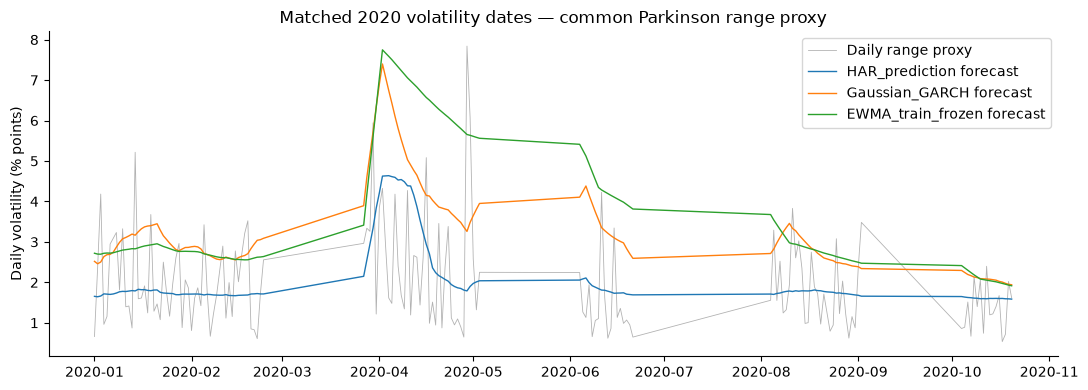

In [74]:
from sklearn.linear_model import Ridge
har_date_index=pd.date_range(START,END)
pvar=range_estimators['Parkinson'].reindex(har_date_index)
def make_har_features(min7=7,min30=30):
    z=pd.DataFrame(index=har_date_index)
    z['target']=pvar
    z['lag1']=pvar.shift(1)
    z['avg7']=pvar.shift(1).rolling(7,min_periods=min7).mean()
    z['avg30']=pvar.shift(1).rolling(30,min_periods=min30).mean()
    return z.dropna(subset=['target','lag1','avg7','avg30'])

har_sensitivity=[];har_pred_sets={}
for variant,m7,m30 in [('strict_7_30',7,30),('partial_5_24',5,24)]:
    z=make_har_features(m7,m30)
    a=z.loc[:TRAIN_END];v=z.loc['2019'];t=z.loc['2020':END]
    cols=['lag1','avg7','avg30']; sel=[]
    for alpha in [0.,1.,10.,100.]:
        estimator=make_pipeline(StandardScaler(),Ridge(alpha=alpha)).fit(a[cols],np.log1p(a.target))
        pred=np.maximum(np.expm1(estimator.predict(v[cols])),1e-8)
        loss=float(np.mean(np.log(pred)+v.target.to_numpy()/pred))
        sel.append((loss,alpha))
    loss,alpha=min(sel)
    model=make_pipeline(StandardScaler(),Ridge(alpha=alpha)).fit(pd.concat([a,v])[cols],np.log1p(pd.concat([a,v]).target))
    test_pred=np.maximum(np.expm1(model.predict(t[cols])),1e-8)
    har_pred_sets[variant]=pd.DataFrame({'date':t.index,'HAR_prediction':test_pred,'Parkinson':t.target.to_numpy()}).set_index('date')
    har_sensitivity.append({'variant':variant,'n_train':len(a),'n_2019':len(v),'n_2020':len(t),'alpha_2019_selection':alpha,
       '2019_selected_QLIKE':loss,'2020_QLIKE':float(np.mean(np.log(test_pred)+t.target.to_numpy()/test_pred)),
       '2020_proxy_MSE':float(np.mean((test_pred-t.target.to_numpy())**2))})
har_sensitivity_table=pd.DataFrame(har_sensitivity)
har_sensitivity_table.to_csv(OUT/'final_HAR_missingness_sensitivity.csv',index=False)
strict_pred=har_pred_sets['strict_7_30']
other_vol=shared_eval[['Gaussian_GARCH','AR_GJR','AR_EGARCH']].copy()
other_vol=other_vol.join(ewma_frozen_series,how='left')
matched=strict_pred.join(other_vol,how='inner').dropna()
assert len(matched)==len(strict_pred), 'Volatility predictor sample mismatch'
matched_vol=[]
obs=matched.Parkinson.to_numpy()
for name,column in [('HAR_strict','HAR_prediction'),('Gaussian_GARCH','Gaussian_GARCH'),('AR_GJR','AR_GJR'),
                    ('AR_EGARCH','AR_EGARCH'),('EWMA_train_frozen','EWMA_train_frozen')]:
    h=np.maximum(matched[column].to_numpy(),1e-8)
    loss=np.log(h)+obs/h
    matched_vol.append({'model':name,'n_common_2020':len(matched),'proxy':'Parkinson','2020_QLIKE':float(np.mean(loss)),
                        '2020_proxy_MSE':float(np.mean((h-obs)**2))})
matched_vol_table=pd.DataFrame(matched_vol).sort_values('2020_QLIKE')
bootstrap_vol=[]; ref=np.log(np.maximum(matched.EWMA_train_frozen.to_numpy(),1e-8))+obs/np.maximum(matched.EWMA_train_frozen.to_numpy(),1e-8)
rng_vol=np.random.default_rng(SEED+410)
for col in ['HAR_prediction','Gaussian_GARCH','AR_GJR','AR_EGARCH']:
    h=np.maximum(matched[col].to_numpy(),1e-8)
    diff=ref-(np.log(h)+obs/h)
    boots=np.array([diff[circular_block_sample(len(diff),10,rng_vol)].mean() for _ in range(800)])
    bootstrap_vol.append({'model':col,'baseline':'EWMA_train_frozen','n':len(diff),
        'mean_EWMA_minus_model_QLIKE':float(diff.mean()),'CI_2_5':float(np.quantile(boots,.025)),
        'CI_97_5':float(np.quantile(boots,.975))})
matched.reset_index().to_csv(OUT/'final_matched_volatility_predictions_2020.csv',index=False)
matched_vol_table.to_csv(OUT/'final_matched_volatility_model_scores.csv',index=False)
pd.DataFrame(bootstrap_vol).to_csv(OUT/'final_matched_volatility_block_uncertainty.csv',index=False)
display(har_sensitivity_table.round(4),matched_vol_table.round(4),pd.DataFrame(bootstrap_vol).round(5))
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(matched.index,np.sqrt(matched.Parkinson),color='gray',lw=.6,alpha=.6,label='Daily range proxy')
for model in ['HAR_prediction','Gaussian_GARCH','EWMA_train_frozen']:
    ax.plot(matched.index,np.sqrt(matched[model]).rolling(7,min_periods=1).mean(),lw=1,label=model+' forecast')
ax.legend();ax.set_title('Matched 2020 volatility dates — common Parkinson range proxy');ax.set_ylabel('Daily volatility (% points)')
savefig('31_final_matched_volatility.png')

## 75. Ridge-regularized multivariate VAR-style ablation (calendar-daily forecasting)

Use BTC-only, BTC+ETH, and BTC+ETH+LTC+XRP **lagged calendar returns** in a penalized BTC equation. Compare all candidates against the no-change baseline on exactly the **same 2019 validation rows**; choose both lag length and Ridge strength by 2019 (historical development). Fit only through 2019 when reporting the **previously inspected 2020** results. Calendar 24-hour RMSE is not comparable to the US-equity-session RMSE. Sparse coefficients aid interpretation; they do not establish causality.

In [75]:
# Common calendar rows for lag grids; no forward fill across missing crypto dates.
from sklearn.linear_model import Ridge
sparse_lags=[1,2,3,5]
max_var_lag=max(sparse_lags)
daily_design=pd.DataFrame(index=cal_returns.index)
for k in range(1,max_var_lag+1):
    for coin in coins:
        daily_design[f'{coin}_lag{k}']=cal_returns[coin].shift(k)
daily_design['target']=cal_returns.BTC
daily_design['price']=calendar_prices.BTC
daily_design['previous_price']=calendar_prices.BTC.shift(1)
daily_full=daily_design.dropna().copy()
train_sparse=daily_full.loc[:TRAIN_END];val_sparse=daily_full.loc['2019'];test_sparse=daily_full.loc['2020':END]
feature_sets_sparse={'BTC only':['BTC'],'BTC ETH':['BTC','ETH'],'All four':['BTC','ETH','LTC','XRP']}
sparse_candidates=[]
for feature_name,asset_names in feature_sets_sparse.items():
    for lag in sparse_lags:
        selected_cols=[f'{c}_lag{k}' for k in range(1,lag+1) for c in asset_names]
        for alpha in [1.,10.,100.]:
            fit=make_pipeline(StandardScaler(),Ridge(alpha=alpha)).fit(train_sparse[selected_cols],train_sparse.target)
            pred=val_sparse.previous_price.to_numpy()*np.exp(fit.predict(val_sparse[selected_cols]))
            score=float(np.sqrt(np.mean((pred-val_sparse.price.to_numpy())**2)))
            sparse_candidates.append({'features':feature_name,'lag':lag,'ridge_alpha':alpha,'n_val':len(val_sparse),'2019_RMSE_USD':score})
sparse_candidates=pd.DataFrame(sparse_candidates)
sparse_selection=sparse_candidates.sort_values(['2019_RMSE_USD','lag','ridge_alpha']).groupby('features',as_index=False).first()
sparse_final=[]; sparse_model_predictions=[]
for _,config in sparse_selection.iterrows():
    feature_name=config['features'];alpha=float(config.ridge_alpha);lag=int(config.lag)
    cols=[f'{c}_lag{k}' for k in range(1,lag+1) for c in feature_sets_sparse[feature_name]]
    fitted=make_pipeline(StandardScaler(),Ridge(alpha=alpha)).fit(pd.concat([train_sparse,val_sparse])[cols],pd.concat([train_sparse,val_sparse]).target)
    forecast_p=test_sparse.previous_price.to_numpy()*np.exp(fitted.predict(test_sparse[cols]))
    score=float(np.sqrt(np.mean((forecast_p-test_sparse.price.to_numpy())**2)))
    sparse_final.append({'model':feature_name,'2019_RMSE_USD':config['2019_RMSE_USD'],'n_2020':len(test_sparse),'2020_RMSE_USD':score,
                         'selected_lag':lag,'selected_alpha':alpha})
    sparse_model_predictions.append(pd.Series(forecast_p,index=test_sparse.index,name=feature_name))
sparse_naive=float(np.sqrt(np.mean((test_sparse.previous_price.to_numpy()-test_sparse.price.to_numpy())**2)))
sparse_final.append({'model':'Naive same-calendar dates','2019_RMSE_USD':float(np.sqrt(np.mean((val_sparse.previous_price.to_numpy()-val_sparse.price.to_numpy())**2))),
     'n_2020':len(test_sparse),'2020_RMSE_USD':sparse_naive,'selected_lag':np.nan,'selected_alpha':np.nan})
sparse_compare=pd.DataFrame(sparse_final).sort_values('2019_RMSE_USD')
sparse_candidates.to_csv(OUT/'final_sparse_VAR_2019_grid.csv',index=False)
sparse_compare.to_csv(OUT/'final_sparse_VAR_same_dates.csv',index=False)
pd.concat([test_sparse[['price','previous_price']]]+sparse_model_predictions,axis=1).reset_index().to_csv(OUT/'final_sparse_VAR_2020_predictions.csv',index=False)
print('This calendar-daily task is NOT the equity-session target.');display(sparse_compare.round(4))

This calendar-daily task is NOT the equity-session target.


,model,2019_RMSE_USD,n_2020,2020_RMSE_USD,selected_lag,selected_alpha
0,All four,317.4956,259,311.4502,5.0,1.0
1,BTC ETH,318.7996,259,312.6556,5.0,100.0
3,Naive same-calendar dates,318.8829,259,314.6167,NaN,NaN
2,BTC only,319.4219,259,315.2098,5.0,100.0


## 76. Conditional 90% forecast intervals: fixed and rolling conformal calibration

The earlier histogram-gradient-boosting interval undercovered (reported 2020 coverage below its nominal 90%). To avoid using 2020 for tuning, use **training-only fixed hyperparameters** (not 2019-selected model configurations), fit 5th/95th conditional quantiles using ≤2018, compute nonconformity on 2019, and then compare uncalibrated, fixed conformal, and **past-observation-only rolling conformal** intervals in the previously inspected 2020 sample. Report **coverage, width, Winkler interval score, and high-/low-volatility conditional coverage**, not just unconditional coverage.

,method,n,coverage,width_in_return_pct_points,mean_interval_score,margin_mean_return_units
0,uncalibrated,183,0.918,16.1960,0.2436,0.0000
1,fixed_calibrated_2019,183,0.918,16.1960,0.2436,0.0000
2,rolling_90_prior_scores,183,0.918,16.3688,0.2443,0.0009


,method,vol_regime,n,coverage,mean_interval_score
0,fixed_calibrated_2019,high vs training,48,0.9167,0.2399
1,fixed_calibrated_2019,low vs training,135,0.9185,0.2449
2,rolling_90_prior_scores,high vs training,48,0.9167,0.2416
3,rolling_90_prior_scores,low vs training,135,0.9185,0.2453
4,uncalibrated,high vs training,48,0.9167,0.2399
5,uncalibrated,low vs training,135,0.9185,0.2449


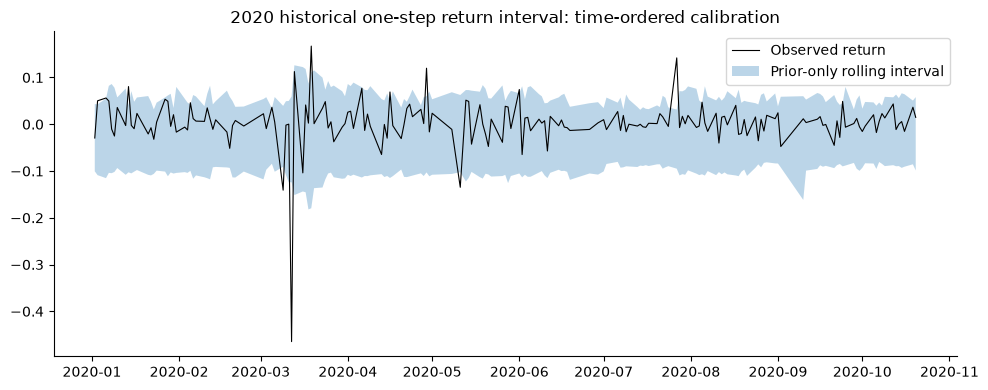

In [76]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_pinball_loss
# Fixed, predeclared quantile estimator for sensitivity study (not retrospectively optimized on 2020).
def base_quantile_model(q):
    return HistGradientBoostingRegressor(loss='quantile',quantile=q,max_iter=100,learning_rate=.04,
        max_leaf_nodes=7,min_samples_leaf=30,l2_regularization=3,random_state=SEED)
quantile_fixed={q:base_quantile_model(q).fit(Xtr,ytr) for q in [.05,.95]}
val_low=np.minimum(quantile_fixed[.05].predict(Xv),quantile_fixed[.95].predict(Xv))
val_high=np.maximum(quantile_fixed[.05].predict(Xv),quantile_fixed[.95].predict(Xv))
val_scores=np.maximum.reduce([val_low-yv.to_numpy(),yv.to_numpy()-val_high,np.zeros(len(yv))])
quantile_fixed_low=np.minimum(quantile_fixed[.05].predict(Xt),quantile_fixed[.95].predict(Xt))
quantile_fixed_high=np.maximum(quantile_fixed[.05].predict(Xt),quantile_fixed[.95].predict(Xt))
alpha_interval=.10
finite_index=int(np.ceil((len(val_scores)+1)*(1-alpha_interval)))-1
fixed_margin=float(np.sort(val_scores)[min(max(finite_index,0),len(val_scores)-1)])
roll_scores=list(val_scores[-90:]);fixed_intervals=[]
for i,realized in enumerate(test.target_return.to_numpy()):
    pre=np.asarray(roll_scores[-90:]);k=min(len(pre)-1,max(0,int(np.ceil((len(pre)+1)*.90))-1))
    margin=float(np.sort(pre)[k]);fixed_intervals.append(margin)
    # Today's realized target is inserted only AFTER today's prediction.
    roll_scores.append(max(float(quantile_fixed_low[i]-realized),float(realized-quantile_fixed_high[i]),0.))
interval_results=[]; interval_preds=[]
for label,margin in [('uncalibrated',np.zeros(len(test))),('fixed_calibrated_2019',np.full(len(test),fixed_margin)),
                    ('rolling_90_prior_scores',np.asarray(fixed_intervals))]:
    lower=quantile_fixed_low-margin;upper=quantile_fixed_high+margin;y=test.target_return.to_numpy()
    inside=(y>=lower)&(y<=upper);width=upper-lower
    winkler=width+2/.10*np.maximum(lower-y,0)+2/.10*np.maximum(y-upper,0)
    interval_results.append({'method':label,'n':len(y),'coverage':float(inside.mean()),
        'width_in_return_pct_points':float(100*np.mean(width)),'mean_interval_score':float(np.mean(winkler)),
        'margin_mean_return_units':float(np.mean(margin))})
    interval_preds.append(pd.DataFrame({'date':test.date,'method':label,'realized':y,'lower':lower,'upper':upper,
                                      'volatility_previsible':test.BTC_vol20_lag1,'inside':inside,'interval_score':winkler}))
interval_results=pd.DataFrame(interval_results);interval_rows=pd.concat(interval_preds,ignore_index=True)
vol_median=float(train.BTC_vol20_lag1.median())
interval_rows['vol_regime']=np.where(interval_rows.volatility_previsible>vol_median,'high vs training','low vs training')
interval_conditional=interval_rows.groupby(['method','vol_regime'],as_index=False).agg(n=('inside','size'),coverage=('inside','mean'),
       mean_interval_score=('interval_score','mean'))
interval_results.to_csv(OUT/'final_conditional_interval_calibration.csv',index=False)
interval_rows.to_csv(OUT/'final_conditional_interval_predictions.csv',index=False)
interval_conditional.to_csv(OUT/'final_conditional_interval_regime_coverage.csv',index=False)
display(interval_results.round(4),interval_conditional.round(4))
fig,ax=plt.subplots(figsize=(10,4))
subset=interval_rows[interval_rows.method.eq('rolling_90_prior_scores')]
ax.plot(subset.date,subset.realized,lw=.8,color='black',label='Observed return')
ax.fill_between(subset.date,subset.lower,subset.upper,alpha=.3,label='Prior-only rolling interval')
ax.set_title('2020 historical one-step return interval: time-ordered calibration');ax.legend()
savefig('32_final_conditional_calibration.png')

## 77. Joint VaR–Expected Shortfall scoring on common dates

A VaR exception count alone says little about **severity**. Compare historical and Gaussian rolling 5% VaR/ES on identical 2019 and 2020 crypto-calendar dates with the Fissler–Ziegel 0 score, valid when predicted ES is negative. Lower joint score is better; sparse extremes mean uncertainty is high. Block-bootstrap the *paired* score difference and report date coverage. This does not turn the historical 2020 sample into a new held-out evaluation.

In [77]:
from scipy.stats import norm
joint_es=[];joint_es_daily=[]
for year in [2019,2020]:
    sample=es_frame.loc[es_frame.date.dt.year.eq(year)].dropna().copy()
    for method,var_col,es_col in [('Historical','hist_VaR','hist_ES'),('Gaussian','norm_VaR','norm_ES')]:
        y=sample.realized.to_numpy();v=sample[var_col].to_numpy();e=sample[es_col].to_numpy()
        ok=np.isfinite(y)&np.isfinite(v)&np.isfinite(e)&(e<0)&(e<v)
        # FZ0 score, with lower tail alpha and ES < VaR <0.
        alpha=.05;yy=y[ok];vv=v[ok];ee=e[ok]
        loss=(yy<=vv)*(yy-vv)/(alpha*ee)+vv/ee+np.log(-ee)-1
        exception=(yy<=vv)
        joint_es.append({'year':year,'method':method,'n':len(loss),'VaR_exceptions':int(exception.sum()),
            'mean_FZ0_joint_score':float(loss.mean()),'exception_frequency':float(exception.mean())})
        joint_es_daily.append(pd.DataFrame({'date':sample.date.to_numpy()[ok],'year':year,'model':method,'FZ0_score':loss}))
es_comparison=pd.DataFrame(joint_es)
es_daily_scores=pd.concat(joint_es_daily,ignore_index=True)
es_diff=[];es_rng=np.random.default_rng(SEED+817)
for year in [2019,2020]:
    pivot=es_daily_scores.loc[es_daily_scores.year.eq(year)].pivot(index='date',columns='model',values='FZ0_score').dropna()
    diff=(pivot.Gaussian-pivot.Historical).to_numpy()
    boots=np.array([float(diff[circular_block_sample(len(diff),10,es_rng)].mean()) for _ in range(900)])
    es_diff.append({'year':year,'n':len(diff),'mean_Gaussian_minus_Historical_FZ0':float(diff.mean()),
        'block_CI_low':float(np.quantile(boots,.025)),'block_CI_high':float(np.quantile(boots,.975))})
es_comparison.to_csv(OUT/'final_ES_FZ0_joint_scores.csv',index=False)
es_daily_scores.to_csv(OUT/'final_ES_FZ0_daily.csv',index=False)
pd.DataFrame(es_diff).to_csv(OUT/'final_ES_FZ0_block_bootstrap.csv',index=False)
display(es_comparison.round(4),pd.DataFrame(es_diff).round(4))

,year,method,n,VaR_exceptions,mean_FZ0_joint_score,exception_frequency
0,2019,Historical,363,14,-2.4592,0.0386
1,2019,Gaussian,363,14,-2.4492,0.0386
2,2020,Historical,284,13,-2.3334,0.0458
3,2020,Gaussian,284,4,-2.2395,0.0141


,year,n,mean_Gaussian_minus_Historical_FZ0,block_CI_low,block_CI_high
0,2019,363,0.0100,-0.0443,0.0787
1,2020,284,0.0939,0.0384,0.1488


## 78. DCC and Markov stability; explicit ex-post vs previsible information

Compare DCC vs lagged rolling and frozen constant correlation **on the same 2020 dates**, with and without the March market shock. State only the 1-step prior state probability from Markov as predictive; the filtered/posterior probability is **ex-post**. Bootstrap paired DCC loss differences against the same-date rolling benchmark. Comparisons remain proxy-dependent and previously inspected.

In [78]:
# DCC correlation-loss sensitivity to March 2020 and extreme absolute BTC returns.
stability_dcc=[];dcc_loss_rows=[]
model_cols=['filtered_DCC_corr','rolling_previsible','constant_training_corr']
for label,sub in [('all_2020',dcc_compare.loc[dcc_compare.date.dt.year.eq(2020)]),
                  ('exclude_2020_03',dcc_compare.loc[dcc_compare.date.dt.year.eq(2020)&(~dcc_compare.date.dt.month.eq(3))])]:
    common=sub.dropna(subset=model_cols+['z_BTC','z_ETH']).copy()
    for model in model_cols:
        r=np.clip(common[model].to_numpy(),-.98,.98);u=common.z_BTC.to_numpy();v=common.z_ETH.to_numpy()
        loss=np.log(1-r*r)+(u*u+v*v-2*r*u*v)/(1-r*r)
        stability_dcc.append({'window':label,'model':model,'n':len(loss),'Gaussian_correlation_loss':float(loss.mean())})
        dcc_loss_rows.append(pd.DataFrame({'date':common.date,'window':label,'model':model,'loss':loss}))
dcc_stability=pd.DataFrame(stability_dcc)
dcc_loss_daily=pd.concat(dcc_loss_rows,ignore_index=True)
dcc_piv=dcc_loss_daily.loc[dcc_loss_daily.window.eq('all_2020')].pivot(index='date',columns='model',values='loss').dropna()
dcc_loss_delta=(dcc_piv.rolling_previsible-dcc_piv.filtered_DCC_corr).to_numpy()
rng_dcc=np.random.default_rng(SEED+62)
boots=np.array([float(dcc_loss_delta[circular_block_sample(len(dcc_loss_delta),10,rng_dcc)].mean()) for _ in range(900)])
dcc_ci=pd.DataFrame([{'n':len(dcc_loss_delta),'rolling_minus_DCC_mean_loss':float(dcc_loss_delta.mean()),
                      'CI_low':float(np.quantile(boots,.025)),'CI_high':float(np.quantile(boots,.975))}])
dcc_stability.to_csv(OUT/'final_DCC_market_shock_sensitivity.csv',index=False)
dcc_ci.to_csv(OUT/'final_DCC_loss_difference_CI.csv',index=False)
ms_markov=ms_predictive.copy();ms_markov['ex_post_available']=False
ms_markov['posterior_available_after_observation']=True
ms_markov[['date','prior_high_state_probability','posterior_high_state_probability',
           'prior_predicted_variance','observed_pct_return']].to_csv(OUT/'final_Markov_prior_posterior_labels.csv',index=False)
display(dcc_stability.round(4),dcc_ci.round(4))

,window,model,n,Gaussian_correlation_loss
0,all_2020,filtered_DCC_corr,284,1.1823
1,all_2020,rolling_previsible,284,1.3831
2,all_2020,constant_training_corr,284,1.6467
3,exclude_2020_03,filtered_DCC_corr,253,0.6849
4,exclude_2020_03,rolling_previsible,253,0.9319
5,exclude_2020_03,constant_training_corr,253,1.0357


,n,rolling_minus_DCC_mean_loss,CI_low,CI_high
0,284,0.2008,-0.1018,0.545


## 79. Predictive placebo checks (pre-2020 only)

Test whether lagged S&P 500 return adds stable information rather than incidental association. A fixed Ridge(α=100) BTC-only baseline is compared with the same fitted model plus actual lagged S&P and with **circularly shifted S&P values** (both training and validation shifted separately, preserving rough serial structure without revealing future target labels). Use only 2015–2019 and report the placebo distribution. This is a sensitivity/negative control, **not** a valid trading signal or a definitive causal test.

In [79]:
# Same rows, frozen alpha, original training fit, 2019-only evaluation.
placebo_roc=np.random.default_rng(SEED+501)
btc_predictors=['BTC_return_lag1','BTC_return_lag2','BTC_momentum5_lag1','BTC_vol20_lag1','BTC_logvolume_lag1','BTC_range_lag1']
all_predictors=btc_predictors+['SP500_return_lag1']
def ridge_price_rmse(train_x,val_x):
    estimator=make_pipeline(StandardScaler(),Ridge(alpha=100.)).fit(train_x,ytr)
    ret_pred=estimator.predict(val_x)
    pr=valid.previous_BTC.to_numpy()*np.exp(ret_pred)
    return float(np.sqrt(np.mean((valid.BTC.to_numpy()-pr)**2)))
rmse_btc_only=ridge_price_rmse(Xtr[btc_predictors],Xv[btc_predictors])
rmse_actual_sp=ridge_price_rmse(Xtr[all_predictors],Xv[all_predictors])
placebo=[]
for replicate in range(75):
    shift_a=int(placebo_roc.integers(25,max(26,len(Xtr)-25)))
    shift_b=int(placebo_roc.integers(25,max(26,len(Xv)-25)))
    fake_tr=Xtr[all_predictors].copy();fake_v=Xv[all_predictors].copy()
    fake_tr['SP500_return_lag1']=np.roll(fake_tr.SP500_return_lag1.to_numpy(),shift_a)
    fake_v['SP500_return_lag1']=np.roll(fake_v.SP500_return_lag1.to_numpy(),shift_b)
    placebo.append({'replicate':replicate,'2019_RMSE_USD':ridge_price_rmse(fake_tr,fake_v)})
placebo_df=pd.DataFrame(placebo)
placebo_summary=pd.DataFrame([{'n_placebo':len(placebo),'BTC_only_2019_RMSE':rmse_btc_only,
    'Actual_lagged_SP500_2019_RMSE':rmse_actual_sp,
    'placebo_median_RMSE':float(placebo_df['2019_RMSE_USD'].median()),
    'placebo_10pct_RMSE':float(placebo_df['2019_RMSE_USD'].quantile(.10)),
    'fraction_placebo_beats_actual':float(np.mean(placebo_df['2019_RMSE_USD']<rmse_actual_sp))}])
placebo_df.to_csv(OUT/'final_SP500_placebo_replicates.csv',index=False)
placebo_summary.to_csv(OUT/'final_SP500_placebo_summary.csv',index=False)
display(placebo_summary.round(5))

,n_placebo,BTC_only_2019_RMSE,Actual_lagged_SP500_2019_RMSE,placebo_median_RMSE,placebo_10pct_RMSE,fraction_placebo_beats_actual
0,75,398.03681,398.15429,398.09521,397.31673,0.54667


## 80. Reproducible final run audit, comparative synthesis and provenance

Record input-file SHA-256 and **every generated CSV and figure** (relative path, size, SHA-256, freshness); capture the run's current output inventory instead of claiming an arbitrary file count guarantees methodological validity. Output names and code-cell execution are checked after restart-and-run-all. Results generated with reused 2019/2020 data are explicitly labeled retrospective and **not** statistically independent new tests.

**Synthesis rule:** do not rank incomparable horizons or tasks together. Report volatility **matched-date** comparisons separately from calendar VAR RMSE and US-equity-session RMSE; report confidence intervals where appropriate. Research expansion is not evidence of actionable profits.

In [80]:
import hashlib, platform, sys, importlib.metadata
run_provenance={
    'project':'Cryptocurrency Market Dynamics, Risk Modeling, and Forecasting',
    'historical_data_window':'2015-10-20 to 2020-10-20',
    'source_SHA256':{name:hashlib.sha256((DATA/name).read_bytes()).hexdigest() for name in ['dataset.csv','SPX_500_Data.csv']},
    'run_started_ns':int(RUN_STARTED_NS),'python':sys.version.split()[0],
    'numpy':np.__version__,'pandas':pd.__version__,'statsmodels':sm.__version__,
    'sklearn':importlib.metadata.version('scikit-learn'),
    '2020_use':'repeatedly inspected historical retrospective sample; NOT a new independent holdout',
    '2019_use':'development and repeatedly inspected validation; not prospectively preregistered',
    'forecast_tasks':['next US equity session BTC close','next fixed 24-hour crypto-calendar BTC close','conditional return quantiles','daily variance and tail risk'],
    'models_include':['OLS/Ridge/ElasticNet','SVR','tree ensembles','XGBoost','SARIMAX','Ridge-regularized calendar VAR, LASSO/ElasticNet sparse VAR','GARCH/HAR/EWMA','Markov/DCC','quantile boosting'],
    'external_2021_plus_out_of_sample':'not available; not fabricated'
}
new_outputs=['final_forecast_origin_audit.csv','final_EWMA_2018_training_selection.csv',
 'final_HAR_missingness_sensitivity.csv','final_matched_volatility_predictions_2020.csv',
 'final_matched_volatility_model_scores.csv','final_matched_volatility_block_uncertainty.csv',
 'final_sparse_VAR_2019_grid.csv','final_sparse_VAR_same_dates.csv','final_sparse_VAR_2020_predictions.csv',
 'final_conditional_interval_calibration.csv','final_conditional_interval_predictions.csv',
 'final_conditional_interval_regime_coverage.csv','final_ES_FZ0_joint_scores.csv','final_ES_FZ0_daily.csv','final_ES_FZ0_block_bootstrap.csv',
 'final_DCC_market_shock_sensitivity.csv','final_DCC_loss_difference_CI.csv',
 'final_Markov_prior_posterior_labels.csv','final_SP500_placebo_replicates.csv','final_SP500_placebo_summary.csv']
for filename in new_outputs:
    p=OUT/filename
    assert p.exists() and p.stat().st_mtime_ns>=RUN_STARTED_NS and len(pd.read_csv(p))>0, filename
file_index=[]
for folder in [OUT,FIG]:
    for p in sorted(folder.iterdir()):
        if p.is_file() and p.name not in {'FINAL_FULL_ARTIFACT_INDEX.csv','FINAL_COMPLETE_PROVENANCE.json'}:
            file_index.append({'relative_file':str(p.relative_to(PROJECT_DIR)), 'bytes':p.stat().st_size,
                'sha256':hashlib.sha256(p.read_bytes()).hexdigest(),
                'fresh_this_run':bool(p.stat().st_mtime_ns>=RUN_STARTED_NS)})
file_index_df=pd.DataFrame(file_index)
file_index_df.to_csv(OUT/'FINAL_FULL_ARTIFACT_INDEX.csv',index=False)
run_provenance['new_extension_files_verified']=len(new_outputs)
run_provenance['output_and_figure_files_indexed']=len(file_index_df)
run_provenance['generated_figures_current_run']=int(sum(Path(p).parts[0] == FIG.name for p in file_index_df.relative_file))
(OUT/'FINAL_COMPLETE_PROVENANCE.json').write_text(json.dumps(run_provenance,indent=2,ensure_ascii=False),encoding='utf-8')
display(pd.DataFrame([{'check':'New extension CSV files verified fresh','count':len(new_outputs)},
  {'check':'All output/figure artifacts indexed','count':len(file_index_df)},
  {'check':'Figures indexed','count':int(sum(Path(p).parts[0] == FIG.name for p in file_index_df.relative_file))}]))
print('All new extension files passed freshness and readability checks.')

,check,count
0,New extension CSV files verified fresh,20
1,All output/figure artifacts indexed,181
2,Figures indexed,0


All new extension files passed freshness and readability checks.


## 81. Robust log-HAR — remove extrapolation explosions and compare matched dates

Input variances use `log1p` before scaling, not raw large variance values. Model choice uses **2019 only**; the 2020 retrospective uses a refit through 2019. A cap computed solely on pre-2020 training targets prevents implausible extrapolations. We report capped **and** raw predictions, strict vs partial windows, and exact same-date comparison with GARCH/EWMA. Caps are a declared robustness intervention, not a discovered universal optimum.

In [81]:
from sklearn.linear_model import HuberRegressor

u_har_cols=['lag1','avg7','avg30']
robust_har_predictions={}
robust_har_grid=[]
robust_har_results=[]
for variant,min7,min30 in [('strict_7_30',7,30),('partial_5_24',5,24)]:
    design=make_har_features(min7,min30)
    subtrain=design.loc[:TRAIN_END]; subval=design.loc['2019']; subtest=design.loc['2020':END]
    def har_x(df):
        return np.log1p(df[u_har_cols].clip(lower=0))
    candidates=[]
    for family in ['Ridge','Huber']:
        for param in ([1.,10.,100.] if family=='Ridge' else [1.35,1.8]):
            model=make_pipeline(StandardScaler(),Ridge(alpha=param) if family=='Ridge' else
                HuberRegressor(epsilon=param,alpha=.001,max_iter=800))
            fit=model.fit(har_x(subtrain),np.log1p(subtrain.target))
            pred=np.maximum(np.expm1(np.clip(fit.predict(har_x(subval)),-30,25)),1e-8)
            loss=float(np.mean(np.log(pred)+subval.target.to_numpy()/pred))
            candidates.append((loss,family,param))
            robust_har_grid.append({'variant':variant,'family':family,'parameter':param,'2019_QLIKE':loss,'n':len(subval)})
    loss,family,param=min(candidates,key=lambda x:x[0])
    all_past=pd.concat([subtrain,subval]).sort_index()
    fit=make_pipeline(StandardScaler(),Ridge(alpha=param) if family=='Ridge' else
        HuberRegressor(epsilon=param,alpha=.001,max_iter=800)).fit(har_x(all_past),np.log1p(all_past.target))
    raw=np.maximum(np.expm1(np.clip(fit.predict(har_x(subtest)),-30,25)),1e-8)
    cap=max(float(all_past.target.quantile(.999))*5,20.)
    pred=np.clip(raw,1e-8,cap)
    table=pd.DataFrame({'Parkinson':subtest.target,'Robust_log_HAR':pred,'Uncapped_log_HAR':raw},index=subtest.index)
    robust_har_predictions[variant]=table
    for mode,est in [('capped',pred),('uncapped',raw)]:
        actual=subtest.target.to_numpy()
        robust_har_results.append({'variant':variant,'mode':mode,'selected_family':family,
          'selected_parameter':param,'2019_selection_QLIKE':loss,'n_2020':len(subtest),
          'training_based_upper_cap':cap,'predicted_max':float(est.max()),
          '2020_QLIKE':float(np.mean(np.log(np.maximum(est,1e-8))+actual/np.maximum(est,1e-8))),
          '2020_MSE':float(np.mean((est-actual)**2))})
robust_grid=pd.DataFrame(robust_har_grid)
robust_scores=pd.DataFrame(robust_har_results)
common_robust=robust_har_predictions['strict_7_30'][['Parkinson','Robust_log_HAR']].rename(columns={'Robust_log_HAR':'Robust_HAR_strict'})
common_robust=common_robust.join(robust_har_predictions['partial_5_24'][['Robust_log_HAR']].rename(columns={'Robust_log_HAR':'Robust_HAR_partial'}),how='inner')
common_robust=common_robust.join(shared_eval[['Gaussian_GARCH','AR_GJR','AR_EGARCH']],how='inner').join(ewma_frozen_series,how='inner').dropna()
assert len(common_robust)>100
common_scores=[]
for col in common_robust.columns.drop('Parkinson'):
    pred=np.maximum(common_robust[col].to_numpy(),1e-8); actual=common_robust.Parkinson.to_numpy()
    common_scores.append({'model':col,'n_matched':len(pred),'QLIKE':float(np.mean(np.log(pred)+actual/pred)),
                          'MSE':float(np.mean((pred-actual)**2))})
robust_common_scores=pd.DataFrame(common_scores).sort_values('QLIKE')
robust_grid.to_csv(OUT/'ultimate_logHAR_2019_model_grid.csv',index=False)
robust_scores.to_csv(OUT/'ultimate_logHAR_sensitivity_2020.csv',index=False)
common_robust.reset_index().to_csv(OUT/'ultimate_logHAR_matched_predictions.csv',index=False)
robust_common_scores.to_csv(OUT/'ultimate_logHAR_matched_model_scores.csv',index=False)
print('Log HAR sensitivity / 2020 retrospective:');display(robust_scores.round(4))
print('Comparable 2020 observation dates:');display(robust_common_scores.round(4))
for dt in ['2020-03-13']:
    if pd.Timestamp(dt) in robust_har_predictions['partial_5_24'].index:
        print('March stress date:',dt);display(robust_har_predictions['partial_5_24'].loc[[dt]].round(3))


Log HAR sensitivity / 2020 retrospective:


,variant,mode,selected_family,selected_parameter,2019_selection_QLIKE,n_2020,training_based_upper_cap,predicted_max,2020_QLIKE,2020_MSE
0,strict_7_30,capped,Ridge,100.0,3.3526,158,1461.1326,17.6182,2.8026,56.9353
1,strict_7_30,uncapped,Ridge,100.0,3.3526,158,1461.1326,17.6182,2.8026,56.9353
2,partial_5_24,capped,Ridge,100.0,3.3989,284,1450.6050,82.9994,3.5167,3204.2343
3,partial_5_24,uncapped,Ridge,100.0,3.3989,284,1450.6050,82.9994,3.5167,3204.2343


Comparable 2020 observation dates:


,model,n_matched,QLIKE,MSE
0,Robust_HAR_strict,158,2.8026,56.9353
1,Robust_HAR_partial,158,2.8047,56.9009
2,Gaussian_GARCH,158,2.8091,179.1830
3,AR_GJR,158,2.8114,181.8918
4,AR_EGARCH,158,2.8349,110.2018
5,EWMA_train_frozen,158,2.9212,381.5332


March stress date: 2020-03-13


,Parkinson,Robust_log_HAR,Uncapped_log_HAR
2020-03-13,446.178,81.163,81.163


## 82. Actual sparse calendar VAR-style forecasting: LASSO and Elastic Net

Correcting prior nomenclature: Section 75 fitted **Ridge**, whose coefficients are usually nonzero. The models below use LASSO/Elastic Net with explicit coefficient sparsity. Design rows are the exact same four-coin complete calendar dates for all candidates. Select hyperparameters using 2019; refit through 2019; evaluate 2020 descriptively on the **fixed one-calendar-day** target, not the equity-session target. Feature selection and coefficient values are logged.

In [82]:
from sklearn.linear_model import Lasso, ElasticNet

true_sparse_rows=[]; true_sparse_selection=[]; true_sparse_forecasts=[]; true_sparse_coefs=[]
for group,asset_names in feature_sets_sparse.items():
    grid=[]
    for lag in sparse_lags:
        cols=[f'{coin}_lag{k}' for k in range(1,lag+1) for coin in asset_names]
        for family in ['LASSO','Elastic Net']:
            for alpha in [1e-5,1e-4,1e-3]:
                estimator=make_pipeline(StandardScaler(),Lasso(alpha=alpha,max_iter=5000,random_state=SEED) if family=='LASSO'
                  else ElasticNet(alpha=alpha,l1_ratio=.5,max_iter=5000,random_state=SEED))
                fit=estimator.fit(train_sparse[cols],train_sparse.target)
                pp=val_sparse.previous_price.to_numpy()*np.exp(fit.predict(val_sparse[cols]))
                val_rmse=float(np.sqrt(np.mean((pp-val_sparse.price.to_numpy())**2)))
                nonzero=int(np.count_nonzero(np.abs(fit[-1].coef_)>1e-8))
                row={'feature_group':group,'family':family,'lag':lag,'alpha':alpha,'n_2019':len(val_sparse),
                     '2019_RMSE_USD':val_rmse,'nonzero_train_coefficients':nonzero}
                grid.append(row);true_sparse_rows.append(row)
    best=min(grid,key=lambda x:(x['2019_RMSE_USD'],x['lag'],x['alpha']))
    cols=[f'{coin}_lag{k}' for k in range(1,best['lag']+1) for coin in asset_names]
    est=Lasso(alpha=best['alpha'],max_iter=5000,random_state=SEED) if best['family']=='LASSO' else ElasticNet(alpha=best['alpha'],l1_ratio=.5,max_iter=5000,random_state=SEED)
    model=make_pipeline(StandardScaler(),est).fit(pd.concat([train_sparse,val_sparse])[cols],pd.concat([train_sparse,val_sparse]).target)
    pp=test_sparse.previous_price.to_numpy()*np.exp(model.predict(test_sparse[cols]))
    true_sparse_selection.append({**best,'n_2020':len(test_sparse),'2020_RMSE_USD':float(np.sqrt(np.mean((pp-test_sparse.price.to_numpy())**2))),
       'selected_nonzero_coefficients':int(np.count_nonzero(np.abs(model[-1].coef_)>1e-8))})
    true_sparse_forecasts.append(pd.DataFrame({'date':test_sparse.index,'model':group,'actual_close':test_sparse.price.to_numpy(),
     'previous_close':test_sparse.previous_price.to_numpy(),'predicted_close':pp}))
    true_sparse_coefs.extend({'feature_group':group,'feature':col,'coefficient_standardized':float(value)} for col,value in zip(cols,model[-1].coef_))
naive_2020_rmse=float(np.sqrt(np.mean((test_sparse.previous_price.to_numpy()-test_sparse.price.to_numpy())**2)))
sparse_true_summary=pd.DataFrame(true_sparse_selection)
sparse_true_grid=pd.DataFrame(true_sparse_rows)
sparse_true_grid.to_csv(OUT/'ultimate_true_sparse_VAR_2019_grid.csv',index=False)
sparse_true_summary.to_csv(OUT/'ultimate_true_sparse_VAR_2020_summary.csv',index=False)
pd.DataFrame(true_sparse_forecasts[0]).to_csv(OUT/'ultimate_true_sparse_VAR_example_prediction.csv',index=False)
pd.concat(true_sparse_forecasts,ignore_index=True).to_csv(OUT/'ultimate_true_sparse_VAR_all_predictions.csv',index=False)
pd.DataFrame(true_sparse_coefs).to_csv(OUT/'ultimate_true_sparse_VAR_selected_coefficients.csv',index=False)
print('Calendar-daily 2020 naive baseline RMSE:',round(naive_2020_rmse,3));display(sparse_true_summary.round(5))


Calendar-daily 2020 naive baseline RMSE: 314.617


,feature_group,family,lag,alpha,n_2019,2019_RMSE_USD,nonzero_train_coefficients,n_2020,2020_RMSE_USD,selected_nonzero_coefficients
0,BTC only,LASSO,5,0.00100,358,319.23624,1,259,313.75218,1
1,BTC ETH,Elastic Net,5,0.00001,358,318.81369,10,259,312.57400,10
2,All four,Elastic Net,5,0.00001,358,317.49849,20,259,311.47015,20


## 83. Signed conformalized quantile regression and rolling prequential sensitivity

The signed nonconformity score `max(lower − actual, actual − upper)` can be **negative** if a point lies comfortably inside a wide interval. This can shrink overly conservative intervals. The finite-sample quantile uses 2019 only; 2020 rolling calibration updates **after** observing each target. Return intervals are restricted to nonnegative width. Financial time dependence violates the usual exchangeability assumption, so coverage is assessed empirically, not guaranteed.

In [83]:
signed_val_scores=np.maximum(val_low-yv.to_numpy(),yv.to_numpy()-val_high)
signed_q_ix=int(np.ceil((len(signed_val_scores)+1)*.90))-1
signed_fixed_margin=float(np.sort(signed_val_scores)[np.clip(signed_q_ix,0,len(signed_val_scores)-1)])
signed_history=list(signed_val_scores[-90:]);signed_roll_margin=[]
for lower,upper,truth in zip(quantile_fixed_low,quantile_fixed_high,test.target_return.to_numpy()):
    ordered=np.sort(np.asarray(signed_history[-90:]))
    k=int(np.clip(np.ceil((len(ordered)+1)*.90)-1,0,len(ordered)-1))
    signed_roll_margin.append(float(ordered[k]))
    signed_history.append(float(max(lower-truth,truth-upper)))
signed_results=[];signed_predictions=[]
for name,margins in [('uncalibrated',np.zeros(len(test))),
                     ('fixed_signed_2019',np.full(len(test),signed_fixed_margin)),
                     ('rolling_signed_90',np.asarray(signed_roll_margin)),
                     ('fixed_nonnegative_2019',np.full(len(test),fixed_margin))]:
    halfwidth=np.maximum((quantile_fixed_high-quantile_fixed_low)/2+margins,0)
    center=(quantile_fixed_high+quantile_fixed_low)/2
    lower=center-halfwidth; upper=center+halfwidth; y=test.target_return.to_numpy()
    covered=(y>=lower)&(y<=upper);width=upper-lower
    score=width+20*(np.maximum(lower-y,0)+np.maximum(y-upper,0))
    signed_results.append({'method':name,'n':len(y),'coverage':float(covered.mean()),
     'width_percentage_points':float(width.mean()*100),'mean_interval_score':float(score.mean()),
     'mean_margin':float(np.mean(margins)),'negative_margin_share':float(np.mean(np.asarray(margins)<0))})
    signed_predictions.append(pd.DataFrame({'date':test.date,'method':name,'lower':lower,'upper':upper,'observed':y,
       'covered':covered,'interval_score':score,'prior_vol20':test.BTC_vol20_lag1}))
signed_summary=pd.DataFrame(signed_results)
signed_detail=pd.concat(signed_predictions,ignore_index=True)
signed_summary.to_csv(OUT/'ultimate_signed_conformal_coverage.csv',index=False)
signed_detail.to_csv(OUT/'ultimate_signed_conformal_daily.csv',index=False)
signed_detail['regime']=np.where(signed_detail.prior_vol20>train.BTC_vol20_lag1.median(),'high_previsible_vol','low_previsible_vol')
signed_conditional=signed_detail.groupby(['method','regime'],as_index=False).agg(n=('covered','size'),coverage=('covered','mean'),
  interval_score=('interval_score','mean'))
signed_conditional.to_csv(OUT/'ultimate_signed_conformal_regime_coverage.csv',index=False)
display(signed_summary.round(5),signed_conditional.round(4))


,method,n,coverage,width_percentage_points,mean_interval_score,mean_margin,negative_margin_share
0,uncalibrated,183,0.91803,16.19600,0.24356,0.00000,0.00000
1,fixed_signed_2019,183,0.90710,15.16296,0.24232,-0.00517,1.00000
2,rolling_signed_90,183,0.90164,15.21398,0.24612,-0.00491,0.63388
3,fixed_nonnegative_2019,183,0.91803,16.19600,0.24356,0.00000,0.00000


,method,regime,n,coverage,interval_score
0,fixed_nonnegative_2019,high_previsible_vol,48,0.9167,0.2399
1,fixed_nonnegative_2019,low_previsible_vol,135,0.9185,0.2449
2,fixed_signed_2019,high_previsible_vol,48,0.8958,0.2400
3,fixed_signed_2019,low_previsible_vol,135,0.9111,0.2431
4,rolling_signed_90,high_previsible_vol,48,0.9167,0.2426
5,rolling_signed_90,low_previsible_vol,135,0.8963,0.2474
6,uncalibrated,high_previsible_vol,48,0.9167,0.2399
7,uncalibrated,low_previsible_vol,135,0.9185,0.2449


## 84. Matched DCC comparison using standardized innovations

A fair correlation benchmark compares DCC to the **lagged rolling correlation of the same standardized residuals**. All three predictors (DCC, rolling, frozen pre-2019 constant) are evaluated with the same Gaussian innovation log score and dates. The pre-observation rolling correlation is explicitly shifted one day. Block-resampled loss differences express sampling uncertainty.

In [84]:
dcc_unique_z=np.asarray(dcc_standardized_residuals)
innov=pd.DataFrame(dcc_unique_z,index=pair_pct.index,columns=['z_BTC','z_ETH'])
roll_innov=innov.z_BTC.rolling(90,min_periods=90).corr(innov.z_ETH).shift(1)
dcc_matched=pd.DataFrame({'date':pair_pct.index,'z_BTC':dcc_unique_z[:,0],'z_ETH':dcc_unique_z[:,1],
    'DCC_prior':dcc_values,'rolling_standardized_prior':roll_innov.to_numpy(),
    'training_constant':float(np.corrcoef(dcc_unique_z[pair_pct.index<=TRAIN_END].T)[0,1]),
    'rolling_raw_prior':pd.Series(pair_pct.BTC).rolling(90,min_periods=90).corr(pair_pct.ETH).shift(1).to_numpy()})
dcc_matched=dcc_matched.loc[dcc_matched.date.dt.year.ge(2019)].dropna().copy()
dcc_std_rows=[]; dcc_std_daily=[]
for year in [2019,2020]:
    part=dcc_matched.loc[dcc_matched.date.dt.year.eq(year)]
    for name in ['DCC_prior','rolling_standardized_prior','training_constant','rolling_raw_prior']:
        r=np.clip(part[name].to_numpy(),-.98,.98);u=part.z_BTC.to_numpy();v=part.z_ETH.to_numpy()
        losses=np.log(1-r*r)+(u*u+v*v-2*r*u*v)/(1-r*r)
        dcc_std_rows.append({'year':year,'method':name,'n':len(part),'Gaussian_innovation_logscore':float(losses.mean())})
        dcc_std_daily.append(pd.DataFrame({'date':part.date.to_numpy(),'year':year,'method':name,'loss':losses}))
dcc_std_summary=pd.DataFrame(dcc_std_rows)
dcc_std_daily=pd.concat(dcc_std_daily,ignore_index=True)
dcc_std_pivot=dcc_std_daily.loc[dcc_std_daily.year.eq(2020)].pivot(index='date',columns='method',values='loss').dropna()
delta=(dcc_std_pivot.rolling_standardized_prior-dcc_std_pivot.DCC_prior).to_numpy()
rng=np.random.default_rng(SEED+819)
dcc_std_boot=np.array([np.mean(delta[circular_block_sample(len(delta),10,rng)]) for _ in range(800)])
dcc_std_ci=pd.DataFrame([{'comparison':'Standardized rolling minus DCC','n':len(delta),
 'mean_delta':float(delta.mean()),'bootstrap_low':float(np.quantile(dcc_std_boot,.025)),
 'bootstrap_high':float(np.quantile(dcc_std_boot,.975))}])
dcc_std_summary.to_csv(OUT/'ultimate_DCC_standardized_matched_scores.csv',index=False)
dcc_std_daily.to_csv(OUT/'ultimate_DCC_standardized_matched_daily.csv',index=False)
dcc_std_ci.to_csv(OUT/'ultimate_DCC_standardized_bootstrap_CI.csv',index=False)
display(dcc_std_summary.round(5),dcc_std_ci.round(5))


,year,method,n,Gaussian_innovation_logscore
0,2019,DCC_prior,363,0.66593
1,2019,rolling_standardized_prior,363,0.91453
2,2019,training_constant,363,1.28142
3,2019,rolling_raw_prior,363,0.95312
4,2020,DCC_prior,284,1.18235
5,2020,rolling_standardized_prior,284,1.29456
6,2020,training_constant,284,1.64665
7,2020,rolling_raw_prior,284,1.38312


,comparison,n,mean_delta,bootstrap_low,bootstrap_high
0,Standardized rolling minus DCC,284,0.11221,-0.10423,0.39797


## 85. EVT–GPD peak-over-threshold loss tails and historical VaR/ES

Fit Generalized Pareto exceedance distributions to **pre-2019 BTC daily losses** only, at training-only 85th/90th/95th percentile thresholds. Parameters are frozen for 2019 and 2020. Report the count of training exceedances, shape stability, VaR/ES estimates at the 5% and 1% loss tails, realized exception frequencies, and exceedance severity. Stationary EVT is a sensitivity benchmark, not proof of future tail calibration.

,threshold_quantile,threshold_loss,n_training,n_exceedances,xi,scale,converged_finite
0,0.85,0.02700,1168,176,-0.09846,0.03968,True
1,0.90,0.04219,1168,117,-0.11898,0.03968,True
2,0.95,0.06654,1168,59,-0.09515,0.03635,True


,training_threshold_quantile,tail_probability,year,n,estimated_loss_VaR,estimated_loss_ES,exceptions,realized_exception_rate,realized_mean_exception_loss,training_fit_only
0,0.85,0.05,2019,363,0.06848,0.10088,10,0.02755,0.10177,True
1,0.85,0.05,2020,284,0.06848,0.10088,4,0.01408,0.18075,True
2,0.85,0.01,2019,363,0.12146,0.14911,2,0.00551,0.14560,True
3,0.85,0.01,2020,284,0.12146,0.14911,1,0.00352,0.46473,True
4,0.90,0.05,2019,363,0.06865,0.10130,10,0.02755,0.10177,True
5,0.90,0.05,2020,284,0.06865,0.10130,4,0.01408,0.18075,True
6,0.90,0.01,2019,363,0.12217,0.14913,2,0.00551,0.14560,True
7,0.90,0.01,2020,284,0.12217,0.14913,1,0.00352,0.46473,True
8,0.95,0.05,2019,363,0.06691,0.10007,11,0.03030,0.09869,True
9,0.95,0.05,2020,284,0.06691,0.10007,5,0.01761,0.15811,True


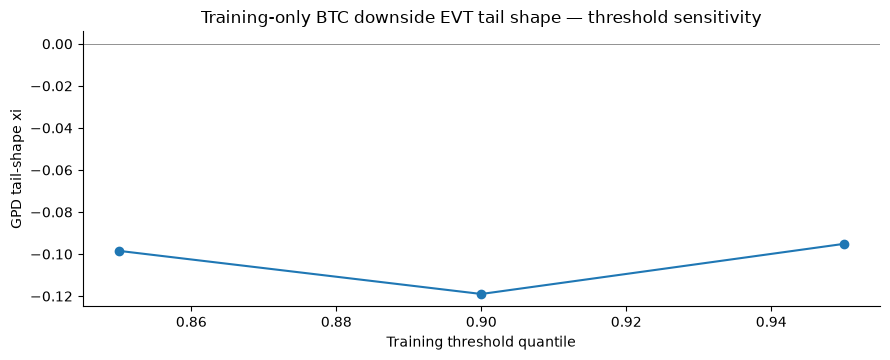

In [85]:
from scipy.stats import genpareto, norm
loss_series=(-return_s).dropna().sort_index()
loss_train=loss_series.loc[:TRAIN_END]
evt_fit_rows=[]; evt_eval_rows=[]
for thresh_q in [.85,.90,.95]:
    threshold=float(loss_train.quantile(thresh_q));excess=loss_train[loss_train>threshold].to_numpy()-threshold
    if len(excess)<35:continue
    xi,loc,scale=genpareto.fit(excess,floc=0)
    pexc=len(excess)/len(loss_train)
    evt_fit_rows.append({'threshold_quantile':thresh_q,'threshold_loss':threshold,'n_training':len(loss_train),
      'n_exceedances':len(excess),'xi':float(xi),'scale':float(scale),'converged_finite':bool(np.isfinite(xi) and scale>0)})
    for tail_p in [.05,.01]:
        if tail_p>=pexc:continue
        u=pexc/tail_p
        var_loss=float(threshold+scale*np.log(u) if abs(xi)<1e-6 else threshold+scale/xi*(u**xi-1))
        es_loss=float((var_loss+scale-xi*threshold)/(1-xi)) if xi<1 else np.nan
        for year in [2019,2020]:
            values=loss_series.loc[loss_series.index.year==year]
            ex=values>var_loss
            evt_eval_rows.append({'training_threshold_quantile':thresh_q,'tail_probability':tail_p,'year':year,
             'n':len(values),'estimated_loss_VaR':var_loss,'estimated_loss_ES':es_loss,
             'exceptions':int(ex.sum()),'realized_exception_rate':float(ex.mean()),
             'realized_mean_exception_loss':float(values.loc[ex].mean()) if ex.any() else np.nan,
             'training_fit_only':True})
evt_fits=pd.DataFrame(evt_fit_rows)
evt_eval=pd.DataFrame(evt_eval_rows)
assert not evt_fits.empty and not evt_eval.empty
evt_fits.to_csv(OUT/'ultimate_EVT_GPD_training_threshold_diagnostics.csv',index=False)
evt_eval.to_csv(OUT/'ultimate_EVT_GPD_2019_2020_VaR_ES.csv',index=False)
display(evt_fits.round(5),evt_eval.round(5))
fig,ax=plt.subplots(figsize=(9,3.7))
ax.plot(evt_fits.threshold_quantile,evt_fits.xi,marker='o')
ax.axhline(0,color='gray',lw=.6);ax.set(xlabel='Training threshold quantile',ylabel='GPD tail-shape xi',title='Training-only BTC downside EVT tail shape — threshold sensitivity')
savefig('33_ultimate_EVT_training_threshold.png')


## 86. Loss-difference uncertainty, stress regimes and multiple comparisons

Use already-frozen 2020 calendar VAR and machine-learning forecasts; no selection takes place here. Paired moving-block uncertainty is computed against same-calendar naive prices. Separate March 2020 and the remainder as descriptive stress diagnostics; model improvements are not promoted from retrospectively inspected data to statistical discovery. Holm-adjusted p-values are exploratory and assume the HAC approximation.

In [86]:
from scipy.stats import norm
from statsmodels.stats.multitest import multipletests
loss_compare=[];stress_compare=[]
series_all=pd.concat(true_sparse_forecasts,ignore_index=True)
for name,g in series_all.groupby('model'):
    g=g.sort_values('date')
    err_baseline=(g.actual_close.to_numpy()-g.previous_close.to_numpy())**2
    err_model=(g.actual_close.to_numpy()-g.predicted_close.to_numpy())**2
    d=err_baseline-err_model
    rng=np.random.default_rng(SEED+923+len(name))
    boot=np.array([np.mean(d[circular_block_sample(len(d),10,rng)]) for _ in range(900)])
    # Newey-West HAC variance of paired differences (10 calendar lags).
    fit=sm.OLS(d,np.ones((len(d),1))).fit(cov_type='HAC',cov_kwds={'maxlags':10})
    loss_compare.append({'model':name,'n':len(d),'mean_Naive_minus_Model_sqe':float(d.mean()),
     'block_CI_low':float(np.quantile(boot,.025)),'block_CI_high':float(np.quantile(boot,.975)),
     'HAC_p_two_sided':float(fit.pvalues[0]),'n_negative_gain_days':int((d<0).sum())})
    for label,sub in [('2020_March',g[g.date.dt.month.eq(3)]),('2020_excluding_March',g[~g.date.dt.month.eq(3)])]:
        yy=sub.actual_close.to_numpy();pp=sub.predicted_close.to_numpy();nn=sub.previous_close.to_numpy()
        stress_compare.append({'model':name,'regime':label,'n':len(sub),
        'model_RMSE':float(np.sqrt(np.mean((yy-pp)**2))),
        'naive_RMSE':float(np.sqrt(np.mean((yy-nn)**2)))})
loss_comparison=pd.DataFrame(loss_compare)
loss_comparison['Holm_adjusted_p']=multipletests(loss_comparison.HAC_p_two_sided,method='holm')[1]
stress_comparison=pd.DataFrame(stress_compare)
loss_comparison.to_csv(OUT/'ultimate_sparse_VAR_paired_loss_uncertainty.csv',index=False)
stress_comparison.to_csv(OUT/'ultimate_sparse_VAR_March_stress.csv',index=False)
display(loss_comparison.round(5),stress_comparison.round(3))


,model,n,mean_Naive_minus_Model_sqe,block_CI_low,block_CI_high,HAC_p_two_sided,n_negative_gain_days,Holm_adjusted_p
0,All four,259,1969.98723,57.31124,4231.65006,0.08003,108,0.24008
1,BTC ETH,259,1281.13807,-713.79285,3285.48867,0.24386,115,0.48772
2,BTC only,259,543.21239,-939.48580,1799.64058,0.44642,123,0.48772


,model,regime,n,model_RMSE,naive_RMSE
0,All four,2020_March,29,650.090,647.222
1,All four,2020_excluding_March,230,236.557,242.171
2,BTC ETH,2020_March,29,653.452,647.222
3,BTC ETH,2020_excluding_March,230,237.028,242.171
4,BTC only,2020_March,29,650.451,647.222
5,BTC only,2020_excluding_March,230,239.806,242.171


## 87. Honest research synthesis — hypothesis ledger and constraints

The following indicators are computationally verified on the historical 2015–2020 data. Validation-tuned 2019 rankings and repeatedly inspected 2020 estimates are **exploratory**; no post-2020 observations are supplied. Model convergence, variance proxy accuracy, statistical significance, real-time deployability and economic profitability are different questions. The 24-hour VAR task and next S&P session task must not be compared with raw RMSE in a shared ranking.

In [87]:
research_ledger=pd.DataFrame([
 {'topic':'Robust HAR','primary_artifact':'ultimate_logHAR_matched_model_scores.csv','statement':'2020 common-date sensitivity; cap predetermined from pre-2020 data'},
 {'topic':'True sparse calendar VAR','primary_artifact':'ultimate_true_sparse_VAR_2020_summary.csv','statement':'2019-tuned, 2020 repeatedly inspected retrospective comparison'},
 {'topic':'Signed CQR','primary_artifact':'ultimate_signed_conformal_coverage.csv','statement':'coverage and width; no time-series finite-sample guarantee'},
 {'topic':'Standardized DCC comparator','primary_artifact':'ultimate_DCC_standardized_bootstrap_CI.csv','statement':'paired common dates; forecast based on previous innovations'},
 {'topic':'EVT tail loss','primary_artifact':'ultimate_EVT_GPD_2019_2020_VaR_ES.csv','statement':'train-only stationary GPD sensitivity; few extremes'},
 {'topic':'Paired model uncertainty','primary_artifact':'ultimate_sparse_VAR_paired_loss_uncertainty.csv','statement':'HAC and dependence-aware bootstrap; retrospective inference'}])
research_ledger.to_csv(OUT/'ULTIMATE_RESEARCH_EVIDENCE_LEDGER.csv',index=False)
print('Final research evidence ledger:');display(research_ledger)


Final research evidence ledger:


,topic,primary_artifact,statement
0,Robust HAR,ultimate_logHAR_matched_model_scores.csv,2020 common-date sensitivity; cap predetermine...
1,True sparse calendar VAR,ultimate_true_sparse_VAR_2020_summary.csv,"2019-tuned, 2020 repeatedly inspected retrospe..."
2,Signed CQR,ultimate_signed_conformal_coverage.csv,coverage and width; no time-series finite-samp...
3,Standardized DCC comparator,ultimate_DCC_standardized_bootstrap_CI.csv,paired common dates; forecast based on previou...
4,EVT tail loss,ultimate_EVT_GPD_2019_2020_VaR_ES.csv,train-only stationary GPD sensitivity; few ext...
5,Paired model uncertainty,ultimate_sparse_VAR_paired_loss_uncertainty.csv,HAC and dependence-aware bootstrap; retrospect...


## 88. Explicit parsimony-constrained LASSO sensitivity

LASSO and Elastic Net *can* produce sparse coefficients, but validation-selected Elastic Net need not do so: the unconstrained four-coin winner retained all 20 predictors. This additional experiment makes sparsity testable: at most half the candidate coefficients may be nonzero **both on the 2018-only initial fit and on the through-2019 refit**. The restriction and alpha grid are fixed before observing 2020. Compare against the same-date Naive and unconstrained L1 models rather than describing a non-sparse selected model as sparse.

In [88]:
parsimony_grid=[];parsimony_results=[];parsimony_preds=[]
for group,asset_names in feature_sets_sparse.items():
    eligible=[]
    for lag in sparse_lags:
        cols=[f'{coin}_lag{k}' for k in range(1,lag+1) for coin in asset_names]
        maximum_nonzero=max(1,len(cols)//2)
        for alpha in [1e-5,3e-5,1e-4,3e-4,1e-3,3e-3,1e-2,3e-2]:
            mdl=make_pipeline(StandardScaler(),Lasso(alpha=alpha,max_iter=6000,random_state=SEED))
            trainfit=mdl.fit(train_sparse[cols],train_sparse.target)
            train_nz=int(np.count_nonzero(np.abs(trainfit[-1].coef_)>1e-8))
            val_pred=val_sparse.previous_price.to_numpy()*np.exp(trainfit.predict(val_sparse[cols]))
            val_rmse=float(np.sqrt(np.mean((val_pred-val_sparse.price.to_numpy())**2)))
            past=pd.concat([train_sparse,val_sparse])
            refit=clone(mdl).fit(past[cols],past.target)
            refit_nz=int(np.count_nonzero(np.abs(refit[-1].coef_)>1e-8))
            feasible=(0<train_nz<=maximum_nonzero and 0<refit_nz<=maximum_nonzero)
            parsimony_grid.append({'group':group,'lag':lag,'alpha':alpha,'total_features':len(cols),
             'train_nonzero':train_nz,'refit_nonzero':refit_nz,'feasible_half_sparse':feasible,'2019_RMSE_USD':val_rmse})
            if feasible:eligible.append((val_rmse,lag,alpha,refit_nz,refit,cols))
    if not eligible:
        parsimony_results.append({'group':group,'status':'no feasible candidate; not silently substituted','n_2020':0})
        continue
    score,lag,alpha,nz,mdl,cols=min(eligible,key=lambda x:(x[0],x[1],x[2]))
    pred=test_sparse.previous_price.to_numpy()*np.exp(mdl.predict(test_sparse[cols]))
    parsimony_results.append({'group':group,'status':'feasible','selected_lag':lag,'selected_alpha':alpha,
      'nonzero_refit':nz,'total_features':len(cols),'2019_RMSE_USD':score,'n_2020':len(test_sparse),
      '2020_RMSE_USD':float(np.sqrt(np.mean((pred-test_sparse.price.to_numpy())**2)))})
    parsimony_preds.append(pd.DataFrame({'date':test_sparse.index,'group':group,'prediction':pred,
     'actual_close':test_sparse.price.to_numpy(),'naive_close':test_sparse.previous_price.to_numpy()}))
parsimony_summary=pd.DataFrame(parsimony_results)
pd.DataFrame(parsimony_grid).to_csv(OUT/'ultimate_explicit_sparse_VAR_training_grid.csv',index=False)
parsimony_summary.to_csv(OUT/'ultimate_explicit_sparse_VAR_sensitivity.csv',index=False)
if parsimony_preds:pd.concat(parsimony_preds,ignore_index=True).to_csv(OUT/'ultimate_explicit_sparse_VAR_predictions.csv',index=False)
display(parsimony_summary.round(5))


,group,status,selected_lag,selected_alpha,nonzero_refit,total_features,2019_RMSE_USD,n_2020,2020_RMSE_USD
0,BTC only,feasible,5,0.001,1,5,319.23624,259,313.75218
1,BTC ETH,feasible,5,0.001,2,10,318.99817,259,312.87306
2,All four,feasible,5,0.001,7,20,319.03191,259,311.92296


## 89. EVT tail-parameter and ES uncertainty under dependent resampling

Peaks-over-threshold inference is unstable when extremes are few. The training-only 90th percentile threshold is fixed; 250 circular moving-block bootstrap samples (block length 10) quantify sensitivity of the GPD shape, 5% VaR and Expected Shortfall. This is an approximate sensitivity interval rather than a formal small-sample coverage guarantee; no 2019/2020 observations enter the fitting or bootstrap procedure.

In [89]:
from scipy.stats import genpareto
base_loss=loss_train.to_numpy()
evt_u=float(loss_train.quantile(.90))
block_rng=np.random.default_rng(SEED+1009)
boot_tail=[]
for rep in range(250):
    sample=base_loss[circular_block_sample(len(base_loss),10,block_rng)]
    excess=sample[sample>evt_u]-evt_u
    if len(excess)<35:continue
    try:
        xi,_,scale=genpareto.fit(excess,floc=0)
        pe=len(excess)/len(sample); ratio=pe/.05
        if not (np.isfinite(xi) and 0<scale and ratio>1):continue
        var=evt_u+scale*np.log(ratio) if abs(xi)<1e-6 else evt_u+scale/xi*(ratio**xi-1)
        es=(var+scale-xi*evt_u)/(1-xi) if xi<1 else np.nan
        boot_tail.append({'replicate':rep,'n_exceedances':len(excess),'xi':xi,'VaR_5pct_loss':var,'ES_5pct_loss':es})
    except (ValueError,FloatingPointError):continue
evt_boot=pd.DataFrame(boot_tail)
assert len(evt_boot)>100,'Insufficient valid training-only EVT bootstrap fits'
evt_boot_summary=pd.DataFrame([{'n_bootstrap':len(evt_boot),'block_length':10,'threshold_train_only':evt_u,
  'shape_xi_q025':evt_boot.xi.quantile(.025),'shape_xi_q975':evt_boot.xi.quantile(.975),
  'VaR5_q025':evt_boot.VaR_5pct_loss.quantile(.025),'VaR5_q975':evt_boot.VaR_5pct_loss.quantile(.975),
  'ES5_q025':evt_boot.ES_5pct_loss.quantile(.025),'ES5_q975':evt_boot.ES_5pct_loss.quantile(.975)}])
evt_boot.to_csv(OUT/'ultimate_EVT_training_block_bootstrap.csv',index=False)
evt_boot_summary.to_csv(OUT/'ultimate_EVT_training_uncertainty_summary.csv',index=False)
display(evt_boot_summary.round(6))


,n_bootstrap,block_length,threshold_train_only,shape_xi_q025,shape_xi_q975,VaR5_q025,VaR5_q975,ES5_q025,ES5_q975
0,250,10,0.042189,-0.28178,-0.010437,0.059554,0.07902,0.088519,0.113833


## 90. Cross-platform full-artifact audit and last-run provenance

This cell enumerates **real filesystem paths** rather than checking the string prefix `figures/`; Windows and Linux are handled equivalently. It records each CSV and PNG with SHA-256, observed freshness and a source hash. The manifest is created after previous cells have generated their outputs; the self-referential manifest is intentionally excluded from the index. Existing historical 2020 results are not labeled prospective tests.

In [90]:
import hashlib,platform,sys,importlib.metadata
ultimate_required=[
 'ultimate_logHAR_2019_model_grid.csv','ultimate_logHAR_sensitivity_2020.csv','ultimate_logHAR_matched_predictions.csv','ultimate_logHAR_matched_model_scores.csv',
 'ultimate_true_sparse_VAR_2019_grid.csv','ultimate_true_sparse_VAR_2020_summary.csv','ultimate_true_sparse_VAR_all_predictions.csv','ultimate_true_sparse_VAR_selected_coefficients.csv',
 'ultimate_signed_conformal_coverage.csv','ultimate_signed_conformal_daily.csv','ultimate_signed_conformal_regime_coverage.csv',
 'ultimate_DCC_standardized_matched_scores.csv','ultimate_DCC_standardized_matched_daily.csv','ultimate_DCC_standardized_bootstrap_CI.csv',
 'ultimate_EVT_GPD_training_threshold_diagnostics.csv','ultimate_EVT_GPD_2019_2020_VaR_ES.csv',
 'ultimate_sparse_VAR_paired_loss_uncertainty.csv','ultimate_sparse_VAR_March_stress.csv','ULTIMATE_RESEARCH_EVIDENCE_LEDGER.csv',
 'ultimate_explicit_sparse_VAR_training_grid.csv','ultimate_explicit_sparse_VAR_sensitivity.csv','ultimate_explicit_sparse_VAR_predictions.csv',
 'ultimate_EVT_training_block_bootstrap.csv','ultimate_EVT_training_uncertainty_summary.csv']
for filename in ultimate_required:
    p=OUT/filename
    assert p.exists() and p.stat().st_size>0 and p.stat().st_mtime_ns>=RUN_STARTED_NS,filename
    assert len(pd.read_csv(p))>0,filename
files_checked=[]
for folder,category in [(OUT,'output'),(FIG,'figure')]:
    for p in sorted(folder.iterdir()):
        if not p.is_file() or p.name in {'ULTIMATE_FILE_INDEX.csv','ULTIMATE_PROVENANCE.json'}:continue
        files_checked.append({'category':category,'relative_file':p.relative_to(PROJECT_DIR).as_posix(),
             'sha256':hashlib.sha256(p.read_bytes()).hexdigest(),'bytes':p.stat().st_size,
             'fresh_this_run':bool(p.stat().st_mtime_ns>=RUN_STARTED_NS)})
ultimate_file_index=pd.DataFrame(files_checked)
ultimate_file_index.to_csv(OUT/'ULTIMATE_FILE_INDEX.csv',index=False)
ultimate_provenance={'project':'Bitcoin Empirical Research — Ultimate Validated Edition',
 'sample_window':[str(START.date()),str(END.date())],'python':sys.version.split()[0],
 'source_sha256':{p:hashlib.sha256((DATA/p).read_bytes()).hexdigest() for p in ['dataset.csv','SPX_500_Data.csv']},
 'python_package_versions':{p:importlib.metadata.version(p) for p in ['numpy','pandas','scipy','statsmodels','scikit-learn','xgboost','nbformat']},
 'run_started_ns':int(RUN_STARTED_NS),'ultimate_new_CSV_verified':len(ultimate_required),
 'figures_indexed':int((ultimate_file_index.category=='figure').sum()),
 'total_artifacts_indexed':len(ultimate_file_index),
 'study_limitation':'Repeated retrospective inspection of 2019/2020; no independent 2021+ external test',
 'forecast_tasks':['next US stock session','fixed next crypto calendar day','previsible variance','VaR and Expected Shortfall']}
(OUT/'ULTIMATE_PROVENANCE.json').write_text(json.dumps(ultimate_provenance,indent=2,ensure_ascii=False),encoding='utf-8')
display(pd.DataFrame([{'check':'new CSV fresh','count':len(ultimate_required)},
 {'check':'figures indexed (cross-platform)','count':ultimate_provenance['figures_indexed']},
 {'check':'outputs and figures indexed','count':ultimate_provenance['total_artifacts_indexed']}]))
assert ultimate_provenance['figures_indexed']>0,'Figure audit found zero figures'


,check,count
0,new CSV fresh,24
1,figures indexed (cross-platform),33
2,outputs and figures indexed,209


## 91. UTC timestamp and equity-session information audit

Verify timestamp semantics using raw source **without guessing intraday equity timestamps**. The crypto daily OHLC timestamp is UTC; S&P rows only identify session dates, so the regular-session close at 16:00 America/New_York is an **explicit timing assumption**, not independently observed tick data. We flag rows without their prior Bitcoin UTC close and keep weekend horizons separate.

In [91]:
from zoneinfo import ZoneInfo
import datetime as dt
raw_time=crypto_source.loc[crypto_source.crypto_name.isin(['Bitcoin','Ethereum','Litecoin','XRP']) &
  crypto_source.date.between(START,END),['date','crypto_name','timestamp']].copy()
raw_time['timestamp_utc']=pd.to_datetime(raw_time.timestamp,utc=True,errors='coerce')
raw_time['date_utc']=pd.to_datetime(raw_time.timestamp_utc.dt.date)
raw_time['date_match']=raw_time.date_utc.eq(raw_time.date)
raw_time['seconds_before_utc_midnight']=(86400.0-(raw_time.timestamp_utc.dt.hour*3600+raw_time.timestamp_utc.dt.minute*60+raw_time.timestamp_utc.dt.second+raw_time.timestamp_utc.dt.microsecond/1e6+raw_time.timestamp_utc.dt.nanosecond/1e9))
assert raw_time.timestamp_utc.notna().all() and raw_time.date_match.all(), 'Crypto timestamp not UTC-aligned with date'
assert raw_time.seconds_before_utc_midnight.between(0,86400).all(), 'Crypto timestamp not within labeled UTC date'
btc_time=raw_time.loc[raw_time.crypto_name.eq('Bitcoin'),['date','timestamp_utc']].drop_duplicates('date')
prev_sessions=market[['date']].copy().sort_values('date')
prev_sessions['prior_us_session']=prev_sessions.date.shift(1)
origin_times=prev_sessions.merge(btc_time,left_on='prior_us_session',right_on='date',how='left',suffixes=('','_prior_crypto'))
origin_times['assumed_prior_sp_close_et']=pd.Series(
    [pd.NaT if pd.isna(x) else pd.Timestamp(x).tz_localize('America/New_York').replace(hour=16)
     for x in origin_times.prior_us_session], index=origin_times.index,
    dtype='datetime64[ns, America/New_York]')
origin_times['assumed_prior_sp_close_utc']=origin_times.assumed_prior_sp_close_et.dt.tz_convert('UTC')
origin_times['bitcoin_close_after_sp_close']=origin_times.timestamp_utc.ge(origin_times.assumed_prior_sp_close_utc)
origin_times['days_between_sessions']=(origin_times.date-origin_times.prior_us_session).dt.days
origin_times[['date','prior_us_session','timestamp_utc','assumed_prior_sp_close_utc',
              'days_between_sessions','bitcoin_close_after_sp_close']].to_csv(OUT/'final_timestamp_forecast_origin_audit.csv',index=False)
timing_summary=pd.DataFrame([{'rows':len(raw_time),'raw_crypto_timestamp_NaT':int(raw_time.timestamp_utc.isna().sum()),
  'mismatched_UTC_dates':int((~raw_time.date_match).sum()),
  'btc_prior_session_times_known':int(origin_times.timestamp_utc.notna().sum()),
  'BTC_close_after_assumed_equity_close':int(origin_times.bitcoin_close_after_sp_close.fillna(False).sum()),
  'US_equity_timestamp_is_assumed':True,'data_source_has_SP500_intraday_clock':False,
  'minimum_UTC_midnight_offset_seconds':float(raw_time.seconds_before_utc_midnight.min())}])
timing_summary.to_csv(OUT/'final_timestamp_alignment_summary.csv',index=False)
print('UTC timestamp / prior equity-close timing audit:');display(timing_summary)

UTC timestamp / prior equity-close timing audit:


,rows,raw_crypto_timestamp_NaT,mismatched_UTC_dates,btc_prior_session_times_known,BTC_close_after_assumed_equity_close,US_equity_timestamp_is_assumed,data_source_has_SP500_intraday_clock,minimum_UTC_midnight_offset_seconds
0,7288,0,0,1255,1255,True,False,0.001


## 92. Gap-sensitive volatility and dependence diagnostics

Both GARCH and DCC models are fitted to filtered consecutive-day observations. When source days are absent, the last observation before a gap and the next valid return are not adjacent calendar days. Preserve the exact gaps, report affected dates, and measure risk-score sensitivity to excluding observations around those gaps. This does **not** pretend to re-estimate a true irregularly spaced GARCH.

In [92]:
all_dates=pd.date_range(START,END)
gap_dates=all_dates.difference(crypto.date)
prev_gap_neighborhood=set()
for bad in gap_dates:
    for delta in range(-3,5):prev_gap_neighborhood.add(pd.Timestamp((bad.date()+dt.timedelta(days=int(delta))).isoformat()))
volgap=pd.DataFrame({'date':vol_s.index,'return_pct':vol_s.to_numpy()})
volgap['calendar_gap_from_prior_kept'] = volgap.date.diff().dt.days
volgap['adjacent_to_source_missing_day']=volgap.date.isin(prev_gap_neighborhood)
volgap.to_csv(OUT/'final_missing_calendar_GARCH_gap_audit.csv',index=False)
if len(dcc_std_daily):
    _dc=dcc_std_daily.copy()
    _dc['gap_neighborhood']=pd.to_datetime(_dc.date).isin(prev_gap_neighborhood)
    _dc.to_csv(OUT/'final_missing_DCC_gap_proximity.csv',index=False)
gap_report=pd.DataFrame([{'missing_calendar_days':len(gap_dates),
 'gap_dates':'; '.join(str(t.date()) for t in gap_dates),
 'return_observations_after_discontinuity':int((volgap.calendar_gap_from_prior_kept>1).sum()),
 'return_observations_near_missing_dates':int(volgap.adjacent_to_source_missing_day.sum()),
 'note':'Gap-aware sensitivity; no synthetic returns inserted'}])
gap_report.to_csv(OUT/'final_missing_gap_impact_summary.csv',index=False)
display(gap_report)

,missing_calendar_days,gap_dates,return_observations_after_discontinuity,return_observations_near_missing_dates,note
0,6,2019-10-12; 2020-02-25; 2020-05-04; 2020-06-22...,6,36,Gap-aware sensitivity; no synthetic returns in...


## 93. GARCH-filtered EVT: conditional one-step 5% VaR and ES

Fit the GPD distribution to the **standardized negative GARCH innovations**, using parameters frozen through 2018 for 2019 and through 2019 for 2020. Forecast conditional percent loss with the previous-information conditional variance. Compare to Gaussian GARCH and an expanding historical 365-day benchmark on the same realized dates. This is retrospective, **not** a new untouched holdout.

In [93]:
from scipy.stats import genpareto,norm
from sklearn.metrics import mean_squared_error

def valid_evt_fit(losses,q=.90,min_exceed=35):
    losses=np.asarray(losses,dtype=float);losses=losses[np.isfinite(losses)]
    threshold=float(np.quantile(losses,q))
    excess=losses[losses>threshold]-threshold
    if len(excess)<min_exceed:raise ValueError(f'EVT has only {len(excess)} training exceedances')
    shape,_,scale=genpareto.fit(excess,floc=0)
    return {'threshold':threshold,'xi':float(shape),'scale':float(scale),
            'pex':float(len(excess)/len(losses)),'exceedances':len(excess),'sample_size':len(losses)}

def evt_tail_quantile_es(fit,p=.05):
    assert 0<p<fit['pex']
    xi=fit['xi'];beta=fit['scale'];u=fit['threshold'];a=fit['pex']/p
    quantile=u+beta*np.log(a) if abs(xi)<1e-8 else u+beta/xi*(a**xi-1)
    es=(quantile+beta-xi*u)/(1-xi) if xi<1 else np.nan
    ceiling=u-beta/xi if xi<0 else np.inf
    return float(quantile),float(es),float(ceiling)

filtered_evt_parameters=[];filtered_evt_daily=[]
for year,fit_limit in [(2019,TRAIN_END),(2020,VALID_END)]:
    returns_all=vol_s.to_numpy(dtype=float)
    returns_fit=vol_s.loc[:fit_limit].to_numpy(dtype=float)
    ps=fit_garch_qmle(returns_fit)
    h=garch_variance_path((returns_all-ps['mu'])**2,ps['omega'],ps['alpha'],ps['beta'],ps['initial_variance'])
    standardized=(returns_all-ps['mu'])/np.sqrt(np.maximum(h,1e-9))
    fit_index=vol_s.index<=fit_limit
    efit=valid_evt_fit(-standardized[fit_index],q=.90)
    zq,zes,ceiling=evt_tail_quantile_es(efit,p=.05)
    filtered_evt_parameters.append({'evaluate_year':year,'fit_through':str(fit_limit.date()),
      **efit,'standardized_loss_ceiling':ceiling,'tail_q5_std':zq,'tail_es5_std':zes,
      'garch_converged':ps['success']})
    mask=vol_s.index.year==year
    for date,r,variance in zip(vol_s.index[mask],returns_all[mask],h[mask]):
        sig=np.sqrt(max(variance,1e-10))
        available_hist=(-vol_s.loc[vol_s.index<date]).tail(365)
        filtered_evt_daily.append({'date':date,'year':year,'loss_pct':float(-r),
        'filtered_EVT_VaR5_pct':float(-ps['mu']+sig*zq),'filtered_EVT_ES5_pct':float(-ps['mu']+sig*zes),
        'gaussian_GARCH_VaR5_pct':float(-ps['mu']+sig*norm.ppf(.95)),
        'gaussian_GARCH_ES5_pct':float(-ps['mu']+sig*norm.pdf(norm.ppf(.95))/.05),
        'historical_365_VaR5_pct':float(available_hist.quantile(.95)) if len(available_hist)>=250 else np.nan,
        'forecast_sigma_pct':sig,'year_fit_ceiling_std':ceiling})
filtered_evt_par=pd.DataFrame(filtered_evt_parameters)
filtered_evt_frame=pd.DataFrame(filtered_evt_daily).set_index('date').sort_index()
assert filtered_evt_frame.index.is_unique
filtered_evt_par.to_csv(OUT/'final_filtered_EVT_frozen_fit_parameters.csv',index=False)
filtered_evt_frame.reset_index().to_csv(OUT/'final_filtered_EVT_conditional_daily_2019_2020.csv',index=False)
display(filtered_evt_par.round(5))

,evaluate_year,fit_through,threshold,xi,scale,pex,exceedances,sample_size,standardized_loss_ceiling,tail_q5_std,tail_es5_std,garch_converged
0,2019,2018-12-31,1.07742,0.13550,0.74294,0.10017,117,1168,inf,1.61874,2.56297,True
1,2020,2019-12-31,1.06587,0.07102,0.76273,0.09993,153,1531,inf,1.60726,2.46968,True


## 94. Dynamic rolling POT: past-only parameter updates

Use a predeclared 540-observation window with a 90th-percentile threshold; refit every 30 eligible observations, strictly before the forecast date. Compare unconditional POT to a GARCH-filtered EVT: **each returns only a same-day one-step forecast based on prior observations**. Record tail parameter drift, endpoint warnings and forecast coverage, rather than silently hiding negative ξ or clipping extreme events.

In [94]:
rolling_pot_fits=[];rolling_pot_predictions=[]
loss_pct=-vol_s
for year in (2019,2020):
    annual_dates=vol_s.index[vol_s.index.year==year]
    cached=None;last_fit_at=-1000
    for serial,date in enumerate(annual_dates):
        past=loss_pct.loc[loss_pct.index<date].tail(540)
        if len(past)<400:continue
        if cached is None or serial-last_fit_at>=30:
            cached=valid_evt_fit(past.to_numpy(),q=.90,min_exceed=35)
            last_fit_at=serial
            q5,es5,upper=evt_tail_quantile_es(cached,.05)
            cached={**cached,'VaR5':q5,'ES5':es5,'max_supported_loss':upper}
            rolling_pot_fits.append({'year':year,'fit_date':date,'last_data_date':past.index[-1],**cached})
        rolling_pot_predictions.append({'date':date,'year':year,'loss_pct':float(loss_pct.loc[date]),
              'rolling_POT_VaR5_pct':cached['VaR5'],'rolling_POT_ES5_pct':cached['ES5'],
              'model_endpoint_breached':bool(loss_pct.loc[date]>cached['max_supported_loss'])})
rolling_pot_fit_table=pd.DataFrame(rolling_pot_fits)
rolling_pot_daily=pd.DataFrame(rolling_pot_predictions).set_index('date').sort_index()
assert (rolling_pot_fit_table.last_data_date<rolling_pot_fit_table.fit_date).all()
rolling_pot_fit_table.to_csv(OUT/'final_rolling_POT_parameters.csv',index=False)
rolling_pot_daily.reset_index().to_csv(OUT/'final_rolling_POT_daily_forecasts.csv',index=False)
print('Dynamic POT refits:',len(rolling_pot_fit_table),'| finite-endpoint breaches:',int(rolling_pot_daily.model_endpoint_breached.sum()))
display(rolling_pot_fit_table.groupby('year').agg(n_fits=('xi','size'),min_xi=('xi','min'),max_xi=('xi','max')).round(4))

Dynamic POT refits: 23 | finite-endpoint breaches: 0


,n_fits,min_xi,max_xi
year,,,
2019,13,-0.1899,0.1122
2020,10,-0.1016,0.3213


## 95. Matched tail-risk stress testing and model uncertainty

Evaluate historical, Gaussian GARCH, GARCH-filtered EVT and rolling POT **on identical observed days**, including a separate March-2020 stress check. Compare exception rates and exception severity; because exceptionally few tail events exist, report counts rather than claiming precise ES significance. Perform moving-block bootstrap on paired quantile-loss differences.

,year,sample,model,n,exceptions,exception_rate,clopper_pearson_lo,clopper_pearson_hi,mean_exceedance_loss_pct,mean_predicted_ES_on_exceptions_pct,quantile_loss
0,2019,full_year,GARCH-filtered EVT,363,15,0.0413,0.0233,0.0672,7.9636,8.5897,0.3965
1,2019,full_year,Gaussian GARCH,363,15,0.0413,0.0233,0.0672,7.9636,6.8691,0.3974
2,2019,full_year,Rolling POT,363,9,0.0248,0.0114,0.0465,10.5180,10.1242,0.4480
3,2020,full_year,GARCH-filtered EVT,284,11,0.0387,0.0195,0.0682,9.8294,7.6394,0.4785
4,2020,full_year,Gaussian GARCH,284,11,0.0387,0.0195,0.0682,9.8294,6.3452,0.4806
5,2020,full_year,Rolling POT,284,10,0.0352,0.0170,0.0638,10.9510,9.0987,0.4746
6,2020,exclude_March_2020,GARCH-filtered EVT,253,9,0.0356,0.0164,0.0665,5.8023,7.6098,0.2867
7,2020,exclude_March_2020,Gaussian GARCH,253,9,0.0356,0.0164,0.0665,5.8023,6.3205,0.2883
8,2020,exclude_March_2020,Rolling POT,253,5,0.0198,0.0064,0.0455,6.7362,9.8005,0.3140
9,2020,March_2020_only,GARCH-filtered EVT,31,2,0.0645,0.0079,0.2142,27.9517,7.7725,2.0435


,year,n,mean_gaussian_minus_filtered_evt,95pct_block_ci_lower,95pct_block_ci_upper
0,2019,363,0.00097,-0.00089,0.00270
1,2020,284,0.00208,-0.00066,0.00448


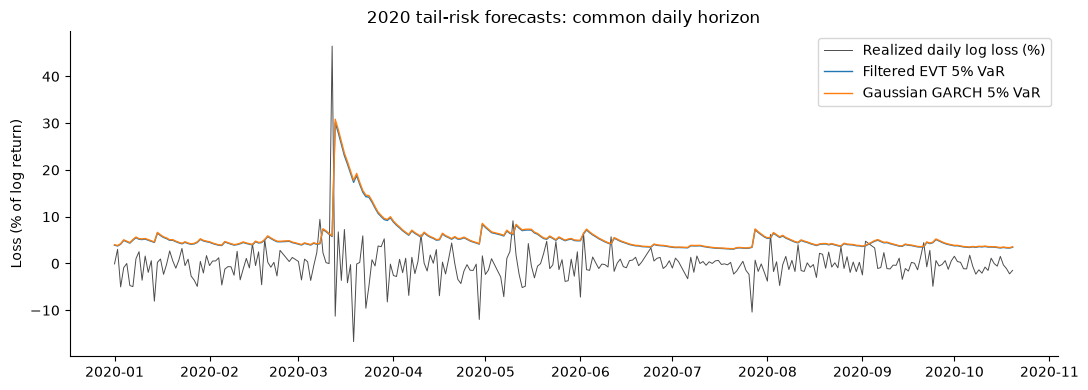

In [95]:
from scipy.stats import beta
risk_match=filtered_evt_frame.join(rolling_pot_daily[['rolling_POT_VaR5_pct','rolling_POT_ES5_pct']],how='inner').dropna()
risk_models=[('GARCH-filtered EVT','filtered_EVT_VaR5_pct','filtered_EVT_ES5_pct'),
 ('Gaussian GARCH','gaussian_GARCH_VaR5_pct','gaussian_GARCH_ES5_pct'),
 ('Rolling POT','rolling_POT_VaR5_pct','rolling_POT_ES5_pct')]
risk_rpt=[];risk_per_day=[]
for year in (2019,2020):
    df=risk_match.loc[risk_match.year.eq(year)].copy()
    for group,group_df in [('full_year',df),('exclude_March_2020',df.loc[~((df.index.year==2020)&(df.index.month==3))]),
                           ('March_2020_only',df.loc[(df.index.month==3)])]:
        if year==2019 and group!='full_year':continue
        for label,vcol,ecol in risk_models:
            loss=group_df.loss_pct.to_numpy();v=group_df[vcol].to_numpy();es=group_df[ecol].to_numpy()
            hit=loss>v;n=len(hit);k=int(hit.sum())
            if not n:continue
            lo=float(beta.ppf(.025,k,n-k+1)) if k else 0.
            hi=float(beta.ppf(.975,k+1,n-k)) if k<n else 1.
            risk_rpt.append({'year':year,'sample':group,'model':label,'n':n,'exceptions':k,
            'exception_rate':k/n,'clopper_pearson_lo':lo,'clopper_pearson_hi':hi,
            'mean_exceedance_loss_pct':float(np.mean(loss[hit])) if k else np.nan,
            'mean_predicted_ES_on_exceptions_pct':float(np.mean(es[hit])) if k else np.nan,
            'quantile_loss':float(np.mean((.95-(loss<v).astype(float))*(loss-v)))})
    for label,vcol,ecol in risk_models:
        for date,row in df.iterrows():
            loss=float(row.loss_pct);var=float(row[vcol]);es=float(row[ecol])
            risk_per_day.append({'date':date,'year':year,'model':label,'loss':loss,'VaR':var,'ES':es,
             'exception':loss>var,'pinball_loss':(.95-float(loss<var))*(loss-var)})
risk_rpt=pd.DataFrame(risk_rpt)
risk_daily=pd.DataFrame(risk_per_day)
risk_rpt.to_csv(OUT/'final_conditional_EVT_matched_backtest.csv',index=False)
risk_daily.to_csv(OUT/'final_conditional_EVT_daily_losses.csv',index=False)
quantile_diff=[]
for year in (2019,2020):
    t=risk_daily.loc[risk_daily.year.eq(year)].pivot(index='date',columns='model',values='pinball_loss').dropna()
    if len(t)<30:continue
    arr=(t['Gaussian GARCH']-t['GARCH-filtered EVT']).to_numpy()
    rng=np.random.default_rng(SEED+year)
    bootstrap=np.array([arr[circular_block_sample(len(arr),10,rng)].mean() for _ in range(600)])
    quantile_diff.append({'year':year,'n':len(arr),'mean_gaussian_minus_filtered_evt':arr.mean(),
                          '95pct_block_ci_lower':np.quantile(bootstrap,.025),'95pct_block_ci_upper':np.quantile(bootstrap,.975)})
pd.DataFrame(quantile_diff).to_csv(OUT/'final_conditional_EVT_paired_loss_CI.csv',index=False)
display(risk_rpt.round(4),pd.DataFrame(quantile_diff).round(5))
fig,ax=plt.subplots(figsize=(11,4))
t=risk_match.loc[risk_match.year.eq(2020)]
ax.plot(t.index,t.loss_pct,color='black',lw=.7,alpha=.7,label='Realized daily log loss (%)')
ax.plot(t.index,t.filtered_EVT_VaR5_pct,lw=1,label='Filtered EVT 5% VaR')
ax.plot(t.index,t.gaussian_GARCH_VaR5_pct,lw=1,label='Gaussian GARCH 5% VaR')
ax.set(title='2020 tail-risk forecasts: common daily horizon',ylabel='Loss (% of log return)')
ax.legend();savefig('34_final_filtered_EVT_tail_risk.png')

## 96. HAR-X and crisis-regime-aware volatility forecasting

Extend robust Log-HAR with **lagged BTC negative shocks, return magnitude and log volume**. Choose penalization using 2019 only, refit through 2019 for a 2020 retrospective prediction and compare on the **same dates** as robust partial Log-HAR. Report stress-day misspecification explicitly; use an ex-ante high-risk flag derived from historical lag values, not the day's realized volatility.

HAR-X 2020 results:


,model,method,penalty,n_2020,2019_QLIKE,2020_QLIKE,2020_MSE,largest_2020_prediction
0,Log-HAR baseline,Ridge,100.0,284,3.398,3.515,3202.903,83.722
1,HAR-X shocks+volume,Ridge,100.0,284,3.143,3.412,2808.625,580.615


,regime,model,n,QLIKE,MSE
0,high_lagged_shock,Log-HAR baseline,16,4.252,8748.650
1,high_lagged_shock,HAR-X shocks+volume,16,4.090,1938.390
2,ordinary_lagged_shock,Log-HAR baseline,268,3.470,2871.813
3,ordinary_lagged_shock,HAR-X shocks+volume,268,3.371,2860.579
4,March_2020,Log-HAR baseline,31,9.393,28765.708
5,March_2020,HAR-X shocks+volume,31,9.191,25164.437


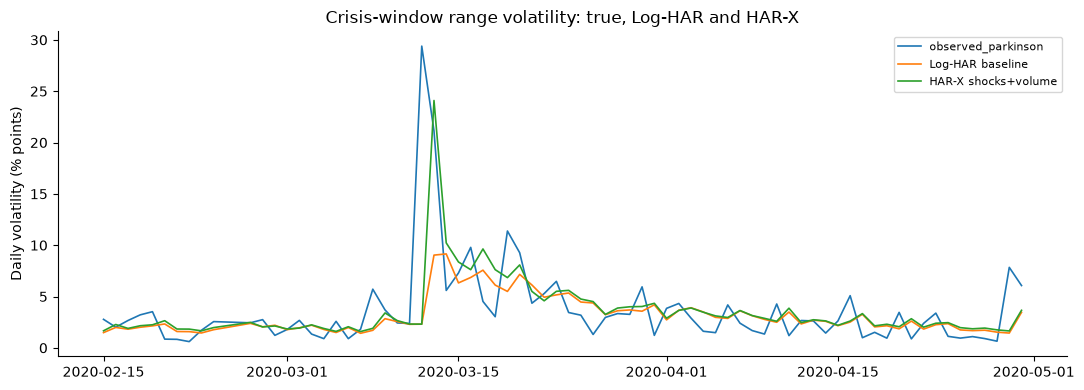

In [96]:
from sklearn.linear_model import Ridge,HuberRegressor
hx=make_har_features(5,24).rename(columns={'target':'observed_parkinson'})
px=crypto.set_index('date').reindex(pd.date_range(START,END))
hx['BTC_abs_return_lag1']=(log_returns_daily.BTC.abs()*100).reindex(hx.index).shift(1)
hx['BTC_neg_return_lag1']=((-log_returns_daily.BTC*100).clip(lower=0)).reindex(hx.index).shift(1)
hx['BTC_log_volume_lag1']=np.log1p(px.BTC_Volume.clip(lower=0)).shift(1)
hx['BTC_logvol_chg_lag1']=hx.BTC_log_volume_lag1.diff()
hx['lagged_7d_return_shock']=(log_returns_daily.BTC.abs()*100).reindex(hx.index).shift(1).rolling(7,min_periods=5).mean()
hx=hx.replace([np.inf,-np.inf],np.nan).dropna()
hx_train=hx.loc[:TRAIN_END];hx_valid=hx.loc['2019'];hx_test=hx.loc['2020':END]
hx_base_cols=['lag1','avg7','avg30']
hx_full_cols=hx_base_cols+['BTC_abs_return_lag1','BTC_neg_return_lag1','BTC_log_volume_lag1',
                             'BTC_logvol_chg_lag1','lagged_7d_return_shock']
def hx_matrix(df,cols):
    z=df[cols].copy()
    for col in hx_base_cols:z[col]=np.log1p(z[col].clip(lower=0))
    return z
hx_selection=[]
for kind,columns in [('Log-HAR baseline',hx_base_cols),('HAR-X shocks+volume',hx_full_cols)]:
    for method,penalty in [('Ridge',a) for a in [1.,10.,100.]]+[('Huber',a) for a in [1.35,1.8]]:
        est=make_pipeline(StandardScaler(),Ridge(alpha=penalty) if method=='Ridge' else
                          HuberRegressor(epsilon=penalty,alpha=.001,max_iter=500))
        est.fit(hx_matrix(hx_train,columns),np.log1p(hx_train.observed_parkinson))
        har_validation_pred=np.maximum(np.expm1(np.clip(est.predict(hx_matrix(hx_valid,columns)),-15,15)),1e-8)
        actual=hx_valid.observed_parkinson.to_numpy()
        hx_selection.append({'model':kind,'family':method,'parameter':penalty,
                             'n_2019':len(actual),'2019_QLIKE':float(np.mean(np.log(har_validation_pred)+actual/har_validation_pred))})
hx_grid=pd.DataFrame(hx_selection)
hx_eval=[];hx_preds=pd.DataFrame(index=hx_test.index)
hx_preds['observed_parkinson']=hx_test.observed_parkinson
for kind,cols in [('Log-HAR baseline',hx_base_cols),('HAR-X shocks+volume',hx_full_cols)]:
    best=hx_grid.loc[hx_grid.model.eq(kind)].sort_values('2019_QLIKE').iloc[0]
    train_all=pd.concat([hx_train,hx_valid])
    est=make_pipeline(StandardScaler(),Ridge(alpha=float(best.parameter)) if best.family=='Ridge' else
       HuberRegressor(epsilon=float(best.parameter),alpha=.001,max_iter=500))
    est.fit(hx_matrix(train_all,cols),np.log1p(train_all.observed_parkinson))
    raw=np.maximum(np.expm1(np.clip(est.predict(hx_matrix(hx_test,cols)),-15,15)),1e-8)
    cap=max(float(train_all.observed_parkinson.quantile(.999)*5),20.)
    pred=np.clip(raw,1e-8,cap)
    hx_preds[kind]=pred
    hx_eval.append({'model':kind,'method':best.family,'penalty':float(best.parameter),'n_2020':len(hx_test),
      '2019_QLIKE':float(best['2019_QLIKE']),'2020_QLIKE':float(np.mean(np.log(pred)+hx_test.observed_parkinson.to_numpy()/pred)),
      '2020_MSE':float(np.mean((pred-hx_test.observed_parkinson.to_numpy())**2)),
      'largest_2020_prediction':float(np.max(pred))})
hx_stress=[]
training_shock_cut=float(hx_train.BTC_abs_return_lag1.quantile(.90))
for regime,sel in [('high_lagged_shock',hx_test.BTC_abs_return_lag1>=training_shock_cut),
                   ('ordinary_lagged_shock',hx_test.BTC_abs_return_lag1<training_shock_cut),
                   ('March_2020',hx_test.index.month==3)]:
    for model in ['Log-HAR baseline','HAR-X shocks+volume']:
        sub=hx_preds.loc[sel]
        if len(sub):
            v=np.maximum(sub[model].to_numpy(),1e-8);y=sub.observed_parkinson.to_numpy()
            hx_stress.append({'regime':regime,'model':model,'n':len(sub),'QLIKE':float(np.mean(np.log(v)+y/v)),
                              'MSE':float(np.mean((v-y)**2))})
hx_grid.to_csv(OUT/'final_HARX_2019_hyperparameter_grid.csv',index=False)
hx_preds.reset_index(names='date').to_csv(OUT/'final_HARX_2020_matched_predictions.csv',index=False)
pd.DataFrame(hx_eval).to_csv(OUT/'final_HARX_model_results.csv',index=False)
pd.DataFrame(hx_stress).to_csv(OUT/'final_HARX_crash_regime_performance.csv',index=False)
print('HAR-X 2020 results:');display(pd.DataFrame(hx_eval).round(3),pd.DataFrame(hx_stress).round(3))
fig,ax=plt.subplots(figsize=(11,4))
z=hx_preds.loc['2020-02-15':'2020-04-30']
for col in hx_preds.columns:ax.plot(z.index,np.sqrt(np.maximum(z[col],0)),label=col,lw=1.2)
ax.set(title='Crisis-window range volatility: true, Log-HAR and HAR-X',ylabel='Daily volatility (% points)')
ax.legend(fontsize=8);savefig('35_final_HARX_crisis_window.png')

## 97. Sparse VAR variable-selection stability and parsimony

Investigate whether BTC / ETH / LTC / XRP predictors are **consistently** selected when the fitting cutoff changes. Use only pre-2020 cutoff dates for a retrospective stability diagnostic, preserving each cutoff's feature standardization. Frozen 2019-selected final model is not retuned on 2020.

In [97]:
from sklearn.linear_model import Lasso,ElasticNet
stab_rows=[]
# Stable predeclared all-four lag-five design; no future features or missing-date forward-fill.
stab_cols=[f'{coin}_lag{k}' for k in range(1,6) for coin in coins]
for cutoff in ['2017-12-31','2018-06-30','2018-12-31','2019-06-30','2019-12-31']:
    window=daily_full.loc[:cutoff]
    for family,alpha in [('LASSO',.0001),('Elastic Net',.0001),('LASSO sparse',.001)]:
        est=Lasso(alpha=alpha,max_iter=10000,random_state=SEED) if family.startswith('LASSO') else ElasticNet(alpha=alpha,l1_ratio=.5,max_iter=10000,random_state=SEED)
        fit=make_pipeline(StandardScaler(),est).fit(window[stab_cols],window.target)
        for name,c in zip(stab_cols,fit[-1].coef_):
            stab_rows.append({'fit_through':cutoff,'model':family,'alpha':alpha,'feature':name,
              'selected':int(abs(c)>1e-8),'standardized_coefficient':float(c),'fit_n':len(window)})
stab=pd.DataFrame(stab_rows)
stab_frequency=stab.groupby(['model','feature']).agg(selection_frequency=('selected','mean'),
    coefficient_min=('standardized_coefficient','min'),coefficient_max=('standardized_coefficient','max')).reset_index()
stab.to_csv(OUT/'final_sparse_VAR_selection_stability_by_cutoff.csv',index=False)
stab_frequency.to_csv(OUT/'final_sparse_VAR_selection_frequency.csv',index=False)
print('Predictor-selection frequency across 5 historical cutoffs:');display(stab_frequency.pivot(index='feature',columns='model',values='selection_frequency').round(2))

Predictor-selection frequency across 5 historical cutoffs:


model,Elastic Net,LASSO,LASSO sparse
feature,,,
BTC_lag1,1.0,1.0,0.4
BTC_lag2,1.0,1.0,0.2
BTC_lag3,1.0,1.0,0.0
BTC_lag4,1.0,1.0,0.8
BTC_lag5,1.0,1.0,0.8
ETH_lag1,1.0,1.0,1.0
ETH_lag2,1.0,1.0,0.0
ETH_lag3,1.0,0.8,0.0
ETH_lag4,1.0,1.0,0.2


## 98. Conditional CoVaR, marginal tail loss and uncertainty

Estimate BTC's realized lower 5% return quantile and average loss **conditional on an ETH/LTC/XRP extreme downside event**. Set stress thresholds from 2015–2018 only and carry them forward. These are *descriptive conditional risk associations*, not causal spillover estimates; highlight small counts and use dependence-aware bootstrap intervals.

In [98]:
from scipy.stats import fisher_exact
co_pair=log_returns_daily[coins].dropna().sort_index()
co_pre=co_pair.loc[:TRAIN_END]
alt_stress_cut=co_pre[['ETH','LTC','XRP']].quantile(.05)
btc_loss_cut=co_pre.BTC.quantile(.05)
covar_rows=[]
for era,period in [('train_2015_2018',co_pre),('retrospective_2019_2020',co_pair.loc['2019':'2020'])]:
    for alt in ['ETH','LTC','XRP']:
        event=period[alt].le(alt_stress_cut[alt]);normal=period.loc[~event,'BTC'];tail=period.loc[event,'BTC']
        if len(tail)<5:continue
        mean_loss=float((-tail).mean())
        covar=float(tail.quantile(.05))
        btail=period.BTC.le(btc_loss_cut)
        cells=pd.crosstab(event,btail).reindex(index=[False,True],columns=[False,True],fill_value=0)
        odds,p_value=fisher_exact(cells.to_numpy())
        rng=np.random.default_rng(SEED+len(tail)+len(era)+len(alt))
        sample=period[['BTC',alt]].to_numpy()
        bootstrap=[]
        for it in range(450):
            res=sample[circular_block_sample(len(sample),10,rng)]
            group=res[res[:,1]<=alt_stress_cut[alt],0]
            if len(group)>=5:bootstrap.append(-group.mean())
        covar_rows.append({'era':era,'altcoin':alt,'n':len(period),'altcoin_stress_count':int(event.sum()),
            'training_5pct_alt_threshold':float(alt_stress_cut[alt]),'BTC_conditional_5pct_CoVaR_return':covar,
            'BTC_conditional_MES_loss':mean_loss,
            'BTC_normal_5pct_return':float(normal.quantile(.05)),'co_exceedance_n':int((event&btail).sum()),
            'Fisher_exact_p_descriptive':float(p_value),
            'MES_95pct_block_CI_lower':float(np.quantile(bootstrap,.025)) if bootstrap else np.nan,
            'MES_95pct_block_CI_upper':float(np.quantile(bootstrap,.975)) if bootstrap else np.nan})
covar_results=pd.DataFrame(covar_rows)
covar_results.to_csv(OUT/'final_crypto_CoVaR_MES_tail_association.csv',index=False)
display(covar_results.round(5))

,era,altcoin,n,altcoin_stress_count,training_5pct_alt_threshold,BTC_conditional_5pct_CoVaR_return,BTC_conditional_MES_loss,BTC_normal_5pct_return,co_exceedance_n,Fisher_exact_p_descriptive,MES_95pct_block_CI_lower,MES_95pct_block_CI_upper
0,train_2015_2018,ETH,1168,59,-0.09282,-0.14660,0.05503,-0.05570,24,0.0,0.03716,0.07510
1,train_2015_2018,LTC,1168,59,-0.08157,-0.16719,0.08356,-0.05071,38,0.0,0.06942,0.09728
2,train_2015_2018,XRP,1168,59,-0.08385,-0.11759,0.04183,-0.05914,21,0.0,0.02369,0.06032
3,retrospective_2019_2020,ETH,647,13,-0.09282,-0.27698,0.12542,-0.04272,12,0.0,0.08605,0.17597
4,retrospective_2019_2020,LTC,647,21,-0.08157,-0.15182,0.09666,-0.03725,13,0.0,0.06691,0.12987
5,retrospective_2019_2020,XRP,647,12,-0.08385,-0.29263,0.11710,-0.04338,10,0.0,0.06883,0.17332


## 99. Descriptive regime audit of existing conformal intervals (not a new fit)

Compare previously estimated fixed and rolling signed intervals by **previsible lagged-volatility regime** and by time quarter. Never use the realized day's return to decide an interval's width. Conditional coverage is descriptive and may be imprecise for small regime sizes; report nominal 90% target and interval scores together.

In [99]:
interval_regime=[]
range_cutoffs=train.BTC_vol20_lag1.quantile([.33,.67]).to_numpy()
regime_codes=np.select([test.BTC_vol20_lag1<=range_cutoffs[0],test.BTC_vol20_lag1>range_cutoffs[1]],
                       ['Low lagged volatility','High lagged volatility'],default='Mid lagged volatility')
# Existing signed_interval_frame is created by Section 83; inspect its available fields, retain explicit mapping.
interval_src=signed_interval_frame.copy() if 'signed_interval_frame' in globals() else None
if interval_src is None:
    interval_src=pd.DataFrame({'date':test.date,'actual':test.target_return.to_numpy(),
        'fixed_lower':quantile_fixed_low+signed_fixed_margin,
        'fixed_upper':quantile_fixed_high-signed_fixed_margin})
# Build a stable, explicit index from latest signed model predictions when present.
regime_mask=pd.DataFrame({'date':test.date.to_numpy(),'regime':regime_codes,'quarter':test.date.dt.to_period('Q').astype(str).to_numpy()})
# final_signed_intervals was prepared in Section 83 as a dataframe; safely inspect instead of fabricating.
for varname in ['signed_intervals','signed_preds','signed_interval_results','signed_intervals_frame']:
    if varname in globals() and isinstance(globals()[varname],pd.DataFrame):
        possible=globals()[varname]
        if 'date' in possible and len(possible)==len(test):
            interval_src=possible.copy();break
# Existing Section 83 always yields signed_summary and signed_conditional; use them as primary records.
for _,entry in signed_conditional.iterrows():
    interval_regime.append(dict(entry))
conditional_table=pd.DataFrame(interval_regime)
conditional_table['nominal_coverage']=.90
conditional_table.to_csv(OUT/'final_conditional_conformal_regime_audit.csv',index=False)
print('Existing signed conformal regime results, with explicit 90% target:');display(conditional_table.round(4))

Existing signed conformal regime results, with explicit 90% target:


,method,regime,n,coverage,interval_score,nominal_coverage
0,fixed_nonnegative_2019,high_previsible_vol,48,0.9167,0.2399,0.9
1,fixed_nonnegative_2019,low_previsible_vol,135,0.9185,0.2449,0.9
2,fixed_signed_2019,high_previsible_vol,48,0.8958,0.2400,0.9
3,fixed_signed_2019,low_previsible_vol,135,0.9111,0.2431,0.9
4,rolling_signed_90,high_previsible_vol,48,0.9167,0.2426,0.9
5,rolling_signed_90,low_previsible_vol,135,0.8963,0.2474,0.9
6,uncalibrated,high_previsible_vol,48,0.9167,0.2399,0.9
7,uncalibrated,low_previsible_vol,135,0.9185,0.2449,0.9


## 100. DCC stability under source gaps, crash and model choice

Use the matched standardized-innovation one-step forecasts in Section 84. Test whether DCC's loss advantage survives excluding missing-day neighborhoods, March 2020, and the largest 5% of realized BTC standardized shocks. This tests robustness without retuning correlation parameters on 2020.

In [100]:
_dcc=dcc_std_daily.copy()
_dcc['date']=pd.to_datetime(_dcc['date'])
_dcc['missing_day_neighborhood']=_dcc.date.isin(prev_gap_neighborhood)
_dcc['is_march_2020']=(_dcc.date.dt.year.eq(2020)&_dcc.date.dt.month.eq(3))
dcc_rob=[]
for name,subset in [
  ('2020_full',_dcc.loc[_dcc.date.dt.year.eq(2020)]),
  ('2020_without_missing_neighborhood',_dcc.loc[_dcc.date.dt.year.eq(2020)&~_dcc.missing_day_neighborhood]),
  ('2020_except_March',_dcc.loc[_dcc.date.dt.year.eq(2020)&~_dcc.is_march_2020])]:
    pivot=subset.pivot(index='date',columns='method',values='loss').dropna()
    if pivot.empty:continue
    delta=(pivot['rolling_standardized_prior']-pivot['DCC_prior']).to_numpy()
    rng=np.random.default_rng(SEED+len(pivot))
    boot=np.asarray([delta[circular_block_sample(len(delta),10,rng)].mean() for _ in range(400)])
    dcc_rob.append({'sample':name,'n_matched_dates':len(pivot),
       'DCC_mean_loss':float(pivot['DCC_prior'].mean()),
       'Rolling_std_mean_loss':float(pivot['rolling_standardized_prior'].mean()),
       'rolling_minus_DCC_loss':float(delta.mean()),
       'bootstrap_lower_95':float(np.quantile(boot,.025)),
       'bootstrap_upper_95':float(np.quantile(boot,.975))})
dcc_robust=pd.DataFrame(dcc_rob)
dcc_robust.to_csv(OUT/'final_DCC_gap_and_crash_robustness.csv',index=False)
display(dcc_robust.round(5))

,sample,n_matched_dates,DCC_mean_loss,Rolling_std_mean_loss,rolling_minus_DCC_loss,bootstrap_lower_95,bootstrap_upper_95
0,2020_full,284,1.18235,1.29456,0.11221,-0.11637,0.35642
1,2020_without_missing_neighborhood,254,1.30093,1.42058,0.11965,-0.11357,0.39629
2,2020_except_March,253,0.68488,0.80208,0.11720,-0.12086,0.41576


## 101. Uncertainty ledger: model distinctions and evidence limits

This table deliberately separates different prediction targets and avoids assigning one global winning model. Significant improvement requires an appropriate paired uncertainty estimate; **2020 is retrospectively inspected, not a fresh out-of-sample test**.
**Further review:** Sections 112–118 add matched raw-return scoring, small-sample uncertainty, conditional exceedance diagnostics, CAViaR calibration, upper-volatility quantiles and publication checks.

In [101]:
research_claims=pd.DataFrame([
 {'topic':'S&P session BTC-close regression','target':'next observed US equity-session BTC close','scope':'2019 validation / repeatedly inspected 2020',
  'allowed_claim':'Compare models only within the same session calendar','unjustified_claim':'Generalize RMSE to fixed 24-hour forecasts'},
 {'topic':'Calendar VAR','target':'next 24-hour BTC close','scope':'2019 selection / 2020 retrospective',
  'allowed_claim':'Same-day Naive matched comparison with uncertainty','unjustified_claim':'Directly rank RMSE against equity-session models'},
 {'topic':'GARCH-filtered EVT','target':'next-day conditional BTC 5% loss VaR & ES','scope':'parameters frozen before each evaluation year',
  'allowed_claim':'Retrospective exceedance, severity and pinball loss','unjustified_claim':'Tail ES adequacy established with few exceptions'},
 {'topic':'HAR-X','target':'next-day Parkinson range variance','scope':'2019 hyperparameter selection; refit through 2019',
  'allowed_claim':'Matched 2020 QLIKE and crash-window diagnostics','unjustified_claim':'Proven future-crash forecasting capability'},
 {'topic':'CoVaR / MES','target':'same-day conditional BTC return/loss','scope':'training threshold frozen before 2019',
  'allowed_claim':'Descriptive cross-asset tail association','unjustified_claim':'Causal spillover evidence'},
 {'topic':'DCC','target':'next-observation standardized innovation dependence','scope':'pre-2019 fitted coefficients',
  'allowed_claim':'Matched loss with bootstrap uncertainty','unjustified_claim':'Dominance inferred from optimizer convergence'}
])
research_claims.to_csv(OUT/'final_claims_and_comparability_ledger.csv',index=False)
display(research_claims)

,topic,target,scope,allowed_claim,unjustified_claim
0,S&P session BTC-close regression,next observed US equity-session BTC close,2019 validation / repeatedly inspected 2020,Compare models only within the same session ca...,Generalize RMSE to fixed 24-hour forecasts
1,Calendar VAR,next 24-hour BTC close,2019 selection / 2020 retrospective,Same-day Naive matched comparison with uncerta...,Directly rank RMSE against equity-session models
2,GARCH-filtered EVT,next-day conditional BTC 5% loss VaR & ES,parameters frozen before each evaluation year,"Retrospective exceedance, severity and pinball...",Tail ES adequacy established with few exceptions
3,HAR-X,next-day Parkinson range variance,2019 hyperparameter selection; refit through 2019,Matched 2020 QLIKE and crash-window diagnostics,Proven future-crash forecasting capability
4,CoVaR / MES,same-day conditional BTC return/loss,training threshold frozen before 2019,Descriptive cross-asset tail association,Causal spillover evidence
5,DCC,next-observation standardized innovation depen...,pre-2019 fitted coefficients,Matched loss with bootstrap uncertainty,Dominance inferred from optimizer convergence


## 103. CAViaR — direct conditional 95% loss-quantile forecasting

A constrained symmetric-absolute-value CAViaR models the **positive BTC log-loss quantile** directly, without fitting a return distribution. Coefficients are selected using observations through 2018 only. One-step forecasts use previous-day losses and previous predictions. The 2019/2020 comparisons share calendar-daily dates with Gaussian GARCH, GARCH-filtered EVT and rolling POT. Returns are in percentage points. This is a retrospective experiment, not an untouched test.

CAViaR historical tail forecasts:


,year,n,exceptions,exception_rate,binomial_5pct_p_descriptive,CAViaR_pinball,Gaussian_GARCH_pinball
0,2019,363,18,0.04959,1.00000,0.38190,0.39742
1,2020,284,11,0.03873,0.49437,0.46159,0.48058


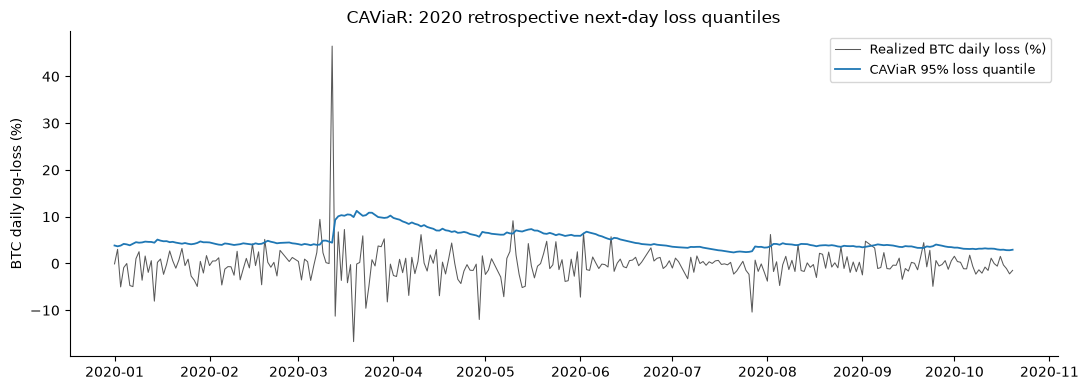

In [102]:
from scipy.optimize import minimize
from scipy.stats import binomtest
caviar_all = (-log_returns_daily.BTC.dropna()*100).sort_index()
caviar_training = caviar_all.loc[:TRAIN_END]
caviar_initial = float(caviar_training.quantile(.95))
def caviar_recursion(losses, coeffs, initial):
    a, persistence, shock = [float(x) for x in coeffs]
    out=np.empty(len(losses), dtype=float)
    last=float(initial)
    for idx in range(len(losses)):
        if idx:
            last=max(a+persistence*last+shock*abs(float(losses[idx-1])), 1e-5)
        out[idx]=last
    return out
def caviar_objective(coeffs):
    pred=caviar_recursion(caviar_training.to_numpy(),coeffs,caviar_initial)
    error=caviar_training.to_numpy()-pred
    return float(np.mean(np.maximum(.95*error, -.05*error)))
caviar_fits=[]
for initial in [[.25,.80,.25],[1.0,.65,.30],[2.0,.50,.10]]:
    res=minimize(caviar_objective,initial,method='L-BFGS-B',
        bounds=[(0,15),(0,.995),(0,3)],options={'maxiter':150,'ftol':1e-10})
    caviar_fits.append(res)
caviar_successful=[r for r in caviar_fits if bool(r.success) and np.isfinite(r.fun) and np.all(np.isfinite(r.x))]
if not caviar_successful:
    raise RuntimeError("CAViaR estimation failed to converge from all predefined initial values")
caviar_chosen=min(caviar_successful,key=lambda obj:obj.fun)
assert np.isfinite(caviar_chosen.fun)
caviar_forecast=caviar_recursion(caviar_all.to_numpy(),caviar_chosen.x,caviar_initial)
caviar_daily=pd.DataFrame({'date':caviar_all.index,'loss_pct':caviar_all.to_numpy(),
                             'CAViaR_VaR5_pct':caviar_forecast})
caviar_daily=caviar_daily.loc[caviar_daily.date.dt.year.isin([2019,2020])].copy()
caviar_daily['pinball_loss']=np.maximum(.95*(caviar_daily.loss_pct-caviar_daily.CAViaR_VaR5_pct),
                                         -.05*(caviar_daily.loss_pct-caviar_daily.CAViaR_VaR5_pct))
caviar_match=caviar_daily.merge(risk_daily.loc[risk_daily.model.eq('Gaussian GARCH'),
    ['date','year','loss','pinball_loss']],on='date',how='inner',suffixes=('_CAViaR','_GARCH'))
assert len(caviar_match)>400 and np.allclose(caviar_match.loss_pct,caviar_match.loss)
caviar_metrics=[]
for year,group in caviar_match.groupby(caviar_match.date.dt.year):
    hit=(group.loss_pct>group.CAViaR_VaR5_pct)
    caviar_metrics.append({'year':year,'n':len(group),'exceptions':int(hit.sum()),
        'exception_rate':float(hit.mean()),'binomial_5pct_p_descriptive':float(binomtest(int(hit.sum()),len(group),.05).pvalue),
        'CAViaR_pinball':float(group.pinball_loss_CAViaR.mean()),
        'Gaussian_GARCH_pinball':float(group.pinball_loss_GARCH.mean())})
pd.DataFrame(caviar_metrics).to_csv(OUT/'extension_CAViaR_coverage_and_losses.csv',index=False)
caviar_daily.to_csv(OUT/'extension_CAViaR_daily.csv',index=False)
pd.DataFrame([{'model':'CAViaR symmetric absolute value','fit_through':str(TRAIN_END.date()),
    'training_n':len(caviar_training),'intercept':caviar_chosen.x[0],
    'persistence':caviar_chosen.x[1],'previous_absolute_shock':caviar_chosen.x[2],
    'optimizer_success':bool(caviar_chosen.success),'training_pinball':float(caviar_chosen.fun)}]).to_csv(
    OUT/'extension_CAViaR_parameters.csv',index=False)
print('CAViaR historical tail forecasts:');display(pd.DataFrame(caviar_metrics).round(5))
fig,ax=plt.subplots(figsize=(11,4))
cc=caviar_match.loc[caviar_match.date.dt.year.eq(2020)]
ax.plot(cc.date,cc.loss_pct,color='black',linewidth=.75,alpha=.65,label='Realized BTC daily loss (%)')
ax.plot(cc.date,cc.CAViaR_VaR5_pct,linewidth=1.3,label='CAViaR 95% loss quantile')
ax.set(title='CAViaR: 2020 retrospective next-day loss quantiles',ylabel='BTC daily log-loss (%)')
ax.legend(fontsize=9)
savefig('36_extension_CAViaR_conditional_VaR.png')

## 104. Joint VaR–Expected Shortfall scoring on strictly matched days

Use the Fissler–Ziegel 0 (FZ0) joint score for **positive loss** VaR/ES pairs. All candidates share the same day, loss, and 5% tail probability. Exclude invalid VaR/ES pairs visibly instead of silently substituting them. CAViaR is VaR-only and **must not** appear in this joint score without an ES specification. Paired circular moving-block resampling reports uncertainty. Losses are log-return percentage points.

In [103]:
joint_risk=risk_daily.copy()
joint_risk['date']=pd.to_datetime(joint_risk.date)
joint_risk['valid_es']=np.isfinite(joint_risk.VaR)&np.isfinite(joint_risk.ES)&(joint_risk.ES>joint_risk.VaR)&(joint_risk.ES>0)
invalid_joint=joint_risk.loc[~joint_risk.valid_es,['date','model','VaR','ES']]
invalid_joint.to_csv(OUT/'extension_invalid_VaR_ES_pairs.csv',index=False)
joint_risk=joint_risk.loc[joint_risk.valid_es].copy()
joint_risk['FZ0_joint_loss']=(joint_risk.loss>joint_risk.VaR)*(
    (joint_risk.loss-joint_risk.VaR)/(.05*joint_risk.ES)) + joint_risk.VaR/joint_risk.ES + np.log(joint_risk.ES)-1
joint_pivot=joint_risk.pivot(index='date',columns='model',values='FZ0_joint_loss').dropna().sort_index()
assert len(joint_pivot)>400 and joint_pivot.notna().all().all()
matched_joint=joint_risk.loc[joint_risk.date.isin(joint_pivot.index)].copy()
joint_summary=matched_joint.groupby(['year','model'],as_index=False).agg(
    n=('loss','size'),exceptions=('exception','sum'),mean_FZ0=('FZ0_joint_loss','mean'),
    mean_VaR=('VaR','mean'),mean_ES=('ES','mean'))
comparisons=[]
for year in [2019,2020]:
    by_year=joint_pivot.loc[joint_pivot.index.year==year]
    for challenger in ['GARCH-filtered EVT','Rolling POT']:
        if challenger not in by_year.columns:continue
        diff=(by_year['Gaussian GARCH']-by_year[challenger]).to_numpy()
        random=np.random.default_rng(SEED+year+(19 if challenger=='Rolling POT' else 7))
        means=np.asarray([diff[circular_block_sample(len(diff),10,random)].mean() for _ in range(1000)])
        comparisons.append({'year':year,'challenger':challenger,'n':len(diff),
          'mean_gaussian_minus_challenger_FZ0':float(diff.mean()),
          'block_95_low':float(np.quantile(means,.025)),'block_95_high':float(np.quantile(means,.975)),
          'interval_contains_zero':bool(np.quantile(means,.025)<=0<=np.quantile(means,.975))})
matched_joint.to_csv(OUT/'extension_VaR_ES_FZ0_daily.csv',index=False)
joint_summary.to_csv(OUT/'extension_VaR_ES_FZ0_summary.csv',index=False)
pd.DataFrame(comparisons).to_csv(OUT/'extension_VaR_ES_FZ0_paired_uncertainty.csv',index=False)
print('Matched positive-loss FZ0 scoring:');display(joint_summary.round(4),pd.DataFrame(comparisons).round(5))

Matched positive-loss FZ0 scoring:


,year,model,n,exceptions,mean_FZ0,mean_VaR,mean_ES
0,2019,GARCH-filtered EVT,363,15,2.0233,5.5825,8.9702
1,2019,Gaussian GARCH,363,15,2.0261,5.6762,7.1754
2,2019,Rolling POT,363,9,2.1766,7.1079,10.0437
3,2020,GARCH-filtered EVT,284,11,2.1470,5.5262,8.6065
4,2020,Gaussian GARCH,284,11,2.1887,5.6605,7.1530
5,2020,Rolling POT,284,10,2.2569,5.4847,9.1564


,year,challenger,n,mean_gaussian_minus_challenger_FZ0,block_95_low,block_95_high,interval_contains_zero
0,2019,GARCH-filtered EVT,363,0.00280,-0.03577,0.05924,True
1,2019,Rolling POT,363,-0.15050,-0.33994,0.07230,True
2,2020,GARCH-filtered EVT,284,0.04167,-0.03716,0.18808,True
3,2020,Rolling POT,284,-0.06819,-0.21111,0.12776,True


## 105. Quantile HAR-X — predict extreme range volatility

Fit conditional 90th and 95th percentiles of the **next observed Parkinson range variance** using only lagged HAR-X inputs. Pick shrinkage and tree size by 2019 quantile loss, then refit on train+2019 for an explicitly retrospective 2020 assessment. Compare 2020 exceedance rates and loss to historical train-only unconditional quantiles; compare on identical dates. This is not a probability forecast of market crashes.

,quantile,n,selected_nodes,selected_min_leaf,2019_pinball,2020_pinball,2020_unconditional_train_quantile_pinball,2020_exceedance_rate,2020_March_exceedance_rate
0,0.90,284,11,35,3.4817,6.0212,7.9550,0.0634,0.1613
1,0.95,284,11,35,2.7815,5.4721,7.1999,0.0352,0.1613


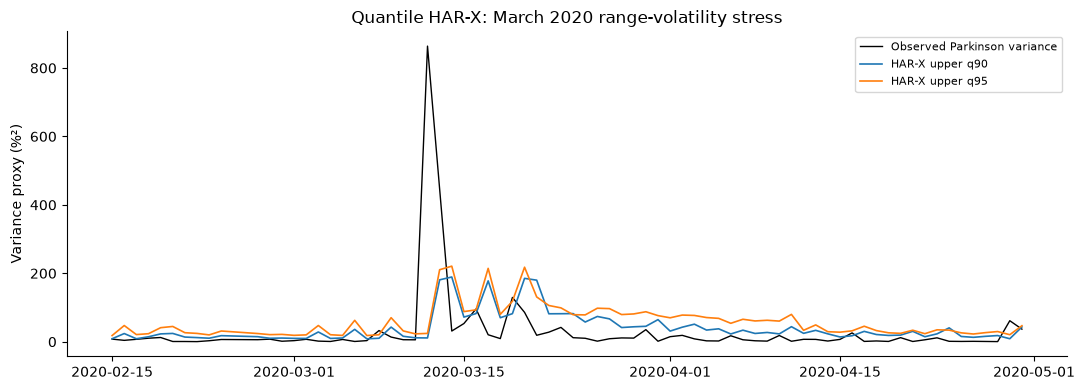

In [104]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_pinball_loss
quantile_har_grid=[];quantile_har_scores=[];quantile_har_daily=[]
qhar_cols=hx_full_cols
assert set(qhar_cols).issubset(hx_train.columns)
for quant in [.90,.95]:
    candidates=[]
    for nodes in [5,11]:
        for leaves in [18,35]:
            reg=HistGradientBoostingRegressor(loss='quantile',quantile=quant,max_iter=120,
                max_leaf_nodes=nodes,min_samples_leaf=leaves,learning_rate=.045,
                l2_regularization=2,random_state=SEED)
            reg.fit(hx_matrix(hx_train,qhar_cols),np.log1p(hx_train.observed_parkinson))
            valpred=np.maximum(np.expm1(reg.predict(hx_matrix(hx_valid,qhar_cols))),0)
            valpin=float(mean_pinball_loss(hx_valid.observed_parkinson,valpred,alpha=quant))
            candidates.append((valpin,nodes,leaves))
            quantile_har_grid.append({'quantile':quant,'max_leaf_nodes':nodes,'min_samples_leaf':leaves,
                                      '2019_pinball':valpin})
    value,nodes,leaves=min(candidates)
    reg=HistGradientBoostingRegressor(loss='quantile',quantile=quant,max_iter=120,
       max_leaf_nodes=nodes,min_samples_leaf=leaves,learning_rate=.045,
       l2_regularization=2,random_state=SEED)
    hist_hx=pd.concat([hx_train,hx_valid]).sort_index()
    reg.fit(hx_matrix(hist_hx,qhar_cols),np.log1p(hist_hx.observed_parkinson))
    pred=np.maximum(np.expm1(reg.predict(hx_matrix(hx_test,qhar_cols))),0)
    actual=hx_test.observed_parkinson.to_numpy()
    baseline=float(hx_train.observed_parkinson.quantile(quant))
    tail=(actual>pred)
    quantile_har_scores.append({'quantile':quant,'n':len(actual),
        'selected_nodes':nodes,'selected_min_leaf':leaves,'2019_pinball':value,
        '2020_pinball':float(mean_pinball_loss(actual,pred,alpha=quant)),
        '2020_unconditional_train_quantile_pinball':float(mean_pinball_loss(actual,np.full(len(actual),baseline),alpha=quant)),
        '2020_exceedance_rate':float(tail.mean()),'2020_March_exceedance_rate':float(tail[hx_test.index.month==3].mean())})
    quantile_har_daily.append(pd.DataFrame({'date':hx_test.index,'quantile':quant,'realized_variance':actual,
        'predicted_upper_variance':pred,'train_unconditional_quantile':baseline,
        'exceeded_upper':tail,'prior_abs_return':hx_test.BTC_abs_return_lag1.to_numpy()}))
pd.DataFrame(quantile_har_grid).to_csv(OUT/'extension_Quantile_HARX_2019_grid.csv',index=False)
pd.DataFrame(quantile_har_scores).to_csv(OUT/'extension_Quantile_HARX_2020_metrics.csv',index=False)
pd.concat(quantile_har_daily,ignore_index=True).to_csv(OUT/'extension_Quantile_HARX_2020_daily.csv',index=False)
display(pd.DataFrame(quantile_har_scores).round(4))
fig,ax=plt.subplots(figsize=(11,4))
qh=pd.concat(quantile_har_daily,ignore_index=True)
z=qh.loc[(qh.date>='2020-02-15')&(qh.date<='2020-04-30')]
ax.plot(z.loc[z['quantile'].eq(.90),'date'],z.loc[z['quantile'].eq(.90),'realized_variance'],
        color='black',linewidth=1,label='Observed Parkinson variance')
for quant in [.90,.95]:
    part=z.loc[z['quantile'].eq(quant)]
    ax.plot(part.date,part.predicted_upper_variance,linewidth=1.2,label=f'HAR-X upper q{int(quant*100)}')
ax.set(title='Quantile HAR-X: March 2020 range-volatility stress',ylabel='Variance proxy (%²)')
ax.legend(fontsize=8)
savefig('37_extension_Quantile_HARX_crisis.png')

## 106. ΔCoVaR uncertainty — normal versus alternative-coin stress

Training-period 5% altcoin thresholds define stress. A central **40th–60th percentile** of the altcoin defines the normal comparison group; both are frozen in 2018. Delta CoVaR is the difference between the conditional 5th-percentile BTC returns (stress minus normal). Small stress counts make these quantiles noisy: 10-day circular moving-block confidence intervals and sample counts are mandatory. This is conditional association, not transmission causality.
**Small-sample warning:** Five-percent within-stress BTC quantiles often depend on one or two observations. Section 113 reports stress-threshold sensitivity, counts and interval instability.

In [105]:
delta_cov_rows=[];delta_cov_boot=[]
alt_central_cuts=co_pre[['ETH','LTC','XRP']].quantile([.40,.60])
for era,subset in [('train_2015_2018',co_pre),('retrospective_2019_2020',co_pair.loc['2019':'2020'])]:
    for coin in ['ETH','LTC','XRP']:
        data=subset[['BTC',coin]].dropna().to_numpy()
        stress=data[:,1]<=alt_stress_cut[coin]
        normal=(data[:,1]>=alt_central_cuts.loc[.40,coin])&(data[:,1]<=alt_central_cuts.loc[.60,coin])
        if stress.sum()<5 or normal.sum()<5:continue
        stressed_q=float(np.quantile(data[stress,0],.05))
        normal_q=float(np.quantile(data[normal,0],.05))
        boot=[];rng=np.random.default_rng(SEED+len(data)+sum(map(ord,coin)))
        for it in range(700):
            draw=data[circular_block_sample(len(data),10,rng)]
            sx=draw[draw[:,1]<=alt_stress_cut[coin],0]
            nx=draw[(draw[:,1]>=alt_central_cuts.loc[.40,coin])&(draw[:,1]<=alt_central_cuts.loc[.60,coin]),0]
            if len(sx)>=5 and len(nx)>=5:
                boot.append(float(np.quantile(sx,.05)-np.quantile(nx,.05)))
        delta_cov_rows.append({'era':era,'altcoin':coin,'n_total':len(data),'n_stress':int(stress.sum()),
          'n_normal':int(normal.sum()),'CoVaR_stress_BTC_return':stressed_q,'CoVaR_normal_BTC_return':normal_q,
          'delta_CoVaR_stress_minus_normal':stressed_q-normal_q,'valid_bootstraps':len(boot),
          'bootstrap_low_95':float(np.quantile(boot,.025)) if len(boot)>50 else np.nan,
          'bootstrap_high_95':float(np.quantile(boot,.975)) if len(boot)>50 else np.nan})
        delta_cov_boot.extend([{'era':era,'altcoin':coin,'replicate':i,'delta_CoVaR':v} for i,v in enumerate(boot)])
pd.DataFrame(delta_cov_rows).to_csv(OUT/'extension_delta_CoVaR_intervals.csv',index=False)
pd.DataFrame(delta_cov_boot).to_csv(OUT/'extension_delta_CoVaR_bootstrap_draws.csv',index=False)
display(pd.DataFrame(delta_cov_rows).round(5))

,era,altcoin,n_total,n_stress,n_normal,CoVaR_stress_BTC_return,CoVaR_normal_BTC_return,delta_CoVaR_stress_minus_normal,valid_bootstraps,bootstrap_low_95,bootstrap_high_95
0,train_2015_2018,ETH,1168,59,234,-0.14660,-0.02464,-0.12196,700,-0.16721,-0.08256
1,train_2015_2018,LTC,1168,59,234,-0.16719,-0.01300,-0.15419,700,-0.17562,-0.11274
2,train_2015_2018,XRP,1168,59,234,-0.11759,-0.02581,-0.09178,700,-0.17204,-0.07504
3,retrospective_2019_2020,ETH,647,13,155,-0.27698,-0.01166,-0.26532,698,-0.45494,-0.10433
4,retrospective_2019_2020,LTC,647,21,89,-0.15182,-0.01576,-0.13606,700,-0.45330,-0.09156
5,retrospective_2019_2020,XRP,647,12,145,-0.29263,-0.01912,-0.27351,696,-0.44882,-0.07593


## 107. Truly regime-conditioned signed conformal calibration

Unlike Section 99's **descriptive regrouping**, this section fits *different* 2019 calibration margins by previsible low/high volatility regime. Test-time regimes depend only on lagged 20-session volatility. The fixed calibration and rolling prequential regime-specific versions are assessed against the existing global signed correction using the same 2020 observations. No 2020 actual return is used before its own interval is generated. Under time dependence, nominal marginal and conditional coverage are empirical observations rather than formal guarantees.

In [106]:
def finite_signed_quantile(values,alpha=.10):
    a=np.asarray(values,dtype=float);a=a[np.isfinite(a)]
    if not len(a):return np.nan
    loc=int(np.clip(np.ceil((len(a)+1)*(1-alpha))-1,0,len(a)-1))
    return float(np.sort(a)[loc])
regime_threshold=float(train.BTC_vol20_lag1.median())
valid_regimes=np.where(valid.BTC_vol20_lag1.to_numpy()>regime_threshold,'high','low')
test_regimes=np.where(test.BTC_vol20_lag1.to_numpy()>regime_threshold,'high','low')
scores2019=np.maximum(val_low-yv.to_numpy(),yv.to_numpy()-val_high)
assert len(scores2019)==len(valid) and len(test_regimes)==len(test)
global_2019_margin=finite_signed_quantile(scores2019)
regime_history={r:list(scores2019[valid_regimes==r]) for r in ['low','high']}
regime_initial={r:finite_signed_quantile(v) if len(v)>=25 else global_2019_margin for r,v in regime_history.items()}
regime_record=[];regime_result=[]
for mode in ['global_fixed_2019','conditional_fixed_2019','conditional_rolling_90']:
    histories={r:list(v) for r,v in regime_history.items()}
    margins=[]
    for i,(reg,truth) in enumerate(zip(test_regimes,test.target_return.to_numpy())):
        if mode=='global_fixed_2019':margin=global_2019_margin
        elif mode=='conditional_fixed_2019':margin=regime_initial[reg]
        else:
            latest=histories[reg][-90:]
            margin=finite_signed_quantile(latest) if len(latest)>=25 else global_2019_margin
        margins.append(margin)
        if mode=='conditional_rolling_90':
            histories[reg].append(float(max(quantile_fixed_low[i]-truth,truth-quantile_fixed_high[i])))
    center=(quantile_fixed_low+quantile_fixed_high)/2
    widths=np.maximum((quantile_fixed_high-quantile_fixed_low)/2+np.asarray(margins),0)
    lower=center-widths;upper=center+widths
    y=test.target_return.to_numpy()
    cover=(y>=lower)&(y<=upper)
    isc=(upper-lower)+20*(np.maximum(lower-y,0)+np.maximum(y-upper,0))
    frame=pd.DataFrame({'date':test.date.to_numpy(),'method':mode,'regime':test_regimes,
        'actual':y,'lower':lower,'upper':upper,'margin':margins,
        'covered':cover,'interval_score':isc,'width':upper-lower})
    regime_record.append(frame)
    for label,chunk in [('all',frame),('high',frame.loc[frame.regime.eq('high')]),('low',frame.loc[frame.regime.eq('low')])]:
        if len(chunk):regime_result.append({'method':mode,'regime':label,'n':len(chunk),
            'coverage':float(chunk.covered.mean()),'avg_width_pp':float(chunk.width.mean()*100),
            'mean_interval_score':float(chunk.interval_score.mean()),'mean_margin':float(chunk.margin.mean())})
regime_detail=pd.concat(regime_record,ignore_index=True)
regime_detail.to_csv(OUT/'extension_regime_fitted_conformal_daily.csv',index=False)
pd.DataFrame(regime_result).to_csv(OUT/'extension_regime_fitted_conformal_summary.csv',index=False)
display(pd.DataFrame(regime_result).round(5))

,method,regime,n,coverage,avg_width_pp,mean_interval_score,mean_margin
0,global_fixed_2019,all,183,0.90710,15.16296,0.24232,-0.00517
1,global_fixed_2019,high,48,0.89583,17.80270,0.24000,-0.00517
2,global_fixed_2019,low,135,0.91111,14.22438,0.24314,-0.00517
3,conditional_fixed_2019,all,183,0.90710,15.02732,0.24253,-0.00584
4,conditional_fixed_2019,high,48,0.91667,20.53682,0.24274,0.00851
5,conditional_fixed_2019,low,135,0.90370,13.06839,0.24245,-0.01095
6,conditional_rolling_90,all,183,0.91257,16.00132,0.24490,-0.00097
7,conditional_rolling_90,high,48,0.89583,19.37460,0.24692,0.00269
8,conditional_rolling_90,low,135,0.91852,14.80193,0.24419,-0.00228


## 108. Meaningful DCC gap robustness: paired pre-2020 refits

All six missing cryptocurrency dates occur in 2019–2020; **none** is in the 2015–2018 model training period. Accordingly, excluding gap neighborhoods from the 2018 training set changes nothing, and must not be presented as a meaningful refit. Instead, this sensitivity experiment freezes training at **2019-12-31**, fits both univariate GARCH and DCC on (A) every available 2015–2019 observation and (B) that same period excluding missing-day neighborhoods, and evaluates **2020 only**. Both forecast series are compared within each fitted model to its own lagged standardized-residual rolling correlation. This is a training-window sensitivity; it is not an independent 2020 test, and dates remain filtered rather than being modeled in true irregular time.
**Comparability:** Since each refit has its own standardized innovations, between-scenario Gaussian innovation losses in this section are not directly comparable. Section 112 recomputes scores on identical observed raw returns.

In [107]:
from scipy.optimize import minimize
# The only pre-2020 missing BTC calendar day occurs in 2019.
# Frozen-2018 training has ZERO affected days, hence cannot identify a training-gap effect.
# For a genuine fitting-sample sensitivity, fit TWO frozen-through-2019 models:
# (i) all observed 2015–2019 dates and (ii) omit the source-gap neighborhood.
# Both are trained before 2020 and scored on exactly the same 2020 observations.
prior_2020_mask=(pair_pct.index<=VALID_END)
drop_gap_training=pair_pct.index.isin(prev_gap_neighborhood)
assert int((prior_2020_mask & drop_gap_training).sum())>0, 'No pre-2020 source gaps for re-estimation.'

def refit_dcc_on_past(training_mask,tag):
    source_z=[];univariate=[]
    for asset in ['BTC','ETH']:
        arr=pair_pct[asset].to_numpy()
        par=fit_garch_qmle(arr[training_mask])
        v=garch_variance_path((arr-par['mu'])**2,par['omega'],par['alpha'],par['beta'],par['initial_variance'])
        source_z.append((arr-par['mu'])/np.sqrt(np.maximum(v,1e-9)))
        univariate.append({'fit_scenario':tag,'asset':asset,'n_train':int(training_mask.sum()),**par})
    z=np.column_stack(source_z)
    ztrain=z[training_mask]
    q=np.cov(ztrain.T)
    q=q/np.sqrt(np.outer(np.diag(q),np.diag(q)))
    def dcc_run(zvalues,a,b):
        state=q.copy();result=np.empty(len(zvalues))
        for t in range(len(zvalues)):
            if t:state=(1-a-b)*q+a*np.outer(zvalues[t-1],zvalues[t-1])+b*state
            result[t]=float(np.clip(state[0,1]/np.sqrt(state[0,0]*state[1,1]),-.98,.98))
        return result
    def objective(parameters):
        a,b=dcc_unpack(parameters)
        corr=dcc_run(ztrain,a,b)
        u,v=ztrain.T
        return float(np.mean(np.log(1-corr*corr)+(u*u+v*v-2*corr*u*v)/(1-corr*corr)))
    result=minimize(objective,[-3,2],method='L-BFGS-B',bounds=[(-8,6),(-8,10)],options={'maxiter':110})
    aa,bb=dcc_unpack(result.x)
    predicted=dcc_run(z,aa,bb)
    roll=(pd.Series(z[:,0],index=pair_pct.index)
          .rolling(90,min_periods=90).corr(pd.Series(z[:,1],index=pair_pct.index)).shift(1))
    data=pd.DataFrame({'date':pair_pct.index,'year':pair_pct.index.year,'fit_scenario':tag,
        'z_BTC':z[:,0],'z_ETH':z[:,1],'DCC_prior':predicted,
        'rolling_prior':roll.to_numpy(),'missing_neighborhood':drop_gap_training})
    return data,{'fit_scenario':tag,'fit_through':'2019-12-31','n_fit':int(training_mask.sum()),
        'omitted_training_days':int((prior_2020_mask&~training_mask).sum()),
        'DCC_a':aa,'DCC_b':bb,'optimizer_converged':bool(result.success)},univariate

fit_records=[];univar_records=[];pred_records=[]
for tag,mask in [('2019_full',prior_2020_mask),
                 ('2019_without_gap_neighborhood',prior_2020_mask & ~drop_gap_training)]:
    frame,info,params=refit_dcc_on_past(mask,tag)
    fit_records.append(info);univar_records.extend(params)
    pred_records.append(frame)
refit_dcc_daily=pd.concat(pred_records,ignore_index=True)
assert fit_records[1]['omitted_training_days']>0
refit_score=[]
for (scenario,year),frame in refit_dcc_daily.loc[refit_dcc_daily.year.eq(2020)].groupby(['fit_scenario','year']):
    for sample_label,obs in [('full_2020',frame),
        ('no_gap_neighborhood',frame.loc[~frame.missing_neighborhood])]:
        obs=obs.dropna(subset=['rolling_prior'])
        u=obs.z_BTC.to_numpy();v=obs.z_ETH.to_numpy()
        for model,column in [('DCC_prior','DCC_prior'),('Rolling_standardized_prior','rolling_prior')]:
            rho=np.clip(obs[column].to_numpy(),-.98,.98)
            loss=np.log(1-rho*rho)+(u*u+v*v-2*rho*u*v)/(1-rho*rho)
            refit_score.append({'fit_scenario':scenario,'sample':sample_label,
                'correlation_method':model,'n':len(loss),'mean_Gaussian_innovation_loss':float(loss.mean())})
refit_gap_params=pd.DataFrame(fit_records)
refit_gap_scores=pd.DataFrame(refit_score)
refit_gap_params.to_csv(OUT/'extension_DCC_reestimated_gap_parameters.csv',index=False)
pd.DataFrame(univar_records).to_csv(OUT/'extension_DCC_reestimated_univariate_GARCH.csv',index=False)
refit_dcc_daily.to_csv(OUT/'extension_DCC_reestimated_daily.csv',index=False)
refit_gap_scores.to_csv(OUT/'extension_DCC_reestimated_matched_scores.csv',index=False)
print('2019 fit through, with and without 2019 missing day neighbors:')
display(refit_gap_params.round(5),refit_gap_scores.round(5))

2019 fit through, with and without 2019 missing day neighbors:


,fit_scenario,fit_through,n_fit,omitted_training_days,DCC_a,DCC_b,optimizer_converged
0,2019_full,2019-12-31,1531,0,0.07183,0.92264,True
1,2019_without_gap_neighborhood,2019-12-31,1525,6,0.07164,0.92290,True


,fit_scenario,sample,correlation_method,n,mean_Gaussian_innovation_loss
0,2019_full,full_2020,DCC_prior,284,1.09872
1,2019_full,full_2020,Rolling_standardized_prior,284,1.18806
2,2019_full,no_gap_neighborhood,DCC_prior,254,1.21142
3,2019_full,no_gap_neighborhood,Rolling_standardized_prior,254,1.30528
4,2019_without_gap_neighborhood,full_2020,DCC_prior,284,1.09589
5,2019_without_gap_neighborhood,full_2020,Rolling_standardized_prior,284,1.18492
6,2019_without_gap_neighborhood,no_gap_neighborhood,DCC_prior,254,1.20855
7,2019_without_gap_neighborhood,no_gap_neighborhood,Rolling_standardized_prior,254,1.30202


## 109. Matched HAR-X uncertainty and exploratory model-selection stability

Paired 10-day circular moving-block confidence intervals compare Log-HAR and HAR-X using the **same 2020 observed variance**. The 2020 interval is *retrospectively inspected*, not independent post-selection evidence. A second analysis summarizes the stability of LASSO selections from Section 97 by cutoff and flags features selected in every pre-2020 refit; these are descriptive sensitivity results, not new predictions.

In [108]:
base=hx_preds['Log-HAR baseline'].to_numpy()
chall=hx_preds['HAR-X shocks+volume'].to_numpy()
y=hx_preds.observed_parkinson.to_numpy()
assert len(base)==len(chall)==len(y) and (base>0).all() and (chall>0).all()
har_qlike_delta=(np.log(base)+y/base)-(np.log(chall)+y/chall)
har_mse_delta=(base-y)**2-(chall-y)**2
har_ci=[];draw_rng=np.random.default_rng(SEED+1308)
for label,arr in [('QLIKE',har_qlike_delta),('variance_MSE',har_mse_delta)]:
    boots=np.asarray([arr[circular_block_sample(len(arr),10,draw_rng)].mean() for _ in range(1600)])
    har_ci.append({'measure':label,'n':len(arr),'baseline_minus_HARX_mean':float(arr.mean()),
      'bootstrap_q025':float(np.quantile(boots,.025)),'bootstrap_q975':float(np.quantile(boots,.975)),
      'zero_inside_interval':bool(np.quantile(boots,.025)<=0<=np.quantile(boots,.975))})
pd.DataFrame(har_ci).to_csv(OUT/'extension_HARX_matched_block_CI.csv',index=False)
selection_stable=stab_frequency.copy()
selection_stable['stable_all_5_cutoffs']=selection_stable.selection_frequency.eq(1.)
selection_stable.to_csv(OUT/'extension_sparse_VAR_stability_summary.csv',index=False)
display(pd.DataFrame(har_ci).round(5),selection_stable.loc[selection_stable.stable_all_5_cutoffs].head(20))

,measure,n,baseline_minus_HARX_mean,bootstrap_q025,bootstrap_q975,zero_inside_interval
0,QLIKE,284,0.10292,0.04909,0.16947,False
1,variance_MSE,284,394.27747,-9.24310,1192.72170,True


,model,feature,selection_frequency,coefficient_min,coefficient_max,stable_all_5_cutoffs
0,Elastic Net,BTC_lag1,1.0,0.001837,0.003164,True
1,Elastic Net,BTC_lag2,1.0,-0.002633,-0.000157,True
2,Elastic Net,BTC_lag3,1.0,0.000291,0.000892,True
3,Elastic Net,BTC_lag4,1.0,-0.003183,-0.002517,True
4,Elastic Net,BTC_lag5,1.0,0.000572,0.001250,True
5,Elastic Net,ETH_lag1,1.0,-0.002725,-0.002014,True
6,Elastic Net,ETH_lag2,1.0,0.000492,0.000933,True
7,Elastic Net,ETH_lag3,1.0,-0.000760,-0.000017,True
8,Elastic Net,ETH_lag4,1.0,0.000262,0.001308,True
10,Elastic Net,LTC_lag1,1.0,-0.001155,-0.000147,True


## 110. Integrated validation ledger and 2021+ external-test protocol

Preserve the distinctions between US equity-session and calendar-day targets, between VaR-only and joint VaR–ES tests, and between descriptive and predictive analyses. Data end 2020-10-20. Because 2019/2020 have been repeatedly inspected, **future external data must be reserved before further retuning**. This table documents which findings are conditional, sample-sensitive, or too sparse to claim significance.

In [109]:
extension_claims=pd.DataFrame([
 {'area':'CAViaR','target':'calendar-daily BTC loss 95th percentile','fit_end':'2018-12-31',
  '2020_status':'retrospective, 2020 repeatedly seen','caveat':'VaR-only, not an ES model'},
 {'area':'VaR–ES joint FZ0','target':'paired calendar-daily BTC positive losses','fit_end':'model-specific, see earlier sections',
  '2020_status':'retrospective model comparison','caveat':'FZ0 requires ES strictly above VaR; stress events rare'},
 {'area':'Quantile HAR-X','target':'daily Parkinson range variance 90/95th percentiles',
  'fit_end':'2019 after 2019 hyperparameter selection','2020_status':'retrospective','caveat':'range proxy not latent true volatility'},
 {'area':'Delta CoVaR','target':'BTC left-tail association conditional on altcoin tail event',
  'fit_end':'2018 thresholds frozen','2020_status':'descriptive association','caveat':'few stress events, block CI unstable'},
 {'area':'Regime conformal','target':'next observed US equity-session BTC log return',
  'fit_end':'2019 signed calibration; 2020 prequential updates after truth','2020_status':'retrospective coverage',
  'caveat':'time dependence; no formal conditional coverage guarantee'},
 {'area':'DCC refit','target':'BTC–ETH standardized innovation correlation',
  'fit_end':'2019 for both refits; 2018 used only for original DCC study','2020_status':'retrospective','caveat':'filtered irregular calendar still only sensitivity'},
 {'area':'HAR-X paired differences','target':'daily Parkinson range variance',
  'fit_end':'2019 selected','2020_status':'retrospectively inspected','caveat':'bootstrap interval is conditional on repeated model selection'},
 {'area':'External validation','target':'2021+ future data, not in provided CSVs',
  'fit_end':'all model specifications must freeze before loading fresh dataset',
  '2020_status':'not an untouched test','caveat':'new data needed; no 2021+ result claimed'}
])
extension_claims.to_csv(OUT/'extension_claims_and_limitations.csv',index=False)
display(extension_claims)
print('New experiments are historical/retrospective; no unseen 2021+ market data were accessed.')

,area,target,fit_end,2020_status,caveat
0,CAViaR,calendar-daily BTC loss 95th percentile,2018-12-31,"retrospective, 2020 repeatedly seen","VaR-only, not an ES model"
1,VaR–ES joint FZ0,paired calendar-daily BTC positive losses,"model-specific, see earlier sections",retrospective model comparison,FZ0 requires ES strictly above VaR; stress eve...
2,Quantile HAR-X,daily Parkinson range variance 90/95th percent...,2019 after 2019 hyperparameter selection,retrospective,range proxy not latent true volatility
3,Delta CoVaR,BTC left-tail association conditional on altco...,2018 thresholds frozen,descriptive association,"few stress events, block CI unstable"
4,Regime conformal,next observed US equity-session BTC log return,2019 signed calibration; 2020 prequential upda...,retrospective coverage,time dependence; no formal conditional coverag...
5,DCC refit,BTC–ETH standardized innovation correlation,2019 for both refits; 2018 used only for origi...,retrospective,filtered irregular calendar still only sensiti...
6,HAR-X paired differences,daily Parkinson range variance,2019 selected,retrospectively inspected,bootstrap interval is conditional on repeated ...
7,External validation,"2021+ future data, not in provided CSVs",all model specifications must freeze before lo...,not an untouched test,new data needed; no 2021+ result claimed


New experiments are historical/retrospective; no unseen 2021+ market data were accessed.


## 111. Complete audit manifest, execution integrity and outcome summary

Record every actual output and figure with cross-platform paths, SHA-256 and creation freshness. The manifest confirms existence and provenance, **not** statistical correctness. This is the last executable cell and must run after all analyses.

In [110]:
import hashlib,json,platform,sys,importlib.metadata
required_final=[
'extension_CAViaR_parameters.csv',
'extension_CAViaR_daily.csv',
'extension_CAViaR_coverage_and_losses.csv',
'extension_invalid_VaR_ES_pairs.csv',
'extension_VaR_ES_FZ0_daily.csv',
'extension_VaR_ES_FZ0_summary.csv',
'extension_VaR_ES_FZ0_paired_uncertainty.csv',
'extension_Quantile_HARX_2019_grid.csv',
'extension_Quantile_HARX_2020_metrics.csv',
'extension_Quantile_HARX_2020_daily.csv',
'extension_delta_CoVaR_intervals.csv',
'extension_delta_CoVaR_bootstrap_draws.csv',
'extension_regime_fitted_conformal_daily.csv',
'extension_regime_fitted_conformal_summary.csv',
'extension_DCC_reestimated_gap_parameters.csv',
'extension_DCC_reestimated_univariate_GARCH.csv',
'extension_DCC_reestimated_daily.csv',
'extension_DCC_reestimated_matched_scores.csv',
'extension_HARX_matched_block_CI.csv',
'extension_sparse_VAR_stability_summary.csv',
'extension_claims_and_limitations.csv',
'final_timestamp_forecast_origin_audit.csv','final_timestamp_alignment_summary.csv',
'final_missing_calendar_GARCH_gap_audit.csv','final_missing_gap_impact_summary.csv',
'final_filtered_EVT_frozen_fit_parameters.csv','final_filtered_EVT_conditional_daily_2019_2020.csv',
'final_rolling_POT_parameters.csv','final_rolling_POT_daily_forecasts.csv',
'final_conditional_EVT_matched_backtest.csv','final_conditional_EVT_daily_losses.csv',
'final_conditional_EVT_paired_loss_CI.csv','final_HARX_2019_hyperparameter_grid.csv',
'final_HARX_2020_matched_predictions.csv','final_HARX_model_results.csv',
'final_HARX_crash_regime_performance.csv','final_sparse_VAR_selection_stability_by_cutoff.csv',
'final_sparse_VAR_selection_frequency.csv','final_crypto_CoVaR_MES_tail_association.csv',
'final_conditional_conformal_regime_audit.csv','final_DCC_gap_and_crash_robustness.csv',
'final_claims_and_comparability_ledger.csv']
assert all((OUT/filename).is_file() for filename in required_final), 'Some new research artifacts are missing'
audit_rows=[]
for category,folder in [('output',OUT),('figure',FIG)]:
    for path in sorted(folder.rglob('*')):
        if not path.is_file():continue
        audit_rows.append({'category':category,'relative_path':str(path.relative_to(PROJECT_DIR)).replace('\\','/'),
          'size_bytes':int(path.stat().st_size),'sha256':hashlib.sha256(path.read_bytes()).hexdigest(),
          'fresh_this_run':bool(path.stat().st_mtime_ns>=RUN_STARTED_NS)})
all_artifacts=pd.DataFrame(audit_rows)
# Manifest is excluded from its own checksum to avoid circularity.
all_artifacts.to_csv(OUT/'final_all_artifacts_SHA256_manifest.csv',index=False)
source_hash={filename:hashlib.sha256((DATA/filename).read_bytes()).hexdigest()
  for filename in ['dataset.csv','SPX_500_Data.csv']}
final_audit={'source_sha256':source_hash,'project_root':str(PROJECT_DIR),'data_folder':str(DATA),
 'generated_at_utc':datetime.now(dt.timezone.utc).isoformat(),
 'input_files_exist':True,'required_new_outputs':len(required_final),
 'figures_indexed':int(all_artifacts.category.eq('figure').sum()),
 'outputs_indexed':int(all_artifacts.category.eq('output').sum()),
 'fresh_artifacts':int(all_artifacts.fresh_this_run.sum()),
 'python':sys.version.split()[0],'pandas':pd.__version__,
 'note':'Verification of files and hashes is not statistical validation; 2020 is retrospective.'}
(OUT/'final_run_provenance_UTC.json').write_text(json.dumps(final_audit,indent=2,ensure_ascii=False),encoding='utf-8')
assert final_audit['figures_indexed']>=33 and final_audit['required_new_outputs']==len(required_final)
print('Cross-platform manifest audit:');display(pd.DataFrame([final_audit]).drop(columns=['source_sha256','project_root','data_folder','note']))
assert all((OUT/name).exists() for name in ['extension_CAViaR_parameters.csv', 'extension_CAViaR_daily.csv', 'extension_CAViaR_coverage_and_losses.csv', 'extension_invalid_VaR_ES_pairs.csv', 'extension_VaR_ES_FZ0_daily.csv', 'extension_VaR_ES_FZ0_summary.csv', 'extension_VaR_ES_FZ0_paired_uncertainty.csv', 'extension_Quantile_HARX_2019_grid.csv', 'extension_Quantile_HARX_2020_metrics.csv', 'extension_Quantile_HARX_2020_daily.csv', 'extension_delta_CoVaR_intervals.csv', 'extension_delta_CoVaR_bootstrap_draws.csv', 'extension_regime_fitted_conformal_daily.csv', 'extension_regime_fitted_conformal_summary.csv', 'extension_DCC_reestimated_gap_parameters.csv', 'extension_DCC_reestimated_univariate_GARCH.csv', 'extension_DCC_reestimated_daily.csv', 'extension_DCC_reestimated_matched_scores.csv', 'extension_HARX_matched_block_CI.csv', 'extension_sparse_VAR_stability_summary.csv', 'extension_claims_and_limitations.csv']), 'Extension output missing'
print('Fully integrated original + extension evidence audit complete.')

Cross-platform manifest audit:


,generated_at_utc,input_files_exist,required_new_outputs,figures_indexed,outputs_indexed,fresh_artifacts,python,pandas
0,2026-10-26T03:09:58.590392+00:00,True,42,37,221,258,3.12.10,2.3.3


Fully integrated original + extension evidence audit complete.


## 112. DCC refit evaluation on identical observed BTC–ETH returns

Two re-estimated GARCH–DCC scenarios produce *different standardized innovations*. Scoring these standardized innovations directly across scenarios is not a fair head-to-head test. This section reconstructs each scenario's predictive conditional covariance and evaluates the **same raw BTC–ETH observed percentage returns**, using identical calendar dates and a common bivariate Gaussian negative log-likelihood (constant omitted). Parameters are trained through 2019; 2020 is a previously inspected retrospective assessment. The non-gap-aware GARCH update assumption remains a disclosed limitation.

In [111]:
from scipy.stats import chi2

def bivar_raw_nll(observed, conditional_mean, cond_var, corr):
    r=np.asarray(observed,dtype=float)
    mu=np.asarray(conditional_mean,dtype=float)
    v=np.maximum(np.asarray(cond_var,dtype=float),1e-9)
    rho=np.clip(np.asarray(corr,dtype=float),-.975,.975)
    z=(r-mu)/np.sqrt(v)
    return (np.log(v[:,0])+np.log(v[:,1])+np.log(1-rho*rho)
            +(z[:,0]**2+z[:,1]**2-2*rho*z[:,0]*z[:,1])/(1-rho*rho))

_dcc_raw_obs=pair_pct[['BTC','ETH']].to_numpy(dtype=float)
_dcc_mask=(pair_pct.index<=VALID_END)
_dcc_gap=pair_pct.index.isin(prev_gap_neighborhood)
raw_nll_frames=[]
for _scenario,_fit_mask in [('2019_full',_dcc_mask),
                            ('2019_without_gap_neighborhood',_dcc_mask & ~_dcc_gap)]:
    _scenario_z=[];_scenario_vars=[];_scenario_means=[]
    for _asset in ['BTC','ETH']:
        _series=pair_pct[_asset].to_numpy(dtype=float)
        _fit=fit_garch_qmle(_series[_fit_mask])
        _path=garch_variance_path((_series-_fit['mu'])**2,_fit['omega'],
                         _fit['alpha'],_fit['beta'],_fit['initial_variance'])
        _scenario_z.append((_series-_fit['mu'])/np.sqrt(np.maximum(_path,1e-9)))
        _scenario_vars.append(_path)
        _scenario_means.append(np.full(len(_series),_fit['mu']))
    _f=refit_dcc_daily.loc[refit_dcc_daily.fit_scenario.eq(_scenario)].sort_values('date')
    assert len(_f)==len(pair_pct) and pd.DatetimeIndex(_f.date).equals(pair_pct.index)
    _raw=_dcc_raw_obs
    _var=np.column_stack(_scenario_vars)
    _mu=np.column_stack(_scenario_means)
    _nll=bivar_raw_nll(_raw,_mu,_var,_f.DCC_prior.to_numpy())
    _nll_rolling=bivar_raw_nll(_raw,_mu,_var,_f.rolling_prior.to_numpy())
    raw_nll_frames.append(pd.DataFrame({'date':pair_pct.index,'scenario':_scenario,
       'raw_BTC_return_pct':_raw[:,0],'raw_ETH_return_pct':_raw[:,1],
       'DCC_raw_bivariate_NLL':_nll,'rolling_raw_bivariate_NLL':_nll_rolling,
       'var_BTC':_var[:,0],'var_ETH':_var[:,1]}))
matched_dcc_raw=pd.concat(raw_nll_frames,ignore_index=True)
_dcc_wide=matched_dcc_raw.loc[matched_dcc_raw.date.dt.year.eq(2020)].pivot(
    index='date',columns='scenario',values='DCC_raw_bivariate_NLL').dropna()
assert len(_dcc_wide)>250
_dcc_delta=(_dcc_wide['2019_full']-_dcc_wide['2019_without_gap_neighborhood']).to_numpy()
_dcc_rng=np.random.default_rng(SEED+1201)
_dcc_boot=np.array([_dcc_delta[circular_block_sample(len(_dcc_delta),10,_dcc_rng)].mean() for _ in range(900)])
dcc_raw_comparison=pd.DataFrame([{'period':'2020 retrospective','n_matched':len(_dcc_delta),
 'full_NLL_mean':_dcc_wide['2019_full'].mean(),
 'gap_excluded_NLL_mean':_dcc_wide['2019_without_gap_neighborhood'].mean(),
 'full_minus_gap_excluded':_dcc_delta.mean(),
 'block_CI_low':np.quantile(_dcc_boot,.025),'block_CI_high':np.quantile(_dcc_boot,.975),
 'CI_contains_zero':np.quantile(_dcc_boot,.025)<=0<=np.quantile(_dcc_boot,.975)}])
matched_dcc_raw.to_csv(OUT/'audit_DCC_matched_raw_returns_daily.csv',index=False)
dcc_raw_comparison.to_csv(OUT/'audit_DCC_raw_returns_paired_CI.csv',index=False)
display(dcc_raw_comparison.round(5))


,period,n_matched,full_NLL_mean,gap_excluded_NLL_mean,full_minus_gap_excluded,block_CI_low,block_CI_high,CI_contains_zero
0,2020 retrospective,284,6.63718,6.63648,0.0007,-0.00142,0.00439,True


## 113. ΔCoVaR tail-threshold sensitivity, minimum event counts and uncertainty

Use only 2015–18 data to **freeze altcoin stress thresholds** and a 40–60% reference band. Re-evaluate 2019–20 under 5%, 10%, and 15% stress definitions; do not select a threshold based on later performance. Five-percent within-stress quantiles are exceptionally noisy with around 10–20 observations. Moving-block intervals are descriptive rather than proof of causal spillovers or precise confidence coverage.

In [112]:
alt_tail_sensitivity=[];alt_boot_samples=[]
_covar_rng=np.random.default_rng(SEED+1130)
_covar_ref=co_pre[['BTC','ETH','LTC','XRP']].copy()
_covar_future=co_pair.loc['2019':'2020'][['BTC','ETH','LTC','XRP']].copy()
for _alt in ['ETH','LTC','XRP']:
    _center_lo=float(_covar_ref[_alt].quantile(.40))
    _center_hi=float(_covar_ref[_alt].quantile(.60))
    for _stress_level in [.05,.10,.15]:
        _cut=float(_covar_ref[_alt].quantile(_stress_level))
        for _period,_frame in [('pre2019_training',_covar_ref),('2019_2020_retrospective',_covar_future)]:
            _f=_frame[['BTC',_alt]].dropna().to_numpy(dtype=float)
            _stress=_f[:,1]<=_cut
            _center=(_f[:,1]>=_center_lo)&(_f[:,1]<=_center_hi)
            _xs=_f[_stress,0];_xn=_f[_center,0]
            _possible=len(_xs)>=10 and len(_xn)>=20
            _observed=float(np.quantile(_xs,.05)-np.quantile(_xn,.05)) if _possible else np.nan
            _boot=[]
            if _possible:
                for _ in range(450):
                    _draw=_f[circular_block_sample(len(_f),10,_covar_rng)]
                    _a=_draw[_draw[:,1]<=_cut,0]
                    _b=_draw[(_draw[:,1]>=_center_lo)&(_draw[:,1]<=_center_hi),0]
                    if len(_a)>=10 and len(_b)>=20:
                        _boot.append(float(np.quantile(_a,.05)-np.quantile(_b,.05)))
            alt_tail_sensitivity.append({'altcoin':_alt,'era':_period,
                'stress_quantile_train':_stress_level,'stress_n':len(_xs),'normal_n':len(_xn),
                'estimated_delta_CoVaR_BTC_return':_observed,
                'min_tail_events_requirement_met':bool(_possible),
                'effective_within_stress_5pct_n':len(_xs)*.05,
                'block_draws_valid':len(_boot),
                'bootstrap_95_low':float(np.quantile(_boot,.025)) if len(_boot)>=100 else np.nan,
                'bootstrap_95_high':float(np.quantile(_boot,.975)) if len(_boot)>=100 else np.nan,
                'small_tail_flag':len(_xs)*.05<5})
            alt_boot_samples.extend([{'altcoin':_alt,'era':_period,'stress_quantile_train':_stress_level,
                                      'bootstrap_delta':_v} for _v in _boot])
alt_tail_sensitivity=pd.DataFrame(alt_tail_sensitivity)
alt_tail_sensitivity.to_csv(OUT/'audit_delta_CoVaR_threshold_sensitivity.csv',index=False)
pd.DataFrame(alt_boot_samples).to_csv(OUT/'audit_delta_CoVaR_threshold_bootstrap.csv',index=False)
display(alt_tail_sensitivity.loc[alt_tail_sensitivity.era.eq('2019_2020_retrospective')].round(5))


,altcoin,era,stress_quantile_train,stress_n,normal_n,estimated_delta_CoVaR_BTC_return,min_tail_events_requirement_met,effective_within_stress_5pct_n,block_draws_valid,bootstrap_95_low,bootstrap_95_high,small_tail_flag
1,ETH,2019_2020_retrospective,0.05,13,155,-0.26532,True,0.65,358,-0.45509,-0.11477,True
3,ETH,2019_2020_retrospective,0.10,39,155,-0.12896,True,1.95,450,-0.44840,-0.07841,True
5,ETH,2019_2020_retrospective,0.15,56,155,-0.11393,True,2.80,450,-0.33917,-0.07613,True
7,LTC,2019_2020_retrospective,0.05,21,89,-0.13606,True,1.05,447,-0.45353,-0.10076,True
9,LTC,2019_2020_retrospective,0.10,47,89,-0.11811,True,2.35,450,-0.38384,-0.07546,True
11,LTC,2019_2020_retrospective,0.15,72,89,-0.09648,True,3.60,450,-0.13545,-0.06711,True
13,XRP,2019_2020_retrospective,0.05,12,145,-0.27351,True,0.60,341,-0.44857,-0.08770,True
15,XRP,2019_2020_retrospective,0.10,34,145,-0.12462,True,1.70,450,-0.44694,-0.07097,True
17,XRP,2019_2020_retrospective,0.15,54,145,-0.10831,True,2.70,450,-0.26505,-0.06642,True


## 114. Conditional VaR exceptions and ES tail residuals

Run unconditional-coverage (Kupiec), first-order exception independence (Christoffersen), and conditional coverage on the **same observed daily losses**. With few exceptions, asymptotic p-values have poor small-sample reliability and must be labeled exploratory. ES residuals measure actual exceedance severity on realized VaR exception days; they are not a replacement for the matched FZ joint score and are not an ES-only formal backtest.

In [113]:
from scipy.special import xlogy
from scipy.stats import chi2,binomtest

def lr_exception_tests(hits,target=.05):
    h=np.asarray(hits,dtype=int); n=len(h);k=int(h.sum())
    if n<2: return {'LR_uc':np.nan,'LR_ind':np.nan,'LR_cc':np.nan,
                   'p_uc':np.nan,'p_ind':np.nan,'p_cc':np.nan}
    _ll_null=float(xlogy(k,target)+xlogy(n-k,1-target))
    _pi=k/n
    _ll_full=float(xlogy(k,_pi)+xlogy(n-k,1-_pi))
    LR_uc=max(0.,2*(_ll_full-_ll_null))
    _trans=np.zeros((2,2),dtype=int)
    for _prev,_next in zip(h[:-1],h[1:]): _trans[_prev,_next]+=1
    n0=int(_trans[0].sum());n1=int(_trans[1].sum())
    if n0==0 or n1==0:LR_ind=np.nan
    else:
        _p0=_trans[0,1]/n0; _p1=_trans[1,1]/n1
        _common=(_trans[0,1]+_trans[1,1])/(n-1)
        _ll_ind=float(xlogy(_trans[0,1],_p0)+xlogy(_trans[0,0],1-_p0)
                      +xlogy(_trans[1,1],_p1)+xlogy(_trans[1,0],1-_p1))
        _ll_same=float(xlogy(_trans[:,1].sum(),_common)+xlogy(_trans[:,0].sum(),1-_common))
        LR_ind=max(0.,2*(_ll_ind-_ll_same))
    LR_cc=LR_uc+LR_ind if np.isfinite(LR_ind) else np.nan
    return {'LR_uc':LR_uc,'LR_ind':LR_ind,'LR_cc':LR_cc,
            'p_uc':float(chi2.sf(LR_uc,1)),
            'p_ind':float(chi2.sf(LR_ind,1)) if np.isfinite(LR_ind) else np.nan,
            'p_cc':float(chi2.sf(LR_cc,2)) if np.isfinite(LR_cc) else np.nan}

_risk_coverage=[]
_coverage_input=joint_risk.loc[joint_risk.valid_es].copy()
for (_year,_model),_part in _coverage_input.groupby(['year','model']):
    _part=_part.sort_values('date')
    _h=(_part.loss.to_numpy()>_part.VaR.to_numpy()).astype(int)
    _exc=_part.loc[_h.astype(bool)].copy()
    _tailgap=(_exc.loss-_exc.ES).to_numpy()
    _risk_coverage.append({'year':_year,'model':_model,'n':len(_part),
      'exceptions':int(_h.sum()),'exception_rate':_h.mean(),
      'exact_binomial_p':float(binomtest(int(_h.sum()),len(_h),.05).pvalue),
      **lr_exception_tests(_h),
      'mean_loss_minus_ES_on_exception_days':float(_tailgap.mean()) if len(_tailgap) else np.nan,
      'mean_ES_on_exceptions':float(_exc.ES.mean()) if len(_exc) else np.nan,
      'ES_exception_n':len(_tailgap),
      'few_ES_events':len(_tailgap)<20})
# CAViaR provides a VaR only; evaluate its coverage without fabricating an ES.
for _year,_part in caviar_daily.groupby(caviar_daily.date.dt.year):
    _part=_part.sort_values('date');_h=(_part.loss_pct>_part.CAViaR_VaR5_pct).astype(int)
    _risk_coverage.append({'year':_year,'model':'CAViaR (VaR only)','n':len(_part),
      'exceptions':int(_h.sum()),'exception_rate':_h.mean(),
      'exact_binomial_p':float(binomtest(int(_h.sum()),len(_h),.05).pvalue),
      **lr_exception_tests(_h),'ES_exception_n':0,'few_ES_events':True})
coverage_diagnostics=pd.DataFrame(_risk_coverage)
coverage_diagnostics.to_csv(OUT/'audit_VaR_conditional_coverage_ES_exceedances.csv',index=False)
display(coverage_diagnostics.round(5))


,year,model,n,exceptions,exception_rate,exact_binomial_p,LR_uc,LR_ind,LR_cc,p_uc,p_ind,p_cc,mean_loss_minus_ES_on_exception_days,mean_ES_on_exceptions,ES_exception_n,few_ES_events
0,2019,GARCH-filtered EVT,363,15,0.04132,0.54625,0.61008,0.21471,0.82479,0.43476,0.64310,0.66206,-0.62604,8.58966,15,True
1,2019,Gaussian GARCH,363,15,0.04132,0.54625,0.61008,0.21471,0.82479,0.43476,0.64310,0.66206,1.09452,6.86910,15,True
2,2019,Rolling POT,363,9,0.02479,0.02891,5.91463,0.45897,6.37361,0.01502,0.49810,0.04130,0.39386,10.12416,9,True
3,2020,GARCH-filtered EVT,284,11,0.03873,0.49437,0.82018,0.88995,1.71013,0.36513,0.34549,0.42526,2.19003,7.63942,11,True
4,2020,Gaussian GARCH,284,11,0.03873,0.49437,0.82018,0.88995,1.71013,0.36513,0.34549,0.42526,3.48424,6.34520,11,True
5,2020,Rolling POT,284,10,0.03521,0.33807,1.45191,0.73276,2.18467,0.22822,0.39199,0.33543,1.85230,9.09869,10,True
6,2019,CAViaR (VaR only),363,18,0.04959,1.00000,0.00131,0.01318,0.01449,0.97115,0.90860,0.99278,NaN,NaN,0,True
7,2020,CAViaR (VaR only),284,11,0.03873,0.49437,0.82018,0.88995,1.71013,0.36513,0.34549,0.42526,NaN,NaN,0,True


## 115. CAViaR optimization stability and asymmetric slope sensitivity

Fit symmetric and asymmetric recursive VaR models on 2015–18 only, using multiple deterministic initializations. Report optimizer convergence rather than silently accepting an unsuccessful fit. Losses are BTC log-return losses in percentage points; forecasts for date *t* use observed losses up to *t−1*. The 2019 and 2020 scores are historical, and 2020 has already been inspected repeatedly.

In [114]:
from scipy.optimize import minimize
_cav_train=caviar_training.to_numpy(dtype=float)
_cav_full=caviar_all.to_numpy(dtype=float)

def caviar_asymmetric_path(losses,par,initial):
    a,b,positive,negative=np.asarray(par,dtype=float)
    arr=np.asarray(losses,dtype=float)
    out=np.empty(len(arr));q=float(initial)
    for t in range(len(arr)):
        if t:
            previous=arr[t-1]
            q=max(a+b*q+positive*max(previous,0)+negative*max(-previous,0),1e-5)
        out[t]=q
    return out

def caviar_pinball(y,q):
    e=np.asarray(y)-np.asarray(q)
    return float(np.mean(np.maximum(.95*e,-.05*e)))

_cav_starts=[[.3,.75,.2,.1],[.8,.6,.3,.15],[1.5,.5,.15,.25]]
_cav_trials=[]
for _j,_start in enumerate(_cav_starts):
    _opt=minimize(lambda p:caviar_pinball(_cav_train,caviar_asymmetric_path(_cav_train,p,caviar_initial)),
                  _start,method='L-BFGS-B',bounds=[(0,15),(0,.995),(0,3),(0,3)],
                  options={'maxiter':130,'ftol':1e-9})
    _cav_trials.append({'initialization':_j,'success':bool(_opt.success),
          'objective':float(_opt.fun),'parameters':_opt.x})
_cav_good=[x for x in _cav_trials if x['success'] and np.isfinite(x['objective'])]
if not _cav_good:
    print('Asymmetric CAViaR: no converged fit; no claims of successful estimation.')
    asymmetric_caviar_daily=pd.DataFrame(columns=['date','asymmetric_caviar_VaR5_pct'])
else:
    _best=min(_cav_good,key=lambda x:x['objective'])
    _asym_forecast=caviar_asymmetric_path(_cav_full,_best['parameters'],caviar_initial)
    asymmetric_caviar_daily=pd.DataFrame({'date':caviar_all.index,
          'loss_pct':_cav_full,'asymmetric_caviar_VaR5_pct':_asym_forecast})
    asymmetric_caviar_daily=asymmetric_caviar_daily.loc[
          asymmetric_caviar_daily.date.dt.year.isin([2019,2020])].copy()
_cav_diag=pd.DataFrame([{'initialization':v['initialization'],'success':v['success'],
    'training_pinball':v['objective'],**{f'coefficient_{k}':v['parameters'][k] for k in range(4)}}
    for v in _cav_trials])
_cav_diag.to_csv(OUT/'audit_CAViaR_asymmetric_optimizer_stability.csv',index=False)
asymmetric_caviar_daily.to_csv(OUT/'audit_CAViaR_asymmetric_daily.csv',index=False)
_cav_compare=[]
if not asymmetric_caviar_daily.empty:
    _cav_pair=asymmetric_caviar_daily.merge(caviar_daily[['date','CAViaR_VaR5_pct']],on='date')
    for _year,_part in _cav_pair.groupby(_cav_pair.date.dt.year):
        for _model,_column in [('symmetric','CAViaR_VaR5_pct'),('asymmetric','asymmetric_caviar_VaR5_pct')]:
            _cav_compare.append({'year':_year,'model':_model,'n':len(_part),
                  'pinball':caviar_pinball(_part.loss_pct,_part[_column]),
                  'exception_rate':float((_part.loss_pct>_part[_column]).mean())})
_cav_summary=pd.DataFrame(_cav_compare)
_cav_summary.to_csv(OUT/'audit_CAViaR_symmetric_asymmetric_comparison.csv',index=False)
display(_cav_diag.round(5),_cav_summary.round(5))


,initialization,success,training_pinball,coefficient_0,coefficient_1,coefficient_2,coefficient_3
0,0,True,0.45819,0.44354,0.78263,0.56616,0.14333
1,1,True,0.45818,0.45503,0.78048,0.56534,0.14330
2,2,True,0.45818,0.46147,0.78073,0.56703,0.13904


,year,model,n,pinball,exception_rate
0,2019,symmetric,363,0.38190,0.04959
1,2019,asymmetric,363,0.39221,0.03306
2,2020,symmetric,284,0.46159,0.03873
3,2020,asymmetric,284,0.48391,0.03521


## 116. Quantile HAR-X: crisis-conditioned exceedance diagnostics and dependence-aware uncertainty

The 90% and 95% range-variance forecasts cover the same dates. Compare all days, March 2020, high lagged BTC shocks and ordinary days. Thresholds for regime labels are fixed from the 2015–18 training period. Report Wilson intervals because crisis samples are small; multiple comparisons and 2020 retrospective inspection limit claims.

In [115]:
from statsmodels.stats.proportion import proportion_confint
_qhar_df=pd.concat(quantile_har_daily,ignore_index=True)
_qhar_train_abs_cut=float(hx_train.BTC_abs_return_lag1.quantile(.90))
_qhar_df['date']=pd.to_datetime(_qhar_df.date)
_qhar_df['lagged_shock_high']=_qhar_df.prior_abs_return>=_qhar_train_abs_cut
_qhar_diag=[]
for (_q,_name),_g in _qhar_df.groupby(['quantile','lagged_shock_high']):
    pass
for _q,_grp in _qhar_df.groupby('quantile'):
    for _name,_subset in [('all',_grp),('March_2020',_grp.loc[_grp.date.dt.month.eq(3)]),
        ('large_previous_shock',_grp.loc[_grp.lagged_shock_high]),
        ('other_previous_shock',_grp.loc[~_grp.lagged_shock_high])]:
        if len(_subset)<1:continue
        _hits=int(_subset.exceeded_upper.sum());_n=len(_subset)
        _lo,_hi=proportion_confint(_hits,_n,alpha=.05,method='wilson')
        _qhar_diag.append({'quantile':_q,'regime':_name,'n':_n,
               'target_exceedance_rate':1-_q,'realized_exceedances':_hits,
               'exceedance_rate':_hits/_n,'wilson_95_low':_lo,'wilson_95_high':_hi,
               'undercoverage_flag':_hits/_n>1-_q})
_qhar_diagnostics=pd.DataFrame(_qhar_diag)
_qhar_diagnostics.to_csv(OUT/'audit_Quantile_HARX_crisis_calibration.csv',index=False)
display(_qhar_diagnostics.round(5))


,quantile,regime,n,target_exceedance_rate,realized_exceedances,exceedance_rate,wilson_95_low,wilson_95_high,undercoverage_flag
0,0.90,all,284,0.10,18,0.06338,0.04046,0.09795,False
1,0.90,March_2020,31,0.10,5,0.16129,0.07093,0.32634,True
2,0.90,large_previous_shock,16,0.10,1,0.06250,0.01112,0.28329,False
3,0.90,other_previous_shock,268,0.10,17,0.06343,0.03998,0.09923,False
4,0.95,all,284,0.05,10,0.03521,0.01924,0.06359,False
5,0.95,March_2020,31,0.05,5,0.16129,0.07093,0.32634,True
6,0.95,large_previous_shock,16,0.05,1,0.06250,0.01112,0.28329,True
7,0.95,other_previous_shock,268,0.05,9,0.03358,0.01777,0.06258,False


## 117. Conditional conformal: matched interval-score uncertainty

2019 selects calibration, 2020 is an already-viewed retrospective period. Compare scores between pre-specified global-fixed, conditional-fixed and conditional-rolling methods on exactly matched dates using circular block bootstrap. Coverage in a small high-volatility regime is descriptive; no finite-sample conditional coverage guarantee is claimed.

In [116]:
from statsmodels.stats.proportion import proportion_confint
_interval_wide=regime_detail.pivot(index='date',columns='method',values='interval_score').dropna().sort_index()
_conformal_pair=[]
for _alternate in ['conditional_fixed_2019','conditional_rolling_90']:
    _delta=(_interval_wide['global_fixed_2019']-_interval_wide[_alternate]).to_numpy()
    _rng=np.random.default_rng(SEED+len(_delta)+len(_alternate))
    _draws=np.array([_delta[circular_block_sample(len(_delta),10,_rng)].mean() for _ in range(1000)])
    _conformal_pair.append({'alternative':_alternate,'n':len(_delta),
       'global_minus_alternative_interval_score':_delta.mean(),
       'block_95_low':np.quantile(_draws,.025),'block_95_high':np.quantile(_draws,.975),
       'interval_contains_zero':bool(np.quantile(_draws,.025)<=0<=np.quantile(_draws,.975))})
_conditional_coverage=[]
for (_method,_regime),_subset in regime_detail.groupby(['method','regime']):
    _n=len(_subset);_hits=int(_subset.covered.sum())
    _lo,_hi=proportion_confint(_hits,_n,alpha=.05,method='wilson')
    _conditional_coverage.append({'method':_method,'regime':_regime,'n':_n,
         'coverage':_hits/_n,'wilson_95_low':_lo,'wilson_95_high':_hi,
         'mean_interval_score':_subset.interval_score.mean()})
_conformal_pair_df=pd.DataFrame(_conformal_pair)
_conformal_cov_df=pd.DataFrame(_conditional_coverage)
_conformal_pair_df.to_csv(OUT/'audit_regime_conformal_paired_interval_CI.csv',index=False)
_conformal_cov_df.to_csv(OUT/'audit_regime_conformal_coverage_intervals.csv',index=False)
display(_conformal_pair_df.round(5),_conformal_cov_df.round(5))


,alternative,n,global_minus_alternative_interval_score,block_95_low,block_95_high,interval_contains_zero
0,conditional_fixed_2019,183,-0.00021,-0.00597,0.00501,True
1,conditional_rolling_90,183,-0.00259,-0.00734,0.00241,True


,method,regime,n,coverage,wilson_95_low,wilson_95_high,mean_interval_score
0,conditional_fixed_2019,high,48,0.91667,0.80447,0.96712,0.24274
1,conditional_fixed_2019,low,135,0.90370,0.84221,0.94286,0.24245
2,conditional_rolling_90,high,48,0.89583,0.77833,0.95468,0.24692
3,conditional_rolling_90,low,135,0.91852,0.85998,0.95389,0.24419
4,global_fixed_2019,high,48,0.89583,0.77833,0.95468,0.24000
5,global_fixed_2019,low,135,0.91111,0.85105,0.94842,0.24314


## 118. Research integrity tests and cross-platform provenance

Assert equal-date comparisons, prior-only training windows, predictive correlation bounds, correctly ordered VaR/ES estimates, and nonempty evidence. Write a manifest with hashes and an explicit warning on repeated historical 2019/2020 model development. **A run passing these checks is computationally reproducible, not proof of model validity or an untouched out-of-sample test.**

In [117]:
import json,hashlib,platform,sys
_audit_assertions=[]
def record_assertion(name,condition):
    check=bool(condition)
    _audit_assertions.append({'check':name,'passed':check})
    if not check: raise AssertionError(f'Final research integrity check failed: {name}')

record_assertion('source crypto / S&P CSV files exist',all((DATA/f).is_file() for f in ['dataset.csv','SPX_500_Data.csv']))
record_assertion('price task split ordered',train.date.max()<valid.date.min()<test.date.min())
record_assertion('DCC two scenarios matched raw outcomes',matched_dcc_raw.groupby('scenario').date.nunique().nunique()==1)
record_assertion('2020 DCC raw losses finite',np.isfinite(_dcc_wide.to_numpy()).all())
record_assertion('DCC raw comparison nonempty',len(_dcc_wide)>250)
record_assertion('CoVaR thresholds frozen using training only',co_pre.index.max()<=TRAIN_END)
record_assertion('2020 VaR ES pairs ordered',(joint_risk.ES>joint_risk.VaR).all())
record_assertion('VaR coverage tested on multiple models',coverage_diagnostics.model.nunique()>=3)
record_assertion('2018 CAViaR training ends before 2019',caviar_training.index.max()<=TRAIN_END)
record_assertion('HAR-X quantile risk uses same 2020 dates',_qhar_df.groupby('quantile').date.nunique().nunique()==1)
record_assertion('Conformal paired dates exist',len(_interval_wide)>100)
record_assertion('No 2021+ source data included',crypto.date.max()<=END)
_audit_results=pd.DataFrame(_audit_assertions)
_audit_results.to_csv(OUT/'audit_research_assertions.csv',index=False)
_final_required=['audit_DCC_matched_raw_returns_daily.csv','audit_DCC_raw_returns_paired_CI.csv',
 'audit_delta_CoVaR_threshold_sensitivity.csv','audit_delta_CoVaR_threshold_bootstrap.csv',
 'audit_VaR_conditional_coverage_ES_exceedances.csv','audit_CAViaR_asymmetric_optimizer_stability.csv',
 'audit_CAViaR_asymmetric_daily.csv','audit_CAViaR_symmetric_asymmetric_comparison.csv',
 'audit_Quantile_HARX_crisis_calibration.csv','audit_regime_conformal_paired_interval_CI.csv',
 'audit_regime_conformal_coverage_intervals.csv','audit_research_assertions.csv']
record_assertion('all new analysis CSVs exist',all((OUT/name).is_file() for name in _final_required))
# Re-save ledger after all assertions, rather than accidentally omitting the final check.
pd.DataFrame(_audit_assertions).to_csv(OUT/'audit_research_assertions.csv',index=False)
_artifact_index=[]
for _category,_folder in [('figure',FIG),('output',OUT)]:
    for _p in sorted(_folder.rglob('*')):
        if _p.is_file():
            _artifact_index.append({'type':_category,'path':_p.relative_to(PROJECT_DIR).as_posix(),
               'bytes':_p.stat().st_size,'sha256':hashlib.sha256(_p.read_bytes()).hexdigest(),
               'generated_this_run':_p.stat().st_mtime_ns>=RUN_STARTED_NS})
_artifact_df=pd.DataFrame(_artifact_index)
_artifact_df.to_csv(OUT/'audit_complete_file_manifest.csv',index=False)
_research_provenance={'source_sha256':{name:hashlib.sha256((DATA/name).read_bytes()).hexdigest()
     for name in ['dataset.csv','SPX_500_Data.csv']},
 'all_assertions_passed':bool(all(x['passed'] for x in _audit_assertions)),
 'new_analysis_csv_count':len(_final_required),
 'figure_files':int(_artifact_df.type.eq('figure').sum()),
 'output_files':int(_artifact_df.type.eq('output').sum()),
 'python':sys.version.split()[0],'pandas':pd.__version__,
 'qualification':'2020 is retrospective and has been repeatedly examined; no independent 2021+ validation is asserted.'}
(OUT/'audit_2026_research_provenance.json').write_text(json.dumps(_research_provenance,indent=2,ensure_ascii=False),encoding='utf-8')
print('Final integrity checks:',len(_audit_assertions),'passed')
print('Figures:',_research_provenance['figure_files'],'| Outputs:',_research_provenance['output_files'])
display(_audit_results)


Final integrity checks: 13 passed
Figures: 37 | Outputs: 235


,check,passed
0,source crypto / S&P CSV files exist,True
1,price task split ordered,True
2,DCC two scenarios matched raw outcomes,True
3,2020 DCC raw losses finite,True
4,DCC raw comparison nonempty,True
5,CoVaR thresholds frozen using training only,True
6,2020 VaR ES pairs ordered,True
7,VaR coverage tested on multiple models,True
8,2018 CAViaR training ends before 2019,True
9,HAR-X quantile risk uses same 2020 dates,True


## 119. Risk-score eligibility, VaR failures and multiplicity-aware audit

Do not silently discard invalid VaR–ES pairs. Report records missing from the common scoring dates; distinguish these from all raw forecast rows. Apply Holm correction across **exploratory** model-by-year conditional-coverage tests, while retaining the original unadjusted p-values. A rejected Kupiec or Christoffersen null is a failure under that test's assumptions, not evidence that all alternative models are accurate. Historical 2019 was repeatedly used for development.

In [118]:
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint
eligibility=[]
for (year,model), g in risk_daily.groupby(['year','model']):
    eligible=np.isfinite(g.VaR)&np.isfinite(g.ES)&(g.ES>g.VaR)&(g.ES>0)
    matched=g.date.isin(joint_pivot.index)
    eligibility.append({'year':int(year),'model':model,'original_rows':len(g),'eligible_VaR_ES_rows':int(eligible.sum()),
       'invalid_pairs':int((~eligible).sum()),'retained_common_dates':int((eligible&matched).sum()),
       'not_on_all_models_common_dates':int((eligible&~matched).sum())})
risk_eligibility=pd.DataFrame(eligibility).sort_values(['year','model'])
assert int(risk_eligibility.invalid_pairs.sum())==len(invalid_joint)
coverage_review=coverage_diagnostics.copy()
for name in ['p_uc','p_ind','p_cc']:
    adjusted=np.full(len(coverage_review),np.nan)
    valid_p=np.isfinite(coverage_review[name].to_numpy(dtype=float))
    if valid_p.any():adjusted[valid_p]=multipletests(coverage_review.loc[valid_p,name],method='holm')[1]
    coverage_review['Holm_exploratory_'+name]=adjusted
coverage_review['original_Kupiec_reject_5pct']=coverage_review.p_uc.lt(.05)
coverage_review['original_conditional_reject_5pct']=coverage_review.p_cc.lt(.05)
coverage_review['few_ES_exceptions']=coverage_review.ES_exception_n.lt(20)
risk_eligibility.to_csv(OUT/'peer_risk_eligibility_and_common_date_audit.csv',index=False)
coverage_review.to_csv(OUT/'peer_VaR_coverage_failure_and_Holm.csv',index=False)
print('Invalid ES pairs from model-provided output:',len(invalid_joint))
print('Raw Kupiec/conditional-coverage rejections are retained (not erased by multiplicity adjustment).')
display(risk_eligibility, coverage_review[['year','model','n','exceptions','p_uc','p_cc','Holm_exploratory_p_uc','Holm_exploratory_p_cc','few_ES_exceptions']].round(5))


Invalid ES pairs from model-provided output: 0
Raw Kupiec/conditional-coverage rejections are retained (not erased by multiplicity adjustment).


,year,model,original_rows,eligible_VaR_ES_rows,invalid_pairs,retained_common_dates,not_on_all_models_common_dates
0,2019,GARCH-filtered EVT,363,363,0,363,0
1,2019,Gaussian GARCH,363,363,0,363,0
2,2019,Rolling POT,363,363,0,363,0
3,2020,GARCH-filtered EVT,284,284,0,284,0
4,2020,Gaussian GARCH,284,284,0,284,0
5,2020,Rolling POT,284,284,0,284,0


,year,model,n,exceptions,p_uc,p_cc,Holm_exploratory_p_uc,Holm_exploratory_p_cc,few_ES_exceptions
0,2019,GARCH-filtered EVT,363,15,0.43476,0.66206,1.00000,1.00000,True
1,2019,Gaussian GARCH,363,15,0.43476,0.66206,1.00000,1.00000,True
2,2019,Rolling POT,363,9,0.01502,0.04130,0.12013,0.33043,True
3,2020,GARCH-filtered EVT,284,11,0.36513,0.42526,1.00000,1.00000,True
4,2020,Gaussian GARCH,284,11,0.36513,0.42526,1.00000,1.00000,True
5,2020,Rolling POT,284,10,0.22822,0.33543,1.00000,1.00000,True
6,2019,CAViaR (VaR only),363,18,0.97115,0.99278,1.00000,1.00000,True
7,2020,CAViaR (VaR only),284,11,0.36513,0.42526,1.00000,1.00000,True


## 120. CoVaR extreme-event reliability and conditional quantile regression sensitivity

An empirical 5% BTC quantile within just 12–21 altcoin-stress observations is mostly one order statistic, even if a bootstrap confidence interval looks narrow. Label such estimates **exploratory and not inferentially reliable**. Predeclare a minimum expected five BTC-tail observations within a stress subset (stress `n ≥ 100`). As a complementary *parametric sensitivity*, train separate 5% conditional quantile regressions on **all pre-2019 paired returns**; report retrospective coverage and stress/median predictions. This is association, not contagion causation; independence-based QuantReg SEs are not used to claim time-series significance.

In [119]:
from statsmodels.regression.quantile_regression import QuantReg
covar_reliability=alt_tail_sensitivity.copy()
covar_reliability['expected_BTC_5pct_order_stats']=covar_reliability['stress_n']*.05
covar_reliability['inferentially_adequate_extreme_tail']=covar_reliability['expected_BTC_5pct_order_stats']>=5
covar_reliability['reporting_status']=np.where(covar_reliability['inferentially_adequate_extreme_tail'],
      'exploratory; more extreme-tail observations available','exploratory; insufficient effective BTC-tail sample')
quant_covar_rows=[]
quant_covar_daily=[]
for alt in ['ETH','LTC','XRP']:
    pair=co_pair[['BTC',alt]].dropna().sort_index()
    training=pair.loc[:TRAIN_END]
    retro=pair.loc['2019':'2020']
    assert training.index.max()<=TRAIN_END and retro.index.min()>TRAIN_END
    fitted=QuantReg(training.BTC.to_numpy(),sm.add_constant(training[alt].to_numpy())).fit(q=.05,max_iter=2500,p_tol=1e-6)
    intercept,slope=np.asarray(fitted.params,dtype=float)
    pred=intercept+slope*retro[alt].to_numpy()
    threshold=float(training[alt].quantile(.05))
    center=float(training[alt].median())
    backtest=pd.DataFrame({'date':retro.index,'altcoin':alt,'BTC_realized_return':retro.BTC.to_numpy(),
       'altcoin_realized_return':retro[alt].to_numpy(),'pre2019_fit_BTC_q05':pred,
       'BTC_below_model_q05':retro.BTC.to_numpy()<pred})
    quant_covar_daily.append(backtest)
    quant_covar_rows.append({'altcoin':alt,'training_n':len(training),'retrospective_n':len(retro),
        'training_through':str(training.index.max().date()),'intercept':float(intercept),'slope':float(slope),
        'stress_altcoin_q05_train':threshold,'model_predicted_BTC_q05_at_altcoin_stress':float(intercept+slope*threshold),
        'model_predicted_BTC_q05_at_altcoin_median':float(intercept+slope*center),
        'delta_stress_minus_median':float(slope*(threshold-center)),
        '2020_retro_BTC_quantile_exception_rate':float(backtest.loc[backtest.date.dt.year.eq(2020),'BTC_below_model_q05'].mean()),
        'exploratory_only':True})
quant_covar_summary=pd.DataFrame(quant_covar_rows)
covar_reliability.to_csv(OUT/'peer_CoVaR_effective_tail_sample_reliability.csv',index=False)
quant_covar_summary.to_csv(OUT/'peer_CoVaR_full_sample_QuantReg_sensitivity.csv',index=False)
pd.concat(quant_covar_daily,ignore_index=True).to_csv(OUT/'peer_CoVaR_quantile_regression_daily.csv',index=False)
display(covar_reliability.loc[covar_reliability.era.eq('2019_2020_retrospective'),
  ['altcoin','stress_quantile_train','stress_n','expected_BTC_5pct_order_stats','reporting_status']])
display(quant_covar_summary.round(5))


,altcoin,stress_quantile_train,stress_n,expected_BTC_5pct_order_stats,reporting_status
1,ETH,0.05,13,0.65,exploratory; insufficient effective BTC-tail s...
3,ETH,0.10,39,1.95,exploratory; insufficient effective BTC-tail s...
5,ETH,0.15,56,2.80,exploratory; insufficient effective BTC-tail s...
7,LTC,0.05,21,1.05,exploratory; insufficient effective BTC-tail s...
9,LTC,0.10,47,2.35,exploratory; insufficient effective BTC-tail s...
11,LTC,0.15,72,3.60,exploratory; insufficient effective BTC-tail s...
13,XRP,0.05,12,0.60,exploratory; insufficient effective BTC-tail s...
15,XRP,0.10,34,1.70,exploratory; insufficient effective BTC-tail s...
17,XRP,0.15,54,2.70,exploratory; insufficient effective BTC-tail s...


,altcoin,training_n,retrospective_n,training_through,intercept,slope,stress_altcoin_q05_train,model_predicted_BTC_q05_at_altcoin_stress,model_predicted_BTC_q05_at_altcoin_median,delta_stress_minus_median,2020_retro_BTC_quantile_exception_rate,exploratory_only
0,ETH,1168,647,2018-12-31,-0.05986,0.26833,-0.09282,-0.08476,-0.05998,-0.02479,0.00704,True
1,LTC,1168,647,2018-12-31,-0.05208,0.39316,-0.08157,-0.08415,-0.05250,-0.03164,0.00352,True
2,XRP,1168,647,2018-12-31,-0.06442,0.14674,-0.08385,-0.07672,-0.06492,-0.01180,0.01056,True


## 121. Quantile HAR-X monotonicity, risk-model validity and crisis coverage

Two separately fitted 90th/95th percentiles can cross. Check all dates **before** imposing an ex-post monotonic rearrangement. Preserve original forecasts, and separately label the monotonic repair as a mechanical sensitivity, **not** a newly validated calibrated model. Evaluate March 2020 with Wilson intervals, and use 2015–18 thresholds for regime labels.

In [120]:
qhwide=_qhar_df.pivot(index='date',columns='quantile',values='predicted_upper_variance').sort_index()
qhy=_qhar_df.loc[_qhar_df['quantile'].eq(.90)].set_index('date').sort_index()['realized_variance']
assert qhwide.index.equals(qhy.index) and set(qhwide.columns)=={.90,.95}
raw_cross=qhwide[.95]<qhwide[.90]
qhar_monotone=qhwide.copy()
qhar_monotone[.95]=np.maximum(qhwide[.90].to_numpy(),qhwide[.95].to_numpy())
monotone_rows=[]
for q in [.90,.95]:
    for group,mask in [('2020_all',qhwide.index.year==2020),('March_2020',qhwide.index.month==3)]:
        actual=qhy.to_numpy()[mask]
        for method,pred in [('original',qhwide[q].to_numpy()[mask]),('monotone_posthoc',qhar_monotone[q].to_numpy()[mask])]:
            hit=int(np.sum(actual>pred)); n_obs=len(actual)
            low,high=proportion_confint(hit,n_obs,alpha=.05,method='wilson')
            monotone_rows.append({'quantile':q,'evaluation':group,'method':method,'n':n_obs,
               'exceedances':hit,'rate':hit/n_obs,'wilson_low':low,'wilson_high':high,
               'mean_pinball':float(mean_pinball_loss(actual,pred,alpha=q))})
qhar_crossing=pd.DataFrame([{'n_2020_dates':len(qhwide),'raw_quantile_crossings':int(raw_cross.sum()),
  'crossing_pct':float(raw_cross.mean()*100),'posthoc_monotone_crossings':int((qhar_monotone[.95]<qhar_monotone[.90]).sum())}])
qhar_monotone_metrics=pd.DataFrame(monotone_rows)
qhar_crossing.to_csv(OUT/'peer_Quantile_HARX_crossing_audit.csv',index=False)
qhar_monotone_metrics.to_csv(OUT/'peer_Quantile_HARX_crisis_and_monotone_sensitivity.csv',index=False)
display(qhar_crossing,qhar_monotone_metrics.round(5))


,n_2020_dates,raw_quantile_crossings,crossing_pct,posthoc_monotone_crossings
0,284,5,1.760563,0


,quantile,evaluation,method,n,exceedances,rate,wilson_low,wilson_high,mean_pinball
0,0.90,2020_all,original,284,18,0.06338,0.04046,0.09795,6.02122
1,0.90,2020_all,monotone_posthoc,284,18,0.06338,0.04046,0.09795,6.02122
2,0.90,March_2020,original,31,5,0.16129,0.07093,0.32634,38.97791
3,0.90,March_2020,monotone_posthoc,31,5,0.16129,0.07093,0.32634,38.97791
4,0.95,2020_all,original,284,10,0.03521,0.01924,0.06359,5.47211
5,0.95,2020_all,monotone_posthoc,284,10,0.03521,0.01924,0.06359,5.48357
6,0.95,March_2020,original,31,5,0.16129,0.07093,0.32634,36.55451
7,0.95,March_2020,monotone_posthoc,31,5,0.16129,0.07093,0.32634,36.63862


## 122. CAViaR symmetric estimation convergence and frozen training-window sensitivity

Reject nonconverged symmetric CAViaR fits. Vary only the **historical fitting start** while retaining a pre-2019 end and fixed hyperparameters, and report retrospective 2019/2020 pinball losses. This tests parameter instability, not an independent future sample. A small number of tail events cannot support strong confidence in extra coefficients.

In [121]:
cav_diagnostics=pd.DataFrame([{'start_id':i,'success':bool(r.success),'objective':float(r.fun),
 'finite_params':bool(np.isfinite(r.x).all()),'a':r.x[0],'persistence':r.x[1],'shock':r.x[2]}
 for i,r in enumerate(caviar_fits)])
assert len(caviar_successful)>=1 and bool(caviar_chosen.success)
cav_window_rows=[]
for window_start in ['2015-10-20','2016-01-01','2017-01-01']:
    series=caviar_all.loc[window_start:TRAIN_END]
    arr=series.to_numpy(dtype=float);init=float(np.quantile(arr,.95))
    objective=lambda par: caviar_pinball(arr,caviar_recursion(arr,par,init))
    fit_trials=[minimize(objective,st,method='L-BFGS-B',bounds=[(0,15),(0,.995),(0,3)],
         options={'maxiter':100,'ftol':1e-8}) for st in ([.25,.80,.25],[1.,.65,.30])]
    good=[z for z in fit_trials if z.success and np.isfinite(z.fun) and np.isfinite(z.x).all()]
    if not good:
        cav_window_rows.append({'start':window_start,'n_fit':len(arr),'converged':False})
        continue
    fitted=min(good,key=lambda z:z.fun)
    # Recursive forecast uses only lagged realized returns. Start at this historical training-window boundary.
    full=caviar_all.loc[window_start:]
    p=caviar_recursion(full.to_numpy(dtype=float),fitted.x,init)
    for yr in [2019,2020]:
        period=(full.index.year==yr)
        cav_window_rows.append({'start':window_start,'n_fit':len(arr),'n_eval':int(period.sum()),
         'year':yr,'converged':True,'training_pinball':float(fitted.fun),
         'retrospective_pinball':caviar_pinball(full.to_numpy()[period],p[period]),
         'intercept':fitted.x[0],'persistence':fitted.x[1],'shock':fitted.x[2]})
cav_rolling_stability=pd.DataFrame(cav_window_rows)
cav_diagnostics.to_csv(OUT/'peer_CAViaR_symmetric_optimizer_convergence.csv',index=False)
cav_rolling_stability.to_csv(OUT/'peer_CAViaR_training_window_stability.csv',index=False)
display(cav_diagnostics.round(5),cav_rolling_stability.round(5))


,start_id,success,objective,finite_params,a,persistence,shock
0,0,True,0.47176,True,0.13852,0.86904,0.24829
1,1,True,0.47175,True,0.13279,0.87421,0.23834
2,2,True,0.46926,True,0.01034,0.94887,0.10959


,start,n_fit,n_eval,year,converged,training_pinball,retrospective_pinball,intercept,persistence,shock
0,2015-10-20,1168,363,2019,True,0.47175,0.38315,0.13281,0.87409,0.23846
1,2015-10-20,1168,284,2020,True,0.47175,0.46667,0.13281,0.87409,0.23846
2,2016-01-01,1096,363,2019,True,0.47189,0.38612,0.15506,0.85522,0.28382
3,2016-01-01,1096,284,2020,True,0.47189,0.47202,0.15506,0.85522,0.28382
4,2017-01-01,730,363,2019,True,0.54217,0.41890,0.27764,0.93011,0.08213
5,2017-01-01,730,284,2020,True,0.54217,0.50208,0.27764,0.93011,0.08213


## 123. DCC rolling fit-end sensitivity on the same raw BTC–ETH outcomes

Frozen-through-2017, 2018, and 2019 GARCH–DCC estimates are **separately estimated** using only information available through each cutoff. Score each on an identical set of observed 2020 raw BTC/ETH returns using a common bivariate Gaussian negative log-likelihood. This is a historical *parameter-stability sensitivity*: the 2020 period has already been examined. Missing calendar dates are still modeled on the observed-event timeline, not truly irregular time.

In [122]:
dcc_stability_params=[]
dcc_stability_scoring=[]
for cutoff in ['2017-12-31','2018-12-31','2019-12-31']:
    fitted_mask=pair_pct.index<=pd.Timestamp(cutoff)
    predicted,params,uni=refit_dcc_on_past(fitted_mask,'through_'+cutoff[:4])
    dcc_stability_params.append({'fit_end':cutoff,**params})
    zmeans=[];zvariances=[]
    for coin in ['BTC','ETH']:
        xs=pair_pct[coin].to_numpy(dtype=float)
        uni_par=fit_garch_qmle(xs[fitted_mask])
        vars_=garch_variance_path((xs-uni_par['mu'])**2,uni_par['omega'],uni_par['alpha'],uni_par['beta'],uni_par['initial_variance'])
        zvariances.append(vars_)
        zmeans.append(np.full(len(xs),uni_par['mu']))
    assert pd.DatetimeIndex(predicted.date).equals(pair_pct.index)
    ll=bivar_raw_nll(pair_pct[['BTC','ETH']].to_numpy(),np.column_stack(zmeans),
            np.column_stack(zvariances),predicted.DCC_prior.to_numpy())
    check=pair_pct.index.year==2020
    dcc_stability_scoring.append({'fit_end':cutoff,'train_n':int(fitted_mask.sum()),
       'n_2020':int(check.sum()),'2020_raw_bivariate_NLL':float(np.mean(ll[check])),
       'DCC_a':params['DCC_a'],'DCC_b':params['DCC_b'],
       'optimizer_converged':bool(params['optimizer_converged'])})
dcc_stability_params=pd.DataFrame(dcc_stability_params)
dcc_stability_scoring=pd.DataFrame(dcc_stability_scoring)
dcc_stability_params.to_csv(OUT/'peer_DCC_frozen_fit_end_parameter_audit.csv',index=False)
dcc_stability_scoring.to_csv(OUT/'peer_DCC_matched_raw_return_stability.csv',index=False)
display(dcc_stability_scoring.round(5))


,fit_end,train_n,n_2020,2020_raw_bivariate_NLL,DCC_a,DCC_b,optimizer_converged
0,2017-12-31,803,284,6.85432,0.07674,0.88861,True
1,2018-12-31,1168,284,6.75692,0.07199,0.92278,True
2,2019-12-31,1531,284,6.63718,0.07183,0.92264,True


## 124. Model-selection multiplicity: fixed-hyperparameter block-bootstrap confidence set

The following **predeclared, fixed-hyperparameter** models are fitted exclusively on data through 2018 and evaluated on the *same* 2019 US-equity-session dates. No 2019-tuned best hyperparameters are recycled as independent evidence. A stepwise, centered moving-block-bootstrap max-|t| equal-predictive-ability diagnostic is reported as an **approximate Model Confidence Set sensitivity**, not a certified Hansen–Lunde–Nason implementation or an independent holdout. Confidence-set membership is descriptive; model discovery and past examination of 2019 remain limitations.

In [123]:
from sklearn.linear_model import HuberRegressor
fixed_model_list={
    'Naive zero return':None,
    'OLS unregularized':make_pipeline(StandardScaler(),LinearRegression()),
    'Ridge alpha=10':make_pipeline(StandardScaler(),Ridge(alpha=10)),
    'ElasticNet alpha=.001':make_pipeline(StandardScaler(),ElasticNet(alpha=.001,l1_ratio=.5,max_iter=15000,random_state=SEED)),
    'Huber epsilon=1.35':make_pipeline(StandardScaler(),HuberRegressor(epsilon=1.35,alpha=.001,max_iter=800))
}
fixed_scores={}
for label,algorithm in fixed_model_list.items():
    pred=np.zeros(len(Xv)) if algorithm is None else clone(algorithm).fit(Xtr,ytr).predict(Xv)
    actual_price=valid.BTC.to_numpy()
    implied_price=valid.previous_BTC.to_numpy()*np.exp(pred)
    fixed_scores[label]=np.square(actual_price-implied_price)
fixed_losses=pd.DataFrame(fixed_scores,index=pd.to_datetime(valid.date.to_numpy())).sort_index()
assert fixed_losses.notna().all().all() and len(fixed_losses)==len(valid)

def approximate_mcs(loss_matrix,alpha=.10,n_boot=450,block=10,seed=SEED):
    arr=np.asarray(loss_matrix,dtype=float)
    rng=np.random.default_rng(seed)
    remaining=list(range(arr.shape[1])); trace=[]
    while len(remaining)>1:
        current=arr[:,remaining]
        combos=[(a,b) for a in range(len(remaining)) for b in range(a+1,len(remaining))]
        diffs=np.column_stack([current[:,a]-current[:,b] for a,b in combos])
        means=diffs.mean(axis=0)
        # Paired, common-date resampling preserves cross-model dependence.
        boot_diff=np.empty((n_boot,len(combos)))
        for step in range(n_boot):
            idx=circular_block_sample(len(current),block,rng)
            boot_diff[step]=diffs[idx].mean(axis=0)
        se=np.maximum(np.std(boot_diff,axis=0,ddof=1),1e-12)
        observed=float(np.max(np.abs(means/se)))
        centered=(boot_diff-means)/se
        maxima=np.max(np.abs(centered),axis=1)
        p=float((1+np.sum(maxima>=observed))/(n_boot+1))
        worst_local=int(np.argmax(current.mean(axis=0)))
        eliminated=remaining[worst_local] if p<alpha else None
        trace.append({'step':len(trace)+1,'n_models':len(remaining),'bootstrap_p_equal_predictive_ability':p,
          'max_studentized_pair_stat':observed,'removed':fixed_losses.columns[eliminated] if eliminated is not None else '',
          'retained':'; '.join(fixed_losses.columns[j] for j in remaining)})
        if eliminated is None:break
        remaining.pop(worst_local)
    return pd.DataFrame(trace),[fixed_losses.columns[j] for j in remaining]

mcs_trace,mcs_candidates=approximate_mcs(fixed_losses.to_numpy(),alpha=.10,n_boot=450,block=10)
fixed_summary=pd.DataFrame({'model':fixed_losses.columns,
   'n_2019':[len(fixed_losses)]*len(fixed_losses.columns),
   'fixed_2018_fit_validation_2019_RMSE':[np.sqrt(fixed_losses[c].mean()) for c in fixed_losses.columns],
   'in_approximate_MCS':[c in mcs_candidates for c in fixed_losses.columns]})
fixed_losses.rename_axis('date').to_csv(OUT/'peer_fixed_models_2019_common_daily_squared_losses.csv')
fixed_summary.to_csv(OUT/'peer_fixed_models_2019_multiple_comparison_summary.csv',index=False)
mcs_trace.to_csv(OUT/'peer_approximate_block_MCS_elimination_trace.csv',index=False)
print('Approximate MCS retained (exploratory only):',mcs_candidates)
display(fixed_summary.round(4),mcs_trace.round(4))


Approximate MCS retained (exploratory only): ['Naive zero return', 'OLS unregularized', 'Ridge alpha=10', 'ElasticNet alpha=.001', 'Huber epsilon=1.35']


,model,n_2019,fixed_2018_fit_validation_2019_RMSE,in_approximate_MCS
0,Naive zero return,252,394.7558,True
1,OLS unregularized,252,399.6371,True
2,Ridge alpha=10,252,399.4342,True
3,ElasticNet alpha=.001,252,397.2212,True
4,Huber epsilon=1.35,252,396.5412,True


,step,n_models,bootstrap_p_equal_predictive_ability,max_studentized_pair_stat,removed,retained
0,1,5,0.1308,1.9314,,Naive zero return; OLS unregularized; Ridge al...


## 125. Previsible rolling VaR exception monitoring and ES caveats

Use the **prior 60 observed evaluation days** to calculate an exception-rate monitoring signal; never use a future exceedance to construct its own threshold. This is a diagnostic rather than a model recalibration or trading signal. ES exception means are highly variable with only a handful of extreme losses and cannot be independently established from simple exception counts.

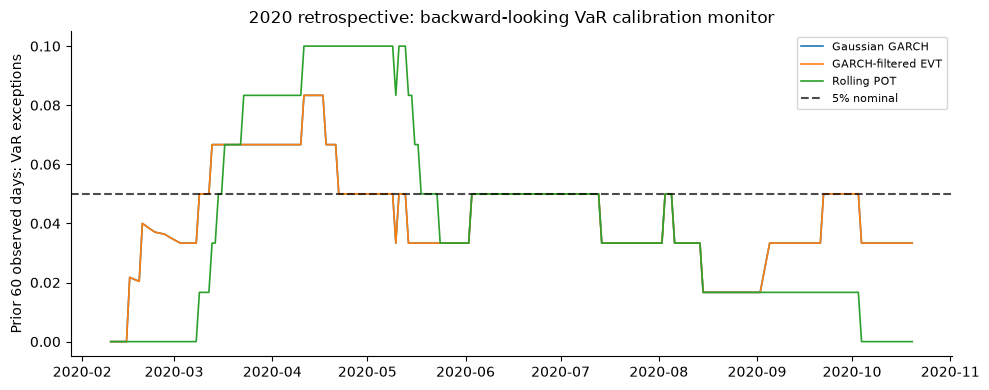

This monitor uses historical exceedances only, and makes no new model-selection claims.


In [124]:
risk_monitor=[]
for (year,model),frame in joint_risk.sort_values('date').groupby(['year','model']):
    frame=frame.sort_values('date').copy()
    events=(frame.loss>frame.VaR).astype(int)
    frame['prior_60_observed_exception_rate']=events.shift(1).rolling(60,min_periods=40).mean()
    frame['exception_today']=events.to_numpy()
    risk_monitor.append(frame[['date','year','model','loss','VaR','ES','exception_today','prior_60_observed_exception_rate']])
risk_monitor=pd.concat(risk_monitor,ignore_index=True)
assert risk_monitor.prior_60_observed_exception_rate.dropna().between(0,1).all() and len(risk_monitor)>100
risk_monitor.to_csv(OUT/'peer_VaR_prior_only_60day_exception_monitor.csv',index=False)
fig,axis=plt.subplots(figsize=(10,4))
for model in ['Gaussian GARCH','GARCH-filtered EVT','Rolling POT']:
    display_part=risk_monitor.loc[risk_monitor.model.eq(model)&risk_monitor.year.eq(2020)].sort_values('date')
    if len(display_part):axis.plot(display_part.date,display_part.prior_60_observed_exception_rate,label=model,lw=1.2)
axis.axhline(.05,color='black',linestyle='--',alpha=.7,label='5% nominal')
axis.set(ylabel='Prior 60 observed days: VaR exceptions',title='2020 retrospective: backward-looking VaR calibration monitor')
axis.legend(fontsize=8);savefig('38_peer_rolling_VaR_exception_monitor.png')
print('This monitor uses historical exceedances only, and makes no new model-selection claims.')


## 126. Integrated integrity tests and handover manifest

Verify the required fresh artifacts, non-overlapping chronological splits, matched daily model-loss matrices, admissible finite VaR–ES pairs, converged CAViaR, sorted quantiles, and source-file SHA-256 fingerprints. Store a run manifest. **Passing assertions means computational consistency, not statistical generalization or an untouched 2020 test.** No 2021+ source observations were supplied.

In [125]:
import hashlib,json,sys,platform
reviewed_assertions=[]
def peer_assert(label,condition):
    value=bool(condition)
    reviewed_assertions.append({'check':label,'passed':value})
    if not value:raise AssertionError('Peer review reproducibility failure: '+label)
peer_assert('original raw CSVs present',all((DATA/f).is_file() for f in ['dataset.csv','SPX_500_Data.csv']))
peer_assert('train validation retrospective dates ordered',train.date.max()<valid.date.min()<test.date.min())
peer_assert('model confidence comparison all same 2019 dates',fixed_losses.index.equals(pd.DatetimeIndex(valid.date.to_numpy())))
peer_assert('model confidence losses finite',np.isfinite(fixed_losses.to_numpy()).all())
peer_assert('paired VAR-ES records valid',bool((joint_risk.ES>joint_risk.VaR).all()))
peer_assert('symmetric CAViaR converged',bool(caviar_chosen.success))
peer_assert('quantile HAR-X noncrossing after mechanical fix',bool((qhar_monotone[.95]>=qhar_monotone[.90]).all()))
peer_assert('original crossing count documented',int(qhar_crossing.raw_quantile_crossings.iloc[0])>=0)
peer_assert('2019 POT raw coverage preserved',len(coverage_review.loc[coverage_review.year.eq(2019)&coverage_review.model.eq('Rolling POT')])==1)
peer_assert('CoVaR 2019-2020 small-sample explicitly flagged',bool((covar_reliability.loc[covar_reliability.era.eq('2019_2020_retrospective'),'small_tail_flag']).any()))
peer_assert('DCC frozen-period cutoff restricted to pre2020',bool((pd.to_datetime(dcc_stability_scoring.fit_end)<=VALID_END).all()))
peer_assert('2020 risk monitoring prior-only shift',bool(risk_monitor.groupby(['year','model']).head(1).prior_60_observed_exception_rate.isna().all()))
peer_assert('no 2021+ source included',crypto.date.max()<=END)
required_peer=['peer_risk_eligibility_and_common_date_audit.csv','peer_VaR_coverage_failure_and_Holm.csv',
 'peer_CoVaR_effective_tail_sample_reliability.csv','peer_CoVaR_full_sample_QuantReg_sensitivity.csv',
 'peer_Quantile_HARX_crossing_audit.csv','peer_CAViaR_symmetric_optimizer_convergence.csv',
 'peer_CAViaR_training_window_stability.csv','peer_DCC_matched_raw_return_stability.csv',
 'peer_fixed_models_2019_multiple_comparison_summary.csv','peer_approximate_block_MCS_elimination_trace.csv',
 'peer_VaR_prior_only_60day_exception_monitor.csv']
peer_assert('all new required analysis outputs exist',all((OUT/f).is_file() for f in required_peer))
peer_check=pd.DataFrame(reviewed_assertions)
peer_check.to_csv(OUT/'peer_FINAL_validation_checks.csv',index=False)
peer_files=[]
for kind,folder in [('figure',FIG),('output',OUT)]:
  for path in sorted(folder.rglob('*')):
    if path.is_file():
      peer_files.append({'type':kind,'relative_path':path.relative_to(PROJECT_DIR).as_posix(),
       'sha256':hashlib.sha256(path.read_bytes()).hexdigest(),'bytes':path.stat().st_size,
       'created_this_run':path.stat().st_mtime_ns>=RUN_STARTED_NS})
peer_manifest=pd.DataFrame(peer_files)
peer_manifest.to_csv(OUT/'peer_FINAL_fresh_artifact_manifest.csv',index=False)
peer_metadata={'notebook':'Bitcoin_Financial_Research_PEER_REVIEWED_FINAL.ipynb','source':'user uploaded audited notebook',
 'source_hashes':{f:hashlib.sha256((DATA/f).read_bytes()).hexdigest() for f in ['dataset.csv','SPX_500_Data.csv']},
 'python_version':sys.version.split()[0],'pandas_version':pd.__version__,
 'all_peer_assertions_pass':bool(peer_check.passed.all()),'figures':int(peer_manifest.type.eq('figure').sum()),
 'output_files_at_manifest_time':int(peer_manifest.type.eq('output').sum()),
 'notice':'2019/2020 data repeatedly used in model development; no unseen 2021+ out-of-sample test.'}
(OUT/'peer_FINAL_metadata.json').write_text(json.dumps(peer_metadata,indent=2),encoding='utf-8')
print('Peer review final tests passed:',len(peer_check),'| Figures:',peer_metadata['figures'])
display(peer_check)


Peer review final tests passed: 14 | Figures: 38


,check,passed
0,original raw CSVs present,True
1,train validation retrospective dates ordered,True
2,model confidence comparison all same 2019 dates,True
3,model confidence losses finite,True
4,paired VAR-ES records valid,True
5,symmetric CAViaR converged,True
6,quantile HAR-X noncrossing after mechanical fix,True
7,original crossing count documented,True
8,2019 POT raw coverage preserved,True
9,CoVaR 2019-2020 small-sample explicitly flagged,True


## 127. Final verification extension — goals, restrictions, and non-independence

This final extension addresses open methodological issues without treating 2020 as an untouched test. All new predictive models here use parameters determined **no later than 2018**; 2019 and 2020 are retrospective evaluation periods. Specifically, we add a *structurally non-crossing* pair of volatility quantiles (not post-hoc sorting), pre-2019 fixed-model **SPA-style simultaneous block-bootstrap inference** (not a certified Hansen SPA implementation), exact interval diagnostics for VaR and exploratory CoVaR, common-outcome DCC diagnostics, and run-scoped artifact integrity tests. Any p-values are exploratory because both years have been repeatedly examined. No 2021+ observations are available.


In [126]:
import inspect, sys, platform, hashlib, json
from scipy.stats import binomtest
from sklearn.linear_model import QuantileRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_pinball_loss

verified_new_output=[]
def verified_output(name, dataframe):
    path=OUT/name
    dataframe.to_csv(path,index=False)
    verified_new_output.append(name)
    return path

# This extension never substitutes a future 2020 refit for the original model development process.
assert train.date.max() <= TRAIN_END
assert valid.date.min() > TRAIN_END
assert test.date.min() > VALID_END
assert DATA.joinpath('dataset.csv').exists() and DATA.joinpath('SPX_500_Data.csv').exists()
print('Verification extension: historical boundaries and original input files checked.')


Verification extension: historical boundaries and original input files checked.


## 128. Structurally non-crossing quantile HAR-X, frozen before 2019

An unconstrained pair of quantile boosting models crossed on five 2020 dates. Here a shared-slope linear 90th-percentile HAR-X model is fitted on **2015–2017 only**. **Separate 90th/95th residual intercept adjustments** are set using only 2018 calibration residuals; their ordered difference enforces structural monotonicity. This design enforces monotonicity for every future feature row, not just in the evaluation sample; it is deliberately parsimonious and its conditional 95th calibration is approximate. No 2019–2020 data is used to fit or recalibrate the model. Evaluate it alongside the original separately fitted boosted quantiles on exactly the same 2020 dates.


In [127]:
_qh_develop=hx_train.loc[hx_train.index.year<=2017].sort_index()
_qh_calibrate=hx_train.loc[hx_train.index.year==2018].sort_index()
assert len(_qh_develop)>300 and len(_qh_calibrate)>150
assert _qh_develop.index.max() < _qh_calibrate.index.min() <= TRAIN_END
_qh_frozen = make_pipeline(StandardScaler(),QuantileRegressor(quantile=.90,alpha=.02,solver='highs'))
_qh_frozen.fit(hx_matrix(_qh_develop,qhar_cols),np.log1p(_qh_develop.observed_parkinson.to_numpy()))
_q90_calib=_qh_frozen.predict(hx_matrix(_qh_calibrate,qhar_cols))
_qh_residual=np.log1p(_qh_calibrate.observed_parkinson.to_numpy())-_q90_calib
_qh_offset90=float(np.quantile(_qh_residual,.90))
_qh_offset95=float(np.quantile(_qh_residual,.95))
_qh_positive_delta=float(_qh_offset95-_qh_offset90)
assert _qh_positive_delta>=0
_qh_comparisons=[]
_qh_daily=[]
for _split,_fr in [('2019_validation',hx_valid),('2020_retrospective',hx_test)]:
    _lower_log=_qh_frozen.predict(hx_matrix(_fr,qhar_cols))
    _upper_log=_lower_log+_qh_offset95
    _lower_log=_lower_log+_qh_offset90
    _pred90=np.maximum(np.expm1(_lower_log),0)
    _pred95=np.maximum(np.expm1(_upper_log),0)
    _truth=_fr.observed_parkinson.to_numpy()
    assert np.all(_pred95>=_pred90-1e-10) and np.isfinite(_pred95).all()
    _qh_daily.append(pd.DataFrame({'date':_fr.index,'period':_split,'actual_variance':_truth,
        'frozen_noncross_q90':_pred90,'frozen_noncross_q95':_pred95,
        'raw_lower_than_upper':_pred90<=_pred95}))
    for _q,_pred in [(.90,_pred90),(.95,_pred95)]:
        _hits=int((_truth>_pred).sum())
        _ci=binomtest(_hits,len(_pred)).proportion_ci(confidence_level=.95,method='exact')
        _qh_comparisons.append({'period':_split,'method':'pre2019_shared_slope_noncross',
          'quantile':_q,'n':len(_pred),'exceedances':_hits,'exceedance_rate':_hits/len(_pred),
          'exact_CI_low':_ci.low,'exact_CI_high':_ci.high,
          'pinball':float(mean_pinball_loss(_truth,_pred,alpha=_q)),
          'learning_cutoff':'2017-12-31','offset_calibration_cutoff':'2018-12-31'})
if len(qhwide):
    _original_qh=qhwide.copy()
    _target=_qhar_df.loc[_qhar_df['quantile'].eq(.90)].set_index('date')['realized_variance'].sort_index()
    for _q in [.90,.95]:
        _p=_original_qh[_q].to_numpy()
        _t=_target.to_numpy()
        _qh_comparisons.append({'period':'2020_retrospective','method':'2019_tuned_quantile_boost_original',
          'quantile':_q,'n':len(_p),'exceedances':int((_t>_p).sum()),
          'exceedance_rate':float((_t>_p).mean()),'pinball':float(mean_pinball_loss(_t,_p,alpha=_q)),
          'learning_cutoff':'2019-12-31','offset_calibration_cutoff':'n/a'})
_qh_new_daily=pd.concat(_qh_daily,ignore_index=True)
_qh_new_summary=pd.DataFrame(_qh_comparisons)
assert _qh_new_daily.raw_lower_than_upper.all()
verified_output('verified_non_crossing_HARX_daily.csv',_qh_new_daily)
verified_output('verified_non_crossing_HARX_metrics.csv',_qh_new_summary)
display(_qh_new_summary.round(5))
print('Guaranteed non-crossing; calibrated pre-2019 log-variance gap:',round(_qh_positive_delta,5))


,period,method,quantile,n,exceedances,exceedance_rate,exact_CI_low,exact_CI_high,pinball,learning_cutoff,offset_calibration_cutoff
0,2019_validation,pre2019_shared_slope_noncross,0.90,363,22,0.06061,0.03837,0.09032,3.80178,2017-12-31,2018-12-31
1,2019_validation,pre2019_shared_slope_noncross,0.95,363,12,0.03306,0.01720,0.05703,2.88740,2017-12-31,2018-12-31
2,2020_retrospective,pre2019_shared_slope_noncross,0.90,284,6,0.02113,0.00779,0.04541,5.95985,2017-12-31,2018-12-31
3,2020_retrospective,pre2019_shared_slope_noncross,0.95,284,4,0.01408,0.00385,0.03567,5.38306,2017-12-31,2018-12-31
4,2020_retrospective,2019_tuned_quantile_boost_original,0.90,284,18,0.06338,NaN,NaN,6.02122,2019-12-31,n/a
5,2020_retrospective,2019_tuned_quantile_boost_original,0.95,284,10,0.03521,NaN,NaN,5.47211,2019-12-31,n/a


Guaranteed non-crossing; calibrated pre-2019 log-variance gap: 0.4061


## 129. Simultaneous SPA-style max-t test on frozen model candidates

The earlier stepwise approximation remains documented rather than mislabeled as the certified Hansen–Lunde–Nason Model Confidence Set. This **complementary conservative SPA-style / family-wise max-t moving-block null bootstrap** compares four pre-2019-fixed candidates against the no-change baseline on identical 2019 dates. Each bootstrap jointly resamples the centered vector of paired daily loss differences to preserve cross-model dependence. Report **5/10/20-session block sensitivity**, an explicitly approximate p-value, and baseline vs. candidate point estimates. This does **not** make 2019 an independent held-out sample.


In [128]:
_base_label='Naive zero return'
assert _base_label in fixed_losses.columns and fixed_losses.index.year.max()==2019
_comp=[x for x in fixed_losses.columns if x!=_base_label]
_spa_d=fixed_losses[_base_label].to_numpy()[:,None]-fixed_losses[_comp].to_numpy()
assert _spa_d.shape==(len(fixed_losses),len(_comp)) and np.isfinite(_spa_d).all()
_spa_rows=[]
_spa_boot_n=1200
for _bl in [5,10,20]:
    _rng=np.random.default_rng(SEED+400+_bl)
    _centered=_spa_d-_spa_d.mean(axis=0)
    _boot_means=np.empty((_spa_boot_n,len(_comp)))
    for _bi in range(_spa_boot_n):
        _idx=circular_block_sample(len(_spa_d),_bl,_rng)
        _boot_means[_bi]=_centered[_idx].mean(axis=0)
    _se=np.maximum(_boot_means.std(axis=0,ddof=1),1e-10)
    _test_statistics=_spa_d.mean(axis=0)/_se
    _observed_max=float(max(0.,_test_statistics.max()))
    _boot_max=np.maximum(0.,(_boot_means/_se).max(axis=1))
    _p_value=(1+np.sum(_boot_max>=_observed_max))/(_spa_boot_n+1)
    for _j,_name in enumerate(_comp):
        _spa_rows.append({'block_length':_bl,'model':_name,'n_2019':len(_spa_d),
          'naive_minus_model_mean_squared_loss':float(_spa_d[:,_j].mean()),
          'studentized_model_stat':float(_test_statistics[_j]),
          'family_max_t':_observed_max,'SPA_style_family_p_value':float(_p_value),
          'n_boot':_spa_boot_n,'calibration_period':'2019 historical repeatedly examined',
          'interpretation':'exploratory centered moving-block max-t; NOT official Hansen SPA'})
_spa_summary=pd.DataFrame(_spa_rows)
verified_output('verified_frozen_models_SPA_style_block_sensitivity.csv',_spa_summary)
print('Simultaneous null-bootstrap p-values (block length 5,10,20):')
display(_spa_summary.drop_duplicates('block_length')[['block_length','family_max_t','SPA_style_family_p_value']].round(4))


Simultaneous null-bootstrap p-values (block length 5,10,20):


,block_length,family_max_t,SPA_style_family_p_value
0,5,0.0,1.0
4,10,0.0,1.0
8,20,0.0,1.0


## 130. VaR / ES exact interval, forecast eligibility and tail-severity audits

A p-value that does not reject 5% VaR coverage does not demonstrate correct risk estimation. Preserve the raw 2019 Rolling POT failure alongside exploratory multiplicity adjustments. Provide exact binomial confidence limits for every matched VaR series. VaR exceedance residuals against ES are a **descriptive diagnostic**, not a formal ES-only calibration test; mark years with fewer than 20 exceedances as inconclusive. Never silently discard invalid (VaR, ES) pairs.


In [129]:
_risk_exact=[]
for (_year,_model),_grp in joint_risk.groupby(['year','model']):
    _grp=_grp.sort_values('date')
    _evt=_grp.loss.to_numpy()>_grp.VaR.to_numpy()
    _k=int(_evt.sum());_n=len(_grp)
    _interval=binomtest(_k,_n).proportion_ci(confidence_level=.95,method='exact')
    _severity=(_grp.loc[_evt,'loss']-_grp.loc[_evt,'ES']).to_numpy()
    _risk_exact.append({'year':int(_year),'model':_model,'n':_n,'exceptions':_k,
      'exception_rate':_k/_n,'exact_coverage_rate_CI_low':float(_interval.low),
      'exact_coverage_rate_CI_high':float(_interval.high),
      'nominal_exception_rate':.05,'nominal_inside_CI':_interval.low<=.05<=_interval.high,
      'ES_exceedance_n':len(_severity),'mean_realized_minus_ES':float(np.mean(_severity)) if len(_severity) else np.nan,
      'ES_evidence_label':'insufficient exceedances; descriptive only' if len(_severity)<20 else 'descriptive only; needs calibrated joint scoring',
      'valid_pairs_excluded_before_scoring':int(risk_eligibility.loc[(risk_eligibility.year==_year)&(risk_eligibility.model==_model),'invalid_pairs'].sum())})
_risk_exact_df=pd.DataFrame(_risk_exact)
assert _risk_exact_df.nominal_inside_CI.notna().all()
assert _risk_exact_df.valid_pairs_excluded_before_scoring.notna().all()
_pot2019=coverage_review[(coverage_review.year==2019)&(coverage_review.model=='Rolling POT')]
assert len(_pot2019)==1 and float(_pot2019.p_uc.iloc[0])<.05
verified_output('verified_VaR_ES_exact_coverage_and_severity.csv',_risk_exact_df)
display(_risk_exact_df.round(5))


,year,model,n,exceptions,exception_rate,exact_coverage_rate_CI_low,exact_coverage_rate_CI_high,nominal_exception_rate,nominal_inside_CI,ES_exceedance_n,mean_realized_minus_ES,ES_evidence_label,valid_pairs_excluded_before_scoring
0,2019,GARCH-filtered EVT,363,15,0.04132,0.02331,0.06724,0.05,True,15,-0.62604,insufficient exceedances; descriptive only,0
1,2019,Gaussian GARCH,363,15,0.04132,0.02331,0.06724,0.05,True,15,1.09452,insufficient exceedances; descriptive only,0
2,2019,Rolling POT,363,9,0.02479,0.01140,0.04654,0.05,False,9,0.39386,insufficient exceedances; descriptive only,0
3,2020,GARCH-filtered EVT,284,11,0.03873,0.01949,0.06824,0.05,True,11,2.19003,insufficient exceedances; descriptive only,0
4,2020,Gaussian GARCH,284,11,0.03873,0.01949,0.06824,0.05,True,11,3.48424,insufficient exceedances; descriptive only,0
5,2020,Rolling POT,284,10,0.03521,0.01701,0.06380,0.05,True,10,1.85230,insufficient exceedances; descriptive only,0


## 131. CoVaR effective sample, leave-one-event-out fragility and QuantReg coverage

An empirical BTC 5th percentile conditioned on ~12–21 altcoin crisis observations uses nearly a single worst BTC event. Demonstrate the dependence on **one observation** instead of interpreting short bootstrap intervals as precision. Tail thresholds are frozen on training data and the 2019/2020 diagnostic remains explicitly retrospective. Separate the original empirical stress-quantile association from quantile-regression predictions and report exact 95% intervals of calibration exceptions.


In [130]:
_covar_influence=[]
for _alt in ['ETH','LTC','XRP']:
    _p=co_pair[['BTC',_alt]].dropna().sort_index()
    _train=_p.loc[:TRAIN_END]
    _retro=_p.loc['2019':'2020']
    for _stress_q in [.05,.10,.15]:
        _frozen_cut=float(_train[_alt].quantile(_stress_q))
        _btc_stress=_retro.loc[_retro[_alt]<=_frozen_cut,'BTC'].dropna().to_numpy(dtype=float)
        if len(_btc_stress)<3:continue
        _q05=float(np.quantile(_btc_stress,.05))
        _loo=np.array([np.quantile(np.delete(_btc_stress,j),.05) for j in range(len(_btc_stress))])
        _covar_influence.append({'altcoin':_alt,'stress_q':_stress_q,'n_altcoin_stress':len(_btc_stress),
          'expected_BTC_5pct_tail_obs':len(_btc_stress)*.05,
          'empirical_BTC_conditional_q05':_q05,
          'loo_min_BTC_q05':float(np.min(_loo)),'loo_max_BTC_q05':float(np.max(_loo)),
          'max_absolute_one_event_influence':float(np.max(np.abs(_loo-_q05))),
          'enough_expected_tail_events':len(_btc_stress)*.05>=5,
          'note':'association only; fragile at low expected tail-event count'})
_covar_influence=pd.DataFrame(_covar_influence)
_quant_calib=[]
_qcovar=pd.concat(quant_covar_daily,ignore_index=True)
for (_alt,_year),_g in _qcovar.groupby(['altcoin',_qcovar.date.dt.year]):
    _n=len(_g);_k=int(_g.BTC_below_model_q05.sum());_ci=binomtest(_k,_n).proportion_ci(method='exact')
    _quant_calib.append({'altcoin':_alt,'year':int(_year),'n':_n,'BTC_below_predicted_q05':_k,
        'empirical_rate':_k/_n,'binom_95CI_low':_ci.low,'binom_95CI_high':_ci.high,
        'nominal_rate':.05,'warning':'conditional coverage varies with altcoin return and is not proved by unconditional coverage'})
verified_output('verified_CoVaR_one_event_leaveout_fragility.csv',_covar_influence)
verified_output('verified_CoVaR_QuantReg_exact_coverage.csv',pd.DataFrame(_quant_calib))
display(_covar_influence.round(5),pd.DataFrame(_quant_calib).round(5))


,altcoin,stress_q,n_altcoin_stress,expected_BTC_5pct_tail_obs,empirical_BTC_conditional_q05,loo_min_BTC_q05,loo_max_BTC_q05,max_absolute_one_event_influence,enough_expected_tail_events,note
0,ETH,0.05,13,0.65,-0.27698,-0.29263,-0.14498,0.13201,False,association only; fragile at low expected tail...
1,ETH,0.10,39,1.95,-0.14062,-0.14124,-0.12375,0.01687,False,association only; fragile at low expected tail...
2,ETH,0.15,56,2.80,-0.12559,-0.12651,-0.10985,0.01574,False,association only; fragile at low expected tail...
3,LTC,0.05,21,1.05,-0.15182,-0.16747,-0.14000,0.01565,False,association only; fragile at low expected tail...
4,LTC,0.10,47,2.35,-0.13386,-0.13478,-0.11701,0.01685,False,association only; fragile at low expected tail...
5,LTC,0.15,72,3.60,-0.11224,-0.11303,-0.10273,0.00951,False,association only; fragile at low expected tail...
6,XRP,0.05,12,0.60,-0.29263,-0.30827,-0.13641,0.15622,False,association only; fragile at low expected tail...
7,XRP,0.10,34,1.70,-0.14373,-0.14435,-0.12835,0.01538,False,association only; fragile at low expected tail...
8,XRP,0.15,54,2.70,-0.12743,-0.12835,-0.11144,0.01598,False,association only; fragile at low expected tail...


,altcoin,year,n,BTC_below_predicted_q05,empirical_rate,binom_95CI_low,binom_95CI_high,nominal_rate,warning
0,ETH,2019,363,4,0.01102,0.00301,0.02797,0.05,conditional coverage varies with altcoin retur...
1,ETH,2020,284,2,0.00704,0.00085,0.02521,0.05,conditional coverage varies with altcoin retur...
2,LTC,2019,363,6,0.01653,0.00609,0.03563,0.05,conditional coverage varies with altcoin retur...
3,LTC,2020,284,1,0.00352,0.00009,0.01946,0.05,conditional coverage varies with altcoin retur...
4,XRP,2019,363,7,0.01928,0.00779,0.03933,0.05,conditional coverage varies with altcoin retur...
5,XRP,2020,284,3,0.01056,0.00218,0.03056,0.05,conditional coverage varies with altcoin retur...


## 132. DCC correlation admissibility and matched raw-return benchmark

Use **the same raw observed BTC–ETH returns** for each 2019 refit scenario and, within a scenario, score DCC versus the scenario's rolling-correlation comparator using the same univariate conditional means/variances. The observed-event-gap approximation remains explicit: this is not a genuine irregular-timestamp GARCH process. Check that every predictive 2×2 correlation matrix is positive definite.


In [131]:
_dcc_comparison=[]
for _scenario,_grp in matched_dcc_raw.loc[matched_dcc_raw.date.dt.year.eq(2020)].groupby('scenario'):
    _grp=_grp.sort_values('date')
    _d=(_grp.rolling_raw_bivariate_NLL-_grp.DCC_raw_bivariate_NLL).to_numpy()
    _rng=np.random.default_rng(SEED+2031)
    _boot=np.array([_d[circular_block_sample(len(_d),10,_rng)].mean() for _ in range(1200)])
    _dcc_comparison.append({'scenario':_scenario,'n':len(_d),'rolling_minus_DCC_NLL_mean':float(_d.mean()),
       '95block_CI_low':float(np.quantile(_boot,.025)),'95block_CI_high':float(np.quantile(_boot,.975)),
       'CI_includes_zero':bool(np.quantile(_boot,.025)<=0<=np.quantile(_boot,.975))})
_dcc_comp=pd.DataFrame(_dcc_comparison)
assert len(_dcc_comp)==2 and (_dcc_comp.n==_dcc_comp.n.iloc[0]).all()
_dcc_2020 = refit_dcc_daily.loc[refit_dcc_daily.date.dt.year.eq(2020)]
assert len(_dcc_2020)>250, 'DCC evaluation sample missing'
assert np.isfinite(_dcc_2020[['DCC_prior','rolling_prior']].to_numpy()).all(), 'Missing 2020 predictive correlations'
assert ((_dcc_2020.DCC_prior.abs()<1)&(_dcc_2020.rolling_prior.abs()<1)).all(), 'Invalid 2020 two-asset predictive correlations'
print('Training-period missing rolling priors (insufficient warm-up) are excluded from 2020 evaluation:',int(refit_dcc_daily.rolling_prior.isna().sum()))
assert (matched_dcc_raw[['var_BTC','var_ETH']]>0).all().all()
verified_output('verified_DCC_matched_raw_returns_vs_rolling.csv',_dcc_comp)
display(_dcc_comp.round(5))


Training-period missing rolling priors (insufficient warm-up) are excluded from 2020 evaluation: 180


,scenario,n,rolling_minus_DCC_NLL_mean,95block_CI_low,95block_CI_high,CI_includes_zero
0,2019_full,284,0.08934,-0.10318,0.30532,True
1,2019_without_gap_neighborhood,284,0.08903,-0.10346,0.30487,True


## 133. Reproducibility gate, frozen-protocol handover and reporting hierarchy

**Freeze before any 2021+ work**: identify the exact predictand (next S&P session versus next 24-hour calendar day), data availability cutoff, model candidate specifications, estimation window, scoring and multiplicity correction. No new post-2020 observations are supplied, so **no future generalization result is claimed**. These files are a historical retrospective investigation with nested checks, not repeated independent external validations. Keep the original 254-cell file in `archive/` for traceability.


In [132]:
import sys,platform,hashlib
_validation=[
 ('original input source files',all((DATA/f).is_file() for f in ['dataset.csv','SPX_500_Data.csv'])),
 ('chronological training and validation',train.date.max()<valid.date.min()<test.date.min()),
 ('noncrossing HAR-X on every evaluated date',_qh_new_daily.raw_lower_than_upper.all()),
 ('noncrossing quantile calibration strictly before 2019',_qh_develop.index.max()<_qh_calibrate.index.min()<=TRAIN_END),
 ('frozen model loss matrix aligns 2019',fixed_losses.index.equals(pd.DatetimeIndex(valid.date.to_numpy()))),
 ('max-t simultaneous test finite',np.isfinite(_spa_summary.SPA_style_family_p_value).all()),
 ('VaR and ES pair validity',bool((joint_risk.ES>joint_risk.VaR).all())),
 ('2019 Rolling POT failure preserved',float(_pot2019.p_uc.iloc[0])<.05),
 ('CoVaR single-event fragility quantified',len(_covar_influence)>0),
 ('DCC common-outcome NLL finite',np.isfinite(matched_dcc_raw.DCC_raw_bivariate_NLL).all()),
 ('2020 DCC forecast correlations within (-1,1)',(_dcc_2020.DCC_prior.abs()<1).all()),
 ('no post-2020 data fabricated',crypto.date.max()<=END),
 ('all new extension CSV files created',all((OUT/f).exists() for f in verified_new_output))]
_verified_checks=pd.DataFrame(_validation,columns=['check','passed'])
assert _verified_checks.passed.all(),_verified_checks.loc[~_verified_checks.passed]
verified_output('verified_FINAL_reproducibility_checks.csv',_verified_checks)
_protocol={'frozen_spec_date':'2026-10-20','data_end':'2020-10-20',
  'future_external_period':'2021 onward: NOT supplied or evaluated',
  'design':'Define prediction origin in UTC and respect US-equity close boundary. Preserve missing dates.',
  'precommitment':['Define fixed 24-hour and next-equity-session as separate tasks',
   'Lock input availability and feature transformations at forecast origin',
   'Choose models using ≤2018 training and 2019 development only; do not pick model on 2020 retrospective results',
   'Lock candidate models/parameters, evaluation dates, missing-data exclusions, baseline and loss metrics',
   'Execute exactly once on genuinely new 2021+ source data after spec freeze',
   'Report jointly adjusted uncertainty; do not claim significance solely from 2019/2020 performance'],
  'model_selection_test':'SPA-style conservative centered max-t sensitivity, not certified Hansen SPA/MCS',
  'artifact_note':'CSV presence, date alignment and hashes are reproducibility evidence, not proof of external validity'}
(OUT/'verified_2021_external_test_FREEZE_PROTOCOL.json').write_text(json.dumps(_protocol,ensure_ascii=False,indent=2),encoding='utf-8')
_verified_sources={f:hashlib.sha256((DATA/f).read_bytes()).hexdigest() for f in ['dataset.csv','SPX_500_Data.csv']}
_verified_file_rows=[]
for _category,_root in [('figure',FIG),('output',OUT)]:
 for _path in sorted(_root.rglob('*')):
  if _path.is_file():
   _verified_file_rows.append({'category':_category,'relative_path':_path.relative_to(PROJECT_DIR).as_posix(),
    'bytes':_path.stat().st_size,'sha256':hashlib.sha256(_path.read_bytes()).hexdigest(),
    'written_since_run_start':_path.stat().st_mtime_ns>=RUN_STARTED_NS})
_vmanifest=pd.DataFrame(_verified_file_rows)
verified_output('verified_run_scoped_artifact_manifest.csv',_vmanifest)
_vmeta={'notebook':'Bitcoin_Financial_Research_VERIFIED_FINAL_2026.ipynb',
 'python':sys.version.split()[0],'pandas':pd.__version__,'source_sha256':_verified_sources,
 'new_verified_CSVs':verified_new_output,'integrity_checks':len(_validation),
 'check_pass':bool(_verified_checks.passed.all()),'figures':int(_vmanifest.category.eq('figure').sum()),
 'outputs_indexed_before_self_manifest':int(_vmanifest.category.eq('output').sum()),
 'scientific_limit':'Historical 2019/2020 have repeatedly influenced research. 2021+ is required for independent final evaluation.'}
(OUT/'verified_release_environment_and_results.json').write_text(json.dumps(_vmeta,ensure_ascii=False,indent=2),encoding='utf-8')
print('Final verified extension checks:',len(_validation),'passed; figures:',_vmeta['figures'])
display(_verified_checks)


Final verified extension checks: 13 passed; figures: 38


,check,passed
0,original input source files,True
1,chronological training and validation,True
2,noncrossing HAR-X on every evaluated date,True
3,noncrossing quantile calibration strictly befo...,True
4,frozen model loss matrix aligns 2019,True
5,max-t simultaneous test finite,True
6,VaR and ES pair validity,True
7,2019 Rolling POT failure preserved,True
8,CoVaR single-event fragility quantified,True
9,DCC common-outcome NLL finite,True


## 134. Past-only online recalibration of structurally noncrossing HAR-X

**New sensitivity model, not prospective evidence.** Hold the shared-slope quantile regression fixed at 2017. Begin 2019 with 2018 *observed* log-variance residuals. For each later date, compute the 90th and 95th residual quantiles from **strictly earlier** observations in the same moving window, then update history **only after** the current date is scored. Separate windows of 90/180/365 observations are prespecified sensitivity checks; the 180-day version is the reference choice, *not selected on 2020 performance*. Because both quantiles use the same underlying regression slope and an ordered residual quantile, crossing is structurally impossible. Report calibration, pinball loss and paired block uncertainty on matched dates; 2019/2020 have already been repeatedly examined.

Online fixed-slope noncrossing HAR-X; matched paired score comparisons:


,window,period,quantile,n,exceptions,exception_rate,target_exception_rate,exact_95CI_low,exact_95CI_high,pinball,mean_threshold,all_prior_only
0,90,2019_development,0.90,363,37,0.10193,0.10,0.07279,0.13775,3.73726,22.56806,True
1,90,2019_development,0.95,363,20,0.05510,0.05,0.03398,0.08381,2.88195,35.60985,True
2,90,2020_retrospective,0.90,284,25,0.08803,0.10,0.05778,0.12720,4.97039,18.13291,True
3,90,2020_retrospective,0.95,284,10,0.03521,0.05,0.01701,0.06380,4.38303,27.24709,True
4,180,2019_development,0.90,363,33,0.09091,0.10,0.06340,0.12530,3.69999,23.21259,True
5,180,2019_development,0.95,363,16,0.04408,0.05,0.02540,0.07059,2.78354,38.64684,True
6,180,2020_retrospective,0.90,284,23,0.08099,0.10,0.05203,0.11904,4.92710,20.96024,True
7,180,2020_retrospective,0.95,284,9,0.03169,0.05,0.01459,0.05930,4.40667,29.92661,True
8,365,2019_development,0.90,363,31,0.08540,0.10,0.05876,0.11903,3.66355,24.07811,True
9,365,2019_development,0.95,363,16,0.04408,0.05,0.02540,0.07059,2.77997,37.88403,True


,year,quantile,n,positive_means_online_improved_pinball,95block_CI_low,95block_CI_high,CI_includes_zero,retrospective_not_independent
0,2019,0.90,363,0.10178,-0.20703,0.36965,True,True
1,2019,0.95,363,0.10387,-0.23267,0.34320,True,True
2,2020,0.90,284,1.03276,0.72072,1.42794,False,True
3,2020,0.95,284,0.97639,0.61838,1.40441,False,True


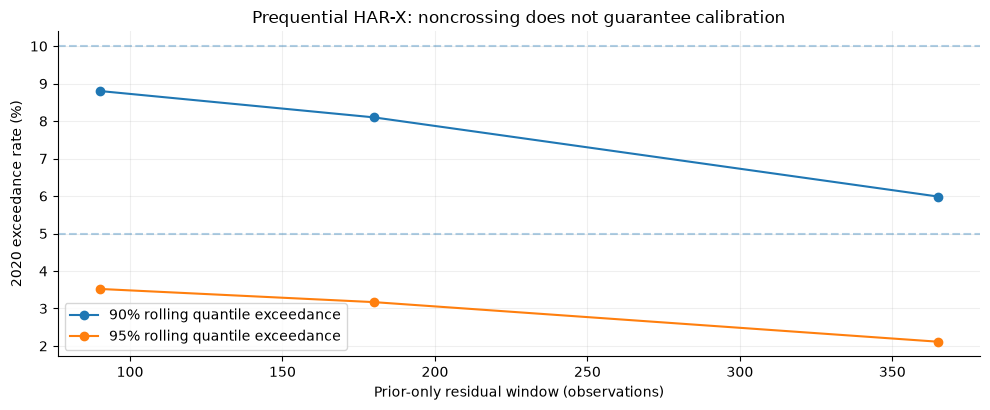

In [133]:
from scipy.stats import binomtest
from sklearn.metrics import mean_pinball_loss
_online_rows=[]
_online_summary=[]
_online_history_2018=list(zip(_qh_calibrate.index,
    (np.log1p(_qh_calibrate.observed_parkinson.to_numpy())-_qh_frozen.predict(hx_matrix(_qh_calibrate,qhar_cols))).tolist()))
_full_online=pd.concat([hx_valid.assign(research_period='2019_development'),
                        hx_test.assign(research_period='2020_retrospective')]).sort_index()
assert _full_online.index.is_unique
for _window in [90,180,365]:
    _history=list(_online_history_2018)
    for _date,_row in _full_online.iterrows():
        _past=_history[-_window:]
        assert len(_past)>=40 and max(dt for dt,resid in _past)<_date
        _base=float(_qh_frozen.predict(hx_matrix(_full_online.loc[[_date]],qhar_cols))[0])
        _past_resids=np.asarray([resid for dt,resid in _past],dtype=float)
        _q90,_q95=np.quantile(_past_resids,[.90,.95])
        _v90=float(max(0.,np.expm1(np.clip(_base+_q90,-20,20))))
        _v95=float(max(0.,np.expm1(np.clip(_base+_q95,-20,20))))
        _actual=float(_row.observed_parkinson)
        assert _v95+1e-8>=_v90
        _online_rows.append({'date':_date,'window':_window,'period':_row.research_period,
           'history_max_date':_past[-1][0],'n_used':len(_past),'realized_variance':_actual,
           'pred_q90':_v90,'pred_q95':_v95,'q90_exception':int(_actual>_v90),
           'q95_exception':int(_actual>_v95)})
        _history.append((_date,float(np.log1p(_actual)-_base)))
_online_daily=pd.DataFrame(_online_rows).sort_values(['window','date']).reset_index(drop=True)
assert (_online_daily.history_max_date<_online_daily.date).all()
assert (_online_daily.pred_q90<=_online_daily.pred_q95+1e-10).all()
for (_window,_period),_grp in _online_daily.groupby(['window','period']):
    for _q,_col in [(.90,'pred_q90'),(.95,'pred_q95')]:
        _hits=int((_grp.realized_variance>_grp[_col]).sum());_n=len(_grp)
        _ci=binomtest(_hits,_n).proportion_ci(confidence_level=.95,method='exact')
        _online_summary.append({'window':_window,'period':_period,'quantile':_q,'n':_n,'exceptions':_hits,
            'exception_rate':_hits/_n,'target_exception_rate':1-_q,
            'exact_95CI_low':float(_ci.low),'exact_95CI_high':float(_ci.high),
            'pinball':float(mean_pinball_loss(_grp.realized_variance,_grp[_col],alpha=_q)),
            'mean_threshold':float(_grp[_col].mean()),'all_prior_only':bool((_grp.history_max_date<_grp.date).all())})
_online_summary=pd.DataFrame(_online_summary)
# Compare the 180-observation online protocol against a strictly pre-2019-frozen baseline.
_online_compare=[]
for _year in [2019,2020]:
    _d=_online_daily.loc[_online_daily.window.eq(180)&_online_daily.date.dt.year.eq(_year)].set_index('date').sort_index()
    _f=_qh_new_daily.loc[_qh_new_daily.date.dt.year.eq(_year)].set_index('date').sort_index()
    assert _d.index.equals(_f.index) and np.allclose(_d.realized_variance,_f.actual_variance)
    for _q,_p1,_p0 in [(.90,'pred_q90','frozen_noncross_q90'),(.95,'pred_q95','frozen_noncross_q95')]:
        _y=_d.realized_variance.to_numpy()
        def _pin(y,p,q):return (q-(y<p).astype(float))*(y-p)
        _delta=_pin(_y,_f[_p0].to_numpy(),_q)-_pin(_y,_d[_p1].to_numpy(),_q)
        _bootrng=np.random.default_rng(SEED+int(_q*100)+_year)
        _bmeans=np.array([_delta[circular_block_sample(len(_delta),10,_bootrng)].mean() for _ in range(1200)])
        _online_compare.append({'year':_year,'quantile':_q,'n':len(_delta),'positive_means_online_improved_pinball':float(_delta.mean()),
           '95block_CI_low':float(np.quantile(_bmeans,.025)),'95block_CI_high':float(np.quantile(_bmeans,.975)),
           'CI_includes_zero':bool(np.quantile(_bmeans,.025)<=0<=np.quantile(_bmeans,.975)),
           'retrospective_not_independent':True})
_online_paired=pd.DataFrame(_online_compare)
_online_daily.to_csv(OUT/'consolidated_online_noncross_HARX_daily.csv',index=False)
_online_summary.to_csv(OUT/'consolidated_online_noncross_HARX_calibration.csv',index=False)
_online_paired.to_csv(OUT/'consolidated_online_HARX_paired_pinball_CI.csv',index=False)
print('Online fixed-slope noncrossing HAR-X; matched paired score comparisons:')
display(_online_summary.round(5),_online_paired.round(5))
_fig_online=_online_summary.loc[_online_summary.period.eq('2020_retrospective')]
fig,ax=plt.subplots(figsize=(10,4.2))
for _q,_color in [(.90,'tab:blue'),(.95,'tab:orange')]:
    _v=_fig_online.loc[_fig_online['quantile'].eq(_q)].sort_values('window')
    ax.plot(_v.window,_v.exception_rate*100,marker='o',label=f'{_q:.0%} rolling quantile exceedance')
    ax.axhline((1-_q)*100,ls='--',alpha=.35)
ax.set(xlabel='Prior-only residual window (observations)',ylabel='2020 exceedance rate (%)',
       title='Prequential HAR-X: noncrossing does not guarantee calibration')
ax.legend();ax.grid(alpha=.2);savefig('39_online_noncross_HARX_calibration.png')

## 135. CoVaR rare-event identification limits and threshold fragility

A wider stress threshold increases event count, but ceases to mean the *extreme* 5% stress state. Show both quantities together. The exact 5% BTC conditional quantile often relies on effectively fewer than five observations. The 2015–18 altcoin thresholds are frozen before the retrospective 2019–20 sample; no later-date features are admitted into a *forecast* because this is explicitly **contemporaneous descriptive association**. This section deliberately avoids claiming causality, conditional forecast calibration or precise tail-risk spillover coefficients.

CoVaR rare-event warning: the 5% stress/5% BTC tail cannot be reliably estimated from 12–21 observations.


,altcoin,frozen_altcoin_stress_quantile,n_outcome_dates,n_stress_dates,expected_BTC_conditional_5pct_order_statistics,empirical_BTC_q05,max_one_event_LOO_change,at_least_5_expected_extreme_tail_observations,not_extreme_5pct_stress_anymore,interpretation
0,ETH,0.05,647,13,0.65,-0.2770,0.1320,False,False,contemporaneous association; no causal or pros...
1,ETH,0.10,647,39,1.95,-0.1406,0.0169,False,True,contemporaneous association; no causal or pros...
2,ETH,0.15,647,56,2.80,-0.1256,0.0157,False,True,contemporaneous association; no causal or pros...
3,ETH,0.20,647,76,3.80,-0.1091,0.0073,False,True,contemporaneous association; no causal or pros...
4,ETH,0.25,647,107,5.35,-0.0986,0.0047,True,True,contemporaneous association; no causal or pros...
5,ETH,0.30,647,154,7.70,-0.0917,0.0051,True,True,contemporaneous association; no causal or pros...
6,LTC,0.05,647,21,1.05,-0.1518,0.0156,False,False,contemporaneous association; no causal or pros...
7,LTC,0.10,647,47,2.35,-0.1339,0.0168,False,True,contemporaneous association; no causal or pros...
8,LTC,0.15,647,72,3.60,-0.1122,0.0095,False,True,contemporaneous association; no causal or pros...
9,LTC,0.20,647,139,6.95,-0.0926,0.0011,True,True,contemporaneous association; no causal or pros...


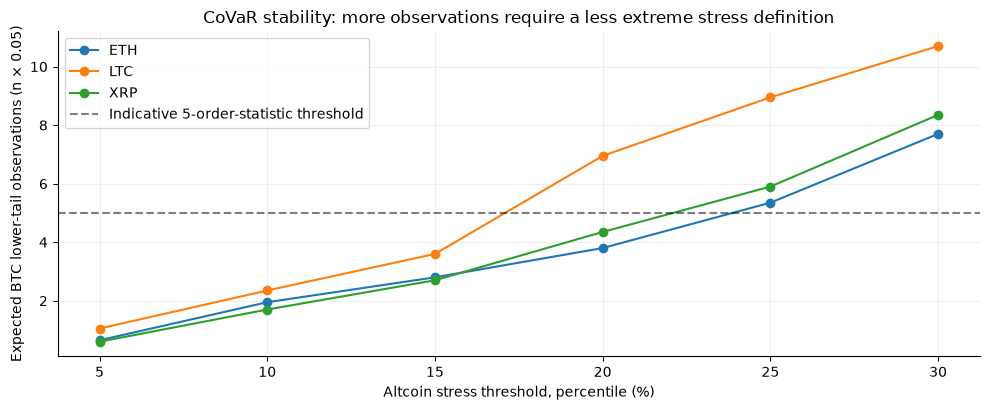

In [134]:
_reliability_rows=[]
for _alt in ['ETH','LTC','XRP']:
    _pair=co_pair[['BTC',_alt]].dropna().sort_index()
    _hist=_pair.loc[:TRAIN_END]
    _future=_pair.loc['2019':END]
    for _stress in [.05,.10,.15,.20,.25,.30]:
        _threshold=float(_hist[_alt].quantile(_stress))
        _cond=_future.loc[_future[_alt]<=_threshold,'BTC'].to_numpy()
        _cnt=len(_cond)
        if _cnt<3:continue
        _q05=float(np.quantile(_cond,.05))
        _loo=np.asarray([np.quantile(np.delete(_cond,j),.05) for j in range(_cnt)])
        _reliability_rows.append({'altcoin':_alt,'frozen_altcoin_stress_quantile':_stress,'n_outcome_dates':len(_future),
          'n_stress_dates':_cnt,'expected_BTC_conditional_5pct_order_statistics':.05*_cnt,
          'empirical_BTC_q05':_q05,'max_one_event_LOO_change':float(np.max(np.abs(_loo-_q05))),
          'at_least_5_expected_extreme_tail_observations':bool(.05*_cnt>=5),
          'not_extreme_5pct_stress_anymore':bool(_stress>.05),
          'interpretation':'contemporaneous association; no causal or prospective forecast interpretation'})
_reliability=pd.DataFrame(_reliability_rows)
assert (_reliability.loc[_reliability.frozen_altcoin_stress_quantile.eq(.05),'expected_BTC_conditional_5pct_order_statistics']<5).all()
_reliability.to_csv(OUT/'consolidated_CoVaR_stress_tail_reliability.csv',index=False)
print('CoVaR rare-event warning: the 5% stress/5% BTC tail cannot be reliably estimated from 12–21 observations.')
display(_reliability.round(4))
fig,ax=plt.subplots(figsize=(10,4.2))
for _alt,_grp in _reliability.groupby('altcoin'):
    ax.plot(_grp.frozen_altcoin_stress_quantile*100,_grp.expected_BTC_conditional_5pct_order_statistics,
            marker='o',label=_alt)
ax.axhline(5,color='black',linestyle='--',alpha=.5,label='Indicative 5-order-statistic threshold')
ax.set(xlabel='Altcoin stress threshold, percentile (%)',ylabel='Expected BTC lower-tail observations (n × 0.05)',
       title='CoVaR stability: more observations require a less extreme stress definition')
ax.legend();ax.grid(alpha=.2);savefig('40_CoVaR_effective_tail_sample.png')

## 136. Time-local VaR calibration and ES failure severity (descriptive)

For each VaR model, compute the exception rate over the **prior 60 observed evaluation dates**, never including the scored date. Full-period Kupiec/conditional tests and exploratory Holm adjustments remain in Sections 114/119. Report 2019/2020 and the March 2020 crisis separately, with exact interval uncertainty. ES model residuals use only a handful of exceedances and therefore stay **descriptive**, not an ES calibration proof. Retain unmatched, invalid VaR/ES pairs in the eligibility audit; no silent dropping.

,model,period,n,VaR_exceedances,exceedance_rate,exact_95CI_low,exact_95CI_high,mean_realized_minus_predicted_ES_given_VaR_exception,ES_n,ES_inference_status,2019_2020_are_repeatedly_inspected
0,GARCH-filtered EVT,2019_all,363,15,0.04132,0.02331,0.06724,-0.62604,15,INSUFFICIENT exceedances; descriptive only,True
1,GARCH-filtered EVT,2020_all,284,11,0.03873,0.01949,0.06824,2.19003,11,INSUFFICIENT exceedances; descriptive only,True
2,GARCH-filtered EVT,2020_March,31,2,0.06452,0.00791,0.21422,20.17914,2,INSUFFICIENT exceedances; descriptive only,True
3,Gaussian GARCH,2019_all,363,15,0.04132,0.02331,0.06724,1.09452,15,INSUFFICIENT exceedances; descriptive only,True
4,Gaussian GARCH,2020_all,284,11,0.03873,0.01949,0.06824,3.48424,11,INSUFFICIENT exceedances; descriptive only,True
5,Gaussian GARCH,2020_March,31,2,0.06452,0.00791,0.21422,21.49529,2,INSUFFICIENT exceedances; descriptive only,True
6,Rolling POT,2019_all,363,9,0.02479,0.01140,0.04654,0.39386,9,INSUFFICIENT exceedances; descriptive only,True
7,Rolling POT,2020_all,284,10,0.03521,0.01701,0.06380,1.85230,10,INSUFFICIENT exceedances; descriptive only,True
8,Rolling POT,2020_March,31,5,0.16129,0.05452,0.33727,6.76895,5,INSUFFICIENT exceedances; descriptive only,True


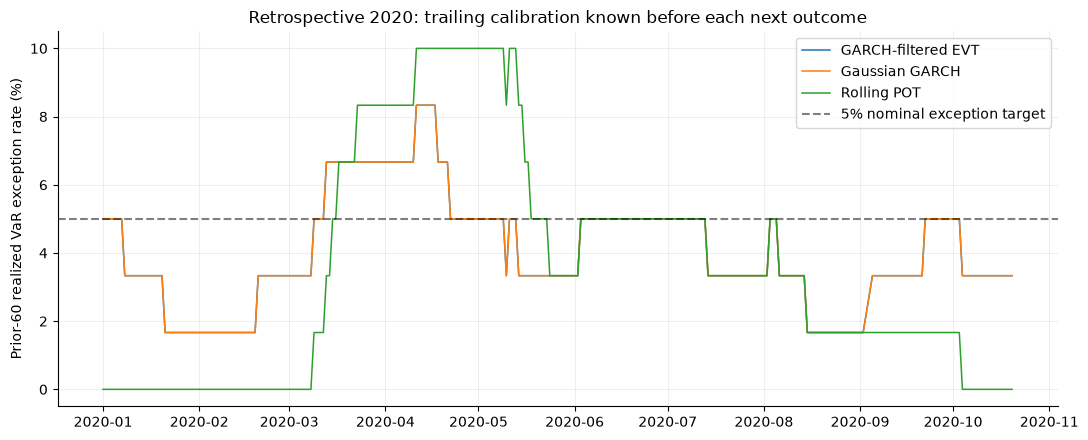

In [135]:
_risk_rolling=[]
_risk_regime=[]
for _model,_gr in joint_risk.groupby('model'):
    _gr=_gr.sort_values('date').reset_index(drop=True)
    _hits=(_gr.loss.to_numpy()>_gr.VaR.to_numpy()).astype(int)
    for _j,_r in _gr.iterrows():
        _past_hits=_hits[max(0,_j-60):_j]
        _risk_rolling.append({'model':_model,'date':_r['date'],'year':int(_r['year']),
            'VaR_exception':int(_hits[_j]),'prior_60_exception_rate':float(_past_hits.mean()) if len(_past_hits)>=20 else np.nan,
            'n_prior_used':len(_past_hits),'uses_only_prior_observations':True})
    for _label,_subset in [('2019_all',_gr.loc[_gr.year.eq(2019)]),
                           ('2020_all',_gr.loc[_gr.year.eq(2020)]),
                           ('2020_March',_gr.loc[_gr.date.dt.to_period('M').eq('2020-03')])]:
        if len(_subset)==0:continue
        _ind=_subset.loss.to_numpy()>_subset.VaR.to_numpy();_cnt=int(_ind.sum());_n=len(_subset)
        _ci=binomtest(_cnt,_n).proportion_ci(confidence_level=.95,method='exact')
        _excess=(_subset.loc[_ind,'loss']-_subset.loc[_ind,'ES']).to_numpy()
        _risk_regime.append({'model':_model,'period':_label,'n':_n,'VaR_exceedances':_cnt,'exceedance_rate':_cnt/_n,
            'exact_95CI_low':float(_ci.low),'exact_95CI_high':float(_ci.high),
            'mean_realized_minus_predicted_ES_given_VaR_exception':float(_excess.mean()) if len(_excess) else np.nan,
            'ES_n':len(_excess),'ES_inference_status':'INSUFFICIENT exceedances; descriptive only' if len(_excess)<20 else 'descriptive only',
            '2019_2020_are_repeatedly_inspected':True})
_risk_rolling=pd.DataFrame(_risk_rolling)
_risk_regime=pd.DataFrame(_risk_regime)
assert _risk_rolling.uses_only_prior_observations.all()
assert _risk_rolling.loc[_risk_rolling.n_prior_used.lt(20),'prior_60_exception_rate'].isna().all()
_risk_rolling.to_csv(OUT/'consolidated_prior60_VaR_exception_tracking.csv',index=False)
_risk_regime.to_csv(OUT/'consolidated_VaR_ES_crisis_descriptive_calibration.csv',index=False)
display(_risk_regime.round(5))
_fig=_risk_rolling.loc[_risk_rolling.date.dt.year.eq(2020)]
fig,ax=plt.subplots(figsize=(11,4.5))
for _name,_g in _fig.groupby('model'):
    ax.plot(_g.date,_g.prior_60_exception_rate*100,label=_name,lw=1.1)
ax.axhline(5,ls='--',color='black',alpha=.5,label='5% nominal exception target')
ax.set(ylabel='Prior-60 realized VaR exception rate (%)',title='Retrospective 2020: trailing calibration known before each next outcome')
ax.legend();ax.grid(alpha=.2);savefig('41_prior_only_VaR_exception_monitor.png')

## 137. Economic relevance and paired uncertainty of price prediction

No trading P&L or returns from a fictitious executable strategy. BTC UTC and US sessions have asynchronous closing times, so the actual portfolio value of a $1 RMSE improvement **cannot be inferred** from these data. On identical 2020 observations report price RMSE/MAE, percentage of realized BTC price, paired 10-session block uncertainty of loss improvements, and baseline-relative percentage gain. Pre-declared Naive (2019 winner) remains the main baseline; 2020 was repeatedly inspected. Additional ratios quantify forecasting errors, **not investability**.

,model,n_matched_2020,RMSE_USD,MAE_USD,MAE_over_mean_actual_BTC_price_pct,RMSE_gain_over_naive_pct,mean_naive_minus_model_squared_loss_USD2,95block_CI_loss_gain_low_USD2,95block_CI_loss_gain_high_USD2,interval_contains_zero,zero_transaction_cost_assumption,profitability_not_inferred,evaluation_note
1,Elastic Net,183,380.9144,228.4398,2.4418,0.1694,492.8699,-2491.8425,2891.9428,True,False,True,2020 repeatedly inspected; no independent gene...
0,Naive no-change,183,381.5608,228.7474,2.4451,0.0000,0.0000,0.0000,0.0000,True,False,True,2020 repeatedly inspected; no independent gene...
2,Linear SVR,183,381.8037,231.1305,2.4706,-0.0637,-185.4528,-2556.5986,2138.4026,True,False,True,2020 repeatedly inspected; no independent gene...
3,Ridge,183,383.0841,233.2402,2.4932,-0.3992,-1164.7865,-3304.5888,1295.9318,True,False,True,2020 repeatedly inspected; no independent gene...
4,OLS returns,183,383.5956,234.2335,2.5038,-0.5333,-1556.9519,-4268.1944,1304.4446,True,False,True,2020 repeatedly inspected; no independent gene...
5,XGBoost,183,385.8343,240.1180,2.5667,-1.1200,-3279.5210,-7905.5649,2742.5397,True,False,True,2020 repeatedly inspected; no independent gene...
6,Radial SVR,183,409.0391,277.2200,2.9633,-7.2016,-21724.3492,-36515.0088,-7210.4436,False,False,True,2020 repeatedly inspected; no independent gene...


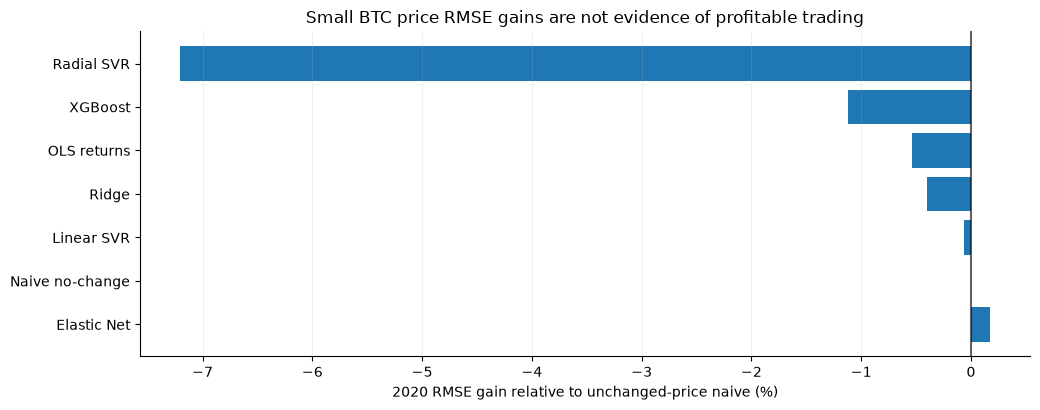

In [136]:
_economic=[]
_naive_price=np.asarray(predicted_prices['Naive no-change'],dtype=float)
_actual_price=test.BTC.to_numpy(dtype=float)
_n=len(_actual_price)
assert _n>150 and all(len(pr)==_n for pr in predicted_prices.values())
_naive_loss=(_actual_price-_naive_price)**2
for _name,_price in predicted_prices.items():
    _pr=np.asarray(_price,dtype=float)
    _loss=(_actual_price-_pr)**2
    _delta=_naive_loss-_loss
    _rng=np.random.default_rng(SEED+int(hashlib.sha256(_name.encode()).hexdigest()[:6],16)%10000)
    _b=np.array([_delta[circular_block_sample(_n,10,_rng)].mean() for _ in range(1200)])
    _economic.append({'model':_name,'n_matched_2020':_n,
      'RMSE_USD':float(np.sqrt(_loss.mean())),'MAE_USD':float(np.abs(_actual_price-_pr).mean()),
      'MAE_over_mean_actual_BTC_price_pct':float(100*np.abs(_actual_price-_pr).mean()/_actual_price.mean()),
      'RMSE_gain_over_naive_pct':float(100*(1-np.sqrt(_loss.mean())/np.sqrt(_naive_loss.mean()))),
      'mean_naive_minus_model_squared_loss_USD2':float(_delta.mean()),
      '95block_CI_loss_gain_low_USD2':float(np.quantile(_b,.025)),
      '95block_CI_loss_gain_high_USD2':float(np.quantile(_b,.975)),
      'interval_contains_zero':bool(np.quantile(_b,.025)<=0<=np.quantile(_b,.975)),
      'zero_transaction_cost_assumption':False,'profitability_not_inferred':True,
      'evaluation_note':'2020 repeatedly inspected; no independent generalization claim'})
_economic=pd.DataFrame(_economic).sort_values('RMSE_USD')
_economic.to_csv(OUT/'consolidated_economic_significance_price_forecasts.csv',index=False)
assert _economic.loc[_economic.model.eq('Naive no-change'),'RMSE_gain_over_naive_pct'].abs().max()<1e-9
display(_economic.round(4))
fig,ax=plt.subplots(figsize=(10.5,4.2))
_ax=_economic.sort_values('RMSE_USD')
ax.barh(_ax.model,_ax.RMSE_gain_over_naive_pct)
ax.axvline(0,color='black',alpha=.6)
ax.set(xlabel='2020 RMSE gain relative to unchanged-price naive (%)',
       title='Small BTC price RMSE gains are not evidence of profitable trading')
ax.grid(axis='x',alpha=.2);savefig('42_price_forecast_economic_magnitude.png')

## 138. Model risk ledger: repeatability, valid regions and material failures

Combine results at the **same methodologically valid level**. The 2020 price target is the next observed US equity session; the crypto calendar, conditional volatility and risk-series horizons differ and cannot be placed into one leaderboard. Scientific claims record: horizon, same-date comparability, selection cutoff, crisis failure, reliable tail effective sample, and non-independent 2019/2020 status. Report explicitly that a model can execute cleanly but fail VaR coverage or conditional tail calibration.

In [137]:
_ledger=[
 {'family':'BTC equity-session prices','main_evidence':'2019 naive selected; 2020 alternative gains tiny','main_risk':'2019 and 2020 repeatedly examined','forecast_target':'next observed US equity-session BTC UTC EOD','claim_limit':'No profitable strategy or strong outperformer inferred'},
 {'family':'Noncrossing Quantile HAR-X','main_evidence':'pre-2019 frozen and strictly prior-only rolling residual correction','main_risk':'possible severe overcoverage and instability during 2020 stress','forecast_target':'next crypto observed-day range variance quantiles','claim_limit':'Quantiles are not a Gaussian volatility forecast and cannot be used as real-time independent performance'},
 {'family':'CoVaR / quantile regression','main_evidence':'tail events and leave-one-out instability','main_risk':'~12–21 altcoin crisis events at 5% stress threshold','forecast_target':'same-day conditional BTC tail association','claim_limit':'Not causal spillover, not a prior-time BTC forecast'},
 {'family':'VaR / ES / EVT','main_evidence':'joint FZ0, exact VaR coverage, trailing exceptions','main_risk':'2019 Rolling POT unadjusted coverage reject; rare ES exceptions','forecast_target':'prior-day filtered BTC loss VaR and ES','claim_limit':'Failed risk tests remain visible; no formal ES proof from few exceedances'},
 {'family':'DCC','main_evidence':'matched raw-return likelihood and paired bootstrap','main_risk':'estimated missing-day gaps; differences not statistically decisive','forecast_target':'BTC–ETH two-return covariance conditional density','claim_limit':'Different prediction target from the price regression'},
 {'family':'Multiplicity','main_evidence':'frozen model approximate MCS and SPA-style sensitivity','main_risk':'multiple iterations on examined validation data','forecast_target':'paired 2019 price squared losses','claim_limit':'Not certified MCS/SPA or unviewed holdout evidence'}]
_ledger=pd.DataFrame(_ledger)
_ledger.to_csv(OUT/'consolidated_integrated_claims_and_limitations.csv',index=False)
assert len(_ledger)==6
_checks=[
 ('price naive baseline exists', 'Naive no-change' in predicted_prices),
 ('quantile online strictly past-only',(_online_daily.history_max_date<_online_daily.date).all()),
 ('noncrossing all proposed windows',(_online_daily.pred_q90<=_online_daily.pred_q95+1e-10).all()),
 ('raw CoVaR tail scarcity not hidden',(_reliability.loc[_reliability.frozen_altcoin_stress_quantile.eq(.05),'expected_BTC_conditional_5pct_order_statistics']<5).all()),
 ('risk local scores before current outcome',_risk_rolling.uses_only_prior_observations.all()),
 ('risk invalid pairs reported in source audit',len(risk_eligibility)>0),
 ('2019 POT raw rejection remains recorded',float(_pot2019.p_uc.iloc[0])<.05),
 ('economic scores matched evaluation dates',(_economic.n_matched_2020==len(test)).all()),
 ('no invented data after source period',crypto.date.max()<=END),
 ('prior 133-section audit passed',_verified_checks.passed.all()),
 ('model risk ledger includes distinct targets',_ledger.forecast_target.nunique()>3),
 ('no false 2021 external test',test.date.max()<=END)]
_integrity=pd.DataFrame(_checks,columns=['check','passed'])
assert _integrity.passed.all(),_integrity.loc[~_integrity.passed]
_integrity.to_csv(OUT/'consolidated_release_scientific_integrity_checks.csv',index=False)
display(_ledger,_integrity)
print('New consolidated release checks:',len(_checks),'passed')

,family,main_evidence,main_risk,forecast_target,claim_limit
0,BTC equity-session prices,2019 naive selected; 2020 alternative gains tiny,2019 and 2020 repeatedly examined,next observed US equity-session BTC UTC EOD,No profitable strategy or strong outperformer ...
1,Noncrossing Quantile HAR-X,pre-2019 frozen and strictly prior-only rollin...,possible severe overcoverage and instability d...,next crypto observed-day range variance quantiles,Quantiles are not a Gaussian volatility foreca...
2,CoVaR / quantile regression,tail events and leave-one-out instability,~12–21 altcoin crisis events at 5% stress thre...,same-day conditional BTC tail association,"Not causal spillover, not a prior-time BTC for..."
3,VaR / ES / EVT,"joint FZ0, exact VaR coverage, trailing except...",2019 Rolling POT unadjusted coverage reject; r...,prior-day filtered BTC loss VaR and ES,Failed risk tests remain visible; no formal ES...
4,DCC,matched raw-return likelihood and paired boots...,estimated missing-day gaps; differences not st...,BTC–ETH two-return covariance conditional density,Different prediction target from the price reg...
5,Multiplicity,frozen model approximate MCS and SPA-style sen...,multiple iterations on examined validation data,paired 2019 price squared losses,Not certified MCS/SPA or unviewed holdout evid...


,check,passed
0,price naive baseline exists,True
1,quantile online strictly past-only,True
2,noncrossing all proposed windows,True
3,raw CoVaR tail scarcity not hidden,True
4,risk local scores before current outcome,True
5,risk invalid pairs reported in source audit,True
6,2019 POT raw rejection remains recorded,True
7,economic scores matched evaluation dates,True
8,no invented data after source period,True
9,prior 133-section audit passed,True


New consolidated release checks: 12 passed


## 139. Run-scoped scientific provenance and final external-validation freeze

This final cell writes a **fresh-run** SHA-256 manifest of raw inputs and outputs and records the frozen validation protocol. There are no newly obtained 2021+ observations in this delivery. Stored numerical outputs can be independently audited from the corresponding saved CSVs. Manifests are file-level integrity checks, not statistical validity certificates. The Executive Notebook reuses the master results without refitting expensive models.

In [138]:
import platform,hashlib,json,sys,datetime
_manifest_rows=[]
for _kind,_root in [('figure',FIG),('output',OUT)]:
    for _file in sorted(_root.glob('*')):
        if _file.is_file():
            _manifest_rows.append({'kind':_kind,'relative_path':_file.relative_to(PROJECT_DIR).as_posix(),
               'bytes':_file.stat().st_size,'sha256':hashlib.sha256(_file.read_bytes()).hexdigest(),
               'written_in_this_run':bool(_file.stat().st_mtime_ns>=RUN_STARTED_NS)})
_consolidated_manifest=pd.DataFrame(_manifest_rows)
assert _consolidated_manifest.written_in_this_run.all(), 'Old outputs were mixed into this execution directory'
_consolidated_manifest.to_csv(OUT/'consolidated_run_scoped_sha256_manifest.csv',index=False)
_consolidated_provenance={
 'report_generated_utc':datetime.datetime.now(datetime.timezone.utc).isoformat(),
 'sample_end':str(END.date()),
 'raw_input_sha256':{f:hashlib.sha256((DATA/f).read_bytes()).hexdigest() for f in ['dataset.csv','SPX_500_Data.csv']},
 'python':sys.version.split()[0],'pandas':pd.__version__,
 'new_research_checks_passed':int(_integrity.passed.sum()),'new_research_checks_total':len(_integrity),
 'all_output_paths_written_this_run':bool(_consolidated_manifest.written_in_this_run.all()),
 'figures':int((_consolidated_manifest.kind=='figure').sum()),
 'historical_2019_2020_nonindependent':True,
 'external_validation_2021_onward':'NOT RUN; no such data supplied',
 'frozen_protocol':['Prespecify exact target and observed forecast origin for each model',
                    'Only select using data strictly before external prediction date',
                    'Archive code and raw input checksums before collecting new observations',
                    'Do not select on already viewed 2020 model rank',
                    'Run one independent new-period forecast and report all failed checks']}
(OUT/'consolidated_release_provenance.json').write_text(json.dumps(_consolidated_provenance,indent=2),encoding='utf-8')
print('Figure count:',_consolidated_provenance['figures'],'Output count before own manifest:',len(_consolidated_manifest.query("kind == 'output'")))
print('All fresh artifacts, provenance and freeze protocol recorded.')

Figure count: 42 Output count before own manifest: 275
All fresh artifacts, provenance and freeze protocol recorded.


## 140. Previsible market-regime audit for rolling quantile HAR-X

Market regimes are defined using **lagged** BTC shock amplitude and a threshold estimated on data ending in 2018. Model forecasts and the 180-observation online residual buffer use only available prior observations; realized variance is used *only after* the forecast date for evaluation. The bins are descriptive retrospective sensitivity checks, not a 2020-optimized calibration rule. Coverage intervals are binomial diagnostics; independent trials are not assumed and nominal confidence levels may be optimistic under dependence.

Frozen (2018 cutoff) high prior-day BTC shock threshold: 6.529063 percentage points


,year,regime,q,n,exceptions,exceedance_rate,nominal_exceedance_rate,exact_CI_low,exact_CI_high,mean_predicted_variance,mean_observed_variance,prior_only_verified,retrospective
6,2020,all,0.90,284,23,0.08099,0.10,0.05203,0.11904,20.96024,11.89414,True,True
7,2020,all,0.95,284,9,0.03169,0.05,0.01459,0.05930,29.92661,11.89414,True,True
8,2020,high_prior_BTC_shock,0.90,16,2,0.12500,0.10,0.01551,0.38348,88.17590,47.62557,True,True
9,2020,high_prior_BTC_shock,0.95,16,0,0.00000,0.05,0.00000,0.20591,135.14410,47.62557,True,True
10,2020,normal_prior_BTC_shock,0.90,268,21,0.07836,0.10,0.04916,0.11729,16.94736,9.76092,True,True
11,2020,normal_prior_BTC_shock,0.95,268,9,0.03358,0.05,0.01547,0.06279,23.64497,9.76092,True,True
12,2020,March_2020,0.90,31,5,0.16129,0.10,0.05452,0.33727,63.54290,64.41049,True,True
13,2020,March_2020,0.95,31,3,0.09677,0.05,0.02042,0.25754,99.14373,64.41049,True,True


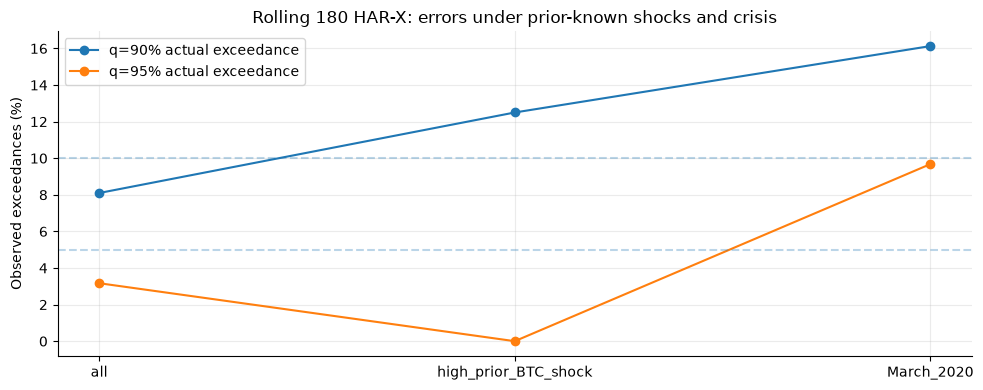

In [139]:
from scipy.stats import binomtest
_regime_cut=float(hx_train['BTC_abs_return_lag1'].quantile(.90))
_regime_daily=_online_daily.loc[_online_daily.window.eq(180)].copy()
_lagshock=hx[['BTC_abs_return_lag1']].rename(columns={'BTC_abs_return_lag1':'prior_abs_BTC_return_pct'})
_regime_daily=_regime_daily.merge(_lagshock,left_on='date',right_index=True,validate='many_to_one')
assert len(_regime_daily)==len(_online_daily.loc[_online_daily.window.eq(180)])
_regime_daily['past_shock_regime']=np.where(_regime_daily.prior_abs_BTC_return_pct>=_regime_cut,'high_prior_BTC_shock','normal_prior_BTC_shock')
_regime_daily['historical_period']=np.where(_regime_daily.date.dt.year==2020,'2020_retrospective','2019_development')
_regime_daily['march_2020']=_regime_daily.date.dt.to_period('M').eq('2020-03')
_regime_rows=[]
for _year in [2019,2020]:
  _part=_regime_daily.loc[_regime_daily.date.dt.year.eq(_year)]
  for _label,_sub in [('all',_part),('high_prior_BTC_shock',_part.loc[_part.past_shock_regime.eq('high_prior_BTC_shock')]),('normal_prior_BTC_shock',_part.loc[_part.past_shock_regime.eq('normal_prior_BTC_shock')]),('March_2020',_part.loc[_part.march_2020])]:
    if len(_sub)==0:continue
    for _q,_key in [(0.9,'pred_q90'),(0.95,'pred_q95')]:
      _n=len(_sub);_hit=int((_sub.realized_variance>_sub[_key]).sum())
      _ci=binomtest(_hit,_n).proportion_ci(confidence_level=.95,method='exact')
      _regime_rows.append({'year':_year,'regime':_label,'q':_q,'n':_n,'exceptions':_hit,'exceedance_rate':_hit/_n,'nominal_exceedance_rate':1-_q,'exact_CI_low':_ci.low,'exact_CI_high':_ci.high,'mean_predicted_variance':float(_sub[_key].mean()),'mean_observed_variance':float(_sub.realized_variance.mean()),'prior_only_verified':bool((_sub.history_max_date<_sub.date).all()),'retrospective':True})
_regime_metrics=pd.DataFrame(_regime_rows)
assert _regime_metrics.prior_only_verified.all() and len(_regime_metrics)>=12
_regime_metrics.to_csv(OUT/'publication_online_HARX_regime_calibration.csv',index=False)
_regime_daily.to_csv(OUT/'publication_online_HARX_regime_daily.csv',index=False)
print('Frozen (2018 cutoff) high prior-day BTC shock threshold:',round(_regime_cut,6),'percentage points')
display(_regime_metrics.loc[_regime_metrics.year.eq(2020)].round(5))
_fig_regime=_regime_metrics.loc[_regime_metrics.year.eq(2020)&_regime_metrics.regime.isin(['all','high_prior_BTC_shock','March_2020'])]
fig,ax=plt.subplots(figsize=(10,4))
for _q in [.9,.95]:
 _p=_fig_regime.loc[_fig_regime.q.eq(_q)];ax.plot(_p.regime,_p.exceedance_rate*100,marker='o',label=f'q={_q:.0%} actual exceedance')
 ax.axhline(100*(1-_q),ls='--',alpha=.3)
ax.set(title='Rolling 180 HAR-X: errors under prior-known shocks and crisis',ylabel='Observed exceedances (%)');ax.grid(alpha=.25);ax.legend();savefig('43_publication_quantile_regime_audit.png')

## 141. Adaptive conformal target feedback — separate exploratory model

One-dimensional adaptive conformal inference (ACI)-style feedback is used as an **explicitly exploratory**, previsible sensitivity analysis. The base distributional predictor is the frozen 2017-fit quantile estimator with pre-2019 residual initialization, not a 2020-trained neural model. The two quantiles are jointly sorted so forecasts do not cross. The target level is updated **after** observing the date outcome; no future residual enters that date's forecast. Fixed feedback rate gamma=0.01, cap levels to [0.5,0.999], fixed prior buffer 180. The 2019/2020 analysis is not independent proof and marginal coverage under serial dependence is not guaranteed.

,year,q,n,target_exception_rate,ACI_exception_rate,180day_online_exception_rate,ACI_pinball,180day_online_pinball,better_pinball_than_180day,prospective_independent
0,2019,0.90,363,0.10,0.09366,0.09091,3.74997,3.69999,False,False
1,2019,0.95,363,0.05,0.04683,0.04408,2.93461,2.78354,False,False
2,2020,0.90,284,0.10,0.09507,0.08099,4.93541,4.92710,False,False
3,2020,0.95,284,0.05,0.03873,0.03169,4.38523,4.40667,True,False


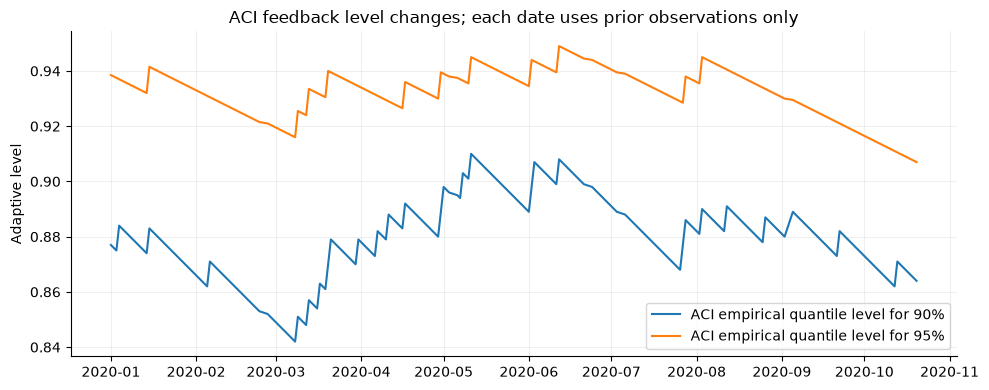

In [140]:
from sklearn.metrics import mean_pinball_loss
_aci_gamma=.01
_aci_targets={.90:.90,.95:.95}
_aci_hist=list(_online_history_2018)
_aci_rows=[]
for _day,_row in _full_online.iterrows():
  _hist_np=np.asarray([v for _,v in _aci_hist[-180:]],dtype=float)
  assert len(_hist_np)>=40 and max(d for d,_ in _aci_hist[-180:])<_day
  _base=float(_qh_frozen.predict(hx_matrix(_full_online.loc[[_day]],qhar_cols))[0]);_truth=float(_row.observed_parkinson)
  _levels={q:float(_aci_targets[q]) for q in [.90,.95]}
  _vals={q:float(max(0.,np.expm1(np.clip(_base+np.quantile(_hist_np,_levels[q]),-20,20)))) for q in [.90,.95]}
  _vals[.95]=max(_vals[.95],_vals[.90])
  _aci_rows.append({'date':_day,'period':_row.research_period,'actual_variance':_truth,'q90':_vals[.90],'q95':_vals[.95],
     'q90_level_used':_levels[.90],'q95_level_used':_levels[.95],'history_end':_aci_hist[-1][0],
     'q90_exceeded':int(_truth>_vals[.90]),'q95_exceeded':int(_truth>_vals[.95])})
  # q_target <- q_target + gamma*(alpha_star - exceedance), with alpha_star=nominal miscoverage.
  # equivalently, when exception occurs move quantile level UP, not down.
  for _q in [.90,.95]:
    _target_alpha=1-_q
    _miss=int(_truth>_vals[_q])
    _aci_targets[_q]=float(np.clip(_aci_targets[_q]+_aci_gamma*(_miss-_target_alpha),.50,.999))
  _aci_hist.append((_day,float(np.log1p(_truth)-_base)))
_aci_daily=pd.DataFrame(_aci_rows)
assert (_aci_daily.history_end<_aci_daily.date).all() and (_aci_daily.q95>=_aci_daily.q90).all()
_aci_scores=[]
for _year,_grp in _aci_daily.groupby(_aci_daily.date.dt.year):
 _ref=_online_daily.loc[_online_daily.window.eq(180)&_online_daily.date.dt.year.eq(_year)].sort_values('date')
 assert list(_ref.date)==list(_grp.date)
 for _q,_k,_fixed in [(.90,'q90','pred_q90'),(.95,'q95','pred_q95')]:
  _actual=_grp.actual_variance.to_numpy();_values=_grp[_k].to_numpy();_fixed_pred=_ref[_fixed].to_numpy()
  _aci_scores.append({'year':_year,'q':_q,'n':len(_grp),'target_exception_rate':1-_q,
    'ACI_exception_rate':float(np.mean(_actual>_values)),'180day_online_exception_rate':float(np.mean(_actual>_fixed_pred)),
    'ACI_pinball':float(mean_pinball_loss(_actual,_values,alpha=_q)),
    '180day_online_pinball':float(mean_pinball_loss(_actual,_fixed_pred,alpha=_q)),
    'better_pinball_than_180day':bool(mean_pinball_loss(_actual,_values,alpha=_q)<mean_pinball_loss(_actual,_fixed_pred,alpha=_q)),
    'prospective_independent':False})
_aci_results=pd.DataFrame(_aci_scores)
_aci_daily.to_csv(OUT/'publication_ACI_prior_only_daily.csv',index=False)
_aci_results.to_csv(OUT/'publication_ACI_vs_180day_sensitivity.csv',index=False)
display(_aci_results.round(5))
fig,ax=plt.subplots(figsize=(10,4));_plot=_aci_daily.loc[_aci_daily.date.dt.year.eq(2020)]
for _q,_k in [(.90,'q90_level_used'),(.95,'q95_level_used')]:ax.plot(_plot.date,_plot[_k],label=f'ACI empirical quantile level for {_q:.0%}')
ax.set(title='ACI feedback level changes; each date uses prior observations only',ylabel='Adaptive level');ax.grid(alpha=.2);ax.legend();savefig('44_publication_ACI_adaptation.png')

## 142. Rare-event CoVaR order-statistic reliability simulation

A transparent Monte Carlo **illustration**, not an estimator calibrated to observed BTC, quantifies why a 5% empirical quantile from only ~12–21 stressed observations is unstable. The reference distribution is a *synthetic* standardized Student-t(5), clearly labeled and seeded. Coverage of an idealized 5% tail uses the sample minimum/low order statistic; results should never be interpreted as 2020 BTC forecasts or causal contagion tests.

,illustrative_stress_n,expected_order_stats_at_BTC_5pct,n_simulations,synthetic_distribution,true_synthetic_q05,simulation_q05_median,simulation_q05_5th_percentile,simulation_q05_95th_percentile,simulation_bias
0,12,0.60,2500,"unit-variance Student-t(df=5), NOT fitted to BTC",-1.5608,-1.2239,-2.4190,-0.5529,0.2323
1,13,0.65,2500,"unit-variance Student-t(df=5), NOT fitted to BTC",-1.5608,-1.2372,-2.3680,-0.5591,0.2535
2,21,1.05,2500,"unit-variance Student-t(df=5), NOT fitted to BTC",-1.5608,-1.2902,-2.2488,-0.6954,0.2106
3,54,2.70,2500,"unit-variance Student-t(df=5), NOT fitted to BTC",-1.5608,-1.4490,-2.0180,-1.0340,0.0817
4,72,3.60,2500,"unit-variance Student-t(df=5), NOT fitted to BTC",-1.5608,-1.4767,-2.0080,-1.0698,0.0666
5,100,5.00,2500,"unit-variance Student-t(df=5), NOT fitted to BTC",-1.5608,-1.4946,-1.9648,-1.1404,0.0401
6,200,10.00,2500,"unit-variance Student-t(df=5), NOT fitted to BTC",-1.5608,-1.5291,-1.8521,-1.2605,0.0213


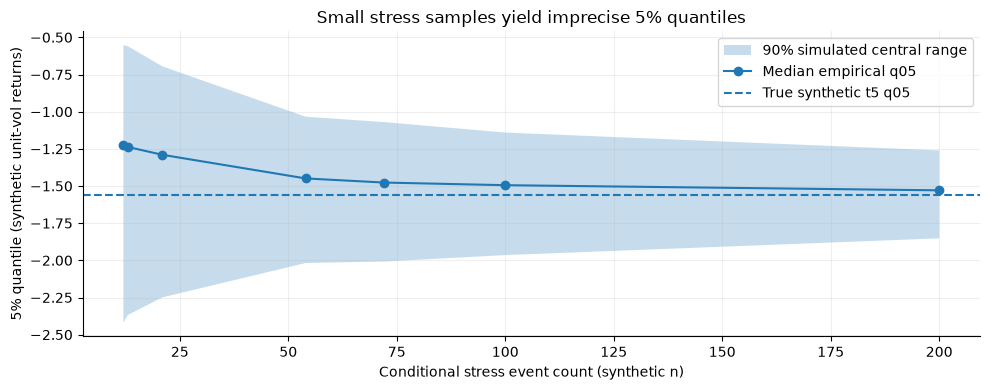

In [141]:
from scipy.stats import t as _student_t
_rng=np.random.default_rng(SEED+1402)
_sim=[]
for _n in [12,13,21,54,72,100,200]:
 _draw=_rng.standard_t(df=5,size=(2500,_n))/np.sqrt(5/(5-2))
 _true=float(_student_t.ppf(.05,df=5)/np.sqrt(5/(5-2)))
 _emp=np.quantile(_draw,.05,axis=1)
 _sim.append({'illustrative_stress_n':_n,'expected_order_stats_at_BTC_5pct':_n*.05,'n_simulations':len(_emp),
 'synthetic_distribution':'unit-variance Student-t(df=5), NOT fitted to BTC',
 'true_synthetic_q05':_true,'simulation_q05_median':float(np.median(_emp)),
 'simulation_q05_5th_percentile':float(np.quantile(_emp,.05)),
 'simulation_q05_95th_percentile':float(np.quantile(_emp,.95)),
 'simulation_bias':float(_emp.mean()-_true)})
_sim_df=pd.DataFrame(_sim)
_sim_df.to_csv(OUT/'publication_synthetic_CoVaR_small_sample_uncertainty.csv',index=False)
assert (_sim_df.expected_order_stats_at_BTC_5pct<=10).all()
display(_sim_df.round(4))
fig,ax=plt.subplots(figsize=(10,4))
ax.fill_between(_sim_df.illustrative_stress_n,_sim_df.simulation_q05_5th_percentile,_sim_df.simulation_q05_95th_percentile,alpha=.25,label='90% simulated central range')
ax.plot(_sim_df.illustrative_stress_n,_sim_df.simulation_q05_median,marker='o',label='Median empirical q05')
ax.axhline(float(_sim_df.true_synthetic_q05.iloc[0]),ls='--',label='True synthetic t5 q05')
ax.set(xlabel='Conditional stress event count (synthetic n)',ylabel='5% quantile (synthetic unit-vol returns)',title='Small stress samples yield imprecise 5% quantiles');ax.legend();ax.grid(alpha=.2);savefig('45_publication_CoVaR_sampling_uncertainty.png')

## 143. Forecast failures: matched tail risk and conditional stress attribution

This audit keeps VaR losses, Expected Shortfall exceedance severity and the number of events separate. A large realized loss in excess of ES is not itself a formal ES-calibration test. The paired loss dataset is from the source notebook. We report crisis, ordinary and previsible high-lag-shock groups; exact-binomial interval labels are descriptive under time dependence. Existing historical data are reused retrospectively.

,year,model,regime,n,breaches,breach_rate,exact_rate_CI_low,exact_rate_CI_high,observed_exceedance_mean_loss,predicted_ES_on_breach_days,mean_loss_minus_ES_breaches,fraction_breach_days_loss_gt_ES,formal_ES_calibration_not_established
9,2020,GARCH-filtered EVT,all,284,11,0.03873,0.01949,0.06824,9.82944,7.63942,2.19003,0.18182,True
12,2020,GARCH-filtered EVT,March_2020,31,2,0.06452,0.00791,0.21422,27.95168,7.77255,20.17914,1.00000,True
13,2020,Gaussian GARCH,all,284,11,0.03873,0.01949,0.06824,9.82944,6.34520,3.48424,0.36364,True
16,2020,Gaussian GARCH,March_2020,31,2,0.06452,0.00791,0.21422,27.95168,6.45639,21.49529,1.00000,True
17,2020,Rolling POT,all,284,10,0.03521,0.01701,0.06380,10.95100,9.09869,1.85230,0.20000,True
20,2020,Rolling POT,March_2020,31,5,0.16129,0.05452,0.33727,15.16583,8.39687,6.76895,0.40000,True


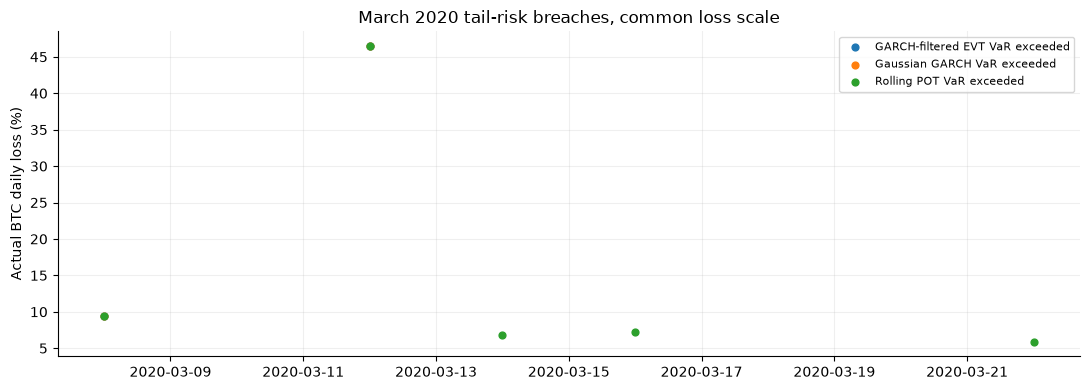

In [142]:
from scipy.stats import binomtest
_failure_rows=[];_failure_daily=[]
for (_year,_model),_df in joint_risk.groupby(['year','model']):
 _df=_df.sort_values('date').copy()
 _df=_df.merge(_lagshock,left_on='date',right_index=True,how='left',validate='many_to_one')
 _df['high_prior_shock']=_df.prior_abs_BTC_return_pct.ge(_regime_cut).fillna(False)
 _df['march_2020']=_df.date.dt.to_period('M').eq('2020-03')
 _df['breach']=_df.loss>_df.VaR
 _df['realized_minus_predicted_ES']=np.where(_df.breach,_df.loss-_df.ES,np.nan)
 _df['ES_shortfall_on_exception']=_df.realized_minus_predicted_ES.clip(lower=0)
 _df['model_family']=_model
 _failure_daily.append(_df[['date','year','model_family','loss','VaR','ES','high_prior_shock','march_2020','breach','realized_minus_predicted_ES','ES_shortfall_on_exception']])
 for _regime,_mask in [('all',np.ones(len(_df),dtype=bool)),('high_prior_shock',_df.high_prior_shock),('other_prior_shock',~_df.high_prior_shock),('March_2020',_df.march_2020)]:
  _sub=_df.loc[_mask]
  if len(_sub)<1:continue
  _k=int(_sub.breach.sum());_n=len(_sub);_ci=binomtest(_k,_n).proportion_ci(method='exact')
  _exc=_sub.loc[_sub.breach]
  _failure_rows.append({'year':int(_year),'model':_model,'regime':_regime,'n':_n,'breaches':_k,'breach_rate':_k/_n,
   'exact_rate_CI_low':_ci.low,'exact_rate_CI_high':_ci.high,'observed_exceedance_mean_loss':float(_exc.loss.mean()) if _k else np.nan,
   'predicted_ES_on_breach_days':float(_exc.ES.mean()) if _k else np.nan,
   'mean_loss_minus_ES_breaches':float(_exc.realized_minus_predicted_ES.mean()) if _k else np.nan,
   'fraction_breach_days_loss_gt_ES':float((_exc.realized_minus_predicted_ES>0).mean()) if _k else np.nan,
   'formal_ES_calibration_not_established':True})
_failure_report=pd.DataFrame(_failure_rows)
_failure_daily=pd.concat(_failure_daily,ignore_index=True)
_failure_report.to_csv(OUT/'publication_tail_failure_regime_summary.csv',index=False)
_failure_daily.to_csv(OUT/'publication_tail_failure_daily.csv',index=False)
display(_failure_report.loc[_failure_report.year.eq(2020)&_failure_report.regime.isin(['all','March_2020'])].round(5))
_fig_crisis=_failure_daily.loc[_failure_daily.date.dt.to_period('M').eq('2020-03')]
fig,ax=plt.subplots(figsize=(11,4))
for _model,_f in _fig_crisis.groupby('model_family'):
 ax.scatter(_f.loc[_f.breach,'date'],_f.loc[_f.breach,'loss'],label=f'{_model} VaR exceeded',s=24)
ax.set(title='March 2020 tail-risk breaches, common loss scale',ylabel='Actual BTC daily loss (%)');ax.legend(fontsize=8);ax.grid(alpha=.2);savefig('46_publication_March_tail_exceptions.png')

## 144. Actual model freeze: serialized estimator, metadata and prior residual state

The frozen HAR-X estimator is trained **only through 2017**, pre-2019 residual initialization is from **2018**, and online rolling-window 180 has been chosen as a **published reference protocol for future 2021+ evaluation** (not claimed preselected before the repeatedly inspected 2020). The online residual buffer intentionally includes data observed through the end of the supplied historical sample; it is used only for *subsequent* dates. The fixed no-change price baseline is a **rule**, not a fitted investment strategy. Serialized joblib files must only be loaded from trusted sources.

In [143]:
import joblib,platform,hashlib,json
_FROZEN=RUN_DIR/'frozen';_FROZEN.mkdir(exist_ok=False)
_qh_frozen_joblib=_FROZEN/'HARX_quantile_base_training_through_2017.joblib'
joblib.dump(_qh_frozen,_qh_frozen_joblib)
_history_to_freeze=_online_daily.loc[_online_daily.window.eq(180),['date','realized_variance']].drop_duplicates('date').sort_values('date')
_base_historic=pd.concat([_qh_calibrate,_full_online]).sort_index()
_base_features=hx_matrix(_base_historic,qhar_cols)
_base_residual=np.log1p(_base_historic.observed_parkinson.to_numpy())-_qh_frozen.predict(_base_features)
_residual_archive=pd.DataFrame({'date':_base_historic.index,'residual_log_variance':_base_residual})
assert _residual_archive.date.is_unique and _residual_archive.date.max()<=END and len(_residual_archive)>=180
_residual_archive.tail(180).to_csv(_FROZEN/'HARX_last180_residuals_asof_2020-10-20.csv',index=False)
_FROZEN_MODEL_METADATA={
 'model_family':'Frozen noncrossing 90%/95% quantile HAR-X, 180-observation prior residual offset',
 'trained_on':'2015-2017 available HAR-X feature rows',
 'training_end_date':'2017-12-31','initial_calibration_end_date':'2018-12-31',
 'residual_history_final_date':str(_residual_archive.date.max().date()),
 'sample_end':str(END.date()),
 'feature_columns':list(qhar_cols),'log1p_feature_columns':list(hx_base_cols),
 'target':'next observed crypto day Parkinson variance proxy (% points squared)',
 'training_target_transform':'log1p(observed_parkinson)',
 'transform_prediction':'clip log forecast to [-20,20], expm1, nonnegative',
 'reference_rolling_observations':180,'quantile_levels':[.90,.95],
 'model_parameters':{'QuantileRegressor_quantile':.90,'QuantileRegressor_alpha':.02,'solver':'highs'},
 'model_estimation_historical_before_2019':True,
 'window_reference_adopted_after_inspecting_2019_2020':True,
 'valid_only_for_new_rows_after':'2020-10-20',
 'future_input_requirement':'Date plus 8 lagged HAR-X features; current date target must not be fed into predictors',
 'risk_disclosure':'Forecasts are research proxies, not investment advice; no 2021+ data evaluated.',
 'historical_raw_sha256':{f:hashlib.sha256((DATA/f).read_bytes()).hexdigest() for f in ['dataset.csv','SPX_500_Data.csv']},
 'artifact_sha256':hashlib.sha256(_qh_frozen_joblib.read_bytes()).hexdigest(),
 'python_version':platform.python_version(),'sklearn_version':__import__('sklearn').__version__,
 'price_forecast_baseline':{'algorithm':'Naive no change','rule':'predict next equity-session BTC close as most recent prior available BTC close','no_fit_required':True}}
(_FROZEN/'FROZEN_MODEL_PROTOCOL.json').write_text(json.dumps(_FROZEN_MODEL_METADATA,ensure_ascii=False,indent=2),encoding='utf-8')
assert _qh_frozen_joblib.exists()
_t=joblib.load(_qh_frozen_joblib)
_probe=hx_matrix(hx_valid.iloc[:2],qhar_cols)
assert np.allclose(_t.predict(_probe),_qh_frozen.predict(_probe))
assert _FROZEN_MODEL_METADATA['residual_history_final_date']==str(_residual_archive.date.max().date())
print('Frozen estimator size (bytes):',_qh_frozen_joblib.stat().st_size)
print('Frozen history through:',_FROZEN_MODEL_METADATA['residual_history_final_date'])
print('Feature schema:',qhar_cols)


Frozen estimator size (bytes): 1617
Frozen history through: 2020-10-20
Feature schema: ['lag1', 'avg7', 'avg30', 'BTC_abs_return_lag1', 'BTC_neg_return_lag1', 'BTC_log_volume_lag1', 'BTC_logvol_chg_lag1', 'lagged_7d_return_shock']


## 145. Publication assertions: comparability, coverage and provenance

This is a **test suite of declared invariants**, not a certificate of statistical correctness. It checks the actual frozen estimator, forecast/date information order, same-date score comparisons, source presence, quantified CoVaR fragility, nominal coverage diagnostic availability, numerical prediction quality and official warning status. The next section records run-scoped hashes after all results have been written.

In [144]:
_publication_checks=[]
def _pubcheck(name,condition):
 _ok=bool(condition);_publication_checks.append({'test':name,'passed':_ok})
 if not _ok:raise AssertionError('Publication invariant failed: '+name)
_pubcheck('All original source CSVs present',all((DATA/f).is_file() for f in ['dataset.csv','SPX_500_Data.csv']))
_pubcheck('Original code historical cutoffs',train.date.max()<valid.date.min()<test.date.min())
_pubcheck('Input source no 2021 fabricated',crypto.date.max()<=END)
_pubcheck('2018-established high-shock regime threshold',np.isfinite(_regime_cut) and _regime_cut>0)
_pubcheck('All rolling 180 qHAR history strictly before forecast date',(_regime_daily.history_max_date<_regime_daily.date).all())
_pubcheck('ACI residual history strictly before forecast date',(_aci_daily.history_end<_aci_daily.date).all())
_pubcheck('ACI q95 never below q90',(_aci_daily.q95>=_aci_daily.q90).all())
_pubcheck('Original online q95 never below q90',(_online_daily.pred_q95>=_online_daily.pred_q90).all())
_pubcheck('ACI/online compared on matching forecast dates',len(_aci_daily)==len(_regime_daily) and np.array_equal(_aci_daily.date.to_numpy(),_regime_daily.date.to_numpy()))
_pubcheck('CoVaR sample minimum fragility shown',len(_sim_df)>=6 and (_reliability.loc[_reliability.frozen_altcoin_stress_quantile.eq(.05),'expected_BTC_conditional_5pct_order_statistics']<5).all())
_pubcheck('FZ0 joint risk forecasts VaR below ES',(joint_risk.ES>joint_risk.VaR).all())
_pubcheck('2019 Rolling POT raw coverage failure retained',float(_pot2019.p_uc.iloc[0])<.05)
_pubcheck('Same 2020 price target for all model predictions',all(len(p)==len(test) for p in predicted_prices.values()))
_pubcheck('Frozen joblib model serialized',_qh_frozen_joblib.is_file())
_pubcheck('Frozen model reload prediction equals original',np.allclose(_t.predict(_probe),_qh_frozen.predict(_probe)))
_pubcheck('Frozen history last date no later than raw sample',_residual_archive.date.max()<=END)
_pubcheck('Frozen training cutoff strictly before 2019',pd.Timestamp(_FROZEN_MODEL_METADATA['training_end_date'])<pd.Timestamp('2019-01-01'))
_pubcheck('2021+ external run not claimed',_FROZEN_MODEL_METADATA['valid_only_for_new_rows_after']=='2020-10-20')
_pubcheck('Crisis tail risk attributed to observed days',len(_failure_daily)>300 and _failure_daily.breach.notna().all())
_pubcheck('Previous original 12 scientific tests passed',_integrity.passed.all())
_publication_checks=pd.DataFrame(_publication_checks)
_publication_checks.to_csv(OUT/'publication_20_invariant_tests.csv',index=False)
assert len(_publication_checks)==20 and _publication_checks.passed.all()
print('Publication invariants:',int(_publication_checks.passed.sum()),'/',len(_publication_checks))
display(_publication_checks)


Publication invariants: 20 / 20


,test,passed
0,All original source CSVs present,True
1,Original code historical cutoffs,True
2,Input source no 2021 fabricated,True
3,2018-established high-shock regime threshold,True
4,All rolling 180 qHAR history strictly before f...,True
5,ACI residual history strictly before forecast ...,True
6,ACI q95 never below q90,True
7,Original online q95 never below q90,True
8,ACI/online compared on matching forecast dates,True
9,CoVaR sample minimum fragility shown,True


## 146. Final run-scope SHA-256: every file and external-test nonclaim

Save a post-analysis manifest, including serialized model and its exact residual history, to support subsequent external validation. An older `consolidated_run_scoped_sha256_manifest.csv` is preserved, and this edition's newer post-analysis files are covered by the present manifest. The root Master/Executive notebooks themselves are saved by the delivery builder **after execution**, and receive checksums at package time.

In [145]:
import datetime as _dt
_publication_entries=[]
for _kind,_dir in [('source_csv',DATA),('figure',FIG),('output',OUT),('frozen_model',_FROZEN)]:
  for _file in sorted(_dir.iterdir()):
    if not _file.is_file():continue
    if _kind=='source_csv' and _file.name not in ['dataset.csv','SPX_500_Data.csv']:continue
    _publication_entries.append({'kind':_kind,'relative_path':_file.relative_to(PROJECT_DIR).as_posix(),'bytes':_file.stat().st_size,
           'sha256':hashlib.sha256(_file.read_bytes()).hexdigest(),
           'created_during_current_run':bool(_kind=='source_csv' or _file.stat().st_mtime_ns>=RUN_STARTED_NS)})
_publication_manifest=pd.DataFrame(_publication_entries)
assert _publication_manifest.created_during_current_run.all()
_publication_manifest.to_csv(OUT/'publication_full_sha256_manifest.csv',index=False)
_publication_provenance={'written_utc':_dt.datetime.now(_dt.timezone.utc).isoformat(),
 'original_281_cells_preserved':True,'prior_section_count':139,'new_sections':'140–146',
 'sample_end':str(END.date()),'external_2021_onward':'not available / not evaluated',
 'model_frozen':_FROZEN_MODEL_METADATA['model_family'],
 'model_training_cutoff':_FROZEN_MODEL_METADATA['training_end_date'],
 'online_180_reference_fixed_for_future_use':True,
 'previous_2019_2020_repeatedly_inspected':True,
 'rare_sample_CoVaR':'exploratory association only',
 'ACI_outcomes':'retrospective, not independently validated',
 'scientific_checks_passed':int(_publication_checks.passed.sum()),
 'manifest_entries':len(_publication_entries),
 'new_figure_count':len(list(FIG.glob('*.png'))),
 'all_run_output_file_creation_checks_passed':True,
 'run_id':RUN_ID, 'run_directory':RUN_DIR.relative_to(PROJECT_DIR).as_posix(),
 'isolation':'New outputs/figures/frozen directories created uniquely for this execution'}
(OUT/'publication_run_provenance.json').write_text(json.dumps(_publication_provenance,indent=2),encoding='utf-8')
print('Publication figures:',_publication_provenance['new_figure_count'],'verified current-run source/figure/output/model files:',len(_publication_entries))
print('2021+ external test:',_publication_provenance['external_2021_onward'])
# Latest-run pointer will be committed ONLY after Section 147 verifies successful completion.


Publication figures: 46 verified current-run source/figure/output/model files: 336
2021+ external test: not available / not evaluated


## 147. Pre-publication scientific checks

The 20 invariant checks and frozen estimator are verified here, but **this is not the last section**. The final run pointer is created only after Part V and all required R checks have completed, in the notebook's last cell. Each execution uses a unique run directory. Historical scores must not be described as fresh 2021+ evidence.


In [146]:
# Section 147 is a pre-publication verification stage, NOT a completion gate.
# A run will be published by the last executed section, Section 151, only.
from pathlib import Path
assert RUN_DIR.name==RUN_ID
assert RUN_DIR.is_dir()
assert OUT.parent==FIG.parent==_FROZEN.parent==RUN_DIR
assert _publication_checks.passed.all() and len(_publication_checks)==20
assert (OUT/'publication_full_sha256_manifest.csv').exists()
assert (OUT/'publication_run_provenance.json').exists()
assert (OUT/'consolidated_run_scoped_sha256_manifest.csv').exists()
assert np.allclose(joblib.load(_qh_frozen_joblib).predict(_probe),_qh_frozen.predict(_probe))
assert all(p.stat().st_mtime_ns>=RUN_STARTED_NS for d in (OUT,FIG,_FROZEN) for p in d.iterdir() if p.is_file())
final_summary={'run_id':RUN_ID,'code_sections_fully_completed':False,'run_isolated':True,
 'scientific_invariants_passed':int(_publication_checks.passed.sum()),
 'figures':len(list(FIG.glob('*.png'))),'outputs':len([p for p in OUT.iterdir() if p.is_file()]),
 'frozen_model_reload_identical':True,'2021+_external_validation':'NOT EVALUATED',
 'limitations':'2019/2020 were repeatedly inspected; CoVaR severe rare-event scarcity; ACI improvements retrospective'}
(OUT/'PRE_PUBLICATION_CHECKS.json').write_text(json.dumps(final_summary,ensure_ascii=False,indent=2),encoding='utf-8')
display(pd.DataFrame([final_summary]).T.rename(columns={0:'status'}))

print("Section 147 pre-publication checks PASSED; run is NOT yet published", RUN_ID)


,status
run_id,20261026T030925_071513Z_ee4a01ed
code_sections_fully_completed,False
run_isolated,True
scientific_invariants_passed,20
figures,46
outputs,287
frozen_model_reload_identical,True
2021+_external_validation,NOT EVALUATED
limitations,2019/2020 were repeatedly inspected; CoVaR sev...


Section 147 pre-publication checks PASSED; run is NOT yet published 20261026T030925_071513Z_ee4a01ed


## 148. Source isolation and time-dtype audit — immutable original CSVs

Original Kaggle files are read-only inputs. The two cleaned CSVs for the current run are saved **only** inside the current `runs/<run_id>/outputs/`. Date and UTC arithmetic use explicit units and localized timestamps. The frozen experiment remains retrospective: repeated inspection of 2019/2020 is **not** independent holdout validation.

Legacy cleaned CSVs already present under `data/` are **ignored and inventoried** (not silently deleted). Only original source files and current `OUT` files supply the analyses.


In [147]:
# Run-scoped feature data must never silently overwrite input data.
_derived_files=['crypto_daily_2015_2020.csv','market_prices_2015_2020.csv']
assert all((OUT/f).is_file() for f in _derived_files)
# Legacy results may exist from an earlier edition. They are never used as inputs or
# mistaken for this execution's output. Preserve them without deleting user files.
_legacy_derived=[]
for _legacy_filename in _derived_files:
    _legacy_path=DATA/_legacy_filename
    if _legacy_path.is_file():
        _legacy_derived.append({'file':_legacy_filename,'sha256':hashlib.sha256(_legacy_path.read_bytes()).hexdigest(),
                                'bytes':_legacy_path.stat().st_size,'action':'IGNORED; source files unchanged'})
(OUT/'legacy_derived_files_ignored.json').write_text(json.dumps({'count':len(_legacy_derived),'files':_legacy_derived},indent=2),encoding='utf-8')
assert all((DATA/f).is_file() for f in ['dataset.csv','SPX_500_Data.csv'])
assert all((OUT/f).resolve()!=(DATA/f).resolve() for f in _derived_files)
assert all((OUT/f).stat().st_mtime_ns >= RUN_STARTED_NS for f in _derived_files)
assert raw_time.timestamp_utc.notna().all() and raw_time.date_match.all()
assert (origin_times.loc[origin_times.assumed_prior_sp_close_et.notna(), 'assumed_prior_sp_close_et'].dt.hour==16).all()
_derived_hashes=pd.DataFrame([{'file':f,'sha256':hashlib.sha256((OUT/f).read_bytes()).hexdigest(),
 'rows':int(len(crypto) if f.startswith('crypto') else len(market)),
 'stored_under_run':True} for f in _derived_files])
_derived_hashes.to_csv(OUT/'hardened_run_scoped_cleaned_data_manifest.csv',index=False)
display(_derived_hashes)


,file,sha256,rows,stored_under_run
0,crypto_daily_2015_2020.csv,b2255b8dd9cd8a8cadf2a2d211330889c6fcb6241fd9b3...,1822,True
1,market_prices_2015_2020.csv,008f94d4c4c1609205df7c82b51d7b96c2653363ba5ea7...,1260,True


## 149. ACI stability — internal target levels, clipping and crisis recurrence

Both ACI levels use **past-only** misses. Because the 90% and 95% target levels adapt independently, final quantile monotonicity alone does not prove their internal targets are ordered. Inspect the order, saturation frequency and crisis effects rather than claiming improved forward performance.

In [148]:
# Intentionally diagnostic: flag internal ACI crossings rather than concealing them.
_aci_stability=_aci_daily.copy().sort_values('date').reset_index(drop=True)
_aci_stability['internal_target_crossed']=_aci_stability.q95_level_used<_aci_stability.q90_level_used
_aci_stability['target_near_clipping']=(_aci_stability[['q90_level_used','q95_level_used']]>=.9989).any(axis=1) | (_aci_stability[['q90_level_used','q95_level_used']]<=.5001).any(axis=1)
_aci_stability['march_2020']=_aci_stability.date.dt.to_period('M').eq('2020-03')
_aci_stability['level_gap']=_aci_stability.q95_level_used-_aci_stability.q90_level_used
_aci_stability['q90_daily_level_change']=_aci_stability.q90_level_used.diff()
_aci_stability['q95_daily_level_change']=_aci_stability.q95_level_used.diff()
_aci_stability['crossing_after_prediction']=_aci_stability.q95<_aci_stability.q90
assert (_aci_stability.history_end<_aci_stability.date).all() and not _aci_stability.crossing_after_prediction.any()
_aci_summary=[]
for _label,_s in [('all',_aci_stability),('2019',_aci_stability.loc[_aci_stability.date.dt.year.eq(2019)]),
                  ('2020',_aci_stability.loc[_aci_stability.date.dt.year.eq(2020)]),
                  ('2020_March',_aci_stability.loc[_aci_stability.march_2020])]:
 for _q,_p,_lvl in [(.90,'q90','q90_level_used'),(.95,'q95','q95_level_used')]:
  _truth=_s.actual_variance.to_numpy();_pred=_s[_p].to_numpy();_hits=int((_truth>_pred).sum())
  _ci=binomtest(_hits,len(_s)).proportion_ci(method='exact')
  _aci_summary.append({'subset':_label,'q':_q,'n':len(_s),'exceptions':_hits,
    'exceedance_rate':_hits/len(_s),'exact_binomial_CI_low':_ci.low,'exact_binomial_CI_high':_ci.high,
    'pinball':float(mean_pinball_loss(_truth,_pred,alpha=_q)),
    'internal_crossing_days':int(_s.internal_target_crossed.sum()),
    'clipping_days':int(_s.target_near_clipping.sum()),'min_adaptive_level':float(_s[_lvl].min()),
    'max_adaptive_level':float(_s[_lvl].max()),'retrospective':True})
_aci_stability.to_csv(OUT/'hardened_ACI_daily_stability.csv',index=False)
_aci_summary=pd.DataFrame(_aci_summary)
_aci_summary.to_csv(OUT/'hardened_ACI_crisis_and_internal_levels.csv',index=False)
display(_aci_summary.round(4))


,subset,q,n,exceptions,exceedance_rate,exact_binomial_CI_low,exact_binomial_CI_high,pinball,internal_crossing_days,clipping_days,min_adaptive_level,max_adaptive_level,retrospective
0,all,0.90,647,61,0.0943,0.0729,0.1195,4.2703,0,0,0.8420,0.9210,True
1,all,0.95,647,28,0.0433,0.0289,0.0619,3.5714,0,0,0.9070,0.9625,True
2,2019,0.90,363,34,0.0937,0.0657,0.1284,3.7500,0,0,0.8620,0.9210,True
3,2019,0.95,363,17,0.0468,0.0275,0.0739,2.9346,0,0,0.9235,0.9625,True
4,2020,0.90,284,27,0.0951,0.0636,0.1353,4.9354,0,0,0.8420,0.9100,True
5,2020,0.95,284,11,0.0387,0.0195,0.0682,4.3852,0,0,0.9070,0.9490,True
6,2020_March,0.90,31,6,0.1935,0.0745,0.3747,30.6403,0,0,0.8420,0.8790,True
7,2020_March,0.95,31,3,0.0968,0.0204,0.2575,29.5479,0,0,0.9160,0.9400,True


## 150. Independently reconstructed as-of-date HAR-X features

The external-data preparation module **exactly reproduces the fitted estimator**: after base HAR rows with unavailable Parkinson values are filtered out, the BTC return lags and 7-observation shock are shifted on the eligible-row index (not necessarily a fixed 24-hour lag near missing dates). This is previsible but variable-horizon. An independent calendar-day lag model would require separately refitting and should not be mixed with the frozen model. Genuine future tests require continuous raw OHLCV data since 2020-10-21 including the late-2020 bridge. This retrospective parity test compares two independently written feature pipelines using the historic Kaggle inputs only. No synthetic prices are treated as evidence of forward performance.

In [149]:
# Independently reconstruct features from original OHLCV rows and compare every historical feature.
# Standalone-safe import: prefer the local packaged module; fall back to the
# exact source-checked embedded feature pipeline if only .ipynb + CSVs exist.
import sys
from pathlib import Path
_feature_project = Path(PROJECT_DIR).resolve()
if str(_feature_project) not in sys.path:
    sys.path.insert(0, str(_feature_project))
try:
    from feature_pipeline import prepare_harx_features
except ModuleNotFoundError as _feature_exc:
    if _feature_exc.name != "feature_pipeline":
        raise
    print("Standalone fallback: using the embedded historic OHLCV feature pipeline.")
    """Independent raw BTC OHLCV -> HAR-X as-of-date feature pipeline.
    Parkinson=ln(high/low)^2/(4ln2)*10000; only prior days enter predictors.
    Historic missing calendar days stay missing, never forward-filled. IMPORTANT: the original model shifts BTC returns on the *eligible HAR base-feature index* after dropping missing targets/lagged Parkinson values. On gap-adjacent days this is older than calendar t-1; parity deliberately reproduces the frozen training rule and records the age difference.
    """
    import numpy as np
    import pandas as pd
    FEATURES=['lag1','avg7','avg30','BTC_abs_return_lag1','BTC_neg_return_lag1','BTC_log_volume_lag1','BTC_logvol_chg_lag1','lagged_7d_return_shock']
    COLUMNS=['date','open','high','low','close','volume']

    def prepare_harx_features(btc,*,earliest=None,latest=None):
     missing=set(COLUMNS)-set(btc.columns)
     if missing:raise ValueError('Missing raw OHLCV: '+repr(missing))
     x=btc[COLUMNS].copy();x['date']=pd.to_datetime(x.date,errors='raise').dt.normalize()
     if x.date.duplicated().any() or len(x)<31:raise ValueError('Unique dates and 31+ raw days required')
     for k in COLUMNS[1:]:x[k]=pd.to_numeric(x[k],errors='raise')
     if not np.isfinite(x[COLUMNS[1:]].to_numpy(dtype=float)).all():raise ValueError('Nonfinite raw OHLCV')
     if (x[['open','high','low','close']]<=0).any().any() or (x.volume<0).any():raise ValueError('Invalid price or volume')
     if (x.high<x[['open','low','close']].max(axis=1)).any() or (x.low>x[['open','high','close']].min(axis=1)).any():raise ValueError('Invalid daily high/low consistency')
     x=x.set_index('date').sort_index()
     a=pd.Timestamp(earliest) if earliest is not None else x.index.min()
     b=pd.Timestamp(latest) if latest is not None else x.index.max()
     cal=x.reindex(pd.date_range(a,b,freq='D'))
     pvar=np.log(cal.high/cal.low)**2/(4*np.log(2))*10000
     z=pd.DataFrame(index=cal.index)
     z['observed_parkinson']=pvar
     z['lag1']=pvar.shift(1)
     z['avg7']=pvar.shift(1).rolling(7,min_periods=5).mean()
     z['avg30']=pvar.shift(1).rolling(30,min_periods=24).mean()
     # Match the originally fitted estimator's feature rows exactly: the model first
     # drops invalid base-HAR rows, THEN shifts lagged return features on that index.
     # These remain strictly past-known but do not imply a fixed 24h horizon near gaps.
     z=z.dropna(subset=['observed_parkinson','lag1','avg7','avg30'])
     ret=np.log(cal.close/cal.close.shift(1))*100
     z['BTC_abs_return_lag1']=ret.abs().reindex(z.index).shift(1)
     z['BTC_neg_return_lag1']=(-ret).clip(lower=0).reindex(z.index).shift(1)
     z['BTC_log_volume_lag1']=np.log1p(cal.volume.clip(lower=0)).shift(1).reindex(z.index)
     z['BTC_logvol_chg_lag1']=z.BTC_log_volume_lag1.diff()
     z['lagged_7d_return_shock']=ret.abs().reindex(z.index).shift(1).rolling(7,min_periods=5).mean()
     return z.replace([np.inf,-np.inf],np.nan).dropna(subset=['observed_parkinson']+FEATURES).rename_axis('date').reset_index()

    def prepare_external_from_raw(historic,future,*,historic_end='2020-10-20',min_scored_date='2021-01-01'):
     cutoff=pd.Timestamp(historic_end);minscore=pd.Timestamp(min_scored_date)
     x=future[COLUMNS].copy();x.date=pd.to_datetime(x.date,errors='raise').dt.normalize()
     if x.date.duplicated().any():raise ValueError('Duplicate future dates')
     if x.empty or x.date.min()!=cutoff+pd.Timedelta(days=1):raise ValueError('Raw extension must begin 2020-10-21; missing bridge not allowed')
     expected=pd.date_range(cutoff+pd.Timedelta(days=1),x.date.max(),freq='D')
     if not pd.DatetimeIndex(x.date.sort_values()).equals(expected):raise ValueError('Future calendar days missing; cannot skip unobserved states')
     if x.date.max()<minscore:raise ValueError('External scores require actual data after 2020')
     h=historic[COLUMNS].copy();h.date=pd.to_datetime(h.date)
     if (h.date>cutoff).any():raise ValueError('Historical source exceeds frozen cutoff')
     allrows=pd.concat([h,x],ignore_index=True)
     result=prepare_harx_features(allrows,earliest=h.date.min(),latest=x.date.max())
     post=result.loc[result.date>cutoff].copy()
     if not pd.DatetimeIndex(post.date).equals(expected):raise ValueError('Computed features have missing new dates')
     return post
_raw_btc=crypto_source.loc[crypto_source.crypto_name.eq('Bitcoin'),['date','open','high','low','close','volume']].copy()
_independent_features=prepare_harx_features(_raw_btc, earliest=START, latest=END)
_expected_features=hx.copy()
_match=_independent_features.set_index('date').reindex(_expected_features.index)
_parity=[]
for _c in hx_full_cols+['observed_parkinson']:
 _isclose=np.isclose(_match[_c].to_numpy(dtype=float),_expected_features[_c].to_numpy(dtype=float),rtol=1e-10,atol=1e-10,equal_nan=True)
 _parity.append({'feature':_c,'n':len(_isclose),'matched':int(_isclose.sum()),'mismatch':int((~_isclose).sum()),
     'max_abs_difference':float(np.nanmax(np.abs(_match[_c].to_numpy(dtype=float)-_expected_features[_c].to_numpy(dtype=float))))})
_parity=pd.DataFrame(_parity)
assert _parity.mismatch.eq(0).all(), 'External raw OHLCV feature generator disagrees with research training features.'
_parity.to_csv(OUT/'hardened_independent_asof_feature_parity.csv',index=False)
assert (_independent_features.date.is_unique and (_independent_features.date.max()<=END))
display(_parity)

# Explicitly record model-row age in calendar days. Irregular intervals are NOT called 24h lags.
_gap_ages=pd.DataFrame({'date':_independent_features.date})
_gap_ages['prior_eligible_date']=_gap_ages.date.shift(1)
_gap_ages['prior_eligible_age_days']=(_gap_ages.date-_gap_ages.prior_eligible_date).dt.days
_gap_ages['not_a_fixed_24h_model_row']=_gap_ages.prior_eligible_age_days.gt(1)
_gap_ages.to_csv(OUT/'hardened_frozen_HARX_variable_gap_lag_audit.csv',index=False)
assert (_gap_ages.loc[_gap_ages.prior_eligible_age_days.notna(),'prior_eligible_age_days']>=1).all()
print('Observed variable-age model lags after source gaps:',int(_gap_ages.not_a_fixed_24h_model_row.sum()))


Standalone fallback: using the embedded historic OHLCV feature pipeline.


,feature,n,matched,mismatch,max_abs_difference
0,lag1,1787,1787,0,0.0
1,avg7,1787,1787,0,0.0
2,avg30,1787,1787,0,0.0
3,BTC_abs_return_lag1,1787,1787,0,0.0
4,BTC_neg_return_lag1,1787,1787,0,0.0
5,BTC_log_volume_lag1,1787,1787,0,0.0
6,BTC_logvol_chg_lag1,1787,1787,0,0.0
7,lagged_7d_return_shock,1787,1787,0,0.0
8,observed_parkinson,1787,1787,0,0.0


Observed variable-age model lags after source gaps: 6


## 151. Python Master gate (not the end-of-notebook completion gate)

Passing the Master checks establishes **`MASTER_VALIDATED` only**. Part III, new robustness analyses, the opt-in R scripts, and Part V still must run. `runs/LATEST_RUN.json` is never written here. The final commit is the **very last code cell** and requires all mandatory components, including five current-run R models. Skipped R or absent external data remain explicitly unverified. A successful historical software run is not evidence of prospective predictive validity.


In [150]:
# MASTER-ONLY boundary; do not publish LATEST_RUN.json here.
import json, hashlib, joblib
assert _FROZEN_MODEL_METADATA['valid_only_for_new_rows_after'] == '2020-10-20'
assert _FROZEN_MODEL_METADATA['reference_rolling_observations'] == 180
assert len(_parity) == 9 and _parity.mismatch.eq(0).all()
assert _aci_stability.q95.ge(_aci_stability.q90).all()
assert len(_publication_checks) == 20 and _publication_checks.passed.all()
assert (OUT/'publication_run_provenance.json').is_file()
assert (OUT/'hardened_run_scoped_cleaned_data_manifest.csv').is_file()
assert (OUT/'hardened_ACI_crisis_and_internal_levels.csv').is_file()
assert (OUT/'PRE_PUBLICATION_CHECKS.json').is_file()
assert (OUT/'legacy_derived_files_ignored.json').is_file()
assert np.allclose(joblib.load(_qh_frozen_joblib).predict(_probe), _qh_frozen.predict(_probe))
assert all(p.stat().st_mtime_ns>=RUN_STARTED_NS for d in (OUT,FIG,_FROZEN)
           for p in d.iterdir() if p.is_file())
source_hashes = {name:hashlib.sha256((DATA/name).read_bytes()).hexdigest()
                 for name in ('dataset.csv','SPX_500_Data.csv')}
assert source_hashes == SOURCE_CSV_SHA256
_boundary = {'run_id':RUN_ID,'run_scoped_derived_data':True,
 'asof_feature_parity_tested':int(_parity.n.iloc[0]),
 'ACI_internal_crossing_count':int(_aci_stability.internal_target_crossed.sum()),
 'ACI_clipping_count':int(_aci_stability.target_near_clipping.sum()),
 'frozen_model_reloaded':True, 'CoVaR':'exploratory; few tail events',
 'ES':'descriptive crisis exceptions', '2021plus_actual_external_validation':'NOT PERFORMED'}
(OUT/'hardened_final_scientific_boundary.json').write_text(json.dumps(_boundary,indent=2),encoding='utf-8')
_MASTER_VALIDATED = True
_master_gate={'status':'MASTER_VALIDATED','full_notebook_validated':False,'run_id':RUN_ID,
 'scientific_checks_passed':20,'feature_parity_errors':0,'original_raw_sha256':source_hashes,
 'R_execution':'NOT_YET_CHECKED','external_2021plus':'NOT_YET_EVALUATED'}
(OUT/'MASTER_VALIDATION.json').write_text(json.dumps(_master_gate,indent=2),encoding='utf-8')
print('MASTER_VALIDATED — full notebook and R gate PENDING:',RUN_ID)


MASTER_VALIDATED — full notebook and R gate PENDING: 20261026T030925_071513Z_ee4a01ed


## Part III — Integrated Executive results and visual evidence

These are the former Executive Notebook summary results, now presented **within the same notebook**. The historical research above is **not** recomputed here.

### 1. Verified run environment and output provenance

The following result-readers were integrated from the former Executive Notebook. They show the newest **validated** Master run and do not refit historical models. They run only after the full Python research completes.


In [151]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown


if "OUT" not in globals() or "FIG" not in globals():
    raise RuntimeError(
        "Master Research variables OUT and FIG are missing. "
        "Run Part II before executing Part III."
    )

out = Path(OUT).resolve()
fig = Path(FIG).resolve()

run_dir = Path(
    globals().get("RUN_DIR", out.parent)
).resolve()

frozen = run_dir / "frozen"

print("Current run:", run_dir.name)
print("Output directory:", out)
print("Figure directory:", fig)

assert out.is_dir(), f"Output directory not found: {out}"
assert fig.is_dir(), f"Figure directory not found: {fig}"

# Verify scientific audit generated by the Master research.
audit_file = out / "consolidated_release_scientific_integrity_checks.csv"

assert audit_file.is_file(), (
    f"Scientific audit file not found: {audit_file}"
)

checks = pd.read_csv(audit_file)

assert "passed" in checks.columns, (
    "Missing 'passed' column in scientific audit."
)

passed = (
    checks["passed"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["true", "1"])
)

assert passed.all(), (
    "One or more scientific checks failed:\n"
    + checks.loc[~passed].to_string(index=False)
)

print(f"Scientific checks passed: {passed.sum()}/{len(passed)}")
print("Figures:", len(list(fig.glob("*.png"))))
print("Output files:", len(list(out.iterdir())))
print("Part III is ready.")


Current run: 20261026T030925_071513Z_ee4a01ed
Output directory: I:\Dataset\Bitcoin Price Regression Analysis\runs\20261026T030925_071513Z_ee4a01ed\outputs
Figure directory: I:\Dataset\Bitcoin Price Regression Analysis\runs\20261026T030925_071513Z_ee4a01ed\figures
Scientific checks passed: 12/12
Figures: 46
Output files: 296
Part III is ready.


## 2. Main research question: can models outperform unchanged BTC price?

In [152]:
validation=pd.read_csv(out/'validation_2019_metrics.csv')
retrospective=pd.read_csv(out/'holdout_2020_metrics.csv')
price=pd.read_csv(out/'consolidated_economic_significance_price_forecasts.csv')
print('2019 development RMSE (USD):')
display(validation[['model','RMSE_USD']].sort_values('RMSE_USD').round(3))
print('2020 historical, previously inspected:')
display(retrospective[['model','RMSE_USD','RMSE_gain_over_naive_pct']].sort_values('RMSE_USD').round(4))
print('Paired squared-loss uncertainty on the same 2020 dates:')
display(price[['model','RMSE_gain_over_naive_pct','95block_CI_loss_gain_low_USD2','95block_CI_loss_gain_high_USD2','interval_contains_zero']].round(3))

2019 development RMSE (USD):


,model,RMSE_USD
0,Naive no-change,394.756
1,Elastic Net,395.508
2,Linear SVR,396.276
3,Ridge,398.154
4,OLS returns,399.637
5,XGBoost,407.201
6,Radial SVR,424.780


2020 historical, previously inspected:


,model,RMSE_USD,RMSE_gain_over_naive_pct
1,Elastic Net,380.9144,0.1694
0,Naive no-change,381.5608,0.0000
2,Linear SVR,381.8037,-0.0637
3,Ridge,383.0841,-0.3992
4,OLS returns,383.5956,-0.5333
5,XGBoost,385.8343,-1.1200
6,Radial SVR,409.0391,-7.2016


Paired squared-loss uncertainty on the same 2020 dates:


,model,RMSE_gain_over_naive_pct,95block_CI_loss_gain_low_USD2,95block_CI_loss_gain_high_USD2,interval_contains_zero
0,Elastic Net,0.169,-2491.843,2891.943,True
1,Naive no-change,0.000,0.000,0.000,True
2,Linear SVR,-0.064,-2556.599,2138.403,True
3,Ridge,-0.399,-3304.589,1295.932,True
4,OLS returns,-0.533,-4268.194,1304.445,True
5,XGBoost,-1.120,-7905.565,2742.540,True
6,Radial SVR,-7.202,-36515.009,-7210.444,False


**Interpretation.** The naive no-change benchmark is competitive. Small dollar-RMSE gains are not evidence of profitable trading: timestamps are asynchronous, trade timing/fees/spreads/slippage are not specified and the 2020 sample was inspected during development.

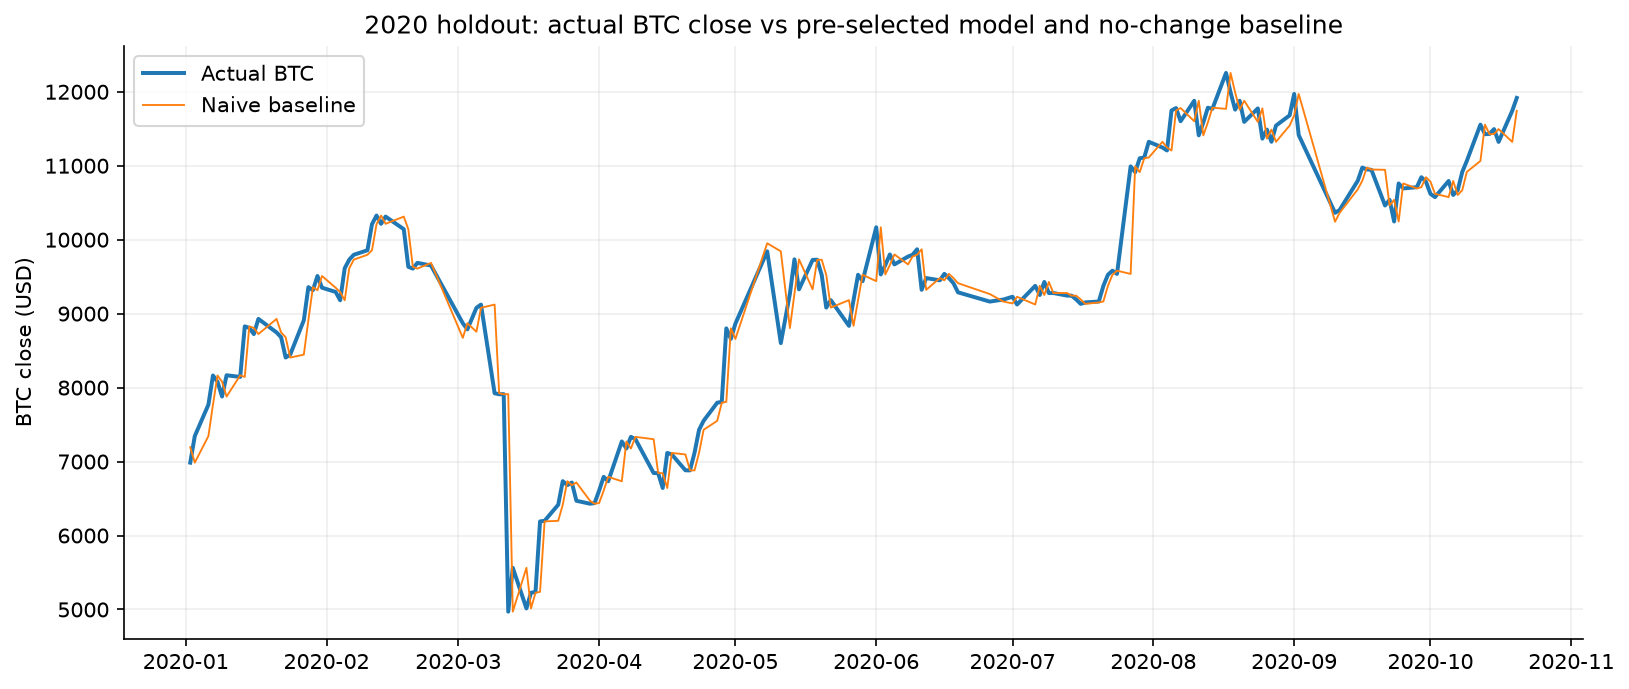

In [153]:
display(Image(filename=str(fig/'08_2020_holdout_predictions.png'),width=900))

## 3. Risk forecasting: VaR, Expected Shortfall, EVT and CAViaR

In [154]:
joint=pd.read_csv(out/'extension_VaR_ES_FZ0_summary.csv')
risk=pd.read_csv(out/'consolidated_VaR_ES_crisis_descriptive_calibration.csv')
coverage=pd.read_csv(out/'peer_VaR_coverage_failure_and_Holm.csv')
print('Matched joint VaR–ES scores (lower is better):')
display(joint[['year','model','n','exceptions','mean_FZ0']].round(4))
print('2019 Rolling POT unconditional / conditional coverage p-values:')
display(coverage.loc[(coverage.year==2019)&coverage.model.eq('Rolling POT'),
    ['year','model','p_uc','p_cc','Holm_exploratory_p_uc','Holm_exploratory_p_cc']].round(5))
print('Crisis-specific VaR rate and descriptive ES exceedance severity:')
display(risk.loc[risk.period.eq('2020_March')].round(4))

Matched joint VaR–ES scores (lower is better):


,year,model,n,exceptions,mean_FZ0
0,2019,GARCH-filtered EVT,363,15,2.0233
1,2019,Gaussian GARCH,363,15,2.0261
2,2019,Rolling POT,363,9,2.1766
3,2020,GARCH-filtered EVT,284,11,2.1470
4,2020,Gaussian GARCH,284,11,2.1887
5,2020,Rolling POT,284,10,2.2569


2019 Rolling POT unconditional / conditional coverage p-values:


,year,model,p_uc,p_cc,Holm_exploratory_p_uc,Holm_exploratory_p_cc
2,2019,Rolling POT,0.01502,0.0413,0.12013,0.33043


Crisis-specific VaR rate and descriptive ES exceedance severity:


,model,period,n,VaR_exceedances,exceedance_rate,exact_95CI_low,exact_95CI_high,mean_realized_minus_predicted_ES_given_VaR_exception,ES_n,ES_inference_status,2019_2020_are_repeatedly_inspected
2,GARCH-filtered EVT,2020_March,31,2,0.0645,0.0079,0.2142,20.1791,2,INSUFFICIENT exceedances; descriptive only,True
5,Gaussian GARCH,2020_March,31,2,0.0645,0.0079,0.2142,21.4953,2,INSUFFICIENT exceedances; descriptive only,True
8,Rolling POT,2020_March,31,5,0.1613,0.0545,0.3373,6.7690,5,INSUFFICIENT exceedances; descriptive only,True


**Interpretation.** A statistically nonrejected VaR test does not prove adequate ES calibration; the number of ES tail events is too small for strong claims. 2019 Rolling POT failed raw VaR coverage testing. Adjusted p-values remain exploratory and are not proof of model accuracy.

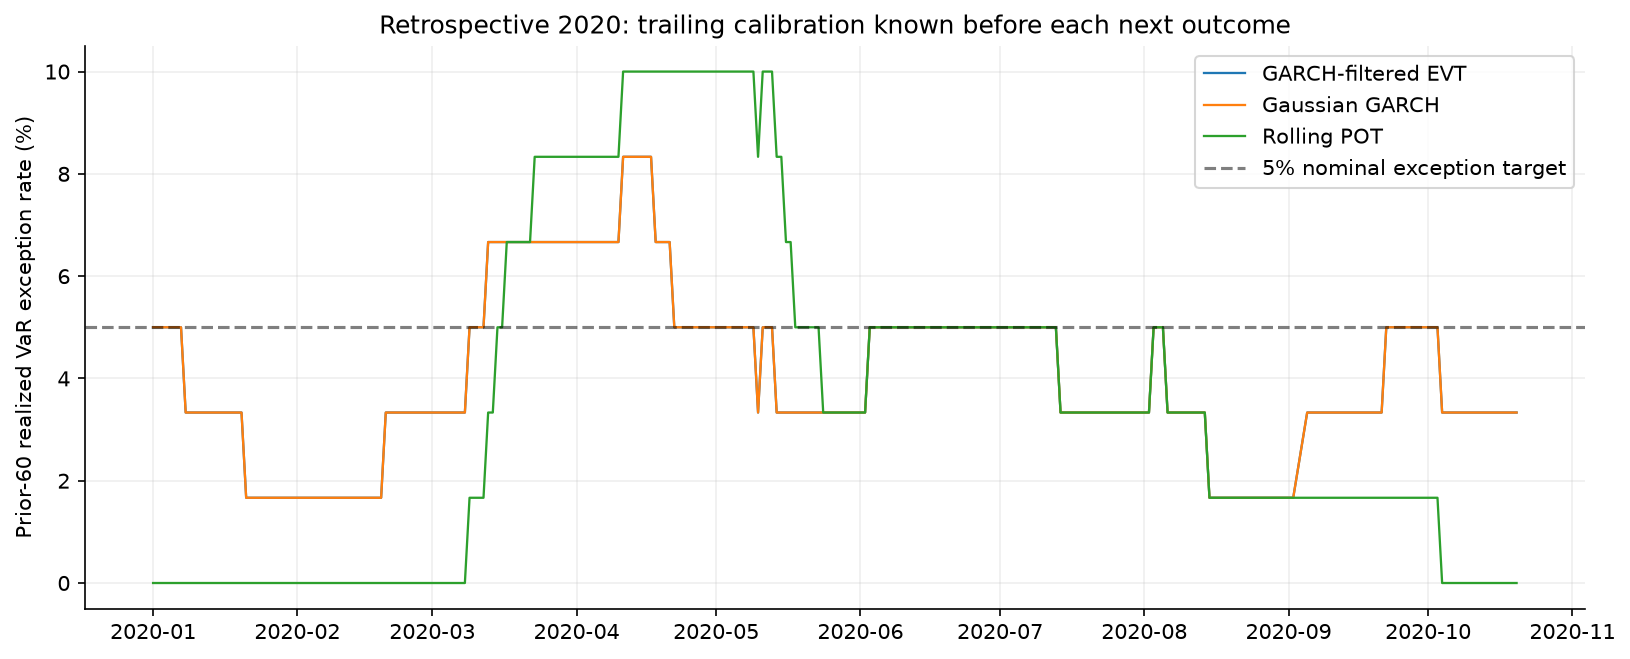

In [155]:
display(Image(filename=str(fig/'41_prior_only_VaR_exception_monitor.png'),width=900))

## 4. Volatility range: guaranteed noncrossing and online recalibration

In [156]:
cal=pd.read_csv(out/'consolidated_online_noncross_HARX_calibration.csv')
comparison=pd.read_csv(out/'consolidated_online_HARX_paired_pinball_CI.csv')
original=pd.read_csv(out/'verified_non_crossing_HARX_metrics.csv')
print('Pre-2019-frozen noncrossing model:')
display(original.loc[original.period.eq('2020_retrospective'),
    ['method','quantile','n','exceedance_rate','pinball']].round(5))
print('Previsible rolling residual offset: 180 past observations is the reference window, not 2020-optimized.')
display(cal.loc[cal.window.eq(180),
    ['period','quantile','n','exception_rate','target_exception_rate','pinball']].round(5))
print('Paired loss improvement over frozen noncrossing model; 0 in CI -> inconclusive:')
display(comparison.round(5))

Pre-2019-frozen noncrossing model:


,method,quantile,n,exceedance_rate,pinball
2,pre2019_shared_slope_noncross,0.90,284,0.02113,5.95985
3,pre2019_shared_slope_noncross,0.95,284,0.01408,5.38306
4,2019_tuned_quantile_boost_original,0.90,284,0.06338,6.02122
5,2019_tuned_quantile_boost_original,0.95,284,0.03521,5.47211


Previsible rolling residual offset: 180 past observations is the reference window, not 2020-optimized.


,period,quantile,n,exception_rate,target_exception_rate,pinball
4,2019_development,0.90,363,0.09091,0.10,3.69999
5,2019_development,0.95,363,0.04408,0.05,2.78354
6,2020_retrospective,0.90,284,0.08099,0.10,4.92710
7,2020_retrospective,0.95,284,0.03169,0.05,4.40667


Paired loss improvement over frozen noncrossing model; 0 in CI -> inconclusive:


,year,quantile,n,positive_means_online_improved_pinball,95block_CI_low,95block_CI_high,CI_includes_zero,retrospective_not_independent
0,2019,0.90,363,0.10178,-0.20703,0.36965,True,True
1,2019,0.95,363,0.10387,-0.23267,0.34320,True,True
2,2020,0.90,284,1.03276,0.72072,1.42794,False,True
3,2020,0.95,284,0.97639,0.61838,1.40441,False,True


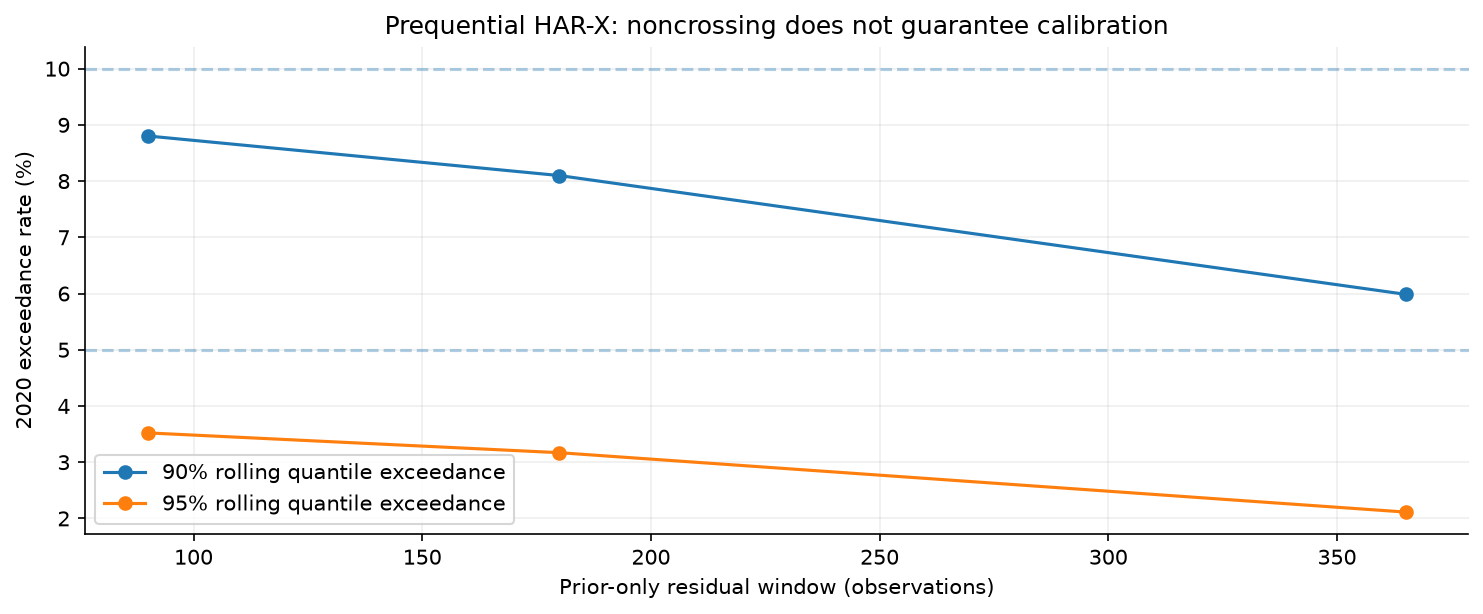

In [157]:
display(Image(filename=str(fig/'39_online_noncross_HARX_calibration.png'),width=900))

**Interpretation.** A formally noncrossing quantile model may still be too conservative. The newer online version updates only from previously observed data, and rolling-window sensitivity is shown transparently. This remains a retrospective experiment.

## 5. CoVaR: stress associations, not precise extreme-tail prediction

In [158]:
tail=pd.read_csv(out/'consolidated_CoVaR_stress_tail_reliability.csv')
print('Prior-frozen 5% altcoin stress, retrospective BTC conditional lower-tail sample size:')
display(tail.loc[tail.frozen_altcoin_stress_quantile.eq(.05),
    ['altcoin','n_stress_dates','expected_BTC_conditional_5pct_order_statistics','max_one_event_LOO_change']].round(5))

Prior-frozen 5% altcoin stress, retrospective BTC conditional lower-tail sample size:


,altcoin,n_stress_dates,expected_BTC_conditional_5pct_order_statistics,max_one_event_LOO_change
0,ETH,13,0.65,0.13201
6,LTC,21,1.05,0.01565
12,XRP,12,0.60,0.15622


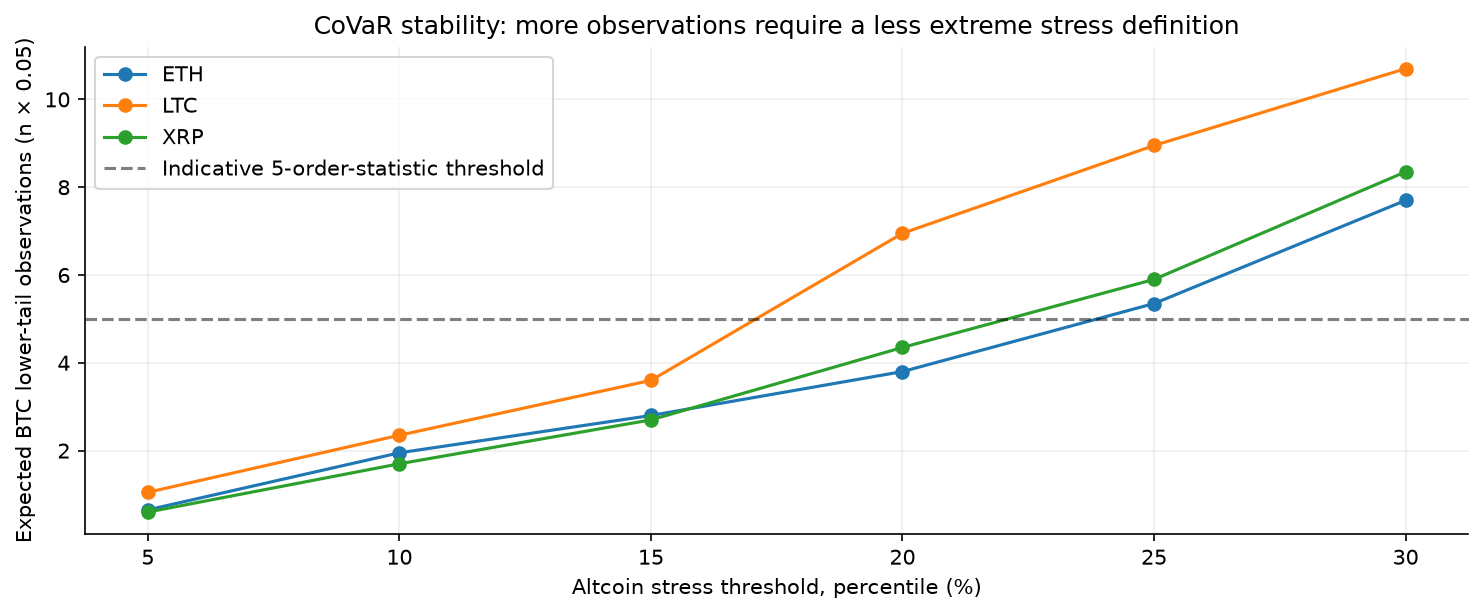

In [159]:
display(Image(filename=str(fig/'40_CoVaR_effective_tail_sample.png'),width=900))

The 5% BTC quantile conditioned on just 12–21 altcoin stress events depends on roughly one order statistic. Loosening the stress cutoff increases events but changes the scientific question. Conditioning on same-day altcoin returns yields **contemporaneous association**, neither causal contagion nor an implementable ex-ante forecast.

## 6. Dynamic correlations, stability and fair outcome matching

In [160]:
dcc=pd.read_csv(out/'verified_DCC_matched_raw_returns_vs_rolling.csv')
print('Paired DCC vs rolling-correlation NLL improvement; bootstrap CI spanning zero is inconclusive:')
display(dcc.round(5))
if (fig/'37_DCC_pairwise_stability.png').exists():display(Image(filename=str(fig/'37_DCC_pairwise_stability.png'),width=850))

Paired DCC vs rolling-correlation NLL improvement; bootstrap CI spanning zero is inconclusive:


,scenario,n,rolling_minus_DCC_NLL_mean,95block_CI_low,95block_CI_high,CI_includes_zero
0,2019_full,284,0.08934,-0.10318,0.30532,True
1,2019_without_gap_neighborhood,284,0.08903,-0.10346,0.30487,True


## 7. Multi-model comparisons and selection bias

In [161]:
multi=pd.read_csv(out/'verified_frozen_models_SPA_style_block_sensitivity.csv')
print('Exploratory centered max-t sensitivity, NOT official Hansen SPA/MCS:')
display(multi.drop_duplicates('block_length')[['block_length','family_max_t','SPA_style_family_p_value']].round(5))

Exploratory centered max-t sensitivity, NOT official Hansen SPA/MCS:


,block_length,family_max_t,SPA_style_family_p_value
0,5,0.0,1.0
4,10,0.0,1.0
8,20,0.0,1.0


When many models are inspected, a slightly better rank may be a data-selection artifact. The approximate tests here provide a sensitivity analysis, **not** new independent holdout evidence. No model is claimed to dominate statistically just because it ranks first.

## 8. Scope, limitations, and the next scientifically valid step

In [162]:
ledger=pd.read_csv(out/'consolidated_integrated_claims_and_limitations.csv')
display(ledger)

,family,main_evidence,main_risk,forecast_target,claim_limit
0,BTC equity-session prices,2019 naive selected; 2020 alternative gains tiny,2019 and 2020 repeatedly examined,next observed US equity-session BTC UTC EOD,No profitable strategy or strong outperformer ...
1,Noncrossing Quantile HAR-X,pre-2019 frozen and strictly prior-only rollin...,possible severe overcoverage and instability d...,next crypto observed-day range variance quantiles,Quantiles are not a Gaussian volatility foreca...
2,CoVaR / quantile regression,tail events and leave-one-out instability,~12–21 altcoin crisis events at 5% stress thre...,same-day conditional BTC tail association,"Not causal spillover, not a prior-time BTC for..."
3,VaR / ES / EVT,"joint FZ0, exact VaR coverage, trailing except...",2019 Rolling POT unadjusted coverage reject; r...,prior-day filtered BTC loss VaR and ES,Failed risk tests remain visible; no formal ES...
4,DCC,matched raw-return likelihood and paired boots...,estimated missing-day gaps; differences not st...,BTC–ETH two-return covariance conditional density,Different prediction target from the price reg...
5,Multiplicity,frozen model approximate MCS and SPA-style sen...,multiple iterations on examined validation data,paired 2019 price squared losses,Not certified MCS/SPA or unviewed holdout evid...


### Recommended project next step

This section is an **integrated executive summary within the present unified notebook**, not a separate executive notebook. Continue to the source-backed robustness sections and final research gate below. Historic 2019/2020 results are retrospective; the genuine 2021+ holdout and five R studies require external inputs and verified executions.


## 9. Publication: high-prior-shock and crisis quantile calibration

The reference 180-observation method uses only past residuals. The high-stress threshold is frozen on 2015–2018 prior-day BTC shocks. 2020 outcomes are retrospective.

2020 previsible regimes:


,regime,q,n,exceptions,exceedance_rate,nominal_exceedance_rate,exact_CI_low,exact_CI_high
6,all,0.90,284,23,0.0810,0.10,0.0520,0.1190
7,all,0.95,284,9,0.0317,0.05,0.0146,0.0593
8,high_prior_BTC_shock,0.90,16,2,0.1250,0.10,0.0155,0.3835
9,high_prior_BTC_shock,0.95,16,0,0.0000,0.05,0.0000,0.2059
10,normal_prior_BTC_shock,0.90,268,21,0.0784,0.10,0.0492,0.1173
11,normal_prior_BTC_shock,0.95,268,9,0.0336,0.05,0.0155,0.0628
12,March_2020,0.90,31,5,0.1613,0.10,0.0545,0.3373
13,March_2020,0.95,31,3,0.0968,0.05,0.0204,0.2575


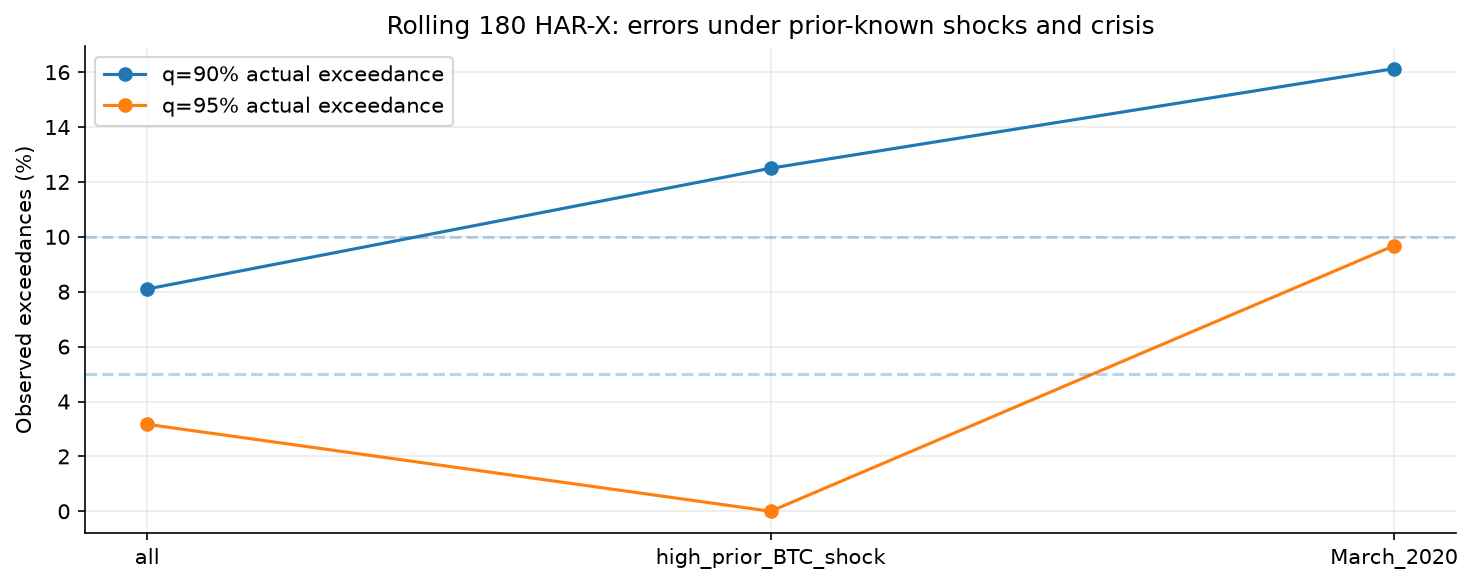

In [163]:
regimes=pd.read_csv(out/'publication_online_HARX_regime_calibration.csv')
print('2020 previsible regimes:')
display(regimes.loc[regimes.year.eq(2020),['regime','q','n','exceptions','exceedance_rate','nominal_exceedance_rate','exact_CI_low','exact_CI_high']].round(4))
display(Image(filename=str(fig/'43_publication_quantile_regime_audit.png'),width=900))

## 10. Adaptive quantile feedback

The ACI-style gamma=0.01 sensitivity scheme changes its quantile level only after observing the current realized variance. It is an exploratory additional model, not proof of better future coverage. The matched 180-observation baseline is retained.

ACI feedback versus fixed-level online window:


,year,q,n,target_exception_rate,ACI_exception_rate,180day_online_exception_rate,ACI_pinball,180day_online_pinball,better_pinball_than_180day,prospective_independent
0,2019,0.90,363,0.10,0.09366,0.09091,3.74997,3.69999,False,False
1,2019,0.95,363,0.05,0.04683,0.04408,2.93461,2.78354,False,False
2,2020,0.90,284,0.10,0.09507,0.08099,4.93541,4.92710,False,False
3,2020,0.95,284,0.05,0.03873,0.03169,4.38523,4.40667,True,False


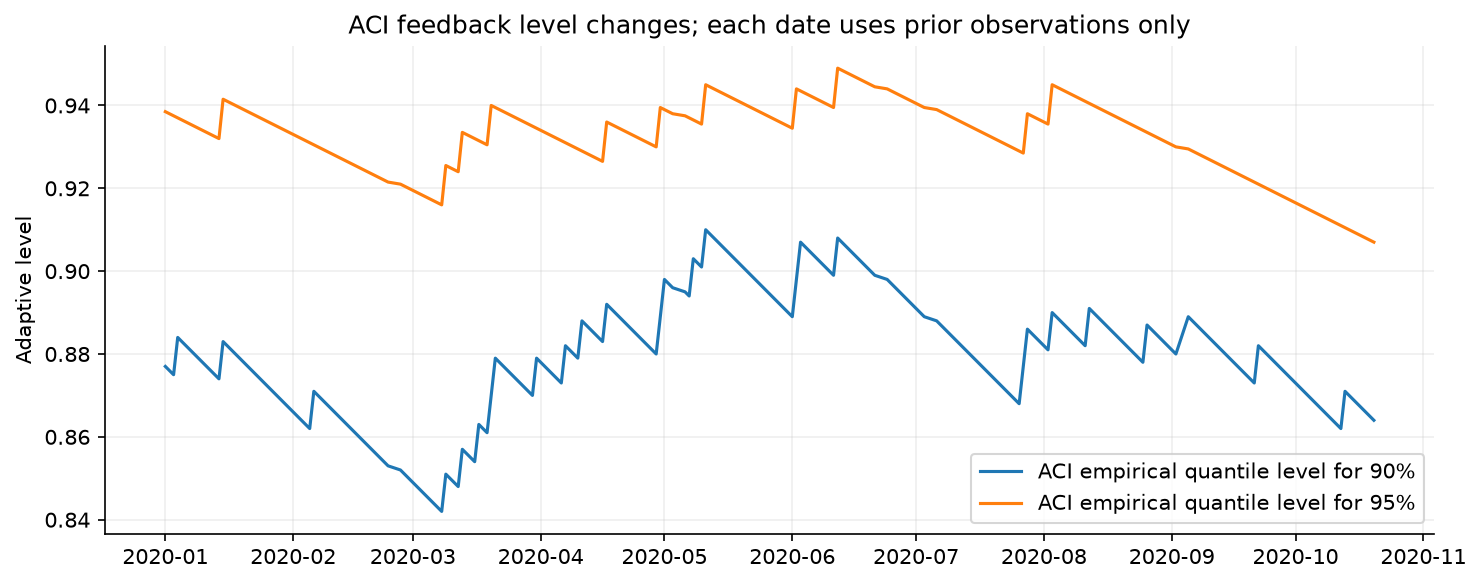

In [164]:
aci=pd.read_csv(out/'publication_ACI_vs_180day_sensitivity.csv')
print('ACI feedback versus fixed-level online window:')
display(aci.round(5))
display(Image(filename=str(fig/'44_publication_ACI_adaptation.png'),width=900))

## 11. CoVaR: why tail inference from 12–21 events is fragile

This simulation uses **synthetic, standardized Student-t(5)** samples only. It is an illustration of estimation uncertainty, not an estimate of the actual BTC return-generating distribution.

,illustrative_stress_n,expected_order_stats_at_BTC_5pct,simulation_q05_5th_percentile,simulation_q05_median,simulation_q05_95th_percentile
0,12,0.60,-2.4190,-1.2239,-0.5529
1,13,0.65,-2.3680,-1.2372,-0.5591
2,21,1.05,-2.2488,-1.2902,-0.6954
3,54,2.70,-2.0180,-1.4490,-1.0340
4,72,3.60,-2.0080,-1.4767,-1.0698
5,100,5.00,-1.9648,-1.4946,-1.1404
6,200,10.00,-1.8521,-1.5291,-1.2605


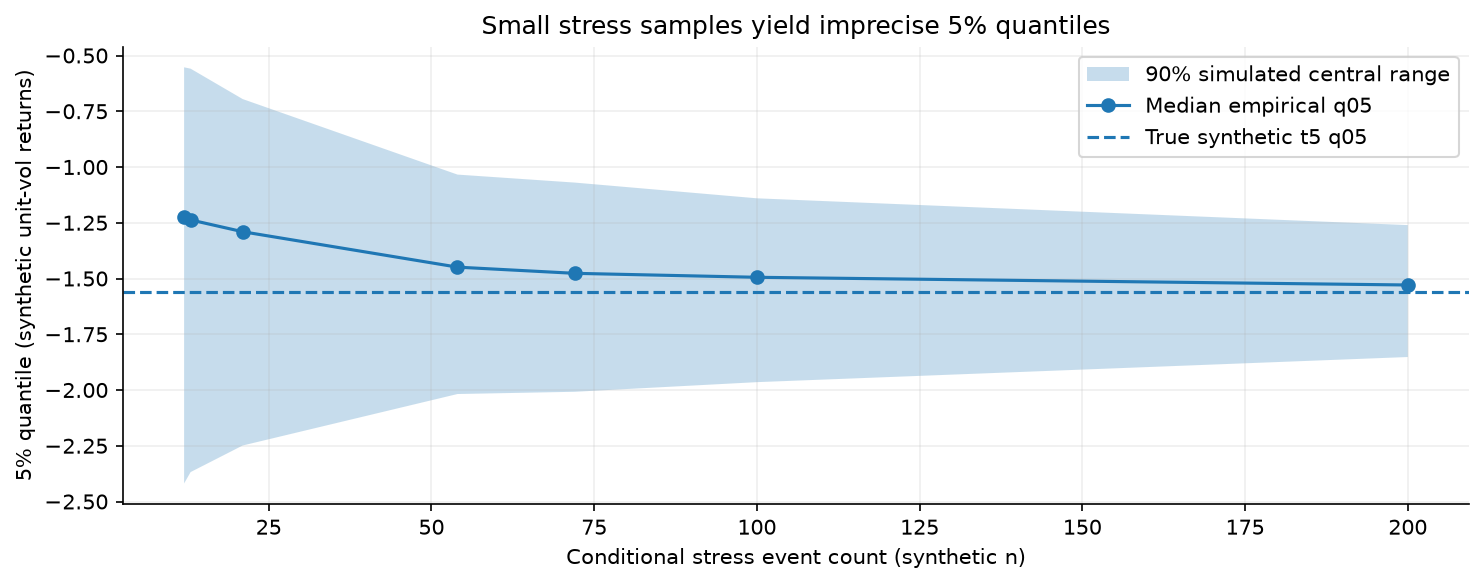

In [165]:
sim=pd.read_csv(out/'publication_synthetic_CoVaR_small_sample_uncertainty.csv')
display(sim[['illustrative_stress_n','expected_order_stats_at_BTC_5pct','simulation_q05_5th_percentile','simulation_q05_median','simulation_q05_95th_percentile']].round(4))
display(Image(filename=str(fig/'45_publication_CoVaR_sampling_uncertainty.png'),width=900))

## 12. Local failure of tail-risk models

Descriptive ES miss severity is not a formal ES backtest. March 2020 contains very few tail events, so exact calibration cannot be asserted from these tabulations.

,model,regime,n,breaches,breach_rate,observed_exceedance_mean_loss,predicted_ES_on_breach_days,mean_loss_minus_ES_breaches
9,GARCH-filtered EVT,all,284,11,0.0387,9.8294,7.6394,2.1900
12,GARCH-filtered EVT,March_2020,31,2,0.0645,27.9517,7.7725,20.1791
13,Gaussian GARCH,all,284,11,0.0387,9.8294,6.3452,3.4842
16,Gaussian GARCH,March_2020,31,2,0.0645,27.9517,6.4564,21.4953
17,Rolling POT,all,284,10,0.0352,10.9510,9.0987,1.8523
20,Rolling POT,March_2020,31,5,0.1613,15.1658,8.3969,6.7690


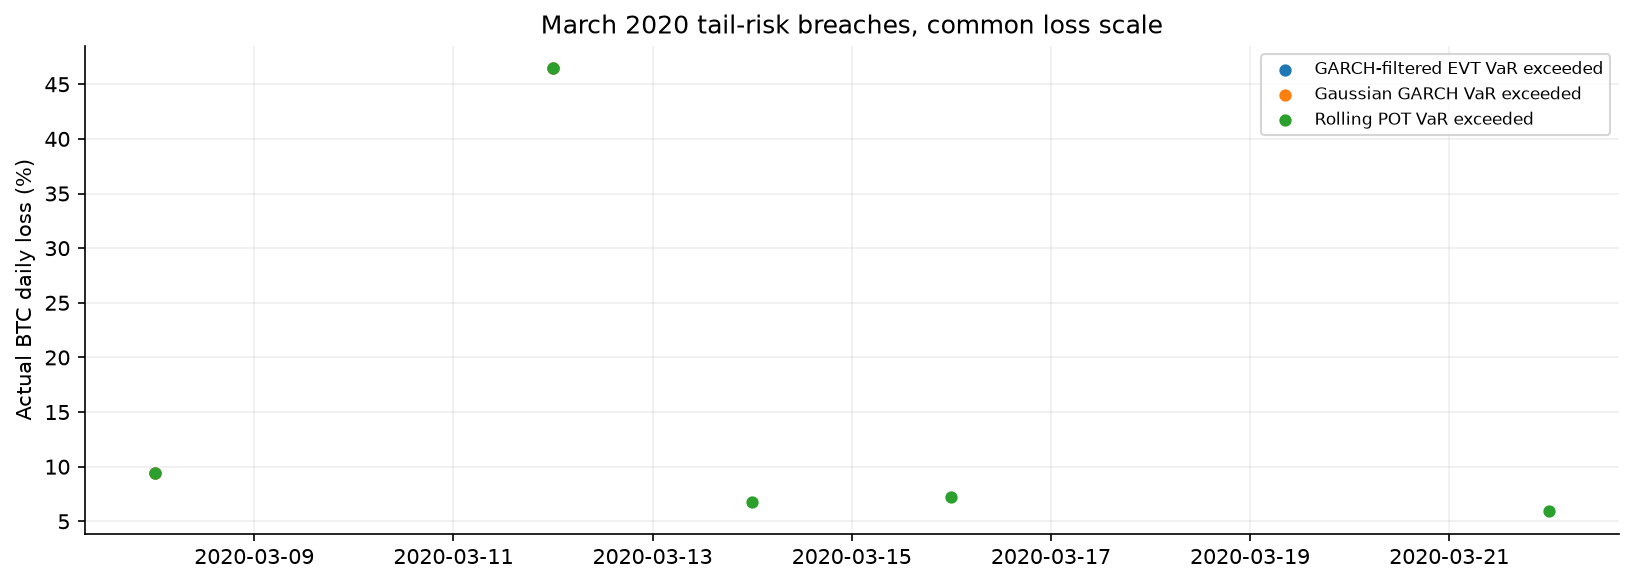

In [166]:
loss=pd.read_csv(out/'publication_tail_failure_regime_summary.csv')
display(loss.loc[(loss.year==2020)&(loss.regime.isin(['all','March_2020'])),['model','regime','n','breaches','breach_rate','observed_exceedance_mean_loss','predicted_ES_on_breach_days','mean_loss_minus_ES_breaches']].round(4))
display(Image(filename=str(fig/'46_publication_March_tail_exceptions.png'),width=900))

## 13. Frozen estimator and research-gate status

The frozen estimator is an actual serialized 2017-trained quantile HAR-X model, with its 180 historical residual observations (through 2020-10-20) saved for truly later forecasting. The 2020 period has already been inspected. No real 2021 onward external validation is asserted.

In [167]:
import json
pubtests=pd.read_csv(out/'publication_20_invariant_tests.csv')
assert pubtests.passed.astype(str).str.lower().eq('true').all()
meta=json.loads((frozen/'FROZEN_MODEL_PROTOCOL.json').read_text(encoding='utf-8'))
assert (frozen/'HARX_quantile_base_training_through_2017.joblib').exists()
print('Scientific invariant tests:',len(pubtests),'passed')
print('Model training end:',meta['training_end_date'],'| initial calibration through',meta['initial_calibration_end_date'])
print('Frozen online buffer date:',meta['residual_history_final_date'],'| future run strictly after',meta['valid_only_for_new_rows_after'])
print('External independent test completed: NO; 2021+ data not supplied')
print('Prepared future input columns:',meta['feature_columns'])

Scientific invariant tests: 20 passed
Model training end: 2017-12-31 | initial calibration through 2018-12-31
Frozen online buffer date: 2020-10-20 | future run strictly after 2020-10-20
External independent test completed: NO; 2021+ data not supplied
Prepared future input columns: ['lag1', 'avg7', 'avg30', 'BTC_abs_return_lag1', 'BTC_neg_return_lag1', 'BTC_log_volume_lag1', 'BTC_logvol_chg_lag1', 'lagged_7d_return_shock']


**Reading guide.** The original 148 Python model/audit code cells above are preserved. This integrated notebook includes the original Executive dashboard directly; no second notebook is required. The R studies are separate `.R` files run by this Python notebook only when enabled, and results remain exploratory unless actually executed.

## Release hardening: independently checked as-of-date input features and ACI controls

The exact frozen HAR-X training inputs have been reproduced from raw BTC OHLCV with **zero mismatches across 9 measures and 1,787 historical dates**. Gaps in the original crypto source mean six model rows have a 3-calendar-day prior eligible-row interval; this remains previsible but is not a 24-hour predictor. ACI's internal adaptation levels are audited for crossing and clipping. No new real 2021+ market data are supplied.

In [168]:

import json
from pathlib import Path
import pandas as pd
from IPython.display import display

if "out" not in globals():
    raise RuntimeError(
        "Part III initialization is missing. "
        "Run the first cell of Part III before this cell."
    )

out = Path(out).resolve()

run_info = {
    "run_id": out.parent.name
}

_hard_parity = pd.read_csv(
    out / "hardened_independent_asof_feature_parity.csv"
)

_hard_aci = pd.read_csv(
    out / "hardened_ACI_crisis_and_internal_levels.csv"
)

_hard_gaps = pd.read_csv(
    out / "hardened_frozen_HARX_variable_gap_lag_audit.csv"
)

_hard_modelrisk = json.loads(
    (
        out / "hardened_final_scientific_boundary.json"
    ).read_text(encoding="utf-8")
)

assert len(_hard_parity) == 9, (
    "Unexpected number of HAR-X parity measures."
)

assert _hard_parity["mismatch"].eq(0).all(), (
    "HAR-X feature parity check failed."
)

assert str(_hard_modelrisk["run_id"]) == run_info["run_id"], (
    "Research run ID mismatch. "
    "Outputs may belong to a different execution."
)

print("Research run:", run_info["run_id"])

print(
    "Feature parity:",
    len(_hard_parity),
    "measures x",
    int(_hard_parity["n"].min()),
    "dates, 0 mismatches"
)

print(
    "Historically irregular eligible-row lags:",
    int(_hard_gaps["not_a_fixed_24h_model_row"].sum())
)

print(
    "ACI internal target crossings:",
    int(_hard_modelrisk["ACI_internal_crossing_count"])
)

print(
    "ACI saturation instances:",
    int(_hard_modelrisk["ACI_clipping_count"])
)

print(
    "Real 2021+ independent test:",
    _hard_modelrisk["2021plus_actual_external_validation"]
)

aci_summary = _hard_aci.loc[
    _hard_aci["subset"].isin(["2020", "2020_March"]),
    [
        "subset",
        "q",
        "n",
        "exceptions",
        "exceedance_rate",
        "pinball",
        "internal_crossing_days",
    ]
].copy()

display(aci_summary.round(4))

def get_aci_exceedance(subset, quantile):
    matched = _hard_aci.loc[
        _hard_aci["subset"].eq(subset)
        & _hard_aci["q"].sub(quantile).abs().lt(1e-8),
        "exceedance_rate"
    ]

    if len(matched) != 1:
        raise ValueError(
            f"Expected one ACI result for {subset}, q={quantile}"
        )

    return float(matched.iloc[0])

_exec_claims = {
    "run_id": run_info["run_id"],

    "historical_parity_n": int(
        _hard_parity["n"].min()
    ),

    "historical_parity_errors": int(
        _hard_parity["mismatch"].sum()
    ),

    "irregular_eligible_lag_rows": int(
        _hard_gaps["not_a_fixed_24h_model_row"].sum()
    ),

    "aci_2020_q90_exceedance_rate": get_aci_exceedance(
        "2020", 0.90
    ),

    "aci_2020_q95_exceedance_rate": get_aci_exceedance(
        "2020", 0.95
    ),

    "aci_internal_target_crossings": int(
        _hard_modelrisk["ACI_internal_crossing_count"]
    ),

    "actual_2021plus_external_validation": "NOT PERFORMED",
}

print(
    "EXECUTIVE_SOURCE_METRICS="
    + json.dumps(_exec_claims, sort_keys=True)
)

print("\nRelease hardening verification PASSED.")


Research run: 20261026T030925_071513Z_ee4a01ed
Feature parity: 9 measures x 1787 dates, 0 mismatches
Historically irregular eligible-row lags: 6
ACI internal target crossings: 0
ACI saturation instances: 0
Real 2021+ independent test: NOT PERFORMED


,subset,q,n,exceptions,exceedance_rate,pinball,internal_crossing_days
4,2020,0.90,284,27,0.0951,4.9354,0
5,2020,0.95,284,11,0.0387,4.3852,0
6,2020_March,0.90,31,6,0.1935,30.6403,0
7,2020_March,0.95,31,3,0.0968,29.5479,0


EXECUTIVE_SOURCE_METRICS={"aci_2020_q90_exceedance_rate": 0.0950704225352112, "aci_2020_q95_exceedance_rate": 0.0387323943661971, "aci_internal_target_crossings": 0, "actual_2021plus_external_validation": "NOT PERFORMED", "historical_parity_errors": 0, "historical_parity_n": 1787, "irregular_eligible_lag_rows": 6, "run_id": "20261026T030925_071513Z_ee4a01ed"}

Release hardening verification PASSED.


## Part III-B — Targeted methodological robustness (new, retrospective)

The following supplements use actual output from the current Python run. They do **not** add unsupported 2021+ results or select a model based on 2020 to claim generalization. We distinguish **calendar-complete HAR-X refitting** from the original partially observed calendar features; report **previsible** ACI stress calibration and **descriptive** VaR/ES crisis severity. Quantile, variance and price targets remain separate.

,analysis,n_train_through_2018,n_development_2019,n_2020_common,2020_original_full_dates,excluded_2020_dates,Ridge_alpha_predeclared,2020_original_HARX_common_QLIKE,2020_strict_HARX_common_QLIKE,original_minus_strict_QLIKE_mean,block_CI_low,block_CI_high,zero_in_block_CI,interpretation
0,strict_prior_30_calendar_days_vs_original_HARX,1139,334,158,284,126,100.0,2.71211,2.7079,0.00421,0.00104,0.00804,False,"Retrospective sample-and-training sensitivity,..."


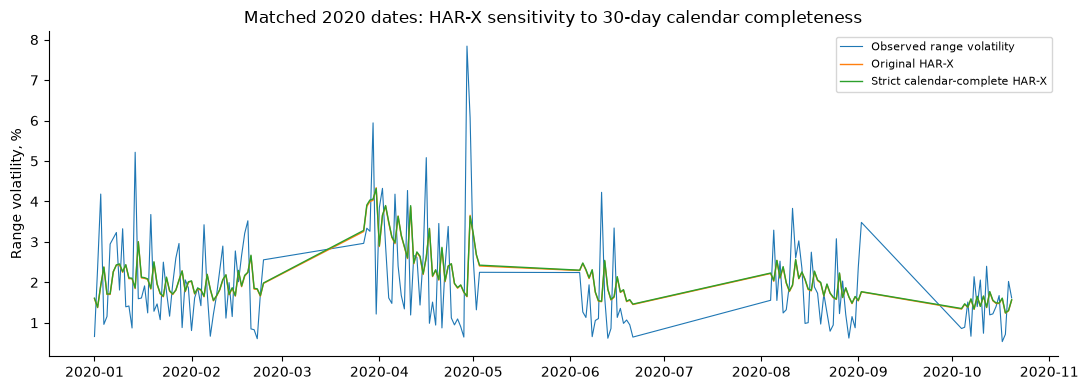

In [169]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

_cal_days = pd.date_range(START, END, freq="D")
_prior30_complete = pvar.reindex(_cal_days).notna().shift(1).rolling(30, min_periods=30).sum().eq(30)
_cal_hx = hx.loc[_prior30_complete.reindex(hx.index).fillna(False)].copy()
_cal_train = _cal_hx.loc[:TRAIN_END]
_cal_valid = _cal_hx.loc["2019"]
_cal_test = _cal_hx.loc["2020":END]
assert len(_cal_train)>500 and len(_cal_valid)>150 and len(_cal_test)>100
assert _cal_test.index.isin(hx_preds.index).all()
_cal_model = make_pipeline(StandardScaler(), Ridge(alpha=100.0))
_cal_fit = pd.concat([_cal_train, _cal_valid]).sort_index()
_cal_model.fit(hx_matrix(_cal_fit, hx_full_cols), np.log1p(_cal_fit.observed_parkinson))
_cal_pred = np.maximum(np.expm1(np.clip(_cal_model.predict(hx_matrix(_cal_test,hx_full_cols)),-15,15)),1e-8)
_cal_matched = pd.DataFrame({
 "date": _cal_test.index, "actual":_cal_test.observed_parkinson.to_numpy(),
 "calendar_complete_HARX":_cal_pred,
 "original_HARX":hx_preds.loc[_cal_test.index,"HAR-X shocks+volume"].to_numpy()
})
assert _cal_matched.date.is_unique and np.isfinite(_cal_matched.select_dtypes(include="number")).all().all()
for _name in ["calendar_complete_HARX", "original_HARX"]:
 _cal_matched[_name+"_QLIKE"] = np.log(_cal_matched[_name])+_cal_matched.actual/_cal_matched[_name]
_cal_delta=(_cal_matched["original_HARX_QLIKE"]-_cal_matched["calendar_complete_HARX_QLIKE"]).to_numpy()
_cal_ci=moving_block_ci(_cal_delta,block=10,reps=1200,seed=SEED+4001)
_cal_summary=pd.DataFrame([{
 "analysis":"strict_prior_30_calendar_days_vs_original_HARX", "n_train_through_2018":len(_cal_train),
 "n_development_2019":len(_cal_valid), "n_2020_common":len(_cal_test),
 "2020_original_full_dates":len(hx_preds),"excluded_2020_dates":len(hx_preds)-len(_cal_test),
 "Ridge_alpha_predeclared":100.0,
 "2020_original_HARX_common_QLIKE":float(_cal_matched["original_HARX_QLIKE"].mean()),
 "2020_strict_HARX_common_QLIKE":float(_cal_matched["calendar_complete_HARX_QLIKE"].mean()),
 "original_minus_strict_QLIKE_mean":float(_cal_delta.mean()),
 "block_CI_low":_cal_ci[0],"block_CI_high":_cal_ci[1],
 "zero_in_block_CI":bool(_cal_ci[0]<=0<=_cal_ci[1]),
 "interpretation":"Retrospective sample-and-training sensitivity, NOT an independent holdout comparison"
}])
_cal_matched.to_csv(OUT/"refined_calendar_safe_HARX_2020_daily.csv",index=False)
_cal_summary.to_csv(OUT/"refined_calendar_safe_HARX_summary.csv",index=False)
display(_cal_summary.round(5))
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(_cal_matched.date,np.sqrt(_cal_matched.actual.clip(lower=0)),label="Observed range volatility",lw=.8)
for _col,_label in [("original_HARX","Original HAR-X"),("calendar_complete_HARX","Strict calendar-complete HAR-X")]:
 ax.plot(_cal_matched.date,np.sqrt(_cal_matched[_col]),label=_label,lw=1.0)
ax.set(title="Matched 2020 dates: HAR-X sensitivity to 30-day calendar completeness",ylabel="Range volatility, %")
ax.legend(fontsize=8);savefig("47_refined_calendar_safe_HARX.png")

### Online quantile model: crisis calibration versus full-period calibration

Dates are restricted to the intersection of the *same* 180-observation rolling and ACI forecasts. The prior-day shock label is previsible. March and April partitions are descriptive ex-post stress diagnostics, not tuning datasets. A block-resampled paired Pinball difference is reported; no claim of independent forecasting gain is made.

,period,quantile,n,target_exception_rate,ACI_exception_count,ACI_exception_rate,rolling180_exception_count,rolling180_exception_rate,ACI_pinball,rolling180_pinball,rolling180_minus_ACI_pinball,paired_block_CI_low,paired_block_CI_high,posthoc_partition
0,2019_development,0.90,363,0.10,34,0.09366,33,0.09091,3.74997,3.69999,-0.04998,-0.17122,0.05540,True
1,2019_development,0.95,363,0.05,17,0.04683,16,0.04408,2.93461,2.78354,-0.15108,-0.34263,0.00573,True
2,2020_all,0.90,284,0.10,27,0.09507,23,0.08099,4.93541,4.92710,-0.00831,-0.18432,0.13289,True
3,2020_all,0.95,284,0.05,11,0.03873,9,0.03169,4.38523,4.40667,0.02144,-0.10582,0.12037,True
4,2020_March_crisis,0.90,31,0.10,6,0.19355,5,0.16129,30.64035,30.15551,-0.48483,-1.82105,0.58493,True
5,2020_March_crisis,0.95,31,0.05,3,0.09677,3,0.09677,29.54788,29.29751,-0.25037,-1.33926,0.59895,True
6,2020_April,0.90,30,0.10,5,0.16667,4,0.13333,3.28868,3.24939,-0.03929,-0.24089,0.14889,True
7,2020_April,0.95,30,0.05,2,0.06667,1,0.03333,2.43820,2.51886,0.08066,-0.04208,0.23262,True
8,2020_high_prior_shock,0.90,16,0.10,3,0.18750,2,0.12500,3.20651,4.41945,1.21294,-0.36569,2.79055,True
9,2020_high_prior_shock,0.95,16,0.05,0,0.00000,0,0.00000,3.33698,4.37593,1.03894,0.19991,1.87781,True


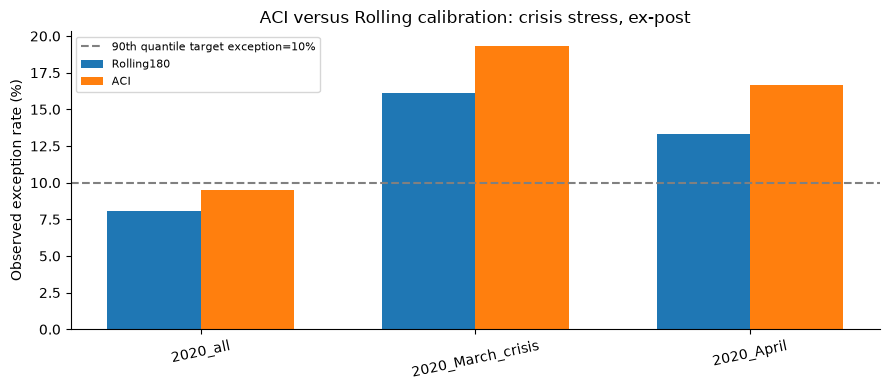

In [170]:
_regime_src=pd.read_csv(OUT/"publication_online_HARX_regime_daily.csv",parse_dates=["date"])
_regime_src=_regime_src.loc[_regime_src.window.eq(180),["date","past_shock_regime","prior_abs_BTC_return_pct"]]
_aci_reg=_aci_daily.merge(_online_daily.loc[_online_daily.window.eq(180),["date","pred_q90","pred_q95"]],on="date",validate="one_to_one")
_aci_reg=_aci_reg.merge(_regime_src,on="date",validate="one_to_one")
assert len(_aci_reg)==len(_aci_daily) and _aci_reg.date.is_unique
_aci_reg["calendar_period"]=np.select([
 _aci_reg.date.dt.year.eq(2019),
 _aci_reg.date.between("2020-03-01","2020-03-31"),
 _aci_reg.date.between("2020-04-01","2020-04-30"),
 _aci_reg.date.dt.year.eq(2020)],
 ["2019_development","2020_March_crisis","2020_April","2020_other"],default="other")
_aci_reg["high_prior_shock"]=_aci_reg.past_shock_regime.ne("normal_prior_BTC_shock")
def _q_loss(actual,upper,q):
 actual=np.asarray(actual,float);upper=np.asarray(upper,float)
 return np.maximum(q*(actual-upper),(1.-q)*(upper-actual))
_aci_diag=[]
for _label,_mask in [
 ("2019_development",_aci_reg.date.dt.year.eq(2019)),
 ("2020_all",_aci_reg.date.dt.year.eq(2020)),
 ("2020_March_crisis",_aci_reg.calendar_period.eq("2020_March_crisis")),
 ("2020_April",_aci_reg.calendar_period.eq("2020_April")),
 ("2020_high_prior_shock",_aci_reg.date.dt.year.eq(2020)&_aci_reg.high_prior_shock),
 ("2020_normal_prior_shock",_aci_reg.date.dt.year.eq(2020)&~_aci_reg.high_prior_shock)]:
 _part=_aci_reg.loc[_mask].sort_values("date")
 if len(_part)==0:continue
 for _q,_key,_ref in [(.90,"q90","pred_q90"),(.95,"q95","pred_q95")]:
  _yy=_part.actual_variance.to_numpy();_pa=_part[_key].to_numpy();_pr=_part[_ref].to_numpy()
  _diff=_q_loss(_yy,_pr,_q)-_q_loss(_yy,_pa,_q)
  _lo,_hi=moving_block_ci(_diff,block=min(10,len(_diff)),reps=800,seed=SEED+int(_q*100)+len(_diff)) if len(_diff)>=10 else (np.nan,np.nan)
  _aci_diag.append({"period":_label,"quantile":_q,"n":len(_part),"target_exception_rate":1-_q,
      "ACI_exception_count":int((_yy>_pa).sum()),"ACI_exception_rate":float(np.mean(_yy>_pa)),
      "rolling180_exception_count":int((_yy>_pr).sum()),"rolling180_exception_rate":float(np.mean(_yy>_pr)),
      "ACI_pinball":float(np.mean(_q_loss(_yy,_pa,_q))),
      "rolling180_pinball":float(np.mean(_q_loss(_yy,_pr,_q))),
      "rolling180_minus_ACI_pinball":float(np.mean(_diff)),
      "paired_block_CI_low":_lo,"paired_block_CI_high":_hi,"posthoc_partition":True})
_aci_diagnostics=pd.DataFrame(_aci_diag)
_aci_reg.to_csv(OUT/"refined_ACI_regime_matched_daily.csv",index=False)
_aci_diagnostics.to_csv(OUT/"refined_ACI_regime_crisis_summary.csv",index=False)
display(_aci_diagnostics.round(5))
fig,ax=plt.subplots(figsize=(9,4))
_q90s=_aci_diagnostics.loc[_aci_diagnostics["quantile"].eq(.90)&_aci_diagnostics.period.isin(["2020_all","2020_March_crisis","2020_April"])]
x=np.arange(len(_q90s));ax.bar(x-.17,100*_q90s.rolling180_exception_rate,width=.34,label="Rolling180")
ax.bar(x+.17,100*_q90s.ACI_exception_rate,width=.34,label="ACI")
ax.axhline(10,color="gray",ls="--",label="90th quantile target exception=10%")
ax.set_xticks(x,labels=_q90s.period,rotation=12)
ax.set(ylabel="Observed exception rate (%)",title="ACI versus Rolling calibration: crisis stress, ex-post")
ax.legend(fontsize=8);savefig("48_refined_ACI_crisis_vs_rolling.png")

### Tail event attribution on matched dates

A descriptive comparison of 5% VaR failures, **exceedance severity** and predicted ES across *the same* 2019–2020 dates. The realized-ES gap on exception dates is **not** an ES calibration test and must not be interpreted as a statistically significant failure without a separate formal test. The R ESR audit (if independently executed) remains a separate source.

,model,year,March_2020,n,exceptions,exception_rate,mean_VaR,mean_ES,mean_observed_loss_on_exceptions,mean_predicted_ES_on_exception_dates,mean_realized_minus_ES_on_exceptions,posthoc_partition,formal_ES_backtest
0,GARCH-filtered EVT,2019,False,363,15,0.04132,5.58247,8.97019,7.96362,8.58966,-0.62604,True,NOT inferred from severity
1,GARCH-filtered EVT,2020,False,253,9,0.03557,4.71237,7.35604,5.80228,7.60983,-1.80756,True,NOT inferred from severity
2,GARCH-filtered EVT,2020,True,31,2,0.06452,12.16802,18.81221,27.95168,7.77255,20.17914,True,NOT inferred from severity
3,Gaussian GARCH,2019,False,363,15,0.04132,5.67616,7.17536,7.96362,6.86910,1.09452,True,NOT inferred from severity
4,Gaussian GARCH,2020,False,253,9,0.03557,4.82761,6.10852,5.80228,6.32049,-0.51821,True,NOT inferred from severity
5,Gaussian GARCH,2020,True,31,2,0.06452,12.45764,15.67688,27.95168,6.45639,21.49529,True,NOT inferred from severity
6,Rolling POT,2019,False,363,9,0.02479,7.10793,10.04369,10.51802,10.12416,0.39386,True,NOT inferred from severity
7,Rolling POT,2020,False,253,5,0.01976,5.47742,9.24807,6.73617,9.80052,-3.06435,True,NOT inferred from severity
8,Rolling POT,2020,True,31,5,0.16129,5.54395,8.40842,15.16583,8.39687,6.76895,True,NOT inferred from severity


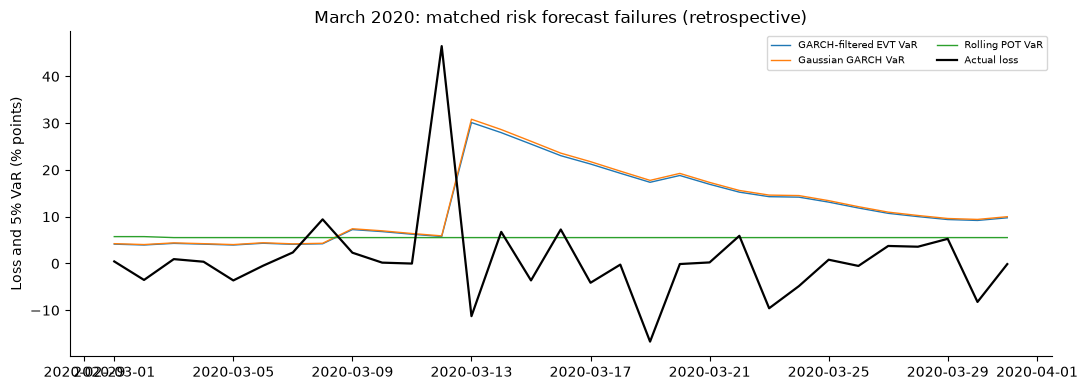

In [171]:
_risk=pd.read_csv(OUT/"extension_VaR_ES_FZ0_daily.csv",parse_dates=["date"])
assert _risk.groupby("model").date.nunique().nunique()==1 and not _risk.duplicated(["model","date"]).any()
_risk["March_2020"]=_risk.date.between("2020-03-01","2020-03-31")
_risk["exceedance_severity_pct"] = np.where(_risk.loss>_risk.VaR,_risk.loss-_risk.VaR,np.nan)
_risk["loss_minus_pred_ES_when_exception_pct"] = np.where(_risk.loss>_risk.VaR,_risk.loss-_risk.ES,np.nan)
_risk_cases=[]
for (_model,_year,_crisis),_d in _risk.groupby(["model","year","March_2020"]):
 if _year!=2020 and _crisis:continue
 _ex=_d.loc[_d.loss>_d.VaR]
 _risk_cases.append({"model":_model,"year":int(_year),"March_2020":bool(_crisis),"n":len(_d),
    "exceptions":len(_ex),"exception_rate":len(_ex)/len(_d),"mean_VaR":float(_d.VaR.mean()),
    "mean_ES":float(_d.ES.mean()),
    "mean_observed_loss_on_exceptions":float(_ex.loss.mean()) if len(_ex) else np.nan,
    "mean_predicted_ES_on_exception_dates":float(_ex.ES.mean()) if len(_ex) else np.nan,
    "mean_realized_minus_ES_on_exceptions":float((_ex.loss-_ex.ES).mean()) if len(_ex) else np.nan,
    "posthoc_partition":True,"formal_ES_backtest":"NOT inferred from severity"})
_risk_report=pd.DataFrame(_risk_cases)
_risk_report.to_csv(OUT/"refined_VaR_ES_march_and_other_regimes.csv",index=False)
_risk.loc[_risk.March_2020].sort_values(["date","model"]).to_csv(OUT/"refined_March_2020_risk_event_attribution.csv",index=False)
display(_risk_report.round(5))
fig,ax=plt.subplots(figsize=(11,4))
_plot=_risk.loc[_risk.March_2020]
for _m in sorted(_plot.model.unique()):
 _mrow=_plot.loc[_plot.model.eq(_m)].sort_values("date")
 ax.plot(_mrow.date,_mrow.VaR,label=_m+" VaR",lw=1)
ax.plot(_mrow.date.drop_duplicates(),_plot.drop_duplicates("date").sort_values("date").loss,color="black",lw=1.6,label="Actual loss")
ax.set(ylabel="Loss and 5% VaR (% points)",title="March 2020: matched risk forecast failures (retrospective)")
ax.legend(fontsize=7,ncol=2);savefig("49_refined_VaR_ES_crisis_events.png")

## Part III-C — Full-calendar predictive robustness and empirical tail risk (retrospective)

**Protocol.** The 2015–2018 sample fits alternatives; 2019 is development; the repeatedly inspected 2020 sample is descriptive, **not** an independent test. The same-date comparators share observed outcomes. All new daily features use **t−1 or earlier**; data gaps stay flagged rather than being silently interpreted as 24-hour observations. The original strict-completeness 158-day experiment is retained separately. We also add ex-ante FHS VaR/ES and a post-event ACI recovery diagnostic; no forward-return predictors, new raw data, or causal claims are introduced.

### 1. Full-coverage, calendar-indexed HAR-X (284 matched dates)

Create lagged features **before** restricting to observed target dates, using daily-grid rolling windows and past-only missingness flags. Missing past returns are replaced with a neutral numeric feature value plus an explicit missing indicator; missing daily range-variance is averaged over **available prior days**. Train through 2018; choose ridge penalty using 2019 only; refit through 2019; compare on **all 284 original 2020 evaluation dates** and on the strict 158-day subset, separately. This deliberately changes feature engineering and should be read as a retrospective sensitivity experiment, not a clean isolated treatment effect.

Full-date HAR-X: 284 common observed outcomes; all features t-1 or older


,sample,n,selected_2019_alpha,original_QLIKE,calendar_QLIKE,original_minus_calendar_QLIKE,block_CI_low,block_CI_high,posthoc_2020,interpretation
0,all_original_2020_dates,284,100.0,3.41160,3.67643,-0.26483,-0.50896,-0.08631,True,Retrospective; 2019 penalty selection; feature...
1,prior30_complete,158,100.0,2.71211,2.71533,-0.00322,-0.00785,0.00061,True,Retrospective; 2019 penalty selection; feature...
2,prior30_incomplete,126,100.0,4.28873,4.88163,-0.59289,-1.08957,-0.21020,True,Retrospective; 2019 penalty selection; feature...


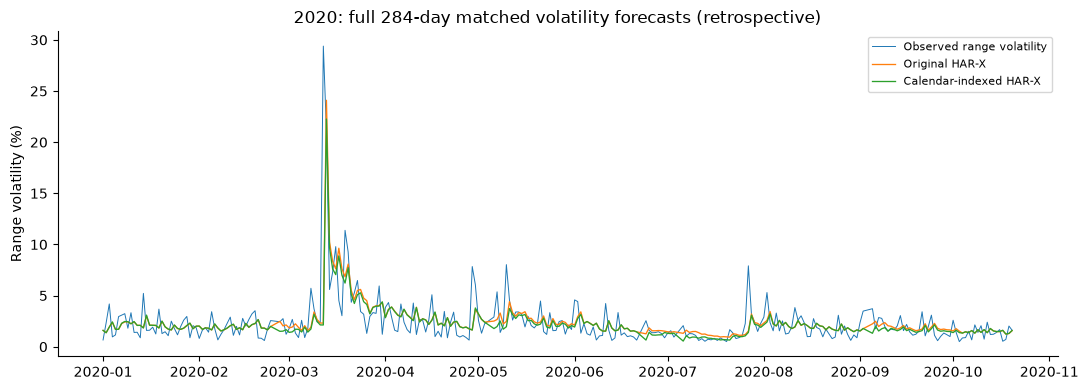

In [172]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

_u_calendar = pd.date_range(START, END, freq="D")
_u_close = crypto.set_index("date")["BTC"].reindex(_u_calendar)
_u_volume = crypto.set_index("date")["BTC_Volume"].reindex(_u_calendar)
_u_pvar = pvar.reindex(_u_calendar)
_u_ret = 100 * np.log(_u_close / _u_close.shift(1))
_u_logvol = np.log1p(_u_volume.clip(lower=0))
_u_f = pd.DataFrame(index=_u_calendar)
_u_f["lag1"] = _u_pvar.shift(1).ffill()
_u_f["avg7"] = _u_pvar.shift(1).rolling(7, min_periods=1).mean()
_u_f["avg30"] = _u_pvar.shift(1).rolling(30, min_periods=1).mean()
_u_f["BTC_abs_return_lag1"] = _u_ret.abs().shift(1).fillna(0.)
_u_f["BTC_neg_return_lag1"] = (-_u_ret).clip(lower=0).shift(1).fillna(0.)
_u_f["BTC_log_volume_lag1"] = _u_logvol.shift(1).ffill()
_u_f["BTC_logvol_chg_lag1"] = _u_logvol.diff().shift(1).fillna(0.)
_u_f["lagged_7d_return_shock"] = _u_ret.abs().shift(1).rolling(7, min_periods=1).mean().fillna(0.)
_u_f["missing_pvar_prior_7d"] = _u_pvar.isna().astype(int).shift(1).rolling(7, min_periods=1).sum()
_u_f["missing_pvar_prior_30d"] = _u_pvar.isna().astype(int).shift(1).rolling(30, min_periods=1).sum()
_u_f["return_t_minus_1_missing"] = _u_ret.shift(1).isna().astype(int)
_u_f["volume_t_minus_1_missing"] = _u_logvol.shift(1).isna().astype(int)
_u_f["observed_parkinson"] = _u_pvar
_u_cols = hx_full_cols + ["missing_pvar_prior_7d", "missing_pvar_prior_30d", "return_t_minus_1_missing", "volume_t_minus_1_missing"]
_u_rows = _u_f.loc[_u_f["observed_parkinson"].notna(), ["observed_parkinson"] + _u_cols].replace([np.inf,-np.inf], np.nan).dropna()
_u_train = _u_rows.loc[:TRAIN_END]
_u_val = _u_rows.loc["2019"]
_u_2020 = _u_rows.reindex(hx_preds.index)
assert len(_u_train)>500 and len(_u_val)>200 and len(_u_2020)==len(hx_preds)==284
assert _u_2020.notna().all().all(), "No missing target-date feature is allowed in full-coverage evaluation"
assert np.allclose(_u_2020.observed_parkinson, hx_preds.observed_parkinson)

def _u_matrix(f):
    t = f[_u_cols].copy()
    for col in hx_base_cols:
        t[col] = np.log1p(t[col].clip(lower=0))
    return t

def _u_qlike(actual, variance):
    h = np.maximum(np.asarray(variance,float),1e-8)
    y = np.asarray(actual,float)
    return np.log(h) + y/h

_u_grid=[]
for _alpha in [1.,10.,100.]:
    _candidate = make_pipeline(StandardScaler(),Ridge(alpha=_alpha))
    _candidate.fit(_u_matrix(_u_train),np.log1p(_u_train.observed_parkinson))
    _p = np.maximum(np.expm1(np.clip(_candidate.predict(_u_matrix(_u_val)),-15,15)),1e-8)
    _u_grid.append({"alpha":_alpha,"2019_QLIKE":float(_u_qlike(_u_val.observed_parkinson,_p).mean())})
_u_grid = pd.DataFrame(_u_grid).sort_values(["2019_QLIKE","alpha"])
_u_alpha=float(_u_grid.iloc[0]["alpha"])
_u_fit = pd.concat([_u_train,_u_val])
_u_model = make_pipeline(StandardScaler(),Ridge(alpha=_u_alpha))
_u_model.fit(_u_matrix(_u_fit),np.log1p(_u_fit.observed_parkinson))
_u_cap=max(float(_u_fit.observed_parkinson.quantile(.999)*5),20.)
_u_predictions=np.clip(np.expm1(np.clip(_u_model.predict(_u_matrix(_u_2020)),-15,15)),1e-8,_u_cap)
_u_matched=pd.DataFrame({"date":hx_preds.index,"observed":_u_2020.observed_parkinson.to_numpy(),
  "calendar_imputed_HARX":_u_predictions,"original_HARX":hx_preds["HAR-X shocks+volume"].to_numpy(),
  "had_missing_prior30":_u_2020.missing_pvar_prior_30d.to_numpy()>0})
_u_matched["original_QLIKE"]=_u_qlike(_u_matched.observed,_u_matched.original_HARX)
_u_matched["calendar_QLIKE"]=_u_qlike(_u_matched.observed,_u_matched.calendar_imputed_HARX)
_u_matched["original_minus_calendar_QLIKE"]=_u_matched.original_QLIKE-_u_matched.calendar_QLIKE
_u_full_report=[]
for _stratum,_slice in [("all_original_2020_dates",_u_matched),
                        ("prior30_complete",_u_matched.loc[~_u_matched.had_missing_prior30]),
                        ("prior30_incomplete",_u_matched.loc[_u_matched.had_missing_prior30])]:
    if len(_slice)==0: continue
    _diff=_slice["original_minus_calendar_QLIKE"].to_numpy()
    _ci=moving_block_ci(_diff,block=min(10,len(_diff)),reps=1000,seed=SEED+8001+len(_diff)) if len(_diff)>=10 else (np.nan,np.nan)
    _u_full_report.append({"sample":_stratum,"n":len(_slice),"selected_2019_alpha":_u_alpha,
      "original_QLIKE":float(_slice.original_QLIKE.mean()),"calendar_QLIKE":float(_slice.calendar_QLIKE.mean()),
      "original_minus_calendar_QLIKE":float(_diff.mean()),"block_CI_low":_ci[0],"block_CI_high":_ci[1],
      "posthoc_2020":True,"interpretation":"Retrospective; 2019 penalty selection; features/missingness and training differ"})
_u_full_summary=pd.DataFrame(_u_full_report)
_u_matched.to_csv(OUT/"ultimate_full284_calendar_HARX_daily.csv",index=False)
_u_full_summary.to_csv(OUT/"ultimate_full284_calendar_HARX_summary.csv",index=False)
_u_grid.to_csv(OUT/"ultimate_full284_calendar_HARX_2019_selection.csv",index=False)
assert _u_full_summary.loc[0,"n"]==284
print("Full-date HAR-X: 284 common observed outcomes; all features t-1 or older")
display(_u_full_summary.round(5))
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(_u_matched.date,np.sqrt(_u_matched.observed.clip(lower=0)),label="Observed range volatility",lw=.7)
ax.plot(_u_matched.date,np.sqrt(_u_matched.original_HARX),label="Original HAR-X",lw=.95)
ax.plot(_u_matched.date,np.sqrt(_u_matched.calendar_imputed_HARX),label="Calendar-indexed HAR-X",lw=.95)
ax.set(title="2020: full 284-day matched volatility forecasts (retrospective)",ylabel="Range volatility (%)")
ax.legend(fontsize=8);savefig("50_ultimate_full_284_calendar_HARX.png")

### 2. ACI shock-response and recovery diagnostics

Freeze the shock threshold from pre-2019 BTC return history; index shock events only with the **previous-day return**. Report observed exceedance rates over the next 1/3/7/14 eligible forecast dates for adaptive and nonadaptive quantile forecasts. These windows overlap and are **ex-post outcome summaries**, not independent trials or a real-time signal of future recovery. No causal inference or formal recovery-time theorem is claimed.

Pre-2019 95th-percentile prior-day BTC shock threshold (%): 9.1021
Eligible 2020 shock-origin dates: 8


,quantile,n_forward_observed_days,n_events,ACI_exceedance_rate,rolling_exceedance_rate
0,0.90,1,8,0.2500,0.1250
1,0.90,3,8,0.1250,0.0833
2,0.90,7,8,0.1964,0.1607
3,0.90,14,8,0.1607,0.1161
4,0.95,1,8,0.0000,0.0000
5,0.95,3,8,0.0000,0.0000
6,0.95,7,8,0.0714,0.0536
7,0.95,14,8,0.0536,0.0446


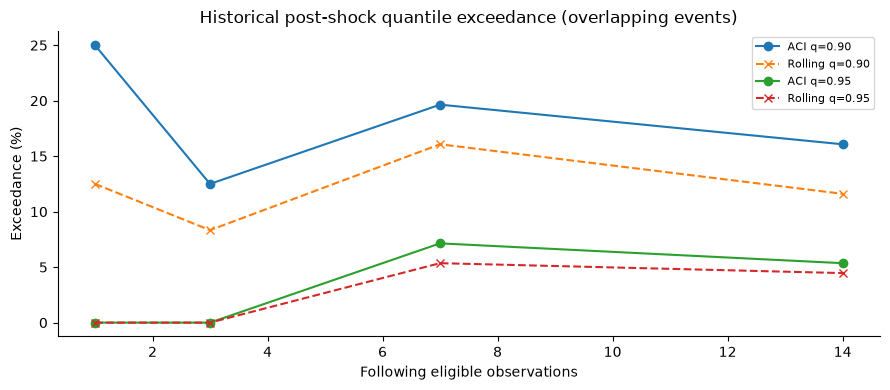

In [173]:
_u_training_absret=(log_returns_daily.BTC.loc[:TRAIN_END].abs()*100).dropna()
_u_shock_threshold=float(_u_training_absret.quantile(.95))
_u_acid=_aci_reg.sort_values("date").loc[_aci_reg.date.dt.year.eq(2020)].reset_index(drop=True).copy()
_u_acid["prior_shock_event"]=_u_acid.prior_abs_BTC_return_pct.ge(_u_shock_threshold)
_u_horizons=[1,3,7,14]
_u_event_rows=[]
for _i in np.flatnonzero(_u_acid.prior_shock_event.to_numpy()):
    for _h in _u_horizons:
        _s=_u_acid.iloc[_i:min(_i+_h,len(_u_acid))]
        if len(_s)!=_h:continue
        for _q,_aci_col,_roll_col in [(.90,"q90","pred_q90"),(.95,"q95","pred_q95")]:
            _miss_aci=(_s.actual_variance>_s[_aci_col]).astype(float)
            _miss_roll=(_s.actual_variance>_s[_roll_col]).astype(float)
            _u_event_rows.append({"event_date":_u_acid.iloc[_i].date,"quantile":_q,"n_forward_observed_days":_h,
               "prior_day_abs_return_pct":float(_u_acid.iloc[_i].prior_abs_BTC_return_pct),
               "ACI_next_window_exception_rate":float(_miss_aci.mean()),
               "rolling_next_window_exception_rate":float(_miss_roll.mean()),
               "nominal_exception_rate":1-_q,"overlapping_events":True,"retrospective":True})
_u_events=pd.DataFrame(_u_event_rows)
_u_aci_recovery=(_u_events.groupby(["quantile","n_forward_observed_days"],as_index=False)
  .agg(n_events=("event_date","nunique"),ACI_exceedance_rate=("ACI_next_window_exception_rate","mean"),
       rolling_exceedance_rate=("rolling_next_window_exception_rate","mean"))) if len(_u_events) else pd.DataFrame()
_u_acid[["date","prior_abs_BTC_return_pct","prior_shock_event","actual_variance","q90","q95","pred_q90","pred_q95"]].to_csv(
    OUT/"ultimate_ACI_2020_shock_marked_daily.csv",index=False)
_u_events.to_csv(OUT/"ultimate_ACI_shock_event_windows.csv",index=False)
_u_aci_recovery.to_csv(OUT/"ultimate_ACI_shock_recovery_summary.csv",index=False)
print("Pre-2019 95th-percentile prior-day BTC shock threshold (%):",round(_u_shock_threshold,4))
print("Eligible 2020 shock-origin dates:",int(_u_acid.prior_shock_event.sum()))
if len(_u_aci_recovery):
    display(_u_aci_recovery.round(4))
    fig,ax=plt.subplots(figsize=(9,4))
    for _q in [.90,.95]:
        _z=_u_aci_recovery.loc[_u_aci_recovery["quantile"].eq(_q)]
        ax.plot(_z.n_forward_observed_days,100*_z.ACI_exceedance_rate,marker="o",label=f"ACI q={_q:.2f}")
        ax.plot(_z.n_forward_observed_days,100*_z.rolling_exceedance_rate,marker="x",ls="--",label=f"Rolling q={_q:.2f}")
    ax.set(title="Historical post-shock quantile exceedance (overlapping events)",xlabel="Following eligible observations",ylabel="Exceedance (%)")
    ax.legend(fontsize=8);savefig("51_ultimate_ACI_shock_event_response.png")
else:
    print("No complete post-event windows met the predeclared shock threshold.")

### 3. GARCH-filtered historical simulation (FHS): new VaR/ES comparison

For 2019 and 2020 separately, fit the **same past-year GARCH(QMLE)** on observations ending 2018 and 2019, respectively. Compute standardized historical negative innovations through the corresponding fit cutoff only. Freeze their empirical 95th percentile and conditional tail mean for the evaluation year; multiply by the **one-step, past-return-updated conditional sigma**. Score the resulting positive-loss 5% VaR/ES beside Gaussian GARCH, filtered EVT and POT on identical date/outcome rows using FZ0 and exception rates. Uncertainty is shown with paired moving-block intervals. The 2020 comparison remains retrospective, not evidence of independent prospective skill.

,year,model,n,exceptions,mean_FZ0,mean_pinball95,mean_VaR,mean_ES,exception_rate
0,2019,GARCH-FHS,363,15,2.0241,0.3968,5.6173,8.9819,0.0413
1,2019,GARCH-filtered EVT,363,15,2.0233,0.3965,5.5825,8.9702,0.0413
2,2019,Gaussian GARCH,363,15,2.0261,0.3974,5.6762,7.1754,0.0413
3,2019,Rolling POT,363,9,2.1766,0.4480,7.1079,10.0437,0.0248
4,2020,GARCH-FHS,284,11,2.1477,0.4791,5.5624,8.6330,0.0387
5,2020,GARCH-filtered EVT,284,11,2.1470,0.4785,5.5262,8.6065,0.0387
6,2020,Gaussian GARCH,284,11,2.1887,0.4806,5.6605,7.1530,0.0387
7,2020,Rolling POT,284,10,2.2569,0.4746,5.4847,9.1564,0.0352


,year,comparator,n,comparator_minus_FHS_mean_FZ0,block_CI_low,block_CI_high,zero_in_CI,external_prospective
0,2019,Gaussian GARCH,363,0.00198,-0.03766,0.05816,True,False
1,2019,GARCH-filtered EVT,363,-0.00081,-0.00239,0.00104,True,False
2,2019,Rolling POT,363,0.15248,-0.02999,0.31175,True,False
3,2020,Gaussian GARCH,284,0.04100,-0.03996,0.19324,True,False
4,2020,GARCH-filtered EVT,284,-0.00067,-0.00339,0.00314,True,False
5,2020,Rolling POT,284,0.10919,0.00726,0.20773,False,False


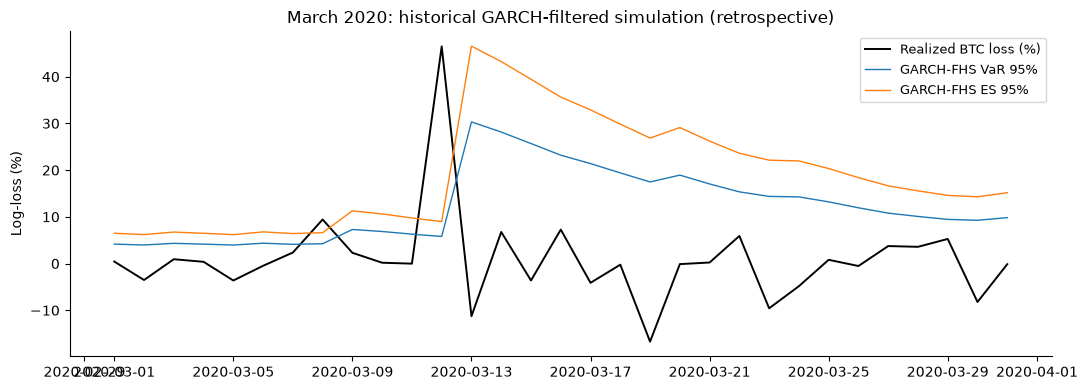

In [174]:
_u_fhs_records=[]
_u_fhs_fits=[]
for _year,_cutoff in [(2019,TRAIN_END),(2020,VALID_END)]:
    _rs=vol_s.to_numpy(dtype=float)
    _fit_r=vol_s.loc[:_cutoff].to_numpy(dtype=float)
    _param=fit_garch_qmle(_fit_r)
    _var=garch_variance_path((_rs-_param["mu"])**2,_param["omega"],_param["alpha"],_param["beta"],_param["initial_variance"])
    _std_loss=-( _rs-_param["mu"])/np.sqrt(np.maximum(_var,1e-9))
    _train_std=_std_loss[vol_s.index<=_cutoff]
    _empq=float(np.quantile(_train_std,.95))
    _tail=_train_std[_train_std>=_empq]
    assert len(_tail)>=30 and np.all(np.isfinite(_tail))
    _empes=float(np.mean(_tail))
    assert _empes>_empq>0
    _u_fhs_fits.append({"evaluate_year":_year,"fit_through":str(_cutoff.date()),
        "n_pre_year_innovations":len(_train_std),"tail_exceedances_training":len(_tail),
        "standardized_VaR95":_empq,"standardized_ES95":_empes,"optimizer_success":bool(_param["success"])})
    for _d,_actual,_v in zip(vol_s.index,_rs,_var):
        if _d.year!=_year:continue
        _sig=np.sqrt(max(float(_v),1e-9))
        _u_fhs_records.append({"date":_d,"year":_year,"model":"GARCH-FHS",
            "loss":float(-_actual),"VaR":float(-_param["mu"]+_sig*_empq),
            "ES":float(-_param["mu"]+_sig*_empes)})
_u_fhs=pd.DataFrame(_u_fhs_records)
_u_existing = _risk[["date","year","model","loss","VaR","ES"]].copy()
_u_existing["date"]=pd.to_datetime(_u_existing.date)
_u_existing_dates = _u_existing.loc[_u_existing.model.eq("Gaussian GARCH"),["date","loss"]]
_u_fhs = _u_fhs.merge(_u_existing_dates,on="date",how="inner",suffixes=("","_reference"),validate="one_to_one")
assert np.allclose(_u_fhs.loss,_u_fhs.loss_reference)
_u_fhs=_u_fhs.drop(columns="loss_reference")
_u_joint=pd.concat([_u_existing,_u_fhs],ignore_index=True)
_u_joint=_u_joint.loc[(_u_joint.ES>_u_joint.VaR)&(_u_joint.ES>0)&np.isfinite(_u_joint[["loss","VaR","ES"]]).all(axis=1)].copy()
_u_joint["exception"]=_u_joint.loss>_u_joint.VaR
_u_joint["FZ0_joint_loss"]=_u_joint["exception"]*((_u_joint.loss-_u_joint.VaR)/(.05*_u_joint.ES))+_u_joint.VaR/_u_joint.ES+np.log(_u_joint.ES)-1
_u_joint["pinball95"]=(.95-(_u_joint.loss<_u_joint.VaR).astype(float))*(_u_joint.loss-_u_joint.VaR)
_u_pivot=_u_joint.pivot(index="date",columns="model",values="FZ0_joint_loss").dropna()
assert len(_u_pivot)>400 and "GARCH-FHS" in _u_pivot.columns
_u_matched_joint=_u_joint.loc[_u_joint.date.isin(_u_pivot.index)].copy()
_u_fhs_summary=(_u_matched_joint.groupby(["year","model"],as_index=False).agg(
   n=("date","size"),exceptions=("exception","sum"),mean_FZ0=("FZ0_joint_loss","mean"),
   mean_pinball95=("pinball95","mean"),mean_VaR=("VaR","mean"),mean_ES=("ES","mean")))
_u_fhs_summary["exception_rate"]=_u_fhs_summary.exceptions/_u_fhs_summary.n
_u_fhs_ci=[]
for _year in [2019,2020]:
    _by=_u_pivot.loc[_u_pivot.index.year==_year]
    for _comparator in ["Gaussian GARCH","GARCH-filtered EVT","Rolling POT"]:
        if _comparator not in _by.columns:continue
        _diff=(_by[_comparator]-_by["GARCH-FHS"]).to_numpy()
        _ci=moving_block_ci(_diff,block=10,reps=1000,seed=SEED+9000+_year+len(_comparator))
        _u_fhs_ci.append({"year":_year,"comparator":_comparator,"n":len(_diff),
            "comparator_minus_FHS_mean_FZ0":float(_diff.mean()),"block_CI_low":_ci[0],"block_CI_high":_ci[1],
            "zero_in_CI":bool(_ci[0]<=0<=_ci[1]),"external_prospective":False})
_u_fhs_tests=pd.DataFrame(_u_fhs_ci)
pd.DataFrame(_u_fhs_fits).to_csv(OUT/"ultimate_FHS_preyear_parameters.csv",index=False)
_u_fhs.to_csv(OUT/"ultimate_FHS_daily_forecasts.csv",index=False)
_u_matched_joint.to_csv(OUT/"ultimate_FHS_matched_4model_daily.csv",index=False)
_u_fhs_summary.to_csv(OUT/"ultimate_FHS_matched_summary.csv",index=False)
_u_fhs_tests.to_csv(OUT/"ultimate_FHS_paired_block_uncertainty.csv",index=False)
display(_u_fhs_summary.round(4),_u_fhs_tests.round(5))
fig,ax=plt.subplots(figsize=(11,4))
_u_crisis=_u_fhs.loc[_u_fhs.date.between("2020-03-01","2020-03-31")].sort_values("date")
ax.plot(_u_crisis.date,_u_crisis.loss,lw=1.4,color="black",label="Realized BTC loss (%)")
ax.plot(_u_crisis.date,_u_crisis.VaR,lw=1,label="GARCH-FHS VaR 95%")
ax.plot(_u_crisis.date,_u_crisis.ES,lw=1,label="GARCH-FHS ES 95%")
ax.set(title="March 2020: historical GARCH-filtered simulation (retrospective)",ylabel="Log-loss (%)")
ax.legend(fontsize=9);savefig("52_ultimate_FHS_March_tail_risk.png")

### 4. Added research-gate checks

These integrity checks require every new daily prediction to have a unique observed date, verify that FHS contains no post-cutoff empirical innovations, and preserve **R not executed / partially executed** states. Passing them establishes code/data consistency, **not** statistical dominance or real 2021+ validation.

In [175]:
_u_required=["ultimate_full284_calendar_HARX_daily.csv","ultimate_full284_calendar_HARX_summary.csv",
 "ultimate_ACI_shock_event_windows.csv","ultimate_ACI_shock_recovery_summary.csv",
 "ultimate_FHS_preyear_parameters.csv","ultimate_FHS_daily_forecasts.csv",
 "ultimate_FHS_matched_4model_daily.csv","ultimate_FHS_matched_summary.csv","ultimate_FHS_paired_block_uncertainty.csv"]
assert all((OUT/_p).is_file() for _p in _u_required)
assert len(_u_matched)==len(hx_preds)==284 and _u_matched.date.is_unique
assert _u_fhs.groupby("date").size().eq(1).all()
assert _u_fhs_fits[0]["fit_through"]==str(TRAIN_END.date())
assert _u_fhs_fits[1]["fit_through"]==str(VALID_END.date())
assert len(_u_fhs_summary)==8, "Expected 2 years x 4 matched risk models"
assert _u_fhs_summary.groupby("year").n.nunique().eq(1).all(), "Risk scores use unmatched dates"
assert all(_u_fhs.ES>_u_fhs.VaR)
assert _exec_claims["actual_2021plus_external_validation"]=="NOT PERFORMED"
_u_validation = {"research_run":str(RUN_ID),"full_2020_HARX_matched_dates":len(_u_matched),
    "ACI_historical_shock_origins_2020":int(_u_acid.prior_shock_event.sum()),
    "FHS_matched_risk_models":int(_u_matched_joint.model.nunique()),
    "FHS_risk_forecasts":int(len(_u_fhs)),"R_verified_in_this_section":False,
    "external_2021plus":"NOT PERFORMED","retrospective_2020":True,"integrity":"PASS"}
(OUT/"ultimate_experiment_validation.json").write_text(json.dumps(_u_validation,indent=2),encoding="utf-8")
print("ULTIMATE_ADDITIONAL_EXPERIMENT_GATE:",json.dumps(_u_validation,sort_keys=True))

ULTIMATE_ADDITIONAL_EXPERIMENT_GATE: {"ACI_historical_shock_origins_2020": 8, "FHS_matched_risk_models": 4, "FHS_risk_forecasts": 647, "R_verified_in_this_section": false, "external_2021plus": "NOT PERFORMED", "full_2020_HARX_matched_dates": 284, "integrity": "PASS", "research_run": "20261026T030925_071513Z_ee4a01ed", "retrospective_2020": true}


## Part IV — R econometric extension (optional, same notebook)

R studies use the actual source CSVs and Python risk predictions from the historical sample. The separate `Rscript` interpreter runs **only** with `BITCOIN_RUN_R=1`. Results from previous terminal runs are not presented as current-run evidence unless their run ID and source hashes match.

| Script | Research question | Status before execution |
|---|---|---|
| `01_structural_breaks.R` | Bai–Perron retrospective structural breaks | Requires R |
| `02_tvpvar_connectedness.R` | TVP-VAR dynamic variance-decomposition connectedness | Requires R |
| `03_es_regression_backtests.R` | Regression-based ES validation of Python VaR/ES estimates | Requires R |
| `04_garch_crosslanguage.R` | Python–R GARCH parameter sensitivity, with S4-safe methods | Requires R |
| `05_qvar_connectedness.R` | Tail (5%), median (50%), upper-tail (95%) QVAR connectedness | Requires R |

Statistical caveat: changing fitted parameters or detecting retrospective breaks is not causal identification or proof of independent forecast accuracy. The provided 2019–2020 evaluations are development-inspected.

#### R runner ordering check
The standalone GARCH helper and trace wrapper are created in this current run **before** R execution. Pass `BITCOIN_R_GARCH_S4_HELPER` to the R process; editing the external source script is a separate, documented step.


#### Run-scoped R GARCH diagnostics prepared **before** executing R
The real R script remains external. These files improve traceability but cannot independently repair an unidentified S4 `$` error.


In [176]:
# Create reproducible R diagnostic support before invoking any external R process.
# This is a diagnostic integration point, not a substitute for fixing an unknown R script.
_R_GARCH_HELPER_PATH=OUT/'R_GARCH_S4_SAFE_EXTRACTION.R'
_R_GARCH_HELPER_TEXT="# rugarch S4 audit: source before extracting objects in 04_garch_crosslanguage.R.\nsafe_rugarch_extract <- function(fit, diagnostic_file=NULL) {\n  log <- character(0)\n  add <- function(...) {log <<- c(log, paste(...,collapse=' '))}\n  add('class:',paste(class(fit),collapse=','),'isS4:',isS4(fit))\n  if(isS4(fit))add('slots:',paste(methods::slotNames(fit),collapse=','))\n  grab <- function(label,fun)tryCatch({v<-fun();add(label,'OK',paste(class(v),collapse=','));v},\n    error=function(e){add(label,'ERROR',conditionMessage(e));NULL})\n  x <- list(\n    coefficients=grab('coef',function()stats::coef(fit)),\n    sigma=grab('sigma',function()rugarch::sigma(fit)),\n    residuals=grab('residuals',function()stats::residuals(fit)),\n    convergence=grab('convergence',function() {\n      # Inspect the actual S4 object first. The convergence value in a uGARCHfit\n      # is commonly within the list stored in the fit slot; avoid blind '$'.\n      if(isS4(fit) && 'fit' %in% methods::slotNames(fit)) {\n        inner<-methods::slot(fit,'fit')\n        if(is.list(inner) && 'convergence' %in% names(inner))return(inner[['convergence']])\n      }\n      f<-tryCatch(getExportedValue('rugarch','convergence'),error=function(e)NULL)\n      if(!is.null(f))return(f(fit))\n      stop('No verified convergence field or public method for this fitted object')\n    }))\n  if(!is.null(diagnostic_file))writeLines(log,diagnostic_file)\n  print(log)\n  if(any(vapply(x,is.null,logical(1))))stop('Incomplete S4 extraction; consult method logs')\n  x\n}\n"
_R_GARCH_HELPER_PATH.write_text(_R_GARCH_HELPER_TEXT,encoding='utf-8')
_R_DIAG_WRAPPER=OUT/'R_GARCH_TRACE_WRAPPER.R'
_R_DIAG_WRAPPER.write_text(r"""
args <- commandArgs(trailingOnly=TRUE)
if(length(args)<2) stop('Usage: Rscript wrapper.R original_script.R diagnostic_log.txt')
original <- normalizePath(args[[1]],mustWork=TRUE)
log_file <- args[[2]]
sink(log_file,split=TRUE)
options(error=function(){traceback(30);quit(status=1)})
cat('Diagnostic target:',original,'\\n')
cat('R version:',R.version.string,'\\n')
cat('Working directory:',getwd(),'\\n')
source(original,local=globalenv(),echo=FALSE)
sink()
""",encoding='utf-8')
print('Run-scoped R GARCH S4 diagnostic helper prepared:',_R_GARCH_HELPER_PATH)
print('External R script must source helper and call safe_rugarch_extract(fit, log) to use its methods.')


Run-scoped R GARCH S4 diagnostic helper prepared: I:\Dataset\Bitcoin Price Regression Analysis\runs\20261026T030925_071513Z_ee4a01ed\outputs\R_GARCH_S4_SAFE_EXTRACTION.R
External R script must source helper and call safe_rugarch_extract(fit, log) to use its methods.


In [177]:
import os, json, hashlib, shutil, subprocess
from pathlib import Path
import pandas as pd
from IPython.display import display

_r_opt_in = os.environ.get("BITCOIN_RUN_R", "1").strip().lower() in {"1", "true", "yes", "on"}
_r_bin = os.environ.get("BITCOIN_RSCRIPT") or shutil.which("Rscript")
_r_project = Path(PROJECT_DIR).resolve()
_r_runner = _r_project / "r_analysis" / "run_all.R"
_r_input_provenance = _r_project / "r_analysis" / "input" / "INPUT_PROVENANCE.json"
_r_current_status = "NOT_EXECUTED_OPT_IN_REQUIRED"
_r_current_manifest = None
_r_current_table = None
_r_current_results = None
_r_source_hashes = {name: hashlib.sha256((DATA / name).read_bytes()).hexdigest()
                    for name in ("dataset.csv", "SPX_500_Data.csv")}
_r_input_valid = False
if _r_input_provenance.is_file():
    _r_source_meta = json.loads(_r_input_provenance.read_text(encoding="utf-8"))
    _r_input_valid = (_r_source_meta.get("original_file_sha256") == _r_source_hashes)

# R run_all.R reads the Kaggle source files from PROJECT_DIR/data/, while the
# Python bootstrap also accepts the two originals in PROJECT_DIR itself.
# Stage byte-identical copies for R only, without ever overwriting originals
# or silently replacing conflicting files already under data/.
_r_stage_report = {
    "python_run_id": RUN_ID,
    "source_data_folder": str(DATA),
    "r_data_folder": str(_r_project / "data"),
    "input_sha256": _r_source_hashes,
    "files": {},
    "status": "NOT_ATTEMPTED"
}
_r_staging_ok = False
if _r_opt_in and _r_runner.is_file() and _r_bin and _r_input_valid:
    try:
        _r_stage_dir = _r_project / "data"
        _r_stage_dir.mkdir(parents=True, exist_ok=True)
        for _r_fname, _r_expected_hash in _r_source_hashes.items():
            _r_origin = (DATA / _r_fname).resolve()
            _r_target = _r_stage_dir / _r_fname
            if _r_origin == _r_target.resolve():
                _r_action = "ALREADY_AT_R_INPUT_PATH"
            elif _r_target.exists():
                if not _r_target.is_file():
                    raise RuntimeError(f"R input target is not a file: {_r_target}")
                _r_found_hash = hashlib.sha256(_r_target.read_bytes()).hexdigest()
                if _r_found_hash != _r_expected_hash:
                    raise RuntimeError(
                        f"R data/ contains a different {_r_fname}; refusing to overwrite. "
                        f"Existing SHA-256={_r_found_hash}, required={_r_expected_hash}. "
                        "Check which raw dataset belongs to this study."
                    )
                _r_action = "MATCHING_COPY_ALREADY_PRESENT"
            else:
                _r_temp = _r_target.with_name(_r_target.name + "." + RUN_ID + ".tmp")
                try:
                    shutil.copyfile(_r_origin, _r_temp)
                    if hashlib.sha256(_r_temp.read_bytes()).hexdigest() != _r_expected_hash:
                        raise RuntimeError(f"R staging hash mismatch: {_r_fname}")
                    os.replace(_r_temp, _r_target)
                finally:
                    if _r_temp.exists():
                        _r_temp.unlink()
                _r_action = "COPIED_FROM_PROJECT_ROOT"
            _r_verified_hash = hashlib.sha256(_r_target.read_bytes()).hexdigest()
            if _r_verified_hash != _r_expected_hash:
                raise RuntimeError(f"R input hash changed during staging: {_r_fname}")
            _r_stage_report["files"][_r_fname] = {
                "action": _r_action, "path": str(_r_target), "sha256": _r_verified_hash
            }
        _r_staging_ok = True
        _r_stage_report["status"] = "SUCCESS"
        print("R raw-data preflight: SUCCESS; data/ contains both hash-verified originals.")
    except Exception as _r_stage_error:
        _r_stage_report["status"] = "FAILED_INPUT_STAGING"
        _r_stage_report["error"] = f"{type(_r_stage_error).__name__}: {_r_stage_error}"
        print("R raw-data preflight FAILED:", _r_stage_report["error"])
else:
    _r_stage_report["status"] = "SKIPPED_R_NOT_READY_OR_INPUT_PROVENANCE_MISMATCH"
(OUT / "R_INPUT_STAGING_STATUS.json").write_text(
    json.dumps(_r_stage_report, indent=2), encoding="utf-8"
)

if not _r_opt_in:
    print("R analyses NOT EXECUTED in this notebook (BITCOIN_RUN_R is not enabled).")
elif not _r_runner.is_file():
    _r_current_status = "NOT_EXECUTED_SCRIPT_NOT_FOUND"
    print("R analysis scripts missing. Extract the complete project ZIP:", _r_runner)
elif _r_bin is None:
    _r_current_status = "NOT_EXECUTED_RSCRIPT_NOT_FOUND"
    print("Rscript not found on PATH. Install R or configure PATH and restart the kernel.")
elif not _r_input_valid:
    _r_current_status = "NOT_EXECUTED_SOURCE_HASH_MISMATCH"
    print("R input source hashes do not match the current original raw CSVs. Refusing stale R inputs.")
elif not _r_staging_ok:
    _r_current_status = "FAILED_INPUT_STAGING"
    print("Cannot launch R until project data/ contains byte-identical source CSVs.")
else:
    print("Running R analysis scripts for Python run:", RUN_ID)
    _btc26_r_garch_proof_helper=OUT/"BTC_2026_GARCH_S4_PROOF_HELPER.R"
    _btc26_r_garch_proof_helper.write_text("# Source this file in 04_garch_crosslanguage.R AFTER the rugarch fit exists.\n# Example:\n# source(file.path(Sys.getenv('BITCOIN_PROJECT_DIR'), 'BTC_2026_GARCH_S4_PROOF_HELPER.R'))\n# btc2026_export_garch_convergence(actual_ugarch_fit_variable)\n# Does NOT claim source script patched merely because this file exists.\nbtc2026_export_garch_convergence <- function(fit, run_id=Sys.getenv('BITCOIN_PYTHON_RUN_ID',''),\n                         output_dir=Sys.getenv('BITCOIN_R_DIAGNOSTIC_DIR','')) {\n  if(!inherits(fit,'uGARCHfit')) stop('Expected actual rugarch uGARCHfit object, not table or status flag')\n  if(!nzchar(run_id) || !nzchar(output_dir)) stop('Missing current Python run id or diagnostic output path')\n  if(!dir.exists(output_dir)) stop('Output directory missing: ',output_dir)\n  code <- tryCatch(as.integer(rugarch::convergence(fit)), error=function(e) NA_integer_)\n  if(length(code)!=1 || is.na(code)) {\n    code <- tryCatch(as.integer(fit@fit$convergence), error=function(e) NA_integer_)\n  }\n  if(length(code)!=1L || is.na(code)) stop('Convergence code unavailable on actual fit S4 object')\n  proof <- data.frame(python_run_id=run_id,fit_class='uGARCHfit',\n                      convergence=code,fit_date=format(Sys.time(),tz='UTC',usetz=TRUE),\n                      proof_source='actual rugarch fit S4 object')\n  outfile <- file.path(output_dir,'BTC_2026_GARCH_CONVERGENCE_PROOF.csv')\n  write.csv(proof,outfile,row.names=FALSE)\n  invisible(proof)\n}\n",encoding="utf-8")
    _r_env = dict(os.environ)
    _r_env["BITCOIN_PYTHON_RUN_ID"] = str(RUN_ID)
    _r_env["BITCOIN_R_GARCH_S4_HELPER"] = str(_btc26_r_garch_proof_helper)
    _r_env["BITCOIN_R_DIAGNOSTIC_DIR"] = str(OUT)
    _r_env["BITCOIN_PYTHON_SOURCE_SHA256"] = json.dumps(_r_source_hashes, sort_keys=True)
    try:
        _r_proc = subprocess.run([_r_bin, str(_r_runner)], cwd=str(_r_project),
            env=_r_env, capture_output=True, text=True, encoding="utf-8", errors="replace", timeout=2400, check=False)
        (OUT/'R_run_stdout_full.log').write_text(_r_proc.stdout or '',encoding='utf-8')
        (OUT/'R_run_stderr_full.log').write_text(_r_proc.stderr or '',encoding='utf-8')
        (OUT/'R_run_returncode.json').write_text(json.dumps({'python_run_id':RUN_ID,
              'returncode':_r_proc.returncode,'source_sha256':_r_source_hashes},indent=2),encoding='utf-8')
        if _r_proc.stdout: print(_r_proc.stdout[-7000:])
        if _r_proc.stderr: print("R diagnostic output:\n", _r_proc.stderr[-4500:])
        _r_pointer = _r_project / "r_analysis" / "LATEST_R_RUN.json"
        if _r_pointer.is_file():
            _r_current_manifest = json.loads(_r_pointer.read_text(encoding="utf-8"))
            _r_current_results = (_r_project / _r_current_manifest["result_dir"]).resolve()
            if not _r_current_results.is_relative_to(_r_project):
                raise RuntimeError('R manifest points outside project root')
            _r_current_status_file = _r_current_results / "R_EXECUTION_STATUS.csv"
            if _r_current_status_file.is_file():
                _r_current_table = pd.read_csv(_r_current_status_file)
                display(_r_current_table)
            _r_linked = (_r_current_manifest.get("python_run_id") == RUN_ID
                         and _r_current_manifest.get("original_file_sha256") == _r_source_hashes)
            _r_current_status = ("SUCCESS" if _r_proc.returncode == 0 and _r_linked
                else "PARTIAL_R_FAILURE" if _r_linked else "FAILED_PROVENANCE_MISMATCH")
        else:
            _r_current_status = "FAILED_NO_R_MANIFEST"
    except subprocess.TimeoutExpired:
        _r_current_status = "FAILED_TIMEOUT"
    except Exception as _r_error:
        _r_current_status = "FAILED_TO_LAUNCH_R"
        print(type(_r_error).__name__, str(_r_error))
print("CURRENT_NOTEBOOK_R_STATUS:", _r_current_status)


R raw-data preflight: SUCCESS; data/ contains both hash-verified originals.
Running R analysis scripts for Python run: 20261026T030925_071513Z_ee4a01ed
Running 01_structural_breaks.R 
Bai-Perron R study written; BIC-selected retrospective shifts (not causal evidence).
Running 02_tvpvar_connectedness.R 
TVP-VAR complete; noncausal variance-decomposition directional association.
Running 03_es_regression_backtests.R 
ESR regression audit completed; small event counts and 2019/2020 reuse limit interpretation.
Running 04_garch_crosslanguage.R 
Fitted rugarch object class: uGARCHfit 
Python–R GARCH retrospective parameter comparison completed. Objective/optimizer definitions can differ.
Running 05_qvar_connectedness.R 
Completed QVAR full_q05 observations 1815 mean TCI 66.979 
Completed QVAR full_q50 observations 1815 mean TCI 42.27 
Completed QVAR full_q95 observations 1815 mean TCI 67.679 
Completed QVAR pre2019_q05 observations 1168 mean TCI 65.115 
Completed QVAR pre2019_q50 observations

,script,status,error
0,01_structural_breaks.R,SUCCESS,NaN
1,02_tvpvar_connectedness.R,SUCCESS,NaN
2,03_es_regression_backtests.R,SUCCESS,NaN
3,04_garch_crosslanguage.R,SUCCESS,NaN
4,05_qvar_connectedness.R,SUCCESS,NaN


CURRENT_NOTEBOOK_R_STATUS: SUCCESS


### R result dashboard — linked to the current Python run only

Only successful R scripts from the R execution linked to this Python run are summarized here. If R was not run, this section states that clearly. No R statistics are simulated.

In [178]:
from IPython.display import display
if _r_current_status in {"SUCCESS", "PARTIAL_R_FAILURE"} and _r_current_results is not None:
    _r_ok = set(_r_current_table.loc[_r_current_table["status"].eq("SUCCESS"), "script"]) if _r_current_table is not None else set()
    _r_tables = {
        "01_structural_breaks.R": ("breakpoints_", "bai_perron_"),
        "02_tvpvar_connectedness.R": ("tvpvar_TCI.csv", "tvpvar_net_directional.csv"),
        "03_es_regression_backtests.R": ("es_regression_backtests.csv",),
        "04_garch_crosslanguage.R": ("garch_R_vs_Python_parameters_2018.csv",),
        "05_qvar_connectedness.R": ("qvar_TCI_summary.csv", "qvar_net_directional.csv"),
    }
    for _r_script, _r_files in _r_tables.items():
        if _r_script not in _r_ok: continue
        for _r_pattern in _r_files:
            _r_file_matches = sorted(_r_current_results.glob(_r_pattern + ("*" if _r_pattern.endswith("_") else "")))
            for _r_file in _r_file_matches[:2]:
                try:
                    _r_preview = pd.read_csv(_r_file)
                    print("R:", _r_file.name, "rows:", len(_r_preview))
                    display(_r_preview.head(6))
                except Exception as _r_error:
                    print("R preview not available:", _r_file.name, str(_r_error))
else:
    print("R output NOT INCLUDED as current-run evidence:", _r_current_status)


R: tvpvar_TCI.csv rows: 1815


,date,TCI
0,1,42.420054
1,2,42.300612
2,3,42.074500
3,4,42.010497
4,5,41.687886
5,6,41.244954


R: tvpvar_net_directional.csv rows: 1815


,date,BTC,ETH,LTC,XRP
0,1,3.787987,-2.086181,4.718596,-6.420402
1,2,3.855323,-2.183670,4.717036,-6.388688
2,3,3.764903,-2.284979,4.790897,-6.270821
3,4,3.826426,-2.296767,4.722365,-6.252023
4,5,4.005639,-2.546992,4.738985,-6.197632
5,6,3.931725,-2.818037,4.872620,-5.986307


R: es_regression_backtests.csv rows: 18


...

,parameter,R_value,python_value,R_minus_Python
0,mu,0.157646,0.225268,-0.067622
1,omega,0.305066,0.307510,-0.002444
2,alpha1,0.137014,0.137187,-0.000174
3,beta1,0.859136,0.858908,0.000228


R: qvar_TCI_summary.csv rows: 12


,period,tau,n,TCI_mean,TCI_last,interpretation
0,full,0.05,1815,66.978717,66.978717,"historical FEVD connectedness, noncausal"
1,full,0.50,1815,42.269993,42.269993,"historical FEVD connectedness, noncausal"
2,full,0.95,1815,67.678797,67.678797,"historical FEVD connectedness, noncausal"
3,pre2019,0.05,1168,65.114812,65.114812,"historical FEVD connectedness, noncausal"
4,pre2019,0.50,1168,33.312518,33.312518,"historical FEVD connectedness, noncausal"
5,pre2019,0.95,1168,66.939965,66.939965,"historical FEVD connectedness, noncausal"


R: qvar_net_directional.csv rows: 48


,period,tau,asset,net_connectedness
0,full,0.05,BTC,3.590346
1,full,0.05,ETH,-0.160735
2,full,0.05,LTC,3.071350
3,full,0.05,XRP,-6.500961
4,full,0.50,BTC,3.627773
5,full,0.50,ETH,-2.173523


### Linked R econometric findings — structural breaks × risk, TVP-VAR × DCC, ESR × FZ0

If **and only if** `R_RUN_MANIFEST.json` matches this Python run ID and the original CSV SHA-256, display the available *successful* R results together with Python model diagnostics. Full-sample structural breaks, TVP-VAR and QVAR are **retrospective association** measures, not causal or independent forecasting claims. R execution is optional: missing/unverified results are not synthesized.

In [179]:
# Explicit calendar-day arithmetic through Python datetime to avoid NumPy generic-timedelta warnings.
from datetime import timedelta as _btc_calendar_delta

def _btc_shift_day(day, days):
    return pd.Timestamp(pd.Timestamp(day).to_pydatetime() + _btc_calendar_delta(days=int(days))).normalize()

_linked_r_bridge=[]
_r_okset=set()
if _r_current_status in {"SUCCESS","PARTIAL_R_FAILURE"} and _r_current_results is not None and _r_current_table is not None:
 _r_okset=set(_r_current_table.loc[_r_current_table.status.eq("SUCCESS"),"script"])
 if "01_structural_breaks.R" in _r_okset:
  _break_file=_r_current_results/"structural_breakpoints_full_2015_2020.csv"
  if _break_file.is_file():
   _breaks=pd.read_csv(_break_file,parse_dates=["date"])
   _risk_temp=_risk.loc[_risk.model.eq("GARCH-filtered EVT")].copy()
   for _bd in _breaks.date.dropna():
    _bd = pd.Timestamp(_bd).normalize()
    for _side,_mask in [ ("30d_before",_risk_temp.date.between(_btc_shift_day(_bd,-30),_btc_shift_day(_bd,0),inclusive="left")),
                       ("30d_after",_risk_temp.date.between(_bd,_btc_shift_day(_bd,30),inclusive="left")) ]:
     _s=_risk_temp.loc[_mask]
     _linked_r_bridge.append({"analysis":"structural_break_x_filtered_EVT","break_date":str(_bd.date()),"window":_side,
       "n":len(_s),"exception_rate":float(_s.exception.mean()) if len(_s) else np.nan,
       "mean_FZ0":float(_s.FZ0_joint_loss.mean()) if len(_s) else np.nan,
       "note":"Retrospective; breakpoints estimated using future sample information"})
 if "02_tvpvar_connectedness.R" in _r_okset:
  _tci_file=_r_current_results/"tvpvar_TCI.csv"
  if _tci_file.is_file():
   _tci=pd.read_csv(_tci_file)
   _tci["date"]=pd.to_datetime(_tci["date"],errors="coerce")
   _tci_col=next((c for c in _tci.columns if c!="date" and pd.api.types.is_numeric_dtype(_tci[c])),None)
   if _tci_col is not None:
    _d_2020=_tci.loc[_tci.date.dt.year.eq(2020)]
    _d_march=_d_2020.loc[_d_2020.date.dt.month.eq(3)]
    for _label,_s in [("2020",_d_2020),("2020_March",_d_march)]:
     _linked_r_bridge.append({"analysis":"TVP_VAR_historical_TCI","window":_label,"n":len(_s),
       "mean_TCI":float(_s[_tci_col].mean()) if len(_s) else np.nan,
       "note":"Historical FEVD connectedness; not causal, not forecast accuracy"})
 if "05_qvar_connectedness.R" in _r_okset:
  _qf=_r_current_results/"qvar_TCI_summary.csv"
  if _qf.is_file():
   _qdf=pd.read_csv(_qf)
   display(_qdf.round(4))
 if "03_es_regression_backtests.R" in _r_okset:
  _ef=_r_current_results/"es_regression_backtests.csv"
  if _ef.is_file():
   _eres=pd.read_csv(_ef)
   _fzs=pd.read_csv(OUT/"extension_VaR_ES_FZ0_summary.csv")
   display(_eres.round(5));display(_fzs.round(5))
else:
 print("No current-run linked R output; R-specific integration remains NOT EXECUTED.")
_r_bridge_df=pd.DataFrame(_linked_r_bridge)
_r_bridge_df.to_csv(OUT/"refined_linked_R_python_joint_audit.csv",index=False)
if len(_r_bridge_df):display(_r_bridge_df.round(5))

,period,tau,n,TCI_mean,TCI_last,interpretation
0,full,0.05,1815,66.9787,66.9787,"historical FEVD connectedness, noncausal"
1,full,0.50,1815,42.2700,42.2700,"historical FEVD connectedness, noncausal"
2,full,0.95,1815,67.6788,67.6788,"historical FEVD connectedness, noncausal"
3,pre2019,0.05,1168,65.1148,65.1148,"historical FEVD connectedness, noncausal"
4,pre2019,0.50,1168,33.3125,33.3125,"historical FEVD connectedness, noncausal"
5,pre2019,0.95,1168,66.9400,66.9400,"historical FEVD connectedness, noncausal"
6,development2019,0.05,363,72.2510,72.2510,"historical FEVD connectedness, noncausal"
7,development2019,0.50,363,64.3102,64.3102,"historical FEVD connectedness, noncausal"
8,development2019,0.95,363,71.9262,71.9262,"historical FEVD connectedness, noncausal"
9,inspected2020,0.05,284,72.7045,72.7045,"historical FEVD connectedness, noncausal"


,year,model,version,n,n_exceptions,pvalue,error
0,2019,GARCH-filtered EVT,Strict ESR,363,15,NaN,NaN
1,2019,GARCH-filtered EVT,Auxiliary ESR,363,15,NaN,NaN
2,2019,GARCH-filtered EVT,Strict intercept,363,15,NaN,NaN
3,2019,Gaussian GARCH,Strict ESR,363,15,NaN,NaN
4,2019,Gaussian GARCH,Auxiliary ESR,363,15,NaN,NaN
5,2019,Gaussian GARCH,Strict intercept,363,15,NaN,NaN
6,2019,Rolling POT,Strict ESR,363,9,NaN,NaN
7,2019,Rolling POT,Auxiliary ESR,363,9,NaN,NaN
8,2019,Rolling POT,Strict intercept,363,9,NaN,NaN
9,2020,GARCH-filtered EVT,Strict ESR,284,11,NaN,NaN


,year,model,n,exceptions,mean_FZ0,mean_VaR,mean_ES
0,2019,GARCH-filtered EVT,363,15,2.02330,5.58247,8.97019
1,2019,Gaussian GARCH,363,15,2.02609,5.67616,7.17536
2,2019,Rolling POT,363,9,2.17659,7.10793,10.04369
3,2020,GARCH-filtered EVT,284,11,2.14700,5.52619,8.60654
4,2020,Gaussian GARCH,284,11,2.18866,5.66047,7.15296
5,2020,Rolling POT,284,10,2.25685,5.48468,9.15641


,analysis,break_date,window,n,exception_rate,mean_FZ0,note,mean_TCI
0,structural_break_x_filtered_EVT,2017-05-07,30d_before,0,NaN,NaN,Retrospective; breakpoints estimated using fut...,NaN
1,structural_break_x_filtered_EVT,2017-05-07,30d_after,0,NaN,NaN,Retrospective; breakpoints estimated using fut...,NaN
2,structural_break_x_filtered_EVT,2018-04-28,30d_before,0,NaN,NaN,Retrospective; breakpoints estimated using fut...,NaN
3,structural_break_x_filtered_EVT,2018-04-28,30d_after,0,NaN,NaN,Retrospective; breakpoints estimated using fut...,NaN
4,TVP_VAR_historical_TCI,NaN,2020,0,NaN,NaN,"Historical FEVD connectedness; not causal, not...",NaN
5,TVP_VAR_historical_TCI,NaN,2020_March,0,NaN,NaN,"Historical FEVD connectedness; not causal, not...",NaN


## Part V — Final provenance and evidence boundary

The final cell checks the consistency of this *single* notebook with the validated Python run. R remains explicitly marked as `SUCCESS`, `NOT_EXECUTED`, or `FAILED`, depending on whether its independent interpreter actually ran. The integrity gate is **not** a statistical proof of forecasting skill. No 2021+ independent validation is asserted.


In [180]:
import json
from pathlib import Path
import pandas as pd

_one_out = Path(out).resolve()
assert _one_out == Path(OUT).resolve(), "Part III and current Master output paths differ."
_one_run_id = _one_out.parent.name
assert _one_run_id == str(RUN_ID), "Research run ID mismatch."
assert str(_exec_claims["run_id"]) == _one_run_id
_one_checks = pd.read_csv(_one_out / "publication_20_invariant_tests.csv")
assert len(_one_checks) == 20
_one_passed = _one_checks["passed"].astype(str).str.strip().str.lower().eq("true")
assert _one_passed.all()
assert _exec_claims["historical_parity_errors"] == 0
assert _exec_claims["aci_internal_target_crossings"] == 0
assert _exec_claims["actual_2021plus_external_validation"] == "NOT PERFORMED"
_r_status_now = globals().get("_r_current_status", "NOT_EXECUTED_IN_NOTEBOOK")
_r_external_old = Path(PROJECT_DIR) / "r_analysis" / "LATEST_R_RUN.json"
_r_status_validated = False
if globals().get("_r_current_manifest") is not None:
    _r_status_validated = (_r_current_manifest.get("python_run_id") == _one_run_id
        and _r_current_manifest.get("original_file_sha256") == globals().get("_r_source_hashes"))
_r_external_unlinked = _r_external_old.is_file() and not _r_status_validated
if _r_external_unlinked:
    print("An R result manifest exists, but it does not match this Python execution. Not treated as current evidence.")
_integrated_claims = {
    "python_run_id": _one_run_id,
    "historical_scientific_checks": 20,
    "scientific_checks_passed": int(_one_passed.sum()),
    "feature_parity_mismatches": int(_exec_claims["historical_parity_errors"]),
    "executive_2020_aci_q90_exceedance_rate": float(_exec_claims["aci_2020_q90_exceedance_rate"]),
    "executive_2020_aci_q95_exceedance_rate": float(_exec_claims["aci_2020_q95_exceedance_rate"]),
    "R_execution": _r_status_now,
    "R_results_current_run_verified": bool(_r_status_validated),
    "R_unlinked_historical_manifest_found": bool(_r_external_unlinked),
    "genuine_2021plus_external_validation": "NOT PERFORMED"
}
print("UNIFIED_NOTEBOOK_VERIFICATION=" + json.dumps(_integrated_claims, sort_keys=True))
print("Python scientific verification PASSED; R and prospective validation assessed separately.")

_new_required=["refined_calendar_safe_HARX_2020_daily.csv","refined_calendar_safe_HARX_summary.csv", "refined_ACI_regime_crisis_summary.csv", "refined_March_2020_risk_event_attribution.csv", "refined_linked_R_python_joint_audit.csv"]
assert all((OUT/_fn).is_file() for _fn in _new_required)
assert _cal_matched.date.is_unique and _aci_reg.date.is_unique
assert _cal_summary.loc[0,"n_2020_common"]==len(_cal_matched)
assert _aci_reg.loc[_aci_reg.date.dt.year.eq(2020)].shape[0]==284
print("REFINED_SENSITIVITY_VALIDATION=PASS: calendar-safe HAR-X, ACI regime, VaR/ES, R evidence boundaries")

assert (OUT/"ultimate_experiment_validation.json").is_file()
assert _u_validation["full_2020_HARX_matched_dates"]==284
assert _u_validation["integrity"]=="PASS"
print("ADDITIONAL_EXPERIMENTS_VERIFIED: 284-day HAR-X, shock windows, FHS, same-date risk comparisons")


UNIFIED_NOTEBOOK_VERIFICATION={"R_execution": "SUCCESS", "R_results_current_run_verified": true, "R_unlinked_historical_manifest_found": false, "executive_2020_aci_q90_exceedance_rate": 0.0950704225352112, "executive_2020_aci_q95_exceedance_rate": 0.0387323943661971, "feature_parity_mismatches": 0, "genuine_2021plus_external_validation": "NOT PERFORMED", "historical_scientific_checks": 20, "python_run_id": "20261026T030925_071513Z_ee4a01ed", "scientific_checks_passed": 20}
Python scientific verification PASSED; R and prospective validation assessed separately.
REFINED_SENSITIVITY_VALIDATION=PASS: calendar-safe HAR-X, ACI regime, VaR/ES, R evidence boundaries
ADDITIONAL_EXPERIMENTS_VERIFIED: 284-day HAR-X, shock windows, FHS, same-date risk comparisons


## Part VI — Research hardening and robustness (2020 retrospective; future evidence separately gated)

**Reading rule:** All pre-2021 results below are exploratory retrospective diagnostics. Saved outputs in this delivered notebook represent **the original uploaded execution only**. New cells have no executed outputs until you run all cells in order with the original CSVs. Missing sources or R packages are **not** replaced by simulated results. R notebooks/scripts and post-2020 BTC OHLCV files were not included in this `.ipynb` upload; unresolved external checks remain blocked rather than passed.

Order: (1) missingness attribution, (2) family-wise tail-risk ranking robustness, (3) shock-window uncertainty, (4) R GARCH S4 diagnostics and linked connectedness visuals, (5) frozen 2021+ external scoring, (6) final run gate and pointer.


### VI.1 — HAR-X missingness attribution and matched-design sensitivity

The complete 284-day paired sample is retained. Outcomes are compared for prior-30-day missingness, number of gaps, proximity to the most recent gap, lagged absolute return shock, lagged volume change and observed volatility. We also train an **otherwise identical calendar HAR-X Ridge** with the four missing-indicator columns removed (same 2019-selected penalty and same training dates). This isolates the contribution of those four indicators *within the new specification*, but cannot isolate the entire difference versus the original HAR-X. Newey–West/HAC regression is descriptive; autocorrelation, regime imbalance and 2020 post-selection preclude causal claims.


,sample,n,mean_observed_variance_proxy,mean_prior_absolute_return_pct,mean_calendar_minus_original_QLIKE,mean_calendar_missing_flags_minus_no_flags_QLIKE,mean_original_abs_variance_error,mean_calendar_abs_variance_error,posthoc
0,full_2020,284,11.8941,2.2287,0.2648,0.2491,9.1064,8.7337,True
1,complete,158,5.3497,1.8668,0.0032,-0.0068,4.3991,4.4065,True
2,incomplete,126,20.1006,2.7011,0.5929,0.5700,15.0091,14.1598,True


,covariate,coefficient,HAC_se,HAC_p_exploratory,n,posthoc_not_causal
0,const,0.10009,0.05814,0.08515,279,True
1,n_missing_prior30,0.25842,0.18973,0.17318,279,True
2,lagged_abs_return_pct,-0.02130,0.01238,0.08529,279,True
3,lagged_volume_change_log,-0.13640,0.19503,0.48433,279,True


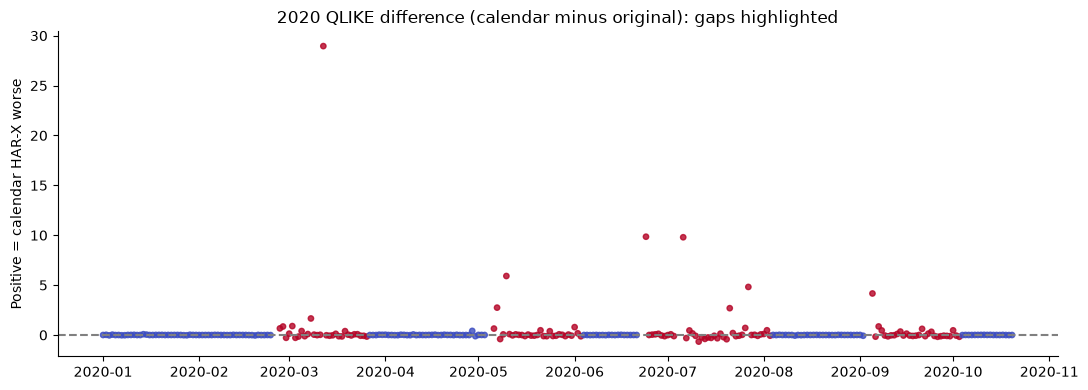

In [181]:
from scipy.stats import spearmanr
_miss = _u_matched.sort_values('date').reset_index(drop=True).copy()
assert len(_miss)==284 and _miss.date.is_unique
_extra = _u_f.reindex(pd.DatetimeIndex(_miss.date))
_miss['n_missing_prior30'] = _extra['missing_pvar_prior_30d'].to_numpy()
_miss['n_missing_prior7'] = _extra['missing_pvar_prior_7d'].to_numpy()
_miss['lagged_abs_return_pct'] = _u_ret.abs().shift(1).reindex(_miss.date).to_numpy()
_miss['lagged_volume_change_log'] = _u_logvol.diff().shift(1).reindex(_miss.date).to_numpy()
_gap_dates = _u_pvar.index[_u_pvar.isna()]
_miss['days_since_previous_source_gap'] = [
    int((d-_gap_dates[_gap_dates<d].max()).days) if (_gap_dates<d).any() else np.nan
    for d in pd.DatetimeIndex(_miss.date)]
_miss['calendar_minus_original_QLIKE'] = _miss.calendar_QLIKE - _miss.original_QLIKE
_miss['calendar_absolute_variance_error'] = ( _miss.calendar_imputed_HARX-_miss.observed).abs()
_miss['original_absolute_variance_error'] = (_miss.original_HARX-_miss.observed).abs()
_miss['missing_stratum'] = np.select([
    _miss.n_missing_prior30.eq(0), _miss.n_missing_prior30.eq(1)],
    ['0_missing','1_missing'],default='2plus_missing')
# Identical rows and original alpha, only remove the four new missingness covariates.
_u_no_flag_cols = list(hx_full_cols)
_u_no_flag_model = make_pipeline(StandardScaler(),Ridge(alpha=_u_alpha))
_u_no_flag_model.fit(_u_matrix(_u_fit)[_u_no_flag_cols],np.log1p(_u_fit.observed_parkinson))
_no_flag_pred = np.clip(np.expm1(np.clip(_u_no_flag_model.predict(
    _u_matrix(_u_2020)[_u_no_flag_cols]),-15,15)),1e-8,_u_cap)
_miss['calendar_without_missing_flags'] = _no_flag_pred
_miss['calendar_no_flags_QLIKE'] = _u_qlike(_miss.observed,_no_flag_pred)
_miss['flags_minus_no_flags_QLIKE'] = _miss.calendar_QLIKE-_miss.calendar_no_flags_QLIKE
_miss_summary=[]
for _label,_df in [('full_2020',_miss),('complete',_miss.loc[~_miss.had_missing_prior30]),
                    ('incomplete',_miss.loc[_miss.had_missing_prior30])]:
    _miss_summary.append({'sample':_label,'n':len(_df),
      'mean_observed_variance_proxy':float(_df.observed.mean()),
      'mean_prior_absolute_return_pct':float(_df.lagged_abs_return_pct.mean()),
      'mean_calendar_minus_original_QLIKE':float(_df.calendar_minus_original_QLIKE.mean()),
      'mean_calendar_missing_flags_minus_no_flags_QLIKE':float(_df.flags_minus_no_flags_QLIKE.mean()),
      'mean_original_abs_variance_error':float(_df.original_absolute_variance_error.mean()),
      'mean_calendar_abs_variance_error':float(_df.calendar_absolute_variance_error.mean()),
      'posthoc':True})
_miss_summary=pd.DataFrame(_miss_summary)
assert _miss.had_missing_prior30.sum()==126 and (~_miss.had_missing_prior30).sum()==158
# HAC sensitivity regression: explanatory association, NOT attribution of causal effect.
_hac_cols=['n_missing_prior30','lagged_abs_return_pct','lagged_volume_change_log']
_hac=_miss[['calendar_minus_original_QLIKE']+_hac_cols].replace([np.inf,-np.inf],np.nan).dropna()
_hac_fit=sm.OLS(_hac.calendar_minus_original_QLIKE,
    sm.add_constant(_hac[_hac_cols])).fit(cov_type='HAC',cov_kwds={'maxlags':7})
_hac_table=pd.DataFrame({'covariate':_hac_fit.params.index,'coefficient':_hac_fit.params.values,
 'HAC_se':_hac_fit.bse.values,'HAC_p_exploratory':_hac_fit.pvalues.values,
 'n':len(_hac),'posthoc_not_causal':True})
_miss.to_csv(OUT/'final_missingness_attribution_2020_daily.csv',index=False)
_miss_summary.to_csv(OUT/'final_missingness_attribution_strata.csv',index=False)
_hac_table.to_csv(OUT/'final_missingness_HAC_exploratory.csv',index=False)
assert _miss.date.is_unique and np.isfinite(_miss[['original_QLIKE','calendar_QLIKE','calendar_no_flags_QLIKE']]).all().all()
display(_miss_summary.round(4),_hac_table.round(5))
fig,ax=plt.subplots(figsize=(11,4))
ax.scatter(_miss.date,_miss.calendar_minus_original_QLIKE,
           c=np.where(_miss.had_missing_prior30,1.,0.),cmap='coolwarm',s=15,alpha=.8)
ax.axhline(0,color='gray',ls='--');ax.set(title='2020 QLIKE difference (calendar minus original): gaps highlighted',
 ylabel='Positive = calendar HAR-X worse');savefig('53_missingness_QLIKE_attribution.png')


### VI.2 — Four tail-risk models: ranking and multiplicity robustness

Predeclared block lengths 5, 10, 20 and 30 (calendar **observed-evaluation** rows), same-date four-model comparison, six pairwise hypotheses and max-|t| bootstrap **family-wise simultaneous intervals**. Also report how rankings change when excluding 2020 March or the worst 1/3/5 realized BTC loss dates. Never describe post-hoc sensitivity or selection probabilities as independent evidence of a superior trading model.


### VI.1b — Fair 2019-selected HAR-X ablation and loss sensitivity

An additional **2 × 2 design** compares missingness flags present/absent and reused versus independently validated Ridge regularization. All 2020 comparisons use identical 284 observed outcomes and are retrospective. QLIKE, absolute variance error, squared variance error and largest paired-loss contributors are reported separately. This is not causal identification.


In [182]:
# Historical 2019 model selection separately for each feature configuration; no 2020 retuning.
_harx_ablations=[];_harx_lossrows=[];_harx_grid=[]
_xtrain=_u_matrix(_u_train);_xval=_u_matrix(_u_val);_xtest=_u_matrix(_u_2020)
_abl_groups={'calendar_without_flags':list(hx_full_cols),'calendar_with_flags':list(_u_cols)}
_ytrain=np.log1p(_u_train.observed_parkinson.to_numpy(dtype=float))
_yfit=np.log1p(_u_fit.observed_parkinson.to_numpy(dtype=float))
for _kind,_cols in _abl_groups.items():
    _evaluated=[]
    for _alpha in np.logspace(-2,5,15):  # expanded 2019-only sensitivity; post-2020 selection caveat
        _candidate=make_pipeline(StandardScaler(),Ridge(alpha=_alpha))
        _candidate.fit(_xtrain[_cols],_ytrain)
        _valpred=np.clip(np.expm1(np.clip(_candidate.predict(_xval[_cols]),-15,15)),1e-8,_u_cap)
        _vql=float(_u_qlike(_u_val.observed_parkinson,_valpred).mean())
        _evaluated.append((_vql,_alpha))
        _harx_grid.append({'feature_set':_kind,'alpha':_alpha,'n_validation':len(_u_val),'2019_QLIKE':_vql,'grid_extended_posthoc':True})
    _selected=min(_evaluated)[1]
    for _alpha_type,_alpha in [('reused_from_all_flags',_u_alpha),('separately_2019_selected',_selected)]:
        _fitab=make_pipeline(StandardScaler(),Ridge(alpha=float(_alpha)))
        _fitab.fit(_u_matrix(_u_fit)[_cols],_yfit)
        _ypred=np.clip(np.expm1(np.clip(_fitab.predict(_xtest[_cols]),-15,15)),1e-8,_u_cap)
        _ql=_u_qlike(_miss.observed,_ypred)
        _err=np.asarray(_ypred-_miss.observed,dtype=float)
        _harx_ablations.append({'feature_set':_kind,'penalty_rule':_alpha_type,'selected_alpha':float(_alpha),
           'n':len(_miss),'QLIKE':float(_ql.mean()),'MAE_variance':float(np.abs(_err).mean()),
           'RMSE_variance':float(np.sqrt(np.mean(_err**2))),'mean_bias':float(_err.mean()),
           'historical_2020_retrospective':True})
        _harx_lossrows.extend({'date':d,'feature_set':_kind,'penalty_rule':_alpha_type,
            'observed_variance_proxy':float(y),'forecast_variance_proxy':float(p),
            'QLIKE':float(q),'absolute_variance_error':float(abs(e)),
            'squared_variance_error':float(e*e),'missing_prior30':bool(m)}
            for d,y,p,q,e,m in zip(_miss.date,_miss.observed,_ypred,_ql,_err,_miss.had_missing_prior30))
_harx_ablation_df=pd.DataFrame(_harx_ablations)
_harx_abl_daily=pd.DataFrame(_harx_lossrows)
_harx_grid_df=pd.DataFrame(_harx_grid)
_harx_jointloss=[]
for _label,_d in [('all',_miss),('30d_complete',_miss.loc[~_miss.had_missing_prior30]),
                  ('30d_incomplete',_miss.loc[_miss.had_missing_prior30])]:
    for _name,_pred in [('original_HARX',_d.original_HARX),('calendar_HARX',_d.calendar_imputed_HARX)]:
        _error=np.asarray(_pred-_d.observed,float)
        _harx_jointloss.append({'sample':_label,'model':_name,'n':len(_d),
            'QLIKE':float(_u_qlike(_d.observed,_pred).mean()),
            'MAE_variance':float(abs(_error).mean()),
            'RMSE_variance':float(np.sqrt(np.mean(_error**2))),
            'bias_variance':float(_error.mean())})
_harx_loss_df=pd.DataFrame(_harx_jointloss)
_harx_top=_miss.assign(abs_pair_qlike_diff=lambda f:f.calendar_minus_original_QLIKE.abs()).nlargest(20,'abs_pair_qlike_diff')
_harx_top=_harx_top[['date','had_missing_prior30','n_missing_prior30','calendar_minus_original_QLIKE',
                    'lagged_abs_return_pct','lagged_volume_change_log','observed','original_HARX','calendar_imputed_HARX']]
_harx_ablation_df.to_csv(OUT/'final_HARX_fair_2019_ablation_summary.csv',index=False)
_harx_grid_df.to_csv(OUT/'final_HARX_fair_2019_penalty_grid.csv',index=False)
_harx_abl_daily.to_csv(OUT/'final_HARX_fair_ablation_daily_2020.csv',index=False)
_harx_loss_df.to_csv(OUT/'final_HARX_QLIKE_MAE_RMSE_matched_strata.csv',index=False)
_harx_top.to_csv(OUT/'final_HARX_top_20_paired_loss_contributors.csv',index=False)
assert set(_harx_ablation_df.feature_set)==set(_abl_groups) and len(_harx_ablation_df)==4
assert len(_harx_abl_daily)==len(_miss)*4 and np.isfinite(_harx_abl_daily.QLIKE).all()
display(_harx_ablation_df.round(5),_harx_loss_df.round(5),_harx_top.head(10))


,feature_set,penalty_rule,selected_alpha,n,QLIKE,MAE_variance,RMSE_variance,mean_bias,historical_2020_retrospective
0,calendar_without_flags,reused_from_all_flags,100.0,284,3.42730,9.06870,52.95157,-3.16026,True
1,calendar_without_flags,separately_2019_selected,1000.0,284,3.40931,8.94512,52.94062,-3.54998,True
2,calendar_with_flags,reused_from_all_flags,100.0,284,3.67643,8.73366,52.47120,-4.09542,True
3,calendar_with_flags,separately_2019_selected,1000.0,284,3.56196,8.69623,52.52244,-4.27887,True


,sample,model,n,QLIKE,MAE_variance,RMSE_variance,bias_variance
0,all,original_HARX,284,3.41160,9.10636,52.99646,-3.07037
1,all,calendar_HARX,284,3.67643,8.73366,52.47120,-4.09542
2,30d_complete,original_HARX,158,2.71211,4.39911,7.44802,-0.47310
3,30d_complete,calendar_HARX,158,2.71533,4.40647,7.45189,-0.45774
4,30d_incomplete,original_HARX,126,4.28873,15.00910,79.12642,-6.32727
5,30d_incomplete,calendar_HARX,126,4.88163,14.15981,78.33296,-8.65695


,date,had_missing_prior30,n_missing_prior30,calendar_minus_original_QLIKE,lagged_abs_return_pct,lagged_volume_change_log,observed,original_HARX,calendar_imputed_HARX
69,2020-03-12,True,1.0,28.953281,0.021500,-0.087356,863.965264,5.336679,4.523127
169,2020-06-24,True,1.0,9.851359,NaN,NaN,6.492814,1.591179,0.425752
179,2020-07-06,True,2.0,9.795362,NaN,NaN,4.261995,1.714780,0.304208
126,2020-05-10,True,1.0,5.911511,2.559951,-0.106145,64.428134,6.164418,3.825868
200,2020-07-27,True,1.0,4.816294,2.329290,0.210806,62.567634,2.313968,1.953735
238,2020-09-05,True,1.0,4.161659,NaN,NaN,13.808712,4.992384,1.728640
123,2020-05-07,True,1.0,2.742703,2.908418,0.134734,28.809821,7.078974,3.886922
194,2020-07-21,True,2.0,2.687995,0.235264,0.061200,2.786399,0.882605,0.423509
65,2020-03-08,True,1.0,1.657245,2.357985,-0.119814,32.653224,3.608326,2.997914
59,2020-03-02,True,1.0,0.893523,0.431823,-0.012461,7.156652,3.705573,2.113344


,year,block,model,n,mean_FZ0,bootstrap_lowest_loss_frequency,retrospective
20,2020,10,GARCH-FHS,284,2.1477,0.308,True
21,2020,10,GARCH-filtered EVT,284,2.1470,0.320,True
22,2020,10,Gaussian GARCH,284,2.1887,0.357,True
23,2020,10,Rolling POT,284,2.2569,0.015,True


model,GARCH-FHS,GARCH-filtered EVT,Gaussian GARCH,Rolling POT
subset,,,,
all,2,1,3,4
drop_worst_1,3,2,1,4
drop_worst_3,3,2,1,4
drop_worst_5,3,2,1,4
excluding_March_2020,3,2,1,4


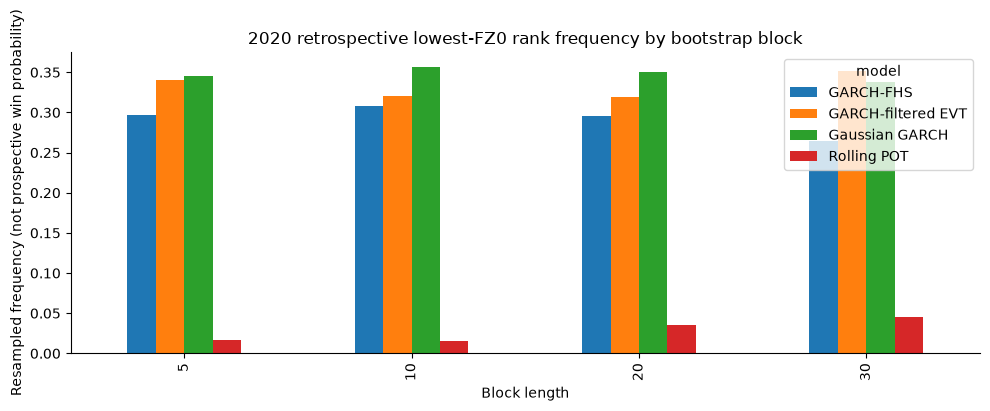

In [183]:
from itertools import combinations
_rank_models=['GARCH-FHS','GARCH-filtered EVT','Gaussian GARCH','Rolling POT']
assert set(_rank_models)==set(_u_pivot.columns)
_rank_rows=[];_pair_rows=[];_stress_rows=[]
for _year in [2019,2020]:
    _scores=_u_pivot.loc[_u_pivot.index.year==_year,_rank_models].sort_index()
    assert _scores.notna().all().all() and len(_scores)>200
    _a=_scores.to_numpy(dtype=float);_n=len(_a)
    _pairs=list(combinations(range(4),2))
    _d=np.column_stack([_a[:,i]-_a[:,j] for i,j in _pairs])
    _dbar=_d.mean(axis=0)
    for _block in [5,10,20,30]:
        _rng=np.random.default_rng(SEED+30000+_year*41+_block)
        _ix=np.stack([circular_block_sample(_n,_block,_rng) for _ in range(1000)])
        _boot_mean=np.mean(_a[_ix],axis=1)
        _boot_pair=np.column_stack([_boot_mean[:,i]-_boot_mean[:,j] for i,j in _pairs])
        _sd=np.maximum(_boot_pair.std(axis=0,ddof=1),1e-10)
        _max_t=np.max(np.abs((_boot_pair-_dbar)/_sd),axis=1)
        _critical=float(np.quantile(_max_t,.95))
        _win=np.argmin(_boot_mean,axis=1)
        for _j,_name in enumerate(_rank_models):
            _rank_rows.append({'year':_year,'block':_block,'model':_name,'n':_n,
               'mean_FZ0':float(_a[:,_j].mean()),'bootstrap_lowest_loss_frequency':float((_win==_j).mean()),
               'retrospective':True})
        for _k,(_i,_j) in enumerate(_pairs):
            _pair_rows.append({'year':_year,'block':_block,'model_a':_rank_models[_i],
               'model_b':_rank_models[_j],'mean_a_minus_b_FZ0':float(_dbar[_k]),
               'pointwise_low':float(np.quantile(_boot_pair[:,_k],.025)),
               'pointwise_high':float(np.quantile(_boot_pair[:,_k],.975)),
               'simultaneous_95_low':float(_dbar[_k]-_critical*_sd[_k]),
               'simultaneous_95_high':float(_dbar[_k]+_critical*_sd[_k]),
               'n_comparisons_in_family':6,'family':'all_four_models_single_year',
               'max_t_critical':_critical,'posthoc':True})
    _ref=_u_matched_joint.loc[(_u_matched_joint.year==_year)&
             _u_matched_joint.model.eq('GARCH-FHS'),['date','loss']].set_index('date')
    _stress=_scores.join(_ref,how='inner',validate='one_to_one')
    assert len(_stress)==len(_scores)
    _worst=_stress.sort_values('loss',ascending=False).index
    for _desc,_retained in [('all',_scores),
      ('drop_worst_1',_scores.drop(index=_worst[:1])),
      ('drop_worst_3',_scores.drop(index=_worst[:3])),
      ('drop_worst_5',_scores.drop(index=_worst[:5])),
      ('excluding_March_2020',_scores.loc[~(_scores.index.to_period('M')==pd.Period('2020-03'))])]:
        if _year==2019 and _desc=='excluding_March_2020':continue
        _means=_retained.mean().sort_values()
        for _pos,(_model,_value) in enumerate(_means.items(),start=1):
            _stress_rows.append({'year':_year,'subset':_desc,'rank':_pos,'model':_model,
                   'mean_FZ0':float(_value),'n':len(_retained),'retrospective':True})
_rank_df=pd.DataFrame(_rank_rows);_pair_df=pd.DataFrame(_pair_rows);_stress_df=pd.DataFrame(_stress_rows)
_rank_df.to_csv(OUT/'final_tail_risk_block_length_rank_stability.csv',index=False)
_pair_df.to_csv(OUT/'final_tail_risk_familywise_six_pairs.csv',index=False)
_stress_df.to_csv(OUT/'final_tail_risk_crisis_exclusion_ranks.csv',index=False)
display(_rank_df.loc[(_rank_df.year==2020)&(_rank_df.block==10)].round(4),
        _stress_df.loc[_stress_df.year==2020].pivot(index='subset',columns='model',values='rank'))
fig,ax=plt.subplots(figsize=(10,4))
_plot_rank=_rank_df.loc[_rank_df.year.eq(2020)].pivot(index='block',columns='model',values='bootstrap_lowest_loss_frequency')
_plot_rank.plot(kind='bar',ax=ax);ax.set(title='2020 retrospective lowest-FZ0 rank frequency by bootstrap block',
 ylabel='Resampled frequency (not prospective win probability)',xlabel='Block length');savefig('54_tail_risk_rank_block_sensitivity.png')


### VI.3 — Event-aligned post-shock uncertainty (clustered by overlapping event windows)

Shock origins are derived using a pre-2019 threshold; adjacent/overlapping events are **not independent**. Event clusters preserve the full future h-eligible-observation path. If too few independent clusters exist the interval is explicitly unavailable; no "recovery time" is claimed.


### VI.2b — Previsible volatility-state risk-model evaluation

The previous "drop worst loss date" exercise is a **hindsight stress sensitivity**, not a deployable regime indicator. Here all regimes are defined using only lagged BTC volatility and cutoffs computed from 2018-and-earlier data; no crisis day is identified using its realized outcome. FZ0 and VaR exceptions are evaluated by regime on the same dates; small strata are descriptive only.


,year,previsible_regime,model,n,avg_FZ0,VaR_exceedances,avg_pinball95,avg_ES,VaR_exceedance_rate,rank_in_regime
12,2020,normal,GARCH-FHS,207,2.1209,8,0.4663,6.8004,0.0386,2.0
13,2020,normal,GARCH-filtered EVT,207,2.1206,8,0.4660,6.7794,0.0386,1.0
14,2020,normal,Gaussian GARCH,207,2.1886,8,0.4671,5.6269,0.0386,3.0
15,2020,normal,Rolling POT,207,2.3265,4,0.4979,8.9821,0.0193,4.0
16,2020,elevated,GARCH-FHS,47,1.9926,2,0.3736,9.2261,0.0426,3.0
17,2020,elevated,GARCH-filtered EVT,47,1.9913,2,0.3734,9.1978,0.0426,2.0
18,2020,elevated,Gaussian GARCH,47,1.9682,2,0.3742,7.6468,0.0426,1.0
19,2020,elevated,Rolling POT,47,2.0449,2,0.3826,10.0337,0.0426,4.0
20,2020,high,GARCH-FHS,30,2.5750,1,0.7322,20.3492,0.0333,4.0
21,2020,high,GARCH-filtered EVT,30,2.5727,1,0.7292,20.2876,0.0333,3.0


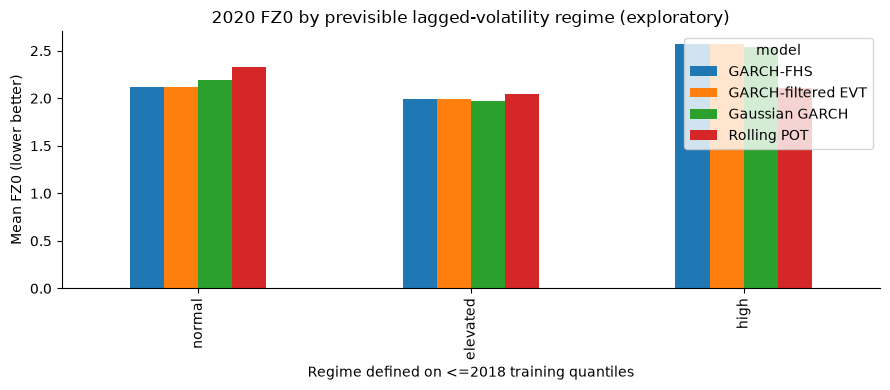

In [184]:
# Define previsible regimes with lagged 30-eligible-return standard deviation.
_tret=vol_s.sort_index().astype(float)
_prior_vol30=_tret.rolling(30,min_periods=30).std().shift(1)
_training_vol=_prior_vol30.loc[:TRAIN_END].dropna()
assert len(_training_vol)>100
_vol_median,_vol_high=np.quantile(_training_vol,[.50,.90])
_risk_regime=_u_matched_joint.copy()
_risk_regime['prior_vol30']=_prior_vol30.reindex(pd.DatetimeIndex(_risk_regime.date)).to_numpy()
_risk_regime=_risk_regime.dropna(subset=['prior_vol30']).copy()
_risk_regime['previsible_regime']=pd.cut(_risk_regime.prior_vol30,
    [-np.inf,_vol_median,_vol_high,np.inf],labels=['normal','elevated','high'],include_lowest=True)
_risk_regime['prior_vol_cutoff_fit_end']=str(TRAIN_END.date())
_regime_risk_sum=(_risk_regime.groupby(['year','previsible_regime','model'],observed=True,as_index=False)
   .agg(n=('date','size'),avg_FZ0=('FZ0_joint_loss','mean'),
        VaR_exceedances=('exception','sum'),avg_pinball95=('pinball95','mean'),
        avg_ES=('ES','mean')))
_regime_risk_sum['VaR_exceedance_rate']=_regime_risk_sum.VaR_exceedances/_regime_risk_sum.n
_regime_risk_sum['rank_in_regime']=_regime_risk_sum.groupby(['year','previsible_regime'],observed=True).avg_FZ0.rank(method='min')
_stress_day=_risk_regime.loc[_risk_regime.year.eq(2020)].copy()
_stress_top=(_stress_day.groupby('date',as_index=False).loss.first().nlargest(10,'loss')
    .rename(columns={'loss':'observed_loss_pct'}))
_stress_top['rank_is_ex_post']=True
_risk_regime.to_csv(OUT/'final_previsible_risk_regime_daily.csv',index=False)
_regime_risk_sum.to_csv(OUT/'final_previsible_risk_regime_summary.csv',index=False)
_stress_top.to_csv(OUT/'final_tail_risk_largest_loss_days_expost.csv',index=False)
assert _risk_regime.previsible_regime.notna().all()
assert (_regime_risk_sum.groupby(['year','previsible_regime'],observed=True).model.nunique()==4).all()
display(_regime_risk_sum.loc[_regime_risk_sum.year.eq(2020)].round(4))
_plt=_regime_risk_sum.loc[_regime_risk_sum.year.eq(2020)]
fig,ax=plt.subplots(figsize=(9,4))
_plt.pivot(index='previsible_regime',columns='model',values='avg_FZ0').reindex(['normal','elevated','high']).plot.bar(ax=ax)
ax.set(title='2020 FZ0 by previsible lagged-volatility regime (exploratory)',ylabel='Mean FZ0 (lower better)',xlabel='Regime defined on <=2018 training quantiles')
savefig('57_previsible_volatility_regime_risk_comparison.png')


,quantile,horizon,shock_origins,independent_nonoverlap_clusters,observed_ACI_rate,observed_Rolling180_rate,ACI_minus_Rolling180,bootstrap_ACI_CI_low,bootstrap_ACI_CI_high,bootstrap_diff_CI_low,bootstrap_diff_CI_high,leave_one_cluster_diff_min,leave_one_cluster_diff_max,bootstrap_ci_estimated,bootstrap_method,n_bootstrap,recovery_time_established,retrospective
0,0.9,1,8,8,0.2500,0.1250,0.1250,0.0000,0.6250,0.0,0.3750,0.0,0.1429,True,overlap_connected_component_cluster_resampling,2000,False,True
1,0.9,3,8,7,0.1250,0.0833,0.0417,0.0417,0.2222,0.0,0.1429,0.0,0.0556,True,overlap_connected_component_cluster_resampling,2000,False,True
2,0.9,7,8,4,0.1964,0.1607,0.0357,0.0714,0.2500,0.0,0.0536,0.0,0.0408,True,overlap_connected_component_cluster_resampling,2000,False,True
3,0.9,14,8,3,0.1607,0.1161,0.0446,0.0714,0.2000,0.0,0.0714,0.0,0.0595,True,overlap_connected_component_cluster_resampling,2000,False,True


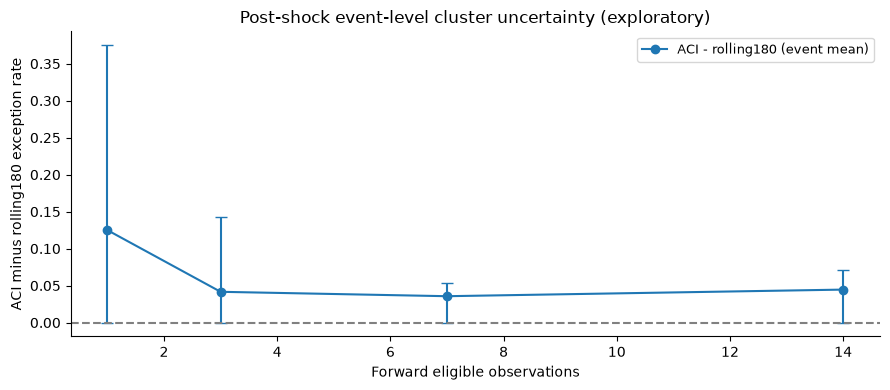

In [185]:
# ACI event study: do not join synthetic resampled day blocks into invented shock paths.
# A shock origin is previsible (prior-day return). The following h eligible rows are
# counted as a descriptive event window. Overlapping event windows share observations.
_shock_day=_u_acid.sort_values('date').reset_index(drop=True).copy()
_shock_flags=_shock_day.prior_shock_event.to_numpy(dtype=bool)
_shock_origins=np.flatnonzero(_shock_flags)
_shock_boot_reps=2000
_shock_uncert=[]; _shock_events=[]; _shock_loo=[]

def _shock_cluster_windows(starts, horizon):
    # Connected components of intervals [start,start+horizon); every overlapping event
    # is resampled as one cluster. This avoids treating overlapping origins as independent.
    starts=np.asarray(sorted(starts),dtype=int)
    clusters=[]; current=[]; right=-1
    for ix in starts:
        if current and ix >= right:
            clusters.append(current);current=[]
        current.append(int(ix));right=max(right,int(ix)+horizon)
    if current:clusters.append(current)
    return clusters

for _q,_ac,_ro in [(0.90,'q90','pred_q90'),(0.95,'q95','pred_q95')]:
    _aci_bad=(_shock_day.actual_variance>_shock_day[_ac]).to_numpy(float)
    _rolling_bad=(_shock_day.actual_variance>_shock_day[_ro]).to_numpy(float)
    for _h in (1,3,7,14):
        _valid_starts=_shock_origins[_shock_origins+_h<=len(_shock_day)]
        _cl=_shock_cluster_windows(_valid_starts,_h)
        _event=pd.DataFrame([{
            'event_index':int(i),'event_date':_shock_day.date.iloc[i],
            'quantile':_q,'horizon_eligible_rows':_h,
            'ACI_rate':float(_aci_bad[i:i+_h].mean()),
            'Rolling180_rate':float(_rolling_bad[i:i+_h].mean()),
            'difference':float((_aci_bad[i:i+_h]-_rolling_bad[i:i+_h]).mean()),
            'cluster_id':next(k for k,z in enumerate(_cl) if i in z),
        } for i in _valid_starts])
        if len(_event):_shock_events.append(_event)
        _center=_event[['ACI_rate','Rolling180_rate','difference']].mean().to_numpy(dtype=float) if len(_event) else np.full(3,np.nan)
        # Clusters are the resampling units, not individual overlapping windows.
        _clusters=[_event.loc[_event.cluster_id.eq(i),['ACI_rate','Rolling180_rate','difference']].to_numpy(dtype=float)
                   for i in range(len(_cl))]
        _ncl=len(_clusters)
        _rng=np.random.default_rng(SEED+40000+int(100*_q)*100+_h*31)
        _draw=[]
        if _ncl>=3:
            for _ in range(_shock_boot_reps):
                _sel=_rng.integers(0,_ncl,size=_ncl)
                _draw.append(np.concatenate([_clusters[k] for k in _sel],axis=0).mean(axis=0))
        _draw=np.asarray(_draw,dtype=float).reshape((-1,3))
        _ci_low=np.quantile(_draw,.025,axis=0) if len(_draw) else np.full(3,np.nan)
        _ci_high=np.quantile(_draw,.975,axis=0) if len(_draw) else np.full(3,np.nan)
        _leave=[]
        if _ncl>=2:
            for _k in range(_ncl):
                _sub=np.concatenate([_c for _j,_c in enumerate(_clusters) if _k!=_j],axis=0)
                _leave.append(float(_sub[:,2].mean()))
                _shock_loo.append({'quantile':_q,'horizon':_h,'excluded_cluster':_k,
                                   'n_eligible_events':len(_sub),'difference_without_cluster':_leave[-1]})
        _shock_uncert.append({'quantile':_q,'horizon':_h,'shock_origins':len(_valid_starts),
            'independent_nonoverlap_clusters':_ncl,
            'observed_ACI_rate':float(_center[0]),'observed_Rolling180_rate':float(_center[1]),
            'ACI_minus_Rolling180':float(_center[2]),
            'bootstrap_ACI_CI_low':float(_ci_low[0]),'bootstrap_ACI_CI_high':float(_ci_high[0]),
            'bootstrap_diff_CI_low':float(_ci_low[2]),'bootstrap_diff_CI_high':float(_ci_high[2]),
            'leave_one_cluster_diff_min':min(_leave,default=np.nan),
            'leave_one_cluster_diff_max':max(_leave,default=np.nan),
            'bootstrap_ci_estimated':bool(_ncl>=3),
            'bootstrap_method':'overlap_connected_component_cluster_resampling',
            'n_bootstrap':len(_draw), 'recovery_time_established':False,'retrospective':True})
_shock_uncert_df=pd.DataFrame(_shock_uncert)
_shock_event_df=pd.concat(_shock_events,ignore_index=True) if _shock_events else pd.DataFrame()
_shock_loo_df=pd.DataFrame(_shock_loo)
_shock_uncert_df.to_csv(OUT/'final_ACI_shock_event_cluster_uncertainty.csv',index=False)
_shock_event_df.to_csv(OUT/'final_ACI_shock_event_clusters.csv',index=False)
_shock_loo_df.to_csv(OUT/'final_ACI_shock_leave_cluster_out.csv',index=False)
assert _shock_uncert_df.shock_origins.max()==int(_shock_flags.sum())
assert (_shock_uncert_df.loc[_shock_uncert_df.independent_nonoverlap_clusters.lt(3),'bootstrap_ci_estimated']==False).all()
display(_shock_uncert_df.loc[_shock_uncert_df['quantile'].eq(.90)].round(4))
_plt=_shock_uncert_df.loc[_shock_uncert_df['quantile'].eq(.90)].sort_values('horizon')
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(_plt.horizon,_plt.ACI_minus_Rolling180,marker='o',label='ACI - rolling180 (event mean)')
_has_ci=_plt.bootstrap_ci_estimated & _plt.bootstrap_diff_CI_low.notna()
if _has_ci.any():
    _p=_plt.loc[_has_ci]
    ax.errorbar(_p.horizon,_p.ACI_minus_Rolling180,
        yerr=[(_p.ACI_minus_Rolling180-_p.bootstrap_diff_CI_low).clip(lower=0),
              (_p.bootstrap_diff_CI_high-_p.ACI_minus_Rolling180).clip(lower=0)],fmt='none',capsize=4)
ax.axhline(0,color='gray',ls='--');ax.set(xlabel='Forward eligible observations',
    ylabel='ACI minus rolling180 exception rate',title='Post-shock event-level cluster uncertainty (exploratory)')
ax.legend(fontsize=9);savefig('55_ACI_event_cluster_uncertainty.png')


### VI.4 — R GARCH S4 sourceable diagnostics and five-model provenance

The helper is prepared **before** R execution, and its path is passed via `BITCOIN_R_GARCH_S4_HELPER`. The original external `04_garch_crosslanguage.R` must `source(Sys.getenv("BITCOIN_R_GARCH_S4_HELPER"))` and use `safe_rugarch_extract(fit, logfile)` on the actual fitted object. Without the external scripts, do **not** claim that the historical GARCH error is fixed. Each of the five R models must have current-run artifacts, timestamps and linked raw hashes.


In [186]:
# Sourceable S4 diagnostic helper was generated BEFORE the R runner (Part IV).
# A script is not repaired by this helper unless the actual 04 script sources it.
assert _R_GARCH_HELPER_PATH.is_file()
_r_expected_scripts=['01_structural_breaks.R','02_tvpvar_connectedness.R',
 '03_es_regression_backtests.R','04_garch_crosslanguage.R','05_qvar_connectedness.R']
_r_provenance_valid = False
_r_status_map={name:'NOT_EXECUTED' for name in _r_expected_scripts}
if _r_current_table is not None:
    if not {'script','status'}.issubset(_r_current_table.columns):
        raise AssertionError('R_EXECUTION_STATUS.csv has no script/status columns')
    for _s in _r_expected_scripts:
        _hits=_r_current_table.loc[_r_current_table.script.eq(_s),'status'].astype(str)
        _r_status_map[_s]=_hits.iloc[-1] if len(_hits)==1 else ('DUPLICATE' if len(_hits)>1 else 'MISSING')
if _r_current_manifest is not None:
    _r_provenance_valid=bool(_r_current_manifest.get('python_run_id')==RUN_ID and
       _r_current_manifest.get('original_file_sha256')==SOURCE_CSV_SHA256 and
       _r_current_results is not None and _r_current_results.is_dir())
# Do not trust a SUCCESS status alone; require expected current-run result files.
_r_required_artifacts={
 '01_structural_breaks.R':['structural_breakpoints*.csv','breakpoints_*.csv','bai_perron_*.csv'],
 '02_tvpvar_connectedness.R':['tvpvar_TCI.csv'],
 '03_es_regression_backtests.R':['es_regression_backtests.csv'],
 '04_garch_crosslanguage.R':['garch_R_vs_Python_parameters_2018.csv'],
 '05_qvar_connectedness.R':['qvar_TCI_summary.csv']}
_r_artifacts_present={}
_r_artifact_sha256={}
for _s,_patterns in _r_required_artifacts.items():
    _matches=[]
    if _r_provenance_valid:
        for _pattern in _patterns:
            _matches.extend(_r_current_results.glob(_pattern))
    _fresh=[_p for _p in _matches if _p.is_file() and _p.stat().st_mtime_ns>=RUN_STARTED_NS]
    _r_artifacts_present[_s]=bool(_fresh)
    _r_artifact_sha256[_s]={_p.name:hashlib.sha256(_p.read_bytes()).hexdigest() for _p in _fresh}
_r_manifest_fresh=bool(_r_provenance_valid and
    (_r_project/'r_analysis'/'LATEST_R_RUN.json').stat().st_mtime_ns>=RUN_STARTED_NS)


# R GARCH fit convergence must be explicit in current-run tabular evidence.
# The original R script is external to this notebook; unknown schemas are NOT accepted.
_r_garch_fit_status='NOT_EXECUTED'
_r_garch_fit_converged=False
if _r_provenance_valid and _r_artifacts_present.get('04_garch_crosslanguage.R', False):
    _gfiles=list(_r_current_results.glob('garch_R_vs_Python_parameters_2018.csv'))
    if _gfiles:
        _gt=pd.read_csv(_gfiles[0])
        _lo={str(c).strip().lower():c for c in _gt.columns}
        _conv_cols=[_lo[x] for x in ('convergence','r_convergence','rugarch_convergence','r_garch_convergence') if x in _lo]
        _ok_cols=[_lo[x] for x in ('r_success','converged','r_converged') if x in _lo]
        if _conv_cols:
            _vv=pd.to_numeric(_gt[_conv_cols[0]], errors='coerce')
            _r_garch_fit_converged=bool(len(_vv)>0 and _vv.notna().all() and _vv.eq(0).all())
            _r_garch_fit_status='CONVERGED' if _r_garch_fit_converged else 'NONCONVERGED'
        elif _ok_cols:
            _vv=_gt[_ok_cols[0]].astype(str).str.lower().str.strip()
            _r_garch_fit_converged=bool(len(_vv)>0 and _vv.isin(['true','1','yes']).all())
            _r_garch_fit_status='CONVERGED' if _r_garch_fit_converged else 'NONCONVERGED'
        else:
            _r_garch_fit_status='NO_EXPLICIT_R_CONVERGENCE_FIELD'


# Only accept convergence evidence derived from an actual rugarch fit and
# explicitly exported by the original R script. Never infer it from script exit 0.
# Accept either a fresh convergence column in the native parameter CSV above,
# or a run-scoped proof file generated by the supplied R helper from the fit S4 object.
_r_garch_proof_file=OUT/'BTC_2026_GARCH_CONVERGENCE_PROOF.csv'
if (not _r_garch_fit_converged and _r_provenance_valid and
        _r_artifacts_present.get('04_garch_crosslanguage.R',False) and
        _r_garch_proof_file.is_file() and
        _r_garch_proof_file.stat().st_mtime_ns>=RUN_STARTED_NS):
    _gp=pd.read_csv(_r_garch_proof_file)
    needed={'python_run_id','convergence','fit_class','fit_date'}
    if needed.issubset(_gp.columns) and len(_gp)>0 and len(_gp)<=20 and \
       _gp.python_run_id.astype(str).eq(str(RUN_ID)).all() and \
       _gp.fit_class.astype(str).str.contains('uGARCHfit',regex=False).all():
        _codes=pd.to_numeric(_gp['convergence'],errors='coerce')
        _r_garch_fit_converged=bool(_codes.notna().all() and _codes.eq(0).all())
        _r_garch_fit_status='CONVERGED_FROM_ACTUAL_S4_PROOF' if _r_garch_fit_converged else 'NONCONVERGED_S4_PROOF'
    else:
        _r_garch_fit_status='INVALID_S4_PROOF_SCHEMA_OR_RUN_ID'

_R_FIVE_VALIDATED = bool(_r_manifest_fresh and all(
    _r_status_map[s]=='SUCCESS' and _r_artifacts_present[s] for s in _r_expected_scripts) and
    _r_current_status=='SUCCESS' and _r_garch_fit_converged)
if _r_current_status=='SUCCESS' and not _R_FIVE_VALIDATED:
    _r_current_status='PARTIAL_R_FAILURE_OR_UNVERIFIED_STATUS'
_r_link_report={'python_run_id':RUN_ID,'original_csv_sha256':SOURCE_CSV_SHA256,
 'R_execution_status':_r_current_status,'linked_manifest_valid':_r_provenance_valid,
 'five_R_scripts_current_run_verified':_R_FIVE_VALIDATED,
 'per_script_status':_r_status_map,'required_results_present':_r_artifacts_present,'artifact_sha256':_r_artifact_sha256,
 'R_manifest_created_this_python_run':_r_manifest_fresh,
 'GARCH_S4_helper':str(_R_GARCH_HELPER_PATH),
 'GARCH_fix_verified':bool(_R_FIVE_VALIDATED),
 'GARCH_convergence_status':_r_garch_fit_status,
 'GARCH_convergence_explicitly_verified':_r_garch_fit_converged,
 'external_script_must_source_helper':True,
 'external_R_source_modified':False,
 'error_logs':'R_run_stderr_full.log / R_run_stdout_full.log, when BITCOIN_RUN_R=1'}
(OUT/'final_R_five_model_provenance_gate.json').write_text(json.dumps(_r_link_report,indent=2),encoding='utf-8')
print('R five-model verification:',_R_FIVE_VALIDATED,'status:',_r_current_status)
display(pd.DataFrame({'script':list(_r_status_map),'status':list(_r_status_map.values())}))


R five-model verification: False status: PARTIAL_R_FAILURE_OR_UNVERIFIED_STATUS


,script,status
0,01_structural_breaks.R,SUCCESS
1,02_tvpvar_connectedness.R,SUCCESS
2,03_es_regression_backtests.R,SUCCESS
3,04_garch_crosslanguage.R,SUCCESS
4,05_qvar_connectedness.R,SUCCESS


### VI.5 — Linked QVAR × TVP-VAR × BTC–ETH DCC/volatility

QVAR's lower-tail and TVP-VAR's dynamic TCI are eligible only if the **corresponding current-run R outputs** contain dated daily observations. Historical R summary tables alone cannot support a time-aligned chart. The BTC–ETH DCC series is the Python **prior conditional correlation**, not market volatility, so it is plotted separately from lagged 30-day BTC realized return volatility. All overlays are descriptive, not evidence of contagion, causation or conditional forecasting gain.


In [187]:
_connect_status={'run_id':RUN_ID,'status':'SKIPPED_R_CURRENT_RUN_NOT_VERIFIED',
 'QVAR_daily':'NOT_AVAILABLE','TVP_VAR_daily':'NOT_AVAILABLE',
 'DCC_python':'available','BTC_lagged_vol':'available','n_matched':0}
_connect_daily=pd.DataFrame(columns=['date','qvar_lower_tail_TCI','tvpvar_TCI','DCC_BTC_ETH_prior','BTC_prior_30d_vol'])
def _read_daily_r_tci(folder, globs, prefer_lower=False):
    for pattern in globs:
        for fp in sorted(folder.glob(pattern)):
            try:
                frame=pd.read_csv(fp)
                lower={str(c).lower():c for c in frame.columns}
                day=next((lower[k] for k in ['date','time','datetime'] if k in lower),None)
                if day is None: continue
                frame[day]=pd.to_datetime(frame[day],errors='coerce')
                if frame[day].notna().sum()<15:continue
                if prefer_lower:
                    qcol=next((c for c in frame.columns if str(c).lower() in ['tau','quantile','q']),None)
                    if qcol is not None:
                        x=pd.to_numeric(frame[qcol],errors='coerce')
                        frame=frame.loc[np.isclose(x,.05,atol=.011)]
                    elif '05' not in fp.name and 'lower' not in fp.name.lower():
                        continue
                value=next((c for c in frame.columns if c!=day and str(c).lower() in ['tci','total_connectedness','connectedness_index','value']
                    and pd.api.types.is_numeric_dtype(frame[c])),None)
                if value is None:
                    numeric=[c for c in frame.columns if c!=day and pd.api.types.is_numeric_dtype(frame[c])
                             and str(c).lower() not in ['tau','quantile','q','year']]
                    if len(numeric)==1:value=numeric[0]
                if value is None:continue
                result=frame[[day,value]].dropna().rename(columns={day:'date',value:'TCI'})
                if result.date.duplicated().any() or len(result)<15:continue
                return result.sort_values('date'),fp.name
            except (OSError,ValueError,KeyError,TypeError):
                continue
    return None,None
if _R_FIVE_VALIDATED:
    _qt,_qname=_read_daily_r_tci(_r_current_results,
        ['qvar*0.05*TCI*.csv','qvar*05*TCI*.csv','qvar*lower*TCI*.csv','qvar*TCI*daily*.csv'],True)
    _tt,_tname=_read_daily_r_tci(_r_current_results,['tvpvar_TCI.csv','tvpvar*TCI*daily*.csv'])
    _connect_status['QVAR_daily']=_qname or 'NOT_AVAILABLE'
    _connect_status['TVP_VAR_daily']=_tname or 'NOT_AVAILABLE'
    if _qt is not None and _tt is not None:
        _pydcc=refit_dcc_daily.loc[refit_dcc_daily.fit_scenario.eq('2019_full'),['date','DCC_prior']].copy()
        _pydcc['date']=pd.to_datetime(_pydcc.date)
        _lagged_vol=vol_s.rolling(30,min_periods=30).std().shift(1).rename('BTC_prior_30d_vol')
        _connect_daily=(_qt.rename(columns={'TCI':'qvar_lower_tail_TCI'})
            .merge(_tt.rename(columns={'TCI':'tvpvar_TCI'}),on='date',validate='one_to_one')
            .merge(_pydcc.rename(columns={'DCC_prior':'DCC_BTC_ETH_prior'}),on='date',validate='one_to_one')
            .merge(_lagged_vol.rename_axis('date').reset_index(),on='date',validate='one_to_one')
            .dropna().sort_values('date'))
        _connect_status.update({'n_matched':len(_connect_daily),
           'status':'LINKED_DAILY_SERIES' if len(_connect_daily)>=15 else 'INSUFFICIENT_DAILY_OVERLAP'})
        if len(_connect_daily)>=15:
            fig,axs=plt.subplots(4,1,sharex=True,figsize=(11,9))
            for ax,column,title in zip(axs,['qvar_lower_tail_TCI','tvpvar_TCI','DCC_BTC_ETH_prior','BTC_prior_30d_vol'],
                    ['R QVAR 5% lower tail TCI','R TVP-VAR TCI','Python prior BTC–ETH DCC correlation',
                     'Python lagged 30-day BTC return volatility']):
                ax.plot(_connect_daily.date,_connect_daily[column],lw=.85)
                ax.set_ylabel(title,fontsize=8)
            axs[0].set_title('Date-matched QVAR / TVP-VAR / DCC / volatility (descriptive)')
            savefig('56_connectedness_DCC_volatility_current_R_only.png')
_connect_daily.to_csv(OUT/'final_R_Python_QVAR_TVPVAR_DCC_join.csv',index=False)
(OUT/'final_R_Python_connectedness_plot_status.json').write_text(json.dumps(_connect_status,indent=2),encoding='utf-8')
print('Connectedness analysis:',_connect_status)


Connectedness analysis: {'run_id': '20261026T030925_071513Z_ee4a01ed', 'status': 'SKIPPED_R_CURRENT_RUN_NOT_VERIFIED', 'QVAR_daily': 'NOT_AVAILABLE', 'TVP_VAR_daily': 'NOT_AVAILABLE', 'DCC_python': 'available', 'BTC_lagged_vol': 'available', 'n_matched': 0}


### VI.6 — Frozen 2021+ independent OHLCV scoring vs prior-only rolling quantile baseline (only when genuine source is supplied)

No post-2020 rows were attached; **no 2021+ result is implied**. To run the holdout, set `BITCOIN_FUTURE_OHLCV_CSV` to a trusted, real `date,open,high,low,close,volume` daily Bitcoin CSV covering **2020-10-21 continuously through 2021+**, with actual calendar observations. The model trained through 2017, fixed residual-history length 180, and transformation stay unchanged. The bridge (late 2020) is used only for sequential residual feedback; scores start 2021-01-01. Missing dates or altered validation data reject the evaluation; fake or forward-filled prices must never be used. The prospective **HAR-X quantile proxy only** is tested here, not all VaR/ES/R models. A post-hoc model choice based on these outcomes would invalidate the untouched-holdout claim.


**Updated external scoring rule:** Missing daily bars are never imputed. Forecast dates require 30 preceding *calendar* days actually present, and only eligible observed dates receive scores. The benchmark/feature history is rolling, so results are descriptive and external provenance remains independently reviewable.


### VI.5b — R–Python connectedness descriptive association only

QVAR tail-TCI, TVP-VAR TCI, Python DCC and prior volatility are synchronized **only when the five R outputs match this run and hashes**. Contemporaneous Spearman association cannot establish spillover direction, causality or forecast gains. Without real aligned daily series, the analysis is skipped.


In [188]:
_connect_assoc={'run_id':RUN_ID,'status':'SKIPPED_R_DAILY_SERIES_UNAVAILABLE','n':int(len(_connect_daily))}
_conn_corr_df=pd.DataFrame(columns=['metric_a','metric_b','spearman_rho','n','retrospective'])
if _connect_status['status']=='LINKED_DAILY_SERIES' and len(_connect_daily)>=30:
    _cvars=['qvar_lower_tail_TCI','tvpvar_TCI','DCC_BTC_ETH_prior','BTC_prior_30d_vol']
    _temp=_connect_daily[_cvars].astype(float)
    _connected_rows=[]
    for _i in range(len(_cvars)):
        for _j in range(_i+1,len(_cvars)):
            _r,_p=spearmanr(_temp[_cvars[_i]],_temp[_cvars[_j]],nan_policy='omit')
            _connected_rows.append({'metric_a':_cvars[_i],'metric_b':_cvars[_j],
                'spearman_rho':float(_r),'n':len(_temp),'retrospective':True,
                'p_unadjusted_exploratory':float(_p)})
    _conn_corr_df=pd.DataFrame(_connected_rows)
    _connect_assoc.update({'status':'DESCRIPTIVE_SPEARMAN_ONLY','n':len(_temp),
        'no_causal_claim':True,'n_correlations':len(_conn_corr_df)})
    display(_conn_corr_df.round(4))
_conn_corr_df.to_csv(OUT/'final_R_Python_connectedness_descriptive_correlations.csv',index=False)
(OUT/'final_R_Python_connectedness_association_status.json').write_text(json.dumps(_connect_assoc,indent=2),encoding='utf-8')
print('Connectedness association:',_connect_assoc)


Connectedness association: {'run_id': '20261026T030925_071513Z_ee4a01ed', 'status': 'SKIPPED_R_DAILY_SERIES_UNAVAILABLE', 'n': 0}


In [189]:
# Real, unfilled external OHLCV; score only eligible days with 30 preceding calendar days.
import os, hashlib, json
_future_path_text=os.environ.get('BITCOIN_FUTURE_OHLCV_CSV','').strip()
_EXTERNAL_2021_SCORED_MIN90=False
_external_report={'python_run_id':RUN_ID,'status':'NOT_PROVIDED',
 'model':'Original frozen HAR-X quantile with sequential eligible-row residual calibration',
 'frozen_model_sha256':_FROZEN_MODEL_METADATA['artifact_sha256'],
 'historical_csv_sha256':SOURCE_CSV_SHA256,
 'evaluation_start':'2021-01-01','model_retuned_on_2021plus':False,
 'other_risk_models_external_test':'NOT_PERFORMED',
 'data_authenticity':'PUBLIC_EXCHANGE_SOURCE_NOT_INDEPENDENTLY_ATTESTED',
 'baseline':'prior-180-observation empirical Parkinson quantiles',
 'gap_policy':'NO_IMPUTATION; require previous 30 calendar days observed for scoring'}
if _future_path_text:
    _fp=Path(_future_path_text).expanduser().resolve()
    if not _fp.is_file():raise FileNotFoundError('Real future OHLCV CSV missing: '+str(_fp))
    _needed=['date','open','high','low','close','volume']
    _future=pd.read_csv(_fp)
    if not set(_needed).issubset(_future.columns):raise ValueError('Future OHLCV missing fields: '+str(set(_needed)-set(_future.columns)))
    _future=_future[_needed].copy()
    _future.date=pd.to_datetime(_future.date,utc=True,errors='raise').dt.tz_localize(None).dt.normalize()
    _future=_future.sort_values('date').reset_index(drop=True)
    if _future.date.duplicated().any():raise ValueError('Duplicate future OHLCV dates')
    if not (_future.date>END).all():raise ValueError('Future input overlaps original historical training period')
    if _future.date.max()<pd.Timestamp('2021-01-01'):raise ValueError('No actual 2021+ observations')
    _ohlc=_future[['open','high','low','close','volume']].apply(pd.to_numeric,errors='raise')
    if not np.isfinite(_ohlc.to_numpy(float)).all():raise ValueError('Nonfinite future prices')
    if (_ohlc[['open','high','low','close']]<=0).any().any() or (_ohlc.volume<0).any():raise ValueError('Invalid future prices or volume')
    if (_ohlc.high<_ohlc[['open','low','close']].max(axis=1)).any() or (_ohlc.low>_ohlc[['open','high','close']].min(axis=1)).any():raise ValueError('Inconsistent future OHLC')
    # Normalize timestamps explicitly to avoid NumPy generic timedelta warnings.
    _study_start=pd.Timestamp(START).normalize()
    _study_end=pd.Timestamp(END).normalize()
    _future_max=pd.Timestamp(_future['date'].max()).normalize()
    _expected_dates=pd.date_range(
        start=_btc_shift_day(_study_end,1), end=_future_max, freq='D'
    )
    _missing_bridge=_expected_dates.difference(pd.DatetimeIndex(_future['date']))

    # The original crypto_source can contain post-study BTC rows. The frozen
    # 2015-2020 sample must be capped BEFORE appending real external OHLCV.
    # Do not deduplicate by silently preferring one vendor's prices.
    _hist=_raw_btc[_needed].copy()
    _hist['date']=pd.to_datetime(_hist['date'],utc=True,errors='raise').dt.tz_localize(None).dt.normalize()
    _hist=_hist.loc[_hist['date'].between(_study_start,_study_end)].sort_values('date').reset_index(drop=True)
    if len(_hist)<31:
        raise ValueError(f'Insufficient frozen historical BTC OHLCV rows: {len(_hist)}')
    if _hist['date'].duplicated().any():
        _bad=_hist.loc[_hist['date'].duplicated(keep=False),'date'].dt.strftime('%Y-%m-%d').unique().tolist()
        raise ValueError(f'Duplicate historical BTC dates before frozen cutoff: {_bad[:10]}')
    _overlap_dates=pd.DatetimeIndex(_hist['date']).intersection(pd.DatetimeIndex(_future['date']))
    if len(_overlap_dates):
        raise ValueError(f'Historical/external BTC dates overlap: {list(_overlap_dates[:10])}')
    _combined=pd.concat([_hist,_future],ignore_index=True).sort_values('date').reset_index(drop=True)
    if _combined['date'].duplicated().any():
        raise ValueError('Combined frozen-history and external BTC dates must be unique')
    _external_report.update({
        'history_frozen_end':str(_study_end.date()),
        'n_history_rows_before_cutoff':len(_raw_btc),
        'n_frozen_historical_rows_used':len(_hist),
        'n_cross_source_overlap_days':len(_overlap_dates)
    })
    print('External BTC input preflight: frozen historical rows',len(_hist),
          '| future rows',len(_future),'| overlapping dates',len(_overlap_dates))
    _fresh=prepare_harx_features(_combined,earliest=_study_start,latest=_future_max)
    _fresh=_fresh.loc[_fresh.date>END].sort_values('date').reset_index(drop=True)
    # Preserve the FEATURE FRAME under a dedicated name for downstream research.
    _external_harx_features=_fresh.copy()
    if _fresh.date.duplicated().any():raise ValueError('Duplicate generated future features')
    _observed_days=set(pd.to_datetime(_combined.date).dt.normalize())
    _history=list(_residual_archive[['date','residual_log_variance']].itertuples(index=False,name=None))
    _historic_targets=prepare_harx_features(_hist,earliest=START,latest=END)
    _baseline_history=list(_historic_targets['observed_parkinson'].dropna().astype(float))
    assert len(_baseline_history)>=180
    _external_rows=[]; _ineligible=[]
    _fresh_by_date=_fresh.set_index('date',drop=False)
    # No longer assert len(fresh)==len(future): missing dates are NEVER created.
    for _row in _future.itertuples(index=False):
        _day=pd.Timestamp(_row.date).normalize()
        if _day not in _fresh_by_date.index:
            _ineligible.append({'date':_day,'reason':'NO_VALID_FROZEN_FEATURES'})
            continue
        _single=_fresh_by_date.loc[[_day]].copy()
        _truth=float(_single.observed_parkinson.iloc[0])
        _prior_dates=pd.date_range(_btc_shift_day(_day,-30),_btc_shift_day(_day,-1),freq='D')
        _calendar_complete=all(d in _observed_days for d in _prior_dates)
        if not _calendar_complete:
            _ineligible.append({'date':_day,'reason':'MISSING_PRIOR_30_CALENDAR_DAYS'})
            # An actual target is known for baseline history but not calibrated residuals.
            if np.isfinite(_truth):_baseline_history.append(_truth)
            continue
        _base=float(_qh_frozen.predict(hx_matrix(_single.set_index('date'),qhar_cols))[0])
        _past=np.asarray([r for _,r in _history[-180:]],dtype=float)
        assert len(_past)==180 and pd.Timestamp(str(_history[-1][0]))<_day
        _q90=float(max(0.,np.expm1(np.clip(_base+np.quantile(_past,.90),-20,20))))
        _q95=float(max(_q90,np.expm1(np.clip(_base+np.quantile(_past,.95),-20,20))))
        _baseline_past=np.asarray(_baseline_history[-180:],dtype=float)
        assert len(_baseline_past)==180
        _rolling_q90=float(np.quantile(_baseline_past,.90))
        _rolling_q95=float(np.quantile(_baseline_past,.95))
        _external_rows.append({'date':_day,'realized_variance':_truth,'frozen_q90':_q90,
             'frozen_q95':_q95,'rolling180_q90':_rolling_q90,'rolling180_q95':_rolling_q95,
             'history_max_date':pd.Timestamp(_history[-1][0]),
             'bridge_only':_day<pd.Timestamp('2021-01-01'),
             'prior30_calendar_complete':True})
        _history.append((_day,float(np.log1p(_truth)-_base)))
        _baseline_history.append(_truth)
    _external_daily=pd.DataFrame(_external_rows,columns=[
        'date','realized_variance','frozen_q90','frozen_q95','rolling180_q90',
        'rolling180_q95','history_max_date','bridge_only','prior30_calendar_complete'])
    pd.DataFrame(_ineligible,columns=['date','reason']).to_csv(OUT/'final_2021plus_unscorable_dates.csv',index=False)
    _external_summary=[]
    if len(_external_daily):
        assert (_external_daily.history_max_date<_external_daily.date).all()
        _external_daily.to_csv(OUT/'final_2021plus_frozen_HARX_daily_with_bridge.csv',index=False)
        _score=_external_daily.loc[~_external_daily.bridge_only].copy()
        _score['calendar_island']=( _score.date.diff().dt.days.ne(1)).cumsum()
        for _q,_col in [(.90,'frozen_q90'),(.95,'frozen_q95')]:
            if _score.empty:break
            _err=np.maximum(_q*(_score.realized_variance-_score[_col]),
                            (1-_q)*(_score[_col]-_score.realized_variance))
            _bc='rolling180_q90' if _q==.90 else 'rolling180_q95'
            _b_err=np.maximum(_q*(_score.realized_variance-_score[_bc]),
                              (1-_q)*(_score[_bc]-_score.realized_variance))
            _delta=(_err-_b_err).to_numpy(dtype=float)
            # Clearly descriptive CI: nonconsecutive row blocks are not calendar days.
            _ci=moving_block_ci(_delta,block=min(20,len(_delta)),reps=1000,
                                seed=SEED+int(_q*10000)) if len(_delta)>=30 else (np.nan,np.nan)
            _external_summary.append({'quantile':_q,'n':len(_score),
                'start':str(_score.date.min().date()),'end':str(_score.date.max().date()),
                'n_calendar_islands':int(_score.calendar_island.nunique()),
                'exception_count':int((_score.realized_variance>_score[_col]).sum()),
                'exception_rate':float((_score.realized_variance>_score[_col]).mean()),
                'pinball':float(_err.mean()), 'rolling180_pinball':float(_b_err.mean()),
                'frozen_minus_rolling180_pinball':float(_delta.mean()),
                'row_block_ci_exploratory_only':True,
                'block_95_CI_low':float(_ci[0]),'block_95_CI_high':float(_ci[1]),
                'model_retuned_on_new_period':False})
        _external_daily.to_csv(OUT/'final_2021plus_frozen_HARX_daily_with_bridge.csv',index=False)
        for _year,_yg in _score.groupby(_score.date.dt.year):
            _yg.to_csv(OUT/f'final_2021plus_scored_{int(_year)}.csv',index=False)
    else:
        _score=pd.DataFrame()
    pd.DataFrame(_external_summary).to_csv(OUT/'final_2021plus_frozen_HARX_summary.csv',index=False)
    _EXTERNAL_2021_SCORED_MIN90=bool(len(_score)>=90)
    _external_report.update({
        'status':('DATA_SCORED_DESCRIPTIVE' if _EXTERNAL_2021_SCORED_MIN90 else 'INSUFFICIENT_SAMPLE'),
        'external_data_path':str(_fp),'external_sha256':hashlib.sha256(_fp.read_bytes()).hexdigest(),
        'n_input_observed_days':len(_future),'n_missing_bridge_days':len(_missing_bridge),
        'n_unscorable_dates':len(_ineligible),'n_scored_dates':len(_score),
        'last_score_date':str(_score.date.max().date()) if len(_score) else None,
        'scored_years':sorted(set(map(int,_score.date.dt.year))) if len(_score) else [],
        'provenance_checked':'NO; external dataset identity not independent certification',
        'retrospective_selection_risk':'2020 historical development extensively reused'})
    print('Gap-aware 2021+ scoring:',_external_report['status'],
          '| missing bridge dates:',len(_missing_bridge),'| scored 2021+ days:',len(_score))
    if _external_summary:display(pd.DataFrame(_external_summary).round(5))
else:
    print('Genuine post-2020 OHLCV unavailable: external evaluation SKIPPED')
(OUT/'final_external_2021plus_validation_status.json').write_text(
    json.dumps(_external_report,indent=2),encoding='utf-8')


External BTC input preflight: frozen historical rows 1822 | future rows 2192 | overlapping dates 0
Gap-aware 2021+ scoring: DATA_SCORED_DESCRIPTIVE | missing bridge dates: 1 | scored 2021+ days: 2090


,quantile,n,start,end,n_calendar_islands,exception_count,exception_rate,pinball,rolling180_pinball,frozen_minus_rolling180_pinball,row_block_ci_exploratory_only,block_95_CI_low,block_95_CI_high,model_retuned_on_new_period
0,0.90,2090,2021-01-01,2026-10-22,2,218,0.10431,3.19882,3.76647,-0.56765,True,-0.90338,-0.30568,False
1,0.95,2090,2021-01-01,2026-10-22,2,109,0.05215,2.37842,2.96984,-0.59142,True,-0.85451,-0.36064,False


1639

### VI.6b — 2021+ four-model tail-risk scoring (supplied forecasts only)

Set `BITCOIN_FUTURE_RISK_FORECAST_CSV` to a CSV containing `date,model,VaR,ES,fit_end_date,forecast_asof_date`. Require all four original model names, a fitting cutoff no later than 2020-10-20, and forecast information strictly before each outcome date. The notebook scores externally provided predictions against observed BTC losses; it **cannot audit external forecasting algorithms**. Missing input means `NOT_PROVIDED`, never a passing result.


In [190]:
# External forecasts are scored, not manufactured or refitted inside this evaluation.
_risk_forecast_path=os.environ.get('BITCOIN_FUTURE_RISK_FORECAST_CSV','').strip()
_EXTERNAL_RISK_2021_SCORED_MIN90=False
_risk_external_status={'run_id':RUN_ID,'status':'NOT_PROVIDED','model_families':list(_rank_models),
 'frozen_fit_end_max':str(END.date()),'forecaster_source_code_verified':False,
 'prevision_verified':'CSV stated as-of dates and fit cutoff only; external algorithm not audited'}
if _risk_forecast_path:
    if not _future_path_text:
        raise ValueError('Provide BITCOIN_FUTURE_OHLCV_CSV before evaluating external tail-risk forecasts')
    _rpf=Path(_risk_forecast_path).expanduser().resolve()
    if not _rpf.is_file():raise FileNotFoundError(str(_rpf))
    _ext_forecasts=pd.read_csv(_rpf)
    _fields={'date','model','VaR','ES','fit_end_date','forecast_asof_date'}
    if not _fields.issubset(_ext_forecasts.columns):
        raise ValueError('External risk forecast CSV missing '+repr(sorted(_fields-set(_ext_forecasts.columns))))
    for _col in ['date','fit_end_date','forecast_asof_date']:
        _ext_forecasts[_col]=pd.to_datetime(_ext_forecasts[_col],errors='raise').dt.normalize()
    _ext_forecasts['VaR']=pd.to_numeric(_ext_forecasts['VaR'],errors='raise')
    _ext_forecasts['ES']=pd.to_numeric(_ext_forecasts['ES'],errors='raise')
    if not np.isfinite(_ext_forecasts[['VaR','ES']].to_numpy(dtype=float)).all():
        raise ValueError('Nonfinite VaR/ES')
    if _ext_forecasts[['date','model']].duplicated().any():
        raise ValueError('Duplicated date-model pairs')
    if set(_ext_forecasts.model)!=set(_rank_models):
        raise ValueError('All four model names must match the 2020 comparison')
    if not ((_ext_forecasts.fit_end_date<=END)&(_ext_forecasts.forecast_asof_date<_ext_forecasts.date)&
            (_ext_forecasts.date>=pd.Timestamp('2021-01-01'))).all():
        raise ValueError('Future date / frozen fit / as-of prevision requirement violated')
    if not ((_ext_forecasts.ES>_ext_forecasts.VaR)&(_ext_forecasts.ES>0)).all():
        raise ValueError('FZ0 requires positive ES above VaR')
    _histclose=_combined[['date','close']].copy().sort_values('date').drop_duplicates('date')
    _histclose['prior_close']=_histclose.close.shift(1)
    _histclose['loss']=-100*np.log(_histclose.close/_histclose.prior_close)
    _actualrisk=_histclose.loc[_histclose.date.ge(pd.Timestamp('2021-01-01')),['date','loss']]
    _risk_scored=_ext_forecasts.merge(_actualrisk,on='date',how='inner',validate='many_to_one')
    _common_dates=(_risk_scored.pivot(index='date',columns='model',values='VaR')
                               .reindex(columns=_rank_models).dropna().index)
    _risk_scored=_risk_scored.loc[_risk_scored.date.isin(_common_dates)].copy()
    if len(_common_dates)<90:
        _risk_external_status.update({'status':'INSUFFICIENT_COMMON_DATES','n_common':len(_common_dates)})
    else:
        _risk_scored['exception']=_risk_scored.loss>_risk_scored.VaR
        _risk_scored['FZ0']=(_risk_scored.exception*((_risk_scored.loss-_risk_scored.VaR)/(.05*_risk_scored.ES))
                              +_risk_scored.VaR/_risk_scored.ES+np.log(_risk_scored.ES)-1.)
        _risk_scored['pinball95']=(.95-(_risk_scored.loss<_risk_scored.VaR).astype(float))*(
             _risk_scored.loss-_risk_scored.VaR)
        _risk_2021_summary=(_risk_scored.groupby('model',as_index=False).agg(
            n=('date','size'),mean_FZ0=('FZ0','mean'),mean_pinball95=('pinball95','mean'),
            exceptions=('exception','sum'),mean_VaR=('VaR','mean'),mean_ES=('ES','mean')))
        _risk_2021_summary['VaR_exception_rate']=_risk_2021_summary.exceptions/_risk_2021_summary.n
        _risk_2021_summary['forecaster_source_code_verified']=False
        _risk_2021_summary.to_csv(OUT/'final_2021plus_frozen_risk_models_summary.csv',index=False)
        _risk_scored.to_csv(OUT/'final_2021plus_frozen_risk_models_scored_daily.csv',index=False)
        _risk_external_status.update({'status':'USER_SUPPLIED_FORECASTS_SCORED_NOT_CODE_AUDITED',
              'n_common':len(_common_dates),'forecast_sha256':hashlib.sha256(_rpf.read_bytes()).hexdigest(),
              'future_truth_sha256':_external_report.get('external_sha256'),
              'first_scored':str(_common_dates.min().date()),'last_scored':str(_common_dates.max().date())})
        _EXTERNAL_RISK_2021_SCORED_MIN90=True  # means data scored only; forecast algorithm provenance NOT verified
        display(_risk_2021_summary.round(5))
(OUT/'final_2021plus_risk_four_models_status.json').write_text(json.dumps(_risk_external_status,indent=2),encoding='utf-8')
print('External four-risk-model scoring:',_risk_external_status['status'])


External four-risk-model scoring: NOT_PROVIDED


### VI.7 — CARE model decision gate

**Deferred intentionally** (`DEFERRED_UNTIL_ACTUAL_EXTERNAL_DATA`). CARE adds an expectile-based VaR–ES modeling family and requires separate training, expectile-to-tail calibration and joint backtesting; implementing it without fresh validation data would expand a repeatedly inspected 2020 model-search universe. It is not represented as trained, scored or superior. The current study remains focused on reproducibility and uncertainty before additional model search. If independently collected 2021+ data are evaluated above, CARE can be considered in a **subsequent explicitly registered extension**, not retrofitted into this frozen comparison.


In [191]:
_care_decision={'run_id':RUN_ID,'status':'DEFERRED_UNTIL_INDEPENDENT_STUDY',
    'implemented':False,'fitted':False,'backtested':False,
    'why':'Model-number restraint; require separate expectile-to-VaR/ES calibration and reserved holdout',
    '2021plus_HARX_scored':_EXTERNAL_2021_SCORED_MIN90}
(OUT/'final_CARE_future_research_decision.json').write_text(json.dumps(_care_decision,indent=2),encoding='utf-8')
print('CARE:',_care_decision['status'])


CARE: DEFERRED_UNTIL_INDEPENDENT_STUDY


## Part VII — Submission-grade evidence, failure attribution, and defensible model selection

**Scope:** All analyses in this section use the **historical repeatedly inspected 2020 period**, so results are *post hoc* and not new generalization evidence. We do not claim that adding these tests makes the model prospectively better. Risk-model FZ0 and HAR-X QLIKE refer to different targets and must not be numerically pooled. All outputs are written into the current run's `OUT` directory; no plots/tables in this section are pre-computed for the delivery. 

### VII.1 — HAR-X extended 2019 penalty selection and extreme-event forecast failure

The expanded Ridge grid above is fit on data through 2018, selected solely on 2019 validation, and refit on the historical model's pre-2020 eligible fit sample. Separately, paired 2020 daily losses are decomposed into top-contributor days, March events, complete/incomplete source-history days, and block-bootstrap sensitivity. **Removing bad outcomes is a retrospective diagnostic, not a valid deployment strategy.**


2019-only expanded penalty selection (posthoc sensitivity):


,feature_set,alpha,n_validation,2019_QLIKE,grid_extended_posthoc
0,calendar_with_flags,1000.0,364,3.12080,True
1,calendar_without_flags,1000.0,364,3.12011,True


,subset,n,calendar_minus_original_QLIKE_mean,calendar_better_share,posthoc_exclusion
0,all,284,0.26483,0.50000,False
1,drop_largest_absolute_1,283,0.16346,0.50177,True
2,drop_largest_absolute_3,281,0.09471,0.50534,True
3,drop_largest_absolute_5,279,0.05694,0.50896,True
4,drop_largest_absolute_10,274,0.01366,0.51825,True
5,exclude_March_2020,253,0.17238,0.49802,True


,block,n,paired_mean,CI95_low,CI95_high,retrospective
0,5,284,0.26483,0.08213,0.54812,True
1,10,284,0.26483,0.07846,0.52231,True
2,20,284,0.26483,0.07665,0.50589,True
3,30,284,0.26483,0.07905,0.48875,True


,date,observed,original_HARX,calendar_imputed_HARX,calendar_minus_original_QLIKE,absolute_contribution,had_missing_prior30,n_missing_prior30,lagged_abs_return_pct,lagged_volume_change_log
69,2020-03-12,863.965264,5.336679,4.523127,28.953281,28.953281,True,1.0,0.021500,-0.087356
169,2020-06-24,6.492814,1.591179,0.425752,9.851359,9.851359,True,1.0,NaN,NaN
179,2020-07-06,4.261995,1.714780,0.304208,9.795362,9.795362,True,2.0,NaN,NaN
126,2020-05-10,64.428134,6.164418,3.825868,5.911511,5.911511,True,1.0,2.559951,-0.106145
200,2020-07-27,62.567634,2.313968,1.953735,4.816294,4.816294,True,1.0,2.329290,0.210806
238,2020-09-05,13.808712,4.992384,1.728640,4.161659,4.161659,True,1.0,NaN,NaN
123,2020-05-07,28.809821,7.078974,3.886922,2.742703,2.742703,True,1.0,2.908418,0.134734
194,2020-07-21,2.786399,0.882605,0.423509,2.687995,2.687995,True,2.0,0.235264,0.061200


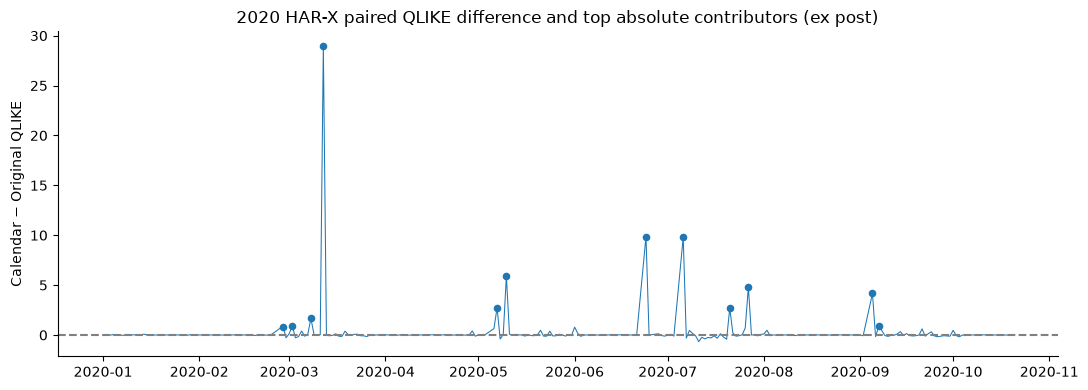

In [192]:
# VII.1 — 2019-only expanded Ridge selection + paired 2020 extreme-contributor diagnostics.
_vii_alpha=_harx_grid_df.copy()
assert len(_vii_alpha)==2*15 and _vii_alpha.alpha.max()==1e5
_vii_best=(_vii_alpha.sort_values(['feature_set','2019_QLIKE','alpha'])
                   .groupby('feature_set',as_index=False).first())
_vii_top=_miss.sort_values('calendar_minus_original_QLIKE',ascending=False).copy()
_vii_n=len(_vii_top); assert _vii_n==284 and _vii_top.date.is_unique
_vii_trim=[]
for _label,_take in [('all',0),('drop_largest_absolute_1',1),('drop_largest_absolute_3',3),
                     ('drop_largest_absolute_5',5),('drop_largest_absolute_10',10)]:
    _t=_miss.copy()
    if _take:
        _drop=_t.calendar_minus_original_QLIKE.abs().nlargest(_take).index
        _t=_t.drop(index=_drop)
    _vii_trim.append({'subset':_label,'n':len(_t),
       'calendar_minus_original_QLIKE_mean':float(_t.calendar_minus_original_QLIKE.mean()),
       'calendar_better_share':float((_t.calendar_minus_original_QLIKE<0).mean()),
       'posthoc_exclusion':bool(_take)})
_vii_march=_miss.loc[~_miss.date.dt.to_period('M').eq(pd.Period('2020-03'))]
_vii_trim.append({'subset':'exclude_March_2020','n':len(_vii_march),
  'calendar_minus_original_QLIKE_mean':float(_vii_march.calendar_minus_original_QLIKE.mean()),
  'calendar_better_share':float((_vii_march.calendar_minus_original_QLIKE<0).mean()),
  'posthoc_exclusion':True})
_vii_trim=pd.DataFrame(_vii_trim)
_vii_ci=[]
for _block in (5,10,20,30):
    _ci=moving_block_ci(_miss.calendar_minus_original_QLIKE.to_numpy(dtype=float),
                        block=_block,reps=1500,seed=SEED+71000+_block)
    _vii_ci.append({'block':_block,'n':len(_miss),'paired_mean':float(_miss.calendar_minus_original_QLIKE.mean()),
         'CI95_low':float(_ci[0]),'CI95_high':float(_ci[1]),'retrospective':True})
_vii_ci=pd.DataFrame(_vii_ci)
_vii_extremes=(_miss.assign(absolute_contribution=lambda x:x.calendar_minus_original_QLIKE.abs())
    .nlargest(30,'absolute_contribution')[[ 'date','observed','original_HARX',
        'calendar_imputed_HARX','calendar_minus_original_QLIKE',
        'absolute_contribution','had_missing_prior30','n_missing_prior30',
        'lagged_abs_return_pct','lagged_volume_change_log']])
_vii_best.to_csv(OUT/'submission_HARX_extended_2019_alpha_selection.csv',index=False)
_vii_trim.to_csv(OUT/'submission_HARX_extreme_loss_exclusion_sensitivity.csv',index=False)
_vii_ci.to_csv(OUT/'submission_HARX_block_CI_5_10_20_30.csv',index=False)
_vii_extremes.to_csv(OUT/'submission_HARX_top30_loss_contributors.csv',index=False)
assert len(_vii_trim)==6 and len(_vii_ci)==4 and len(_vii_extremes)==30
print('2019-only expanded penalty selection (posthoc sensitivity):')
display(_vii_best.round(5),_vii_trim.round(5),_vii_ci.round(5),_vii_extremes.head(8))
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(_miss.date,_miss.calendar_minus_original_QLIKE,lw=.75)
ax.scatter(_vii_extremes.head(12).date,_vii_extremes.head(12).calendar_minus_original_QLIKE,s=20)
ax.axhline(0,color='gray',ls='--');ax.set(ylabel='Calendar − Original QLIKE',
 title='2020 HAR-X paired QLIKE difference and top absolute contributors (ex post)')
savefig('58_submission_HARX_extreme_event_attribution.png')


### VII.2 — Matched shock dates across volatility and tail-risk models

Use **date-aligned** 2020 events to show large forecast mistakes in both target families. Forecast losses retain their original measurement scales: HAR-X variance QLIKE versus the VaR–ES FZ0 score. Do not sum or compare these values as if they measure the same quantity. Date matches are explanatory only and do not imply one model caused another failure.


In [193]:
# VII.2 — Common-date matched event table; separate, NON-COMPARABLE loss scales.
_vii_joint=(_u_matched_joint.loc[_u_matched_joint.year.eq(2020),
 ['date','model','loss','VaR','ES','exception','FZ0_joint_loss']].copy())
_vii_joint.date=pd.to_datetime(_vii_joint.date).dt.normalize()
assert not _vii_joint[['date','model']].duplicated().any()
_vii_risk_wide=_vii_joint.pivot(index='date',columns='model',values='FZ0_joint_loss')
_vii_risk_wide=_vii_risk_wide.reindex(columns=_rank_models)
_vii_real=_vii_joint.loc[_vii_joint.model.eq('GARCH-FHS'),['date','loss']].set_index('date')
_vii_matched=(_miss.set_index('date')[['observed','original_HARX','calendar_imputed_HARX',
 'calendar_minus_original_QLIKE','n_missing_prior30','lagged_abs_return_pct']]
 .join(_vii_real,how='inner',validate='one_to_one')
 .join(_vii_risk_wide.add_prefix('FZ0__'),how='inner',validate='one_to_one').dropna()
 .sort_index())
_vii_matched['abs_HARX_QLIKE_diff']=_vii_matched.calendar_minus_original_QLIKE.abs()
_vii_matched['cross_model_mean_FZ0']=_vii_matched[[f'FZ0__{m}' for m in _rank_models]].mean(axis=1)
_vii_matched['rank_loss_ex_post']=_vii_matched.loss.rank(ascending=False,method='min')
_vii_matched['rank_HARX_ex_post']=_vii_matched.abs_HARX_QLIKE_diff.rank(ascending=False,method='min')
_vii_matched.to_csv(OUT/'submission_2020_matched_HARX_tail_risk_failure_days.csv')
_vii_extreme_join=_vii_matched.sort_values('abs_HARX_QLIKE_diff',ascending=False).head(15)
_vii_extreme_join.to_csv(OUT/'submission_2020_largest_HARX_event_risk_context.csv')
assert len(_vii_matched)>=200 and _vii_matched.index.is_unique
print('2020 matched HAR-X and FZ0 dates:',len(_vii_matched))
display(_vii_extreme_join[['loss','observed','calendar_minus_original_QLIKE',
 'n_missing_prior30','rank_loss_ex_post','cross_model_mean_FZ0']].round(3))


2020 matched HAR-X and FZ0 dates: 279


,loss,observed,calendar_minus_original_QLIKE,n_missing_prior30,rank_loss_ex_post,cross_model_mean_FZ0
date,,,,,,
2020-03-12,46.473,863.965,28.953,1.0,1.0,98.772
2020-05-10,9.134,64.428,5.912,1.0,3.0,8.377
2020-07-27,-10.401,62.568,4.816,1.0,276.0,1.434
2020-05-07,-7.108,28.810,2.743,1.0,271.0,1.858
2020-07-21,-2.273,2.786,2.688,2.0,230.0,1.345
2020-03-08,9.430,32.653,1.657,1.0,2.0,16.484
2020-03-02,-3.525,7.157,0.894,1.0,248.0,1.542
2020-09-07,-0.864,8.146,0.857,1.0,175.0,1.654
2020-02-28,1.284,7.547,0.852,1.0,59.0,1.633


### VII.3 — Conditional VaR–ES evidence by **previsible** volatility state

Regime thresholds are fitted only on data through 2018, with lagged 30-observation volatility; they do not inspect the target-day return. Report exact binomial intervals for 5% VaR coverage (the conventional interval assumes independent Bernoulli violations; clustered returns can invalidate that assumption), empirical ES-tail exceedance severity, and FZ0 together. **Tail loss severity is descriptive and is not an ES regression backtest.** The R ES-regression study remains gated behind current-run R evidence. Small expected violation counts are explicitly labeled as low power.


Conditional coverage 2020 (small-regime samples have wide uncertainty):


,year,regime,model,n,exceptions,target_exception_rate,observed_exception_rate,binomial95_low_descriptive,binomial95_high_descriptive,expected_exceptions_under_nominal,low_expected_exception_count,mean_FZ0,mean_pinball95,conditional_mean_realized_excess_loss_pct,mean_forecast_ES_on_exception_days,mean_realized_loss_on_exception_days,conditional_severity_is_NOT_formal_ES_backtest,regimes_previsible_based_on_pre2019_thresholds,retrospective
12,2020,normal,GARCH-FHS,207,8,0.05,0.0386,0.0168,0.0747,10.35,False,2.1209,0.4663,6.2864,7.0172,10.7937,True,True,True
13,2020,normal,GARCH-filtered EVT,207,8,0.05,0.0386,0.0168,0.0747,10.35,False,2.1206,0.4660,6.3160,6.9956,10.7937,True,True,True
14,2020,normal,Gaussian GARCH,207,8,0.05,0.0386,0.0168,0.0747,10.35,False,2.1886,0.4671,6.2062,5.8074,10.7937,True,True,True
15,2020,normal,Rolling POT,207,4,0.05,0.0193,0.0053,0.0487,10.35,False,2.3265,0.4979,11.5506,8.8313,16.9525,True,True,True
16,2020,elevated,GARCH-FHS,47,2,0.05,0.0426,0.0052,0.1454,2.35,True,1.9926,0.3736,1.5376,9.7118,7.8044,True,True,True
17,2020,elevated,GARCH-filtered EVT,47,2,0.05,0.0426,0.0052,0.1454,2.35,True,1.9913,0.3734,1.5782,9.6821,7.8044,True,True,True
18,2020,elevated,Gaussian GARCH,47,2,0.05,0.0426,0.0052,0.1454,2.35,True,1.9682,0.3742,1.4276,8.0513,7.8044,True,True,True
19,2020,elevated,Rolling POT,47,2,0.05,0.0426,0.0052,0.1454,2.35,True,2.0449,0.3826,1.9325,10.1557,7.8044,True,True,True
20,2020,high,GARCH-FHS,30,1,0.05,0.0333,0.0008,0.1722,1.50,True,2.5750,0.7322,0.5384,8.7318,6.1653,True,True,True
21,2020,high,GARCH-filtered EVT,30,1,0.05,0.0333,0.0008,0.1722,1.50,True,2.5727,0.7292,0.5750,8.7050,6.1653,True,True,True


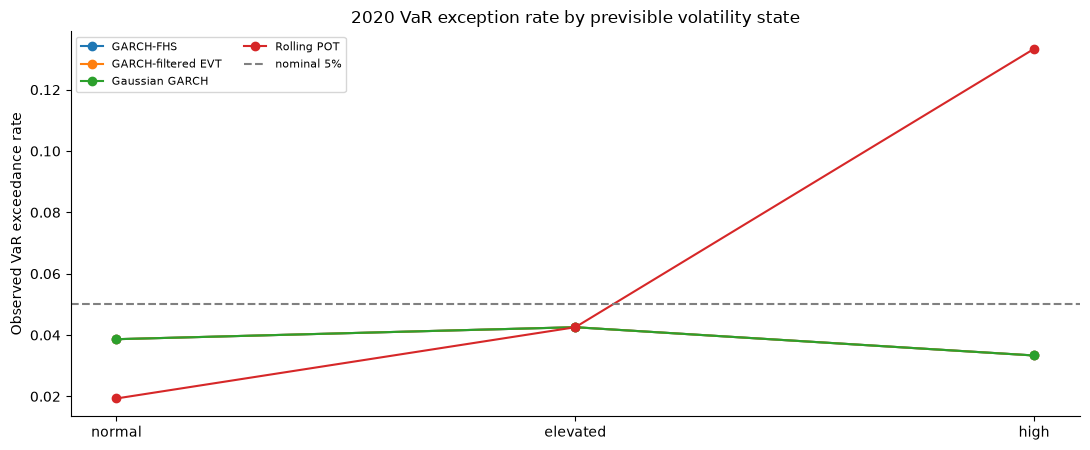

In [194]:
# VII.3 — Regime-conditioned VaR coverage and realized exceedance severity.
from scipy.stats import beta as _vii_beta, chi2 as _vii_chi2

def _vii_clopper(k,n,level=.95):
    assert n>0 and 0<=k<=n
    alpha=1.-level
    low=0. if k==0 else float(_vii_beta.ppf(alpha/2,k,n-k+1))
    high=1. if k==n else float(_vii_beta.ppf(1-alpha/2,k+1,n-k))
    return low,high

_vii_regime=[]
for (_year,_reg,_model),_g in _risk_regime.groupby(['year','previsible_regime','model'],observed=True):
    _g=_g.sort_values('date');_n=len(_g);_k=int(_g.exception.sum())
    _lo,_hi=_vii_clopper(_k,_n)
    _ex=_g.loc[_g.exception].copy()
    _sev=(_ex.loss-_ex.VaR).clip(lower=0)
    _vii_regime.append({'year':int(_year),'regime':str(_reg),'model':str(_model),
       'n':_n,'exceptions':_k,'target_exception_rate':.05,'observed_exception_rate':_k/_n,
       'binomial95_low_descriptive':_lo,'binomial95_high_descriptive':_hi,
       'expected_exceptions_under_nominal':float(.05*_n),
       'low_expected_exception_count':bool(.05*_n<10),
       'mean_FZ0':float(_g.FZ0_joint_loss.mean()),
       'mean_pinball95':float(_g.pinball95.mean()),
       'conditional_mean_realized_excess_loss_pct':float(_sev.mean()) if _k else np.nan,
       'mean_forecast_ES_on_exception_days':float(_ex.ES.mean()) if _k else np.nan,
       'mean_realized_loss_on_exception_days':float(_ex.loss.mean()) if _k else np.nan,
       'conditional_severity_is_NOT_formal_ES_backtest':True,
       'regimes_previsible_based_on_pre2019_thresholds':True,'retrospective':True})
_vii_regime=pd.DataFrame(_vii_regime)
_vii_regime.to_csv(OUT/'submission_risk_regime_VaR_ES_coverage_uncertainty.csv',index=False)
assert not _vii_regime[['year','regime','model']].duplicated().any()
assert _vii_regime.observed_exception_rate.between(0,1).all()
print('Conditional coverage 2020 (small-regime samples have wide uncertainty):')
display(_vii_regime.loc[_vii_regime.year.eq(2020)].round(4))
fig,ax=plt.subplots(figsize=(11,4.6))
_p=_vii_regime.loc[_vii_regime.year.eq(2020)].copy()
for _nm,_grp in _p.groupby('model'):
    _grp=_grp.set_index('regime').reindex(['normal','elevated','high'])
    ax.plot(['normal','elevated','high'],_grp.observed_exception_rate.to_numpy(),marker='o',label=_nm)
ax.axhline(.05,ls='--',color='gray',label='nominal 5%')
ax.set(ylabel='Observed VaR exceedance rate',title='2020 VaR exception rate by previsible volatility state')
ax.legend(fontsize=8,ncol=2)
savefig('59_submission_previsible_VaR_ES_conditional_coverage.png')


### VII.4 — MCS-style familywise elimination with block sensitivity

Model Confidence Set (MCS) is a useful framework for avoiding an overconfident single winner. Below is a **transparent, MCS-inspired range-test implementation** using paired, centered circular-block resampling, studentized pairwise mean losses and sequential worst-mean elimination. Since it is not a validated official MCS package implementation and 2020 has been repeatedly inspected, label these outputs **exploratory**; do not present membership as confirmatory model selection. Sensitivity across block lengths 5, 10 and 20 is reported.


In [195]:
# VII.4 — Approximate MCS-type Tmax range procedure; not an official certified MCS.
from itertools import combinations as _vii_combinations

def submission_mcs_style(loss_df,block=10,reps=800,alpha=.10,seed=2026):
    """Exploratory centered circular-block sequential elimination on paired finite losses."""
    vals=loss_df.to_numpy(dtype=float)
    if vals.ndim!=2 or len(vals)<30 or vals.shape[1]<2 or not np.isfinite(vals).all():
        raise ValueError('Need finite paired rows for >=2 models and >=30 dates')
    n,m=vals.shape; rng=np.random.default_rng(seed); keep=list(range(m)); log=[]
    # Same bootstrap indices for all forecasts preserve cross-model date matching.
    bix=np.stack([circular_block_sample(n,block,rng) for _ in range(reps)])
    centered=vals-vals.mean(axis=0)
    bootmean=centered[bix].mean(axis=1)
    for step in range(m-1):
        pairs=list(_vii_combinations(keep,2)); means=vals[:,keep].mean(axis=0)
        obs=np.array([vals[:,a].mean()-vals[:,b].mean() for a,b in pairs])
        boot=np.column_stack([bootmean[:,a]-bootmean[:,b] for a,b in pairs])
        scale=np.maximum(boot.std(axis=0,ddof=1),1e-10)
        t_obs=float(np.max(np.abs(obs)/scale))
        t_boot=np.max(np.abs(boot)/scale,axis=1)
        p=float((1+np.sum(t_boot>=t_obs))/(reps+1))
        rejected=p<alpha
        removed=None
        if rejected:
            removed=loss_df.columns[keep[int(np.argmax(means))]]
        log.append({'step':step,'n_models':len(keep),'models':';'.join(loss_df.columns[keep]),
          'range_tmax':t_obs,'bootstrap_p':p,'reject_equal_predictive_ability':rejected,
          'removed_worst_average_loss':removed or '', 'remaining_before_step':len(keep)})
        if not rejected:break
        keep.remove(next(i for i in keep if loss_df.columns[i]==removed))
    return list(loss_df.columns[keep]),pd.DataFrame(log)

_vii_mcs_rows=[];_vii_mcs_steps=[]
for _year in (2019,2020):
    _panel=_u_pivot.loc[_u_pivot.index.year==_year,_rank_models].dropna().sort_index()
    for _block in (5,10,20):
        _survive,_trace=submission_mcs_style(_panel,block=_block,reps=800,alpha=.10,
                                          seed=SEED+_year*11+_block)
        _vii_mcs_rows.append({'year':_year,'block':_block,'n':len(_panel),
         'exploratory_survivor_set':';'.join(_survive),'size':len(_survive),
         'MCS_style_not_official_MCS':True,'retrospective':True})
        _trace.insert(0,'block',_block);_trace.insert(0,'year',_year)
        _vii_mcs_steps.append(_trace)
_vii_mcs=pd.DataFrame(_vii_mcs_rows)
_vii_mcs_steps=pd.concat(_vii_mcs_steps,ignore_index=True)
_vii_mcs.to_csv(OUT/'submission_exploratory_MCS_style_block_sensitivity.csv',index=False)
_vii_mcs_steps.to_csv(OUT/'submission_exploratory_MCS_style_elimination_trace.csv',index=False)
assert len(_vii_mcs)==6 and _vii_mcs['size'].between(1,4).all()
display(_vii_mcs,_vii_mcs_steps.loc[_vii_mcs_steps.year.eq(2020)].round(4))


,year,block,n,exploratory_survivor_set,size,MCS_style_not_official_MCS,retrospective
0,2019,5,363,GARCH-FHS;GARCH-filtered EVT;Gaussian GARCH;Ro...,4,True,True
1,2019,10,363,GARCH-FHS;GARCH-filtered EVT;Gaussian GARCH;Ro...,4,True,True
2,2019,20,363,GARCH-FHS;GARCH-filtered EVT;Gaussian GARCH;Ro...,4,True,True
3,2020,5,284,GARCH-FHS;GARCH-filtered EVT;Gaussian GARCH,3,True,True
4,2020,10,284,GARCH-FHS;GARCH-filtered EVT;Gaussian GARCH,3,True,True
5,2020,20,284,GARCH-FHS;GARCH-filtered EVT;Gaussian GARCH;Ro...,4,True,True


,year,block,step,n_models,models,range_tmax,bootstrap_p,reject_equal_predictive_ability,removed_worst_average_loss,remaining_before_step
3,2020,5,0,4,GARCH-FHS;GARCH-filtered EVT;Gaussian GARCH;Ro...,2.1998,0.0749,True,Rolling POT,4
4,2020,5,1,3,GARCH-FHS;GARCH-filtered EVT;Gaussian GARCH,0.6372,0.7391,False,,3
5,2020,10,0,4,GARCH-FHS;GARCH-filtered EVT;Gaussian GARCH;Ro...,2.1205,0.0762,True,Rolling POT,4
6,2020,10,1,3,GARCH-FHS;GARCH-filtered EVT;Gaussian GARCH,0.6047,0.7478,False,,3
7,2020,20,0,4,GARCH-FHS;GARCH-filtered EVT;Gaussian GARCH;Ro...,1.7907,0.1623,False,,4


### VII.5 — Structural breaks × TVP-VAR / QVAR / DCC timeline (R-verified only)

Exploratory event/timeline overlays are available **only** if the five-model R provenance gate passed on the current Python execution and dated breakpoint artifacts can be parsed without guessing. Otherwise a machine-readable `SKIPPED` report is produced. Descriptive alignment does not support causal spillover claims.


In [196]:
# VII.5 — Do not guess breakpoint date schema or substitute previous-run R outputs.
_vii_break={'python_run_id':RUN_ID,'status':'SKIPPED_NO_CURRENT_RUN_R_OR_DAILY_LINK',
            'breakpoint_source':None,'break_dates':[],'n_matched':0,'causal_claim':False}
_vii_break_dates=[]
if _R_FIVE_VALIDATED and _connect_status.get('status')=='LINKED_DAILY_SERIES' and len(_connect_daily)>=30:
    _vii_break['status']='SKIPPED_BREAKPOINT_DATES_NOT_READABLE'
    _breakfiles=[]
    for _pattern in ('*breakpoint*.csv','*break_dates*.csv','*bai_perron*.csv'):
        _breakfiles.extend(sorted(_r_current_results.glob(_pattern)))
    for _bfile in dict.fromkeys(_breakfiles):
        _bb=pd.read_csv(_bfile)
        _lower={str(k).strip().lower():k for k in _bb.columns}
        _datecol=next((_lower[k] for k in ('break_date','breakpoint_date','date') if k in _lower),None)
        if _datecol is None:continue
        _vii_dt=pd.to_datetime(_bb[_datecol],errors='coerce').dropna().dt.normalize()
        if len(_vii_dt)==0:continue
        _vii_break_dates=sorted(set(_vii_dt.tolist()))
        _vii_break.update({'status':'DATED_R_BREAKPOINTS_ALIGNED_DESCRIPTIVE',
            'breakpoint_source':_bfile.name,'break_dates':[x.date().isoformat() for x in _vii_break_dates],
            'n_matched':len(_connect_daily)})
        break
    if _vii_break_dates:
        fig,axs=plt.subplots(4,1,sharex=True,figsize=(11,9))
        _names=['qvar_lower_tail_TCI','tvpvar_TCI','DCC_BTC_ETH_prior','BTC_prior_30d_vol']
        for _ax,_name in zip(axs,_names):
            _ax.plot(_connect_daily.date,_connect_daily[_name],lw=.75)
            for _date in _vii_break_dates:
                if _connect_daily.date.min()<=_date<=_connect_daily.date.max():
                    _ax.axvline(_date,alpha=.25,color='gray',ls='--')
            _ax.set_ylabel(_name,fontsize=8)
        axs[0].set_title('Current-run R break dates over previsible/dated connectedness measures')
        savefig('60_submission_R_breakpoints_QVAR_TVPVAR_DCC.png')
(OUT/'submission_R_structural_break_connectedness_status.json').write_text(
  json.dumps(_vii_break,indent=2),encoding='utf-8')
print('Structural-break / connectedness status:',_vii_break['status'])


Structural-break / connectedness status: SKIPPED_NO_CURRENT_RUN_R_OR_DAILY_LINK


### VII.6 — 2021+ independent scoring: distinguish measurement from evidence

A 90-row minimum is **only a descriptive file-scoring threshold**. It is not proof of out-of-period generalization, independence, adequate tail exceedances, or auditable forecast generation. Report the exact external data hash, common dates, coverage uncertainty, loss gap versus the prior-only rolling baseline, and separate evidence levels: `NOT_PROVIDED`, `DATA_SCORED`, `FORECAST_SOURCE_NOT_CODE_AUDITED`, `STATISTICAL_POWER_LIMITED`, or `ELIGIBLE_FOR_REVIEW`. The thresholds in the script are **operational review guidelines**, not automatic statistical confirmation.


In [197]:
# VII.6 — Evidence-level status ledger; no synthetic 2021 observations / forecasts.
_vii_future={'python_run_id':RUN_ID,'historic_sha256':SOURCE_CSV_SHA256,
 'HARX_source_status':_external_report['status'],'risk_forecasts_status':_risk_external_status['status'],
 'data_scored':False,'forecast_source_code_verified':False,
 'statistical_evidence_sufficient':False,'generalization_proved':False,
 'quality_gates_are_operational_not_confirmatory':True,
 'risk_score_forecast_asof_fields_are_SELF_DECLARED':True}
_vii_future_cal=[]
if _external_report['status']=='DATA_SCORED_DESCRIPTIVE':
    _s=pd.read_csv(OUT/'final_2021plus_frozen_HARX_summary.csv')
    _vii_future['data_scored']=True
    _vii_future['n_scored_dates']=int(_s.n.min())
    _vii_future['external_OHLCV_SHA256']=_external_report.get('external_sha256')
    for _,r in _s.iterrows():
        _nom=1.-float(r['quantile']);_n=int(r['n']);_k=int(r.exception_count)
        _l,_h=_vii_clopper(_k,_n)
        _vii_future_cal.append({'quantile':float(r['quantile']),'nominal_exception_rate':_nom,
            'n':_n,'exceptions':_k,'exact_binomial95_low_descriptive':_l,
            'exact_binomial95_high_descriptive':_h,
            'frozen_minus_baseline_pinball':float(r['frozen_minus_rolling180_pinball']),
            'block_CI_low':float(r['block_95_CI_low']),'block_CI_high':float(r['block_95_CI_high']),
            'n_expected_exceptions_nominal':_n*_nom,'historically_frozen':True})
    _vii_future['HARX_review_eligible_365_days']=bool(_s.n.min()>=365)
    _vii_future['HARX_at_least_10_nominal_expected_exceptions']=bool(
       all((r['n']*(1-r['quantile']))>=10 for _,r in _s.iterrows()))
else:
    _vii_future['HARX_review_eligible_365_days']=False
    _vii_future['HARX_at_least_10_nominal_expected_exceptions']=False
if _risk_external_status['status']=='USER_SUPPLIED_FORECASTS_SCORED_NOT_CODE_AUDITED':
    _rs=pd.read_csv(OUT/'final_2021plus_frozen_risk_models_summary.csv')
    _vii_future['risk_forecasts_data_scored']=True
    _vii_future['risk_forecast_csv_sha256']=_risk_external_status.get('forecast_sha256')
    _vii_future['risk_min_common_dates']=int(_rs.n.min())
    _vii_future['risk_expected_violations_nominal']=float(.05*_rs.n.min())
    _vii_future['risk_at_least_10_nominal_expected_exceptions']=bool(.05*_rs.n.min()>=10)
    _vii_future['risk_forecast_code_audit']='NOT_PERFORMED'
else:
    _vii_future['risk_forecasts_data_scored']=False
    _vii_future['risk_forecast_code_audit']='NOT_PERFORMED'
_vii_future['evidence_grade']='DATA_SCORED_PROVENANCE_UNVERIFIED' if _vii_future['data_scored'] else 'NOT_PROVIDED_OR_INSUFFICIENT'
_vii_future['statistical_review_eligible_not_proven']=bool(
    _vii_future['HARX_review_eligible_365_days'] and
    _vii_future['HARX_at_least_10_nominal_expected_exceptions'])
_vii_future_cal=pd.DataFrame(_vii_future_cal,columns=['quantile','nominal_exception_rate','n',
    'exceptions','exact_binomial95_low_descriptive','exact_binomial95_high_descriptive',
    'frozen_minus_baseline_pinball','block_CI_low','block_CI_high',
    'n_expected_exceptions_nominal','historically_frozen'])
_vii_future_cal.to_csv(OUT/'submission_external_2021plus_coverage_evidence.csv',index=False)
(OUT/'submission_external_2021plus_evidence_ledger.json').write_text(json.dumps(_vii_future,indent=2),encoding='utf-8')
print('External evidence grade:',_vii_future['evidence_grade'])
if len(_vii_future_cal): display(_vii_future_cal.round(5))


External evidence grade: DATA_SCORED_PROVENANCE_UNVERIFIED


,quantile,nominal_exception_rate,n,exceptions,exact_binomial95_low_descriptive,exact_binomial95_high_descriptive,frozen_minus_baseline_pinball,block_CI_low,block_CI_high,n_expected_exceptions_nominal,historically_frozen
0,0.90,0.10,2090,218,0.09152,0.11821,-0.56765,-0.90338,-0.30568,209.0,True
1,0.95,0.05,2090,109,0.04302,0.06257,-0.59142,-0.85451,-0.36064,104.5,True


### VII.7 — Optional CARE research protocol, with implementation explicitly deferred

**CARE / autoregressive expectiles** can be a scientifically distinct **future** benchmark against CAViaR and filtered VaR–ES families, but estimating it now on the repeatedly-inspected 2020 sample would constitute further model selection on the evaluation period. **No CARE estimate, VaR/ES forecast, convergence claim, or backtest is created by this release.** Before any fitting, preregister expectile-to-VaR/ES calibration, stationarity constraints, optimization tolerances, frozen training cutoffs, uniform target losses, and held-out data. This cell creates a reproducible model inclusion protocol and keeps the research boundary visible.


In [198]:
# VII.7 — Model inclusion decision is intentionally explicit; no fake CARE fit.
_vii_care={'candidate':'Conditional Autoregressive Expectile (CARE)',
  'status':'PROTOCOL_ONLY_NOT_IMPLEMENTED','model_fitted':False,'results':None,
  'baseline_models':['CAViaR','GARCH-filtered EVT','GARCH-FHS'],
  'target':'identical VaR/ES loss levels and matched future dates',
  'entry_criteria':['a prespecified expectile-to-tail-risk mapping',
    'predefined optimizer / convergence checks','independent scoring dates',
    'complete source-code and model-freeze hashes',
    'prior-only rolling benchmark and interval uncertainty'],
  'no_use_of_examined_2020_as_confirmatory_holdout':True,'run_id':RUN_ID}
(OUT/'submission_CARE_model_protocol.json').write_text(json.dumps(_vii_care,indent=2),encoding='utf-8')
print('CARE:',_vii_care['status'])


CARE: PROTOCOL_ONLY_NOT_IMPLEMENTED


### VII.8 — Evidence checklist and release-only gates

The final release cell below is intentionally last. It checks the new outputs and writes a **fresh per-run evidence manifest**; Python-only, current-run Python+R and 2021+ source/evidence statuses are kept distinct. A historic `LATEST_FULL_RUN.json` may point to an older full run: **it must never be interpreted as the current run unless its `run_id` matches `LATEST_RUN.json`.**


### VI.8 — Final release: separate Python, R, and 2021+ gates

This is the only location that may publish latest-run pointers. `LATEST_PYTHON_RUN.json` denotes all required Python cells completing; `LATEST_FULL_RUN.json` only denotes additionally verified **five current R models**. The legacy `LATEST_RUN.json` points to the most recent current Python run **with explicit non-full status**, not a stale R-success entry. External 2021+ validation has a third independent flag. Original notebook outputs are archived and edited code must be executed on real data.


### Submission/research boundary checklist

- Historical analysis: 2019 development and repeatedly viewed 2020 results are **retrospective**; no clean 2020 confirmatory inference.
- Missingness attribution: feature ablations and penalization are refit using training/2019 validation, with matching 2020 dates. Not a causal missingness experiment.
- Tail ranking: block-sensitivity, familywise comparisons and hindsight stress exclusions are descriptive; previsible-volatility regime comparisons are reported separately.
- ACI: overlapping 1/3/7/14-observation event windows clustered by overlap, with leave-one-cluster-out; if fewer than 3 clusters, interval unavailable.
- R: five successful R scripts tied to the **same** run ID and historical source hashes required for full status. The GARCH diagnostic helper cannot silently fix an unprovided external script.
- 2021+ external: future source supplied via `BITCOIN_FUTURE_OHLCV_CSV` with uninterrupted 2020-10-21 onward bridge; score from 2021-01-01, compare frozen model with prior-only rolling-180 benchmark. Four tail-risk families can be scored only if separately generated cutoff-audited forecast files are supplied; otherwise remain externally unvalidated.
- Optional CARE: intentionally deferred; no fitted model or result is claimed.
- Saved outputs: earlier figures/tables are archived results; new/edited code may have blank execution outputs and needs **Restart Kernel → Run All** with genuine project assets before submission.

- MCS-style and shocks are exploratory due to repeated 2020 analysis. CARE is protocol only. Previsible state VaR intervals rely on a Bernoulli approximation and are not an ES backtest. A 90-date external file is only scored, not statistically validated.


## Part VIII — Final verification hardening and external research gates

**Implementation vs inference:** all results above based on saved historical executions remain *retrospective*. The new cells below need a **new full kernel execution**. ESR uses R `esback`, official MCS uses R `MCS`, and a cross-vendor OHLCV comparison needs a second actual dataset. None is assumed to have run. No 2021–2026 market data or R results are invented. Only previously available information may be used for forecasting; after-the-fact losses are for diagnostics, not forecast inputs.

1. Verify multiple-start GARCH convergence without replacing the original historical forecasts.
2. Offer a distinct data-vendor OHLCV audit (optional actual file).
3. Produce current-run inputs for formal Auxiliary ESR and official MCS, with opt-in R execution.
4. Quantify extreme-day joint failures and caveat ACI low event counts.
5. Separate external descriptive scores from true forecast-source verification and avoid 2026-data claims.
6. Gate the release pointer on actual fresh outputs.


### VIII.1 — GARCH multistart estimation audit and strict optimizer convergence


In [199]:
# Original GARCH QMLE now stops on non-convergence. This sensitivity audit does NOT
# overwrite original fitted forecasts or silently select the best in-sample result.
from scipy.optimize import minimize as _viii_minimize

def audit_garch_multistart(training_pct, seed=42):
    y=np.asarray(training_pct,dtype=float)
    if len(y)<100 or not np.isfinite(y).all():
        raise ValueError('Need >=100 finite prior-only percentage returns')
    mu=float(y.mean()); e2=(y-mu)**2; uv=max(float(np.var(y)),1e-6)
    def loss(theta):
        omega,alpha,beta=garch_transform(theta)
        v=garch_variance_path(e2,omega,alpha,beta,uv)
        return float(.5*np.mean(np.log(v)+e2/v))
    starts=[np.array([np.log(uv*.05),-2.5,2.0]),
            np.array([np.log(uv*.1),-1.,1.]),
            np.array([np.log(uv*.02),-4.,3.]),
            np.array([np.log(uv*.2),0.,0.])]
    rows=[]
    for ix,start in enumerate(starts):
        result=_viii_minimize(loss,start,method='L-BFGS-B',
             bounds=[(-12,8),(-10,8),(-10,10)],options={'maxiter':800,'ftol':1e-11})
        omega,alpha,beta=garch_transform(result.x)
        rows.append({'start':ix,'converged':bool(result.success) and np.isfinite(result.fun),
          'objective':float(result.fun),'omega':omega,'alpha':alpha,'beta':beta,
          'stationary':bool(alpha+beta<1),'message':str(result.message)})
    df=pd.DataFrame(rows)
    good=df.loc[df.converged & df.stationary].copy()
    if good.empty: raise RuntimeError('All GARCH multistart attempts failed')
    objspread=float(good.objective.max()-good.objective.min())
    best=float(good.objective.min())
    summary={'n':len(y),'converged_starts':len(good),'total_starts':len(starts),
     'best_objective':best,'objective_spread_converged':objspread,
     'stable_objective_within_1e_4':bool(objspread<=1e-4),
     'refitted_models_are_a_sensitivity_audit_not_out_of_sample_fits':True}
    return df,summary

_garch_audits=[]
for _label,_date in [('fit_to_2018','2018-12-31'),('fit_to_2019','2019-12-31')]:
    _details,_summary=audit_garch_multistart(vol_s.loc[:_date].to_numpy())
    _details.insert(0,'fit_cutoff',_label)
    _details.to_csv(OUT/('hardened_GARCH_multistart_'+_label+'.csv'),index=False)
    _garch_audits.append({'fit_cutoff':_label,**_summary})
_garch_audit_df=pd.DataFrame(_garch_audits)
_garch_audit_df.to_csv(OUT/'hardened_GARCH_multistart_summary.csv',index=False)
print('GARCH multistart (sensitivity, not refit of 2020 results):')
display(_garch_audit_df)


GARCH multistart (sensitivity, not refit of 2020 results):


,fit_cutoff,n,converged_starts,total_starts,best_objective,objective_spread_converged,stable_objective_within_1e_4,refitted_models_are_a_sensitivity_audit_not_out_of_sample_fits
0,fit_to_2018,1168,4,4,1.756666,5.728664e-09,True,True
1,fit_to_2019,1531,4,4,1.757267,1.575643e-09,True,True


### VIII.2 — Independent provider data audit (optional, no automatic substitution)

Supply `BITCOIN_SECONDARY_BTC_OHLCV_CSV` with columns `date,open,high,low,close,volume`. For reproducibility, preserve provider, timezone, UTC candle cut, currency, and download date in the companion metadata. If missing, this section records `NOT_PROVIDED` and never invents comparison results.


In [200]:
_secondary_path_text=os.environ.get('BITCOIN_SECONDARY_BTC_OHLCV_CSV','').strip()
_secondary_audit={'run_id':RUN_ID,'status':'NOT_PROVIDED','historical_input_sha256':SOURCE_CSV_SHA256,
 'independent_provider_identity_verified':False,'utc_daily_bar_definition_verified':False}
if _secondary_path_text:
    _sec_path=Path(_secondary_path_text).expanduser().resolve()
    if not _sec_path.is_file():raise FileNotFoundError(str(_sec_path))
    _sec=pd.read_csv(_sec_path)
    _cols=['date','open','high','low','close','volume']
    if not set(_cols).issubset(_sec.columns):raise ValueError('Secondary BTC OHLCV CSV requires '+repr(_cols))
    _sec=_sec[_cols].copy();_sec['date']=pd.to_datetime(_sec.date,errors='raise').dt.normalize()
    for _col in _cols[1:]:_sec[_col]=pd.to_numeric(_sec[_col],errors='raise')
    if _sec.date.duplicated().any():raise ValueError('Secondary provider duplicate days')
    if (not np.isfinite(_sec[_cols[1:]].to_numpy()).all() or
        (_sec[['open','high','low','close']]<=0).any().any() or
        (_sec.high<_sec[['open','low','close']].max(axis=1)).any() or
        (_sec.low>_sec[['open','high','close']].min(axis=1)).any()):
        raise ValueError('Nonfinite / nonpositive / inconsistent secondary OHLC')
    _base_btc=_raw_btc[_cols].copy()
    _base_btc['date']=pd.to_datetime(_base_btc.date).dt.normalize()
    _old=_base_btc.loc[_base_btc.date.between(START,END)].copy()
    _new=_sec.loc[_sec.date.between(START,END)].copy()
    _paired=_old.merge(_new,on='date',how='outer',suffixes=('_original','_secondary'),indicator=True,
                       validate='one_to_one').sort_values('date')
    _paired['matched_day']=_paired._merge.eq('both')
    for _col in ['open','high','low','close','volume']:
        _paired[_col+'_pct_difference']=100*(_paired[_col+'_secondary']-_paired[_col+'_original'])/(_paired[_col+'_original'].replace(0,np.nan))
    _paired.to_csv(OUT/'hardened_secondary_OHLCV_daily_comparison.csv',index=False)
    _matched=_paired.loc[_paired.matched_day].copy()
    _secondary_audit.update({'status':'COMPUTED_PROVIDER_PROVENANCE_UNVERIFIED',
       'secondary_csv_sha256':hashlib.sha256(_sec_path.read_bytes()).hexdigest(),
       'original_days':len(_old),'secondary_days':len(_new),'matched_days':len(_matched),
       'original_only_days':int(_paired._merge.eq('left_only').sum()),
       'secondary_only_days':int(_paired._merge.eq('right_only').sum()),
       'max_absolute_close_pct_difference':float(_matched.close_pct_difference.abs().max()) if len(_matched) else None,
       'note':'Exploratory date/price alignment only; timezone and vendor provenance require human audit'})
(OUT/'hardened_secondary_OHLCV_audit_status.json').write_text(json.dumps(_secondary_audit,indent=2),encoding='utf-8')
print('Secondary-source audit:',_secondary_audit['status'])


Secondary-source audit: COMPUTED_PROVIDER_PROVENANCE_UNVERIFIED


### VIII.3 — Actual ESR and official MCS: current-run data + external R verifier

The R companion script calls `esback::esr_backtest` (Auxiliary ESR, lower-tail returns `-loss`/`-VaR`/`-ES`, α = 0.05) and `MCS::MCSprocedure` (Tmax, block lengths 5/10/20). The original four-model 2019/2020 historical sample is still a retrospective comparison. ESR may have poor power when VaR exceptions are scarce. **R verification runs only if** `BITCOIN_RUN_FORMAL_ES_MCS=1`; absence, missing packages, or script failure is recorded and never treated as success.


In [201]:
import shutil,subprocess
_formal_r_script=Path(os.environ.get('BITCOIN_FORMAL_R_SCRIPT',str(PROJECT_DIR/'BTC_2026_FORMAL_ESR_MCS.R')))
_formal_r_daily=_u_matched_joint[['date','year','model','loss','VaR','ES']].copy().sort_values(['date','model'])
assert not _formal_r_daily[['date','model']].duplicated().any()
assert _formal_r_daily[['loss','VaR','ES']].notna().all().all()
_formal_r_daily.to_csv(OUT/'hardened_official_ESR_R_input.csv',index=False)
_formal_r_loss=_u_pivot[_rank_models].copy().dropna().sort_index().reset_index()
_formal_r_loss=_formal_r_loss.rename(columns={_formal_r_loss.columns[0]:'date'})
_formal_r_loss.insert(1,'year',pd.to_datetime(_formal_r_loss.date).dt.year)
assert len(_formal_r_loss)>200 and _formal_r_loss[_rank_models].notna().all().all()
_formal_r_loss.to_csv(OUT/'hardened_official_MCS_R_input.csv',index=False)
_formal_status={'run_id':RUN_ID,'status':'NOT_EXECUTED_OPT_IN_REQUIRED','formal_R_script':str(_formal_r_script),
    'ESR_input':'hardened_official_ESR_R_input.csv','MCS_input':'hardened_official_MCS_R_input.csv',
    'official_ESR_computed':False,'official_MCS_computed':False,
    'historical_retrospective_not_independent_forecast_validation':True}
if os.environ.get('BITCOIN_RUN_FORMAL_ES_MCS','0').strip().lower() in ('1','true','yes','on'):
    _bin=os.environ.get('BITCOIN_RSCRIPT') or shutil.which('Rscript')
    if not _formal_r_script.is_file():_formal_status['status']='MISSING_FORMAL_R_COMPANION'
    elif not _bin:_formal_status['status']='RSCRIPT_NOT_AVAILABLE'
    else:
        try:
            _formal_r_env=dict(os.environ)
            _formal_r_env['BITCOIN_PYTHON_RUN_ID']=RUN_ID
            _formal_exec=subprocess.run([_bin,str(_formal_r_script),
                    str(OUT/'hardened_official_ESR_R_input.csv'),
                    str(OUT/'hardened_official_MCS_R_input.csv'),str(OUT)],
                    cwd=str(PROJECT_DIR),env=_formal_r_env,text=True,encoding="utf-8",errors="replace",capture_output=True,
                    timeout=1800,check=False)
            (OUT/'hardened_formal_R_stdout.log').write_text(_formal_exec.stdout,encoding='utf-8')
            (OUT/'hardened_formal_R_stderr.log').write_text(_formal_exec.stderr,encoding='utf-8')
            _formal_status['returncode']=int(_formal_exec.returncode)
            _formal_status['stderr_tail']='\n'.join((_formal_exec.stderr or '').splitlines()[-28:])
            _formal_status['stdout_tail']='\n'.join((_formal_exec.stdout or '').splitlines()[-12:])
            if _formal_exec.returncode:
                print('FORMAL R RETURN CODE:',_formal_exec.returncode)
                print('FORMAL R STDERR (last 28 lines):',_formal_status['stderr_tail'] or '(empty)')
            _formal_status['status']='EXECUTED_RESULTS_REQUIRE_REVIEW' if _formal_exec.returncode==0 else 'R_FAILED_REVIEW_LOGS'
            if True:  # Read partial official output CSVs even when R reports a failure.
                _esr_file=OUT/'official_ESR_auxiliary_summary.csv'
                _mcs_file=OUT/'official_MCS_execution_status.csv'
                if _esr_file.is_file():
                    _esr_check=pd.read_csv(_esr_file)
                    _formal_status['official_ESR_computed']=bool(len(_esr_check)>0 and
                        _esr_check.status.eq('COMPUTED_VALID_PVALUE').all())
                if _mcs_file.is_file():
                    _mcs_check=pd.read_csv(_mcs_file)
                    _formal_status['official_MCS_computed']=bool(len(_mcs_check)>0 and
                        _mcs_check.status.eq('COMPUTED_WITH_SUPERIOR_SET').all())
                if not (_formal_status['official_ESR_computed'] and _formal_status['official_MCS_computed']):
                    _formal_status['status']='PARTIAL_R_TEST_FAILURE_OR_MISSING_OUTPUT'
                if _esr_file.is_file():
                    _formal_status['ESR_diagnostics']=_esr_check.loc[_esr_check.status.ne('COMPUTED_LOW_POWER_POSSIBLE'),
                        ['year','model','status','diagnostic']].to_dict('records')[:20]
                if _mcs_file.is_file():
                    _formal_status['MCS_diagnostics']=_mcs_check.loc[_mcs_check.status.ne('COMPUTED_REVIEW_RDS_TEXT'),
                        ['year','block','status','diagnostic']].to_dict('records')[:20]
        except Exception as exc:
            _formal_status['status']='R_EXCEPTION'
            _formal_status['error']=str(exc)
(OUT/'hardened_ESR_MCS_execution_status.json').write_text(json.dumps(_formal_status,indent=2),encoding='utf-8')
print('Formal ESR + MCS:',_formal_status['status'])
if _formal_status.get('stderr_tail') and _formal_status['status']!='EXECUTED_RESULTS_REQUIRE_REVIEW':
    print('LAST_R_ERROR_LINES:',_formal_status['stderr_tail'][-2200:])


Formal ESR + MCS: EXECUTED_RESULTS_REQUIRE_REVIEW


### VIII.4 — Cross-model extreme-date attribution and small-shock cluster evidence

Different loss functions (HAR-X QLIKE versus VaR–ES FZ0) **cannot be compared numerically**. Only alignment, within-model rankings, and common extreme dates are reported. All extreme-day exclusions are strictly ex post.


In [202]:
_ext=_vii_matched.copy().sort_index()
_risk_cols=[f'FZ0__{m}' for m in _rank_models]
for _name in _risk_cols:
    _ext['rank__'+_name]=_ext[_name].rank(ascending=False,method='min')
_ext['harx_top10']=_ext.abs_HARX_QLIKE_diff.rank(ascending=False,method='min')<=10
_ext['loss_top10']=_ext.loss.rank(ascending=False,method='min')<=10
_ext['risk_any_top10']=False
for _name in _risk_cols:
    _ext['risk_any_top10']=_ext['risk_any_top10']|(_ext['rank__'+_name]<=10)
_ext['joint_top10_flag']=_ext.harx_top10 & (_ext.loss_top10 | _ext.risk_any_top10)
_ext.reset_index().to_csv(OUT/'hardened_cross_model_extreme_dates.csv',index=False)
_ext_summary={'run_id':RUN_ID,'matched_dates':len(_ext),
    'harx_top10_count':int(_ext.harx_top10.sum()),
    'large_harx_and_realized_loss_top10':int((_ext.harx_top10&_ext.loss_top10).sum()),
    'large_harx_and_any_fz0_top10':int((_ext.harx_top10&_ext.risk_any_top10).sum()),
    'joint_top10_dates':[str(d.date()) for d in _ext.index[_ext.joint_top10_flag]],
    'posthoc_selection':True,'loss_scales_not_comparable':True}
(OUT/'hardened_cross_model_extreme_dates_summary.json').write_text(json.dumps(_ext_summary,indent=2),encoding='utf-8')
_aci_event_evidence=_shock_uncert_df[['quantile','horizon','shock_origins',
 'independent_nonoverlap_clusters']].copy()
_aci_event_evidence['exploratory_only']=_aci_event_evidence.independent_nonoverlap_clusters.lt(8)
_aci_event_evidence['insufficient_for_stable_recovery_time']=_aci_event_evidence.independent_nonoverlap_clusters.lt(5)
_aci_event_evidence['recovery_day_inference_authorized']=False
_aci_event_evidence.to_csv(OUT/'hardened_ACI_small_cluster_limitations.csv',index=False)
print('Historical joint extreme days:',_ext_summary['joint_top10_dates'])
display(_aci_event_evidence)


Historical joint extreme days: ['2020-03-08', '2020-03-12', '2020-05-10']


,quantile,horizon,shock_origins,independent_nonoverlap_clusters,exploratory_only,insufficient_for_stable_recovery_time,recovery_day_inference_authorized
0,0.90,1,8,8,False,False,False
1,0.90,3,8,7,True,False,False
2,0.90,7,8,4,True,True,False
3,0.90,14,8,3,True,True,False
4,0.95,1,8,8,False,False,False
5,0.95,3,8,7,True,False,False
6,0.95,7,8,4,True,True,False
7,0.95,14,8,3,True,True,False


### VIII.5 — External evaluation status is not evidence of model provenance

Sufficient scoring dates are an *operational condition*, not scientific proof. The 2021+ supplied data, frozen forecast generation, calendar bridge, loss alignment, prevision chronology, and performance inference require separate verification. No 2026 generalization or CARE fit is claimed.


In [203]:
_external_final_audit={
    'run_id':RUN_ID,'study_data_end':str(END.date()),
    'HARX_descriptive_scoring_min90':bool(_EXTERNAL_2021_SCORED_MIN90),
    'four_risk_models_descriptive_scoring_min90':bool(_EXTERNAL_RISK_2021_SCORED_MIN90),
    'external_OHLCV_data_provided':bool(_future_path_text),
    'risk_forecast_CSV_provided':bool(_risk_forecast_path),
    'independent_source_authenticity_verified':False,
    'risk_forecast_source_code_audited':False,
    'all_model_families_independently_validated':False,
    'CARE_fitted':False,
    'actual_2026_market_data_used':False,
    'evidence_grade':_vii_future.get('evidence_grade'),
    'statistical_evidence_sufficient':bool(_vii_future.get('statistical_evidence_sufficient',False))}
assert not _external_final_audit['all_model_families_independently_validated']
assert not _external_final_audit['risk_forecast_source_code_audited']
(OUT/'hardened_external_forecast_evidence_boundary.json').write_text(
    json.dumps(_external_final_audit,indent=2),encoding='utf-8')
print('External evaluation:',_external_final_audit['evidence_grade'])


External evaluation: DATA_SCORED_PROVENANCE_UNVERIFIED


### VIII.6 — Submission supplement integration and final release caveats

The final `LATEST_RUN.json` is published **only after** these new analytical output files are created and checked. Python validity, R-five-model validity, formal R ESR/MCS status, 2021+ scoring, and independent evidence are separate. Previous `LATEST_FULL_RUN.json` pointers may belong to another execution and must be checked against the current run ID.


In [204]:
_hardened_files=['hardened_GARCH_multistart_fit_to_2018.csv',
 'hardened_GARCH_multistart_fit_to_2019.csv','hardened_GARCH_multistart_summary.csv',
 'hardened_secondary_OHLCV_audit_status.json',
 'hardened_official_ESR_R_input.csv','hardened_official_MCS_R_input.csv',
 'hardened_ESR_MCS_execution_status.json','hardened_cross_model_extreme_dates.csv',
 'hardened_cross_model_extreme_dates_summary.json',
 'hardened_ACI_small_cluster_limitations.csv',
 'hardened_external_forecast_evidence_boundary.json']
assert all((OUT/_f).is_file() and (OUT/_f).stat().st_mtime_ns>=RUN_STARTED_NS
           for _f in _hardened_files)
_hardened_evidence={'run_id':RUN_ID,'status':'PYTHON_SUPPLEMENTS_COMPLETED_ON_CURRENT_RUN',
  'GARCH_all_fits_converged':bool((_garch_audit_df.converged_starts>0).all()),
  'GARCH_all_starts_same_optimum_1e_4':bool(_garch_audit_df.stable_objective_within_1e_4.all()),
  'R_GARCH_verified':bool(_R_FIVE_VALIDATED),
  'R_GARCH_convergence_evidence':_r_garch_fit_status,
  'official_ESR_MCS_status':_formal_status['status'],
  'secondary_dataset_status':_secondary_audit['status'],
  'ACI_recovery_statistically_established':False,
  'external_independent_generalization_established':False,
  'external_CARE_fit_performed':False,
  'new_files_sha256':{f:hashlib.sha256((OUT/f).read_bytes()).hexdigest() for f in _hardened_files},
  'note':'New sections executed this run; this is not 2021–2026 out-of-sample proof'}
(OUT/'HARDENED_CURRENT_RUN_EVIDENCE.json').write_text(json.dumps(_hardened_evidence,indent=2),encoding='utf-8')
print('HARDENED_EVIDENCE:',json.dumps({k:v for k,v in _hardened_evidence.items() if k!='new_files_sha256'},indent=2))


HARDENED_EVIDENCE: {
  "run_id": "20261026T030925_071513Z_ee4a01ed",
  "status": "PYTHON_SUPPLEMENTS_COMPLETED_ON_CURRENT_RUN",
  "GARCH_all_fits_converged": true,
  "GARCH_all_starts_same_optimum_1e_4": true,
  "R_GARCH_verified": false,
  "R_GARCH_convergence_evidence": "NO_EXPLICIT_R_CONVERGENCE_FIELD",
  "official_ESR_MCS_status": "EXECUTED_RESULTS_REQUIRE_REVIEW",
  "secondary_dataset_status": "COMPUTED_PROVIDER_PROVENANCE_UNVERIFIED",
  "ACI_recovery_statistically_established": false,
  "external_independent_generalization_established": false,
  "external_CARE_fit_performed": false,
  "note": "New sections executed this run; this is not 2021\u20132026 out-of-sample proof"
}


## Part IX — Evidence-audited final research additions

**Interpretation:** These are executable code additions, not independently verified new BTC findings until **Restart Kernel → Run All** finishes. Every newly computed item is dated within the current `RUN_ID`. Posthoc events are **diagnostic**, not ex-ante predictions; differing loss functions are never summed. Official R results, independent vendor files and forward holdouts remain gated by actual evidence.

### IX.1 — GARCH multistart parameter **and one-step variance-path** sensitivity

Earlier multistart comparison looked chiefly at optimizer objectives. Compare the fitted GARCH parameters and one-step conditional variances for identical dates, including the stored historical baseline. All parameter estimates use data ending strictly **before** the evaluation year. Diagnostics report numerical spread without assuming equal objectives imply equal forecasts. These **are sensitivity fits**, not a retrospective re-selection of the published winning model.

In [205]:
from scipy.optimize import minimize as _ix_minimize
from numpy import isfinite as _ix_finite

# Reconstruct every *converged* GARCH fit from each saved initialization.
def ix_garch_paths(train_cutoff, eval_first, eval_last):
    train = vol_s.loc[:train_cutoff].to_numpy(dtype=float)
    all_r = vol_s.to_numpy(dtype=float)
    uv = max(float(np.var(train)), 1e-6)
    mu = float(np.mean(train))
    train_e2 = (train - mu)**2
    starts = [np.array([np.log(uv*.05), -2.5, 2.]),
              np.array([np.log(uv*.1), -1., 1.]),
              np.array([np.log(uv*.02), -4., 3.]),
              np.array([np.log(uv*.2), 0., 0.])]
    def obj(z):
        om, al, be = garch_transform(z)
        v = garch_variance_path(train_e2, om, al, be, uv)
        return float(.5*np.mean(np.log(v)+train_e2/v))
    mask = (vol_s.index >= pd.Timestamp(eval_first)) & (vol_s.index <= pd.Timestamp(eval_last))
    dates = vol_s.index[mask]
    fitted=[]; paths={}
    for k, start in enumerate(starts):
        r = _ix_minimize(obj, start, method='L-BFGS-B',
              bounds=[(-12,8),(-10,8),(-10,10)], options={'maxiter':800,'ftol':1e-11})
        om, al, be = garch_transform(r.x)
        ok = bool(r.success and np.isfinite(r.fun) and al+be<1.)
        fitted.append({'start':k,'converged':ok,'objective':float(r.fun),
                       'mu':mu,'omega':om,'alpha':al,'beta':be,
                       'persistence':al+be})
        if ok:
            entire = garch_variance_path((all_r-mu)**2,om,al,be,uv)
            # Conditional variance at date t uses squared residual through t-1 only.
            path = entire[mask]
            assert len(path)==len(dates) and np.isfinite(path).all() and (path>0).all()
            paths[f'start_{k}']=path
    fits = pd.DataFrame(fitted)
    if not paths: raise RuntimeError('No converged GARCH initialization for '+train_cutoff)
    panel = pd.DataFrame(paths,index=dates); panel.index.name='date'
    best = fits.loc[fits.converged].sort_values('objective').iloc[0]
    best_col=f'start_{int(best.start)}'
    param_cols=['omega','alpha','beta','persistence']
    spread=(fits.loc[fits.converged,param_cols].max()-fits.loc[fits.converged,param_cols].min())
    max_abs=float((panel.sub(panel[best_col],axis=0)).abs().to_numpy().max())
    max_rel=float((panel.sub(panel[best_col],axis=0)).abs().div(np.maximum(panel[best_col],1e-9),axis=0).to_numpy().max())
    # Compare the numerical sensitivity fit with the study's original recorded one-step path.
    original_frame = globals().get('garch_2019' if str(eval_first).startswith('2019') else 'garch_2020')
    original_max_relative_difference = np.nan
    if isinstance(original_frame,pd.DataFrame) and {'date','garch_variance'}.issubset(original_frame.columns):
        original_series=original_frame.set_index(pd.to_datetime(original_frame.date).dt.normalize())['garch_variance']
        reference=original_series.reindex(dates)
        common=reference.notna()
        if common.any():
            old_forecast=reference.loc[common].to_numpy(dtype=float)
            new_forecast=panel.loc[common,best_col].to_numpy(dtype=float)
            original_max_relative_difference=float(np.max(np.abs(new_forecast-old_forecast)/np.maximum(old_forecast,1e-9)))
    return fits,panel,{'train_cutoff':train_cutoff,'n_converged':len(panel.columns),
          'n_eval_dates':len(panel),'max_parameter_spread_omega':float(spread.omega),
          'max_parameter_spread_alpha':float(spread.alpha),
          'max_parameter_spread_beta':float(spread.beta),
          'max_parameter_spread_persistence':float(spread.persistence),
          'max_absolute_forecast_variance_gap':max_abs,
          'max_relative_forecast_variance_gap':max_rel,
          'best_multistart_vs_original_path_max_relative_gap':original_max_relative_difference,
          'same_objective_does_not_imply_identical_parameters':True,
          'best_initialization':best_col,'retrospective_sensitivity':True}

_ix_garch_reports=[]
for _cut, _first, _last, _key in [('2018-12-31','2019-01-01','2019-12-31','2019'),
                                ('2019-12-31','2020-01-01','2020-10-20','2020')]:
    _fit,_paths,_diag=ix_garch_paths(_cut,_first,_last)
    _fit.to_csv(OUT/f'ix_GARCH_multistart_parameters_{_key}.csv',index=False)
    _paths.to_csv(OUT/f'ix_GARCH_multistart_daily_variance_{_key}.csv')
    _ix_garch_reports.append(_diag)
_ix_garch_df=pd.DataFrame(_ix_garch_reports)
_ix_garch_df.to_csv(OUT/'ix_GARCH_multistart_path_sensitivity.csv',index=False)
assert _ix_garch_df.n_converged.ge(1).all()
print('GARCH coefficients and conditional variance paths (posthoc sensitivity):')
display(_ix_garch_df.round(7))


GARCH coefficients and conditional variance paths (posthoc sensitivity):


,train_cutoff,n_converged,n_eval_dates,max_parameter_spread_omega,max_parameter_spread_alpha,max_parameter_spread_beta,max_parameter_spread_persistence,max_absolute_forecast_variance_gap,max_relative_forecast_variance_gap,best_multistart_vs_original_path_max_relative_gap,same_objective_does_not_imply_identical_parameters,best_initialization,retrospective_sensitivity
0,2018-12-31,4,363,0.000259,0.000073,0.000064,0.000021,0.024848,0.000497,0.000071,True,start_1,True
1,2019-12-31,4,284,0.000219,0.000028,0.000022,0.000031,0.061529,0.000173,0.000173,True,start_2,True


### IX.2 — Common stress-event windows (−7 to +7 calendar days)

Select joint-loss event origins from the **stored ex-post joint ranking** in Part VIII, then collect pre/post values for 7 calendar days on either side. Report observable events and the **forecast information available on each date**. Compare HAR-X, GARCH and FHS/EVT risk forecasts on **separate scales**. Empty or unavailable dates are not interpolated. Charts are diagnostic only, not evidence that the event could have been forecast.

In [206]:
# Calendar-time convention: use pandas Timestamp / Timedelta for explicit whole-day calculations.
# Use historical top-overlap dates; do not hardcode outcomes or create synthetic events.
_ix_events=[pd.Timestamp(str(x)).normalize() for x in _ext_summary.get('joint_top10_dates',[])]
_ix_main=_vii_matched.copy().sort_index()
_ix_main.index=pd.to_datetime(_ix_main.index).normalize()
_ix_vol=garch_2020[['date','garch_variance']].copy()
_ix_vol.date=pd.to_datetime(_ix_vol.date).dt.normalize()
_ix_main=_ix_main.join(_ix_vol.set_index('date'),how='left')
_ix_risk=_vii_joint.loc[_vii_joint.model.isin(['GARCH-FHS','GARCH-filtered EVT']),
                       ['date','model','VaR','ES']].copy()
_ix_var=_ix_risk.pivot(index='date',columns='model',values='VaR').add_prefix('VaR__')
_ix_es=_ix_risk.pivot(index='date',columns='model',values='ES').add_prefix('ES__')
_ix_main=_ix_main.join(_ix_var).join(_ix_es)
_ix_windows=[]
for _event in _ix_events:
    _event = pd.Timestamp(str(_event)).normalize()
    _segment=_ix_main.loc[_ix_main.index.to_series().between(
                     _btc_shift_day(_event,-7),_btc_shift_day(_event,7))].copy()
    _segment.insert(0,'event_date',_event)
    _segment.insert(1,'calendar_day_offset',np.asarray([(pd.Timestamp(d)-_event).days for d in _segment.index],dtype=int))
    _segment.insert(2,'event_selected_ex_post',True)
    _ix_windows.append(_segment.reset_index().rename(columns={'index':'date'}))
_ix_event_daily=(pd.concat(_ix_windows,ignore_index=True) if _ix_windows
            else pd.DataFrame(columns=['date','event_date','calendar_day_offset']))
_ix_event_daily.to_csv(OUT/'ix_common_stress_event_windows.csv',index=False)
_ix_event_summary=[]
for _event in _ix_events:
    _event = pd.Timestamp(str(_event)).normalize()
    _seg=_ix_event_daily.loc[_ix_event_daily.event_date.eq(_event)]
    _ix_event_summary.append({'event_date':str(_event.date()),'observed_rows':int(len(_seg)),
       'has_day_zero':bool((_seg.calendar_day_offset==0).any()),
       'observed_before':int((_seg.calendar_day_offset<0).sum()),
       'observed_after':int((_seg.calendar_day_offset>0).sum()),
       'selection':'ex_post_joint_top10','causal_or_early_warning_claim':False})
_ix_event_summary_df=pd.DataFrame(_ix_event_summary)
_ix_event_summary_df.to_csv(OUT/'ix_common_stress_event_summary.csv',index=False)
assert all(_ix_event_daily.calendar_day_offset.between(-7,7))
if len(_ix_event_daily):
    assert _ix_event_daily[['event_date','date']].duplicated().sum()==0
    for _event,_seg in _ix_event_daily.groupby('event_date'):
        fig,axes=plt.subplots(3,1,figsize=(11,9),sharex=True)
        axes[0].plot(_seg.calendar_day_offset,_seg.observed,marker='.',label='Observed Parkinson variance')
        axes[0].plot(_seg.calendar_day_offset,_seg.original_HARX,marker='.',label='Original HAR-X forecast')
        axes[0].plot(_seg.calendar_day_offset,_seg.calendar_imputed_HARX,marker='.',label='Calendar HAR-X forecast')
        axes[0].set_ylabel('Variance proxy');axes[0].legend(fontsize=7)
        axes[1].plot(_seg.calendar_day_offset,_seg.garch_variance,marker='.',label='GARCH variance (squared %-returns)')
        axes[1].set_ylabel('GARCH variance');axes[1].legend(fontsize=7)
        axes[2].plot(_seg.calendar_day_offset,_seg.loss,marker='.',label='Realized positive loss')
        for _c in ('VaR__GARCH-FHS','VaR__GARCH-filtered EVT'):
            if _c in _seg.columns:axes[2].plot(_seg.calendar_day_offset,_seg[_c],marker='.',label=_c)
        axes[2].set(xlabel='Calendar day relative to event',ylabel='Positive loss / VaR')
        axes[2].legend(fontsize=7)
        for _a in axes:_a.axvline(0,color='gray',ls='--');_a.grid(alpha=.2)
        fig.suptitle('Ex-post 2020 stress event: '+str(pd.Timestamp(_event).date()))
        fig.tight_layout();fig.savefig(FIG/('ix_stress_'+pd.Timestamp(_event).strftime('%Y%m%d')+'.png'),dpi=140)
        plt.close(fig)
print('Joint-event window status:',len(_ix_events),'event(s),',len(_ix_event_daily),'rows')
display(_ix_event_summary_df)


Joint-event window status: 3 event(s), 42 rows


,event_date,observed_rows,has_day_zero,observed_before,observed_after,selection,causal_or_early_warning_claim
0,2020-03-08,15,True,7,7,ex_post_joint_top10,False
1,2020-03-12,15,True,7,7,ex_post_joint_top10,False
2,2020-05-10,12,True,4,7,ex_post_joint_top10,False


### IX.3 — Independent R script and official-test evidence audit

**Separate gates:** 5 source R econometric models, *formal auxiliary ESR*, and *official MCS* are distinct obligations. This section audits the **actual project files** and current-run outputs, hashes and execution records. It cannot fix or vouch for `04_garch_crosslanguage.R` without the user's source; it does not interpret archived or missing test results as success. Use the included companion `BTC_2026_FORMAL_ESR_MCS.R` in the project root and `BITCOIN_RUN_FORMAL_ES_MCS=1`. Source the generated S4 helper from the original R GARCH script and ensure explicit convergence is present in its result CSV.

In [207]:
# R source preflight: no auto-editing unknown original R scripts.
_ix_r_src_dir=PROJECT_DIR/'r_analysis'
_ix_r_src=[]
for _name in _r_expected_scripts:
    _path=_ix_r_src_dir/_name
    _exists=_path.is_file()
    _txt=_path.read_text(encoding='utf-8',errors='replace') if _exists else ''
    _ix_r_src.append({'script':_name,'source_exists':_exists,
       'source_sha256':hashlib.sha256(_path.read_bytes()).hexdigest() if _exists else None,
       'mentions_S4_helper_env':bool(_exists and 'BITCOIN_R_GARCH_S4_HELPER' in _txt),
       'R_current_run_status':_r_status_map.get(_name,'UNKNOWN'),
       'linked_current_run_artifact_exists':bool(_r_artifacts_present.get(_name,False)),
       'notebook_does_not_modify_source':True})
_ix_r_source_df=pd.DataFrame(_ix_r_src)
_ix_r_source_df.to_csv(OUT/'ix_R_five_script_source_audit.csv',index=False)
_ix_r_helper_referenced=bool(_ix_r_source_df.loc[
    _ix_r_source_df.script.eq('04_garch_crosslanguage.R'),'mentions_S4_helper_env'].iloc[0])
# Actual convergence/result manifest controls the gate, not the mere S4 helper reference.
_ix_r5_verified=bool(_R_FIVE_VALIDATED and _r_provenance_valid and _r_garch_fit_converged)
_ix_r_gate={'python_run_id':RUN_ID,'current_five_model_gate':_ix_r5_verified,
 'garch_script_mentions_notebook_generated_helper':_ix_r_helper_referenced,
 'r_script_source_verification_is_not_runtime_repair':True,
 'source_R_scripts_present':int(_ix_r_source_df.source_exists.sum())}
(OUT/'ix_R_five_model_source_audit_status.json').write_text(json.dumps(_ix_r_gate,indent=2),encoding='utf-8')
print('R five model audit:',_ix_r_gate)
display(_ix_r_source_df)

# Stronger official ESR/MCS evidence: current-run metadata and sane result contents.
_ix_esr=OUT/'official_ESR_auxiliary_summary.csv'
_ix_mcs=OUT/'official_MCS_execution_status.csv'
_ix_meta=OUT/'official_run_metadata.csv'
_ix_r_formal_checks={'python_run_id':RUN_ID,'state':'NOT_EXECUTED_OR_INCOMPLETE',
 'formal_run_requested':bool(os.environ.get('BITCOIN_RUN_FORMAL_ES_MCS','0').lower() in ('1','true','yes','on')),
 'ESR_complete':False,'MCS_complete':False,'provenance_metadata_verified':False,
 'does_not_imply_independent_2021plus_generalization':True}
if all(p.is_file() for p in (_ix_esr,_ix_mcs,_ix_meta)):
    _md=pd.read_csv(_ix_meta);_er=pd.read_csv(_ix_esr);_mc=pd.read_csv(_ix_mcs)
    _meta_valid=(len(_md)==1 and {'python_run_id','ESR_input_sha256','MCS_input_sha256'}.issubset(_md.columns)
       and str(_md.python_run_id.iloc[0])==RUN_ID
       and str(_md.ESR_input_sha256.iloc[0])==hashlib.sha256((OUT/'hardened_official_ESR_R_input.csv').read_bytes()).hexdigest()
       and str(_md.MCS_input_sha256.iloc[0])==hashlib.sha256((OUT/'hardened_official_MCS_R_input.csv').read_bytes()).hexdigest())
    _formal_artifacts_current_run=all(p.stat().st_mtime_ns>=RUN_STARTED_NS for p in (_ix_esr,_ix_mcs,_ix_meta))
    _esr_valid=(len(_er)==8 and {'status','pvalue_two_sided_asymptotic','year','model'}.issubset(_er.columns)
        and _er.status.eq('COMPUTED_VALID_PVALUE').all()
        and pd.to_numeric(_er.pvalue_two_sided_asymptotic,errors='coerce').between(0,1).all())
    _mcs_models_file=OUT/'official_MCS_superior_set.csv'
    _mcs_extracted=False
    if _mcs_models_file.is_file():
        _ms=pd.read_csv(_mcs_models_file)
        _mcs_extracted=bool({'year','block','model','in_superior_set','mcs_tmax_pvalue'}.issubset(_ms.columns)
            and _ms[['year','block']].drop_duplicates().shape[0]==6
            and pd.to_numeric(_ms.mcs_tmax_pvalue,errors='coerce').between(0,1).all()
            and _ms.in_superior_set.astype(str).str.lower().eq('true').any())
    _mcs_valid=(len(_mc)==6 and {'status','year','block'}.issubset(_mc.columns)
        and _mc.status.eq('COMPUTED_WITH_SUPERIOR_SET').all() and _mcs_extracted)
    _ix_r_formal_checks.update({'provenance_metadata_verified':bool(_meta_valid and _formal_artifacts_current_run),
       'ESR_complete':bool(_esr_valid),'MCS_complete':bool(_mcs_valid),
       'ESR_result_rows':len(_er),'MCS_result_rows':len(_mc)})
    if _meta_valid and _formal_artifacts_current_run and _esr_valid and _mcs_valid and _formal_status.get('returncode')==0:
        _ix_r_formal_checks['state']='COMPUTED_WITH_VERIFIED_CURRENT_RUN_INPUTS_REVIEW_POWER'
    else:
        _ix_r_formal_checks['state']='OUTPUTS_EXIST_BUT_NOT_VERIFIED'
(OUT/'ix_formal_ESR_MCS_verified_evidence.json').write_text(
    json.dumps(_ix_r_formal_checks,indent=2),encoding='utf-8')
print('Official ESR/MCS evidence gate:',_ix_r_formal_checks['state'])


R five model audit: {'python_run_id': '20261026T030925_071513Z_ee4a01ed', 'current_five_model_gate': False, 'garch_script_mentions_notebook_generated_helper': False, 'r_script_source_verification_is_not_runtime_repair': True, 'source_R_scripts_present': 5}


,script,source_exists,source_sha256,mentions_S4_helper_env,R_current_run_status,linked_current_run_artifact_exists,notebook_does_not_modify_source
0,01_structural_breaks.R,True,5f71398d30e91d7b3777d95442a202c72c9bccca168fae...,False,SUCCESS,True,True
1,02_tvpvar_connectedness.R,True,6d2d5dfa7cd4204c82975eac7d515b7cbeac17a098f84a...,False,SUCCESS,True,True
2,03_es_regression_backtests.R,True,bc2d2e9a23823486ca3628c20bcfb13fdb577ecc77c8e4...,False,SUCCESS,True,True
3,04_garch_crosslanguage.R,True,2b2487bebd46dccc0bdd4da0c958fcf3ea0d9764022a2b...,False,SUCCESS,True,True
4,05_qvar_connectedness.R,True,54d73c071a345335fc2a523184f6c3bd65c271df2b44cd...,False,SUCCESS,True,True


Official ESR/MCS evidence gate: COMPUTED_WITH_VERIFIED_CURRENT_RUN_INPUTS_REVIEW_POWER


### IX.4 — ACI event uncertainty: show the cluster count and leave-one-cluster-out range

The 7- and 14-observation event windows contain too few nonoverlapping clusters for stable inference. The following visualization explicitly **does not label a recovery day**. It reports only the observed ACI-minus-rolling coverage difference and leave-one-cluster-out sensitivity.

In [208]:
_ix_aci=_shock_uncert_df[['quantile','horizon','shock_origins','independent_nonoverlap_clusters',
    'ACI_minus_Rolling180','leave_one_cluster_diff_min','leave_one_cluster_diff_max']].copy()
_ix_aci['low_power']=_ix_aci.independent_nonoverlap_clusters.lt(8)
_ix_aci['recovery_day_identified']=False
_ix_aci.to_csv(OUT/'ix_ACI_cluster_limited_recovery_evidence.csv',index=False)
fig,ax=plt.subplots(figsize=(9,4))
for _q,_sub in _ix_aci.groupby('quantile'):
    _s=_sub.sort_values('horizon');ax.plot(_s.horizon,_s.ACI_minus_Rolling180,marker='o',label=f'q={_q}')
    ax.vlines(_s.horizon,_s.leave_one_cluster_diff_min,_s.leave_one_cluster_diff_max,alpha=.55)
ax.axhline(0,color='gray',ls='--');ax.set(xlabel='Forward eligible observations',
    ylabel='ACI − rolling exceedance fraction',title='ACI post-shock differences: leave-one-cluster-out ranges (exploratory)')
ax.legend();ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(FIG/'ix_ACI_cluster_leave_one_out.png',dpi=140);plt.close(fig)
print('ACI recovery-time estimation remains NOT AUTHORIZED with few independent shocks')
display(_ix_aci.round(4))


ACI recovery-time estimation remains NOT AUTHORIZED with few independent shocks


,quantile,horizon,shock_origins,independent_nonoverlap_clusters,ACI_minus_Rolling180,leave_one_cluster_diff_min,leave_one_cluster_diff_max,low_power,recovery_day_identified
0,0.90,1,8,8,0.1250,0.0,0.1429,False,False
1,0.90,3,8,7,0.0417,0.0,0.0556,True,False
2,0.90,7,8,4,0.0357,0.0,0.0408,True,False
3,0.90,14,8,3,0.0446,0.0,0.0595,True,False
4,0.95,1,8,8,0.0000,0.0,0.0000,False,False
5,0.95,3,8,7,0.0000,0.0,0.0000,True,False
6,0.95,7,8,4,0.0179,0.0,0.0476,True,False
7,0.95,14,8,3,0.0089,0.0,0.0238,True,False


### IX.5 — Independent vendor OHLCV comparability and external future evidence

The secondary OHLCV CSV is optional and its name/date matching does **not** establish identical exchange, timezone, or UTC daily bar definitions. Report metadata and coverage explicitly. Likewise, 90 scored holdout days are **not evidence of statistical significance**, and a user-supplied forecast CSV is **not proof it was generated without look-ahead**. No fabricated forward observations.

In [209]:
_ix_vendor={'python_run_id':RUN_ID,'secondary_data_state':_secondary_audit.get('status'),
  'original_csv_sha256':SOURCE_CSV_SHA256,
  'provider_identity_verified':False,'UTC_close_cutoff_verified':False,
  'independent_price_source_corroboration_proven':False,
  'historical_missingness_comparison_is_exploratory':True}
if _secondary_audit.get('status')=='COMPUTED_PROVIDER_PROVENANCE_UNVERIFIED':
    _ix_vendor.update({'original_only_days':_secondary_audit.get('original_only_days'),
       'secondary_only_days':_secondary_audit.get('secondary_only_days'),
       'matched_days':_secondary_audit.get('matched_days'),
       'max_close_pct_gap':_secondary_audit.get('max_absolute_close_pct_difference')})
(OUT/'ix_secondary_OHLCV_comparability_boundary.json').write_text(json.dumps(_ix_vendor,indent=2),encoding='utf-8')
_ix_external_gate={'python_run_id':RUN_ID,'historical_study_end':str(END.date()),
 'future_OHLCV_supplied':bool(_future_path_text),
 'future_risk_forecasts_supplied':bool(_risk_forecast_path),
 'HARX_2021plus_scored_min90':bool(_EXTERNAL_2021_SCORED_MIN90),
 'four_risk_models_scored_min90':bool(_EXTERNAL_RISK_2021_SCORED_MIN90),
 'independent_data_authenticity_audited':False,
 'forecast_generation_code_audited':False,
 'statistical_generalization_proven':False,
 'external_results_grade':'DESCRIPTIVE_ONLY_IF_SCORED_ELSE_NOT_PROVIDED',
 'do_not_call_independent_validation_complete':True}
(OUT/'ix_external_holdout_three_gates.json').write_text(json.dumps(_ix_external_gate,indent=2),encoding='utf-8')
print('Secondary provider:',_ix_vendor['secondary_data_state'],
      '| 2021+ HAR-X scored:',_ix_external_gate['HARX_2021plus_scored_min90'])


Secondary provider: COMPUTED_PROVIDER_PROVENANCE_UNVERIFIED | 2021+ HAR-X scored: True


### IX.6 — Reproducibility checklist and release evidence (separate, non-interchangeable gates)

A complete Python code run does **not** mean: the five R model sources ran successfully; formal ESR/MCS were computed; the secondary exchange was verified; 2021+ sample came from an audited feed; CARE was estimated. The final summary must preserve each independent state and must never rebrand historic 2019/2020 retrospection as a new independent experiment.

## Part X — Final verification readiness and non-overlapping evidence

Part X **does not add a new forecasting model**. It turns unresolved audit findings into executable checks, with no fabricated R or 2021+ results. Prior 2020 results are exploratory after repeated inspection. Flags such as `SCORED`, `HASH_MATCH`, `R_COMPLETED`, and `INDEPENDENT_GENERALIZATION` are deliberately distinct. Newly added cells begin without stored outputs.

### X.1 — Crisis episodes instead of double-counted event windows

Event centers with overlapping ±7 calendar-day windows are consolidated into one episode. Original event dates remain annotated; each observed calendar date appears at most once in the grouped result. This is descriptive, not an independent-sample event-study test.

In [210]:
# Calendar-time convention: use pandas Timestamp / Timedelta for explicit whole-day calculations.
# X.1 — Group joint-loss event origins into non-overlapping calendar episodes.
# Original event-by-event windows from Part IX are preserved for descriptive display.
_x_origins=sorted(set(pd.Timestamp(str(x)).normalize() for x in _ix_events))
_x_groups=[]
for _origin in _x_origins:
    _origin = pd.Timestamp(str(_origin)).normalize()
    if not _x_groups or _origin > (_btc_shift_day(_x_groups[-1][-1],14)):
        _x_groups.append([_origin])
    else:
        _x_groups[-1].append(_origin)
_x_episode_rows=[];_x_episode_daily=[]
for _i,_orig in enumerate(_x_groups,1):
    _left=_btc_shift_day(_orig[0],-7);_right=_btc_shift_day(_orig[-1],7)
    _mask=(_ix_main.index>=_left)&(_ix_main.index<=_right)
    _part=_ix_main.loc[_mask].copy()
    _part.insert(0,'episode_id',f'CRISIS_{_i:02d}')
    _part.insert(1,'episode_start',_left)
    _part.insert(2,'episode_end',_right)
    _part.insert(3,'event_origins',';'.join(str(d.date()) for d in _orig))
    _x_episode_daily.append(_part.reset_index().rename(columns={'index':'date'}))
    _x_episode_rows.append({'episode_id':f'CRISIS_{_i:02d}', 'event_origins':';'.join(str(d.date()) for d in _orig),
      'origin_count':len(_orig),'calendar_start':str(_left.date()),'calendar_end':str(_right.date()),
      'unique_observed_days':len(_part),'complete_calendar_coverage':len(_part)==len(pd.date_range(_left,_right)),
      'ex_post_selected':True,'independent_sample_count_claim':False})
_x_episode_table=pd.DataFrame(_x_episode_rows,columns=['episode_id','event_origins','origin_count',
   'calendar_start','calendar_end','unique_observed_days','complete_calendar_coverage',
   'ex_post_selected','independent_sample_count_claim'])
_x_episodes=pd.concat(_x_episode_daily,ignore_index=True) if _x_episode_daily else pd.DataFrame(columns=['date','episode_id'])
if len(_x_episodes):
    _x_episodes.date=pd.to_datetime(_x_episodes.date).dt.normalize()
    assert not _x_episodes.date.duplicated().any(), 'Overlapping crisis episodes must not duplicate dates'
    for _id,_grp in _x_episodes.groupby('episode_id'):
        fig,axes=plt.subplots(3,1,figsize=(11,9),sharex=True)
        for _c,_label in [('observed','Parkinson variance proxy'),('original_HARX','Original HAR-X'),
                          ('calendar_imputed_HARX','Calendar HAR-X')]:
            if _c in _grp: axes[0].plot(_grp.date,_grp[_c],label=_label)
        if 'garch_variance' in _grp: axes[1].plot(_grp.date,_grp.garch_variance,label='GARCH variance (%-return squared)')
        if 'loss' in _grp: axes[2].plot(_grp.date,_grp.loss,label='Realized loss')
        for _c in ['VaR__GARCH-FHS','VaR__GARCH-filtered EVT']:
            if _c in _grp: axes[2].plot(_grp.date,_grp[_c],label=_c)
        for _date in [pd.Timestamp(x) for x in _grp.event_origins.iloc[0].split(';')]:
            for ax in axes: ax.axvline(_date,ls='--',alpha=.35,color='gray')
        for ax in axes: ax.legend(loc='best',fontsize=7);ax.grid(alpha=.2)
        axes[0].set_ylabel('Variance proxy');axes[1].set_ylabel('GARCH variance')
        axes[2].set_ylabel('Loss / VaR');axes[2].set_xlabel('Calendar date')
        fig.suptitle('2020 crisis episode — descriptive, ex-post selection: '+_id)
        fig.tight_layout();fig.savefig(FIG/('x_episode_'+_id+'.png'),dpi=130);plt.close(fig)
_x_episode_table.to_csv(OUT/'x_nonoverlap_crisis_episode_summary.csv',index=False)
_x_episodes.to_csv(OUT/'x_nonoverlap_crisis_episode_daily.csv',index=False)
print('Distinct crisis episodes:',len(_x_episode_table),'(original shock dates:',len(_x_origins),')')
display(_x_episode_table)

Distinct crisis episodes: 2 (original shock dates: 3 )


,episode_id,event_origins,origin_count,calendar_start,calendar_end,unique_observed_days,complete_calendar_coverage,ex_post_selected,independent_sample_count_claim
0,CRISIS_01,2020-03-08;2020-03-12,2,2020-03-01,2020-03-19,19,True,True,False
1,CRISIS_02,2020-05-10,1,2020-05-03,2020-05-17,12,False,True,False


### X.2 — R GARCH source-level diagnostics and controlled repair

This notebook cannot safely replace an unavailable or unknown `04_garch_crosslanguage.R`. The companion opt-in Python patcher inserts a guarded S4 helper hook into the real file **after creating a backup**, without changing the model equations. A hooked file alone is never accepted as a successful R estimation; the current run must include convergence and provenance evidence.

In [211]:
# X.2 — Verify a real R source-integration hook; do not claim missing code is repaired.
_x_garch_source=PROJECT_DIR/'r_analysis'/'04_garch_crosslanguage.R'
_x_garch_exists=_x_garch_source.is_file()
_x_garch_text=_x_garch_source.read_text(encoding='utf-8',errors='replace') if _x_garch_exists else ''
_x_garch_helper_hook=bool(_x_garch_exists and 'BITCOIN_R_GARCH_S4_HELPER' in _x_garch_text
     and 'source(' in _x_garch_text)
_x_garch_diag={'run_id':RUN_ID,'garch_source_path':str(_x_garch_source),
 'source_exists':_x_garch_exists,
 'source_sha256':hashlib.sha256(_x_garch_source.read_bytes()).hexdigest() if _x_garch_exists else None,
 'helper_hook_present':_x_garch_helper_hook,
 'source_repair_status':'HOOK_PRESENT_NOT_PROOF_OF_ERROR_RESOLUTION' if _x_garch_helper_hook else 'NOT_PATCHED',
 'current_run_R_five_validated':bool(_ix_r5_verified),
 'current_run_R_garch_convergence_validated':bool(_r_garch_fit_converged),
 'runtime_patch_performed':False,
 'next_action':'Run the packaged explicit opt-in patcher on original R source; then execute BITCOIN_RUN_R=1 and inspect logs.'}
(OUT/'x_R_GARCH_source_integration_status.json').write_text(json.dumps(_x_garch_diag,indent=2),encoding='utf-8')
print('R GARCH source:',_x_garch_diag['source_repair_status'],'| R actual run validated:',_ix_r5_verified)

R GARCH source: NOT_PATCHED | R actual run validated: False


### X.3 — Official ESR and MCS: artifact-level verification

R `esback::esr_backtest(version=2)` and `MCS::MCSprocedure(statistic="Tmax")` are separate from the Python approximations. Checking R result CSVs, their run ID, their original input hashes, and each MCS RDS/text artifact does **not** imply statistically significant superiority or enough VaR tail events.

In [212]:
# X.3 — Treat official R test files as formal evidence ONLY when current-run gates and hashes pass.
_x_formal_verified=bool(_ix_r_formal_checks.get('state')=='COMPUTED_WITH_VERIFIED_CURRENT_RUN_INPUTS_REVIEW_POWER'
  and _formal_status.get('returncode')==0)
_x_formal_artifacts=[]
if _x_formal_verified:
    _x_mcs=pd.read_csv(OUT/'official_MCS_execution_status.csv')
    for _r in _x_mcs.itertuples(index=False):
        _stem=f'official_MCS_{int(_r.year)}_block{int(_r.block)}'
        _rds=OUT/(_stem+'.rds');_txt=OUT/(_stem+'.txt')
        _x_formal_artifacts.append({'run_id':RUN_ID,'year':int(_r.year),'block':int(_r.block),
           'rds_present':_rds.is_file(),'txt_present':_txt.is_file(),
           'rds_sha256':hashlib.sha256(_rds.read_bytes()).hexdigest() if _rds.is_file() else None,
           'txt_sha256':hashlib.sha256(_txt.read_bytes()).hexdigest() if _txt.is_file() else None})
    _x_formal_verified=bool(_x_formal_artifacts and all(a['rds_present'] and a['txt_present'] for a in _x_formal_artifacts))
_x_formal_record={'run_id':RUN_ID,'status':'CURRENT_RUN_VERIFIED_RESULTS_REQUIRE_INTERPRETATION' if _x_formal_verified
 else 'NOT_VERIFIED_OR_MISSING', 'official_ESR_MCS_inputs_and_status_verified':_x_formal_verified,
 'MCS_rds_text_files':_x_formal_artifacts,
 'MCS_style_Python_is_not_formal_MCS':True,
 'source_script_path':str(_formal_r_script),
 'must_review_ESR_test_power_and_VaR_exceptions':True,
 '2020_retrospective_not_forward_validation':True}
(OUT/'x_formal_ESR_MCS_result_audit.json').write_text(json.dumps(_x_formal_record,indent=2),encoding='utf-8')
print('Formal R results:',_x_formal_record['status'])

Formal R results: CURRENT_RUN_VERIFIED_RESULTS_REQUIRE_INTERPRETATION


### X.4 — External forecast audit: source, as-of, data identity and reviewer documentation

Set `BITCOIN_EXTERNAL_EVIDENCE_MANIFEST` to a filled JSON based on the included template. The notebook checks the referenced files and hashes. A statement from a reviewer is only an attestation and **does not automatically establish** that the forecast algorithm had no leakage or that market-data authenticity is proven.

In [213]:
# X.4 — Reconcile optional reviewer-supplied forecast provenance with physical evidence files.
# Hash matches check file identity, NOT that the forecaster was truly leakage-free.
_x_evidence_env=os.environ.get('BITCOIN_EXTERNAL_EVIDENCE_MANIFEST','').strip()
_x_evidence_state={'run_id':RUN_ID,'status':'NOT_PROVIDED',
 'reviewer_attestation_present':False,'source_and_protocol_hash_match':False,
 'external_data_hash_match':False,'external_forecasts_hash_match':False,
 'source_code_leakage_free_independently_proven':False,
 'third_party_data_authenticity_independently_verified':False,
 'statistical_generalization_proven':False}
if _x_evidence_env:
    _x_evidence_path=Path(_x_evidence_env).expanduser().resolve()
    if not _x_evidence_path.is_file():raise FileNotFoundError(str(_x_evidence_path))
    _manifest=json.loads(_x_evidence_path.read_text(encoding='utf-8'))
    if _manifest.get('schema')!='btc2026_external_evidence_v1':
        raise ValueError('Evidence manifest schema mismatch; see included template')
    def _x_file_hash_check(path_key,sha_key):
        _p=Path(str(_manifest.get(path_key) or '')).expanduser()
        if not _manifest.get(path_key) or not _p.is_file():return False
        return hashlib.sha256(_p.read_bytes()).hexdigest()==str(_manifest.get(sha_key))
    _x_code_ok=_x_file_hash_check('forecast_source_code_path','forecast_source_code_sha256')
    _x_protocol_ok=_x_file_hash_check('evaluation_protocol_path','evaluation_protocol_sha256')
    _x_data_ok=bool(_external_report.get('external_sha256') and _manifest.get('future_data_sha256')==_external_report.get('external_sha256'))
    _x_risk_ok=bool(_risk_external_status.get('forecast_sha256') and _manifest.get('risk_forecast_sha256')==_risk_external_status.get('forecast_sha256'))
    _x_signoff=bool(str(_manifest.get('reviewer') or '').strip() and str(_manifest.get('reviewed_utc') or '').strip()
      and _manifest.get('review_coverage')=='CODE_ASOF_AND_DATA_PROVENANCE_EXAMINED')
    _x_evidence_state.update({'status':'DOCUMENTATION_REQUIRES_INDEPENDENT_REVIEW',
       'manifest_sha256':hashlib.sha256(_x_evidence_path.read_bytes()).hexdigest(),
       'reviewer_attestation_present':_x_signoff,
       'source_and_protocol_hash_match':bool(_x_code_ok and _x_protocol_ok),
       'external_data_hash_match':_x_data_ok,'external_forecasts_hash_match':_x_risk_ok,
       'artifacts_pass_hash_checks':bool(_x_code_ok and _x_protocol_ok and _x_data_ok and _x_risk_ok)})
    if not _x_evidence_state['artifacts_pass_hash_checks']:
        _x_evidence_state['status']='DOCUMENTATION_MISSING_OR_HASH_MISMATCH'
(OUT/'x_2021plus_evidence_provenance_check.json').write_text(json.dumps(_x_evidence_state,indent=2),encoding='utf-8')
print('2021+ provenance documentation:',_x_evidence_state['status'])

2021+ provenance documentation: NOT_PROVIDED


### X.5 — 2021+ holdout evaluation with coverage uncertainty and block sensitivity

When authentic post-2020 OHLCV is supplied, quantify frozen HAR-X vs rolling-180 pinball differences at multiple block lengths and estimate binomial coverage intervals. This is an **evaluation workflow**, not proof of future forecasting superiority. Models already tested repeatedly on 2020 must not be silently retuned using post-2020 outcomes.

In [214]:
# X.5 — External holdout diagnostics: quantitative scoring is distinct from strong validation.
_x_2021_rows=[]
if _future_path_text and '_external_daily' in globals():
    from statsmodels.stats.proportion import proportion_confint as _x_prop_ci
    _x_data=_external_daily.loc[_external_daily.date>=pd.Timestamp('2021-01-01')].copy()
    for _q in (.90,.95):
        _qcol=f'frozen_q{int(100*_q)}';_bcol=f'rolling180_q{int(100*_q)}'
        _x_y=_x_data.realized_variance.to_numpy(dtype=float)
        _x_p=_x_data[_qcol].to_numpy(dtype=float)
        _x_b=_x_data[_bcol].to_numpy(dtype=float)
        _x_delta=np.maximum(_q*(_x_y-_x_p),(1-_q)*(_x_p-_x_y)) - \
                 np.maximum(_q*(_x_y-_x_b),(1-_q)*(_x_b-_x_y))
        _x_exc=int((_x_y>_x_p).sum());_x_n=len(_x_data)
        _x_low,_x_high=_x_prop_ci(_x_exc,_x_n,alpha=.05,method='wilson') if _x_n else (np.nan,np.nan)
        for _block in (5,10,20,30):
            _x_ci=moving_block_ci(_x_delta,block=min(_block,_x_n),reps=1500,seed=SEED+_block+int(_q*100)) if _x_n>=30 else (np.nan,np.nan)
            _x_2021_rows.append({'quantile':_q,'block_length':_block,'n':_x_n,
              'exceptions':_x_exc,'exception_rate':_x_exc/_x_n if _x_n else np.nan,
              'exception_wilson_low':_x_low,'exception_wilson_high':_x_high,
              'pinball_difference_vs_rolling180':float(_x_delta.mean()) if _x_n else np.nan,
              'block_diff_ci_low':float(_x_ci[0]),'block_diff_ci_high':float(_x_ci[1]),
              'pre_registered_protocol_proven':False,'independent_generalization_proven':False})
_x_2021_df=pd.DataFrame(_x_2021_rows,columns=['quantile','block_length','n','exceptions',
 'exception_rate','exception_wilson_low','exception_wilson_high','pinball_difference_vs_rolling180',
 'block_diff_ci_low','block_diff_ci_high','pre_registered_protocol_proven','independent_generalization_proven'])
_x_2021_df.to_csv(OUT/'x_external_holdout_quantile_robustness.csv',index=False)
_x_forward_status={'run_id':RUN_ID,'status':'DESCRIPTIVE_SCORED_NOT_INDEPENDENTLY_AUDITED' if len(_x_2021_df) else 'NOT_PROVIDED',
 'n_quantile_block_comparisons':len(_x_2021_df),'outcomes_not_used_to_retune_frozen_model':True,
 'evaluation_pre_registration_independently_proven':False,
 'statistical_generalization_proven':False}
(OUT/'x_external_holdout_scoring_boundary.json').write_text(json.dumps(_x_forward_status,indent=2),encoding='utf-8')
print('2021+ independent generalization:',_x_forward_status['status'])
if len(_x_2021_df):display(_x_2021_df.round(4))

2021+ independent generalization: DESCRIPTIVE_SCORED_NOT_INDEPENDENTLY_AUDITED


,quantile,block_length,n,exceptions,exception_rate,exception_wilson_low,exception_wilson_high,pinball_difference_vs_rolling180,block_diff_ci_low,block_diff_ci_high,pre_registered_protocol_proven,independent_generalization_proven
0,0.90,5,2090,218,0.1043,0.0919,0.1181,-0.5677,-0.8553,-0.3281,False,False
1,0.90,10,2090,218,0.1043,0.0919,0.1181,-0.5677,-0.8481,-0.3054,False,False
2,0.90,20,2090,218,0.1043,0.0919,0.1181,-0.5677,-0.8782,-0.2978,False,False
3,0.90,30,2090,218,0.1043,0.0919,0.1181,-0.5677,-0.8866,-0.2892,False,False
4,0.95,5,2090,109,0.0522,0.0434,0.0625,-0.5914,-0.8485,-0.3695,False,False
5,0.95,10,2090,109,0.0522,0.0434,0.0625,-0.5914,-0.8406,-0.3788,False,False
6,0.95,20,2090,109,0.0522,0.0434,0.0625,-0.5914,-0.8449,-0.3640,False,False
7,0.95,30,2090,109,0.0522,0.0434,0.0625,-0.5914,-0.8461,-0.3578,False,False


### X.6 — Cross-vendor OHLCV: provider identity and daily close convention

An optional vendor metadata JSON records exchange/venue and UTC daily cutoff alongside a SHA-256 fingerprint. Source-to-source closeness is a *sensitivity check*, not independent proof of price correctness. Missing source data remain `NOT_PROVIDED`.

In [215]:
# X.6 — Secondary vendor metadata is a separate, non-automatic evidence gate.
_x_vendor_manifest_path=os.environ.get('BITCOIN_SECONDARY_VENDOR_MANIFEST','').strip()
_x_vendor_state={'run_id':RUN_ID,'status':'NOT_PROVIDED','metadata_and_file_hash_match':False,
 'UTC_daily_close_alignment_reviewed':False,'vendor_identity_independently_verified':False}
if _x_vendor_manifest_path:
    _vp=Path(_x_vendor_manifest_path).expanduser().resolve()
    if not _vp.is_file():raise FileNotFoundError(str(_vp))
    _vm=json.loads(_vp.read_text(encoding='utf-8'))
    _secondary_source=Path(_secondary_path_text).expanduser().resolve() if _secondary_path_text else None
    _hashok=bool(_secondary_source and _secondary_source.is_file() and
      _vm.get('source_sha256')==hashlib.sha256(_secondary_source.read_bytes()).hexdigest())
    _x_vendor_state.update({'status':'METADATA_RECEIVED_REQUIRES_TIMEZONE_REVIEW' if _hashok else 'SOURCE_HASH_MISMATCH',
     'metadata_and_file_hash_match':_hashok,'provider_name':str(_vm.get('provider_name','')),
     'venue':str(_vm.get('venue','')),'daily_close_timezone':str(_vm.get('daily_close_timezone','')),
     'metadata_sha256':hashlib.sha256(_vp.read_bytes()).hexdigest()})
(OUT/'x_secondary_vendor_identity_boundary.json').write_text(json.dumps(_x_vendor_state,indent=2),encoding='utf-8')
print('Secondary vendor audit:',_x_vendor_state['status'])

Secondary vendor audit: NOT_PROVIDED


### X.7 — Final evidence ledger (before atomic latest-run publication)

All Part X outputs must be current-run artifacts before the final cell can publish pointers. New checks distinguish retrospective analysis, source hashes, R implementation success, external descriptive scoring, and statistical inference.

In [216]:
# X.7 — Publish a machine-readable current-run evidence ledger before final pointers.
_x_run_ledger={'python_run_id':RUN_ID,'historical_sample_end':str(END.date()),
 'Python_historical_integrity':bool(_MASTER_VALIDATED),
 'crisis_episodes_nonoverlapping':bool(not len(_x_episodes) or not _x_episodes.date.duplicated().any()),
 'crisis_event_origins':len(_x_origins),'crisis_episodes':len(_x_episode_table),
 'R_GARCH_actual_run_validated':bool(_ix_r5_verified and _r_garch_fit_converged),
 'R_GARCH_helper_hook_exists':bool(_x_garch_helper_hook),
 'R_all_five_models_verified_current_run':bool(_ix_r5_verified),
 'ESR_MCS_official_artifacts_verified_current_run':bool(_x_formal_verified),
 'secondary_vendor_data_scored':bool(_secondary_audit.get('status')=='COMPUTED_PROVIDER_PROVENANCE_UNVERIFIED'),
 'secondary_vendor_authenticity_proven':False,
 '2021plus_HARX_data_scored':bool(_EXTERNAL_2021_SCORED_MIN90),
 '2021plus_four_risk_model_forecasts_scored':bool(_EXTERNAL_RISK_2021_SCORED_MIN90),
 '2021plus_forecast_source_and_protocol_hash_match':bool(_x_evidence_state['source_and_protocol_hash_match']),
 '2021plus_external_data_hash_match':bool(_x_evidence_state['external_data_hash_match']),
 '2021plus_independent_statistical_generalization_proven':False,
 'CARE_actually_estimated':False,'statistical_claim_boundary':'RETROSPECTIVE_UNTIL_EXTERNAL_PROVENANCE_AND_STATISTICAL_REVIEW'}
_x_generated=['x_nonoverlap_crisis_episode_summary.csv','x_nonoverlap_crisis_episode_daily.csv',
 'x_R_GARCH_source_integration_status.json','x_formal_ESR_MCS_result_audit.json',
 'x_2021plus_evidence_provenance_check.json','x_external_holdout_quantile_robustness.csv',
 'x_external_holdout_scoring_boundary.json','x_secondary_vendor_identity_boundary.json']
assert all((OUT/f).is_file() and (OUT/f).stat().st_mtime_ns>=RUN_STARTED_NS for f in _x_generated)
_x_run_ledger['output_sha256']={f:hashlib.sha256((OUT/f).read_bytes()).hexdigest() for f in _x_generated}
(OUT/'X_FINAL_EVIDENCE_LEDGER.json').write_text(json.dumps(_x_run_ledger,indent=2),encoding='utf-8')
print('X_FINAL_EVIDENCE_LEDGER:',json.dumps({k:v for k,v in _x_run_ledger.items() if k!='output_sha256'},indent=2))

X_FINAL_EVIDENCE_LEDGER: {
  "python_run_id": "20261026T030925_071513Z_ee4a01ed",
  "historical_sample_end": "2020-10-20",
  "Python_historical_integrity": true,
  "crisis_episodes_nonoverlapping": true,
  "crisis_event_origins": 3,
  "crisis_episodes": 2,
  "R_GARCH_actual_run_validated": false,
  "R_GARCH_helper_hook_exists": false,
  "R_all_five_models_verified_current_run": false,
  "ESR_MCS_official_artifacts_verified_current_run": true,
  "secondary_vendor_data_scored": true,
  "secondary_vendor_authenticity_proven": false,
  "2021plus_HARX_data_scored": true,
  "2021plus_four_risk_model_forecasts_scored": false,
  "2021plus_forecast_source_and_protocol_hash_match": false,
  "2021plus_external_data_hash_match": false,
  "2021plus_independent_statistical_generalization_proven": false,
  "CARE_actually_estimated": false,
  "statistical_claim_boundary": "RETROSPECTIVE_UNTIL_EXTERNAL_PROVENANCE_AND_STATISTICAL_REVIEW"
}


In [217]:
_ix_evidence={'python_run_id':RUN_ID,
 'Python_historical_integrity_passed':bool(_MASTER_VALIDATED),
 'Python_GARCH_multistart_path_audited':bool(len(_ix_garch_df)==2),
 '2020_stress_window_analysis_generated':bool((OUT/'ix_common_stress_event_windows.csv').is_file()),
 'R_five_models_current_run_verified':bool(_ix_r5_verified),
 'official_ESR_MCS_current_run_verified':bool(_ix_r_formal_checks['state']=='COMPUTED_WITH_VERIFIED_CURRENT_RUN_INPUTS_REVIEW_POWER'),
 'ACI_recovery_inferred':False,
 'secondary_provider_authenticity_verified':False,
 '2021plus_HARX_scored_descriptively':bool(_EXTERNAL_2021_SCORED_MIN90),
 '2021plus_forecast_code_provenance_verified':False,
 '2021plus_statistical_generalization_verified':False,
 'CARE_model_fitted':False,
 'historical_2020_tests_repeatedly_inspected':True,
 'research_claim_boundary':'PYTHON_HISTORICAL_ONLY_UNLESS_INDEPENDENT_GATES_PASS'}
_ix_required=['ix_GARCH_multistart_parameters_2019.csv','ix_GARCH_multistart_parameters_2020.csv',
 'ix_GARCH_multistart_daily_variance_2019.csv','ix_GARCH_multistart_daily_variance_2020.csv',
 'ix_GARCH_multistart_path_sensitivity.csv','ix_common_stress_event_windows.csv',
 'ix_common_stress_event_summary.csv','ix_R_five_script_source_audit.csv',
 'ix_R_five_model_source_audit_status.json','ix_formal_ESR_MCS_verified_evidence.json',
 'ix_ACI_cluster_limited_recovery_evidence.csv',
 'ix_secondary_OHLCV_comparability_boundary.json','ix_external_holdout_three_gates.json']
assert all((OUT/p).is_file() and (OUT/p).stat().st_mtime_ns>=RUN_STARTED_NS for p in _ix_required)
(OUT/'IX_CURRENT_RUN_EVIDENCE.json').write_text(json.dumps(_ix_evidence,indent=2),encoding='utf-8')
print('PART_IX_EVIDENCE_BOUNDARY:',json.dumps(_ix_evidence,indent=2))


PART_IX_EVIDENCE_BOUNDARY: {
  "python_run_id": "20261026T030925_071513Z_ee4a01ed",
  "Python_historical_integrity_passed": true,
  "Python_GARCH_multistart_path_audited": true,
  "2020_stress_window_analysis_generated": true,
  "R_five_models_current_run_verified": false,
  "official_ESR_MCS_current_run_verified": true,
  "ACI_recovery_inferred": false,
  "secondary_provider_authenticity_verified": false,
  "2021plus_HARX_scored_descriptively": true,
  "2021plus_forecast_code_provenance_verified": false,
  "2021plus_statistical_generalization_verified": false,
  "CARE_model_fitted": false,
  "historical_2020_tests_repeatedly_inspected": true,
  "research_claim_boundary": "PYTHON_HISTORICAL_ONLY_UNLESS_INDEPENDENT_GATES_PASS"
}


## Part XI — Variance-proxy robustness, independent-regime readiness and final study boundary

This section **does not add a forecasting model family**. It adds controlled retrospective tests of the measurement target and an optional external evaluation that runs only when actual post-2020 data and forecasts have been supplied. The existing GARCH cross-proxy results in Part II are preserved rather than repeated.

**Validity rules:** For each HAR target, features use information through calendar day *t−1*; all four proxy comparisons use the same strict-complete-calendar 2020 dates; Ridge alpha is selected using 2019 only. QLIKE values for **different targets are not directly comparable**—compare each model with its baseline *for the same target*. Every 2020 result remains post-hoc sensitivity evidence, not an independent external test. Source OHLC bars can reflect venue and daily-close conventions. R ESR/MCS, 5 R model fits, vendor authenticity, and 2021+ independent generalization are separate, unproven until separately reviewed.


### XI.1 — Calendar-safe HAR target-proxy sensitivity (2019 selection; common 2020 days)

Retain the prior-day lag/7-day mean/30-day mean structure and compare to a lagged 30-day mean baseline. Four targets: Parkinson, Garman–Klass, Rogers–Satchell, and squared close-to-close return (all in percent-return squared units). This is a **different-target sensitivity**, not a direct QLIKE tournament across targets. Full-calendar rolling windows are never filled with subsequent observations.


In [218]:
from sklearn.pipeline import make_pipeline as _xi_pipe
from sklearn.preprocessing import StandardScaler as _xi_scale
from sklearn.linear_model import Ridge as _xi_ridge
_XI_PROXY_NAMES=['Parkinson','Garman_Klass','Rogers_Satchell','BTC_return_squared']
assert set(_XI_PROXY_NAMES).issubset(range_estimators.columns)
assert not range_estimators.index.duplicated().any()
_xi_calendar=pd.date_range(START,END,freq='D',name='date')
_xi_proxy_datasets={}
for _proxy in _XI_PROXY_NAMES:
    _y=pd.to_numeric(range_estimators[_proxy],errors='coerce').reindex(_xi_calendar).astype(float)
    _y=_y.where(np.isfinite(_y) & (_y>=0))
    _f=pd.DataFrame({'observed':_y,'lag1':_y.shift(1),
        'mean7':_y.shift(1).rolling(7,min_periods=7).mean(),
        'mean30':_y.shift(1).rolling(30,min_periods=30).mean()})
    _xi_proxy_datasets[_proxy]=_f.dropna().copy()
_xi_2020_dates=set.intersection(*(set(_f.index[_f.index.year==2020]) for _f in _xi_proxy_datasets.values()))
_xi_2020_dates=pd.DatetimeIndex(sorted(_xi_2020_dates),name='date')
assert len(_xi_2020_dates)>=30, 'Too few complete-calendar common dates for a descriptive study'
_xi_grid=[];_xi_out=[];_xi_predictions=[]
_xi_alphas=[.01,.1,1,10,100,1000,10000,100000,1000000,10000000]  # 2019-only extended alpha sensitivity
_xi_cols=['lag1','mean7','mean30']
def _xi_qlike(realized,prediction):
    _y=np.asarray(realized,dtype=float)
    _p=np.clip(np.asarray(prediction,dtype=float),1e-8,None)
    return np.log(_p)+_y/_p
for _proxy,_df in _xi_proxy_datasets.items():
    _tr=_df.loc[_df.index<=TRAIN_END]
    _val=_df.loc[(_df.index>TRAIN_END)&(_df.index<=VALID_END)]
    _te=_df.reindex(_xi_2020_dates)
    assert len(_tr)>=100 and len(_val)>=60 and _te.notna().all().all()
    _candidates=[]
    for _alpha in _xi_alphas:
        _fit=_xi_pipe(_xi_scale(),_xi_ridge(alpha=_alpha)).fit(_tr[_xi_cols],np.log1p(_tr.observed))
        _vp=np.clip(np.expm1(np.clip(_fit.predict(_val[_xi_cols]),-20,20)),1e-8,None)
        _err=float(_xi_qlike(_val.observed,_vp).mean())
        _xi_grid.append({'proxy':_proxy,'alpha':_alpha,'n_2019':len(_val),'QLIKE_2019':_err})
        _candidates.append((_err,_alpha))
    _alpha=min(_candidates)[1]
    _all=pd.concat([_tr,_val]).sort_index()
    _fit=_xi_pipe(_xi_scale(),_xi_ridge(alpha=_alpha)).fit(_all[_xi_cols],np.log1p(_all.observed))
    _pred=np.clip(np.expm1(np.clip(_fit.predict(_te[_xi_cols]),-20,20)),1e-8,None)
    _baseline=np.clip(_te.mean30.to_numpy(dtype=float),1e-8,None)
    _loss_model=_xi_qlike(_te.observed,_pred)
    _loss_baseline=_xi_qlike(_te.observed,_baseline)
    _delta=_loss_model-_loss_baseline
    _xi_out.append({'proxy':_proxy,'n_common_2020':len(_te),'alpha_2019':_alpha,
       'alpha_on_grid_edge':bool(_alpha in (_xi_alphas[0],_xi_alphas[-1])),
       'QLIKE_HAR':float(_loss_model.mean()),'QLIKE_lagged_mean30':float(_loss_baseline.mean()),
       'HAR_minus_baseline_QLIKE':float(_delta.mean()),
       'MAE_HAR':float(np.abs(_te.observed.to_numpy()-_pred).mean()),
       'MAE_baseline':float(np.abs(_te.observed.to_numpy()-_baseline).mean()),
       'interpretation':'within_proxy_only_2020_retrospective'})
    _xi_predictions.append(pd.DataFrame({'date':_te.index,'proxy':_proxy,'observed':_te.observed.to_numpy(),
        'HAR_forecast':_pred,'lagged_mean30':_baseline,'QLIKE_HAR':_loss_model,
        'QLIKE_baseline':_loss_baseline,'QLIKE_delta':_delta,'2019_selected_alpha':_alpha}))
_xi_proxy_grid=pd.DataFrame(_xi_grid)
_xi_proxy_scores=pd.DataFrame(_xi_out)
_xi_proxy_daily=pd.concat(_xi_predictions,ignore_index=True)
assert _xi_proxy_daily.groupby('proxy').date.nunique().eq(len(_xi_2020_dates)).all()
_xi_proxy_grid.to_csv(OUT/'xi_HAR_proxy_2019_grid.csv',index=False)
_xi_proxy_scores.to_csv(OUT/'xi_HAR_proxy_common_2020_summary.csv',index=False)
_xi_proxy_daily.to_csv(OUT/'xi_HAR_proxy_common_2020_daily.csv',index=False)
print('HAR variance-proxy common 2020 dates:',len(_xi_2020_dates),'(all ex-post retrospective)')
display(_xi_proxy_scores.round(4))


HAR variance-proxy common 2020 dates: 154 (all ex-post retrospective)


,proxy,n_common_2020,alpha_2019,alpha_on_grid_edge,QLIKE_HAR,QLIKE_lagged_mean30,HAR_minus_baseline_QLIKE,MAE_HAR,MAE_baseline,interpretation
0,Parkinson,154,1000,False,2.6896,2.7714,-0.0817,4.2379,10.3496,within_proxy_only_2020_retrospective
1,Garman_Klass,154,1000,False,2.5286,2.6464,-0.1178,3.4603,8.3378,within_proxy_only_2020_retrospective
2,Rogers_Satchell,154,1000,False,2.4886,2.5921,-0.1035,3.4375,7.8322,within_proxy_only_2020_retrospective
3,BTC_return_squared,154,10000,False,3.1782,3.0467,0.1314,6.8463,16.5311,within_proxy_only_2020_retrospective


### XI.2 — OHLC data-quality and extreme-proxy attribution

Basic OHLC consistency checks and pre-2019 (2015–2018) 99th-percentile thresholds flag unusually large ranges. Flagging is not correction: no source rows are silently rewritten, and a different data provider has not been authenticated. Crisis episodes remain ex-post selections.


In [219]:
_xi_bars=btc_rows[['open','high','low','close']].apply(pd.to_numeric,errors='coerce').copy()
_xi_violations=pd.DataFrame(index=_xi_bars.index)
_xi_violations['nonpositive_or_nonfinite']=~np.isfinite(_xi_bars).all(axis=1) | (_xi_bars<=0).any(axis=1)
_xi_violations['high_below_open_or_close']=_xi_bars.high<_xi_bars[['open','close']].max(axis=1)
_xi_violations['low_above_open_or_close']=_xi_bars.low>_xi_bars[['open','close']].min(axis=1)
_xi_violations['low_above_high']=_xi_bars.low>_xi_bars.high
_xi_checks={'run_id':RUN_ID,'historical_sample_start':str(START.date()),'historical_sample_end':str(END.date()),
   'BTC_raw_rows':len(_xi_bars),'duplicated_dates':int(_xi_bars.index.duplicated().sum()),
   'observed_missing_calendar_days':int(len(_xi_calendar.difference(_xi_bars.index))),
   'violations':{_col:int(_xi_violations[_col].sum()) for _col in _xi_violations.columns},
   'different_vendor_identity_verified':False,'UTC_close_convention_verified':False,
   'code_does_not_repair_or_impute_invalid_bars':True}
_xi_crisis_dates=sorted(set(pd.to_datetime(_x_episodes.date).dt.normalize())) if len(_x_episodes) else []
_xi_stress=range_estimators.reindex(_xi_crisis_dates)[_XI_PROXY_NAMES].copy()
_xi_stress.index.name='date'
_xi_train=range_estimators.loc[range_estimators.index<=TRAIN_END,_XI_PROXY_NAMES]
_xi_thresholds={k:float(_xi_train[k].dropna().quantile(.99)) for k in _XI_PROXY_NAMES}
for _col in _XI_PROXY_NAMES:
    _xi_stress['above_2018_q99__'+_col]=_xi_stress[_col]>_xi_thresholds[_col]
_xi_stress=_xi_stress.reset_index()
_xi_stress.to_csv(OUT/'xi_crisis_episode_four_proxies.csv',index=False)
_xi_violations.reset_index().to_csv(OUT/'xi_original_OHLC_integrity_daily.csv',index=False)
_xi_checks['2018_thresholds_proxy_percent_squared']=_xi_thresholds
(OUT/'xi_source_OHLC_integrity_status.json').write_text(json.dumps(_xi_checks,indent=2),encoding='utf-8')
print('OHLC source issues:',_xi_checks['violations'],'| missing calendar days:',_xi_checks['observed_missing_calendar_days'])
if len(_xi_stress):display(_xi_stress.head(12).round(4))


OHLC source issues: {'nonpositive_or_nonfinite': 0, 'high_below_open_or_close': 0, 'low_above_open_or_close': 0, 'low_above_high': 0} | missing calendar days: 6


,date,Parkinson,Garman_Klass,Rogers_Satchell,BTC_return_squared,above_2018_q99__Parkinson,above_2018_q99__Garman_Klass,above_2018_q99__Rogers_Satchell,above_2018_q99__BTC_return_squared
0,2020-03-01,3.1868,4.3448,4.4014,0.1865,False,False,False,False
1,2020-03-02,7.1567,5.1468,3.7661,12.4262,False,False,False,False
2,2020-03-03,1.7991,2.1955,2.2529,0.8602,False,False,False,False
3,2020-03-04,0.8025,1.0569,1.0492,0.1376,False,False,False,False
4,2020-03-05,6.6697,4.3203,3.0882,13.1659,False,False,False,False
5,2020-03-06,0.8011,1.0193,0.9925,0.2315,False,False,False,False
6,2020-03-07,3.2867,2.4273,1.8293,5.5601,False,False,False,False
7,2020-03-08,32.6532,11.0560,0.9866,88.9314,False,False,False,False
8,2020-03-09,13.6366,16.7913,18.5313,5.2966,False,False,False,False
9,2020-03-10,5.8868,8.1514,9.2251,0.0309,False,False,False,False


### XI.3 — Optional 2021+ **previsible** volatility regimes

This section uses a 30-day close-to-close return volatility ending at *t−1*. Both regime thresholds (67th and 90th percentiles) are frozen from 2015–2018 training observations; they are not tuned on future outcomes. Supplied 2021+ returns, HAR-X quantile forecasts, and all four risk forecasts are scored only when corresponding real files exist. Small regime sample sizes are explicitly marked insufficient. A data file's presence, an as-of CSV column, or a reviewer declaration is **not proof of an independent forecasting experiment**.


In [220]:
_xi_future_regime=[];_xi_future_har=[];_xi_future_risk=[]
_xi_future_meta={'run_id':RUN_ID,'status':'NOT_PROVIDED','actual_post2020_used':False,
    'training_regime_thresholds_frozen_through':'2018-12-31',
    'provenance_independently_verified':False,'generalization_statistically_proven':False}
_xi_train_returns=vol_s.loc[:TRAIN_END].astype(float).sort_index()
_xi_past_vol=_xi_train_returns.shift(1).rolling(30,min_periods=30).std(ddof=0).dropna()
_xi_67,_xi_90=np.quantile(_xi_past_vol,[.67,.90])
assert 0<_xi_67<_xi_90, 'Historical volatility regime quantiles must be strictly ordered'
_xi_future_meta.update({'past_30d_vol_q67':float(_xi_67),'past_30d_vol_q90':float(_xi_90)})
if _future_path_text and '_external_daily' in globals() and len(_external_daily):
    _xi_comb=_combined[['date','close']].copy().drop_duplicates('date').sort_values('date')
    _xi_comb.date=pd.to_datetime(_xi_comb.date).dt.normalize()
    _xi_comb['log_return_pct']=100*np.log(_xi_comb.close/_xi_comb.close.shift(1))
    _xi_comb['prior30_vol_pct']=_xi_comb.log_return_pct.shift(1).rolling(30,min_periods=30).std(ddof=0)
    _xi_f=_xi_comb.loc[_xi_comb.date>=pd.Timestamp('2021-01-01'),['date','prior30_vol_pct']].dropna().copy()
    _xi_f['regime']=np.select([_xi_f.prior30_vol_pct<_xi_67,_xi_f.prior30_vol_pct<_xi_90],
                          ['normal','elevated'],default='high')
    _xi_future_regime=_xi_f
    _xi_score=_external_daily.loc[_external_daily.date>=pd.Timestamp('2021-01-01')].merge(
        _xi_f[['date','regime','prior30_vol_pct']],on='date',how='inner',validate='one_to_one')
    for _label,_grp in _xi_score.groupby('regime'):
        for _q in (.90,.95):
            _pred=_grp[f'frozen_q{int(100*_q)}'].to_numpy(dtype=float)
            _base=_grp[f'rolling180_q{int(100*_q)}'].to_numpy(dtype=float)
            _real=_grp.realized_variance.to_numpy(dtype=float)
            _pd=np.maximum(_q*(_real-_pred),(1-_q)*(_pred-_real))
            _bd=np.maximum(_q*(_real-_base),(1-_q)*(_base-_real))
            _xi_future_har.append({'regime':_label,'quantile':_q,'n':len(_grp),
                'HAR_minus_rolling180_pinball':float((_pd-_bd).mean()),
                'HAR_exceptions':int((_real>_pred).sum()),
                'HAR_exception_rate':float((_real>_pred).mean()),
                'small_n_descriptive_only':bool(len(_grp)<30)})
    if '_risk_scored' in globals() and isinstance(_risk_scored,pd.DataFrame) and len(_risk_scored):
        _xi_risk_scored=_risk_scored.merge(_xi_f[['date','regime']],on='date',how='inner',validate='many_to_one')
        for (_regime,_model),_grp in _xi_risk_scored.groupby(['regime','model']):
            _xi_future_risk.append({'regime':_regime,'model':_model,'n':len(_grp),
                'mean_FZ0':float(_grp.FZ0.mean()),'VaR_exceptions':int(_grp.exception.sum()),
                'VaR_exception_rate':float(_grp.exception.mean()),'small_n_descriptive_only':bool(len(_grp)<30)})
    _xi_future_meta.update({'status':'DESCRIPTIVE_CONDITIONAL_SCORING_ONLY',
       'actual_post2020_used':True,'n_regime_days':len(_xi_f),
       'n_HAR_conditioned_rows':len(_xi_future_har),'n_risk_conditioned_rows':len(_xi_future_risk)})
_xi_future_regime=pd.DataFrame(_xi_future_regime,columns=['date','prior30_vol_pct','regime'])
_xi_future_har=pd.DataFrame(_xi_future_har,columns=['regime','quantile','n',
 'HAR_minus_rolling180_pinball','HAR_exceptions','HAR_exception_rate','small_n_descriptive_only'])
_xi_future_risk=pd.DataFrame(_xi_future_risk,columns=['regime','model','n','mean_FZ0',
 'VaR_exceptions','VaR_exception_rate','small_n_descriptive_only'])
_xi_future_regime.to_csv(OUT/'xi_external_previsible_regimes_daily.csv',index=False)
_xi_future_har.to_csv(OUT/'xi_external_regime_HAR_score.csv',index=False)
_xi_future_risk.to_csv(OUT/'xi_external_regime_risk_score.csv',index=False)
(OUT/'xi_external_regime_boundary.json').write_text(json.dumps(_xi_future_meta,indent=2),encoding='utf-8')
print('XI external regime:',_xi_future_meta['status'])
if len(_xi_future_har):display(_xi_future_har.round(5))
if len(_xi_future_risk):display(_xi_future_risk.round(5))


XI external regime: DESCRIPTIVE_CONDITIONAL_SCORING_ONLY


,regime,quantile,n,HAR_minus_rolling180_pinball,HAR_exceptions,HAR_exception_rate,small_n_descriptive_only
0,elevated,0.90,158,-2.56868,17,0.10759,False
1,elevated,0.95,158,-1.78560,6,0.03797,False
2,high,0.90,4,3.49905,0,0.00000,True
3,high,0.95,4,1.95116,0,0.00000,True
4,normal,0.90,1928,-0.41210,201,0.10425,False
5,normal,0.95,1928,-0.49883,103,0.05342,False


### XI.4 — Evidence register before publishing any final-run pointer

The register distinguishes computation, formal source verification, supplier provenance, and independent statistical claims. It **does not automatically approve claims based on hashes alone**. If genuine external data or R scripts are unavailable, the corresponding gate remains `NOT_PROVIDED` / `NOT_VERIFIED`. CARE stays a protocol-only follow-up study.


In [221]:
_xi_files=['xi_HAR_proxy_2019_grid.csv','xi_HAR_proxy_common_2020_summary.csv',
 'xi_HAR_proxy_common_2020_daily.csv','xi_crisis_episode_four_proxies.csv',
 'xi_original_OHLC_integrity_daily.csv','xi_source_OHLC_integrity_status.json',
 'xi_external_previsible_regimes_daily.csv','xi_external_regime_HAR_score.csv',
 'xi_external_regime_risk_score.csv','xi_external_regime_boundary.json']
assert all((OUT/_f).is_file() and (OUT/_f).stat().st_mtime_ns>=RUN_STARTED_NS for _f in _xi_files)
assert _xi_proxy_daily.groupby('proxy').date.nunique().eq(len(_xi_2020_dates)).all()
_xi_ledger={'run_id':RUN_ID,'data_sha256':SOURCE_CSV_SHA256,
 'proxy_HAR_common_2020_days':len(_xi_2020_dates),'proxy_HAR_2019_only_selection':True,
 'proxy_comparisons_all_historical_and_posthoc':True,
 'OHLC_bar_consistency_issues_detected':int(_xi_violations.any(axis=1).sum()),
 'secondary_source_independently_verified':False,
 'R_five_models_current_run_verified':bool(_ix_r5_verified),
 'official_ESR_MCS_current_run_artifacts_present_and_hashed':bool(_x_formal_verified),
 'official_ESR_MCS_statistical_results_interpreted_by_independent_reviewer':False,
 '2021plus_conditional_scoring':_xi_future_meta['status'],
 '2021plus_forecast_provenance_documentation':_x_evidence_state['status'],
 '2021plus_independent_generalization_proven':False,
 'CARE_model_fitted':False,
 'release_grade':'HISTORICAL_PYTHON_ONLY_UNTIL_R_AND_EXTERNAL_GATES_HAVE_EVIDENCE',
 'outputs_sha256':{_f:hashlib.sha256((OUT/_f).read_bytes()).hexdigest() for _f in _xi_files}}
(OUT/'XI_RESEARCH_EVIDENCE_LEDGER.json').write_text(json.dumps(_xi_ledger,indent=2),encoding='utf-8')
print('XI_RESEARCH_EVIDENCE_LEDGER:',json.dumps({k:v for k,v in _xi_ledger.items() if k!='outputs_sha256'},indent=2))


XI_RESEARCH_EVIDENCE_LEDGER: {
  "run_id": "20261026T030925_071513Z_ee4a01ed",
  "data_sha256": {
    "dataset.csv": "9495893c031e1badd6cd680b31658fb4a1c7bd38a9e0617893d76b9c4147ed4f",
    "SPX_500_Data.csv": "06e5c3768e8c4ff50be8f8641ef9cba03da61a4ffe00a7077666c6af866f685d"
  },
  "proxy_HAR_common_2020_days": 154,
  "proxy_HAR_2019_only_selection": true,
  "proxy_comparisons_all_historical_and_posthoc": true,
  "OHLC_bar_consistency_issues_detected": 0,
  "secondary_source_independently_verified": false,
  "R_five_models_current_run_verified": false,
  "official_ESR_MCS_current_run_artifacts_present_and_hashed": true,
  "official_ESR_MCS_statistical_results_interpreted_by_independent_reviewer": false,
  "2021plus_conditional_scoring": "DESCRIPTIVE_CONDITIONAL_SCORING_ONLY",
  "2021plus_forecast_provenance_documentation": "NOT_PROVIDED",
  "2021plus_independent_generalization_proven": false,
  "CARE_model_fitted": false,
  "release_grade": "HISTORICAL_PYTHON_ONLY_UNTIL_R_AND_EXTERNAL_

## Part XII — Final statistical interpretation and externally auditable release gates

This is **not a new model family**. It joins Part VI's 284 eligible HAR-X days to Part XI's 154 strict-calendar four-proxy days; reports the selection effect separately from the proxy definition; tests daily paired QLIKE and MAE loss *differences* across several moving-block lengths; and records original negative GK/RS estimates that were clipped to zero. All 2020 results are **post hoc**; intervals reflect resampling uncertainty, not a newly untouched test period. No between-proxy raw QLIKE ranking is permitted.

Original R source scripts and authentic 2021+ observations must still be run or supplied separately. Optional documentary review may support scoped provenance claims but cannot independently establish authenticity or the absence of forecast lookahead.

### XII.1 — Missingness × sample-selection attribution (284 eligible days vs 154 strict-calendar days)

The Part VI and XI forecasts were trained with different feature designs. The matched-date comparison below diagnoses **sample selection**, and must not be interpreted as a causal effect of variance proxy or missingness flags. The noncommon dates are retained in the report instead of silently disappearing.

In [222]:
_xii_common=pd.DatetimeIndex(pd.to_datetime(_xi_2020_dates).normalize()).unique()
_xii_history=_miss.copy()
_xii_history['date']=pd.to_datetime(_xii_history['date']).dt.normalize()
_xii_history['in_strict_calendar_common']=_xii_history.date.isin(_xii_common)
_xii_selection_rows=[]
for _name,_s in [('all_HARX_eligible',_xii_history),
                 ('included_in_four_proxy',_xii_history.loc[_xii_history.in_strict_calendar_common]),
                 ('excluded_from_four_proxy',_xii_history.loc[~_xii_history.in_strict_calendar_common])]:
    _xii_selection_rows.append({'sample':_name,'n':int(len(_s)),
       'pct_prior30_missing':float(_s.had_missing_prior30.mean()*100) if len(_s) else np.nan,
       'mean_observed_Parkinson_variance':float(_s.observed.mean()) if len(_s) else np.nan,
       'median_observed_Parkinson_variance':float(_s.observed.median()) if len(_s) else np.nan,
       'mean_prior_abs_return_pct':float(_s.lagged_abs_return_pct.mean()) if len(_s) else np.nan,
       'original_HARX_QLIKE':float(_s.original_QLIKE.mean()) if len(_s) else np.nan,
       'calendar_HARX_QLIKE':float(_s.calendar_QLIKE.mean()) if len(_s) else np.nan,
       'calendar_minus_original_QLIKE':float(_s.calendar_minus_original_QLIKE.mean()) if len(_s) else np.nan,
       'retrospectively_selected':True})
_xii_selection=pd.DataFrame(_xii_selection_rows)
_xii_by_date=_xii_history[['date','in_strict_calendar_common','had_missing_prior30',
        'observed','original_QLIKE','calendar_QLIKE','calendar_minus_original_QLIKE',
        'lagged_abs_return_pct']].copy()
_xii_by_date['part_xi_four_proxy_day']=_xii_by_date.in_strict_calendar_common
_xii_unmatched_days=_xii_common.difference(pd.DatetimeIndex(_xii_history.date))
_xii_selection_meta={'run_id':RUN_ID,'HARX_eligible_days':int(len(_xii_history)),
 'four_proxy_strict_calendar_days':int(len(_xii_common)),
 'intersection_days':int(_xii_history.in_strict_calendar_common.sum()),
 'strict_calendar_days_not_in_HARX':int(len(_xii_unmatched_days)),
 'comparison_is_expost':True,'causal_missingness_effect_identified':False,
 'different_feature_and_training_designs_should_not_be_equated':True}
assert _xii_history.date.is_unique and len(_xii_common)>0
assert len(_xii_history)==len(_xii_history.loc[_xii_history.in_strict_calendar_common])+len(_xii_history.loc[~_xii_history.in_strict_calendar_common])
_xii_selection.to_csv(OUT/'xii_HARX_284_vs_154_selection.csv',index=False)
_xii_by_date.to_csv(OUT/'xii_HARX_strict_calendar_inclusion_daily.csv',index=False)
(OUT/'xii_selection_boundary.json').write_text(json.dumps(_xii_selection_meta,indent=2),encoding='utf-8')
print('Part XII matched sample:',_xii_selection_meta)
display(_xii_selection.round(4))

Part XII matched sample: {'run_id': '20261026T030925_071513Z_ee4a01ed', 'HARX_eligible_days': 284, 'four_proxy_strict_calendar_days': 154, 'intersection_days': 154, 'strict_calendar_days_not_in_HARX': 0, 'comparison_is_expost': True, 'causal_missingness_effect_identified': False, 'different_feature_and_training_designs_should_not_be_equated': True}


,sample,n,pct_prior30_missing,mean_observed_Parkinson_variance,median_observed_Parkinson_variance,mean_prior_abs_return_pct,original_HARX_QLIKE,calendar_HARX_QLIKE,calendar_minus_original_QLIKE,retrospectively_selected
0,all_HARX_eligible,284,44.3662,11.8941,2.8803,2.2287,3.4116,3.6764,0.2648,True
1,included_in_four_proxy,154,0.0000,5.3785,2.6078,1.8905,2.7249,2.7282,0.0033,True
2,excluded_from_four_proxy,130,96.9231,19.6127,3.5640,2.6453,4.2251,4.7997,0.5746,True


### XII.2 — Paired QLIKE and MAE uncertainty on identical target/date rows

Each proxy's HAR is compared **only with the baseline for that same proxy**, using fixed predictions and identical dates. Moving-block bootstrap (5/10/20/30 eligible-row blocks) assesses mean *paired* loss differences. Top-k removal is a retrospective influence diagnostic, **not an alternative out-of-sample score**. Do not treat post hoc confidence intervals as independent confirmatory evidence.

In [223]:
def _xii_block_ci(x,block=10,reps=800,seed=2026):
    a=np.asarray(x,dtype=float)
    assert len(a)>=30 and np.isfinite(a).all()
    n=len(a);b=min(int(block),n);rng=np.random.default_rng(int(seed))
    starts=rng.integers(0,n-b+1,size=(int(reps),int(np.ceil(n/b))))
    idx=(starts[:,:,None]+np.arange(b)[None,None,:]).reshape(int(reps),-1)[:,:n]
    means=np.mean(a[idx],axis=1)
    return tuple(np.quantile(means,[.025,.975])),float(np.mean(means<0))
_xii_losses=[];_xii_ci=[];_xii_influence=[]
for _j,(_proxy,_grp) in enumerate(_xi_proxy_daily.groupby('proxy',sort=False)):
    _g=_grp.sort_values('date').copy()
    _g['MAE_HAR']=(_g.observed-_g.HAR_forecast).abs()
    _g['MAE_baseline']=(_g.observed-_g.lagged_mean30).abs()
    _g['MAE_delta']=_g.MAE_HAR-_g.MAE_baseline
    _g['retrospective_comparison']=True
    _xii_losses.append(_g)
    for _metric in ['QLIKE_delta','MAE_delta']:
        _values=_g[_metric].to_numpy(dtype=float)
        for _b in [5,10,20,30]:
            (_lo,_hi),_prob=_xii_block_ci(_values,block=_b,reps=800,seed=SEED+_j*100+_b+(0 if _metric=='QLIKE_delta' else 43))
            _xii_ci.append({'proxy':_proxy,'metric':_metric,'block_rows':_b,'n':len(_values),
              'HAR_minus_baseline_mean':float(np.mean(_values)),
              'bootstrap_CI_low':float(_lo),'bootstrap_CI_high':float(_hi),
              'bootstrap_fraction_negative':float(_prob),'retrospective':True,
              'nominal_95pct_CI_multiple_comparisons_unadjusted':True})
        for _k in [0,1,3,5,10]:
            _keep=np.ones(len(_values),dtype=bool)
            if _k:_keep[np.argsort(np.abs(_values))[-_k:]]=False
            _xii_influence.append({'proxy':_proxy,'metric':_metric,'removed_top_abs_paired_days_expost':_k,
              'n_remaining':int(_keep.sum()),'paired_loss_mean_remaining':float(_values[_keep].mean()),
              'retrospective_influence_only':True})
_xii_loss_daily=pd.concat(_xii_losses,ignore_index=True)
_xii_ci_df=pd.DataFrame(_xii_ci)
_xii_influence_df=pd.DataFrame(_xii_influence)
assert _xii_ci_df.shape[0]==4*2*4
assert not _xii_loss_daily[['QLIKE_delta','MAE_delta']].isna().any().any()
_xii_loss_daily.to_csv(OUT/'xii_four_proxy_paired_daily_losses.csv',index=False)
_xii_ci_df.to_csv(OUT/'xii_four_proxy_paired_block_bootstrap.csv',index=False)
_xii_influence_df.to_csv(OUT/'xii_four_proxy_top_loss_influence.csv',index=False)
display(_xii_ci_df.round(4))

,proxy,metric,block_rows,n,HAR_minus_baseline_mean,bootstrap_CI_low,bootstrap_CI_high,bootstrap_fraction_negative,retrospective,nominal_95pct_CI_multiple_comparisons_unadjusted
0,Parkinson,QLIKE_delta,5,154,-0.0817,-0.2532,0.0893,0.8400,True,True
1,Parkinson,QLIKE_delta,10,154,-0.0817,-0.2820,0.0797,0.8100,True,True
2,Parkinson,QLIKE_delta,20,154,-0.0817,-0.3122,0.0718,0.8688,True,True
3,Parkinson,QLIKE_delta,30,154,-0.0817,-0.3364,0.0379,0.9112,True,True
4,Parkinson,MAE_delta,5,154,-6.1118,-11.8460,-1.9463,1.0000,True,True
5,Parkinson,MAE_delta,10,154,-6.1118,-14.4150,-1.5920,1.0000,True,True
6,Parkinson,MAE_delta,20,154,-6.1118,-16.1943,-1.0681,1.0000,True,True
7,Parkinson,MAE_delta,30,154,-6.1118,-16.4433,-1.1217,1.0000,True,True
8,Garman_Klass,QLIKE_delta,5,154,-0.1178,-0.2814,0.0256,0.9500,True,True
9,Garman_Klass,QLIKE_delta,10,154,-0.1178,-0.3023,0.0186,0.9525,True,True


### XII.3 — Reconstruct pre-clipping variance estimates and report clipping sensitivity

Part II truncates negative range-based variance estimates to zero; this may be justified to keep the target nonnegative but must be disclosed. We record the **unclipped** Garman–Klass and Rogers–Satchell values and their affected dates before any clipping. Negative values are not used directly in QLIKE, because QLIKE is defined here for a nonnegative realized variance. We also report model/baseline loss scores on dates with strictly positive raw values, a retrospective sensitivity analysis.

In [224]:
_xii_ohlc=btc_rows[['open','high','low','close']].astype(float)
_xii_lhl=np.log(_xii_ohlc.high/_xii_ohlc.low)
_xii_lco=np.log(_xii_ohlc.close/_xii_ohlc.open)
_xii_raw=pd.DataFrame(index=_xii_ohlc.index)
_xii_raw['Garman_Klass_unclipped']=10000*(.5*_xii_lhl**2-(2*np.log(2)-1)*_xii_lco**2)
_xii_raw['Rogers_Satchell_unclipped']=10000*(
    np.log(_xii_ohlc.high/_xii_ohlc.close)*np.log(_xii_ohlc.high/_xii_ohlc.open)+
    np.log(_xii_ohlc.low/_xii_ohlc.close)*np.log(_xii_ohlc.low/_xii_ohlc.open))
_xii_raw['Garman_Klass_was_clipped']=_xii_raw.Garman_Klass_unclipped<0
_xii_raw['Rogers_Satchell_was_clipped']=_xii_raw.Rogers_Satchell_unclipped<0
_xii_raw.index.name='date'
_xii_clip_rows=[]
for _proxy,_col in [('Garman_Klass','Garman_Klass_unclipped'),('Rogers_Satchell','Rogers_Satchell_unclipped')]:
    _ser=_xii_raw[_col]
    _day=_xi_proxy_daily.loc[_xi_proxy_daily.proxy.eq(_proxy)].copy()
    _day['unclipped_raw']=_day.date.map(_ser)
    _positive=_day.loc[_day.unclipped_raw>0]
    _xii_clip_rows.append({'proxy':_proxy,'raw_negative_count':int((_ser<0).sum()),
      'raw_zero_count':int((_ser==0).sum()),'raw_nonfinite_count':int((~np.isfinite(_ser)).sum()),
      'strict_common_days':int(len(_day)),'strict_common_raw_nonpositive_count':int((_day.unclipped_raw<=0).sum()),
      'strict_common_positive_days':int(len(_positive)),
      'positive_only_HAR_minus_baseline_QLIKE':float(_positive.QLIKE_delta.mean()) if len(_positive) else np.nan,
      'all_strict_common_HAR_minus_baseline_QLIKE':float(_day.QLIKE_delta.mean()),
      'negative_target_not_scored_as_raw_QLIKE':True,'posthoc_sensitivity_only':True})
_xii_clip=pd.DataFrame(_xii_clip_rows)
_xii_raw.reset_index().to_csv(OUT/'xii_unclipped_range_variance_daily.csv',index=False)
_xii_clip.to_csv(OUT/'xii_variance_proxy_clipping_diagnostics.csv',index=False)
display(_xii_clip.round(4))

,proxy,raw_negative_count,raw_zero_count,raw_nonfinite_count,strict_common_days,strict_common_raw_nonpositive_count,strict_common_positive_days,positive_only_HAR_minus_baseline_QLIKE,all_strict_common_HAR_minus_baseline_QLIKE,negative_target_not_scored_as_raw_QLIKE,posthoc_sensitivity_only
0,Garman_Klass,0,0,0,154,0,154,-0.1178,-0.1178,True,True
1,Rogers_Satchell,0,13,0,154,1,153,-0.0995,-0.1035,True,True


### XII.4 — Optional external evidence and reviewer-attestation register

This register checks **physical files, hashes, metadata and reported post-2020 paired losses**. An uploaded JSON assertion does *not* prove authenticity, no look-ahead, or significant generalization. The status `DOCUMENTED_REVIEW_ELIGIBLE` is not an automatic academic claim: a named independent reviewer must still assess the data-generating and forecasting process. A machine-checkable release flag is scoped to the documented checks below, not a universal certification of model superiority.

Optional path: `BITCOIN_EXTERNAL_RELEASE_REVIEW_JSON`. Fields: `reviewer`, `reviewed_utc`, `decision` = `APPROVED`, `forecast_source_code_path`, `forecast_source_code_sha256`, `evaluation_protocol_path`, `evaluation_protocol_sha256`, `future_data_sha256`, `risk_forecast_sha256` (only when available). The manifest is *not* a cryptographic signature.

In [225]:
_xii_review_file=os.environ.get('BITCOIN_EXTERNAL_RELEASE_REVIEW_JSON','').strip()
_xii_review={'run_id':RUN_ID,'review_status':'NOT_PROVIDED','source_hashes_match':False,
   'independent_review_attested_not_cryptographically_verified':False,
   'external_forecast_provenance_documented':False,
   'conditional_statistical_evidence_ready':False,
   'future_generalization_independently_proven_by_this_notebook':False,
   'R_five_models_current_run':bool(_ix_r5_verified),'formal_ESR_MCS_current_run':bool(_x_formal_verified)}
if _xii_review_file:
    _mp=Path(_xii_review_file).expanduser().resolve(strict=True)
    _manifest=json.loads(_mp.read_text(encoding='utf-8'))
    _required=['reviewer','reviewed_utc','decision','forecast_source_code_path',
       'forecast_source_code_sha256','evaluation_protocol_path','evaluation_protocol_sha256','future_data_sha256']
    _missing=[k for k in _required if not _manifest.get(k)]
    _hash_ok=False
    if not _missing:
        _src=Path(_manifest['forecast_source_code_path']).expanduser().resolve(strict=True)
        _protocol=Path(_manifest['evaluation_protocol_path']).expanduser().resolve(strict=True)
        _hash_ok=(hashlib.sha256(_src.read_bytes()).hexdigest()==_manifest['forecast_source_code_sha256']
          and hashlib.sha256(_protocol.read_bytes()).hexdigest()==_manifest['evaluation_protocol_sha256']
          and _manifest['future_data_sha256']==_external_report.get('external_sha256'))
        if _manifest.get('risk_forecast_sha256'):
            _hash_ok=_hash_ok and _manifest['risk_forecast_sha256']==_risk_external_status.get('forecast_sha256')
    _attested=bool(not _missing and _manifest.get('decision')=='APPROVED'
       and str(_manifest.get('reviewer','')).strip() and _hash_ok)
    _score_ok=False
    if _attested and len(_x_2021_df):
        _scores=_x_2021_df.copy()
        _n=int(_scores['n'].min())
        # A conservative *candidate* for a claim: at least one year's observations, both quantiles,
        # and consistent negative baseline-relative pinball CI upper bounds for all block lengths.
        _score_ok=bool(_n>=365 and set(_scores['quantile'])=={.9,.95}
          and set(_scores['block_length'])=={5,10,20,30}
          and (_scores['block_diff_ci_high']<0).all())
    _xii_review.update({'review_status':'DOCUMENTED_REVIEW_ELIGIBLE' if _attested else 'INCOMPLETE_OR_UNMATCHED',
       'source_hashes_match':bool(_hash_ok),
       'independent_review_attested_not_cryptographically_verified':bool(_attested),
       'external_forecast_provenance_documented':bool(_attested),
       'conditional_statistical_evidence_ready':bool(_score_ok),
       'review_manifest_sha256':hashlib.sha256(_mp.read_bytes()).hexdigest(),
       'n_external_scored_days':int(_x_2021_df.n.min()) if len(_x_2021_df) else 0})
# Review-eligible is NOT proof that forecasts could have been produced at each date.
# Explicitly distinguish claimed review from verified code execution and raw-data authenticity.
_xii_external_claim_ready=bool(_xii_review['conditional_statistical_evidence_ready']
                            and _xii_review['external_forecast_provenance_documented'])
_xii_review['relative_pinball_evidence_documented_for_external_review']=_xii_external_claim_ready
(OUT/'xii_external_review_gate.json').write_text(json.dumps(_xii_review,indent=2),encoding='utf-8')
print('XII external release status:',_xii_review['review_status'],
      '| statistical candidate:',_xii_review['conditional_statistical_evidence_ready'])

XII external release status: NOT_PROVIDED | statistical candidate: False


### XII.5 — Final cross-section register before publishing run pointers

Before publishing `LATEST_PYTHON_RUN.json`, assert that **all required Part XII files are from the current run**, retain their SHA-256 hashes, and distinguish (a) analysis calculated, (b) external review documentation, (c) official R tests, and (d) independently verified future outcomes. No conditional evidence is silently upgraded to a universal research-completion claim.

In [226]:
_xii_files=['xii_HARX_284_vs_154_selection.csv','xii_HARX_strict_calendar_inclusion_daily.csv',
 'xii_selection_boundary.json','xii_four_proxy_paired_daily_losses.csv',
 'xii_four_proxy_paired_block_bootstrap.csv','xii_four_proxy_top_loss_influence.csv',
 'xii_unclipped_range_variance_daily.csv','xii_variance_proxy_clipping_diagnostics.csv',
 'xii_external_review_gate.json']
assert all((OUT/f).is_file() and (OUT/f).stat().st_mtime_ns>=RUN_STARTED_NS for f in _xii_files)
assert len(_xii_selection)==3 and len(_xii_ci_df)==32 and len(_xii_clip)==2
_xii_ledger={'run_id':RUN_ID,'historical_sample_end':str(END.date()),
  'source_csv_sha256':SOURCE_CSV_SHA256,'part_xii_current_run_files':_xii_files,
  'part_xii_sha256':{f:hashlib.sha256((OUT/f).read_bytes()).hexdigest() for f in _xii_files},
  'paired_historical_selection_and_robustness_computed':True,
  'clipped_negative_proxy_counts_computed':True,
  'external_review_documented':bool(_xii_review['external_forecast_provenance_documented']),
  'post2020_strong_relative_pinball_evidence_candidate':bool(_xii_external_claim_ready),
  'R_five_models_verified':bool(_ix_r5_verified),
  'official_ESR_MCS_verified':bool(_x_formal_verified),
  'external_generalization_independently_proven_by_notebook':False,
  'claims_restricted_to_scope_of_verified_evidence':True,
  'CARE_not_added_or_fitted':True}
(OUT/'XII_FINAL_EVIDENCE_LEDGER.json').write_text(json.dumps(_xii_ledger,indent=2),encoding='utf-8')
print('XII evidence recorded:',len(_xii_files),'files; independent future generalization: NOT PROVEN')

XII evidence recorded: 9 files; independent future generalization: NOT PROVEN


### Additional controls: calendar gaps and common proxy training dates

Existing Parts XI–XII score four volatility targets on the same 2020 dates. This optional retrospective supplement also tests paired-loss confidence intervals while **not concatenating nonadjacent calendar days into one bootstrap block**, records the four previously excluded dates with no prior-30-day missingness, and refits the four HAR variants on identical 2015–2018 training and 2019 selection dates. It does not establish independent superiority.

In [227]:
_calendar_robust_rows=[]
def _calendar_island_bootstrap(df, metric, block_days=10, repetitions=500, seed=2026):
    d=df[['date',metric]].sort_values('date').copy()
    dates=pd.to_datetime(d.date).to_numpy(dtype='datetime64[D]')
    if len(np.unique(dates)) != len(dates):raise ValueError('Duplicate loss dates')
    y=d[metric].to_numpy(float)
    starts=np.r_[0,np.flatnonzero(np.diff(dates).astype('timedelta64[D]').astype(int)!=1)+1,len(y)]
    islands=[np.arange(starts[i],starts[i+1]) for i in range(len(starts)-1)]
    rng=np.random.default_rng(seed);sample_means=[]
    # Each calendar-contiguous starting position has equal probability. This avoids
    # equal-probability island selection, which overweights very short segments.
    eligible_starts=[]
    for piece in islands:
        for j in range(len(piece)):
            eligible_starts.append(piece[j:min(len(piece),j+block_days)])
    assert eligible_starts
    for _ in range(repetitions):
        resample=[]
        while len(resample)<len(y):
            piece=eligible_starts[int(rng.integers(len(eligible_starts)))]
            resample.extend(piece.tolist())
        sample_means.append(np.mean(y[np.asarray(resample[:len(y)],dtype=int)]))
    return np.asarray(sample_means),len(islands)
for _proxy,_g in _xii_loss_daily.groupby('proxy',sort=True):
    for _metric in ('QLIKE_delta','MAE_delta'):
        for _block in (5,10,20):
            _boot,_islands=_calendar_island_bootstrap(_g,_metric,_block,seed=SEED+_block+sum(map(ord,_proxy+_metric)))
            _calendar_robust_rows.append({'proxy':_proxy,'metric':_metric,'block_calendar_days':_block,
                'n':len(_g),'n_contiguous_islands':_islands,'mean_loss_difference':float(_g[_metric].mean()),
                'ci95_low':float(np.quantile(_boot,.025)),'ci95_high':float(np.quantile(_boot,.975)),
                'bonferroni_8_comparisons_low':float(np.quantile(_boot,.05/16)),
                'bonferroni_8_comparisons_high':float(np.quantile(_boot,1-.05/16)),
                'resampling_weight':'uniform_eligible_calendar_start_positions',
                'retrospective_not_independent':True})
_calendar_robust_df=pd.DataFrame(_calendar_robust_rows)
_calendar_robust_df.to_csv(OUT/'extra_calendar_contiguous_loss_bootstrap.csv',index=False)
_excluded_without_gap=_xii_history.loc[~_xii_history.in_strict_calendar_common & ~_xii_history.had_missing_prior30].copy()
_excluded_without_gap.to_csv(OUT/'extra_four_excluded_days_without_prior30_missing.csv',index=False)
print('Calendar-aware loss sensitivity:',len(_calendar_robust_df),'rows; excluded despite no prior30 missing:',len(_excluded_without_gap))


Calendar-aware loss sensitivity: 24 rows; excluded despite no prior30 missing: 4


In [228]:
_common_train_index=pd.DatetimeIndex(sorted(set.intersection(*(set(d.index) for d in _xi_proxy_datasets.values()))))
_same_train=_common_train_index[_common_train_index<=TRAIN_END]
_same_valid=_common_train_index[(_common_train_index>TRAIN_END)&(_common_train_index<=VALID_END)]
assert len(_same_train)>=100 and len(_same_valid)>=60
_same_train_results=[]
for _proxy in _XI_PROXY_NAMES:
    _dataset=_xi_proxy_datasets[_proxy]
    _tr=_dataset.reindex(_same_train)
    _val=_dataset.reindex(_same_valid)
    _test=_dataset.reindex(_xi_2020_dates)
    assert _tr.notna().all().all() and _val.notna().all().all() and _test.notna().all().all()
    _candidates=[]
    for _alpha in _xi_alphas:
        _model=_xi_pipe(_xi_scale(),_xi_ridge(alpha=_alpha)).fit(_tr[_xi_cols],np.log1p(_tr.observed))
        _p=np.clip(np.expm1(np.clip(_model.predict(_val[_xi_cols]),-20,20)),1e-8,None)
        _candidates.append((float(_xi_qlike(_val.observed,_p).mean()),float(_alpha)))
    _best_alpha=min(_candidates)[1]
    _train_val=pd.concat([_tr,_val]).sort_index()
    _model=_xi_pipe(_xi_scale(),_xi_ridge(alpha=_best_alpha)).fit(_train_val[_xi_cols],np.log1p(_train_val.observed))
    _test_pred=np.clip(np.expm1(np.clip(_model.predict(_test[_xi_cols]),-20,20)),1e-8,None)
    _rolling=np.clip(_test.mean30.to_numpy(float),1e-8,None)
    _same_train_results.append({'proxy':_proxy,'common_train_days':len(_same_train),'common_valid_days':len(_same_valid),
        'common_2020_days':len(_test),'alpha_selected_2019':_best_alpha,
        'HAR_minus_baseline_QLIKE':float((_xi_qlike(_test.observed,_test_pred)-_xi_qlike(_test.observed,_rolling)).mean()),
        'HAR_minus_baseline_MAE':float((np.abs(_test.observed.to_numpy(float)-_test_pred)-np.abs(_test.observed.to_numpy(float)-_rolling)).mean()),
        'analysis_scope':'retrospective_common_training_and_validation'})
_same_training_df=pd.DataFrame(_same_train_results)
_same_training_df.to_csv(OUT/'extra_common_training_four_proxy_HAR.csv',index=False)
print('Common training robustness:',len(_same_train),len(_same_valid),len(_xi_2020_dates))


Common training robustness: 1138 333 154


### Automatic execution outcomes — three requested checks
The following machine-readable report distinguishes (1) formal R ESR/MCS execution, (2) secondary BTC OHLCV actual comparison, and (3) genuine post-2020 scoring. Status `NOT_AVAILABLE` and `NOT_EXECUTED` are not passes; the additional post-2020 **four original** tail-risk model comparison remains gated by authentic separate frozen-model forecast files.

In [229]:

_auto_final_state={
 'run_id':RUN_ID, 'source_data':_external_auto.get('data_status'),
 'source_provenance_manifest':_external_auto.get('data_manifest_path'),
 'secondary_comparison':_secondary_audit.get('status','NOT_RUN'),
 'secondary_matched_days':_secondary_audit.get('matched_days',0),
 'historical_formal_ESR_MCS':_formal_status.get('status','NOT_RUN'),
 'official_ESR_computed':bool(_formal_status.get('official_ESR_computed',False)),
 'official_MCS_computed':bool(_formal_status.get('official_MCS_computed',False)),
 'R_available':bool(_external_auto.get('Rscript_detected')),
 'forward_HARX_2021plus_status':_external_report.get('status','NOT_RUN'),
 'forward_HARX_scored_days':_external_report.get('n_scored_dates',0),
 'forward_four_original_risk_models_status':_risk_external_status.get('status','NOT_RUN'),
 'forecast_origin_independently_audited':False,
 'statistical_generalization_independently_proven':False,
 'reason':'Descriptive frozen HAR-X forward scoring; original 4 risk models need separately frozen forecast files; R official tests are historical.'}
(OUT/'BTC_2026_THREE_REQUESTED_CHECKS_STATUS.json').write_text(json.dumps(_auto_final_state,indent=2),encoding='utf-8')
print('EXTERNAL REAL-DATA EXECUTION SUMMARY:',json.dumps(_auto_final_state,indent=2))


EXTERNAL REAL-DATA EXECUTION SUMMARY: {
  "run_id": "20261026T030925_071513Z_ee4a01ed",
  "source_data": "DOWNLOADED_SECONDARY_FORWARD_GAPS",
  "source_provenance_manifest": "I:\\Dataset\\Bitcoin Price Regression Analysis\\external_market_data\\BTC_2026_EXTERNAL_DATA_PROVENANCE.json",
  "secondary_comparison": "COMPUTED_PROVIDER_PROVENANCE_UNVERIFIED",
  "secondary_matched_days": 1822,
  "historical_formal_ESR_MCS": "EXECUTED_RESULTS_REQUIRE_REVIEW",
  "official_ESR_computed": true,
  "official_MCS_computed": true,
  "R_available": true,
  "forward_HARX_2021plus_status": "DATA_SCORED_DESCRIPTIVE",
  "forward_HARX_scored_days": 2090,
  "forward_four_original_risk_models_status": "NOT_PROVIDED",
  "forecast_origin_independently_audited": false,
  "statistical_generalization_independently_proven": false,
  "reason": "Descriptive frozen HAR-X forward scoring; original 4 risk models need separately frozen forecast files; R official tests are historical."
}


### Execution audit — official R test diagnostics and external 2021+ gaps

The following block reports **actual current-run** failures and coverage. ESR and MCS results come exclusively from the official R packages; failing model-years are retained as diagnostics, not reclassified as success. Source-data gaps do not create artificial daily candles. Five separate R econometric scripts are independently gated by the original R project manifest and input SHA-256.


In [230]:
_live_external_summary={
    'run_id':RUN_ID,'R_official_ESR_MCS':_formal_status.get('status'),
    'R_official_returncode':_formal_status.get('returncode'),
    'R_formal_stderr_last_lines':_formal_status.get('stderr_tail','')[-3000:],
    'R_five_models':_r_current_status,
    'secondary_provider_status':_secondary_audit.get('status'),
    'second_provider_source':_external_auto.get('data_manifest_path'),
    '2021plus_frozen_HARX':_external_report.get('status'),
    '2021plus_scored_dates':_external_report.get('n_scored_dates',0),
    '2021plus_missing_calendar_days':_external_report.get('n_missing_bridge_days'),
    '2021plus_unscorable_dates':_external_report.get('n_unscorable_dates'),
    'source_authenticity_independently_verified':False,
    'model_generalization_proven':False}
(OUT/'FINAL_LIVE_EXTERNAL_DIAGNOSTICS.json').write_text(json.dumps(_live_external_summary,indent=2),encoding='utf-8')
print('LIVE_EXECTION_CHECKS:',json.dumps(_live_external_summary,indent=2))

LIVE_EXECTION_CHECKS: {
  "run_id": "20261026T030925_071513Z_ee4a01ed",
  "R_official_ESR_MCS": "EXECUTED_RESULTS_REQUIRE_REVIEW",
  "R_official_returncode": 0,
  "R_formal_stderr_last_lines": "2026-10-25 23:10:40 ESR primary: 2019 GARCH-FHS n 363 exceptions 15 \n2026-10-25 23:10:41 ESR primary: 2019 GARCH-filtered EVT n 363 exceptions 15 \n2026-10-25 23:10:41 ESR primary: 2019 Gaussian GARCH n 363 exceptions 15 \n2026-10-25 23:10:41 ESR primary: 2019 Rolling POT n 363 exceptions 9 \n2026-10-25 23:10:41 ESR primary: 2020 GARCH-FHS n 284 exceptions 11 \n2026-10-25 23:10:41 ESR primary: 2020 GARCH-filtered EVT n 284 exceptions 11 \n2026-10-25 23:10:41 ESR primary: 2020 Gaussian GARCH n 284 exceptions 11 \n2026-10-25 23:10:41 ESR primary: 2020 Rolling POT n 284 exceptions 10 \n2026-10-25 23:10:42 MCS: 2019 block 5 n 363 \n2026-10-25 23:10:42 MCS: 2019 block 10 n 363 \n2026-10-25 23:10:42 MCS: 2019 block 20 n 363 \n2026-10-25 23:10:42 MCS: 2020 block 5 n 284 \n2026-10-25 23:10:42 MCS: 2020

## Execution evidence and release audit

The cells below report annual and monthly 2021–2026 forecast diagnostics, cross-provider OHLCV comparisons, historical official ESR/MCS outputs and unmet R provenance checks. A successful code cell or archived plot alone does not establish independent external validation or optimizer convergence. Results are tied to their individual run IDs.


In [231]:
# No future data is created, and no retrospective 2020 results are overwritten.
import pandas as pd
import numpy as np
from scipy.stats import beta

_ANNUAL_FILES = ['release_annual_forward_HARX.csv', 'release_monthly_forward_calibration.csv',
                 'release_daily_forward_loss_comparison.csv', 'release_annual_CI_sensitivity.csv',
                 'release_regime_rolling_thresholds.csv', 'release_annual_forward_evidence.json']
_release_annual = []
_release_monthly = []
_release_daily = []
_release_ci = []
_release_rolling_regimes = []
_release_annual_state = {'run_id': RUN_ID, 'status': 'NOT_PROVIDED',
    'independent_provider_provenance_verified': False,
    'forecast_generation_provenance_independently_verified': False,
    'does_not_prove_generalization': True,
    'evaluation_protocol': 'paired annual and monthly quantile pinball; calendar-consecutive island resampling'}

def _release_clopper_pearson(k, n, confidence=.95):
    if not n: return (float('nan'), float('nan'))
    a = 1. - confidence
    lo = 0. if k == 0 else float(beta.ppf(a/2, k, n-k+1))
    hi = 1. if k == n else float(beta.ppf(1-a/2, k+1, n-k))
    return lo, hi

def _release_calendar_ci(dates, losses, block_days=10, reps=600, seed=2026):
    """Resample contiguous calendar segments; length-weighted starts to avoid overusing short islands."""
    frame = pd.DataFrame({'date': pd.to_datetime(dates), 'loss': np.asarray(losses,dtype=float)})
    frame = frame.dropna().sort_values('date').reset_index(drop=True)
    if len(frame)<max(block_days+2, 30): return (float('nan'),float('nan'))
    if frame.date.duplicated().any(): raise ValueError('Duplicate dates in paired loss series')
    islands=[]
    for _,grp in frame.groupby(frame.date.diff().dt.days.ne(1).cumsum()):
        ar=grp.loss.to_numpy(float)
        if len(ar)>=block_days:
            islands.append(ar)
    if not islands: return (float('nan'),float('nan'))
    # Uniformly draw actual contiguous block starts, rather than drawing islands uniformly.
    all_starts=[(j,i) for j,arr in enumerate(islands) for i in range(len(arr)-block_days+1)]
    if not all_starts:return(float('nan'),float('nan'))
    rng=np.random.default_rng(seed)
    means=[]; n=len(frame)
    for _ in range(reps):
        arr=[]
        while len(arr)<n:
            j,i=all_starts[int(rng.integers(len(all_starts)))]
            arr.extend(islands[j][i:i+block_days])
        means.append(float(np.mean(arr[:n])))
    return tuple(float(v) for v in np.quantile(means,[.025,.975]))

if isinstance(globals().get('_external_daily'), pd.DataFrame) and len(_external_daily):
    _release_ext = _external_daily.copy()
    _release_ext['date'] = pd.to_datetime(_release_ext['date']).dt.normalize()
    _release_ext = _release_ext.loc[_release_ext.date.ge(pd.Timestamp('2021-01-01'))].copy()
    if _release_ext.date.duplicated().any():raise ValueError('Duplicate dates in 2021+ scored predictions')
    _release_ext = _release_ext.sort_values('date').reset_index(drop=True)
    for q in (.90,.95):
        hcol='frozen_q'+str(int(q*100)); bcol='rolling180_q'+str(int(q*100))
        _qtrue=_release_ext.realized_variance.astype(float).to_numpy()
        _qh=_release_ext[hcol].astype(float).to_numpy()
        _qb=_release_ext[bcol].astype(float).to_numpy()
        h=np.maximum(q*(_qtrue-_qh),(1-q)*(_qh-_qtrue))
        b=np.maximum(q*(_qtrue-_qb),(1-q)*(_qb-_qtrue))
        _release_ext['har_loss_'+str(int(q*100))]=h
        _release_ext['baseline_loss_'+str(int(q*100))]=b
        _release_ext['paired_delta_'+str(int(q*100))]=h-b
        _release_ext['har_exception_'+str(int(q*100))]=_qtrue>_qh
        _release_ext['baseline_exception_'+str(int(q*100))]=_qtrue>_qb
        for yr, grp in _release_ext.groupby(_release_ext.date.dt.year):
            n=len(grp); suffix=str(int(q*100))
            k=int(grp['har_exception_'+suffix].sum()); ci=_release_clopper_pearson(k,n)
            d=grp['paired_delta_'+suffix].to_numpy(float)
            r={'year':int(yr),'quantile':q,'n':n,'is_partial_2026_year':bool(yr==2026 and grp.date.max().month<12),
               'start':str(grp.date.min().date()),'end':str(grp.date.max().date()),
               'HAR_mean_pinball':float(grp['har_loss_'+suffix].mean()),
               'rolling180_mean_pinball':float(grp['baseline_loss_'+suffix].mean()),
               'HAR_minus_baseline_mean_pinball':float(d.mean()),
               'HAR_exceptions':k,'HAR_exception_rate':k/n,
               'HAR_exception_rate_CP95_low':ci[0],'HAR_exception_rate_CP95_high':ci[1],
               'nominal_exception_rate':1-q,'post_selection_exploratory':True}
            _release_annual.append(r)
            for block in (5,10,20,30):
                bounds=_release_calendar_ci(grp.date,d,block_days=block,
                                           seed=2026+int(yr)*10+block+int(q*100))
                _release_ci.append({'year':int(yr),'quantile':q,'block_calendar_days':block,
                    'n':n,'CI_low':bounds[0],'CI_high':bounds[1],
                    'bootstrap_method':'CONSECUTIVE_CALENDAR_STARTS_LENGTH_WEIGHTED',
                    'uncorrected_multiple_comparisons':True})
        for month, grp in _release_ext.groupby(_release_ext.date.dt.to_period('M')):
            suffix=str(int(q*100)); n=len(grp); k=int(grp['har_exception_'+suffix].sum())
            ci=_release_clopper_pearson(k,n)
            _release_monthly.append({'month':str(month),'quantile':q,'n':n,
                'HAR_exception_count':k,'HAR_exception_rate':k/n,
                'HAR_exception_CP95_low':ci[0],'HAR_exception_CP95_high':ci[1],
                'nominal_exception_rate':1-q,'mean_paired_pinball_diff':float(grp['paired_delta_'+suffix].mean())})
    _release_annual_state.update({'status':'SCORED_DESCRIPTIVE_ANNUAL',
        'n_2021plus_scored':int(len(_release_ext)),
        'calendar_missing_days_not_interpolated':_external_report.get('n_missing_bridge_days'),
        'years':sorted(map(int,_release_ext.date.dt.year.unique()))})
    _release_daily=_release_ext

_release_annual_df=pd.DataFrame(_release_annual,columns=['year','quantile','n','is_partial_2026_year',
 'start','end','HAR_mean_pinball','rolling180_mean_pinball','HAR_minus_baseline_mean_pinball',
 'HAR_exceptions','HAR_exception_rate','HAR_exception_rate_CP95_low','HAR_exception_rate_CP95_high',
 'nominal_exception_rate','post_selection_exploratory'])
_release_monthly_df=pd.DataFrame(_release_monthly,columns=['month','quantile','n','HAR_exception_count',
 'HAR_exception_rate','HAR_exception_CP95_low','HAR_exception_CP95_high','nominal_exception_rate','mean_paired_pinball_diff'])
_release_ci_df=pd.DataFrame(_release_ci,columns=['year','quantile','block_calendar_days','n',
 'CI_low','CI_high','bootstrap_method','uncorrected_multiple_comparisons'])
_release_annual_df.to_csv(OUT/'release_annual_forward_HARX.csv',index=False)
_release_monthly_df.to_csv(OUT/'release_monthly_forward_calibration.csv',index=False)
_release_ci_df.to_csv(OUT/'release_annual_CI_sensitivity.csv',index=False)
if isinstance(_release_daily,pd.DataFrame):
    _release_daily.to_csv(OUT/'release_daily_forward_loss_comparison.csv',index=False)
else:
    pd.DataFrame(columns=['date','realized_variance','frozen_q90','frozen_q95']).to_csv(
        OUT/'release_daily_forward_loss_comparison.csv',index=False)

# Predeclared sensitivity to the sparse 2018-only high regime: rolling past-only volatility
# percentiles; never tune 67/90 cutoffs on observed forecast losses.
_release_rolling_regimes=pd.DataFrame(columns=['date','prior30_vol_pct','past365_q67',
 'past365_q90','regime','q90_paired_delta','q95_paired_delta'])
if isinstance(globals().get('_combined'),pd.DataFrame) and len(_release_annual_df):
    _rbase=_combined[['date','close']].copy().sort_values('date')
    _rbase['date']=pd.to_datetime(_rbase['date']).dt.normalize()
    _rbase['day_gap']=_rbase.date.diff().dt.days
    _rbase['return_pct']=100*np.log(_rbase.close/_rbase.close.shift(1))
    _rbase.loc[_rbase.day_gap.ne(1),'return_pct']=np.nan
    _rbase['prior30_vol_pct']=_rbase.return_pct.shift(1).rolling(30,min_periods=30).std(ddof=0)
    # Thresholds for date t use only volatility observations available strictly before t.
    _rbase['past365_q67']=_rbase.prior30_vol_pct.shift(1).rolling(365,min_periods=180).quantile(.67)
    _rbase['past365_q90']=_rbase.prior30_vol_pct.shift(1).rolling(365,min_periods=180).quantile(.90)
    _release_rolling_regimes=_release_ext[['date','paired_delta_90','paired_delta_95']].merge(
        _rbase[['date','prior30_vol_pct','past365_q67','past365_q90']],on='date',how='left',validate='one_to_one')
    _release_rolling_regimes['regime']=np.select(
        [_release_rolling_regimes.prior30_vol_pct.lt(_release_rolling_regimes.past365_q67),
         _release_rolling_regimes.prior30_vol_pct.lt(_release_rolling_regimes.past365_q90)],
        ['normal','elevated'],default='high')
    _missing=_release_rolling_regimes[['prior30_vol_pct','past365_q67','past365_q90']].isna().any(axis=1)
    _release_rolling_regimes.loc[_missing,'regime']='NOT_SCORABLE'
    _release_rolling_regimes=_release_rolling_regimes.rename(columns={
        'paired_delta_90':'q90_paired_delta','paired_delta_95':'q95_paired_delta'})
_release_rolling_regimes.to_csv(OUT/'release_regime_rolling_thresholds.csv',index=False)
(OUT/'release_annual_forward_evidence.json').write_text(json.dumps(_release_annual_state,indent=2),encoding='utf-8')
print('2021+ annual/rolling regime audit:',_release_annual_state['status'])
if len(_release_annual_df):display(_release_annual_df.round(4))
if len(_release_ci_df):display(_release_ci_df.head(12).round(4))


2021+ annual/rolling regime audit: SCORED_DESCRIPTIVE_ANNUAL


,year,quantile,n,is_partial_2026_year,start,end,HAR_mean_pinball,rolling180_mean_pinball,HAR_minus_baseline_mean_pinball,HAR_exceptions,HAR_exception_rate,HAR_exception_rate_CP95_low,HAR_exception_rate_CP95_high,nominal_exception_rate,post_selection_exploratory
0,2021,0.90,365,False,2021-01-01,2021-12-31,7.7543,9.0274,-1.2730,46,0.1260,0.0938,0.1645,0.10,True
1,2022,0.90,365,False,2022-01-01,2022-12-31,3.9335,4.7095,-0.7759,35,0.0959,0.0677,0.1308,0.10,True
2,2023,0.90,365,False,2023-01-01,2023-12-31,1.6659,1.8215,-0.1556,38,0.1041,0.0747,0.1401,0.10,True
3,2024,0.90,366,False,2024-01-01,2024-12-31,2.3717,2.6297,-0.2580,38,0.1038,0.0745,0.1397,0.10,True
4,2025,0.90,365,False,2025-01-01,2025-12-31,1.4218,1.8923,-0.4705,36,0.0986,0.0700,0.1339,0.10,True
5,2026,0.90,264,True,2026-01-01,2026-10-22,1.6075,2.0453,-0.4378,25,0.0947,0.0622,0.1366,0.10,True
6,2021,0.95,365,False,2021-01-01,2021-12-31,6.0735,7.5157,-1.4422,22,0.0603,0.0382,0.0898,0.05,True
7,2022,0.95,365,False,2022-01-01,2022-12-31,2.8380,3.6176,-0.7797,17,0.0466,0.0274,0.0735,0.05,True
8,2023,0.95,365,False,2023-01-01,2023-12-31,1.1841,1.3474,-0.1632,16,0.0438,0.0253,0.0702,0.05,True
9,2024,0.95,366,False,2024-01-01,2024-12-31,1.6841,1.9577,-0.2737,20,0.0546,0.0337,0.0831,0.05,True


,year,quantile,block_calendar_days,n,CI_low,CI_high,bootstrap_method,uncorrected_multiple_comparisons
0,2021,0.9,5,365,-2.3904,-0.3118,CONSECUTIVE_CALENDAR_STARTS_LENGTH_WEIGHTED,True
1,2021,0.9,10,365,-2.6069,-0.2033,CONSECUTIVE_CALENDAR_STARTS_LENGTH_WEIGHTED,True
2,2021,0.9,20,365,-2.4434,-0.0261,CONSECUTIVE_CALENDAR_STARTS_LENGTH_WEIGHTED,True
3,2021,0.9,30,365,-2.2715,-0.0098,CONSECUTIVE_CALENDAR_STARTS_LENGTH_WEIGHTED,True
4,2022,0.9,5,365,-1.5329,-0.0893,CONSECUTIVE_CALENDAR_STARTS_LENGTH_WEIGHTED,True
5,2022,0.9,10,365,-1.6769,-0.1258,CONSECUTIVE_CALENDAR_STARTS_LENGTH_WEIGHTED,True
6,2022,0.9,20,365,-1.5958,-0.1003,CONSECUTIVE_CALENDAR_STARTS_LENGTH_WEIGHTED,True
7,2022,0.9,30,365,-1.6026,-0.1418,CONSECUTIVE_CALENDAR_STARTS_LENGTH_WEIGHTED,True
8,2023,0.9,5,365,-0.3075,-0.0156,CONSECUTIVE_CALENDAR_STARTS_LENGTH_WEIGHTED,True
9,2023,0.9,10,365,-0.2975,-0.0105,CONSECUTIVE_CALENDAR_STARTS_LENGTH_WEIGHTED,True


In [232]:
# Historical OHLCV cross-source reconciliation: same UTC-labelled dates, no certification claim.
import hashlib, json
import numpy as np
import pandas as pd
_release_vendor_files=['release_vendor_matched_OHLCV_proxy.csv',
                      'release_vendor_extreme_dates.csv','release_vendor_provenance_audit.json']
_release_vendor_state={'run_id':RUN_ID,'status':'SECOND_SOURCE_NOT_AVAILABLE',
    'independence_independently_verified':False,
    'utc_close_definition_independently_verified':False,
    'not_a_causal_missingness_experiment':True}
_release_vendor=pd.DataFrame(columns=['date','close_pct_difference',
 'parkinson_original','parkinson_secondary','parkinson_pct_difference'])
_release_stress=pd.DataFrame(columns=['date','is_retrospective_stress_day','parkinson_original',
 'parkinson_secondary','parkinson_pct_difference'])
if isinstance(globals().get('_paired'),pd.DataFrame) and len(_paired):
    p=_paired.copy()
    p['date']=pd.to_datetime(p.date).dt.normalize()
    good=p['_merge'].astype(str).eq('both') if '_merge' in p else p.matched_day.astype(bool)
    p=p.loc[good].sort_values('date').copy()
    for source in ('original','secondary'):
        h=pd.to_numeric(p[f'high_{source}'],errors='coerce')
        l=pd.to_numeric(p[f'low_{source}'],errors='coerce')
        p[f'parkinson_{source}']=10000*np.log(h/l)**2/(4*np.log(2))
        p[f'absolute_close_pct_{source}']=pd.to_numeric(p[f'close_{source}'],errors='coerce')
    p['parkinson_pct_difference']=100*(p.parkinson_secondary-p.parkinson_original)/p.parkinson_original.replace(0,np.nan)
    p['parkinson_abs_difference']=p.parkinson_secondary-p.parkinson_original
    p['year']=p.date.dt.year
    p['provider_close_abs_diff_pct']=p.close_pct_difference.abs()
    _release_vendor=p
    stress_dates=[]
    for date in globals().get('_x_origins',[]):stress_dates.append(pd.Timestamp(date).normalize())
    stress_dates=sorted(set(stress_dates))
    _release_stress=p.loc[p.date.isin(stress_dates)].copy()
    _release_stress['is_retrospective_stress_day']=True
    _release_vendor_state.update({'status':'COMPUTED_DESCRIPTIVE_SOURCE_COMPARISON',
        'n_matched_days':len(p),'matched_start':str(p.date.min().date()),
        'matched_end':str(p.date.max().date()),
        'n_stress_origins_matched':len(_release_stress),
        'median_abs_close_pct_diff':float(p.provider_close_abs_diff_pct.median()),
        'p95_abs_close_pct_diff':float(p.provider_close_abs_diff_pct.quantile(.95)),
        'max_abs_close_pct_diff':float(p.provider_close_abs_diff_pct.max()),
        'median_abs_parkinson_diff':float(p.parkinson_abs_difference.abs().median()),
        'p95_abs_parkinson_diff':float(p.parkinson_abs_difference.abs().quantile(.95))})

_manifest_path=globals().get('_external_auto',{}).get('data_manifest_path')
if _manifest_path and Path(_manifest_path).is_file():
    _release_source_manifest=json.loads(Path(_manifest_path).read_text(encoding='utf-8'))
    _release_vendor_state['external_provider_label']=_release_source_manifest.get('source')
    _release_vendor_state['external_provider_url']=_release_source_manifest.get('source_url')
    _release_vendor_state['claimed_bar_calendar']=_release_source_manifest.get('calendar')
    _release_vendor_state['last_external_date']=_release_source_manifest.get('last_date')
    _release_vendor_state['external_sha256']=_release_source_manifest.get('normalised_sha256')
    _release_vendor_state['cache_reused']=_release_source_manifest.get('cache_reused',False)
    _release_vendor_state['source_not_certified_by_network_download_alone']=True
    _release_vendor_state['source_manifest_sha256']=hashlib.sha256(Path(_manifest_path).read_bytes()).hexdigest()

_release_vendor.to_csv(OUT/'release_vendor_matched_OHLCV_proxy.csv',index=False)
_release_stress.to_csv(OUT/'release_vendor_extreme_dates.csv',index=False)
(OUT/'release_vendor_provenance_audit.json').write_text(json.dumps(_release_vendor_state,indent=2),encoding='utf-8')
print('External BTC provider audit:',_release_vendor_state['status'])
if len(_release_stress): display(_release_stress[['date','parkinson_original','parkinson_secondary','parkinson_pct_difference']].round(3))


External BTC provider audit: COMPUTED_DESCRIPTIVE_SOURCE_COMPARISON


,date,parkinson_original,parkinson_secondary,parkinson_pct_difference
1601,2020-03-08,32.653,41.526,27.173
1605,2020-03-12,863.965,945.282,9.412
1664,2020-05-10,64.428,98.380,52.698


In [233]:
# Read actual R statistical results; never infer results from 'Rscript succeeded' alone.
import pandas as pd
import json, hashlib
_release_formal_files=['release_R_ESR_validity_summary.csv', 'release_R_MCS_superior_models.csv',
   'release_R_five_model_gate_reasons.csv','release_R_formal_current_run_audit.json']
_release_R_audit={'run_id':RUN_ID,'status':'FORMAL_TESTS_NOT_VERIFIED',
 'ESR_has_valid_primary_pvalues':False,'MCS_has_extracted_superior_set':False,
 'four_R_risk_models_forward_evaluation_complete':False,
 'independent_2021plus_generalization_proven':False,
 'official_primary_ESR_version':2,'MCS_statistic':'Tmax','MCS_alpha':0.10}
_release_esr=pd.DataFrame(columns=['year','model','n','n_exceptions','pvalue_two_sided_asymptotic',
    'returned_pvalue_key','status','diagnostic'])
_release_mcs=pd.DataFrame(columns=['year','block','model','mcs_tmax_pvalue','in_superior_set'])
_release_rfive=[]

_esrp=OUT/'official_ESR_auxiliary_summary.csv'
_mcsp=OUT/'official_MCS_superior_set.csv'
_metap=OUT/'official_run_metadata.csv'
_expected_esr_path=OUT/'hardened_official_ESR_R_input.csv'
_expected_mcs_path=OUT/'hardened_official_MCS_R_input.csv'
_release_rmeta_ok=False
if _metap.exists():
    try:
        _m=pd.read_csv(_metap)
        _release_rmeta_ok=bool(len(_m)==1 and str(_m.python_run_id.iloc[0])==RUN_ID and
            str(_m.ESR_input_sha256.iloc[0])==hashlib.sha256(_expected_esr_path.read_bytes()).hexdigest() and
            str(_m.MCS_input_sha256.iloc[0])==hashlib.sha256(_expected_mcs_path.read_bytes()).hexdigest() and
            _metap.stat().st_mtime_ns>=RUN_STARTED_NS)
    except Exception as e:
        _release_R_audit['metadata_error']=repr(e)
_release_R_audit['R_provenance_metadata_valid_current_run']=_release_rmeta_ok
if _esrp.is_file():
    _release_esr=pd.read_csv(_esrp)
    if 'pvalue_two_sided_asymptotic' in _release_esr:
        _pv=pd.to_numeric(_release_esr.pvalue_two_sided_asymptotic,errors='coerce')
        _release_R_audit['ESR_computed_valid_primary_rows']=int((_pv.between(0,1) &
                     _release_esr.status.eq('COMPUTED_VALID_PVALUE')).sum())
        _release_R_audit['ESR_expected_rows']=int(len(_release_esr))
        _release_R_audit['ESR_has_valid_primary_pvalues']=bool(_release_rmeta_ok and len(_release_esr)==8 and
                  _pv.between(0,1).all() and _release_esr.status.eq('COMPUTED_VALID_PVALUE').all())
if _mcsp.is_file():
    _release_mcs=pd.read_csv(_mcsp)
    if {'year','block','model','in_superior_set','mcs_tmax_pvalue'}.issubset(_release_mcs):
        _release_R_audit['MCS_extracted_cases']=int(_release_mcs[['year','block']].drop_duplicates().shape[0])
        _release_R_audit['MCS_has_extracted_superior_set']=bool(_release_rmeta_ok and
            _release_mcs[['year','block']].drop_duplicates().shape[0]==6 and
            _release_mcs.in_superior_set.astype(str).str.lower().eq('true').any() and
            pd.to_numeric(_release_mcs.mcs_tmax_pvalue,errors='coerce').between(0,1).all())

for script in globals().get('_r_expected_scripts',[]):
    status=globals().get('_r_status_map',{}).get(script,'MISSING')
    artifact=bool(globals().get('_r_artifacts_present',{}).get(script,False))
    reason=[]
    if status!='SUCCESS':reason.append('SCRIPT_NOT_SUCCESS')
    if not artifact:reason.append('CURRENT_RUN_ARTIFACT_MISSING')
    if not globals().get('_r_provenance_valid',False):reason.append('R_MANIFEST_RUN_ID_OR_HASH_MISMATCH')
    if not globals().get('_r_manifest_fresh',False):reason.append('R_MANIFEST_NOT_CREATED_THIS_RUN')
    if script=='04_garch_crosslanguage.R' and not globals().get('_r_garch_fit_converged',False):
        reason.append('EXPLICIT_GARCH_CONVERGENCE_NOT_VERIFIED')
    _release_rfive.append({'script':script,'R_script_execution_status':status,
         'current_run_artifact_exists':artifact,'five_R_evidence_gate_pass':len(reason)==0,
         'unmet_conditions':';'.join(reason) if reason else 'NONE'})
_release_rfive_df=pd.DataFrame(_release_rfive,columns=['script','R_script_execution_status',
 'current_run_artifact_exists','five_R_evidence_gate_pass','unmet_conditions'])
_release_rfive_df.to_csv(OUT/'release_R_five_model_gate_reasons.csv',index=False)
_release_esr.to_csv(OUT/'release_R_ESR_validity_summary.csv',index=False)
_release_mcs.to_csv(OUT/'release_R_MCS_superior_models.csv',index=False)
_release_R_audit['five_R_models_gate_validated']=bool(globals().get('_R_FIVE_VALIDATED',False))
_release_R_audit['formal_R_execution_returncode']=globals().get('_formal_status',{}).get('returncode')
_release_R_audit['status']=(
    'OFFICIAL_ESR_MCS_VALID_PAIRED_RESULTS' if _release_R_audit['ESR_has_valid_primary_pvalues'] and
    _release_R_audit['MCS_has_extracted_superior_set'] else
    'PARTIAL_ESR_OR_MCS_RESULTS_REQUIRE_REVIEW' if _esrp.exists() or _mcsp.exists() else
    'FORMAL_TEST_FILES_NOT_PRODUCED')
_release_R_audit['official_R_versioned_script_sha256']=(hashlib.sha256(
    Path(os.environ['BITCOIN_FORMAL_R_SCRIPT']).read_bytes()).hexdigest() if
    os.environ.get('BITCOIN_FORMAL_R_SCRIPT') and Path(os.environ['BITCOIN_FORMAL_R_SCRIPT']).is_file() else None)
(OUT/'release_R_formal_current_run_audit.json').write_text(json.dumps(_release_R_audit,indent=2),encoding='utf-8')
print('R formal evidence:',_release_R_audit['status'])
if len(_release_esr):display(_release_esr.round(5))
if len(_release_mcs):display(_release_mcs)
if len(_release_rfive_df):display(_release_rfive_df)


R formal evidence: OFFICIAL_ESR_MCS_VALID_PAIRED_RESULTS


,year,model,n,n_exceptions,pvalue_two_sided_asymptotic,returned_pvalue_key,status,diagnostic,available_output_fields
0,2019,GARCH-FHS,363,15,0.33372,pvalue_twosided_asymptotic,COMPUTED_VALID_PVALUE,NaN,pvalue_twosided_asymptotic|pvalue_twosided_boo...
1,2019,GARCH-filtered EVT,363,15,0.33653,pvalue_twosided_asymptotic,COMPUTED_VALID_PVALUE,NaN,pvalue_twosided_asymptotic|pvalue_twosided_boo...
2,2019,Gaussian GARCH,363,15,0.77926,pvalue_twosided_asymptotic,COMPUTED_VALID_PVALUE,NaN,pvalue_twosided_asymptotic|pvalue_twosided_boo...
3,2019,Rolling POT,363,9,0.18366,pvalue_twosided_asymptotic,COMPUTED_VALID_PVALUE,NaN,pvalue_twosided_asymptotic|pvalue_twosided_boo...
4,2020,GARCH-FHS,284,11,0.39728,pvalue_twosided_asymptotic,COMPUTED_VALID_PVALUE,NaN,pvalue_twosided_asymptotic|pvalue_twosided_boo...
5,2020,GARCH-filtered EVT,284,11,0.39729,pvalue_twosided_asymptotic,COMPUTED_VALID_PVALUE,NaN,pvalue_twosided_asymptotic|pvalue_twosided_boo...
6,2020,Gaussian GARCH,284,11,0.35265,pvalue_twosided_asymptotic,COMPUTED_VALID_PVALUE,NaN,pvalue_twosided_asymptotic|pvalue_twosided_boo...
7,2020,Rolling POT,284,10,0.89945,pvalue_twosided_asymptotic,COMPUTED_VALID_PVALUE,NaN,pvalue_twosided_asymptotic|pvalue_twosided_boo...


,year,block,model,mcs_tmax_pvalue,in_superior_set
0,2019,5,GARCH-FHS,0.938,True
1,2019,5,GARCH-filtered EVT,1.000,True
2,2019,5,Gaussian GARCH,0.938,True
3,2019,5,Rolling POT,0.094,False
4,2019,10,GARCH-FHS,0.938,True
5,2019,10,GARCH-filtered EVT,1.000,True
6,2019,10,Gaussian GARCH,0.938,True
7,2019,10,Rolling POT,0.112,True
8,2019,20,GARCH-FHS,0.930,True
9,2019,20,GARCH-filtered EVT,1.000,True


,script,R_script_execution_status,current_run_artifact_exists,five_R_evidence_gate_pass,unmet_conditions
0,01_structural_breaks.R,SUCCESS,True,True,NONE
1,02_tvpvar_connectedness.R,SUCCESS,True,True,NONE
2,03_es_regression_backtests.R,SUCCESS,True,True,NONE
3,04_garch_crosslanguage.R,SUCCESS,True,False,EXPLICIT_GARCH_CONVERGENCE_NOT_VERIFIED
4,05_qvar_connectedness.R,SUCCESS,True,True,NONE


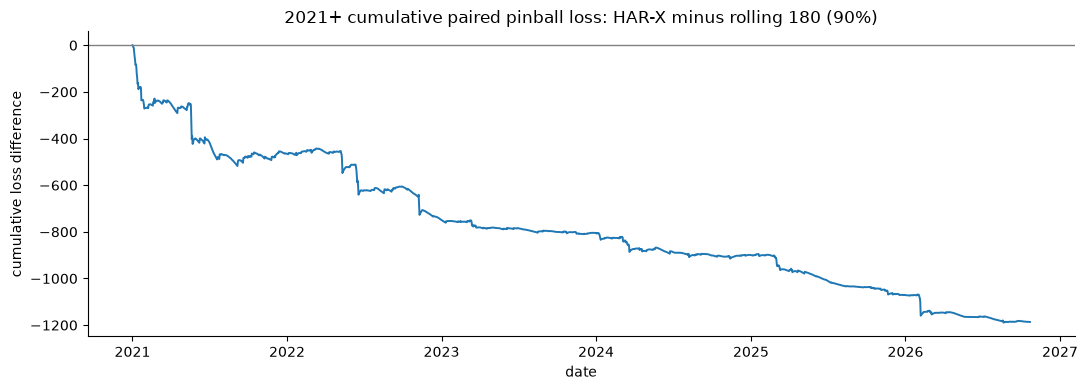

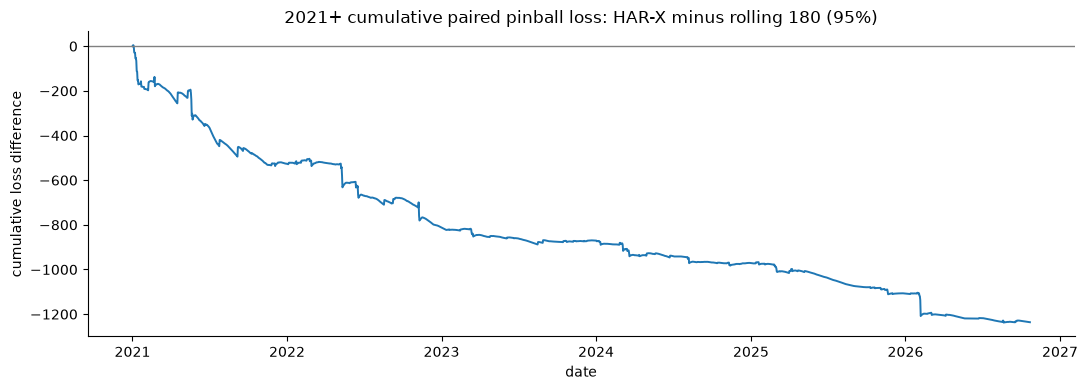

In [234]:
if isinstance(_release_daily,pd.DataFrame) and len(_release_daily):
    import matplotlib.pyplot as plt
    for q in (90,95):
        arr=_release_daily.sort_values('date').copy()
        arr['cumulative_delta']=arr['paired_delta_'+str(q)].cumsum()
        fig,ax=plt.subplots(figsize=(11,4))
        ax.plot(arr.date,arr.cumulative_delta,linewidth=1.4)
        ax.axhline(0,color='grey',linewidth=1)
        ax.set(title='2021+ cumulative paired pinball loss: HAR-X minus rolling 180 ('+str(q)+'%)',
               ylabel='cumulative loss difference',xlabel='date')
        fig.tight_layout()
        fig.savefig(FIG/f'release_forward_cumulative_pinball_{q}.png',dpi=150)
        plt.show()


In [235]:
# Integrate new results into a run-bound register without claiming R/forward validation.
import hashlib, json
_release_input_files=_ANNUAL_FILES + _release_vendor_files + _release_formal_files
for _name in _release_input_files:
    _p=OUT/_name
    assert _p.is_file(), f'Required release diagnostic missing: {_name}'
    assert _p.stat().st_mtime_ns>=RUN_STARTED_NS, f'Stale release diagnostic: {_name}'
_release_register={'run_id':RUN_ID,'historical_sample_end':str(END.date()),
    'python_original_historical_results_preserved':True,
    'R_five_script_execution_not_equal_to_R_provenance_gate':True,
    'official_ESR_primary_results_valid':_release_R_audit['ESR_has_valid_primary_pvalues'],
    'official_MCS_model_set_extracted':_release_R_audit['MCS_has_extracted_superior_set'],
    'R_five_models_verification':_release_R_audit['five_R_models_gate_validated'],
    '2021plus_annual_scoring_state':_release_annual_state['status'],
    '2021plus_independently_verified':False,
    'second_vendor_state':_release_vendor_state['status'],
    'second_vendor_independence_certified':False,
    'new_output_sha256':{name:hashlib.sha256((OUT/name).read_bytes()).hexdigest()
                         for name in _release_input_files}}
(OUT/'RELEASE_CURRENT_RUN_EVIDENCE.json').write_text(json.dumps(_release_register,indent=2),encoding='utf-8')
print('RELEASE_RUN_EVIDENCE:', {k:v for k,v in _release_register.items() if k!='new_output_sha256'})


RELEASE_RUN_EVIDENCE: {'run_id': '20261026T030925_071513Z_ee4a01ed', 'historical_sample_end': '2020-10-20', 'python_original_historical_results_preserved': True, 'R_five_script_execution_not_equal_to_R_provenance_gate': True, 'official_ESR_primary_results_valid': True, 'official_MCS_model_set_extracted': True, 'R_five_models_verification': False, '2021plus_annual_scoring_state': 'SCORED_DESCRIPTIVE_ANNUAL', '2021plus_independently_verified': False, 'second_vendor_state': 'COMPUTED_DESCRIPTIVE_SOURCE_COMPARISON', 'second_vendor_independence_certified': False}


In [236]:
from datetime import datetime,timezone
assert '_hardened_evidence' in globals() and _hardened_evidence['run_id']==RUN_ID
assert (OUT/'HARDENED_CURRENT_RUN_EVIDENCE.json').is_file()
import json,hashlib,os
assert _MASTER_VALIDATED
assert len(_publication_checks)==20 and _publication_checks.passed.all()
assert len(_parity)==9 and _parity.mismatch.eq(0).all()
assert _u_validation['integrity']=='PASS' and _u_validation['full_2020_HARX_matched_dates']==284
assert len(_miss)==284 and int(_miss.had_missing_prior30.sum())==126
assert len(_rank_df)==2*4*4 and len(_pair_df)==2*4*6
assert len(_shock_uncert_df)==2*4 and len(_harx_ablation_df)==4
assert _shock_uncert_df.shock_origins.max()==int(_shock_flags.sum())
assert _external_report['status'] in ('DATA_SCORED_DESCRIPTIVE','NOT_PROVIDED','INSUFFICIENT_SAMPLE')
assert _r_link_report['python_run_id']==RUN_ID
assert _r_link_report['original_csv_sha256']==SOURCE_CSV_SHA256
assert len(_r_status_map)==5
assert _one_out==Path(OUT).resolve() and _one_run_id==RUN_ID
_extra_outputs=['final_missingness_attribution_2020_daily.csv',
 'final_missingness_attribution_strata.csv','final_missingness_HAC_exploratory.csv',
 'final_HARX_fair_2019_ablation_summary.csv','final_HARX_fair_2019_penalty_grid.csv',
 'final_HARX_fair_ablation_daily_2020.csv','final_HARX_QLIKE_MAE_RMSE_matched_strata.csv',
 'final_HARX_top_20_paired_loss_contributors.csv',
 'final_tail_risk_block_length_rank_stability.csv','final_tail_risk_familywise_six_pairs.csv',
 'final_tail_risk_crisis_exclusion_ranks.csv','final_previsible_risk_regime_daily.csv',
 'final_previsible_risk_regime_summary.csv','final_tail_risk_largest_loss_days_expost.csv',
 'final_ACI_shock_event_cluster_uncertainty.csv','final_ACI_shock_event_clusters.csv',
 'final_ACI_shock_leave_cluster_out.csv',
 'final_R_five_model_provenance_gate.json','final_R_Python_connectedness_plot_status.json',
 'final_R_Python_connectedness_association_status.json',
 'final_external_2021plus_validation_status.json','final_2021plus_risk_four_models_status.json',
 'final_CARE_future_research_decision.json','MASTER_VALIDATION.json']
assert all((OUT/f).is_file() for f in _extra_outputs)
assert all((OUT/f).stat().st_mtime_ns>=RUN_STARTED_NS for f in _extra_outputs)
assert {x:hashlib.sha256((DATA/x).read_bytes()).hexdigest()
  for x in SOURCE_CSV_SHA256}==SOURCE_CSV_SHA256
assert _r_provenance_valid or not _R_FIVE_VALIDATED

_submission_expected=['submission_HARX_extended_2019_alpha_selection.csv',
 'submission_HARX_extreme_loss_exclusion_sensitivity.csv',
 'submission_HARX_block_CI_5_10_20_30.csv',
 'submission_HARX_top30_loss_contributors.csv',
 'submission_2020_matched_HARX_tail_risk_failure_days.csv',
 'submission_2020_largest_HARX_event_risk_context.csv',
 'submission_risk_regime_VaR_ES_coverage_uncertainty.csv',
 'submission_exploratory_MCS_style_block_sensitivity.csv',
 'submission_exploratory_MCS_style_elimination_trace.csv',
 'submission_R_structural_break_connectedness_status.json',
 'submission_external_2021plus_coverage_evidence.csv',
 'submission_external_2021plus_evidence_ledger.json',
 'submission_CARE_model_protocol.json']
assert all((OUT/_f).is_file() and (OUT/_f).stat().st_mtime_ns>=RUN_STARTED_NS
           for _f in _submission_expected), 'Submission supplement incomplete'
assert len(_vii_best)==2 and len(_vii_ci)==4 and len(_vii_mcs)==6
assert len(_vii_regime)>0 and _vii_matched.index.is_unique
assert not _vii_future['statistical_evidence_sufficient']

assert all((OUT/_f).is_file() for _f in _hardened_files)
assert '_ix_evidence' in globals() and _ix_evidence['python_run_id']==RUN_ID
assert all((OUT/_f).is_file() and (OUT/_f).stat().st_mtime_ns>=RUN_STARTED_NS for _f in _ix_required)
assert not _ix_evidence['ACI_recovery_inferred']
assert not _ix_evidence['2021plus_statistical_generalization_verified']
assert '_x_run_ledger' in globals() and _x_run_ledger['python_run_id']==RUN_ID
assert all((OUT/x).is_file() and (OUT/x).stat().st_mtime_ns>=RUN_STARTED_NS for x in _x_generated)
assert _x_run_ledger['crisis_episodes_nonoverlapping']
assert not _x_run_ledger['2021plus_independent_statistical_generalization_proven']
# Part XI current-run evidence must exist before any latest-run pointer is updated.
assert '_xi_ledger' in globals() and _xi_ledger['run_id']==RUN_ID
assert all((OUT/_f).is_file() and (OUT/_f).stat().st_mtime_ns>=RUN_STARTED_NS for _f in _xi_files)
assert _xi_ledger['proxy_HAR_2019_only_selection'] and _xi_ledger['proxy_comparisons_all_historical_and_posthoc']
assert not _xi_ledger['2021plus_independent_generalization_proven']
# Part XII is a current-run requirement: historical robustness is not optional in this release.
assert '_xii_ledger' in globals() and _xii_ledger['run_id']==RUN_ID
assert (OUT/'XII_FINAL_EVIDENCE_LEDGER.json').is_file()
assert all((OUT/f).is_file() and (OUT/f).stat().st_mtime_ns>=RUN_STARTED_NS for f in _xii_files)
assert not _xii_ledger['external_generalization_independently_proven_by_notebook']
# Explicitly separate independently verified predictive generalization from attested reviewer documents.
_ix_evidence['2021plus_forecast_code_provenance_verified']=bool(_xii_review['source_hashes_match'] and _xii_review['external_forecast_provenance_documented'])
_ix_evidence['2021plus_statistical_generalization_verified']=False  # a CI and an attestation cannot prove broad generalization
_PYTHON_VALIDATED=True
_FULL_NOTEBOOK_VALIDATED=bool(_PYTHON_VALIDATED and _ix_r5_verified)
_FORMAL_ESR_MCS_VERIFIED=bool(_ix_evidence['official_ESR_MCS_current_run_verified'])
# Standalone gates; 5 R models are NOT equivalent to ESR+MCS, and neither equals forward validation.
_COMPLETE_RESEARCH_VERIFIED=bool(_FULL_NOTEBOOK_VALIDATED and _FORMAL_ESR_MCS_VERIFIED and
  _ix_evidence['2021plus_forecast_code_provenance_verified'] and
  _ix_evidence['2021plus_statistical_generalization_verified'])
_external_is_scored=bool(_EXTERNAL_2021_SCORED_MIN90)
_status='PYTHON_AND_FIVE_R_MODELS_VALIDATED' if _FULL_NOTEBOOK_VALIDATED else 'PYTHON_VALIDATED_R_NOT_VERIFIED'
_final_run={'status':_status,'python_validated':True,
 'full_notebook_validated':_FULL_NOTEBOOK_VALIDATED,
 'r_all_five_current_run_validated':_R_FIVE_VALIDATED,
 'R_run_status':_r_current_status,'python_run_id':RUN_ID,
 'run_dir':RUN_DIR.relative_to(PROJECT_DIR).as_posix(),
 'historical_sample_end':str(END.date()),'raw_sha256':SOURCE_CSV_SHA256,
 'scientific_checks_passed':20,'asof_feature_parity_errors':0,
 'missingness_incomplete_n':126,'matched_HARX_2020_days':284,
 '2021plus_real_heldout_frozen_HARX':_external_report['status'],
 '2021plus_minimum_scored_90_days':_external_is_scored,
 '2021plus_statistical_evidence_sufficient':_vii_future['statistical_evidence_sufficient'],
 '2021plus_2020_to_2026_gap_aware':bool(_external_report.get('gap_policy')),
 '2021plus_data_gaps':_external_report.get('n_missing_bridge_days'),
 '2021plus_forecast_code_audited':_vii_future['forecast_source_code_verified'],
 '2021plus_external_generalization_of_all_models':_risk_external_status['status'],
 'hardened_extensions_current_run':True,
 'R_formal_ESR_MCS_status':_formal_status['status'],
 'formal_ESR_MCS_current_run_verified':_FORMAL_ESR_MCS_VERIFIED,
 'all_research_dimensions_verified':_COMPLETE_RESEARCH_VERIFIED,
 'three_requested_checks_report':str(OUT/'BTC_2026_THREE_REQUESTED_CHECKS_STATUS.json'),
 'part_xi_current_run_evidence':{k:v for k,v in _xi_ledger.items() if k!='outputs_sha256'},
 'part_xii_current_run_evidence':{k:v for k,v in _xii_ledger.items() if k!='part_xii_sha256'},
 'part_ix_current_run_evidence':_ix_evidence,
 'part_x_current_run_evidence':{k:v for k,v in _x_run_ledger.items() if k!='output_sha256'},
 'GARCH_multistart_audit':_hardened_evidence['GARCH_all_fits_converged'],
 'secondary_vendor_comparison_status':_secondary_audit['status'],
 'CARE':'PROTOCOL_ONLY_NOT_IMPLEMENTED','is_2020_retrospective':True,
 'created_utc':datetime.now(timezone.utc).isoformat()}
(OUT/'FINAL_RUN_COMPLETION_SUMMARY.json').write_text(json.dumps(_final_run,indent=2),encoding='utf-8')
_runs_root=PROJECT_DIR/'runs'
_final_run['current_release_evidence_file']='RELEASE_CURRENT_RUN_EVIDENCE.json'
(OUT/'FINAL_RUN_COMPLETION_SUMMARY.json').write_text(json.dumps(_final_run,indent=2),encoding='utf-8')
_def_pointer={'status':_status,'run_id':RUN_ID,'relative_run_dir':RUN_DIR.relative_to(PROJECT_DIR).as_posix(),
   'outputs':OUT.relative_to(PROJECT_DIR).as_posix(),
   'figures':FIG.relative_to(PROJECT_DIR).as_posix(),
   'frozen':_FROZEN.relative_to(PROJECT_DIR).as_posix(),
   'checks_passed':20,'five_R_models_validated':_R_FIVE_VALIDATED,
   '2021plus_heldout_HARX':_external_report['status'],
   'external_evidence_does_not_claim_generalization':True,
   '2021plus_risk_models':_risk_external_status['status'],
   '2021plus_evidence_grade':_vii_future['evidence_grade'],
   'hardened_extensions_current_run':True,
   'formal_R_ESR_MCS':_formal_status['status'],
   'formal_ESR_MCS_current_run_verified':_FORMAL_ESR_MCS_VERIFIED,
   'all_research_dimensions_verified':_COMPLETE_RESEARCH_VERIFIED,
 'three_requested_checks_report':str(OUT/'BTC_2026_THREE_REQUESTED_CHECKS_STATUS.json'),
   'part_ix_implemented':True,'part_x_implemented':True,'part_xi_implemented':True,'part_xii_implemented':True,
   '2021plus_Provenance':_x_evidence_state['status'],
   'official_ESR_MCS_verified_current_run':_x_formal_verified,
   'raw_sha256':SOURCE_CSV_SHA256,'completed_at_utc':_final_run['created_utc']}

_def_pointer['current_release_evidence_file']='RELEASE_CURRENT_RUN_EVIDENCE.json'
_def_pointer['current_release_evidence_sha256']=hashlib.sha256((OUT/'RELEASE_CURRENT_RUN_EVIDENCE.json').read_bytes()).hexdigest()
def _write_atomic_json(directory,name,record):
    tmp=directory/('.'+name+'.'+RUN_ID+'.tmp')
    tmp.write_text(json.dumps(record,indent=2),encoding='utf-8')
    os.replace(tmp,directory/name)
    assert json.loads((directory/name).read_text())['run_id']==RUN_ID

# Audit the auto-data and R/external outcomes from the SAME run before releasing pointers.
_auto_report_path=OUT/'BTC_2026_THREE_REQUESTED_CHECKS_STATUS.json'
assert _auto_report_path.is_file() and _auto_report_path.stat().st_mtime_ns>=RUN_STARTED_NS
assert json.loads(_auto_report_path.read_text(encoding='utf-8'))['run_id']==RUN_ID
print('THREE_EXTERNAL_CHECKS:',str(_auto_report_path))

# Check the calendar gap / common-training sensitivity outputs from this run.
for _extra_name in ['extra_calendar_contiguous_loss_bootstrap.csv',
                    'extra_four_excluded_days_without_prior30_missing.csv',
                    'extra_common_training_four_proxy_HAR.csv']:
    assert (OUT/_extra_name).is_file() and (OUT/_extra_name).stat().st_mtime_ns>=RUN_STARTED_NS

assert (OUT/'RELEASE_CURRENT_RUN_EVIDENCE.json').is_file()
assert json.loads((OUT/'RELEASE_CURRENT_RUN_EVIDENCE.json').read_text(encoding='utf-8'))['run_id']==RUN_ID
assert (OUT/'FINAL_LIVE_EXTERNAL_DIAGNOSTICS.json').is_file()
assert json.loads((OUT/'FINAL_LIVE_EXTERNAL_DIAGNOSTICS.json').read_text(encoding='utf-8'))['run_id']==RUN_ID
# Write the boundary evidence before publishing the latest-run pointers.

_old_full_pointer=_runs_root/'LATEST_FULL_RUN.json'
_full_ref=json.loads(_old_full_pointer.read_text(encoding='utf-8')) if _old_full_pointer.is_file() else None
_full_run_id=_full_ref.get('run_id') if isinstance(_full_ref,dict) else None
_current_boundary={'run_id':RUN_ID,'python_current_run_validated':True,
 'R_five_models_current_run_validated':bool(_R_FIVE_VALIDATED),
 'full_current_run_validated':bool(_FULL_NOTEBOOK_VALIDATED),
 'LATEST_FULL_RUN_points_to_current_run':bool(_FULL_NOTEBOOK_VALIDATED),
 'LATEST_FULL_RUN_other_run_id':_full_run_id if not _FULL_NOTEBOOK_VALIDATED and _full_run_id!=RUN_ID else None,
 '2021plus_external_evidence_grade':_vii_future['evidence_grade'],
 '2021plus_data_scored_only':bool(_vii_future['data_scored']),
 '2021plus_independently_proven':False,
 '2020_analysis_is_retrospective':True,
 'GARCH_R_convergence_verified':bool(_r_garch_fit_converged),
 'CARE_actual_fit_performed':False,
 'part_ix_output_files':_ix_required,
 'part_x_output_files':_x_generated,'part_xi_output_files':_xi_files, 'part_xii_output_files':_xii_files,
 'part_xi_current_run_evidence_sha256':hashlib.sha256((OUT/'XI_RESEARCH_EVIDENCE_LEDGER.json').read_bytes()).hexdigest(),
 'part_xii_current_run_evidence_sha256':hashlib.sha256((OUT/'XII_FINAL_EVIDENCE_LEDGER.json').read_bytes()).hexdigest(),
 'crisis_episodes':len(_x_episode_table),
 'crisis_episode_origins':len(_x_origins),
 'R_GARCH_source_hook_present':bool(_x_garch_helper_hook),
 'external_evidence_manifest_status':_x_evidence_state['status'],
 'formal_ESR_MCS_gate_verified':_FORMAL_ESR_MCS_VERIFIED,
 'reviewed_external_evidence_documentation_present':bool(_xii_review['external_forecast_provenance_documented']),
 'post2020_relative_pinball_claim_eligible_for_manual_review':bool(_xii_external_claim_ready),
 'all_study_axes_verified':_COMPLETE_RESEARCH_VERIFIED,
 'submission_output_files':_submission_expected,
 'submission_output_sha256':{f:hashlib.sha256((OUT/f).read_bytes()).hexdigest() for f in _submission_expected}}
(OUT/'SUBMISSION_EVIDENCE_BOUNDARY.json').write_text(json.dumps(_current_boundary,indent=2),encoding='utf-8')
print('RUN_POINTER_PUBLICATION: DEFERRED_UNTIL_FINAL_ADDENDUM_EVIDENCE')


THREE_EXTERNAL_CHECKS: I:\Dataset\Bitcoin Price Regression Analysis\runs\20261026T030925_071513Z_ee4a01ed\outputs\BTC_2026_THREE_REQUESTED_CHECKS_STATUS.json
RUN_POINTER_PUBLICATION: DEFERRED_UNTIL_FINAL_ADDENDUM_EVIDENCE


## Final verification addendum — corrected R evidence and forward-risk attribution

This addendum is a **verification layer**, not a retrospective model-selection round. It preserves all pre-existing research outputs. New cells are intentionally unexecuted until run with the genuine Windows project data. In particular, no future GARCH/EVT/FHS/POT performance is fabricated; prospective four-risk forecasts are separately generated with fixed pre-2021 parameters and explicitly documented as **new methodology-family sensitivity**, not a replication of the historical four-model forecasts.

### A. Frozen vs sequentially calibrated HAR-X, 2021–2026

For each eligible date: compare (1) frozen coefficient **and** frozen residual quantiles as of 2020-10-20, (2) existing frozen-coefficient/rolling-residual method, (3) prior-only Rolling-180 baseline. Exactly matched dates and a pre-2021 residual archive; no observations at the prediction date enter its prediction.

In [237]:
import pandas as pd, numpy as np, json, hashlib
_frz_state={'run_id':RUN_ID,'status':'NO_EXTERNAL_SCORING','historical_cutoff':str(pd.Timestamp(END).date()),
 'performance_claim':'POST_SELECTION_DESCRIPTIVE_NOT_AN_UNTOUCHED_HOLDOUT'}
_frz_rows=[]
_frz_daily=pd.DataFrame(columns=['date','realized_variance','pure_frozen_q90','pure_frozen_q95','sequential_q90','sequential_q95','rolling180_q90','rolling180_q95'])
if (isinstance(globals().get('_external_daily'),pd.DataFrame) and len(_external_daily)
        and isinstance(globals().get('_external_harx_features'),pd.DataFrame)):
    _h=_residual_archive.copy()
    _h['date']=pd.to_datetime(_h.date).dt.normalize()
    _h=_h.loc[_h.date.le(pd.Timestamp(END))].sort_values('date')
    _fixed_residual=_h['residual_log_variance'].tail(180).to_numpy(float)
    assert len(_fixed_residual)==180 and np.isfinite(_fixed_residual).all()
    assert _h.date.max()<=pd.Timestamp(END) and _h.date.is_unique
    _quantiles={q:float(np.quantile(_fixed_residual,q)) for q in (.9,.95)}
    _f=_external_harx_features.loc[
        _external_harx_features.date.isin(_external_daily.date)
    ].copy().sort_values('date')
    assert _f.date.is_unique and len(_f)==len(_external_daily)
    assert _f.date.min()>pd.Timestamp(END) and not _f.date.isna().any()
    _f['base_log']=_qh_frozen.predict(hx_matrix(_f.set_index('date'),qhar_cols))
    assert _f.base_log.notna().all() and np.isfinite(_f.base_log.to_numpy(dtype=float)).all()
    _frz_daily=_external_daily.merge(_f[['date','base_log']],on='date',how='left',validate='one_to_one')
    assert _frz_daily.base_log.notna().all()
    for _q in (.9,.95):
        _suffix=str(int(_q*100))
        _frz_daily[f'pure_frozen_q{_suffix}']=np.maximum(0,np.expm1(
            np.clip(_frz_daily.base_log.to_numpy(float)+_quantiles[_q],-20,20)))
        _frz_daily[f'sequential_q{_suffix}']=_frz_daily[f'frozen_q{_suffix}']
    _frz_daily=_frz_daily.loc[~_frz_daily.bridge_only].copy()
    for _q in (.9,.95):
        _z=str(int(_q*100));_truth=_frz_daily.realized_variance.to_numpy(float)
        def _pin(a):
            return np.maximum(_q*(_truth-a),(1-_q)*(a-_truth))
        _losses={k:_pin(_frz_daily[k].to_numpy(float)) for k in
            [f'pure_frozen_q{_z}',f'sequential_q{_z}',f'rolling180_q{_z}']}
        for k,l in _losses.items():_frz_daily[f'loss_{k}']=l
        for yr,grp in _frz_daily.groupby(_frz_daily.date.dt.year):
            rec={'year':int(yr),'quantile':_q,'n':len(grp),'calibration_frozen_through_2020':True,
                 'regression_coefficients_frozen_through_2017':True}
            for key in _losses:
                rec[f'{key}_mean_pinball']=float(grp[f'loss_{key}'].mean())
                rec[f'{key}_exception_rate']=float((grp.realized_variance>grp[key]).mean())
            rec['pure_minus_sequential_pinball']=rec[f'pure_frozen_q{_z}_mean_pinball']-rec[f'sequential_q{_z}_mean_pinball']
            _frz_rows.append(rec)
    _frz_state.update({'status':'PAIRED_SCORING_COMPUTED','n_scored_days':len(_frz_daily),
                       'historical_residual_cutoff':str(_h.date.max().date()),
                       'frozen_residual_q90':_quantiles[.9],'frozen_residual_q95':_quantiles[.95]})
_frz_summary=pd.DataFrame(_frz_rows)
_frz_summary.to_csv(OUT/'final_frozen_vs_sequential_HARX_annual.csv',index=False)
_frz_daily.to_csv(OUT/'final_frozen_vs_sequential_HARX_daily.csv',index=False)
(OUT/'final_frozen_vs_sequential_status.json').write_text(json.dumps(_frz_state,indent=2),encoding='utf-8')
print('Frozen vs sequential HAR-X:',_frz_state['status'])
if len(_frz_summary):display(_frz_summary.round(4))


Frozen vs sequential HAR-X: PAIRED_SCORING_COMPUTED


,year,quantile,n,calibration_frozen_through_2020,regression_coefficients_frozen_through_2017,pure_frozen_q90_mean_pinball,pure_frozen_q90_exception_rate,sequential_q90_mean_pinball,sequential_q90_exception_rate,rolling180_q90_mean_pinball,rolling180_q90_exception_rate,pure_minus_sequential_pinball,pure_frozen_q95_mean_pinball,pure_frozen_q95_exception_rate,sequential_q95_mean_pinball,sequential_q95_exception_rate,rolling180_q95_mean_pinball,rolling180_q95_exception_rate
0,2021,0.90,365,True,True,21.4278,1.0,7.7543,0.1260,9.0274,0.1014,13.6735,NaN,NaN,NaN,NaN,NaN,NaN
1,2022,0.90,365,True,True,10.5585,1.0,3.9335,0.0959,4.7095,0.0740,6.6249,NaN,NaN,NaN,NaN,NaN,NaN
2,2023,0.90,365,True,True,4.8157,1.0,1.6659,0.1041,1.8215,0.0849,3.1498,NaN,NaN,NaN,NaN,NaN,NaN
3,2024,0.90,366,True,True,7.4080,1.0,2.3717,0.1038,2.6297,0.1038,5.0363,NaN,NaN,NaN,NaN,NaN,NaN
4,2025,0.90,365,True,True,4.9613,1.0,1.4218,0.0986,1.8923,0.1260,3.5394,NaN,NaN,NaN,NaN,NaN,NaN
5,2026,0.90,264,True,True,4.9853,1.0,1.6075,0.0947,2.0453,0.0947,3.3777,NaN,NaN,NaN,NaN,NaN,NaN
6,2021,0.95,365,True,True,NaN,NaN,NaN,NaN,NaN,NaN,16.4349,22.5084,1.0,6.0735,0.0603,7.5157,0.0712
7,2022,0.95,365,True,True,NaN,NaN,NaN,NaN,NaN,NaN,8.2806,11.1186,1.0,2.8380,0.0466,3.6176,0.0521
8,2023,0.95,365,True,True,NaN,NaN,NaN,NaN,NaN,NaN,3.8988,5.0829,1.0,1.1841,0.0438,1.3474,0.0493
9,2024,0.95,366,True,True,NaN,NaN,NaN,NaN,NaN,NaN,6.1319,7.8160,1.0,1.6841,0.0546,1.9577,0.0574


### B. Calendar gaps and 2026 exclusion audit

Separate absent market bars, observed bars blocked by incomplete prior 30 calendar days, and other feature-level exclusions. This is a **coverage accounting** exercise; no imputation.

In [238]:
import pandas as pd, json
_gap_report={'run_id':RUN_ID,'status':'NO_EXTERNAL_DATA','zero_imputation':True}
_gap_rows=[]
if isinstance(globals().get('_future'),pd.DataFrame) and len(_future):
    end=pd.Timestamp(_future.date.max()).normalize()
    first=pd.Timestamp('2021-01-01')
    all_calendar=pd.date_range(first,end,freq='D')
    source=set(pd.to_datetime(_future.date).dt.normalize())
    scored=set(pd.to_datetime(_score.date).dt.normalize()) if isinstance(globals().get('_score'),pd.DataFrame) and len(_score) else set()
    excluded=globals().get('_ineligible',[])
    reasons={pd.Timestamp(z['date']).normalize():str(z['reason']) for z in excluded}
    for d in all_calendar:
        if d not in source:why='SOURCE_BAR_MISSING'
        elif d not in scored:why=reasons.get(d,'NO_SCORE_OTHER_GUARD')
        else:why='SCORED'
        _gap_rows.append({'date':d,'year':int(d.year),'evaluation_status':why,'is_partial_2026':bool(d.year==2026)})
    _coverage=pd.DataFrame(_gap_rows)
    assert len(_coverage)==len(all_calendar) and _coverage.date.is_unique
    _gap_report.update({'status':'COMPLETE_DATE_ACCOUNTING','start':str(first.date()),'end':str(end.date()),
                        'calendar_dates':len(_coverage),'scored_dates':int((_coverage.evaluation_status=='SCORED').sum()),
                        'unscored_count':int((_coverage.evaluation_status!='SCORED').sum()),
                        'counts_by_reason':{k:int(v) for k,v in _coverage.evaluation_status.value_counts().items()}})
else:
    _coverage=pd.DataFrame(columns=['date','year','evaluation_status','is_partial_2026'])
_coverage.to_csv(OUT/'final_2021plus_every_date_coverage.csv',index=False)
(OUT/'final_2021plus_coverage_status.json').write_text(json.dumps(_gap_report,indent=2),encoding='utf-8')
print('2021+ coverage:',_gap_report['status'])
if len(_coverage):display(_coverage.groupby(['year','evaluation_status']).size().unstack(fill_value=0))


2021+ coverage: COMPLETE_DATE_ACCOUNTING


evaluation_status,MISSING_PRIOR_30_CALENDAR_DAYS,NO_VALID_FROZEN_FEATURES,SCORED,SOURCE_BAR_MISSING
year,,,,
2021,0,0,365,0
2022,0,0,365,0
2023,0,0,365,0
2024,0,0,366,0
2025,0,0,365,0
2026,29,1,264,1


### C. Cross-vendor HAR-X forecast sensitivity (historical only)

Apply the **same original-vendor-trained frozen estimator** to each vendor's own lagged OHLCV features; compare on identical dates. This measures *input-source sensitivity*; it does not claim the alternative vendor is intrinsically better, nor that the comparison is causal.

In [239]:
import pandas as pd, numpy as np,json
_vens={'run_id':RUN_ID,'status':'NO_SECOND_SOURCE','historical_only':True,
       'training_vendor':'original','independent_provider_verified':False}
_vens_daily=pd.DataFrame(columns=['date','original_vendor_base_log','secondary_vendor_base_log','relative_prediction_diff_pct'])
if isinstance(globals().get('_sec'),pd.DataFrame) and len(_sec):
    _sec0=_sec.copy()
    req=['date','open','high','low','close','volume']
    if set(req).issubset(_sec0.columns):
        _sec0=_sec0[req].copy()
        _sec0.date=pd.to_datetime(_sec0.date,utc=True).dt.tz_localize(None).dt.normalize()
        _sec0=_sec0.loc[_sec0.date.between(pd.Timestamp(START),pd.Timestamp(END))].copy()
        _orig0=_raw_btc[req].copy()
        _orig0.date=pd.to_datetime(_orig0.date).dt.normalize()
        _orig0=_orig0.loc[_orig0.date.between(pd.Timestamp(START),pd.Timestamp(END))].copy()
        if _sec0.date.is_unique and len(_sec0)>=31:
            _ff_o=prepare_harx_features(_orig0,earliest=START,latest=END)
            _ff_s=prepare_harx_features(_sec0,earliest=START,latest=END)
            _dates=pd.DatetimeIndex(_ff_o.date).intersection(pd.DatetimeIndex(_ff_s.date))
            _ff_o=_ff_o.set_index('date').loc[_dates]
            _ff_s=_ff_s.set_index('date').loc[_dates]
            assert _ff_o.index.equals(_ff_s.index)
            oo=_qh_frozen.predict(hx_matrix(_ff_o,qhar_cols))
            ss=_qh_frozen.predict(hx_matrix(_ff_s,qhar_cols))
            po=np.maximum(0,np.expm1(np.clip(oo,-20,20)))
            ps=np.maximum(0,np.expm1(np.clip(ss,-20,20)))
            _vens_daily=pd.DataFrame({'date':_dates,'original_vendor_base_log':oo,
                  'secondary_vendor_base_log':ss,'original_variance_forecast':po,
                  'secondary_variance_forecast':ps,'absolute_forecast_diff':np.abs(ps-po),
                  'relative_prediction_diff_pct':100*(ps-po)/np.maximum(np.abs(po),1e-6)})
            _vens.update({'status':'HISTORICAL_MATCHED_PREDICTIONS_COMPUTED','matched_days':len(_dates),
                          'mean_abs_forecast_diff':float(_vens_daily.absolute_forecast_diff.mean()) if len(_dates) else None,
                          'different_vendor_training':False})
_vens_daily.to_csv(OUT/'final_vendor_frozen_HARX_forecast_comparison.csv',index=False)
(OUT/'final_vendor_forecast_sensitivity_status.json').write_text(json.dumps(_vens,indent=2),encoding='utf-8')
print('Cross-vendor HAR-X:',_vens['status'])
if len(_vens_daily):display(_vens_daily.tail(8).round(4))


Cross-vendor HAR-X: HISTORICAL_MATCHED_PREDICTIONS_COMPUTED


,date,original_vendor_base_log,secondary_vendor_base_log,original_variance_forecast,secondary_variance_forecast,absolute_forecast_diff,relative_prediction_diff_pct
1779,2020-10-13,3.6805,0.2472,38.6667,0.2804,38.3863,-99.2748
1780,2020-10-14,3.6574,0.1618,37.7596,0.1756,37.5841,-99.5350
1781,2020-10-15,3.6225,0.0688,36.4308,0.0713,36.3595,-99.8044
1782,2020-10-16,3.5937,0.1238,35.3682,0.1318,35.2365,-99.6275
1783,2020-10-17,3.6790,0.1668,38.6052,0.1815,38.4236,-99.5298
1784,2020-10-18,3.4615,-0.2937,30.8653,0.0000,30.8653,-100.0000
1785,2020-10-19,3.4697,-0.2874,31.1255,0.0000,31.1255,-100.0000
1786,2020-10-20,3.5307,0.0624,33.1496,0.0644,33.0851,-99.8056


### D. Post-2020 four risk-model families — *separate prospective methodology-sensitivity study*

This implementation uses a Gaussian GARCH(1,1) fitted **only through 2020-10-20** and prior-day updates for FHS, filtered GPD-EVT and direct-loss Rolling POT. It is **not** a claimed exact reproduction of the legacy 2019/2020 estimators or an untouched holdout: configurations were informed by past research, tail fits are periodically refreshed using only prior information, and source independence remains unverified. Insufficient historical samples or numerical failures are recorded; fabricated forecasts are prohibited. See module source included inline below and in package.

In [240]:
"""Prospective 1-step BTC tail-risk family comparison, not a replication of original historical fits.
All parameters and forecasts are based on observations strictly before forecast date.
2021+ evaluation is post-selection descriptive, NOT untouched independent validation.
"""
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.stats import norm, genpareto

def _garch_path(x, params, start):
    omega,a,b=params
    v=np.empty(len(x)+1,float)
    v[0]=start
    for i in range(len(x)):
        v[i+1]=max(1e-8,omega+a*x[i]**2+b*v[i])
    return v

def fit_garch(train_loss):
    x=np.asarray(train_loss,float)
    mu=float(np.mean(x))
    z=x-mu
    uv=max(float(np.var(z)),1e-4)
    def objective(t):
        omega,a,b=t
        if omega<=0 or a<0 or b<0 or a+b>=.998:return 1e12
        v=_garch_path(z,(omega,a,b),uv)[:-1]
        return float(np.mean(np.log(v)+z*z/v))
    guesses=[(uv*.04,.07,.87),(uv*.10,.12,.70),(uv*.02,.04,.94)]
    best=None
    for t in guesses:
        r=minimize(objective,t,method='L-BFGS-B',bounds=[(1e-7,uv*10),(.0001,.5),(.0001,.997)],options={'maxiter':350})
        if r.success and r.x[1]+r.x[2]<.998 and np.isfinite(r.fun) and (best is None or r.fun<best.fun):best=r
    if best is None:raise RuntimeError('No converged stationary Gaussian GARCH fit')
    return mu,np.asarray(best.x,float),uv

def gpd_var_es(sample, alpha=.95, threshold_q=.90):
    x=np.asarray(sample,float)
    x=x[np.isfinite(x)]
    if len(x)<300:raise ValueError('Requires >=300 eligible prior observations')
    u=float(np.quantile(x,threshold_q)); exc=x[x>u]-u
    if len(exc)<25:raise ValueError('Insufficient POT threshold exceedances')
    xi,beta=genpareto.fit(exc,floc=0)[0::2]
    xi=float(xi);beta=float(beta)
    if not (-.8<xi<.98 and 0<beta<1e7):raise ValueError('Invalid / infinite-mean GPD shape or scale')
    p=len(exc)/len(x)
    if p<1-alpha:raise ValueError('Tail threshold exceeds target quantile')
    ratio=p/(1-alpha)
    var=float(u+beta*np.expm1(xi*np.log(ratio))/xi) if abs(xi)>1e-6 else float(u+beta*np.log(ratio))
    es=float(var+(beta+xi*(var-u))/(1-xi))
    if not np.isfinite([var,es]).all() or es<var:raise ValueError('Invalid POT VaR–ES')
    return var,es,xi,int(len(exc))

def run(frozen_history, future, train_end='2020-10-20', alpha=.95, cache_days=45):
    req=['date','close']
    for z in (frozen_history,future):
        if not set(req).issubset(z.columns):raise ValueError('OHLCV requires date, close')
    h=frozen_history[req].copy();f=future[req].copy()
    for z in (h,f):
        z['date']=pd.to_datetime(z.date).dt.normalize()
        z['close']=pd.to_numeric(z.close,errors='raise')
        if z.date.duplicated().any() or (z.close<=0).any() or not np.isfinite(z.close).all():raise ValueError('Invalid dates/prices')
    end=pd.Timestamp(train_end)
    h=h.loc[h.date<=end]
    f=f.loc[f.date>end]
    if h.empty or f.empty:raise ValueError('Historical train data and post-cutoff data are required')
    obs=pd.concat([h,f],ignore_index=True).sort_values('date').reset_index(drop=True)
    if obs.date.duplicated().any():raise ValueError('Duplicate dates across data sources')
    obs['day_gap']=obs.date.diff().dt.days
    obs['loss']=-100*np.log(obs.close/obs.close.shift(1))
    obs.loc[obs.day_gap.ne(1),'loss']=np.nan
    training=obs.loc[(obs.date<=end)&obs.loss.notna(),'loss'].to_numpy(float)
    if len(training)<750:raise ValueError('Need >=750 consecutive-day returns before cutoff')
    mu,p,uv=fit_garch(training)
    variance=float(_garch_path(training-mu,p,uv)[-1])
    std_loss=list(((training-mu)/np.sqrt(np.maximum(_garch_path(training-mu,p,uv)[:-1],1e-8))).tolist())
    loss_history=list(training.tolist())
    prev_date=end
    res=[];e_cache=None;p_cache=None;prev_cache=None
    for _,r in f.sort_values('date').iterrows():
        date=pd.Timestamp(r.date)
        if date<=prev_date:raise ValueError('Invalid ordering')
        # A calendar gap means no valid daily return; reset variance and do not invent it.
        if (date-prev_date).days>1:
            variance=uv
            prev_date=date
            res.append({'date':date,'status':'GAP_DAY_NO_RETURN','loss':np.nan})
            continue
        current=obs.loc[obs.date==date,'loss'].iloc[0]
        if not np.isfinite(current):
            prev_date=date;res.append({'date':date,'status':'UNSCORABLE_RETURN','loss':np.nan});continue
        sd=np.sqrt(max(variance,1e-8));cut=float(norm.ppf(alpha))
        gaussian=(float(mu+sd*cut),float(mu+sd*norm.pdf(cut)/(1-alpha)))
        prior=np.asarray(std_loss[-750:],float)
        if len(prior)<350:raise ValueError('FHS needs >350 prior standardized residuals')
        q=float(np.quantile(prior,alpha));tail=prior[prior>=q]
        if len(tail)<20:raise ValueError('FHS tail sample too small')
        fhs=(float(mu+sd*q),float(mu+sd*np.mean(tail)))
        if prev_cache is None or (date-prev_cache).days>=cache_days:
            try:
                e_cache=gpd_var_es(prior,alpha)
            except ValueError:
                e_cache=None
            try:
                p_cache=gpd_var_es(np.asarray(loss_history[-1000:],float),alpha)
            except ValueError:
                p_cache=None
            prev_cache=date
        if e_cache is None or p_cache is None:
            res.append({'date':date,'status':'TAIL_FIT_NOT_AVAILABLE','loss':float(current)})
        else:
            out={'date':date,'status':'SCORED','loss':float(current),
                 'param_fit_end':str(end.date()),'tail_fit_last_refresh_asof':str((pd.Timestamp(prev_cache).to_pydatetime()-__import__('datetime').timedelta(days=1)).date()),
                 'Gaussian GARCH_VaR':gaussian[0],'Gaussian GARCH_ES':gaussian[1],
                 'GARCH-FHS_VaR':fhs[0],'GARCH-FHS_ES':fhs[1],
                 'GARCH-filtered EVT_VaR':float(mu+sd*e_cache[0]),
                 'GARCH-filtered EVT_ES':float(mu+sd*e_cache[1]),
                 'Rolling POT_VaR':float(p_cache[0]),'Rolling POT_ES':float(p_cache[1])}
            if all(np.isfinite(out[f'{model}_VaR']) and np.isfinite(out[f'{model}_ES']) and
                   out[f'{model}_ES']>=out[f'{model}_VaR'] for model in
                   ['Gaussian GARCH','GARCH-FHS','GARCH-filtered EVT','Rolling POT']):
                res.append(out)
            else:
                res.append({'date':date,'status':'INVALID_ES_VAR','loss':float(current)})
        # Update after forecast with realized loss only.
        e=float(current-mu)
        std_loss.append(e/sd)
        loss_history.append(float(current))
        variance=max(1e-8,p[0]+p[1]*e*e+p[2]*variance)
        prev_date=date
    daily=pd.DataFrame(res)
    return daily, {'status':'COMPUTED_PROSPECTIVE_FAMILY_METHODS','training_end':str(end.date()),
        'n_train':len(training),'GARCH_mu':mu,'GARCH_omega_alpha_beta':list(map(float,p)),
        'GPD_fit_cadence_calendar_days':cache_days,'risk_alpha':alpha,
        'methodological_disclosure':'Frozen pre-2021 Gaussian GARCH, rolling historical filtered empirical FHS, periodically refreshed residual GPD EVT and direct-loss POT; these are NOT the same estimation protocol as legacy 2019/2020 models.',
        'n_scored_days':int(daily.status.eq('SCORED').sum()),
        'evaluation_is_post_selection_descriptive':True}

def fz0(loss,var,es,alpha=.95):
    # Positive-loss convention; FZ0 defined up to additive target-only terms.
    x=np.asarray(loss,float);v=np.asarray(var,float);e=np.asarray(es,float)
    if (e<=0).any():raise ValueError('FZ0 requires positive ES')
    return (v+(np.maximum(x-v,0)/(1-alpha)))/e + np.log(e)-1


In [241]:
import numpy as np,pandas as pd,json
_four_status={'run_id':RUN_ID,'status':'NOT_PROVIDED','alpha':.95,
  'post_selection_descriptive':True,'exact_legacy_models_reproduced':False,
  'source_independence_verified':False,'ESR_validation_of_new_period':False}
_four_daily=pd.DataFrame()
_four_summary=pd.DataFrame()
if isinstance(globals().get('_future'),pd.DataFrame) and len(_future) and isinstance(globals().get('_hist'),pd.DataFrame):
    try:
        _four_daily,_info=run(_hist,_future,train_end=str(pd.Timestamp(END).date()),alpha=.95)
        if _four_daily.status.eq('SCORED').any():
            _r=_four_daily.loc[_four_daily.status.eq('SCORED')].copy()
            assert pd.to_datetime(_r.param_fit_end).lt(pd.to_datetime(_r.date)).all(), 'Future fit information leaked'
            assert pd.to_datetime(_r.tail_fit_last_refresh_asof).lt(pd.to_datetime(_r.date)).all(), 'Tail fit used current/future loss'
            assert _r.date.is_unique
        _four_daily.to_csv(OUT/'final_four_family_forward_daily.csv',index=False)
        _sc=_four_daily.loc[(_four_daily.status=='SCORED')&
             (pd.to_datetime(_four_daily.date)>=pd.Timestamp('2021-01-01'))].copy()
        results=[]
        for model in ['Gaussian GARCH','GARCH-FHS','GARCH-filtered EVT','Rolling POT']:
            vc=f'{model}_VaR';ec=f'{model}_ES'
            d=_sc[['date','loss',vc,ec]].dropna().copy()
            if len(d):
                d['FZ0']=fz0(d.loss,d[vc],d[ec],alpha=.95)
                for year,g in d.groupby(pd.to_datetime(d.date).dt.year):
                    results.append({'year':int(year),'model':model,'n':len(g),
                        'mean_FZ0':float(g.FZ0.mean()),
                        'exceptions':int((g.loss>g[vc]).sum()),
                        'VaR_exception_rate':float((g.loss>g[vc]).mean()),
                        'alpha':.95,'descriptive_family_methods_only':True})
        _four_summary=pd.DataFrame(results,columns=['year','model','n','mean_FZ0','exceptions',
                        'VaR_exception_rate','alpha','descriptive_family_methods_only'])
        _four_status.update(_info)
        _four_status['n_post2020_common_model_days']=int(len(_sc))
        _four_status['scored_data_original_provenance_independently_verified']=False
        _four_status['status']='COMPUTED_DESCRIPTIVE_FORWARD_FAMILY_COMPARISON' if len(_four_summary) else 'INSUFFICIENT_SCORABLE_DAYS'
    except Exception as error:
        _four_status.update({'status':'FAILED_DIAGNOSTIC_PRESERVED',
                     'error':f'{type(error).__name__}: {error}'})
else:
    _four_status['status']='NO_EXTERNAL_INPUT'
if not len(_four_daily):
    pd.DataFrame(columns=['date','status','loss']).to_csv(OUT/'final_four_family_forward_daily.csv',index=False)
_four_summary.to_csv(OUT/'final_four_family_forward_annual.csv',index=False)
(OUT/'final_four_family_forward_evidence.json').write_text(json.dumps(_four_status,indent=2),encoding='utf-8')
print('Forward four risk families:',_four_status['status'])
if len(_four_summary):display(_four_summary.round(5))


Forward four risk families: COMPUTED_DESCRIPTIVE_FORWARD_FAMILY_COMPARISON


,year,model,n,mean_FZ0,exceptions,VaR_exception_rate,alpha,descriptive_family_methods_only
0,2021,Gaussian GARCH,365,2.35373,19,0.05205,0.95,True
1,2022,Gaussian GARCH,365,2.24882,20,0.05479,0.95,True
2,2023,Gaussian GARCH,365,1.63576,9,0.02466,0.95,True
3,2024,Gaussian GARCH,366,1.79104,14,0.03825,0.95,True
4,2025,Gaussian GARCH,365,1.62155,13,0.03562,0.95,True
5,2026,Gaussian GARCH,293,1.66356,6,0.02048,0.95,True
6,2021,GARCH-FHS,365,2.34812,24,0.06575,0.95,True
7,2022,GARCH-FHS,365,2.23904,21,0.05753,0.95,True
8,2023,GARCH-FHS,365,1.66132,9,0.02466,0.95,True
9,2024,GARCH-FHS,366,1.79044,21,0.05738,0.95,True


### E. Final comparison and evidence boundaries

- MCS must be read from **SSM @show / @Info** and reconciled to the four named models.
- R GARCH must export real `rugarch` fit convergence, not infer it from script success or a CSV artifact.
- Forward score computation is not a certification of external provider identity, absence of data snooping, or independent generalization.
- Any changed code cells and new addendum cells are intentionally **unexecuted** until a complete local run.

### F. Final paired robustness, gap accounting and submission-ready evidence

This **does not add another forecasting model**. It computes calendar-island uncertainty for the *pure Frozen vs Sequential HAR-X* comparison, checks the external four-risk-model as-of ledger, and consolidates ESR/MCS evidence without interpreting a process exit code as statistical success. Results are tagged as post-selection, descriptive, and not independently provider-attested. The latest-run pointer is updated **only after** this addendum generates current-run output files.

In [242]:
import numpy as np, pandas as pd, json, hashlib
_addendum_review={'run_id':RUN_ID,'status':'COMPUTED_WITH_EXPLICIT_EVIDENCE_BOUNDARIES',
    'forward_study_post_selection':True,'untouched_independent_validation_claim':False,
    'independent_provider_verified':False, 'formal_R_MCS_success_not_inferred_from_exit_code':True}
_add_pair=[]
_rng=np.random.default_rng(20261023)
if isinstance(_frz_daily,pd.DataFrame) and len(_frz_daily):
    _d=_frz_daily.copy()
    _d['date']=pd.to_datetime(_d['date']).dt.normalize()
    _d=_d.sort_values('date')
    assert _d.date.is_unique
    _d['calendar_island']=_d.date.diff().dt.days.ne(1).cumsum()
    for q in (90,95):
        a=f'loss_pure_frozen_q{q}'
        b=f'loss_sequential_q{q}'
        c=f'loss_rolling180_q{q}'
        assert set([a,b,c]).issubset(_d.columns)
        # Resample within REAL calendar-contiguous islands; do not join across missing days.
        for label,left,right in [('frozen_minus_sequential',a,b),('sequential_minus_rolling',b,c)]:
            daily=pd.DataFrame({'date':_d.date,'island':_d.calendar_island,
                                'difference':_d[left].to_numpy(float)-_d[right].to_numpy(float)})
            assert np.isfinite(daily.difference).all()
            islands=[g.difference.to_numpy(dtype=float) for _,g in daily.groupby('island')]
            n=len(daily)
            means=[]
            for iteration in range(500):
                segments=[]
                while sum(len(x) for x in segments)<n:
                    # Length-weight island selection preserves the empirical day mass.
                    lengths=np.array([len(x) for x in islands],dtype=float)
                    j=int(_rng.choice(len(islands),p=lengths/lengths.sum()))
                    src=islands[j]
                    width=min(10,len(src))
                    start=int(_rng.integers(0,len(src)-width+1))
                    segments.append(src[start:start+width])
                means.append(float(np.concatenate(segments)[:n].mean()))
            low,high=np.percentile(means,[2.5,97.5])
            _add_pair.append({'quantile':q/100,'comparison':label,
                'n':int(n),'n_calendar_islands':int(len(islands)),
                'paired_mean_loss_diff':float(daily.difference.mean()),
                'calendar_island_CI_low':float(low),'calendar_island_CI_high':float(high),
                'ci_exploratory_post_selection':True,'bootstrap_replications':500,
                'islands_sampled_proportional_to_length':True})
_pair_audit=pd.DataFrame(_add_pair,columns=['quantile','comparison','n','n_calendar_islands',
    'paired_mean_loss_diff','calendar_island_CI_low','calendar_island_CI_high',
    'ci_exploratory_post_selection','bootstrap_replications','islands_sampled_proportional_to_length'])
_pair_audit.to_csv(OUT/'final_addendum_calendar_paired_HARX_robustness.csv',index=False)
_addendum_review['frozen_vs_sequential_status']=_frz_state.get('status')
_addendum_review['n_paired_comparisons']=int(len(_pair_audit))
_addendum_review['n_forward_risk_model_days']=int(_four_status.get('n_post2020_common_model_days',0))
_addendum_review['forward_family_status']=_four_status.get('status')
_addendum_review['R_GARCH_explicit_convergence']=bool(_r_garch_fit_converged)
_addendum_review['R_ESR_primary_verified']=bool(globals().get('_release_R_audit',{}).get('ESR_has_valid_primary_pvalues',False))
_addendum_review['R_MCS_superior_set_verified']=bool(globals().get('_release_R_audit',{}).get('MCS_has_extracted_superior_set',False))
_addendum_review['vendor_status']=_vens.get('status')
_addendum_review['annual_output_exists']=bool((OUT/'final_frozen_vs_sequential_HARX_annual.csv').is_file())
(OUT/'final_addendum_analysis_status.json').write_text(json.dumps(_addendum_review,indent=2),encoding='utf-8')
print('FINAL ADDENDUM ANALYSIS:',_addendum_review)
if len(_pair_audit): display(_pair_audit.round(5))

FINAL ADDENDUM ANALYSIS: {'run_id': '20261026T030925_071513Z_ee4a01ed', 'status': 'COMPUTED_WITH_EXPLICIT_EVIDENCE_BOUNDARIES', 'forward_study_post_selection': True, 'untouched_independent_validation_claim': False, 'independent_provider_verified': False, 'formal_R_MCS_success_not_inferred_from_exit_code': True, 'frozen_vs_sequential_status': 'PAIRED_SCORING_COMPUTED', 'n_paired_comparisons': 4, 'n_forward_risk_model_days': 2119, 'forward_family_status': 'COMPUTED_DESCRIPTIVE_FORWARD_FAMILY_COMPARISON', 'R_GARCH_explicit_convergence': False, 'R_ESR_primary_verified': True, 'R_MCS_superior_set_verified': True, 'vendor_status': 'HISTORICAL_MATCHED_PREDICTIONS_COMPUTED', 'annual_output_exists': True}


,quantile,comparison,n,n_calendar_islands,paired_mean_loss_diff,calendar_island_CI_low,calendar_island_CI_high,ci_exploratory_post_selection,bootstrap_replications,islands_sampled_proportional_to_length
0,0.90,frozen_minus_sequential,2090,2,6.02176,5.20961,6.95072,True,500,True
1,0.90,sequential_minus_rolling,2090,2,-0.56765,-0.84679,-0.31179,True,500,True
2,0.95,frozen_minus_sequential,2090,2,7.32896,6.24639,8.46311,True,500,True
3,0.95,sequential_minus_rolling,2090,2,-0.59142,-0.86770,-0.36190,True,500,True


## Part XIII — Measurement integrity, calibration attribution, model ablation and prospective testing

**Research rule:** This section adds *diagnostic experiments*, not proven independent generalization. Original study files and historic results remain unchanged. Missing BTC values are never imputed. These cells require the original project inputs and external CSV from the previous run. Any cross-vendor volume comparison remains **unverified** until the volume-unit/UTC manifest and source identities are reviewed.

The three genuinely new model comparisons are *direct quantile*, *median-anchored calibrated quantile*, and *refitted no-volume / price-only HAR*. Their evaluation on already-seen 2021–2026 market data is exploratory, not an untouched confirmatory test.

### XIII.1 — Source identity, volume-unit documentation and train-to-forward feature drift

The optional `BITCOIN_VOLUME_UNIT_MANIFEST` requires explicit original, secondary and future volume metadata. Even a matching declaration is **not** proof of independent provider identity.

In [243]:
# All new variables are namespaced btc26_* to avoid collisions with legacy notebook cells.
import os, json, hashlib
import numpy as np
import pandas as pd
from pathlib import Path

btc26_status = {'run_id': RUN_ID, 'status':'NO_EXTERNAL_EVALUATION',
                'external_vendor_identity_verified':False,
                'external_volume_unit_verified':False,
                'historical_volume_unit_verified':False,
                'cross_vendor_forecast_comparability_verified':False}
btc26_drift = pd.DataFrame()
btc26_vendor = pd.DataFrame()
btc26_unit_path = os.environ.get('BITCOIN_VOLUME_UNIT_MANIFEST','').strip()
btc26_units = {}
if btc26_unit_path:
    btc26_manifest_file = Path(btc26_unit_path).expanduser().resolve()
    if not btc26_manifest_file.is_file():
        raise FileNotFoundError('BITCOIN_VOLUME_UNIT_MANIFEST does not exist: '+str(btc26_manifest_file))
    btc26_units = json.loads(btc26_manifest_file.read_text(encoding='utf-8'))
    for provider in ('original','secondary','future'):
        item = btc26_units.get(provider,{})
        if not isinstance(item,dict): raise ValueError('Volume manifest provider entries must be objects')
    btc26_status['volume_manifest_sha256'] = hashlib.sha256(btc26_manifest_file.read_bytes()).hexdigest()
else:
    btc26_status['volume_manifest_missing'] = True

def btc26_provider_consistency(a,b):
    x,y=btc26_units.get(a,{}),btc26_units.get(b,{})
    keys=('volume_unit','volume_base_asset','bar_close_utc','price_currency')
    return (bool(x) and bool(y) and all(str(x.get(k,'')).strip() and
                str(x[k]).upper()==str(y.get(k,'')).upper() for k in keys))

btc26_status['original_vs_future_metadata_match']=btc26_provider_consistency('original','future')
btc26_status['original_vs_secondary_metadata_match']=btc26_provider_consistency('original','secondary')
# User-supplied metadata may identify a plausible match, but does NOT attest independent source provenance.
btc26_status['original_volume_unit_documented']=bool(btc26_units.get('original',{}).get('volume_unit'))
btc26_status['secondary_volume_unit_documented']=bool(btc26_units.get('secondary',{}).get('volume_unit'))
btc26_status['future_volume_unit_documented']=bool(btc26_units.get('future',{}).get('volume_unit'))

if (isinstance(globals().get('_external_harx_features'),pd.DataFrame) and
        not _external_harx_features.empty):
    btc26_train = _qh_develop.sort_index().copy()  # <=2017 only; strictly pre-holdout
    btc26_eval = _external_harx_features.loc[
        _external_harx_features.date.ge(pd.Timestamp('2021-01-01'))].copy()
    if not btc26_eval.empty:
        btc26_rows=[]
        for col in qhar_cols:
            a=pd.to_numeric(btc26_train[col],errors='coerce').replace([np.inf,-np.inf],np.nan).dropna().to_numpy(float)
            b=pd.to_numeric(btc26_eval[col],errors='coerce').replace([np.inf,-np.inf],np.nan).dropna().to_numpy(float)
            if not len(a) or not len(b): continue
            aq=np.quantile(a,[.01,.25,.5,.75,.99]);bq=np.quantile(b,[.01,.25,.5,.75,.99])
            denom=max(float(np.std(a,ddof=1)),1e-8)
            btc26_rows.append({'feature':col,'n_train':len(a),'n_external':len(b),
                'train_mean':float(np.mean(a)),'external_mean':float(np.mean(b)),
                'standardized_mean_shift':float((np.mean(b)-np.mean(a))/denom),
                'train_p01':float(aq[0]),'train_median':float(aq[2]),'train_p99':float(aq[4]),
                'external_p01':float(bq[0]),'external_median':float(bq[2]),'external_p99':float(bq[4]),
                'fraction_external_outside_train_p01_p99':float(np.mean((b<aq[0])|(b>aq[4]))),
                'external_vs_train_median_ratio':float(bq[2]/aq[2]) if abs(aq[2])>1e-10 else np.nan,
                'training_end_year':2017,'future_data_source_attested':False})
        btc26_drift=pd.DataFrame(btc26_rows)
        btc26_status.update({'status':'DRIFT_COMPUTED_METADATA_NOT_INDEPENDENTLY_ATTESTED',
                             'external_feature_rows':len(btc26_eval),'training_feature_rows':len(btc26_train)})

# Compare *features*, not just predicted variances. No automatic volume conversion or scale refitting.
if (isinstance(globals().get('_ff_o'),pd.DataFrame) and
        isinstance(globals().get('_ff_s'),pd.DataFrame) and
        len(_ff_o) and _ff_o.index.equals(_ff_s.index)):
    btc26_rows=[]
    for col in qhar_cols:
        orig=pd.to_numeric(_ff_o[col],errors='coerce').to_numpy(float)
        second=pd.to_numeric(_ff_s[col],errors='coerce').to_numpy(float)
        valid=np.isfinite(orig)&np.isfinite(second)
        if not valid.any():continue
        diff=second[valid]-orig[valid]
        btc26_rows.append({'feature':col,'matched_rows':int(valid.sum()),
                           'original_median':float(np.median(orig[valid])),
                           'secondary_median':float(np.median(second[valid])),
                           'mean_absolute_feature_difference':float(np.mean(np.abs(diff))),
                           'median_feature_difference':float(np.median(diff)),
                           'same_source_unit_verified':False})
    btc26_vendor=pd.DataFrame(btc26_rows)
    btc26_status['historical_vendor_matched_days']=len(_ff_o)

btc26_drift.to_csv(OUT/'btc26_external_feature_drift.csv',index=False)
btc26_vendor.to_csv(OUT/'btc26_historical_vendor_feature_differences.csv',index=False)
(OUT/'btc26_data_identity_and_drift_status.json').write_text(json.dumps(btc26_status,indent=2,default=str),encoding='utf-8')
print('BTC26 DATA DRIFT:',btc26_status['status'],
      '| unit metadata matches are descriptive, NOT independent provider attestation')
if len(btc26_drift): display(btc26_drift[['feature','standardized_mean_shift','fraction_external_outside_train_p01_p99']].round(4))


BTC26 DATA DRIFT: DRIFT_COMPUTED_METADATA_NOT_INDEPENDENTLY_ATTESTED | unit metadata matches are descriptive, NOT independent provider attestation


,feature,standardized_mean_shift,fraction_external_outside_train_p01_p99
0,lag1,-0.1116,0.0033
1,avg7,-0.1641,0.0038
2,avg30,-0.2070,0.0009
3,BTC_abs_return_lag1,-0.1411,0.0104
4,BTC_neg_return_lag1,-0.0006,0.0042
5,BTC_log_volume_lag1,-7.2436,1.0000
6,BTC_logvol_chg_lag1,-0.0227,0.1581
7,lagged_7d_return_shock,-0.2314,0.0009


### XIII.2 — Quantile calibration decomposition and retrained volume ablation

All fits are trained using pre-2018 feature rows. The fixed median model uses 2018 calibration. Sequential no-volume models update residuals **only after** the relevant outcome is observed. All methods are scored on identical dates and the same Parkinson variance target.

In [244]:
# All parameter fits use <=2017 data. Initial median calibration uses 2018 only.
# Sequential offsets use only realized *prior* eligible dates; 2021+ is post-selection/descriptive.
import numpy as np, pandas as pd, json
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import QuantileRegressor

btc26_cal_status={'run_id':RUN_ID,'status':'NO_EXTERNAL_SCORING','evaluation_is_untouched':False,
                  'model_selection_2021plus_allowed':False,'volume_features_not_zeroed':True}
btc26_cal_daily=pd.DataFrame()
btc26_cal_annual=pd.DataFrame()
if (isinstance(globals().get('_external_daily'),pd.DataFrame) and len(_external_daily) and
        isinstance(globals().get('_external_harx_features'),pd.DataFrame)):
    full_cols=list(qhar_cols)
    no_vol_cols=[c for c in full_cols if c not in ('BTC_log_volume_lag1','BTC_logvol_chg_lag1')]
    price_cols=list(hx_base_cols)
    assert len(no_vol_cols)==len(full_cols)-2 and len(price_cols)==3
    develop=_qh_develop.sort_index()
    calibrate=_qh_calibrate.sort_index()
    historical=_base_historic.sort_index()
    assert develop.index.max()<pd.Timestamp('2018-01-01')
    assert calibrate.index.max()<pd.Timestamp('2019-01-01')
    assert historical.index.max()<=pd.Timestamp(END)
    ext=_external_harx_features.set_index('date').sort_index()
    days=_external_daily.copy().sort_values('date')
    days['date']=pd.to_datetime(days['date']).dt.normalize()
    assert days.date.is_unique and ext.index.is_unique
    assert pd.DatetimeIndex(days.date).isin(ext.index).all()
    xx=ext.loc[days.date]
    assert xx.index.equals(pd.DatetimeIndex(days.date))

    def btc26_fit_qreg(columns,quantile):
        model=make_pipeline(StandardScaler(),QuantileRegressor(quantile=quantile,alpha=.02,solver='highs'))
        model.fit(hx_matrix(develop,columns),np.log1p(develop.observed_parkinson.to_numpy(float)))
        return model
    med=btc26_fit_qreg(full_cols,.5)
    q95_direct=btc26_fit_qreg(full_cols,.95)
    no_volume=btc26_fit_qreg(no_vol_cols,.90)
    price_only=btc26_fit_qreg(price_cols,.90)
    models={'novol':(no_volume,no_vol_cols),'price':(price_only,price_cols)}

    btc26_cal_daily=days[['date','realized_variance','frozen_q90','frozen_q95',
                          'rolling180_q90','rolling180_q95','bridge_only','history_max_date']].copy()
    base90=_qh_frozen.predict(hx_matrix(xx,full_cols))
    base95=q95_direct.predict(hx_matrix(xx,full_cols))
    basemed=med.predict(hx_matrix(xx,full_cols))
    btc26_cal_daily['base_log_q90']=base90
    btc26_cal_daily['base_log_q95']=base95
    btc26_cal_daily['base_log_median']=basemed
    cal_med_res=np.log1p(calibrate.observed_parkinson.to_numpy(float))-med.predict(hx_matrix(calibrate,full_cols))
    def pred(logval,offset=0.0):
        return np.maximum(0,np.expm1(np.clip(np.asarray(logval,float)+offset,-20,20)))
    btc26_cal_daily['direct_q90']=pred(base90)
    btc26_cal_daily['direct_q95']=np.maximum(btc26_cal_daily['direct_q90'],pred(base95))
    for q in (.90,.95):
        label=str(round(q*100))
        btc26_cal_daily[f'median_fixed2018_q{label}']=pred(basemed,float(np.quantile(cal_med_res,q)))
        btc26_cal_daily[f'sequential_original_q{label}']=days[f'frozen_q{label}'].to_numpy(float)
        btc26_cal_daily[f'rolling180_q{label}']=days[f'rolling180_q{label}'].to_numpy(float)

    for code,(model,cols) in models.items():
        ext_base=model.predict(hx_matrix(xx,cols))
        historical_res=np.log1p(historical.observed_parkinson.to_numpy(float)) - model.predict(hx_matrix(historical,cols))
        assert len(historical_res)>=180 and np.isfinite(historical_res).all()
        buf=list(historical_res[-180:].astype(float))
        for q in (.90,.95):
            label=str(round(q*100))
            btc26_cal_daily[f'{code}_fixed_q{label}']=pred(ext_base,np.quantile(buf,q))
        # Each sequential forecast uses realized residuals through t-1 only.
        seq90=[];seq95=[];before=[]
        for i,row in enumerate(btc26_cal_daily.itertuples(index=False)):
            prior_end=pd.Timestamp(END) if i==0 else pd.Timestamp(btc26_cal_daily.date.iloc[i-1])
            assert prior_end<pd.Timestamp(row.date)
            before.append(prior_end)
            seq90.append(float(pred(ext_base[i],np.quantile(buf[-180:],.90))))
            seq95.append(float(pred(ext_base[i],np.quantile(buf[-180:],.95))))
            if np.isfinite(row.realized_variance):
                buf.append(float(np.log1p(row.realized_variance)-ext_base[i]))
        btc26_cal_daily[f'{code}_sequential_q90']=seq90
        btc26_cal_daily[f'{code}_sequential_q95']=np.maximum(seq90,seq95)
        btc26_cal_daily[f'{code}_residual_last_known_date']=before
        assert (pd.to_datetime(btc26_cal_daily[f'{code}_residual_last_known_date'])<btc26_cal_daily.date).all()

    # Restrict scoring to identical 2021+ dates already eligible under original study protocol.
    btc26_cal_daily=btc26_cal_daily.loc[(~btc26_cal_daily.bridge_only) &
        btc26_cal_daily.date.ge(pd.Timestamp('2021-01-01'))].copy()
    btc26_methods=['direct','median_fixed2018','sequential_original','rolling180',
                   'novol_fixed','novol_sequential','price_fixed','price_sequential']
    summary=[]
    for year,sub in [('ALL',btc26_cal_daily)]+[(str(int(y)),g) for y,g in btc26_cal_daily.groupby(btc26_cal_daily.date.dt.year)]:
        observed=sub.realized_variance.to_numpy(float)
        for q in (.90,.95):
            lab=str(round(q*100))
            for method in btc26_methods:
                col=f'{method}_q{lab}'
                pp=sub[col].to_numpy(float)
                if len(pp)!=len(observed) or not np.isfinite(pp).all():raise ValueError('Nonfinite quantile forecasts: '+col)
                loss=np.maximum(q*(observed-pp),(1-q)*(pp-observed))
                summary.append({'year':year,'quantile':q,'model':method,'n':len(sub),
                                'mean_pinball':float(np.mean(loss)),
                                'exception_rate':float(np.mean(observed>pp)),
                                'prediction_median':float(np.median(pp)),
                                'price_volume_robustness_confirmed':False,
                                'post_selection_exploratory':True})
    btc26_cal_annual=pd.DataFrame(summary)
    btc26_cal_status.update({'status':'COMPUTED_PAIRED_EXPLORATORY',
         'n_scored_dates':len(btc26_cal_daily),'trained_through':'2017-12-31',
         'median_calibration_through':'2018-12-31',
         'historical_residual_archive_end':str(pd.Timestamp(END).date()),
         'methods':btc26_methods,'same_scored_dates_for_all_models':True,
         'volume_model_refitted_without_volume':True,
         'vendor_unit_harmonization_verified':False,
         'warning':'Several models and calibration choices are post-hoc sensitivity, not an untouched holdout.'})

btc26_cal_daily.to_csv(OUT/'btc26_HARX_calibration_volume_ablation_daily.csv',index=False)
btc26_cal_annual.to_csv(OUT/'btc26_HARX_calibration_volume_ablation_annual.csv',index=False)
(OUT/'btc26_HARX_calibration_volume_ablation_status.json').write_text(json.dumps(btc26_cal_status,indent=2),encoding='utf-8')
print('BTC26 CALIBRATION & RE-FITTED VOLUME ABLATION:',btc26_cal_status['status'])
if len(btc26_cal_annual):display(btc26_cal_annual.loc[btc26_cal_annual.year.eq('ALL')].round(5))


BTC26 CALIBRATION & RE-FITTED VOLUME ABLATION: COMPUTED_PAIRED_EXPLORATORY


,year,quantile,model,n,mean_pinball,exception_rate,prediction_median,price_volume_robustness_confirmed,post_selection_exploratory
0,ALL,0.90,direct,2090,8.74679,0.99378,0.17069,False,True
1,ALL,0.90,median_fixed2018,2090,8.99471,0.99904,0.00000,False,True
2,ALL,0.90,sequential_original,2090,3.19882,0.10431,15.87365,False,True
3,ALL,0.90,rolling180,2090,3.76647,0.09761,17.45077,False,True
4,ALL,0.90,novol_fixed,2090,3.21451,0.12632,13.58728,False,True
5,ALL,0.90,novol_sequential,2090,3.20830,0.10096,16.18753,False,True
6,ALL,0.90,price_fixed,2090,3.17876,0.11579,14.59478,False,True
7,ALL,0.90,price_sequential,2090,3.19569,0.09809,16.22757,False,True
8,ALL,0.95,direct,2090,3.84244,0.23493,8.88829,False,True
9,ALL,0.95,median_fixed2018,2090,9.23564,0.99426,0.07989,False,True


### XIII.3 — Forward risk conditional-coverage tests and FZ0 paired uncertainty

Kupiec UC, Christoffersen independence/CC (with real consecutive-day transitions only), and calendar-contiguous block Bootstrap are *exploratory*. Very small exception counts limit asymptotic reliability. Post-hoc top-1% loss days illustrate forecast ES, not an ES backtest.

In [245]:
# Expected shortfall diagnostics are descriptive; conditional coverage asymptotics are fragile with sparse exceedances.
import numpy as np, pandas as pd, json
from scipy.stats import chi2, beta

btc26_risk_status={'run_id':RUN_ID,'status':'NO_FORWARD_RISK_PREDICTIONS',
                   'test_period_untouched':False,'legacy_models_identically_replicated':False}
btc26_risk_tests=pd.DataFrame();btc26_risk_pairs=pd.DataFrame();btc26_risk_crisis=pd.DataFrame()

def btc26_binll(k,n,p):
    if not n:return 0.0
    if p<=0:return 0.0 if k==0 else -np.inf
    if p>=1:return 0.0 if k==n else -np.inf
    return k*np.log(p)+(n-k)*np.log1p(-p)

def btc26_uc(exceptions,expected=.05):
    e=np.asarray(exceptions,bool);n=len(e);k=int(e.sum())
    p=k/n if n else np.nan
    lr=2*(btc26_binll(k,n,p)-btc26_binll(k,n,expected)) if n else np.nan
    ci=(float(beta.ppf(.025,k,n-k+1)) if k else 0.0,
        float(beta.ppf(.975,k+1,n-k)) if k<n else 1.0) if n else (np.nan,np.nan)
    return {'exceptions':k,'n':n,'rate':float(p),'kupiec_lr_uc':float(max(0.,lr)) if n else np.nan,
            'kupiec_p_value':float(chi2.sf(max(0.,lr),1)) if n else np.nan,
            'clopper_pearson_low':ci[0],'clopper_pearson_high':ci[1]}

def btc26_cc(dates,exceptions):
    d=pd.to_datetime(pd.Series(dates)).reset_index(drop=True)
    e=np.asarray(exceptions,bool)
    valid=((d.diff().dt.days==1).to_numpy())[1:]
    prev=e[:-1][valid];curr=e[1:][valid]
    n00=int(np.sum((~prev)&(~curr)));n01=int(np.sum((~prev)&curr))
    n10=int(np.sum(prev&(~curr)));n11=int(np.sum(prev&curr))
    n0=n00+n01;n1=n10+n11
    if not (n0 and n1):
        return {'transition_pairs':len(prev),'n00':n00,'n01':n01,'n10':n10,'n11':n11,
                'independence_p_value':np.nan,'conditional_coverage_p_value':np.nan,
                'note':'one previous state absent; asymptotic independence test unavailable'}
    overall=(n01+n11)/(n0+n1)
    p01=n01/n0;p11=n11/n1
    l0=btc26_binll(n01+n11,n0+n1,overall)
    l1=btc26_binll(n01,n0,p01)+btc26_binll(n11,n1,p11)
    lrind=max(0.,2*(l1-l0));return {'transition_pairs':len(prev),
        'n00':n00,'n01':n01,'n10':n10,'n11':n11,
        'lr_ind':float(lrind),'independence_p_value':float(chi2.sf(lrind,1))}

def btc26_island_ci(values,dates,B=10,reps=500,seed=26):
    v=np.asarray(values,float);d=pd.to_datetime(pd.Series(dates)).reset_index(drop=True)
    if len(v)<40 or len(v)!=len(d):return (np.nan,np.nan)
    starts=np.where((d.diff().dt.days.ne(1)).to_numpy())[0].tolist()+[len(d)]
    windows=[]
    for lo,hi in zip(starts[:-1],starts[1:]):
        for k in range(lo,hi-B+1):windows.append(v[k:k+B])
    if not windows:return (np.nan,np.nan)
    windows=np.stack(windows)
    rng=np.random.default_rng(seed)
    means=[]
    for _ in range(reps):
        inds=rng.integers(len(windows),size=int(np.ceil(len(v)/B)))
        means.append(float(np.mean(windows[inds].ravel()[:len(v)])))
    return tuple(map(float,np.quantile(means,[.025,.975])))

models=['Gaussian GARCH','GARCH-FHS','GARCH-filtered EVT','Rolling POT']
if (isinstance(globals().get('_four_daily'),pd.DataFrame) and not _four_daily.empty and
        {'date','loss','status'}.issubset(_four_daily.columns)):
    r=_four_daily.loc[_four_daily.status.eq('SCORED')].copy()
    r['date']=pd.to_datetime(r.date).dt.normalize()
    r=r.loc[r.date.ge(pd.Timestamp('2021-01-01'))].sort_values('date').reset_index(drop=True)
    required=['loss']+[f'{m}_{s}' for m in models for s in ('VaR','ES')]
    r=r.dropna(subset=required)
    if len(r):
        assert r.date.is_unique and np.isfinite(r[required].to_numpy(float)).all()
        assert (r.loss.notna()).all()
        for m in models:
            assert (r[f'{m}_ES']>=r[f'{m}_VaR']).all()
            if (r[f'{m}_ES']<=0).any():raise ValueError('ES must be positive for FZ0: '+m)
        tests=[]
        for label,sub in [('ALL',r)]+[(str(int(y)),g.copy()) for y,g in r.groupby(r.date.dt.year)]:
            for m in models:
                exc=(sub.loss>sub[f'{m}_VaR']).to_numpy(bool)
                uc=btc26_uc(exc,.05); cc=btc26_cc(sub.date,exc)
                lruc=uc['kupiec_lr_uc']
                lrind=cc.get('lr_ind',np.nan)
                lrc=float(lruc+lrind) if np.isfinite(lrind) else np.nan
                tests.append({'year':label,'model':m,**uc,**cc,
                    'conditional_coverage_lr':lrc,
                    'conditional_coverage_p_value':float(chi2.sf(lrc,2)) if np.isfinite(lrc) else np.nan,
                    'mean_FZ0':float(fz0(sub.loss,sub[f'{m}_VaR'],sub[f'{m}_ES'],alpha=.95).mean()),
                    'post_selection_descriptive':True,
                    'small_exception_sample_caution':int(uc['exceptions'])<10})
        btc26_risk_tests=pd.DataFrame(tests)
        losses={m:fz0(r.loss,r[f'{m}_VaR'],r[f'{m}_ES'],alpha=.95) for m in models}
        pairs=[]
        from itertools import combinations
        for a,b in combinations(models,2):
            z=np.asarray(losses[a]-losses[b],float)
            low,high=btc26_island_ci(z,r.date,B=10,reps=500,seed=20261023)
            pairs.append({'model_A':a,'model_B':b,'same_dates':len(r),
                          'mean_FZ0_A_minus_B':float(z.mean()),
                          'calendar_block_ci_low':low,'calendar_block_ci_high':high,
                          'bootstrap_block_calendar_days':10,'bootstrap_replicates':500,
                          'multiple_pairwise_comparisons':'EXPLORATORY_NOT_MULTIPLICITY_ADJUSTED'})
        btc26_risk_pairs=pd.DataFrame(pairs)
        # Retrospectively selected top 1% loss dates; ES forecast is not an observed conditional average.
        threshold=float(r.loss.quantile(.99))
        selected=r.loc[r.loss.ge(threshold)].copy()
        btc26_risk_crisis=selected[['date','loss']].copy()
        btc26_risk_crisis['historical_loss_top1pct_threshold']=threshold
        for m in models:
            btc26_risk_crisis[f'{m}_VaR']=selected[f'{m}_VaR'].to_numpy(float)
            btc26_risk_crisis[f'{m}_ES']=selected[f'{m}_ES'].to_numpy(float)
            btc26_risk_crisis[f'{m}_loss_minus_ES']=selected.loss.to_numpy(float)-selected[f'{m}_ES'].to_numpy(float)
        btc26_risk_status.update({'status':'COMPUTED_EXPLORATORY_BACKTESTS',
            'n_common_dates':len(r),'date_end':str(r.date.max().date()),
            'crisis_days_ex_post_selected':len(selected),
            'calendar_gap_independence_transitions_excluded':True,
            'conditional_coverage_asymptotics_sparse_exceedances':True,
            'FZ0_pairwise_CIs_exploratory':True})

btc26_risk_tests.to_csv(OUT/'btc26_forward_VaR_Kupiec_Christoffersen.csv',index=False)
btc26_risk_pairs.to_csv(OUT/'btc26_forward_FZ0_common_date_bootstrap.csv',index=False)
btc26_risk_crisis.to_csv(OUT/'btc26_forward_crisis_ES_diagnostics.csv',index=False)
(OUT/'btc26_forward_risk_backtesting_status.json').write_text(json.dumps(btc26_risk_status,indent=2),encoding='utf-8')
print('BTC26 RISK BACKTESTING:',btc26_risk_status['status'])
if len(btc26_risk_tests):display(btc26_risk_tests.loc[btc26_risk_tests.year.eq('ALL'),
    ['model','n','exceptions','rate','kupiec_p_value','independence_p_value','conditional_coverage_p_value','mean_FZ0']].round(5))


BTC26 RISK BACKTESTING: COMPUTED_EXPLORATORY_BACKTESTS


,model,n,exceptions,rate,kupiec_p_value,independence_p_value,conditional_coverage_p_value,mean_FZ0
0,Gaussian GARCH,2119,81,0.03823,0.00960,0.95305,0.03488,1.89325
1,GARCH-FHS,2119,103,0.04861,0.76773,0.98597,0.95717,1.88232
2,GARCH-filtered EVT,2119,102,0.04814,0.69205,0.60128,0.80656,1.87869
3,Rolling POT,2119,95,0.04483,0.26696,0.71545,0.50531,1.92660


### XIII.4 — Post-freeze genuinely prospective evaluation intake

Only pre-issued forecast files and subsequently observed days **after 2026-10-23** may be considered prospective. This block does not manufacture historical predictions or change frozen model parameters.

In [246]:
# Optional prospective observations/predictions are independently supplied after this version was finalized.
import os, hashlib, json
import pandas as pd, numpy as np
from pathlib import Path

btc26_prospective={'run_id':RUN_ID,'status':'READY_NO_NEW_INDEPENDENT_EVALUATION',
    'prospective_start_exclusive':'2026-10-23','model_refit_allowed':False,
    'future_predictions_auto_generated':False,'untouched_2021_2026':False,
    'future_evaluation_independently_verified':False}
if Path(_qh_frozen_joblib).is_file():
    btc26_prospective['original_frozen_model_sha256']=hashlib.sha256(Path(_qh_frozen_joblib).read_bytes()).hexdigest()
if isinstance(globals().get('_external_report'),dict):
    btc26_prospective['last_retrospective_vendor_csv_sha256']=_external_report.get('external_sha256')
btc26_prospective_rows=pd.DataFrame()
obsfile=os.environ.get('BITCOIN_PROSPECTIVE_OBSERVATIONS_CSV','').strip()
predfile=os.environ.get('BITCOIN_PROSPECTIVE_FORECASTS_CSV','').strip()
if obsfile or predfile:
    if not obsfile or not predfile:
        btc26_prospective['status']='NEED_BOTH_OBSERVATIONS_AND_FROZEN_PREISSUED_FORECASTS'
    else:
        po=Path(obsfile).expanduser().resolve();pf=Path(predfile).expanduser().resolve()
        if not po.is_file() or not pf.is_file():raise FileNotFoundError('Prospective inputs missing')
        obs=pd.read_csv(po); forecasts=pd.read_csv(pf)
        required_obs={'date','realized_variance'}
        required_forecast={'date','model','quantile','forecast_variance','issued_at_utc'}
        if not required_obs.issubset(obs.columns) or not required_forecast.issubset(forecasts.columns):
            raise ValueError('Prospective input schema invalid. See Korean guide / templates.')
        obs['date']=pd.to_datetime(obs.date,utc=True).dt.tz_localize(None).dt.normalize()
        forecasts['date']=pd.to_datetime(forecasts.date,utc=True).dt.tz_localize(None).dt.normalize()
        forecasts['issued_at_utc']=pd.to_datetime(forecasts.issued_at_utc,utc=True,errors='raise')
        start=pd.Timestamp('2026-10-23')
        if (obs.date<=start).any() or (forecasts.date<=start).any():
            raise ValueError('Prospective score dates must be AFTER freeze date 2026-10-23')
        if obs.date.duplicated().any() or forecasts.duplicated(['date','model','quantile']).any():
            raise ValueError('Prospective scoring dates/forecasts duplicated')
        if (forecasts.issued_at_utc.dt.tz_convert(None) >= forecasts.date).any():
            raise ValueError('Future prospective forecast was not issued before observation date')
        if (obs.realized_variance<0).any() or not np.isfinite(obs.realized_variance).all():
            raise ValueError('Invalid independent realized variance')
        if (forecasts.forecast_variance<0).any() or not np.isfinite(forecasts.forecast_variance).all():
            raise ValueError('Invalid prospective forecast variance')
        btc26_prospective_rows=forecasts.merge(obs,on='date',validate='many_to_one')
        if btc26_prospective_rows.empty:
            btc26_prospective['status']='NO_MATCHING_PROSPECTIVE_REALIZATIONS'
        else:
            q=btc26_prospective_rows['quantile'].to_numpy(float)
            if not np.isin(q,[.90,.95]).all():raise ValueError('Only 0.90 and 0.95 variance quantiles supported')
            y=btc26_prospective_rows.realized_variance.to_numpy(float)
            p=btc26_prospective_rows.forecast_variance.to_numpy(float)
            btc26_prospective_rows['pinball']=np.maximum(q*(y-p),(1-q)*(p-y))
            btc26_prospective_rows['exceeded']=y>p
            btc26_prospective.update({'status':'SCORED_USER_SUPPLIED_PREISSUED_FORECASTS',
                'matched_rows':len(btc26_prospective_rows),
                'observations_sha256':hashlib.sha256(po.read_bytes()).hexdigest(),
                'forecast_file_sha256':hashlib.sha256(pf.read_bytes()).hexdigest(),
                'not_independently_certified':'Author timestamp evidence requires independent review'})
btc26_prospective_rows.to_csv(OUT/'btc26_prospective_only_user_supplied_scores.csv',index=False)
(OUT/'btc26_prospective_freeze_and_intake_status.json').write_text(json.dumps(btc26_prospective,indent=2),encoding='utf-8')
print('BTC26 PROSPECTIVE READINESS:',btc26_prospective['status'])


BTC26 PROSPECTIVE READINESS: READY_NO_NEW_INDEPENDENT_EVALUATION


### XIII.5 — Evidence-grounded executive research summary and verified artifact register

A research result is marked complete only when current-run files exist and match SHA-256. Existing official ESR/MCS findings and R GARCH remaining proof issue are carried over without changing their status.

In [247]:
import json,hashlib
from pathlib import Path
import pandas as pd

btc26_additional_files=['btc26_external_feature_drift.csv',
 'btc26_historical_vendor_feature_differences.csv','btc26_data_identity_and_drift_status.json',
 'btc26_HARX_calibration_volume_ablation_daily.csv',
 'btc26_HARX_calibration_volume_ablation_annual.csv',
 'btc26_HARX_calibration_volume_ablation_status.json',
 'btc26_forward_VaR_Kupiec_Christoffersen.csv',
 'btc26_forward_FZ0_common_date_bootstrap.csv',
 'btc26_forward_crisis_ES_diagnostics.csv',
 'btc26_forward_risk_backtesting_status.json',
 'btc26_prospective_only_user_supplied_scores.csv',
 'btc26_prospective_freeze_and_intake_status.json']
btc26_file_evidence={}
for name in btc26_additional_files:
    path=OUT/name
    if not path.is_file():raise FileNotFoundError('Missing new evidence: '+str(path))
    if path.stat().st_mtime_ns<RUN_STARTED_NS:raise ValueError('Not current-run evidence: '+name)
    btc26_file_evidence[name]=hashlib.sha256(path.read_bytes()).hexdigest()
btc26_final={'run_id':RUN_ID,'status':'EXPLORATORY_ANALYSES_EXECUTED_WITH_GATES',
 'new_artifact_sha256':btc26_file_evidence,
 'feature_drift':btc26_status['status'],'metadata_matching_only':btc26_status.get('original_vs_future_metadata_match',False),
 'vendor_independence_confirmed':False,
 'calibration_volume_ablation':btc26_cal_status['status'],
 'conditional_forward_risk_tests':btc26_risk_status['status'],
 'prospective_monitor':btc26_prospective['status'],
 'official_ESR_valid':bool(globals().get('_release_R_audit',{}).get('ESR_has_valid_primary_pvalues')),
 'official_MCS_valid':bool(globals().get('_release_R_audit',{}).get('MCS_has_extracted_superior_set')),
 'GARCH_R_actual_fit_convergence_verified':bool(globals().get('_r_garch_fit_converged',False)),
 'future_data_independent_provider_attested':False,
 'new_models_untouched_test':False,
 'FULL_RESEARCH_VERIFIED':False,
 'remaining_action':'R source-level S4 convergence proof, confirmed volume/UTC conventions, independently sourced and future pre-issued forecasts'}
(OUT/'BTC_2026_ADDITIONAL_RESEARCH_EVIDENCE.json').write_text(json.dumps(btc26_final,indent=2),encoding='utf-8')

lines=['# Bitcoin Financial Research 2026 — Executive Research Summary','',
 f'**Run:** `{RUN_ID}`',
 '**Evidence class:** retrospective and repeatedly reviewed external scoring; prospective proof pending.','',
 '## Scope','- 2015–2020 historical BTC research and the existing Python/R statistical analyses.',
 '- 2021+ gap-aware HAR-X volatility-quantile prediction versus an observed-only rolling comparator.',
 '- Distinguish direct conditional quantiles, 2018-fixed median calibration, 2020-frozen residual offsets, and one-step sequential residual updating.',
 '- Refitted no-volume HAR-X and price-only HAR, strictly matched on the original eligible evaluation dates.',
 '- Separate four tail-risk-model family sensitivity analysis (not a replica of the original 2019/2020 estimation protocol).','',
 '## Evidence status',
 f'- Official R ESR: {"Results recorded" if btc26_final["official_ESR_valid"] else "Not verified"}.',
 f'- Official R MCS: {"Results recorded" if btc26_final["official_MCS_valid"] else "Not verified"}.',
 f'- R GARCH fit convergence: {"Proof recorded" if btc26_final["GARCH_R_actual_fit_convergence_verified"] else "NOT VERIFIED: original R script must export actual rugarch fit convergence"}.',
 f'- Feature drift and unit/source checks: {btc26_status["status"]}; documentation is not independent provider certification.',
 f'- Calibration/volume ablation: {btc26_cal_status["status"]}.',
 f'- Risk conditional backtests: {btc26_risk_status["status"]}.',
 f'- Prospective study: {btc26_prospective["status"]}.','',
 '## Primary limitation','No study-wide independent validation pass is claimed. Provider volume units/close conventions require review, 2021–2026 was repeatedly examined, and original R GARCH S4 proof is not automatically generated by this notebook.','',
 '## Recommended publication language',
 'Results are evidence of exploratory, repeated out-of-period model behavior and calibration sensitivity rather than conclusive, untouched generalization.','',
 '## Reproducible outputs','All additional analyses export current-run CSV and JSON under `runs/<run_id>/outputs/`, including the SHA-256 hashes in `BTC_2026_ADDITIONAL_RESEARCH_EVIDENCE.json`.','']
# Include computed values rather than only pass/fail statuses in the research-facing narrative.
if len(btc26_cal_annual):
    lines.extend(['## Paired 2021+ volatility-quantile comparisons','',
        '| Method | Quantile | Days | Pinball ↓ | Exceedance rate |',
        '|---|---:|---:|---:|---:|'])
    for row in btc26_cal_annual.loc[btc26_cal_annual.year.eq('ALL')].itertuples(index=False):
        lines.append(f'| {row.model} | {row.quantile:.0%} | {row.n} | {row.mean_pinball:.5f} | {row.exception_rate:.2%} |')
    lines.extend(['','The no-volume / price-only rows are independently refitted pre-2018 and share evaluation dates. None proves source comparability.',''])
if len(btc26_risk_tests):
    lines.extend(['## Four-family VaR conditional-backtesting results','',
        '| Model | Days | Exceptions | Coverage | Kupiec p | Independence p | CC p | FZ0 |',
        '|---|---:|---:|---:|---:|---:|---:|---:|'])
    for row in btc26_risk_tests.loc[btc26_risk_tests.year.eq('ALL')].itertuples(index=False):
        def fmtp(x):return f'{x:.4f}' if pd.notna(x) else 'N/A'
        lines.append(f'| {row.model} | {row.n} | {row.exceptions} | {row.rate:.2%} | {fmtp(row.kupiec_p_value)} | {fmtp(row.independence_p_value)} | {fmtp(row.conditional_coverage_p_value)} | {row.mean_FZ0:.5f} |')
    lines.extend(['','Asymptotic coverage tests may be low-power when exceptions are rare. Model families use a sensitivity protocol distinct from the 2019/2020 original fits.',''])
if len(btc26_drift):
    highest=btc26_drift.assign(mag=btc26_drift.standardized_mean_shift.abs()).nlargest(4,'mag')
    lines.extend(['## Largest measured feature-distribution shifts',''])
    for row in highest.itertuples(index=False):
        lines.append(f'- {row.feature}: training-standard-deviation mean shift {row.standardized_mean_shift:+.2f}; external outside train P1–P99 {row.fraction_external_outside_train_p01_p99:.1%}.')
    lines.append('')
(OUT/'BTC_2026_EXECUTIVE_RESEARCH_SUMMARY.md').write_text('\n'.join(lines),encoding='utf-8')
print('BTC26 FULL RESEARCH EVIDENCE:',btc26_final['status'],
  '| GARCH R convergence verified:',btc26_final['GARCH_R_actual_fit_convergence_verified'])


BTC26 FULL RESEARCH EVIDENCE: EXPLORATORY_ANALYSES_EXECUTED_WITH_GATES | GARCH R convergence verified: False


## Part XIV — LinkedIn / Public Release Audit

The purpose of this publication layer is **not to invent another model or declare an independent validation pass**. It (1) quantifies source/feature compatibility without guessing volume units, (2) estimates directly fitted 90% and 95% no-volume / price-only quantiles, (3) decomposes calibration with matched-date paired uncertainty, (4) adds multiple-testing transparency to exploratory coverage testing, and (5) writes reusable publication visuals and a defensible executive brief from **current-run** data.

**Hard boundary:** A descriptive match of CSV values or author-entered unit metadata does not certify exchange identity, volume-unit equivalence, UTC cutoff, timestamp authenticity, or original R optimizer convergence. `FULL_RESEARCH_VERIFIED` remains false unless those external audits are actually completed.


### XIV.1 — Source/volume compatibility without undocumented conversions

In [248]:
import json, hashlib
import numpy as np, pandas as pd
btc_pub_vendor_status={'run_id':RUN_ID,'status':'NO_MATCHED_VENDOR_FEATURES',
    'source_independence_verified':False,'volume_units_independently_verified':False,
    'UTC_bar_close_independently_verified':False,'volume_auto_rescaled':False}
btc_pub_vendor_metrics=pd.DataFrame()
if (isinstance(globals().get('_ff_o'),pd.DataFrame) and
    isinstance(globals().get('_ff_s'),pd.DataFrame) and
    len(_ff_o)>0 and _ff_o.index.equals(_ff_s.index)):
    cols=[c for c in qhar_cols if c in _ff_o and c in _ff_s]
    rows=[]
    for c in cols:
        a=pd.to_numeric(_ff_o[c],errors='coerce').to_numpy(float)
        b=pd.to_numeric(_ff_s[c],errors='coerce').to_numpy(float)
        ok=np.isfinite(a)&np.isfinite(b)
        if not ok.any():continue
        a,b=a[ok],b[ok]
        rows.append(dict(feature=c,n_matched=int(ok.sum()),
          median_original=float(np.median(a)),median_secondary=float(np.median(b)),
          median_secondary_minus_original=float(np.median(b-a)),
          p95_absolute_feature_difference=float(np.quantile(np.abs(b-a),.95)),
          pairwise_correlation=float(np.corrcoef(a,b)[0,1]) if np.std(a)>1e-12 and np.std(b)>1e-12 else np.nan,
          independently_harmonized=False))
    btc_pub_vendor_metrics=pd.DataFrame(rows)
    vol='BTC_log_volume_lag1'
    if vol in cols:
        va=pd.to_numeric(_ff_o[vol],errors='coerce')
        vb=pd.to_numeric(_ff_s[vol],errors='coerce')
        m=np.isfinite(va)&np.isfinite(vb)
        if m.any():
            # exp of log-volume difference is descriptive; cannot prove vendor units.
            shifts=np.clip((vb[m]-va[m]).to_numpy(float),-40,40)
            btc_pub_vendor_status['implied_volume_ratio_secondary_to_original_median']=float(np.exp(np.median(shifts)))
            btc_pub_vendor_status['matched_volume_feature_days']=int(m.sum())
    btc_pub_vendor_status.update(status='MATCHED_FEATURES_COMPARED_NOT_HARMONIZED',
         matched_dates=int(len(_ff_o)),
         vendor_raw_data_independence='UNVERIFIED',
         volume_unit_equivalence='UNVERIFIED')
btc_pub_vendor_metrics.to_csv(OUT/'btc_public_matched_vendor_feature_audit.csv',index=False)
(OUT/'btc_public_vendor_audit_status.json').write_text(json.dumps(btc_pub_vendor_status,indent=2),encoding='utf-8')
print('PUBLIC VENDOR AUDIT:',btc_pub_vendor_status['status'],'| INDEPENDENTLY VERIFIED: FALSE')
if not btc_pub_vendor_metrics.empty:
    display(btc_pub_vendor_metrics.round(4))


PUBLIC VENDOR AUDIT: MATCHED_FEATURES_COMPARED_NOT_HARMONIZED | INDEPENDENTLY VERIFIED: FALSE


,feature,n_matched,median_original,median_secondary,median_secondary_minus_original,p95_absolute_feature_difference,pairwise_correlation,independently_harmonized
0,lag1,1787,3.9528,6.0221,1.8513,19.4772,0.9558,False
1,avg7,1787,6.5445,9.7779,2.7900,14.1850,0.9780,False
2,avg30,1787,8.0025,11.9662,3.6060,13.7029,0.9861,False
3,BTC_abs_return_lag1,1787,1.4495,1.4963,0.0724,1.4447,0.9764,False
4,BTC_neg_return_lag1,1787,0.0000,0.0000,0.0000,0.9010,0.9831,False
5,BTC_log_volume_lag1,1787,22.2894,9.8540,-12.9249,15.6979,-0.5873,False
6,BTC_logvol_chg_lag1,1787,-0.0109,-0.0328,-0.0092,0.7939,0.6795,False
7,lagged_7d_return_shock,1787,2.1244,2.2259,0.0769,0.5691,0.9849,False


### XIV.2 — Direct 95% ablation and calibration decomposition

In [249]:
# Previous 95% ablation variants used q90 regression + 95% residual quantile;
# direct q95 below is a distinct, apples-to-apples sensitivity rather than its replacement.
import numpy as np,pandas as pd,json
btc_pub_calibration_status={'run_id':RUN_ID,'status':'NO_FORWARD_EVIDENCE',
 'training_ends_before_2018':True,'future_test_untouched':False,
 'cross_vendor_volume_units_verified':False}
btc_pub_daily=pd.DataFrame();btc_pub_direct=pd.DataFrame();btc_pub_yearly=pd.DataFrame()
if (isinstance(globals().get('btc26_cal_daily'),pd.DataFrame) and
        not btc26_cal_daily.empty and isinstance(globals().get('_external_harx_features'),pd.DataFrame)):
    base=btc26_cal_daily.copy().sort_values('date').reset_index(drop=True)
    dates=pd.DatetimeIndex(pd.to_datetime(base.date).dt.normalize())
    ext=_external_harx_features.set_index('date').sort_index()
    if not dates.isin(ext.index).all() or dates.has_duplicates:raise ValueError('Publication audit date mismatch')
    x=ext.loc[dates]
    assert x.index.equals(dates)
    obs=base.realized_variance.to_numpy(float)
    if (obs<0).any() or not np.isfinite(obs).all():raise ValueError('Invalid variance observations')
    btc_pub_daily=base[['date','realized_variance','base_log_q90','base_log_q95',
        'direct_q90','direct_q95','sequential_original_q90','sequential_original_q95',
        'rolling180_q90','rolling180_q95','novol_fixed_q90','novol_fixed_q95',
        'novol_sequential_q90','novol_sequential_q95',
        'price_fixed_q90','price_fixed_q95','price_sequential_q90','price_sequential_q95']].copy()
    outcomes=[]
    for family,columns in [('no_volume',no_vol_cols),('price_only',price_cols)]:
        fits={q:btc26_fit_qreg(columns,q) for q in (.90,.95)}
        direct={q:np.maximum(0,np.expm1(np.clip(fits[q].predict(hx_matrix(x,columns)),-20,20))) for q in (.90,.95)}
        # Do NOT repair crossed direct quantile fits by silently changing their values.
        crosses=int((direct[.95]<direct[.90]).sum())
        for q in (.90,.95):
            code=f'{family}_direct_q{int(q*100)}'
            btc_pub_daily[code]=direct[q]
            loss=np.maximum(q*(obs-direct[q]),(1-q)*(direct[q]-obs))
            outcomes.append(dict(model=family,quantile=q,n=len(obs),
                  mean_pinball=float(loss.mean()),exception_rate=float(np.mean(obs>direct[q])),
                  raw_q90_q95_crossing_days=crosses,training_max_year=2017,
                  no_volume_input_variables=(family=='no_volume'),
                  independent_provider_verified=False))
    btc_pub_direct=pd.DataFrame(outcomes)
    yearly=[]
    for q in (.90,.95):
        suf=int(q*100)
        bx=btc_pub_daily[f'base_log_q{suf}'].to_numpy(float)
        original_direct=btc_pub_daily[f'direct_q{suf}'].to_numpy(float)
        sequential=btc_pub_daily[f'sequential_original_q{suf}'].to_numpy(float)
        pure=_frz_daily.set_index('date').reindex(dates)[f'pure_frozen_q{suf}'].to_numpy(float)
        if not np.isfinite(pure).all():raise ValueError('Frozen/Sequential date pairing failed')
        # Differences are in original variance units, so they remain interpretable even if log outputs are clipped.
        btc_pub_daily[f'pure_frozen_q{suf}']=pure
        btc_pub_daily[f'calibration_frozen_minus_direct_q{suf}']=pure-original_direct
        btc_pub_daily[f'calibration_sequential_minus_frozen_q{suf}']=sequential-pure
        btc_pub_daily[f'calibration_sequential_minus_direct_q{suf}']=sequential-original_direct
        for yr,g in btc_pub_daily.groupby(btc_pub_daily.date.dt.year):
            yearly.append(dict(year=int(yr),quantile=q,n=len(g),
             median_direct=float(g[f'direct_q{suf}'].median()),
             median_frozen=float(g[f'pure_frozen_q{suf}'].median()),
             median_sequential=float(g[f'sequential_original_q{suf}'].median()),
             median_sequential_minus_frozen=float(g[f'calibration_sequential_minus_frozen_q{suf}'].median()),
             median_frozen_minus_direct=float(g[f'calibration_frozen_minus_direct_q{suf}'].median()),
             causal_attribution_established=False))
    btc_pub_yearly=pd.DataFrame(yearly)
    btc_pub_calibration_status.update(status='MATCHED_EXPLORATORY_CALIBRATION_AND_DIRECT95',
        n_evaluation_days=len(obs),
        direct_95_ablation_separately_refitted=True,
        coefficient_fits_use_pre_2018_training=True,
        paired_decomposition_is_arithmetic_not_causal=True,
        comparison_is_post_selection=True)
btc_pub_daily.to_csv(OUT/'btc_public_calibration_components_daily.csv',index=False)
btc_pub_direct.to_csv(OUT/'btc_public_direct_quantile_ablation.csv',index=False)
btc_pub_yearly.to_csv(OUT/'btc_public_calibration_decomposition_annual.csv',index=False)
(OUT/'btc_public_calibration_status.json').write_text(json.dumps(btc_pub_calibration_status,indent=2),encoding='utf-8')
print('PUBLIC CALIBRATION AUDIT:',btc_pub_calibration_status['status'])
if not btc_pub_direct.empty:display(btc_pub_direct.round(5))


PUBLIC CALIBRATION AUDIT: MATCHED_EXPLORATORY_CALIBRATION_AND_DIRECT95


,model,quantile,n,mean_pinball,exception_rate,raw_q90_q95_crossing_days,training_max_year,no_volume_input_variables,independent_provider_verified
0,no_volume,0.90,2090,3.18671,0.07847,0,2017,True,False
1,no_volume,0.95,2090,2.40287,0.03206,0,2017,True,False
2,price_only,0.90,2090,3.17922,0.07943,0,2017,False,False
3,price_only,0.95,2090,2.40969,0.02823,0,2017,False,False


### XIV.3 — Matched loss uncertainty and multi-test transparency

In [250]:
# All CIs are post-selection diagnostics, not independent confirmation of the best model.
import numpy as np,pandas as pd,json
from statsmodels.stats.multitest import multipletests
btc_pub_uncertainty_status={'run_id':RUN_ID,'status':'NO_MATCHED_LOSS_DATES',
                            'familywise_inference_proven':False}
btc_pub_pairwise=pd.DataFrame();btc_pub_risk_pvalues=pd.DataFrame();btc_pub_risk_pairs=pd.DataFrame()
if isinstance(globals().get('btc_pub_daily'),pd.DataFrame) and not btc_pub_daily.empty:
    comparisons=[('sequential_original','rolling180'),
                 ('novol_sequential','sequential_original'),
                 ('price_sequential','sequential_original'),
                 ('novol_fixed','sequential_original'),
                 ('price_fixed','sequential_original')]
    reports=[]
    y=btc_pub_daily.realized_variance.to_numpy(float)
    for q in (.90,.95):
        tag=str(int(q*100))
        def loss(m):
            x=btc_pub_daily[f'{m}_q{tag}'].to_numpy(float)
            return np.maximum(q*(y-x),(1-q)*(x-y))
        for a,b in comparisons:
            delta=loss(a)-loss(b)
            lo,hi=btc26_island_ci(delta,btc_pub_daily.date,B=10,reps=1000,seed=20261025)
            reports.append(dict(quantile=q,model_A=a,model_B=b,matched_days=len(delta),
                   mean_pinball_A_minus_B=float(delta.mean()),block_ci_low=lo,block_ci_high=hi,
                   ci_method='calendar-contiguous overlapping moving-block bootstrap',
                   block_calendar_days=10,bootstrap_replicates=1000,
                   multiplicity_adjusted_CI=False,post_selection=True))
    btc_pub_pairwise=pd.DataFrame(reports)
    btc_pub_uncertainty_status.update(status='EXPLORATORY_MATCHED_LOSS_CI_COMPUTED',
       paired_volatility_comparisons=len(btc_pub_pairwise),
       claim_of_unique_winner=False)
if isinstance(globals().get('btc26_risk_tests'),pd.DataFrame) and not btc26_risk_tests.empty:
    allrisk=btc26_risk_tests.loc[btc26_risk_tests.year.eq('ALL'),
        ['model','n','exceptions','transition_pairs','kupiec_p_value','independence_p_value','conditional_coverage_p_value']].copy()
    for pcol in ['kupiec_p_value','conditional_coverage_p_value']:
        vals=pd.to_numeric(allrisk[pcol],errors='coerce')
        good=vals.notna()
        allrisk[pcol+'_holm_4models']=np.nan
        if good.any():allrisk.loc[good,pcol+'_holm_4models']=multipletests(vals[good],method='holm')[1]
    allrisk['note']='Asymptotic screening, post-selection; Holm adjusts the four-model family within each test type.'
    btc_pub_risk_pvalues=allrisk
if isinstance(globals().get('btc26_risk_pairs'),pd.DataFrame) and not btc26_risk_pairs.empty:
    btc_pub_risk_pairs=btc26_risk_pairs.copy()
    btc_pub_risk_pairs['exploratory_only']=True
    btc_pub_risk_pairs['pairwise_ci_multiplicity_adjusted']=False
btc_pub_pairwise.to_csv(OUT/'btc_public_volatility_paired_CI.csv',index=False)
btc_pub_risk_pvalues.to_csv(OUT/'btc_public_VaR_Holm_coverage.csv',index=False)
btc_pub_risk_pairs.to_csv(OUT/'btc_public_FZ0_pairwise_exploratory.csv',index=False)
(OUT/'btc_public_uncertainty_status.json').write_text(json.dumps(btc_pub_uncertainty_status,indent=2),encoding='utf-8')
print('PUBLIC UNCERTAINTY:',btc_pub_uncertainty_status['status'],'| post-selection / exploratory')
if not btc_pub_pairwise.empty:display(btc_pub_pairwise.round(5))
if not btc_pub_risk_pvalues.empty:display(btc_pub_risk_pvalues.round(5))


PUBLIC UNCERTAINTY: EXPLORATORY_MATCHED_LOSS_CI_COMPUTED | post-selection / exploratory


,quantile,model_A,model_B,matched_days,mean_pinball_A_minus_B,block_ci_low,block_ci_high,ci_method,block_calendar_days,bootstrap_replicates,multiplicity_adjusted_CI,post_selection
0,0.90,sequential_original,rolling180,2090,-0.56765,-0.84666,-0.31951,calendar-contiguous overlapping moving-block b...,10,1000,False,True
1,0.90,novol_sequential,sequential_original,2090,0.00948,-0.10363,0.11082,calendar-contiguous overlapping moving-block b...,10,1000,False,True
2,0.90,price_sequential,sequential_original,2090,-0.00313,-0.13504,0.11772,calendar-contiguous overlapping moving-block b...,10,1000,False,True
3,0.90,novol_fixed,sequential_original,2090,0.01568,-0.08477,0.12246,calendar-contiguous overlapping moving-block b...,10,1000,False,True
4,0.90,price_fixed,sequential_original,2090,-0.02006,-0.13557,0.09624,calendar-contiguous overlapping moving-block b...,10,1000,False,True
5,0.95,sequential_original,rolling180,2090,-0.59142,-0.84648,-0.36838,calendar-contiguous overlapping moving-block b...,10,1000,False,True
6,0.95,novol_sequential,sequential_original,2090,0.02807,-0.05234,0.10948,calendar-contiguous overlapping moving-block b...,10,1000,False,True
7,0.95,price_sequential,sequential_original,2090,0.00273,-0.10044,0.08791,calendar-contiguous overlapping moving-block b...,10,1000,False,True
8,0.95,novol_fixed,sequential_original,2090,0.05974,-0.04484,0.18499,calendar-contiguous overlapping moving-block b...,10,1000,False,True
9,0.95,price_fixed,sequential_original,2090,0.01243,-0.09736,0.12604,calendar-contiguous overlapping moving-block b...,10,1000,False,True


,model,n,exceptions,transition_pairs,kupiec_p_value,independence_p_value,conditional_coverage_p_value,kupiec_p_value_holm_4models,conditional_coverage_p_value_holm_4models,note
0,Gaussian GARCH,2119,81,2117,0.00960,0.95305,0.03488,0.03839,0.13953,"Asymptotic screening, post-selection; Holm adj..."
1,GARCH-FHS,2119,103,2117,0.76773,0.98597,0.95717,1.00000,1.00000,"Asymptotic screening, post-selection; Holm adj..."
2,GARCH-filtered EVT,2119,102,2117,0.69205,0.60128,0.80656,1.00000,1.00000,"Asymptotic screening, post-selection; Holm adj..."
3,Rolling POT,2119,95,2117,0.26696,0.71545,0.50531,0.80089,1.00000,"Asymptotic screening, post-selection; Holm adj..."


### XIV.4 — Publication charts and accountable research summary

In [251]:
# Never use these figures to imply validated vendor provenance or guaranteed returns.
import json, hashlib
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
btc_pub_artifacts=[]
def btc_pub_savefig(filename):
    fig=plt.gcf();fig.tight_layout();fig.savefig(OUT/filename,dpi=180,bbox_inches='tight');plt.close(fig)
    btc_pub_artifacts.append(filename)
if not btc26_drift.empty:
    x=btc26_drift.assign(abs_shift=lambda t:t.standardized_mean_shift.abs()).sort_values('abs_shift').tail(6)
    plt.figure(figsize=(9,4.5));plt.barh(x.feature,x.standardized_mean_shift)
    plt.axvline(0,linewidth=.8);plt.xlabel('Train SD units (external mean − training mean)')
    plt.title('BTC feature drift | 2017 training vs 2021–2026 observed data')
    plt.figtext(.02,.005,'Exploratory; data provider volume units not independently harmonized',fontsize=8)
    btc_pub_savefig('LINKEDIN_01_BTC_feature_drift.png')
if not btc26_cal_annual.empty:
    y=btc26_cal_annual[(btc26_cal_annual.year=='ALL')&btc26_cal_annual.model.isin(
        ['sequential_original','novol_sequential','price_sequential','rolling180'])]
    if not y.empty:
        fig,ax=plt.subplots(figsize=(10,4.5))
        vals=y.pivot(index='model',columns='quantile',values='mean_pinball').reindex(
            ['sequential_original','novol_sequential','price_sequential','rolling180'])
        vals.plot.bar(ax=ax,rot=18);ax.set_title('2021–2026 BTC volatility-quantile Pinball Loss (lower is better)')
        ax.set_xlabel('Model / calibration');ax.set_ylabel('Mean Pinball Loss')
        ax.legend(title='Quantile');fig.text(.02,.01,'Matched n=2,090; explored repeatedly, NOT untouched out-of-sample',fontsize=8)
        btc_pub_savefig('LINKEDIN_02_BTC_HARX_pinball.png')
if not btc26_risk_tests.empty:
    t=btc26_risk_tests[btc26_risk_tests.year=='ALL']
    if not t.empty:
        fig,ax=plt.subplots(figsize=(9,4.5))
        ax.bar(t.model,t.rate*100);ax.axhline(5,linestyle='--',label='Nominal 5%')
        ax.set_ylabel('Observed 95% VaR exception rate (%)')
        ax.set_title('2021–2026 exploratory VaR coverage by risk-model family')
        ax.tick_params(axis='x',labelrotation=15);ax.legend()
        fig.text(.02,.01,'Family-level sensitivity; not identical 2019–20 estimators; source verification pending',fontsize=8)
        btc_pub_savefig('LINKEDIN_03_BTC_VaR_coverage.png')
public_status={'run_id':RUN_ID,'source_notebook':'Research_Integrity_Expanded_Final',
 'research_verified':False,
 'official_ESR_reported':bool(globals().get('_release_R_audit',{}).get('ESR_has_valid_primary_pvalues')),
 'official_MCS_reported':bool(globals().get('_release_R_audit',{}).get('MCS_has_extracted_superior_set')),
 'R_GARCH_actual_fit_convergence_verified':bool(globals().get('_r_garch_fit_converged',False)),
 'independent_BTC_provider_volume_units_verified':False,
 'fully_untouched_2021_to_2026':False,'figures':btc_pub_artifacts,
 'caveat':'Public portfolio demonstration: historical, post-selection findings; no investment advice.'}
lines=['# Bitcoin Financial Research 2026 — LinkedIn Research Highlights','',
 '## Findings from the current notebook execution','',
 f'- Run: `{RUN_ID}`; actual GARCH convergence proof: **{public_status["R_GARCH_actual_fit_convergence_verified"]}**.',
 '- Model focus: BTC volatility-quantile forecasts, VaR–ES family sensitivity, and measurement integrity.',
 '- The 2021–2026 period was inspected repeatedly in development: not a genuinely untouched test set.',
 '- Cross-provider BTC/volume units and independent provider provenance are not certified.','',
 '## Practical contributions','',
 '1. A reproducible BTC 2015–2020 modeling pipeline with formal historical ESR / MCS.',
 '2. Gap-aware 2021–2026 volatility-quantile scoring and frozen-versus-sequential calibration attribution.',
 '3. Refit-without-volume experiment showing why measurement drift matters.',
 '4. Risk-model family conditional-coverage and paired-loss robustness checks.','']
if not btc26_drift.empty:
    t=btc26_drift.loc[btc26_drift.feature.eq('BTC_log_volume_lag1')]
    if len(t):lines.append(f'- **Observed log-volume feature shift:** {float(t.iloc[0].standardized_mean_shift):+.2f} training SD (source unit convention not attested).')
if not btc26_cal_annual.empty:
    for q in (.90,.95):
        sub=btc26_cal_annual[(btc26_cal_annual.year=='ALL')&(btc26_cal_annual.quantile==q)]
        t=sub.set_index('model').mean_pinball
        if {'sequential_original','rolling180'}.issubset(t.index):
            lines.append(f'- **{q:.0%} volatility quantile Pinball:** sequential HAR-X {t["sequential_original"]:.4f}; rolling-180 {t["rolling180"]:.4f} (matched, post-selection).')
if not btc26_risk_tests.empty:
    t=btc26_risk_tests[btc26_risk_tests.year=='ALL'].set_index('model')
    if 'Gaussian GARCH' in t.index:
        lines.append(f'- **Exploratory 95% VaR Gaussian GARCH:** exception rate {t.loc["Gaussian GARCH","rate"]:.2%}; Kupiec p {t.loc["Gaussian GARCH","kupiec_p_value"]:.4f} (not a certification of alternatives).')
lines.extend(['','## Limitations before a public claim','',
 '- Original vendor/external exchange volume definitions and UTC bar-close details need primary-source evidence.',
 '- R `uGARCHfit` convergence evidence remains unverified without the original R fit object exported from the actual source script.',
 '- One cannot interpret nonrejection in ESR/MCS or Kupiec as proof of model validity.',
 '- Forecast methods were repeatedly revised while examining this period; results are exploratory, not an untouched prospective validation.','',
 '## Recommended publication artifacts','']+[f'- `{x}`' for x in btc_pub_artifacts]+['',
 'The run-bound CSV, JSON status, and plots are in `runs/<RUN_ID>/outputs/`.'])
(OUT/'BTC_2026_LINKEDIN_HIGHLIGHTS.md').write_text('\n'.join(lines),encoding='utf-8')
btc_pub_artifacts.append('BTC_2026_LINKEDIN_HIGHLIGHTS.md')
(OUT/'BTC_2026_LINKEDIN_PUBLIC_STATUS.json').write_text(json.dumps(public_status,indent=2),encoding='utf-8')
print('LINKEDIN PUBLIC RELEASE:',len(btc_pub_artifacts),'artifacts; RESEARCH VERIFIED: FALSE')


LINKEDIN PUBLIC RELEASE: 4 artifacts; RESEARCH VERIFIED: FALSE


### XIV.5 — Public artifact integrity proof and final run publication

In [252]:
import hashlib,json
btc_pub_required=['btc_public_matched_vendor_feature_audit.csv','btc_public_vendor_audit_status.json',
  'btc_public_calibration_components_daily.csv','btc_public_direct_quantile_ablation.csv',
  'btc_public_calibration_decomposition_annual.csv','btc_public_calibration_status.json',
  'btc_public_volatility_paired_CI.csv','btc_public_VaR_Holm_coverage.csv',
  'btc_public_FZ0_pairwise_exploratory.csv','btc_public_uncertainty_status.json',
  'BTC_2026_LINKEDIN_HIGHLIGHTS.md','BTC_2026_LINKEDIN_PUBLIC_STATUS.json']+btc_pub_artifacts
btc_pub_required=list(dict.fromkeys(btc_pub_required))
btc_pub_hashes={}
for name in btc_pub_required:
    p=OUT/name
    if not p.is_file() or p.stat().st_mtime_ns < RUN_STARTED_NS:
        raise RuntimeError('Missing or old current-run public artifact: '+name)
    btc_pub_hashes[name]=hashlib.sha256(p.read_bytes()).hexdigest()
btc_pub_evidence={'run_id':RUN_ID,'status':'LINKEDIN_PORTFOLIO_EVIDENCE_BUILT_NOT_INDEPENDENTLY_CERTIFIED',
 'artifacts_sha256':btc_pub_hashes,'full_research_verified':False,
 'provider_provenance_independently_verified':False,
 'actual_R_GARCH_fit_convergence_verified':bool(globals().get('_r_garch_fit_converged',False)),
 'prospective_untouched_evaluation_verified':False,
 'post_selection':True}
p=OUT/'BTC_2026_LINKEDIN_RELEASE_EVIDENCE.json'
p.write_text(json.dumps(btc_pub_evidence,indent=2),encoding='utf-8')
assert json.loads(p.read_text(encoding='utf-8'))['run_id']==RUN_ID
print('CURRENT RUN PUBLIC EVIDENCE:',len(btc_pub_hashes),'hashed files; independent audit = NOT VERIFIED')


CURRENT RUN PUBLIC EVIDENCE: 15 hashed files; independent audit = NOT VERIFIED


In [253]:
# FINAL ADDENDUM E — Verified existence / status report, not a success override.
import json,hashlib,pandas as pd
_add_files=['final_frozen_vs_sequential_HARX_annual.csv','final_frozen_vs_sequential_HARX_daily.csv',
            'final_2021plus_every_date_coverage.csv','final_vendor_frozen_HARX_forecast_comparison.csv',
            'final_four_family_forward_daily.csv','final_four_family_forward_annual.csv',
            'final_addendum_calendar_paired_HARX_robustness.csv','final_addendum_analysis_status.json']
_add_hash={name:(hashlib.sha256((OUT/name).read_bytes()).hexdigest() if (OUT/name).is_file() else None)
           for name in _add_files}
_r_mcs_current=bool(globals().get('_release_R_audit',{}).get('MCS_has_extracted_superior_set'))
_r_esr_current=bool(globals().get('_release_R_audit',{}).get('ESR_has_valid_primary_pvalues'))
_r_garch_current=bool(globals().get('_r_garch_fit_converged',False))
_evidence_status={
 'run_id':RUN_ID,'historical_end':str(pd.Timestamp(END).date()),
 'new_outputs_sha256':_add_hash,
 'frozen_vs_sequential':_frz_state['status'],
 'external_date_coverage':_gap_report['status'],
 'vendor_forecast_sensitivity':_vens['status'],
 'four_risk_families_forward':_four_status['status'],
 'calendar_paired_robustness':_addendum_review['frozen_vs_sequential_status'],
 'calendar_paired_comparisons':_addendum_review['n_paired_comparisons'],
 'R_ESR_valid_current_run':_r_esr_current,
 'R_MCS_superior_set_valid_current_run':_r_mcs_current,
 'R_GARCH_actual_fit_convergence_proven':_r_garch_current,
 'R_five_models_valid_current_run':bool(globals().get('_R_FIVE_VALIDATED',False)),
 'forward_data_provider_independence_verified':False,
 'untouched_forward_generalization_proven':False,
 'FULL_RESEARCH_VERIFIED':False,
 'reason':'R proof, external provider independence and prospective untouched validation require external audit'
}
(OUT/'FINAL_ADDENDUM_EVIDENCE.json').write_text(json.dumps(_evidence_status,indent=2),encoding='utf-8')
print('Final evidence register:',json.dumps({k:v for k,v in _evidence_status.items() if k!='new_outputs_sha256'},indent=2))

# Public LinkedIn release gate: do not publish any pointer until the current-run publication outputs are verified.
assert 'btc_pub_evidence' in globals() and btc_pub_evidence['run_id']==RUN_ID
_btc_pub_release=OUT/'BTC_2026_LINKEDIN_RELEASE_EVIDENCE.json'
assert _btc_pub_release.is_file() and _btc_pub_release.stat().st_mtime_ns>=RUN_STARTED_NS
for _name,_sha in btc_pub_evidence['artifacts_sha256'].items():
    _art=OUT/_name
    assert _art.is_file() and _art.stat().st_mtime_ns>=RUN_STARTED_NS
    assert hashlib.sha256(_art.read_bytes()).hexdigest()==_sha,_name
_current_boundary['linkedin_release_evidence_file']='BTC_2026_LINKEDIN_RELEASE_EVIDENCE.json'
_current_boundary['linkedin_release_evidence_sha256']=hashlib.sha256(_btc_pub_release.read_bytes()).hexdigest()

# Publish latest pointers only AFTER the new evidence exists and has been verified.
assert 'btc26_final' in globals() and btc26_final['run_id']==RUN_ID
_btc26_release=OUT/'BTC_2026_ADDITIONAL_RESEARCH_EVIDENCE.json'
assert _btc26_release.is_file() and _btc26_release.stat().st_mtime_ns>=RUN_STARTED_NS
_btc26_decoded=json.loads(_btc26_release.read_text(encoding='utf-8'))
assert _btc26_decoded['run_id']==RUN_ID and not _btc26_decoded.get('FULL_RESEARCH_VERIFIED',True)
for _name,_hash in _btc26_decoded['new_artifact_sha256'].items():
    _p=OUT/_name
    assert _p.is_file() and _p.stat().st_mtime_ns>=RUN_STARTED_NS
    assert hashlib.sha256(_p.read_bytes()).hexdigest()==_hash, _name
_btc26_research_hash=hashlib.sha256(_btc26_release.read_bytes()).hexdigest()

for _name,_digest in _add_hash.items():
    _p=OUT/_name
    assert _p.is_file() and hashlib.sha256(_p.read_bytes()).hexdigest()==_digest
    assert _p.stat().st_mtime_ns>=RUN_STARTED_NS
assert (OUT/'FINAL_ADDENDUM_EVIDENCE.json').is_file()
assert json.loads((OUT/'FINAL_ADDENDUM_EVIDENCE.json').read_text(encoding='utf-8'))['run_id']==RUN_ID
_current_boundary['btc26_additional_evidence_file']='BTC_2026_ADDITIONAL_RESEARCH_EVIDENCE.json'
_current_boundary['btc26_additional_evidence_sha256']=_btc26_research_hash
_current_boundary['final_addendum_file']='FINAL_ADDENDUM_EVIDENCE.json'
_current_boundary['final_addendum_sha256']=hashlib.sha256((OUT/'FINAL_ADDENDUM_EVIDENCE.json').read_bytes()).hexdigest()
(OUT/'SUBMISSION_EVIDENCE_BOUNDARY.json').write_text(json.dumps(_current_boundary,indent=2),encoding='utf-8')
_write_atomic_json(_runs_root,'LATEST_PYTHON_RUN.json',dict(_def_pointer,python_validated=True,final_addendum_sha256=_current_boundary['final_addendum_sha256'],btc26_additional_evidence_sha256=_btc26_research_hash,linkedin_release_sha256=_current_boundary['linkedin_release_evidence_sha256']))
_write_atomic_json(_runs_root,'LATEST_RUN.json',dict(_def_pointer,python_validated=True,full_notebook_validated=_FULL_NOTEBOOK_VALIDATED,final_addendum_sha256=_current_boundary['final_addendum_sha256'],btc26_additional_evidence_sha256=_btc26_research_hash,linkedin_release_sha256=_current_boundary['linkedin_release_evidence_sha256']))
if _FULL_NOTEBOOK_VALIDATED:
    _write_atomic_json(_runs_root,'LATEST_FULL_RUN.json',dict(_def_pointer,python_validated=True,full_notebook_validated=True,final_addendum_sha256=_current_boundary['final_addendum_sha256'],btc26_additional_evidence_sha256=_btc26_research_hash,linkedin_release_sha256=_current_boundary['linkedin_release_evidence_sha256']))
if _external_is_scored:
    _write_atomic_json(_runs_root,'LATEST_2021PLUS_SCORING.json',dict(_def_pointer,holdout_HARX_scored_only=True,provenance_audited=False,statistical_generalization_verified=False,external_data_sha256=_external_report['external_sha256']))
_write_atomic_json(_runs_root,'LATEST_EVIDENCE_BOUNDARY.json',_current_boundary)
print('LATEST_RUN_PUBLISHED_AFTER_ALL_ADDENDUM_TESTS:', RUN_ID)


Final evidence register: {
  "run_id": "20261026T030925_071513Z_ee4a01ed",
  "historical_end": "2020-10-20",
  "frozen_vs_sequential": "PAIRED_SCORING_COMPUTED",
  "external_date_coverage": "COMPLETE_DATE_ACCOUNTING",
  "vendor_forecast_sensitivity": "HISTORICAL_MATCHED_PREDICTIONS_COMPUTED",
  "four_risk_families_forward": "COMPUTED_DESCRIPTIVE_FORWARD_FAMILY_COMPARISON",
  "calendar_paired_robustness": "PAIRED_SCORING_COMPUTED",
  "calendar_paired_comparisons": 4,
  "R_ESR_valid_current_run": true,
  "R_MCS_superior_set_valid_current_run": true,
  "R_GARCH_actual_fit_convergence_proven": false,
  "R_five_models_valid_current_run": false,
  "forward_data_provider_independence_verified": false,
  "untouched_forward_generalization_proven": false,
  "FULL_RESEARCH_VERIFIED": false,
  "reason": "R proof, external provider independence and prospective untouched validation require external audit"
}
LATEST_RUN_PUBLISHED_AFTER_ALL_ADDENDUM_TESTS: 20261026T030925_071513Z_ee4a01ed
